## 4.1 Data Provenance and Integrity Audit

This section establishes the provenance, structure and temporal coverage of the datasets used in the study. The primary air-quality dataset consists of observations from the Hadigaun monitoring location, while Lalitpur and Pokhara are included for within-valley and outside-valley spatial comparisons, respectively. Historical observations from Embassy Kathmandu and Phora Durbar are retained as supplementary datasets for investigating longer-term pollution patterns.

Meteorological variables are obtained independently from the Open-Meteo Historical Weather API, while supplementary atmospheric pollutant estimates are obtained from its Air Quality API using the CAMS Global model.

The datasets are examined in their original form to establish their sources, measurement variables, temporal coverage, sampling characteristics and structural integrity. This assessment precedes data cleaning and preparation, ensuring that subsequent analytical decisions are based on the characteristics and limitations of the original data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

In [2]:
DATASET_DIR = Path(r'D:/MSDSA/4th Sem/Thesis/Dataset')

locations = ["lalitpur", "pokhara", "embassy", "durbar", "hadigaun"]

datasets = {
    name: pd.read_csv(DATASET_DIR / f"air_quality_data_{name}.csv", parse_dates=["datetime"])
    for name in locations
}

In [3]:
master = pd.read_csv(
    DATASET_DIR / "master_hadigaun_merged_raw.csv",
    parse_dates=["datetime", "datetime_utc"]
)

cams = pd.read_csv(
    DATASET_DIR / "air_quality_cams_hadigaun.csv",
    parse_dates=["datetime_utc"]
)

In [4]:
for name, df in datasets.items():
    print(f"{name.upper():<12} {df.shape}")

print(f"{'MASTER':<12} {master.shape}")
print(f"{'CAMS':<12} {cams.shape}")

LALITPUR     (6000, 6)
POKHARA      (7783, 6)
EMBASSY      (19305, 2)
DURBAR       (17797, 2)
HADIGAUN     (10981, 7)
MASTER       (10981, 28)
CAMS         (37272, 7)


In [5]:
for name, df in datasets.items():
    print(f"\n{name.upper()}:")
    print(df.columns.tolist())

print("\nMASTER:")
print(master.columns.tolist())

print("\nCAMS:")
print(cams.columns.tolist())


LALITPUR:
['datetime', 'PM2.5', 'PM1', 'Temperature', 'Relative_Humidity', 'Particle_Count_0.3um']

POKHARA:
['datetime', 'PM2.5', 'PM1', 'Temperature', 'Relative_Humidity', 'Particle_Count_0.3um']

EMBASSY:
['datetime', 'PM2.5']

DURBAR:
['datetime', 'PM2.5']

HADIGAUN:
['datetime', 'pm25', 'pm1', 'temperature', 'relativehumidity', 'um003', 'date']

MASTER:
['datetime', 'pm25', 'pm1', 'temperature', 'relativehumidity', 'um003', 'date', 'datetime_utc', 'temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'precipitation', 'rain', 'wind_speed_10m', 'wind_direction_10m', 'wind_gusts_10m', 'surface_pressure', 'pressure_msl', 'cloud_cover', 'cloud_cover_low', 'cloud_cover_mid', 'cloud_cover_high', 'boundary_layer_height', 'shortwave_radiation', 'direct_radiation', 'diffuse_radiation', 'terrestrial_radiation', 'sunshine_duration']

CAMS:
['datetime_utc', 'pm2_5', 'pm10', 'nitrogen_dioxide', 'sulphur_dioxide', 'carbon_monoxide', 'aerosol_optical_depth']


In [8]:
for name, df in datasets.items():
    print(f"\n{name.upper()}:")
    print(df.dtypes)

print("\nMASTER:")
print(master.dtypes)


LALITPUR:
datetime                datetime64[us, UTC+05:45]
PM2.5                                     float64
PM1                                       float64
Temperature                               float64
Relative_Humidity                         float64
Particle_Count_0.3um                      float64
dtype: object

POKHARA:
datetime                datetime64[us, UTC+05:45]
PM2.5                                     float64
PM1                                       float64
Temperature                               float64
Relative_Humidity                         float64
Particle_Count_0.3um                      float64
dtype: object

EMBASSY:
datetime    datetime64[us, UTC+05:45]
PM2.5                         float64
dtype: object

DURBAR:
datetime    datetime64[us, UTC+05:45]
PM2.5                         float64
dtype: object

HADIGAUN:
datetime            datetime64[us, UTC+05:45]
pm25                                  float64
pm1                                   float64
tem

In [9]:
for name, df in datasets.items():
    print(f"\n{name.upper()}:")
    display(df.head(3))

print("\nMASTER:")
display(master.head(3))

print("\nCAMS:")
display(cams.head(3))


LALITPUR:


,datetime,PM2.5,PM1,Temperature,Relative_Humidity,Particle_Count_0.3um
0,2025-11-13 13:45:00+05:45,25.240200,12.853000,23.031800,41.683000,812.813798
1,2025-11-13 14:45:00+05:45,21.816667,9.299500,25.652000,35.366000,720.108168
2,2025-11-13 15:45:00+05:45,20.358167,7.919667,25.723667,33.963834,669.549834



POKHARA:


,datetime,PM2.5,PM1,Temperature,Relative_Humidity,Particle_Count_0.3um
0,2025-11-04 12:45:00+05:45,41.370773,25.614136,25.473909,57.945955,1594.003089
1,2025-11-04 13:45:00+05:45,34.251792,21.980917,27.230958,50.221250,1222.406250
2,2025-11-04 14:45:00+05:45,32.552833,20.630042,27.595958,48.273708,1101.681586



EMBASSY:


,datetime,PM2.5
0,2022-10-01 01:00:00+05:45,19.0
1,2022-10-01 02:00:00+05:45,14.0
2,2022-10-01 03:00:00+05:45,11.0


... (4 outputs left out)


MASTER:


,datetime,pm25,pm1,temperature,relativehumidity,um003,date,datetime_utc,temperature_2m,relative_humidity_2m,...,cloud_cover,cloud_cover_low,cloud_cover_mid,cloud_cover_high,boundary_layer_height,shortwave_radiation,direct_radiation,diffuse_radiation,terrestrial_radiation,sunshine_duration
0,2025-07-01 00:45:00+05:45,13.717708,9.164286,24.237649,64.782738,1849.218770,2025-07-01,2025-06-30 19:00:00+00:00,20.6,99,...,100,22,99,99,35.0,0.0,0.0,0.0,0.0,0.0
1,2025-07-01 01:45:00+05:45,11.052827,7.255308,23.981399,65.276935,1480.463806,2025-07-01,2025-06-30 20:00:00+00:00,20.3,99,...,100,60,100,100,45.0,0.0,0.0,0.0,0.0,0.0
2,2025-07-01 02:45:00+05:45,9.482589,6.263244,23.723066,66.015773,1320.891368,2025-07-01,2025-06-30 21:00:00+00:00,20.2,99,...,98,26,54,95,25.0,0.0,0.0,0.0,0.0,0.0



CAMS:


,datetime_utc,pm2_5,pm10,nitrogen_dioxide,sulphur_dioxide,carbon_monoxide,aerosol_optical_depth
0,2022-08-01 00:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN
1,2022-08-01 01:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN
2,2022-08-01 02:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN


### Temporal Coverage and Initial Validity Checks

The temporal coverage of each dataset is examined to establish the available observation periods and identify differences in data availability. Missing and invalid values are also assessed before any cleaning or integration. In particular, the historical Embassy Kathmandu and Phora Durbar datasets are checked for sentinel values (`-999`), which represent invalid or unavailable measurements rather than actual PM2.5 concentrations.

In [10]:
all_datasets = {**datasets, "hadigaun_master": master, "cams": cams}

for name, df in all_datasets.items():
    col = "datetime_utc" if name == "cams" else "datetime"
    print(f"{name.upper():<18} {df[col].min()}  to  {df[col].max()}")

LALITPUR           2025-11-13 13:45:00+05:45  to  2026-09-30 23:45:00+05:45
POKHARA            2025-11-04 12:45:00+05:45  to  2026-09-30 23:45:00+05:45
EMBASSY            2022-10-01 01:00:00+05:45  to  2025-03-01 00:00:00+05:45
DURBAR             2022-10-01 01:00:00+05:45  to  2025-03-01 00:00:00+05:45
HADIGAUN           2025-07-01 00:45:00+05:45  to  2026-10-19 08:45:00+05:45
HADIGAUN_MASTER    2025-07-01 00:45:00+05:45  to  2026-10-19 08:45:00+05:45
CAMS               2022-08-01 00:00:00+00:00  to  2026-10-31 23:00:00+00:00


In [11]:
cams_vars = cams.columns.drop("datetime_utc")

for col in cams_vars:
    valid = cams.loc[cams[col].notna(), "datetime_utc"]
    print(f"{col:<25} {len(valid):>7}  {valid.min()}  {valid.max()}")

pm2_5                       37200  2022-08-04 00:00:00+00:00  2026-10-31 23:00:00+00:00
pm10                        37200  2022-08-04 00:00:00+00:00  2026-10-31 23:00:00+00:00
nitrogen_dioxide            37200  2022-08-04 00:00:00+00:00  2026-10-31 23:00:00+00:00
sulphur_dioxide             37200  2022-08-04 00:00:00+00:00  2026-10-31 23:00:00+00:00
carbon_monoxide             37200  2022-08-04 00:00:00+00:00  2026-10-31 23:00:00+00:00
aerosol_optical_depth       37200  2022-08-04 00:00:00+00:00  2026-10-31 23:00:00+00:00


In [12]:
cams_missing = pd.DataFrame({
    "missing": cams[cams_vars].isna().sum(),
    "valid": cams[cams_vars].notna().sum(),
    "missing_%": cams[cams_vars].isna().mean() * 100
})

display(cams_missing.round(2))

,missing,valid,missing_%
pm2_5,72,37200,0.19
pm10,72,37200,0.19
nitrogen_dioxide,72,37200,0.19
sulphur_dioxide,72,37200,0.19
carbon_monoxide,72,37200,0.19
aerosol_optical_depth,72,37200,0.19


In [13]:
for col in cams_vars:
    print(f"\n{col.upper()}")
    display(cams.loc[cams[col].notna(), ["datetime_utc", col]].head(5))


PM2_5


,datetime_utc,pm2_5
72,2022-08-04 00:00:00+00:00,15.0
73,2022-08-04 01:00:00+00:00,13.2
74,2022-08-04 02:00:00+00:00,11.3
75,2022-08-04 03:00:00+00:00,11.7
76,2022-08-04 04:00:00+00:00,12.2



PM10


,datetime_utc,pm10
72,2022-08-04 00:00:00+00:00,21.4
73,2022-08-04 01:00:00+00:00,18.7
74,2022-08-04 02:00:00+00:00,16.1
75,2022-08-04 03:00:00+00:00,16.7
76,2022-08-04 04:00:00+00:00,17.3



NITROGEN_DIOXIDE


,datetime_utc,nitrogen_dioxide
72,2022-08-04 00:00:00+00:00,7.2
73,2022-08-04 01:00:00+00:00,6.9
74,2022-08-04 02:00:00+00:00,6.4
75,2022-08-04 03:00:00+00:00,5.5
76,2022-08-04 04:00:00+00:00,4.5


... (2 outputs left out)


CARBON_MONOXIDE


,datetime_utc,carbon_monoxide
72,2022-08-04 00:00:00+00:00,364.0
73,2022-08-04 01:00:00+00:00,353.0
74,2022-08-04 02:00:00+00:00,338.0
75,2022-08-04 03:00:00+00:00,313.0
76,2022-08-04 04:00:00+00:00,289.0



AEROSOL_OPTICAL_DEPTH


,datetime_utc,aerosol_optical_depth
72,2022-08-04 00:00:00+00:00,0.22
73,2022-08-04 01:00:00+00:00,0.22
74,2022-08-04 02:00:00+00:00,0.23
75,2022-08-04 03:00:00+00:00,0.23
76,2022-08-04 04:00:00+00:00,0.25


In [14]:
durbar_invalid = (datasets["durbar"]["PM2.5"] == -999)

print("Total -999 values:", durbar_invalid.sum())
print("Percentage:", round(durbar_invalid.mean() * 100, 2), "%")
print("First occurrence:", datasets["durbar"].loc[durbar_invalid, "datetime"].min())
print("Last occurrence:", datasets["durbar"].loc[durbar_invalid, "datetime"].max())

Total -999 values: 7350
Percentage: 41.3 %
First occurrence: 2022-10-01 01:00:00+05:45
Last occurrence: 2025-02-28 22:00:00+05:45


In [15]:
for name, df in datasets.items():
    print(f"\n{name.upper()}")
    numeric = df.select_dtypes(include="number")
    print((numeric < 0).sum()[lambda x: x > 0])


LALITPUR
Series([], dtype: int64)

POKHARA
Series([], dtype: int64)

EMBASSY
PM2.5    5737
dtype: int64

DURBAR
PM2.5    7658
dtype: int64

HADIGAUN
Series([], dtype: int64)


Checking the negative values in the 2 historical datasets

In [16]:
for name in ["embassy", "durbar"]:
    s = datasets[name]["PM2.5"]
    print(f"\n{name.upper()}")
    print(s[s < 0].value_counts().sort_index())


EMBASSY
PM2.5
-999.0    5658
-15.0        2
-4.0         7
-3.0        15
-2.0        24
-1.0        31
Name: count, dtype: int64

DURBAR
PM2.5
-999.0    7350
-15.0      158
-14.0        8
-13.0        8
-12.0        5
-11.0        4
-10.0        4
-9.0         8
-8.0         6
-7.0        14
-6.0         8
-5.0         8
-4.0        30
-3.0         9
-2.0        17
-1.0        21
Name: count, dtype: int64


In [17]:
for name in ["embassy", "durbar"]:
    df = datasets[name]
    duplicates = df["datetime"].duplicated().sum()
    print(f"{name.upper()}: {duplicates} duplicate timestamps")

EMBASSY: 0 duplicate timestamps
DURBAR: 0 duplicate timestamps


In [18]:
e = datasets["embassy"][["datetime", "PM2.5"]].copy()
d = datasets["durbar"][["datetime", "PM2.5"]].copy()

e = e.rename(columns={"PM2.5": "embassy_pm25"})
d = d.rename(columns={"PM2.5": "durbar_pm25"})

In [19]:
overlap = e.merge(d, on="datetime", how="outer")
e_valid = overlap["embassy_pm25"].between(0, np.inf)
d_valid = overlap["durbar_pm25"].between(0, np.inf)

print("Total unique timestamps:", len(overlap))
print("Valid at both stations:", (e_valid & d_valid).sum())
print("Valid Embassy only:", (e_valid & ~d_valid).sum())
print("Valid Durbar only:", (~e_valid & d_valid).sum())
print("Invalid at both:", (~e_valid & ~d_valid).sum())

Total unique timestamps: 19693
Valid at both stations: 7148
Valid Embassy only: 6108
Valid Durbar only: 2987
Invalid at both: 3450


In [20]:
paired = overlap.loc[
    e_valid & d_valid,
    ["datetime", "embassy_pm25", "durbar_pm25"]
].copy()

display(paired.describe().round(2))

,embassy_pm25,durbar_pm25
count,7148.00,7148.00
mean,44.32,60.61
std,43.76,47.74
min,0.00,0.00
25%,12.00,22.00
50%,30.00,46.00
75%,69.00,92.00
max,985.00,281.00


In [21]:
print("Pearson correlation:",
      paired["embassy_pm25"].corr(paired["durbar_pm25"]))
print("Spearman correlation:",
      paired["embassy_pm25"].corr(paired["durbar_pm25"], method="spearman"))

Pearson correlation: 0.7353847990500869
Spearman correlation: 0.8416286163272212


Although related, the embassy and durbar datasets are retained separately, and might be fed separately if secondary historical data source is ever required for the model.

### Timestamp and Sampling - Frequency Audit

In [22]:
for name, df in all_datasets.items():
    col = "datetime_utc" if name == "cams" else "datetime"
    ts = df[col].sort_values()
    intervals = ts.diff().dropna().value_counts()
    print(f"\n{name.upper()} | Duplicates: {ts.duplicated().sum()}")
    display(intervals.head(10).rename("count").to_frame())


LALITPUR | Duplicates: 0


,count
datetime,
0 days 01:00:00,5929
0 days 02:00:00,22
0 days 04:00:00,5
0 days 05:00:00,5
0 days 22:00:00,4
0 days 03:00:00,4
0 days 06:00:00,3
0 days 08:00:00,2
0 days 19:00:00,2



POKHARA | Duplicates: 0


,count
datetime,
0 days 01:00:00,7746
0 days 02:00:00,21
0 days 03:00:00,4
0 days 04:00:00,3
0 days 07:00:00,2
0 days 18:00:00,2
0 days 09:00:00,1
0 days 11:00:00,1
1 days 20:00:00,1



EMBASSY | Duplicates: 0


,count
datetime,
0 days 01:00:00,19184
0 days 02:00:00,98
1 days 01:00:00,6
0 days 03:00:00,3
4 days 05:00:00,1
24 days 01:00:00,1
13 days 02:00:00,1
1 days 18:00:00,1
13 days 07:00:00,1


... (4 outputs left out)


HADIGAUN_MASTER | Duplicates: 0


,count
datetime,
0 days 01:00:00,10896
0 days 02:00:00,47
0 days 04:00:00,8
0 days 03:00:00,7
0 days 05:00:00,5
0 days 06:00:00,4
0 days 07:00:00,4
1 days 20:00:00,2
0 days 21:00:00,1



CAMS | Duplicates: 0


,count
datetime_utc,
0 days 01:00:00,37271


In [23]:
for name, df in all_datasets.items():
    col = "datetime_utc" if name == "cams" else "datetime"
    ts = df[col].sort_values()
    expected = pd.date_range(ts.min(), ts.max(), freq="h")
    gaps = (ts.diff().dt.total_seconds() / 3600 - 1).dropna()
    gaps = gaps[gaps > 0]
    print(f"{name.upper():<18} Expected: {len(expected)} | Missing: {len(expected) - ts.nunique()} | Gaps: {len(gaps)} | Longest: {gaps.max() if len(gaps) else 0:.0f} hours")

LALITPUR           Expected: 7715 | Missing: 1715 | Gaps: 70 | Longest: 286 hours
POKHARA            Expected: 7932 | Missing: 149 | Gaps: 36 | Longest: 43 hours
EMBASSY            Expected: 21168 | Missing: 1863 | Gaps: 120 | Longest: 576 hours
DURBAR             Expected: 21168 | Missing: 3371 | Gaps: 55 | Longest: 965 hours
HADIGAUN           Expected: 11409 | Missing: 428 | Gaps: 84 | Longest: 81 hours
HADIGAUN_MASTER    Expected: 11409 | Missing: 428 | Gaps: 84 | Longest: 81 hours
CAMS               Expected: 37272 | Missing: 0 | Gaps: 0 | Longest: 0 hours


Investigating the Gaps Further

In [24]:
gap_bins = [0, 1, 6, 24, 72, float("inf")]
gap_labels = ["1 hour", "2–6 hours", "7–24 hours", "25–72 hours", ">72 hours"]

for name, df in all_datasets.items():
    col = "datetime_utc" if name == "cams" else "datetime"
    gaps = df[col].sort_values().diff().dt.total_seconds().div(3600).sub(1).dropna()
    gaps = gaps[gaps > 0]
    categories = pd.cut(gaps, bins=gap_bins, labels=gap_labels)
    print(f"\n{name.upper()} — Missing hours by gap duration")
    display(categories.value_counts(sort=False).rename("Number of gaps").to_frame())


LALITPUR — Missing hours by gap duration


,Number of gaps
datetime,
1 hour,22
2–6 hours,17
7–24 hours,19
25–72 hours,6
>72 hours,6



POKHARA — Missing hours by gap duration


,Number of gaps
datetime,
1 hour,21
2–6 hours,10
7–24 hours,4
25–72 hours,1
>72 hours,0



EMBASSY — Missing hours by gap duration


,Number of gaps
datetime,
1 hour,98
2–6 hours,5
7–24 hours,9
25–72 hours,2
>72 hours,6


... (4 outputs left out)


HADIGAUN_MASTER — Missing hours by gap duration


,Number of gaps
datetime,
1 hour,47
2–6 hours,28
7–24 hours,5
25–72 hours,3
>72 hours,1



CAMS — Missing hours by gap duration


,Number of gaps
datetime_utc,
1 hour,0
2–6 hours,0
7–24 hours,0
25–72 hours,0
>72 hours,0


In [25]:
for name, df in all_datasets.items():
    col = "datetime_utc" if name == "cams" else "datetime"
    gaps = df[col].sort_values().diff().dt.total_seconds().div(3600).sub(1).dropna()
    gaps = gaps[gaps > 0]
    categories = pd.cut(gaps, bins=gap_bins, labels=gap_labels)
    summary = gaps.groupby(categories, observed=False).sum()
    print(f"\n{name.upper()} — Missing hours by gap category")
    display(summary.rename("Missing hours").to_frame())


LALITPUR — Missing hours by gap category


,Missing hours
datetime,
1 hour,22.0
2–6 hours,58.0
7–24 hours,316.0
25–72 hours,261.0
>72 hours,1058.0



POKHARA — Missing hours by gap category


,Missing hours
datetime,
1 hour,21.0
2–6 hours,33.0
7–24 hours,52.0
25–72 hours,43.0
>72 hours,0.0



EMBASSY — Missing hours by gap category


,Missing hours
datetime,
1 hour,98.0
2–6 hours,15.0
7–24 hours,187.0
25–72 hours,76.0
>72 hours,1487.0


... (4 outputs left out)


HADIGAUN_MASTER — Missing hours by gap category


,Missing hours
datetime,
1 hour,47.0
2–6 hours,102.0
7–24 hours,68.0
25–72 hours,130.0
>72 hours,81.0



CAMS — Missing hours by gap category


,Missing hours
datetime_utc,
1 hour,0.0
2–6 hours,0.0
7–24 hours,0.0
25–72 hours,0.0
>72 hours,0.0


In [27]:
for name, df in all_datasets.items():
    col = "datetime_utc" if name == "cams" else "datetime"
    ts = df[col].sort_values().reset_index(drop=True)
    gap = ts.diff().dt.total_seconds() / 3600

    result = pd.DataFrame({
        "previous": ts.shift(1),
        "next": ts,
        "gap_hours": gap,
        "missing_hours": gap - 1
    }).query("missing_hours > 0")

    print(f"\n{name.upper()} — Three longest gaps")
    display(result.nlargest(3, "missing_hours").reset_index(drop=True))


LALITPUR — Three longest gaps


,previous,next,gap_hours,missing_hours
0,2026-04-30 11:45:00+05:45,2026-05-12 10:45:00+05:45,287.0,286.0
1,2026-05-22 16:45:00+05:45,2026-06-03 10:45:00+05:45,282.0,281.0
2,2026-07-27 13:45:00+05:45,2026-08-06 12:45:00+05:45,239.0,238.0



POKHARA — Three longest gaps


,previous,next,gap_hours,missing_hours
0,2026-06-26 14:45:00+05:45,2026-06-28 10:45:00+05:45,44.0,43.0
1,2026-03-09 17:45:00+05:45,2026-03-10 11:45:00+05:45,18.0,17.0
2,2026-08-17 14:45:00+05:45,2026-08-18 08:45:00+05:45,18.0,17.0



EMBASSY — Three longest gaps


,previous,next,gap_hours,missing_hours
0,2023-02-18 00:00:00+05:45,2023-03-14 01:00:00+05:45,577.0,576.0
1,2023-07-21 08:00:00+05:45,2023-08-03 15:00:00+05:45,319.0,318.0
2,2023-04-24 23:00:00+05:45,2023-05-08 01:00:00+05:45,314.0,313.0


... (4 outputs left out)


HADIGAUN_MASTER — Three longest gaps


,previous,next,gap_hours,missing_hours
0,2026-09-17 08:45:00+05:45,2026-09-20 18:45:00+05:45,82.0,81.0
1,2025-10-20 10:45:00+05:45,2025-10-22 07:45:00+05:45,45.0,44.0
2,2026-05-08 03:45:00+05:45,2026-05-09 23:45:00+05:45,44.0,43.0



CAMS — Three longest gaps


,previous,next,gap_hours,missing_hours


In [6]:
for name in ["lalitpur", "pokhara"]:
    df = datasets[name]
    print(f"\n{name.upper()}")
    for col in ["PM2.5", "PM1", "Temperature",
                "Relative_Humidity", "Particle_Count_0.3um"]:
        print(f"{col}: {(df[col] == 0).sum()}")


LALITPUR
PM2.5: 11
PM1: 43
Temperature: 0
Relative_Humidity: 0
Particle_Count_0.3um: 0

POKHARA
PM2.5: 187
PM1: 349
Temperature: 0
Relative_Humidity: 0
Particle_Count_0.3um: 0


Station Coverage within a Common Period

In [28]:
stations = {k: datasets[k] for k in ["hadigaun", "lalitpur", "pokhara"]}
start = max(df["datetime"].min() for df in stations.values())
end = min(df["datetime"].max() for df in stations.values())
expected = pd.date_range(start, end, freq="h")
print("Common period:", start, "to", end)
print("Expected hourly timestamps:", len(expected))

Common period: 2025-11-13 13:45:00+05:45 to 2026-09-30 23:45:00+05:45
Expected hourly timestamps: 7715


In [29]:
for name, df in stations.items():
    ts = df["datetime"]
    observed = ts[(ts >= start) & (ts <= end)].nunique()
    coverage = observed / len(expected) * 100
    print(f"{name.upper():<12} Observed: {observed:>5} | Missing: {len(expected)-observed:>5} | Coverage: {coverage:.2f}%")

HADIGAUN     Observed:  7412 | Missing:   303 | Coverage: 96.07%
LALITPUR     Observed:  6000 | Missing:  1715 | Coverage: 77.77%
POKHARA      Observed:  7574 | Missing:   141 | Coverage: 98.17%


In [32]:
aq_utc = aq_time.tz_convert("UTC")
weather_utc = weather_time.tz_convert("UTC")
print("All timestamps represent the same instants:", aq_utc.equals(weather_utc))
print("Mismatched timestamps:", (aq_utc != weather_utc).sum())
print("First AQ timestamp:", aq_utc[0])
print("First weather timestamp:", weather_utc[0])

All timestamps represent the same instants: True
Mismatched timestamps: 0
First AQ timestamp: 2025-06-30 19:00:00+00:00
First weather timestamp: 2025-06-30 19:00:00+00:00


Checking for the Weather Dataset

In [31]:
weather_cols = master.columns.drop(
    ["datetime", "datetime_utc", "date", "pm25", "pm1",
     "temperature", "relativehumidity", "um003"]
)

display(pd.DataFrame({
    "missing": master[weather_cols].isna().sum(),
    "missing_%": master[weather_cols].isna().mean() * 100
}).round(2))

,missing,missing_%
temperature_2m,0,0.00
relative_humidity_2m,0,0.00
dew_point_2m,0,0.00
precipitation,0,0.00
rain,0,0.00
wind_speed_10m,0,0.00
wind_direction_10m,0,0.00
wind_gusts_10m,0,0.00
surface_pressure,0,0.00
pressure_msl,0,0.00


### Summary of Provenance and Integrity Findings

The provenance and integrity audit established the structure, temporal coverage, sampling characteristics and data-quality limitations of all datasets before any cleaning, interpolation or analytical transformation.

The Hadigaun OpenAQ dataset contains 10,981 observations covering 1 July 2025 to 19 October 2026. Its observation timeline has 96.25% hourly coverage, with 428 missing timestamps distributed across 84 gaps. No duplicate timestamps or negative values were identified in the available sensor variables.

The Lalitpur and Pokhara datasets provide additional spatial observations. Their common observation period with Hadigaun is 13 November 2025 to 30 September 2026. Within this period, hourly coverage is 96.07% for Hadigaun, 77.77% for Lalitpur and 98.17% for Pokhara. These differences in completeness must be considered when conducting spatial comparisons.

The historical Embassy Kathmandu and Phora Durbar datasets extend the available PM2.5 record from October 2022 to March 2025. However, both contain substantial negative and sentinel values, as well as prolonged gaps in their observation timelines. These records will therefore be retained as separate historical datasets rather than treated as interchangeable observations from Hadigaun.

The Open-Meteo Historical Weather dataset contains 20 meteorological variables. Its timestamps align exactly with the Hadigaun observations after timezone conversion. Boundary layer height is the only weather variable with missing values, affecting 477 observations (4.34%). These missing values do not require the removal of otherwise valid air-quality observations.

The supplementary CAMS dataset contains model-derived atmospheric pollutant estimates rather than local ground-monitoring measurements. Although its exported timestamps are hourly and complete after the initial missing period, its underlying temporal resolution and extraction characteristics must be distinguished from the native model output.

Overall, the audit identifies the datasets and their limitations sufficiently to guide the next stage. The original records will be preserved, while invalid values, missing observations, temporal compatibility and source-specific limitations will be handled explicitly during data preparation. No interpolation, imputation or replacement of observations has been performed as part of this audit.

## 4.2 Data Cleaning and Preparation

Following the provenance and integrity assessment, this section prepares the collected datasets for exploratory analysis. The preparation process addresses invalid observations, missing values, timestamp consistency, variable naming and data-type standardisation while preserving the original downloaded records.

The Hadigaun dataset is treated as the primary analytical dataset. Lalitpur and Pokhara are prepared separately for spatial comparison, while Embassy Kathmandu and Phora Durbar are retained as supplementary historical datasets. Meteorological variables and CAMS-derived atmospheric estimates are also handled separately to preserve their distinct sources and measurement characteristics.

The preparation process follows a reproducible raw-to-curated workflow. Each transformation is documented, and decisions regarding missing values, invalid observations and derived variables are made according to their relevance to the subsequent analysis. No observation is removed or replaced without an identified justification.

In [8]:
cleaned = {name: df.copy(deep=True) for name, df in datasets.items()}
master_clean = master.copy(deep=True)
cams_clean = cams.copy(deep=True)

In [9]:
for name in datasets:
    print(name.upper(), datasets[name].equals(cleaned[name]))

print("MASTER:", master.equals(master_clean))
print("CAMS:", cams.equals(cams_clean))

LALITPUR True
POKHARA True
EMBASSY True
DURBAR True
HADIGAUN True
MASTER: True
CAMS: True


In [10]:
for name, df in cleaned.items():
    df.columns = (df.columns.str.strip().str.lower()
                  .str.replace(".", "", regex=False)
                  .str.replace(" ", "_"))
    print(name.upper(), df.columns.tolist())

LALITPUR ['datetime', 'pm25', 'pm1', 'temperature', 'relative_humidity', 'particle_count_03um']
POKHARA ['datetime', 'pm25', 'pm1', 'temperature', 'relative_humidity', 'particle_count_03um']
EMBASSY ['datetime', 'pm25']
DURBAR ['datetime', 'pm25']
HADIGAUN ['datetime', 'pm25', 'pm1', 'temperature', 'relativehumidity', 'um003', 'date']


In [11]:
for df in [master_clean, cams_clean]:
    df.columns = (df.columns.str.strip().str.lower()
                  .str.replace(".", "", regex=False)
                  .str.replace(" ", "_"))

print("MASTER:", master_clean.columns.tolist())
print("CAMS:", cams_clean.columns.tolist())

MASTER: ['datetime', 'pm25', 'pm1', 'temperature', 'relativehumidity', 'um003', 'date', 'datetime_utc', 'temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'precipitation', 'rain', 'wind_speed_10m', 'wind_direction_10m', 'wind_gusts_10m', 'surface_pressure', 'pressure_msl', 'cloud_cover', 'cloud_cover_low', 'cloud_cover_mid', 'cloud_cover_high', 'boundary_layer_height', 'shortwave_radiation', 'direct_radiation', 'diffuse_radiation', 'terrestrial_radiation', 'sunshine_duration']
CAMS: ['datetime_utc', 'pm2_5', 'pm10', 'nitrogen_dioxide', 'sulphur_dioxide', 'carbon_monoxide', 'aerosol_optical_depth']


In [12]:
for name in ["embassy", "durbar"]:
    df = cleaned[name]
    invalid = df["pm25"] < 0
    print(f"\n{name.upper()}")
    print("Total invalid:", invalid.sum())
    print("Sentinel -999:", (df["pm25"] == -999).sum())
    print("Other negative values:", ((df["pm25"] < 0) & (df["pm25"] != -999)).sum())


EMBASSY
Total invalid: 5737
Sentinel -999: 5658
Other negative values: 79

DURBAR
Total invalid: 7658
Sentinel -999: 7350
Other negative values: 308


In [13]:
for name in ["hadigaun", "lalitpur", "pokhara"]:
    df = cleaned[name]
    invalid = df["pm1"] > df["pm25"]
    print(f"{name.upper()}: PM1 > PM2.5 = {invalid.sum()}")

HADIGAUN: PM1 > PM2.5 = 0
LALITPUR: PM1 > PM2.5 = 0
POKHARA: PM1 > PM2.5 = 0


Standardize the Variable Names

In [14]:
rename_map = {
    "relativehumidity": "relative_humidity",
    "um003": "particle_count_03um"
}
cleaned["hadigaun"] = cleaned["hadigaun"].rename(columns=rename_map)
master_clean = master_clean.rename(columns=rename_map)
cams_clean = cams_clean.rename(columns={"pm2_5": "pm25"})

In [15]:
for name, df in cleaned.items():
    print(f"{name.upper()}: {df.columns.tolist()}")

print("\nMASTER:", master_clean.columns.tolist())
print("CAMS:", cams_clean.columns.tolist())

LALITPUR: ['datetime', 'pm25', 'pm1', 'temperature', 'relative_humidity', 'particle_count_03um']
POKHARA: ['datetime', 'pm25', 'pm1', 'temperature', 'relative_humidity', 'particle_count_03um']
EMBASSY: ['datetime', 'pm25']
DURBAR: ['datetime', 'pm25']
HADIGAUN: ['datetime', 'pm25', 'pm1', 'temperature', 'relative_humidity', 'particle_count_03um', 'date']

MASTER: ['datetime', 'pm25', 'pm1', 'temperature', 'relative_humidity', 'particle_count_03um', 'date', 'datetime_utc', 'temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'precipitation', 'rain', 'wind_speed_10m', 'wind_direction_10m', 'wind_gusts_10m', 'surface_pressure', 'pressure_msl', 'cloud_cover', 'cloud_cover_low', 'cloud_cover_mid', 'cloud_cover_high', 'boundary_layer_height', 'shortwave_radiation', 'direct_radiation', 'diffuse_radiation', 'terrestrial_radiation', 'sunshine_duration']
CAMS: ['datetime_utc', 'pm25', 'pm10', 'nitrogen_dioxide', 'sulphur_dioxide', 'carbon_monoxide', 'aerosol_optical_depth']


Replacing invalid PM2.5 Values with NaN

In [16]:
for name in ["embassy", "durbar"]:
    df = cleaned[name]
    df["pm25_invalid_flag"] = df["pm25"] < 0
    df.loc[df["pm25_invalid_flag"], "pm25"] = np.nan
    print(name.upper(), "Flagged:", df["pm25_invalid_flag"].sum())

EMBASSY Flagged: 5737
DURBAR Flagged: 7658


In [17]:
for name in ["embassy", "durbar"]:
    df = cleaned[name]
    print(f"\n{name.upper()}")
    print("Remaining negative values:", (df["pm25"] < 0).sum())
    print("Missing PM2.5:", df["pm25"].isna().sum())
    print("Rows retained:", len(df))


EMBASSY
Remaining negative values: 0
Missing PM2.5: 6049
Rows retained: 19305

DURBAR
Remaining negative values: 0
Missing PM2.5: 7662
Rows retained: 17797


Accessing if other datasets also have invalid values or not

In [18]:
for name in ["embassy", "durbar"]:
    original = datasets[name]["PM2.5"]
    cleaned[name]["pm25_invalid_reason"] = np.select(
        [original == -999, original < 0],
        ["sentinel_-999", "other_negative"],
        default=None
    )
    print(name.upper(), cleaned[name]["pm25_invalid_reason"].value_counts())

EMBASSY pm25_invalid_reason
sentinel_-999     5658
other_negative      79
Name: count, dtype: int64
DURBAR pm25_invalid_reason
sentinel_-999     7350
other_negative     308
Name: count, dtype: int64


In [19]:
for name, df in cleaned.items():
    print(f"\n{name.upper()}")
    missing = pd.DataFrame({
        "missing": df.isna().sum(),
        "missing_%": df.isna().mean() * 100
    })
    display(missing[missing["missing"] > 0].round(2))


LALITPUR


,missing,missing_%



POKHARA


,missing,missing_%



EMBASSY


,missing,missing_%
pm25,6049,31.33
pm25_invalid_reason,13568,70.28



DURBAR


,missing,missing_%
pm25,7662,43.05
pm25_invalid_reason,10139,56.97



HADIGAUN


,missing,missing_%


In [20]:
for name, df in {"MASTER": master_clean, "CAMS": cams_clean}.items():
    print(f"\n{name}")
    missing = pd.DataFrame({
        "missing": df.isna().sum(),
        "missing_%": df.isna().mean() * 100
    })
    display(missing[missing["missing"] > 0].round(2))


MASTER


,missing,missing_%
boundary_layer_height,477,4.34



CAMS


,missing,missing_%
pm25,72,0.19
pm10,72,0.19
nitrogen_dioxide,72,0.19
sulphur_dioxide,72,0.19
carbon_monoxide,72,0.19
aerosol_optical_depth,72,0.19


Investingating the CAMS Missing Data

In [21]:
cams_vars = ["pm25", "pm10", "nitrogen_dioxide",
             "sulphur_dioxide", "carbon_monoxide", "aerosol_optical_depth"]
missing_mask = cams_clean[cams_vars].isna()
print("All variables share the same missing pattern:", missing_mask.nunique(axis=1).max() == 1)
print("First valid timestamp:", cams_clean.loc[cams_clean["pm25"].notna(), "datetime_utc"].min())
print("Missing rows after first valid timestamp:",
      cams_clean.loc[cams_clean["pm25"].notna().idxmax():, cams_vars].isna().sum().sum())
print("First 75 rows:\n", cams_clean[["datetime_utc", "pm25"]].head(75).tail(5))

All variables share the same missing pattern: True
First valid timestamp: 2022-08-04 00:00:00+00:00
Missing rows after first valid timestamp: 0
First 75 rows:
                 datetime_utc  pm25
70 2022-08-03 22:00:00+00:00   NaN
71 2022-08-03 23:00:00+00:00   NaN
72 2022-08-04 00:00:00+00:00  15.0
73 2022-08-04 01:00:00+00:00  13.2
74 2022-08-04 02:00:00+00:00  11.3


Truncating the first 3 days of timestamp from CAMS Data as no value were present then

In [22]:
valid_start = cams_clean.loc[
    cams_clean[cams_vars].notna().all(axis=1), "datetime_utc"
].min()
cams_curated = cams_clean.loc[
    cams_clean["datetime_utc"] >= valid_start
].copy()
print("Curated shape:", cams_curated.shape)
print("First timestamp:", cams_curated["datetime_utc"].min())
print("Remaining missing values:", cams_curated[cams_vars].isna().sum().sum())

Curated shape: (37200, 7)
First timestamp: 2022-08-04 00:00:00+00:00
Remaining missing values: 0


In [23]:
cams_vars = ["pm25", "pm10", "nitrogen_dioxide",
             "sulphur_dioxide", "carbon_monoxide", "aerosol_optical_depth"]
print("Timestamp intervals:")
print(cams_curated["datetime_utc"].diff().value_counts().head())

for col in cams_vars:
    second_diff = cams_curated[col].diff().diff()
    near_zero = np.isclose(second_diff.dropna(), 0, atol=1e-8)
    print(f"{col}: {near_zero.mean() * 100:.2f}% near-zero second differences")

Timestamp intervals:
datetime_utc
0 days 01:00:00    37199
Name: count, dtype: int64
pm25: 2.64% near-zero second differences
pm10: 1.99% near-zero second differences
nitrogen_dioxide: 2.58% near-zero second differences
sulphur_dioxide: 10.67% near-zero second differences
carbon_monoxide: 1.14% near-zero second differences
aerosol_optical_depth: 18.37% near-zero second differences


For Boundry Layer Height

In [47]:
blh_missing = master_clean["boundary_layer_height"].isna()
missing_times = master_clean.loc[blh_missing, "datetime_utc"].sort_values()
groups = missing_times.diff().gt(pd.Timedelta(hours=1)).cumsum()
gap_lengths = missing_times.groupby(groups).size()
print("Number of missing periods:", len(gap_lengths))
print("Longest consecutive hourly gap:", gap_lengths.max(), "hours")
print("Gap-length distribution:\n", gap_lengths.describe())
print("Missing BLH by month:\n",
      master_clean.loc[blh_missing].groupby(
          master_clean.loc[blh_missing, "datetime"].dt.to_period("M")
      ).size())

Number of missing periods: 9
Longest consecutive hourly gap: 113 hours
Gap-length distribution:
 count      9.000000
mean      53.000000
std       42.246302
min       13.000000
25%       24.000000
50%       28.000000
75%      100.000000
max      113.000000
Name: datetime_utc, dtype: float64
Missing BLH by month:
 datetime
2025-09    299
2025-10    178
Freq: M, dtype: int64


In [49]:
gap_df = pd.DataFrame({"datetime_utc": missing_times})
gap_df["gap_id"] = gap_df["datetime_utc"].diff().gt(
    pd.Timedelta(hours=1)
).cumsum()
gap_summary = gap_df.groupby("gap_id")["datetime_utc"].agg(
    start="min", end="max", hours="count"
)
display(gap_summary)

,start,end,hours
gap_id,,,
0,2025-09-18 00:00:00+00:00,2025-09-22 16:00:00+00:00,113
1,2025-09-22 18:00:00+00:00,2025-09-27 09:00:00+00:00,112
2,2025-09-27 12:00:00+00:00,2025-09-28 08:00:00+00:00,21
3,2025-09-28 12:00:00+00:00,2025-09-29 11:00:00+00:00,24
4,2025-09-29 13:00:00+00:00,2025-09-30 14:00:00+00:00,26
5,2025-09-30 16:00:00+00:00,2025-10-02 07:00:00+00:00,40
6,2025-10-02 10:00:00+00:00,2025-10-02 22:00:00+00:00,13
7,2025-10-03 03:00:00+00:00,2025-10-04 06:00:00+00:00,28
8,2025-10-04 08:00:00+00:00,2025-10-08 11:00:00+00:00,100


Master Table having 2 Datetime Columns

In [50]:
for name, df in [
    ("HADIGAUN", cleaned["hadigaun"]),
    ("MASTER", master_clean)
]:
    date_from_datetime = df["datetime"].dt.date
    date_column = pd.to_datetime(df["date"]).dt.date
    print(name, "Date mismatches:", (date_from_datetime != date_column).sum())

HADIGAUN Date mismatches: 0
MASTER Date mismatches: 0


In [51]:
master_curated = master_clean.drop(
    columns=["date", "datetime_utc"]
).copy()

hadigaun_curated = cleaned["hadigaun"].drop(
    columns=["date"]
).copy()

print("Master columns:", master_curated.columns.tolist())
print("Hadigaun columns:", hadigaun_curated.columns.tolist())

Master columns: ['datetime', 'pm25', 'pm1', 'temperature', 'relative_humidity', 'particle_count_03um', 'temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'precipitation', 'rain', 'wind_speed_10m', 'wind_direction_10m', 'wind_gusts_10m', 'surface_pressure', 'pressure_msl', 'cloud_cover', 'cloud_cover_low', 'cloud_cover_mid', 'cloud_cover_high', 'boundary_layer_height', 'shortwave_radiation', 'direct_radiation', 'diffuse_radiation', 'terrestrial_radiation', 'sunshine_duration']
Hadigaun columns: ['datetime', 'pm25', 'pm1', 'temperature', 'relative_humidity', 'particle_count_03um']


Were the same, so removed

Final Checks for the Curated Dataset

In [52]:
for name, df in {
    "HADIGAUN": hadigaun_curated,
    "MASTER": master_curated,
    "LALITPUR": cleaned["lalitpur"],
    "POKHARA": cleaned["pokhara"],
    "CAMS": cams_curated
}.items():
    print(f"\n{name}: {df.shape}")
    print("Duplicate timestamps:", df["datetime" if name != "CAMS" else "datetime_utc"].duplicated().sum())
    print("Missing timestamps:", df["datetime" if name != "CAMS" else "datetime_utc"].isna().sum())


HADIGAUN: (10981, 6)
Duplicate timestamps: 0
Missing timestamps: 0

MASTER: (10981, 26)
Duplicate timestamps: 0
Missing timestamps: 0

LALITPUR: (6000, 6)
Duplicate timestamps: 0
Missing timestamps: 0

POKHARA: (7783, 6)
Duplicate timestamps: 0
Missing timestamps: 0

CAMS: (37200, 7)
Duplicate timestamps: 0
Missing timestamps: 0


In [53]:
print("MASTER BLH missing:", master_curated["boundary_layer_height"].isna().sum())

for name in ["embassy", "durbar"]:
    df = cleaned[name]
    print(f"\n{name.upper()}")
    print("Invalid flags:", df["pm25_invalid_flag"].sum())
    print("Invalid reasons:")
    print(df["pm25_invalid_reason"].value_counts())
    print("PM2.5 remaining negative:", (df["pm25"] < 0).sum())

MASTER BLH missing: 477

EMBASSY
Invalid flags: 5737
Invalid reasons:
pm25_invalid_reason
sentinel_-999     5658
other_negative      79
Name: count, dtype: int64
PM2.5 remaining negative: 0

DURBAR
Invalid flags: 7658
Invalid reasons:
pm25_invalid_reason
sentinel_-999     7350
other_negative     308
Name: count, dtype: int64
PM2.5 remaining negative: 0


Saving this Curated Datasets for Future

In [54]:
CURATED_DIR = DATASET_DIR / "Curated"
CURATED_DIR.mkdir(parents=True, exist_ok=True)

In [55]:
curated_datasets = {
    "hadigaun_curated": hadigaun_curated,
    "master_hadigaun_curated": master_curated,
    "lalitpur_curated": cleaned["lalitpur"],
    "pokhara_curated": cleaned["pokhara"],
    "embassy_curated": cleaned["embassy"],
    "durbar_curated": cleaned["durbar"],
    "cams_curated": cams_curated
}

In [56]:
for name, df in curated_datasets.items():
    output_path = CURATED_DIR / f"{name}.csv"
    df.to_csv(output_path, index=False)
    print(f"Saved: {output_path.name} | Shape: {df.shape}")

Saved: hadigaun_curated.csv | Shape: (10981, 6)
Saved: master_hadigaun_curated.csv | Shape: (10981, 26)
Saved: lalitpur_curated.csv | Shape: (6000, 6)
Saved: pokhara_curated.csv | Shape: (7783, 6)
Saved: embassy_curated.csv | Shape: (19305, 4)
Saved: durbar_curated.csv | Shape: (17797, 4)
Saved: cams_curated.csv | Shape: (37200, 7)



## Data Cleaning and Preparation

The datasets were standardised and prepared for analysis while preserving the original raw files. Invalid historical PM2.5 observations were flagged and converted to missing values without deleting records. Embassy and Durbar were excluded from subsequent EDA due to the high proportion of invalid measurements.

The 72 leading unavailable CAMS records were excluded from the curated dataset. Missing boundary layer height values were retained without imputation because of their extended consecutive gaps. Redundant date and UTC timestamp columns were removed after verifying timestamp consistency.

All curated datasets passed the final timestamp integrity checks, with no duplicate or missing timestamp values. Derived analytical variables will be created separately during the relevant EDA stages.


## 4.3 Descriptive Statistical Analysis

This section examines the descriptive statistical characteristics of the curated air-quality, meteorological and supplementary atmospheric datasets. The objective is to establish the central tendencies, variability, distribution and observed ranges of the variables before investigating their temporal patterns, spatial differences and relationships.

The analysis covers the following datasets:

- **Hadigaun:** Primary air-quality measurements and associated meteorological variables.
- **Lalitpur and Pokhara:** Additional monitoring locations for spatial comparison.
- **Embassy Kathmandu and Phora Durbar:** Historical PM2.5 observations, using valid measurements after excluding flagged invalid values.
- **CAMS:** Supplementary model-derived atmospheric estimates, analysed separately from ground-based observations.

For each relevant variable, descriptive statistics will include the number of valid observations, missing values, mean, standard deviation, minimum, quartiles, median and maximum. Skewness will also be examined to assess distribution asymmetry.

The results will be interpreted in consideration of differences in temporal coverage, missing observations, measurement sources and data quality. In particular, model-derived meteorological and atmospheric estimates will not be treated as equivalent to local sensor measurements.

The findings will provide an empirical basis for understanding the observed data and identifying variables and distributional characteristics that require further investigation in subsequent EDA stages.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATASET_DIR = Path(r'D:/MSDSA/4th Sem/Thesis/Dataset')
CURATED_DIR = DATASET_DIR / "Curated"

hadigaun = pd.read_csv(CURATED_DIR / "hadigaun_curated.csv", parse_dates=["datetime"])
master = pd.read_csv(CURATED_DIR / "master_hadigaun_curated.csv", parse_dates=["datetime"])
lalitpur = pd.read_csv(CURATED_DIR / "lalitpur_curated.csv", parse_dates=["datetime"])
pokhara = pd.read_csv(CURATED_DIR / "pokhara_curated.csv", parse_dates=["datetime"])
embassy = pd.read_csv(CURATED_DIR / "embassy_curated.csv", parse_dates=["datetime"])
durbar = pd.read_csv(CURATED_DIR / "durbar_curated.csv", parse_dates=["datetime"])
cams = pd.read_csv(CURATED_DIR / "cams_curated.csv", parse_dates=["datetime_utc"])

In [2]:
for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(f"\n{name}: {obj.shape}")
        print(list(obj.columns))


hadigaun: (10981, 6)
['datetime', 'pm25', 'pm1', 'temperature', 'relative_humidity', 'particle_count_03um']

master: (10981, 26)
['datetime', 'pm25', 'pm1', 'temperature', 'relative_humidity', 'particle_count_03um', 'temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'precipitation', 'rain', 'wind_speed_10m', 'wind_direction_10m', 'wind_gusts_10m', 'surface_pressure', 'pressure_msl', 'cloud_cover', 'cloud_cover_low', 'cloud_cover_mid', 'cloud_cover_high', 'boundary_layer_height', 'shortwave_radiation', 'direct_radiation', 'diffuse_radiation', 'terrestrial_radiation', 'sunshine_duration']

lalitpur: (6000, 6)
['datetime', 'pm25', 'pm1', 'temperature', 'relative_humidity', 'particle_count_03um']

pokhara: (7783, 6)
['datetime', 'pm25', 'pm1', 'temperature', 'relative_humidity', 'particle_count_03um']

embassy: (19305, 4)
['datetime', 'pm25', 'pm25_invalid_flag', 'pm25_invalid_reason']

durbar: (17797, 4)
['datetime', 'pm25', 'pm25_invalid_flag', 'pm25_invalid_reason']

cams: (3720

In [2]:
m, c = master.copy(), cams.copy()

m["datetime_utc"] = pd.to_datetime(m["datetime"], utc=True)
c["datetime_utc"] = pd.to_datetime(c["datetime_utc"], utc=True)

# CAMS monthly means and Hadigaun means for shared months
m["month"] = m["datetime_utc"].dt.to_period("M")
c["month"] = c["datetime_utc"].dt.to_period("M")

monthly = c.groupby("month")["pm25"].agg(
    CAMS_n="count", CAMS_mean="mean"
).join(
    m.groupby("month")["pm25"].agg(
        Sensor_n="count", Sensor_mean="mean"
    ), how="left"
)

print("CAMS AND HADIGAUN MONTHLY MEANS")
print(monthly.round(3).to_string())

# Daily PM2.5 and cloud-cover classification (NPT dates)
m["date_npt"] = m["datetime"].dt.date
daily = m.groupby("date_npt").agg(
    PM25=("pm25", "mean"),
    PM25_n=("pm25", "count"),
    Cloud=("cloud_cover", "mean")
)
daily = daily[daily["PM25_n"] >= 18].copy()

daily["Cloud_class"] = "Intermediate"
daily.loc[daily["Cloud"] < 20, "Cloud_class"] = "Clear"
daily.loc[daily["Cloud"] > 80, "Cloud_class"] = "Cloudy"

daily["Month"] = pd.to_datetime(daily.index).month
daily["Season"] = daily["Month"].map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Pre-monsoon", 4: "Pre-monsoon", 5: "Pre-monsoon",
    6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
    10: "Post-monsoon", 11: "Post-monsoon"
})

print("\nCLEAR / INTERMEDIATE / CLOUDY: OVERALL")
print(daily.groupby("Cloud_class")["PM25"].agg(
    ["count", "mean", "median"]
).round(3))

print("\nCLEAR / INTERMEDIATE / CLOUDY: BY SEASON")
print(daily.groupby(["Season", "Cloud_class"])["PM25"].agg(
    ["count", "mean", "median"]
).round(3))

# Check the daily CAMS sample-size discrepancy
paired = m.merge(
    c[["datetime_utc", "pm25"]],
    on="datetime_utc", how="inner", suffixes=("_sensor", "_cams")
)
paired["date_npt"] = (
    paired["datetime_utc"].dt.tz_convert("Asia/Kathmandu").dt.date
)

daily_cams = paired.groupby("date_npt").agg(
    matched_hours=("pm25_sensor", "count"),
    sensor_mean=("pm25_sensor", "mean"),
    cams_mean=("pm25_cams", "mean")
)

print("\nDAILY CAMS ELIGIBILITY")
print("Days with any matched observations:", len(daily_cams))
print("Days with at least 18 matched hours:",
      (daily_cams["matched_hours"] >= 18).sum())
print("Days with 24 matched hours:",
      (daily_cams["matched_hours"] == 24).sum())

C:\Users\ianus\AppData\Local\Temp\ipykernel_12124\2674150516.py:7: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  m["month"] = m["datetime_utc"].dt.to_period("M")
C:\Users\ianus\AppData\Local\Temp\ipykernel_12124\2674150516.py:8: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  c["month"] = c["datetime_utc"].dt.to_period("M")


CAMS AND HADIGAUN MONTHLY MEANS
         CAMS_n  CAMS_mean  Sensor_n  Sensor_mean
month                                            
2022-08     672     18.987       NaN          NaN
2022-09     720     21.003       NaN          NaN
2022-10     744     29.472       NaN          NaN
2022-11     720     52.807       NaN          NaN
2022-12     744     51.793       NaN          NaN
2023-01     744     52.158       NaN          NaN
2023-02     672     44.294       NaN          NaN
2023-03     744     34.469       NaN          NaN
2023-04     720     29.851       NaN          NaN
2023-05     744     30.179       NaN          NaN
2023-06     720     23.841       NaN          NaN
2023-07     744     15.478       NaN          NaN
2023-08     744     18.845       NaN          NaN
2023-09     720     19.159       NaN          NaN
2023-10     744     22.456       NaN          NaN
2023-11     720     23.821       NaN          NaN
2023-12     744     31.931       NaN          NaN
2024-01     744   

Descriptive Statistics of Hadigaun Measurements

In [3]:
hadigaun_vars = [
    "pm25", "pm1", "temperature",
    "relative_humidity", "particle_count_03um"
]

hadigaun_stats = hadigaun[hadigaun_vars].describe().T

hadigaun_stats["missing"] = hadigaun[hadigaun_vars].isna().sum()
hadigaun_stats["skewness"] = hadigaun[hadigaun_vars].skew()

hadigaun_stats = hadigaun_stats[
    ["count", "missing", "mean", "std", "min",
     "25%", "50%", "75%", "max", "skewness"]
]

display(hadigaun_stats.round(3))

,count,missing,mean,std,min,25%,50%,75%,max,skewness
pm25,10981.0,0,41.195,31.298,0.310,18.900,33.800,52.410,392.194,1.920
pm1,10981.0,0,25.923,19.049,0.093,12.423,21.600,33.084,161.293,1.869
temperature,10981.0,0,23.002,5.609,8.178,19.594,23.678,26.503,38.013,-0.310
relative_humidity,10981.0,0,53.303,12.000,14.241,44.738,56.770,63.000,89.599,-0.647
particle_count_03um,10981.0,0,6044.362,4955.063,234.905,2461.250,4359.000,8213.459,39443.871,1.702


In [4]:
weather_vars = [
    "temperature_2m", "relative_humidity_2m", "dew_point_2m",
    "precipitation", "rain", "wind_speed_10m",
    "wind_direction_10m", "wind_gusts_10m",
    "surface_pressure", "pressure_msl",
    "cloud_cover", "cloud_cover_low", "cloud_cover_mid",
    "cloud_cover_high", "boundary_layer_height",
    "shortwave_radiation", "direct_radiation",
    "diffuse_radiation", "terrestrial_radiation",
    "sunshine_duration"
]

weather_stats = master[weather_vars].describe().T

weather_stats["missing"] = master[weather_vars].isna().sum()
weather_stats["skewness"] = master[weather_vars].skew()

weather_stats = weather_stats[
    ["count", "missing", "mean", "std", "min",
     "25%", "50%", "75%", "max", "skewness"]
]

display(weather_stats.round(3))

,count,missing,mean,std,min,25%,50%,75%,max,skewness
temperature_2m,10981.0,0,18.734,5.295,3.2,15.4,19.90,22.4,30.40,-0.594
relative_humidity_2m,10981.0,0,83.400,16.957,24.0,73.0,89.00,98.0,100.00,-0.965
dew_point_2m,10981.0,0,15.493,5.825,-2.5,10.4,17.30,20.7,24.10,-0.597
precipitation,10981.0,0,0.272,0.868,0.0,0.0,0.00,0.2,16.40,7.182
rain,10981.0,0,0.177,0.686,0.0,0.0,0.00,0.1,13.80,9.757
wind_speed_10m,10981.0,0,0.747,0.472,0.0,0.4,0.67,1.0,4.07,1.405
wind_direction_10m,10981.0,0,200.728,76.555,2.0,166.0,200.00,243.0,360.00,-0.261
wind_gusts_10m,10981.0,0,4.073,1.555,0.6,3.0,3.80,4.8,16.20,1.503
surface_pressure,10981.0,0,868.416,3.133,858.9,866.2,868.20,870.5,879.20,0.233
pressure_msl,10981.0,0,1011.879,4.902,996.6,1008.0,1011.70,1015.9,1023.40,0.028


For all Stations

In [5]:
station_datasets = {
    "Hadigaun": hadigaun,
    "Lalitpur": lalitpur,
    "Pokhara": pokhara
}

station_vars = [
    "pm25", "pm1", "temperature",
    "relative_humidity", "particle_count_03um"
]

station_stats = {}

for name, df in station_datasets.items():
    stats = df[station_vars].describe().T
    stats["missing"] = df[station_vars].isna().sum()
    stats["skewness"] = df[station_vars].skew()
    station_stats[name] = stats

spatial_stats = pd.concat(station_stats, names=["station", "variable"])

spatial_stats = spatial_stats[
    ["count", "missing", "mean", "std", "min",
     "25%", "50%", "75%", "max", "skewness"]
]

display(spatial_stats.round(3))

count  missing      mean       std      min  \
station  variable                                                             
Hadigaun pm25                 10981.0        0    41.195    31.298    0.310   
         pm1                  10981.0        0    25.923    19.049    0.093   
         temperature          10981.0        0    23.002     5.609    8.178   
         relative_humidity    10981.0        0    53.303    12.000   14.241   
         particle_count_03um  10981.0        0  6044.362  4955.063  234.905   
Lalitpur pm25                  6000.0        0    62.421    46.204    0.000   
         pm1                   6000.0        0    36.967    26.038    0.000   
         temperature           6000.0        0    24.318     4.685   12.463   
         relative_humidity     6000.0        0    45.300     9.498   17.380   
         particle_count_03um   6000.0        0  2646.934  1943.883   78.000   
Pokhara  pm25                  7783.0        0    40.552    32.043    0.000   
         pm1                   7783.0        0    24.520    19.276    0.000   
         temperature           7783.0        0    23.476     5.067   12.405   
         relative_humidity     7783.0        0    52.914     8.162   25.000   
         particle_count_03um   7783.0        0  1708.973  1352.254    7.000   

                                   25%       50%       75%        max  \
station  variable                                                       
Hadigaun pm25                   18.900    33.800    52.410    392.194   
         pm1                    12.423    21.600    33.084    161.293   
         temperature            19.594    23.678    26.503     38.013   
         relative_humidity      44.738    56.770    63.000     89.599   
         particle_count_03um  2461.250  4359.000  8213.459  39443.871   
Lalitpur pm25                   28.100    49.900    90.560    334.200   
         pm1                    18.200    31.641    53.215    178.300   
         temperature            20.700    25.400    27.500     36.300   
         relative_humidity      40.000    46.052    52.000     68.000   
         particle_count_03um   999.483  2205.735  3908.367  13070.000   
Pokhara  pm25                   13.900    36.000    57.719    245.022   
         pm1                     7.000    23.400    35.500    135.641   
         temperature            19.500    23.700    27.100     35.500   
         relative_humidity      47.000    54.946    59.000     71.000   
         particle_count_03um   612.000  1330.000  2540.068   8682.149   

                              skewness  
station  variable                       
Hadigaun pm25                    1.920  
         pm1                     1.869  
         temperature            -0.310  
         relative_humidity      -0.647  
         particle_count_03um     1.702  
Lalitpur pm25                    1.086  
         pm1                     0.907  
         temperature            -0.311  
         relative_humidity      -0.515  
         particle_count_03um     0.951  
Pokhara  pm25                    1.035  
         pm1                     0.844  
         temperature            -0.051  
         relative_humidity      -0.667  
         particle_count_03um     1.092

In [6]:
historical_datasets = {
    "Embassy": embassy,
    "Durbar": durbar
}

historical_stats = {}

for name, df in historical_datasets.items():
    stats = df[["pm25"]].describe().T
    stats["missing"] = df["pm25"].isna().sum()
    stats["skewness"] = df["pm25"].skew()
    historical_stats[name] = stats

historical_summary = pd.concat(
    historical_stats, names=["station", "variable"]
)

display(historical_summary.round(3))

,,count,mean,std,min,25%,50%,75%,max,missing,skewness
station,variable,,,,,,,,,,
Embassy,pm25,13256.0,44.110,42.328,0.0,13.0,32.0,66.0,985.0,6049,5.013
Durbar,pm25,10135.0,59.228,45.980,0.0,21.0,47.0,90.0,281.0,7662,1.101


CAMS Descriptive Statistics

In [7]:
cams_vars = [
    "pm25", "pm10", "nitrogen_dioxide",
    "sulphur_dioxide", "carbon_monoxide",
    "aerosol_optical_depth"
]

cams_stats = cams[cams_vars].describe().T

cams_stats["missing"] = cams[cams_vars].isna().sum()
cams_stats["skewness"] = cams[cams_vars].skew()

cams_stats = cams_stats[
    ["count", "missing", "mean", "std", "min",
     "25%", "50%", "75%", "max", "skewness"]
]

display(cams_stats.round(3))

,count,missing,mean,std,min,25%,50%,75%,max,skewness
pm25,37200.0,0,36.127,24.570,0.20,18.60,29.90,46.30,178.80,1.478
pm10,37200.0,0,47.764,29.931,0.30,25.30,40.70,64.00,221.20,1.061
nitrogen_dioxide,37200.0,0,14.542,13.004,0.00,3.70,11.30,22.00,107.40,1.360
sulphur_dioxide,37200.0,0,7.162,5.184,0.00,3.80,5.80,8.80,38.00,2.060
carbon_monoxide,37200.0,0,733.589,494.528,59.00,373.00,581.00,933.00,3490.00,1.504
aerosol_optical_depth,37200.0,0,0.430,0.260,0.01,0.25,0.37,0.54,2.68,1.663


In [8]:
for name, df in station_datasets.items():
    print(f"\n{name}")

    for col in ["pm25", "pm1"]:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        upper = q3 + 1.5 * iqr
        count = (df[col] > upper).sum()

        print(
            f"{col}: upper fence={upper:.2f}, "
            f"above fence={count} ({count/len(df)*100:.2f}%)"
        )


Hadigaun
pm25: upper fence=102.68, above fence=528 (4.81%)
pm1: upper fence=64.08, above fence=521 (4.74%)

Lalitpur
pm25: upper fence=184.25, above fence=115 (1.92%)
pm1: upper fence=105.74, above fence=98 (1.63%)

Pokhara
pm25: upper fence=123.45, above fence=145 (1.86%)
pm1: upper fence=78.25, above fence=90 (1.16%)


Embassy extreme-value investigation

In [9]:
embassy_sorted = embassy.sort_values("datetime").set_index("datetime")

extreme_times = embassy_sorted.index[embassy_sorted["pm25"] > 300]

for timestamp in extreme_times:
    window = embassy_sorted.loc[
        timestamp - pd.Timedelta(hours=2):
        timestamp + pd.Timedelta(hours=2),
        ["pm25", "pm25_invalid_flag", "pm25_invalid_reason"]
    ]

    print(f"\nExtreme reading: {timestamp}")
    display(window)


Extreme reading: 2022-10-19 11:00:00+05:45


,pm25,pm25_invalid_flag,pm25_invalid_reason
datetime,,,
2022-10-19 09:00:00+05:45,35.0,False,NaN
2022-10-19 10:00:00+05:45,25.0,False,NaN
2022-10-19 11:00:00+05:45,456.0,False,NaN
2022-10-19 12:00:00+05:45,17.0,False,NaN
2022-10-19 13:00:00+05:45,16.0,False,NaN



Extreme reading: 2023-04-13 12:00:00+05:45


,pm25,pm25_invalid_flag,pm25_invalid_reason
datetime,,,
2023-04-13 10:00:00+05:45,NaN,True,sentinel_-999
2023-04-13 11:00:00+05:45,179.0,False,NaN
2023-04-13 12:00:00+05:45,627.0,False,NaN
2023-04-13 13:00:00+05:45,NaN,True,sentinel_-999
2023-04-13 14:00:00+05:45,76.0,False,NaN



Extreme reading: 2024-01-19 19:00:00+05:45


,pm25,pm25_invalid_flag,pm25_invalid_reason
datetime,,,
2024-01-19 17:00:00+05:45,38.0,False,NaN
2024-01-19 18:00:00+05:45,38.0,False,NaN
2024-01-19 19:00:00+05:45,840.0,False,NaN
2024-01-19 20:00:00+05:45,61.0,False,NaN
2024-01-19 21:00:00+05:45,71.0,False,NaN


... (14 outputs left out)


Extreme reading: 2025-02-19 11:00:00+05:45


,pm25,pm25_invalid_flag,pm25_invalid_reason
datetime,,,
2025-02-19 09:00:00+05:45,138.0,False,NaN
2025-02-19 10:00:00+05:45,159.0,False,NaN
2025-02-19 11:00:00+05:45,985.0,False,NaN
2025-02-19 12:00:00+05:45,58.0,False,NaN
2025-02-19 13:00:00+05:45,NaN,True,sentinel_-999



Extreme reading: 2025-02-20 13:00:00+05:45


,pm25,pm25_invalid_flag,pm25_invalid_reason
datetime,,,
2025-02-20 11:00:00+05:45,NaN,True,sentinel_-999
2025-02-20 12:00:00+05:45,NaN,True,sentinel_-999
2025-02-20 13:00:00+05:45,985.0,False,NaN
2025-02-20 14:00:00+05:45,47.0,False,NaN
2025-02-20 15:00:00+05:45,49.0,False,NaN


For Other Stations

In [10]:
thresholds = [15, 50, 100]

for name, df in station_datasets.items():
    print(f"\n{name}")

    for col in ["pm25", "pm1"]:
        values = df[col].dropna()

        for threshold in thresholds:
            count = (values > threshold).sum()
            percentage = count / len(values) * 100

            print(
                f"{col} > {threshold}: "
                f"{count} ({percentage:.2f}%)"
            )


Hadigaun
pm25 > 15: 9102 (82.89%)
pm25 > 50: 3031 (27.60%)
pm25 > 100: 576 (5.25%)
pm1 > 15: 7416 (67.53%)
pm1 > 50: 1032 (9.40%)
pm1 > 100: 110 (1.00%)

Lalitpur
pm25 > 15: 5237 (87.28%)
pm25 > 50: 2993 (49.88%)
pm25 > 100: 1207 (20.12%)
pm1 > 15: 4706 (78.43%)
pm1 > 50: 1707 (28.45%)
pm1 > 100: 131 (2.18%)

Pokhara
pm25 > 15: 5753 (73.92%)
pm25 > 50: 2566 (32.97%)
pm25 > 100: 418 (5.37%)
pm1 > 15: 4976 (63.93%)
pm1 > 50: 773 (9.93%)
pm1 > 100: 15 (0.19%)


In [11]:
for name, df in station_datasets.items():
    matched = df[
        ["particle_count_03um", "pm25"]
    ].dropna()

    matched = matched[matched["pm25"] > 0]

    ratio = matched["particle_count_03um"] / matched["pm25"]

    print(f"\n{name}")
    print(f"Valid paired observations: {len(ratio)}")
    print(f"Median ratio: {ratio.median():.2f}")
    print(f"Mean ratio: {ratio.mean():.2f}")
    print(f"Q1: {ratio.quantile(0.25):.2f}")
    print(f"Q3: {ratio.quantile(0.75):.2f}")


Hadigaun
Valid paired observations: 10981
Median ratio: 141.38
Mean ratio: 143.10
Q1: 129.50
Q3: 154.40

Lalitpur
Valid paired observations: 5989
Median ratio: 42.42
Mean ratio: 48.91
Q1: 39.14
Q3: 45.27

Pokhara
Valid paired observations: 7596
Median ratio: 42.32
Mean ratio: 62.33
Q1: 38.08
Q3: 47.25


Daytime radiation statistics

In [12]:
radiation_vars = [
    "shortwave_radiation",
    "direct_radiation",
    "diffuse_radiation",
    "terrestrial_radiation"
]

daytime = master[master["terrestrial_radiation"] > 0]

daytime_stats = daytime[radiation_vars].describe().T
daytime_stats["missing"] = daytime[radiation_vars].isna().sum()
daytime_stats["skewness"] = daytime[radiation_vars].skew()

display(daytime_stats.round(1))
print(f"Daytime observations: {len(daytime)}")

,count,mean,std,min,25%,50%,75%,max,missing,skewness
shortwave_radiation,5991.0,356.3,253.0,0.0,111.0,361.0,573.0,925.0,0,0.1
direct_radiation,5991.0,214.6,191.1,0.0,30.0,173.0,370.0,746.0,0,0.5
diffuse_radiation,5991.0,141.7,92.9,0.0,69.0,131.0,212.0,435.0,0,0.3
terrestrial_radiation,5991.0,700.0,413.8,0.1,348.0,754.6,1054.2,1319.4,0,-0.2


Daytime observations: 5991


CAMS Statistics for the Hadigaun Period

In [13]:
had_start = pd.to_datetime(hadigaun["datetime"]).min()
had_end = pd.to_datetime(hadigaun["datetime"]).max()

cams_period = cams.copy()
cams_period["datetime_utc"] = pd.to_datetime(
    cams_period["datetime_utc"], utc=True
)

cams_start = had_start.tz_convert("UTC")
cams_end = had_end.tz_convert("UTC")

cams_matched_period = cams_period[
    cams_period["datetime_utc"].between(cams_start, cams_end)
]

print("Hadigaun period:", had_start, "to", had_end)
print("CAMS period:", cams_matched_period["datetime_utc"].min(),
      "to", cams_matched_period["datetime_utc"].max())
print("CAMS observations:", len(cams_matched_period))

Hadigaun period: 2025-07-01 00:45:00+05:45 to 2026-10-19 08:45:00+05:45
CAMS period: 2025-06-30 19:00:00+00:00 to 2026-10-19 03:00:00+00:00
CAMS observations: 11409


In [14]:
cams_stats_period = cams_matched_period[cams_vars].describe().T
cams_stats_period["missing"] = cams_matched_period[cams_vars].isna().sum()
cams_stats_period["skewness"] = cams_matched_period[cams_vars].skew()

display(cams_stats_period.round(1))

,count,mean,std,min,25%,50%,75%,max,missing,skewness
pm25,11409.0,39.3,27.8,1.6,18.5,32.8,50.8,178.8,0,1.3
pm10,11409.0,46.5,32.6,1.7,20.9,38.4,63.8,198.8,0,1.1
nitrogen_dioxide,11409.0,15.0,11.7,0.0,4.1,13.3,23.6,56.7,0,0.6
sulphur_dioxide,11409.0,8.3,6.1,0.9,4.3,6.7,10.0,38.0,0,1.8
carbon_monoxide,11409.0,874.0,523.6,83.0,472.0,709.0,1146.0,3490.0,0,1.2
aerosol_optical_depth,11409.0,0.4,0.3,0.0,0.3,0.4,0.5,2.7,0,2.1


Common Period Concentration Thresholds and Particle Count Ratios

In [18]:
start = pd.Timestamp("2025-11-13 00:00:00", tz="Asia/Kathmandu")
end = pd.Timestamp("2026-09-30 23:59:59", tz="Asia/Kathmandu")

station_common = {}

for name, df in station_datasets.items():
    temp = df.copy()
    temp["datetime"] = pd.to_datetime(temp["datetime"])
    temp = temp[temp["datetime"].between(start, end)]
    temp = temp.set_index("datetime")
    station_common[name] = temp

common = (
    station_common["Hadigaun"][station_vars]
    .join(station_common["Lalitpur"][station_vars], how="inner",
          rsuffix="_lalitpur")
    .join(station_common["Pokhara"][station_vars], how="inner",
          rsuffix="_pokhara")
)

print("Common timestamps:", len(common))
print("First:", common.index.min())
print("Last:", common.index.max())

Common timestamps: 5708
First: 2025-11-13 13:45:00+05:45
Last: 2026-09-30 23:45:00+05:45


In [19]:
thresholds = [15, 50, 100]

for station in ["Hadigaun", "Lalitpur", "Pokhara"]:
    print(f"\n{station}")

    for col in ["pm25", "pm1"]:
        values = common[col if station == "Hadigaun"
                        else f"{col}_{station.lower()}"].dropna()

        print(f"{col.upper()} valid observations: {len(values)}")

        for threshold in thresholds:
            count = (values > threshold).sum()
            print(
                f">{threshold} µg/m³: {count} "
                f"({count / len(values) * 100:.2f}%)"
            )


Hadigaun
PM25 valid observations: 5708
>15 µg/m³: 5018 (87.91%)
>50 µg/m³: 2486 (43.55%)
>100 µg/m³: 498 (8.72%)
PM1 valid observations: 5708
>15 µg/m³: 4379 (76.72%)
>50 µg/m³: 888 (15.56%)
>100 µg/m³: 99 (1.73%)

Lalitpur
PM25 valid observations: 5708
>15 µg/m³: 4974 (87.14%)
>50 µg/m³: 2932 (51.37%)
>100 µg/m³: 1173 (20.55%)
PM1 valid observations: 5708
>15 µg/m³: 4487 (78.61%)
>50 µg/m³: 1672 (29.29%)
>100 µg/m³: 128 (2.24%)

Pokhara
PM25 valid observations: 5708
>15 µg/m³: 4309 (75.49%)
>50 µg/m³: 2271 (39.79%)
>100 µg/m³: 394 (6.90%)
PM1 valid observations: 5708
>15 µg/m³: 3832 (67.13%)
>50 µg/m³: 711 (12.46%)
>100 µg/m³: 12 (0.21%)


In [20]:
for station in ["Hadigaun", "Lalitpur", "Pokhara"]:
    suffix = "" if station == "Hadigaun" else f"_{station.lower()}"

    paired = common[
        [f"particle_count_03um{suffix}", f"pm25{suffix}"]
    ].dropna()

    paired = paired[paired[f"pm25{suffix}"] > 0]

    ratio = (
        paired[f"particle_count_03um{suffix}"] /
        paired[f"pm25{suffix}"]
    )

    print(
        f"{station}: n={len(ratio)}, "
        f"median={ratio.median():.2f}, "
        f"Q1={ratio.quantile(.25):.2f}, "
        f"Q3={ratio.quantile(.75):.2f}"
    )

Hadigaun: n=5708, median=148.92, Q1=135.14, Q3=157.09
Lalitpur: n=5697, median=42.57, Q1=39.38, Q3=45.36
Pokhara: n=5589, median=42.58, Q1=38.65, Q3=47.03


Distribution Plots

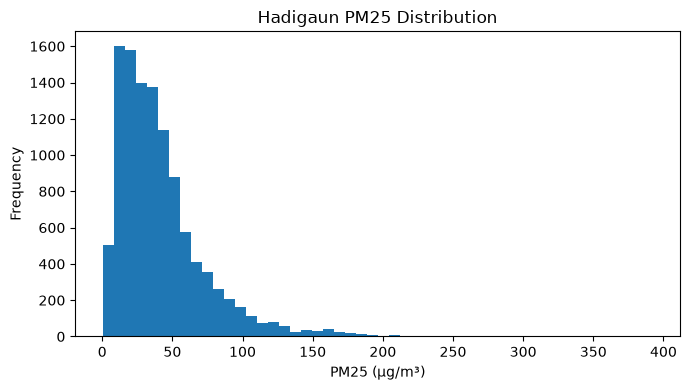

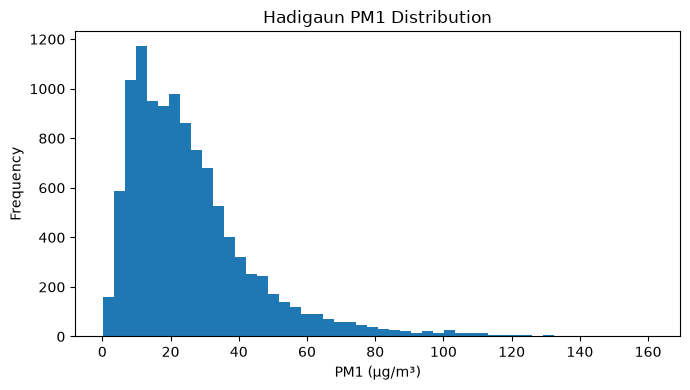

In [15]:
import matplotlib.pyplot as plt

for col in ["pm25", "pm1"]:
    plt.figure(figsize=(7, 4))
    plt.hist(hadigaun[col].dropna(), bins=50)
    plt.title(f"Hadigaun {col.upper()} Distribution")
    plt.xlabel(f"{col.upper()} (µg/m³)")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

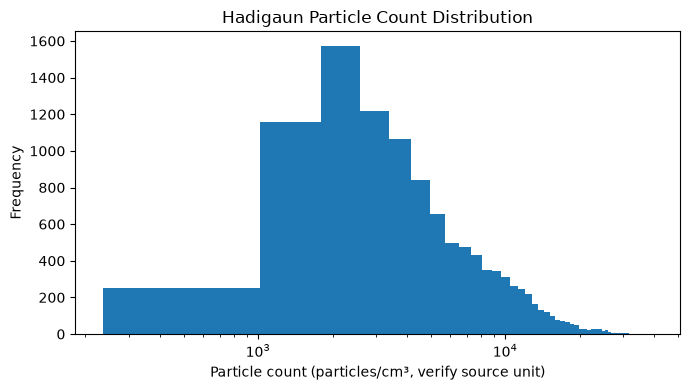

In [16]:
particle_values = hadigaun["particle_count_03um"].dropna()
particle_values = particle_values[particle_values > 0]

plt.figure(figsize=(7, 4))
plt.hist(particle_values, bins=50)
plt.xscale("log")
plt.title("Hadigaun Particle Count Distribution")
plt.xlabel("Particle count (particles/cm³, verify source unit)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

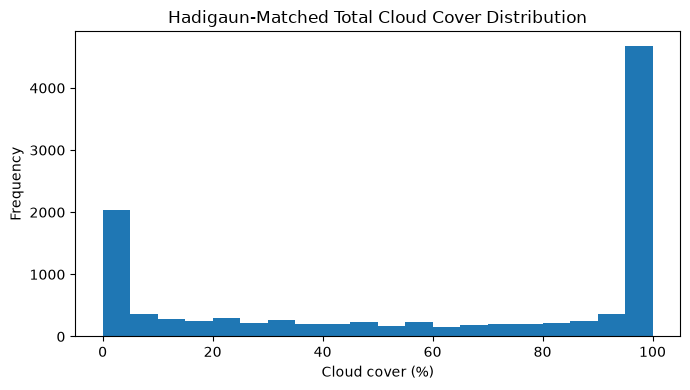

In [17]:
plt.figure(figsize=(7, 4))
plt.hist(master["cloud_cover"].dropna(), bins=20)
plt.title("Hadigaun-Matched Total Cloud Cover Distribution")
plt.xlabel("Cloud cover (%)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

Percentile Calculation accross Stations

In [21]:
import pandas as pd
import numpy as np

aq_vars = [
    "pm25", "pm1", "temperature",
    "relative_humidity", "particle_count_03um"
]

def descriptive_table(df, variables):
    rows = []
    for col in variables:
        s = pd.to_numeric(df[col], errors="coerce")
        q = s.quantile([0.05, 0.25, 0.50, 0.75, 0.95, 0.99])

        rows.append({
            "Variable": col,
            "Count": s.count(),
            "Mean": s.mean(),
            "SD": s.std(),
            "Min": s.min(),
            "P5": q.loc[0.05],
            "Q1": q.loc[0.25],
            "Median": q.loc[0.50],
            "Q3": q.loc[0.75],
            "P95": q.loc[0.95],
            "P99": q.loc[0.99],
            "Max": s.max(),
            "Missing": s.isna().sum()
        })

    return pd.DataFrame(rows).round(1)

hadigaun_stats = descriptive_table(hadigaun, aq_vars)
display(hadigaun_stats)

,Variable,Count,Mean,SD,Min,P5,Q1,Median,Q3,P95,P99,Max,Missing
0,pm25,10981,41.2,31.3,0.3,8.5,18.9,33.8,52.4,101.4,160.7,392.2,0
1,pm1,10981,25.9,19.0,0.1,5.8,12.4,21.6,33.1,62.9,100.0,161.3,0
2,temperature,10981,23.0,5.6,8.2,12.4,19.6,23.7,26.5,32.0,34.0,38.0,0
3,relative_humidity,10981,53.3,12.0,14.2,30.8,44.7,56.8,63.0,68.3,70.0,89.6,0
4,particle_count_03um,10981,6044.4,4955.1,234.9,1304.0,2461.3,4359.0,8213.5,15968.4,24036.4,39443.9,0


In [22]:
weather_vars = [
    "temperature_2m", "relative_humidity_2m", "dew_point_2m",
    "precipitation", "rain", "wind_speed_10m", "wind_gusts_10m",
    "surface_pressure", "pressure_msl",
    "cloud_cover", "cloud_cover_low", "cloud_cover_mid", "cloud_cover_high",
    "boundary_layer_height",
    "shortwave_radiation", "direct_radiation",
    "diffuse_radiation", "terrestrial_radiation",
    "sunshine_duration"
]

weather_stats = descriptive_table(master, weather_vars)
display(weather_stats)

,Variable,Count,Mean,SD,Min,P5,Q1,Median,Q3,P95,P99,Max,Missing
0,temperature_2m,10981,18.7,5.3,3.2,8.6,15.4,19.9,22.4,26.2,27.8,30.4,0
1,relative_humidity_2m,10981,83.4,17.0,24.0,49.0,73.0,89.0,98.0,100.0,100.0,100.0,0
2,dew_point_2m,10981,15.5,5.8,-2.5,5.3,10.4,17.3,20.7,22.1,22.8,24.1,0
3,precipitation,10981,0.3,0.9,0.0,0.0,0.0,0.0,0.2,1.4,4.1,16.4,0
4,rain,10981,0.2,0.7,0.0,0.0,0.0,0.0,0.1,0.8,2.8,13.8,0
5,wind_speed_10m,10981,0.7,0.5,0.0,0.2,0.4,0.7,1.0,1.6,2.3,4.1,0
6,wind_gusts_10m,10981,4.1,1.6,0.6,2.1,3.0,3.8,4.8,6.9,9.6,16.2,0
7,surface_pressure,10981,868.4,3.1,858.9,863.7,866.2,868.2,870.5,873.9,875.9,879.2,0
8,pressure_msl,10981,1011.9,4.9,996.6,1004.4,1008.0,1011.7,1015.9,1019.8,1021.6,1023.4,0
9,cloud_cover,10981,60.9,40.9,0.0,0.0,15.0,80.0,100.0,100.0,100.0,100.0,0


In [23]:
daytime = master.loc[master["terrestrial_radiation"] > 0].copy()

radiation_vars = [
    "shortwave_radiation",
    "direct_radiation",
    "diffuse_radiation",
    "terrestrial_radiation"
]

daytime_radiation_stats = descriptive_table(daytime, radiation_vars)
display(daytime_radiation_stats)

print("Daytime observations:", len(daytime))

,Variable,Count,Mean,SD,Min,P5,Q1,Median,Q3,P95,P99,Max,Missing
0,shortwave_radiation,5991,356.3,253.0,0.0,3.0,111.0,361.0,573.0,756.0,841.0,925.0,0
1,direct_radiation,5991,214.6,191.1,0.0,0.0,30.0,173.0,370.0,552.0,642.1,746.0,0
2,diffuse_radiation,5991,141.7,92.9,0.0,3.0,69.0,131.0,212.0,301.0,346.0,435.0,0
3,terrestrial_radiation,5991,700.0,413.8,0.1,15.6,348.0,754.6,1054.2,1275.8,1314.6,1319.4,0


Daytime observations: 5991


In [24]:
start = pd.Timestamp("2025-11-13 00:00:00", tz="Asia/Kathmandu")
end = pd.Timestamp("2026-09-30 23:59:59", tz="Asia/Kathmandu")

stations = {
    "Hadigaun": hadigaun,
    "Lalitpur": lalitpur,
    "Pokhara": pokhara
}

station_data = {}

for name, df in stations.items():
    temp = df.copy()
    temp["datetime"] = pd.to_datetime(temp["datetime"])

    temp = temp.loc[
        temp["datetime"].between(start, end),
        ["datetime", "pm25", "pm1"]
    ]

    station_data[name] = temp

common = station_data["Hadigaun"].rename(
    columns={"pm25": "Hadigaun_PM25", "pm1": "Hadigaun_PM1"}
)

for name in ["Lalitpur", "Pokhara"]:
    common = common.merge(
        station_data[name].rename(
            columns={
                "pm25": f"{name}_PM25",
                "pm1": f"{name}_PM1"
            }
        ),
        on="datetime",
        how="inner"
    )

print("Common timestamps:", len(common))
print("First timestamp:", common["datetime"].min())
print("Last timestamp:", common["datetime"].max())

Common timestamps: 5708
First timestamp: 2025-11-13 13:45:00+05:45
Last timestamp: 2026-09-30 23:45:00+05:45


In [25]:
rows = []

for station in stations:
    for pollutant in ["PM25", "PM1"]:
        col = f"{station}_{pollutant}"
        s = pd.to_numeric(common[col], errors="coerce").dropna()

        rows.append({
            "Station": station,
            "Variable": pollutant.replace("PM25", "PM2.5"),
            "Valid count": s.count(),
            "Mean": s.mean(),
            "Median": s.median(),
            "P95": s.quantile(0.95),
            ">15 (%)": (s > 15).mean() * 100,
            ">50 (%)": (s > 50).mean() * 100,
            ">100 (%)": (s > 100).mean() * 100
        })

common_stats = pd.DataFrame(rows).round(1)
display(common_stats)

,Station,Variable,Valid count,Mean,Median,P95,>15 (%),>50 (%),>100 (%)
0,Hadigaun,PM2.5,5708,51.5,45.8,120.7,87.9,43.6,8.7
1,Hadigaun,PM1,5708,32.1,28.8,74.7,76.7,15.6,1.7
2,Lalitpur,PM2.5,5708,63.1,51.1,148.7,87.1,51.4,20.6
3,Lalitpur,PM1,5708,37.4,32.4,85.0,78.6,29.3,2.2
4,Pokhara,PM2.5,5708,44.5,41.6,106.6,75.5,39.8,6.9
5,Pokhara,PM1,5708,26.8,26.7,62.6,67.1,12.5,0.2


IQR Outlier Table

In [26]:
rows = []

for station, df in stations.items():
    for col in ["pm25", "pm1"]:
        s = pd.to_numeric(df[col], errors="coerce").dropna()

        q1 = s.quantile(0.25)
        q3 = s.quantile(0.75)
        iqr = q3 - q1
        upper_fence = q3 + 1.5 * iqr

        flagged = (s > upper_fence).sum()

        rows.append({
            "Station": station,
            "Variable": col.upper().replace("PM25", "PM2.5"),
            "Valid count": s.count(),
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "Upper fence": upper_fence,
            "Flagged count": flagged,
            "Flagged (%)": flagged / s.count() * 100
        })

iqr_stats = pd.DataFrame(rows).round(2)
display(iqr_stats)

,Station,Variable,Valid count,Q1,Q3,IQR,Upper fence,Flagged count,Flagged (%)
0,Hadigaun,PM2.5,10981,18.90,52.41,33.51,102.68,528,4.81
1,Hadigaun,PM1,10981,12.42,33.08,20.66,64.08,521,4.74
2,Lalitpur,PM2.5,6000,28.10,90.56,62.46,184.25,115,1.92
3,Lalitpur,PM1,6000,18.20,53.21,35.01,105.74,98,1.63
4,Pokhara,PM2.5,7783,13.90,57.72,43.82,123.45,145,1.86
5,Pokhara,PM1,7783,7.00,35.50,28.50,78.25,90,1.16


Particle Count to PM2.5 ratio

In [27]:
ratio_rows = []

for station, df in stations.items():
    temp = df.copy()
    temp["datetime"] = pd.to_datetime(temp["datetime"])

    temp = temp.loc[
        temp["datetime"].between(start, end),
        ["datetime", "pm25", "particle_count_03um"]
    ].copy()

    temp["pm25"] = pd.to_numeric(temp["pm25"], errors="coerce")
    temp["particle_count_03um"] = pd.to_numeric(
        temp["particle_count_03um"], errors="coerce"
    )

    temp = temp.dropna(subset=["pm25", "particle_count_03um"])
    temp = temp.loc[temp["pm25"] > 0]

    temp["ratio"] = temp["particle_count_03um"] / temp["pm25"]

    ratio_rows.append({
        "Station": station,
        "Valid ratio count": temp["ratio"].count(),
        "Median particle count / PM2.5": temp["ratio"].median(),
        "Mean particle count / PM2.5": temp["ratio"].mean()
    })

ratio_stats = pd.DataFrame(ratio_rows).round(2)
display(ratio_stats)

,Station,Valid ratio count,Median particle count / PM2.5,Mean particle count / PM2.5
0,Hadigaun,7424,147.40,146.42
1,Lalitpur,5989,42.42,48.91
2,Pokhara,7399,42.43,62.98


Embassy Extreme Values

In [28]:
emb = embassy.copy()
emb["datetime"] = pd.to_datetime(emb["datetime"])
emb["pm25"] = pd.to_numeric(emb["pm25"], errors="coerce")

# Exclude missing/negative values and records explicitly flagged as invalid.
valid = emb["pm25"].notna() & (emb["pm25"] >= 0)

if "pm25_invalid_flag" in emb.columns:
    flag = emb["pm25_invalid_flag"].astype(str).str.strip().str.lower()
    valid &= ~flag.isin(["true", "1", "yes", "invalid"])

emb_valid = emb.loc[valid].sort_values("datetime").copy()

# Exact occurrences of the repeated maximum value.
max_readings = emb_valid.loc[emb_valid["pm25"] == 985, ["datetime", "pm25"]]

print("Readings equal to 985 µg/m³:", len(max_readings))
display(max_readings)

# Identify runs of consecutive hourly observations above 300 µg/m³.
high = emb_valid.loc[
    emb_valid["pm25"] > 300,
    ["datetime", "pm25"]
].copy()

high = high.sort_values("datetime")
high["time_gap"] = high["datetime"].diff()
high["episode_id"] = high["time_gap"].ne(pd.Timedelta(hours=1)).cumsum()

episodes = (
    high.groupby("episode_id")
    .agg(
        Start=("datetime", "min"),
        End=("datetime", "max"),
        Readings=("pm25", "size"),
        Peak=("pm25", "max"),
        Values=("pm25", lambda x: list(x))
    )
    .reset_index(drop=True)
)

episodes["Classification"] = np.where(
    episodes["Readings"] >= 2,
    "Sustained",
    "Isolated"
)

display(episodes)

print("Total readings above 300:", len(high))
print("Sustained sequences:", (episodes["Classification"] == "Sustained").sum())
print("Isolated readings:", (episodes["Classification"] == "Isolated").sum())

Readings equal to 985 µg/m³: 3


,datetime,pm25
14231,2024-08-01 15:00:00+05:45,985.0
19075,2025-02-19 11:00:00+05:45,985.0
19101,2025-02-20 13:00:00+05:45,985.0


,Start,End,Readings,Peak,Values,Classification
0,2022-10-19 11:00:00+05:45,2022-10-19 11:00:00+05:45,1,456.0,[456.0],Isolated
1,2023-04-13 12:00:00+05:45,2023-04-13 12:00:00+05:45,1,627.0,[627.0],Isolated
2,2024-01-19 19:00:00+05:45,2024-01-19 19:00:00+05:45,1,840.0,[840.0],Isolated
3,2024-04-07 17:00:00+05:45,2024-04-07 19:00:00+05:45,3,616.0,"[616.0, 368.0, 317.0]",Sustained
4,2024-04-09 19:00:00+05:45,2024-04-09 19:00:00+05:45,1,321.0,[321.0],Isolated
5,2024-04-15 11:00:00+05:45,2024-04-15 11:00:00+05:45,1,675.0,[675.0],Isolated
6,2024-08-01 15:00:00+05:45,2024-08-01 15:00:00+05:45,1,985.0,[985.0],Isolated
7,2024-09-09 14:00:00+05:45,2024-09-09 14:00:00+05:45,1,802.0,[802.0],Isolated
8,2025-02-19 11:00:00+05:45,2025-02-19 11:00:00+05:45,1,985.0,[985.0],Isolated
9,2025-02-20 13:00:00+05:45,2025-02-20 13:00:00+05:45,1,985.0,[985.0],Isolated


Total readings above 300: 12
Sustained sequences: 1
Isolated readings: 9


In [29]:
monthly_data = hadigaun.copy()
monthly_data["datetime"] = pd.to_datetime(monthly_data["datetime"])
monthly_data = monthly_data.set_index("datetime")

monthly_pm25 = (
    monthly_data["pm25"]
    .resample("MS")
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        P95=lambda x: x.quantile(0.95)
    )
    .reset_index()
)

monthly_pm25 = monthly_pm25.round(1)
display(monthly_pm25)

C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\3582684881.py:17: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  monthly_pm25 = monthly_pm25.round(1)


,datetime,Count,Mean,Median,P95
0,2025-07-01 00:00:00+05:45,742,17.2,16.0,32.8
1,2025-08-01 00:00:00+05:45,724,17.8,16.8,32.0
2,2025-09-01 00:00:00+05:45,680,24.0,23.5,40.4
3,2025-10-01 00:00:00+05:45,691,34.3,34.3,61.9
4,2025-11-01 00:00:00+05:45,692,45.9,44.1,86.3
5,2025-12-01 00:00:00+05:45,736,72.4,62.8,147.2
6,2026-01-01 00:00:00+05:45,734,84.1,73.6,171.6
7,2026-02-01 00:00:00+05:45,670,75.4,68.0,133.1
8,2026-03-01 00:00:00+05:45,738,59.7,55.6,104.8
9,2026-04-01 00:00:00+05:45,701,63.6,51.9,145.8


Daily Completeness Rule

In [30]:
daily_data = hadigaun.copy()
daily_data["datetime"] = pd.to_datetime(daily_data["datetime"])
daily_data = daily_data.set_index("datetime")

daily_pm25 = (
    daily_data["pm25"]
    .resample("D")
    .agg(
        Valid_hours="count",
        Daily_mean="mean"
    )
)

daily_pm25["Valid_day"] = daily_pm25["Valid_hours"] >= 18

print("Total calendar days:", len(daily_pm25))
print("Valid days:", daily_pm25["Valid_day"].sum())
print("Invalid days:", (~daily_pm25["Valid_day"]).sum())
print("Valid-day percentage:", round(daily_pm25["Valid_day"].mean() * 100, 1))

display(daily_pm25.head())

Total calendar days: 476
Valid days: 458
Invalid days: 18
Valid-day percentage: 96.2


,Valid_hours,Daily_mean,Valid_day
datetime,,,
2025-07-01 00:00:00+05:45,24,17.689139,True
2025-07-02 00:00:00+05:45,24,18.440608,True
2025-07-03 00:00:00+05:45,24,11.473547,True
2025-07-04 00:00:00+05:45,24,9.110220,True
2025-07-05 00:00:00+05:45,24,14.043897,True


Few additional Statistics

In [2]:
# ============================================================
# SECTION 4.3 — CURATED DATASET VERIFICATION
# ============================================================

datasets = {
    "Hadigaun": hadigaun,
    "Master": master,
    "Lalitpur": lalitpur,
    "Pokhara": pokhara,
    "Embassy": embassy,
    "Phora Durbar": durbar,
    "CAMS": cams
}

for name, df in datasets.items():

    print("\n" + "=" * 75)
    print(name.upper())
    print("=" * 75)

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    print("\nMissing values:")
    print(df.isna().sum().to_string())

    numeric_df = df.select_dtypes(include="number")

    print("\nDescriptive statistics:")
    print(
        numeric_df.describe(
            percentiles=[0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
        ).T.round(3).to_string()
    )

    print("\nSkewness:")
    print(numeric_df.skew().round(3).to_string())


HADIGAUN
Shape: (10981, 6)
Columns: ['datetime', 'pm25', 'pm1', 'temperature', 'relative_humidity', 'particle_count_03um']

Missing values:
datetime               0
pm25                   0
pm1                    0
temperature            0
relative_humidity      0
particle_count_03um    0

Descriptive statistics:
                       count      mean       std      min        5%       25%       50%       75%        95%        99%        max
pm25                 10981.0    41.195    31.298    0.310     8.476    18.900    33.800    52.410    101.400    160.726    392.194
pm1                  10981.0    25.923    19.049    0.093     5.800    12.423    21.600    33.084     62.909     99.968    161.293
temperature          10981.0    23.002     5.609    8.178    12.404    19.594    23.678    26.503     32.000     34.000     38.013
relative_humidity    10981.0    53.303    12.000   14.241    30.770    44.738    56.770    63.000     68.255     70.000     89.599
particle_count_03um  10981.0 

In [4]:

# ============================================================
# SECTION 4.3 — FINAL COMPARISON AND DAYTIME VERIFICATION
# Uses curated datasets only
# All timestamps are in Nepal Time (UTC+05:45)
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. COMMON-PERIOD SPATIAL COMPARISON
# ------------------------------------------------------------

start = pd.Timestamp("2025-11-13 00:00:00", tz="Asia/Kathmandu")
end = pd.Timestamp("2026-09-30 23:59:59", tz="Asia/Kathmandu")

stations = {
    "Hadigaun": hadigaun,
    "Lalitpur": lalitpur,
    "Pokhara": pokhara
}

station_data = {}

for name, df in stations.items():

    temp = df.copy()
    temp["datetime"] = pd.to_datetime(temp["datetime"])

    temp = temp.loc[
        (temp["datetime"] >= start) &
        (temp["datetime"] <= end),
        ["datetime", "pm25", "pm1", "particle_count_03um"]
    ]

    station_data[name] = temp.set_index("datetime")


# ------------------------------------------------------------
# 2. COMMON VALID TIMESTAMPS
# ------------------------------------------------------------

common = None

for name, df in station_data.items():

    temp = df[["pm25", "pm1"]].rename(
        columns={
            "pm25": f"{name}_PM25",
            "pm1": f"{name}_PM1"
        }
    )

    common = temp if common is None else common.join(
        temp, how="inner"
    )

common = common.dropna()

print("\nCOMMON VALID TIMESTAMPS")
print("Count:", len(common))
print("First:", common.index.min())
print("Last:", common.index.max())


# ------------------------------------------------------------
# 3. COMMON-PERIOD DESCRIPTIVE STATISTICS
# ------------------------------------------------------------

comparison_results = []

for station in stations:

    for pollutant in ["PM25", "PM1"]:

        col = f"{station}_{pollutant}"
        values = common[col].dropna()

        comparison_results.append({
            "Station": station,
            "Variable": pollutant,
            "Count": len(values),
            "Mean": values.mean(),
            "Median": values.median(),
            "P95": values.quantile(0.95),
            ">15 (%)": (values > 15).mean() * 100,
            ">50 (%)": (values > 50).mean() * 100,
            ">100 (%)": (values > 100).mean() * 100
        })

comparison_table = pd.DataFrame(comparison_results)

print("\nCOMMON-PERIOD COMPARISON")
print(comparison_table.round(2).to_string(index=False))


# ------------------------------------------------------------
# 4. PARTICLE-COUNT-TO-PM2.5 RATIOS
# ------------------------------------------------------------

ratio_results = []

for name, df in station_data.items():

    temp = df.copy()

    temp["ratio"] = (
        temp["particle_count_03um"] / temp["pm25"]
    )

    temp = temp.replace(
        [np.inf, -np.inf], np.nan
    )

    valid = temp.loc[
        temp["pm25"].gt(0) &
        temp["particle_count_03um"].notna(),
        "ratio"
    ].dropna()

    ratio_results.append({
        "Station": name,
        "Valid ratio observations": len(valid),
        "Median ratio": valid.median()
    })

ratio_table = pd.DataFrame(ratio_results)

print("\nPARTICLE-COUNT-TO-PM2.5 RATIOS")
print(ratio_table.round(3).to_string(index=False))


# ------------------------------------------------------------
# 5. DAYTIME-ONLY RADIATION STATISTICS
# ------------------------------------------------------------

radiation_variables = [
    "shortwave_radiation",
    "direct_radiation",
    "diffuse_radiation",
    "terrestrial_radiation"
]

daytime = master.loc[
    master["terrestrial_radiation"] > 0,
    radiation_variables
]

daytime_results = daytime.describe(
    percentiles=[0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

daytime_results["skewness"] = daytime.skew()

print("\nDAYTIME RADIATION")
print("Observations:", len(daytime))

print(
    daytime_results.round(3).to_string()
)



COMMON VALID TIMESTAMPS
Count: 5708
First: 2025-11-13 13:45:00+05:45
Last: 2026-09-30 23:45:00+05:45

COMMON-PERIOD COMPARISON
 Station Variable  Count  Mean  Median    P95  >15 (%)  >50 (%)  >100 (%)
Hadigaun     PM25   5708 51.50   45.78 120.73    87.91    43.55      8.72
Hadigaun      PM1   5708 32.12   28.80  74.67    76.72    15.56      1.73
Lalitpur     PM25   5708 63.07   51.11 148.70    87.14    51.37     20.55
Lalitpur      PM1   5708 37.40   32.40  85.01    78.61    29.29      2.24
 Pokhara     PM25   5708 44.46   41.58 106.60    75.49    39.79      6.90
 Pokhara      PM1   5708 26.78   26.66  62.56    67.13    12.46      0.21

PARTICLE-COUNT-TO-PM2.5 RATIOS
 Station  Valid ratio observations  Median ratio
Hadigaun                      7424       147.404
Lalitpur                      5989        42.417
 Pokhara                      7399        42.432

DAYTIME RADIATION
Observations: 5991
                        count     mean      std  min    5%     25%    50%      75%     9

In [5]:

# Particle-count-to-PM2.5 ratios on the same
# 5,708 common timestamps used in the spatial comparison

ratio_results = []

for name, df in station_data.items():

    aligned = df.reindex(common.index)

    valid = aligned.loc[
        aligned["pm25"].gt(0) &
        aligned["particle_count_03um"].notna()
    ].copy()

    valid["ratio"] = (
        valid["particle_count_03um"] / valid["pm25"]
    )

    valid = valid.replace(
        [np.inf, -np.inf], np.nan
    ).dropna(subset=["ratio"])

    ratio_results.append({
        "Station": name,
        "Valid ratio observations": len(valid),
        "Median ratio": valid["ratio"].median()
    })

ratio_table = pd.DataFrame(ratio_results)

print(ratio_table.round(3).to_string(index=False))


 Station  Valid ratio observations  Median ratio
Hadigaun                      5708       148.919
Lalitpur                      5697        42.567
 Pokhara                      5589        42.575


In [6]:

import pandas as pd
import numpy as np

# ============================================================
# 1. FULL SENSOR STATISTICS BY STATION
# Uses each station's complete curated dataset
# ============================================================

stations = {
    "Hadigaun": hadigaun,
    "Lalitpur": lalitpur,
    "Pokhara": pokhara
}

sensor_variables = [
    "pm25",
    "pm1",
    "temperature",
    "relative_humidity",
    "particle_count_03um"
]

station_results = []

for station_name, df in stations.items():

    for variable in sensor_variables:

        values = df[variable].dropna()

        station_results.append({
            "Station": station_name,
            "Variable": variable,
            "Count": values.count(),
            "Missing": df[variable].isna().sum(),
            "Mean": values.mean(),
            "SD": values.std(),
            "Min": values.min(),
            "P5": values.quantile(0.05),
            "Q1": values.quantile(0.25),
            "Median": values.median(),
            "Q3": values.quantile(0.75),
            "P95": values.quantile(0.95),
            "P99": values.quantile(0.99),
            "Max": values.max()
        })

station_statistics = pd.DataFrame(station_results)

print("\nFULL SENSOR STATISTICS BY STATION")
print(station_statistics.round(3).to_string(index=False))


# ============================================================
# 2. ZERO PM READINGS BY STATION
# ============================================================

zero_results = []

for station_name, df in stations.items():

    for variable in ["pm25", "pm1"]:

        zero_results.append({
            "Station": station_name,
            "Variable": variable,
            "Zero readings": (df[variable] == 0).sum(),
            "Valid readings": df[variable].notna().sum()
        })

zero_table = pd.DataFrame(zero_results)

print("\nZERO PM READINGS")
print(zero_table.to_string(index=False))


# ============================================================
# 3. COMPLETE METEOROLOGICAL STATISTICS
# Excludes sensor variables and circular wind direction
# ============================================================

sensor_columns = [
    "pm25",
    "pm1",
    "temperature",
    "relative_humidity",
    "particle_count_03um"
]

weather_columns = [
    col for col in master.select_dtypes(include="number").columns
    if col not in sensor_columns
    and col != "wind_direction_10m"
]

weather_results = []

for variable in weather_columns:

    values = master[variable].dropna()

    weather_results.append({
        "Variable": variable,
        "Count": values.count(),
        "Missing": master[variable].isna().sum(),
        "Mean": values.mean(),
        "SD": values.std(),
        "Min": values.min(),
        "P5": values.quantile(0.05),
        "Q1": values.quantile(0.25),
        "Median": values.median(),
        "Q3": values.quantile(0.75),
        "P95": values.quantile(0.95),
        "P99": values.quantile(0.99),
        "Max": values.max(),
        "Skewness": values.skew()
    })

weather_statistics = pd.DataFrame(weather_results)

print("\nCOMPLETE METEOROLOGICAL STATISTICS")
print(weather_statistics.round(3).to_string(index=False))


# ============================================================
# 4. CAMS DATE COVERAGE
# ============================================================

cams_datetime = pd.to_datetime(cams["datetime_utc"], utc=True)

print("\nCAMS COVERAGE")
print("First timestamp:", cams_datetime.min())
print("Last timestamp:", cams_datetime.max())
print("Total observations:", len(cams))
print("Missing values:")
print(cams.isna().sum().to_string())



FULL SENSOR STATISTICS BY STATION
 Station            Variable  Count  Missing     Mean       SD     Min       P5       Q1   Median       Q3       P95       P99       Max
Hadigaun                pm25  10981        0   41.195   31.298   0.310    8.476   18.900   33.800   52.410   101.400   160.726   392.194
Hadigaun                 pm1  10981        0   25.923   19.049   0.093    5.800   12.423   21.600   33.084    62.909    99.968   161.293
Hadigaun         temperature  10981        0   23.002    5.609   8.178   12.404   19.594   23.678   26.503    32.000    34.000    38.013
Hadigaun   relative_humidity  10981        0   53.303   12.000  14.241   30.770   44.738   56.770   63.000    68.255    70.000    89.599
Hadigaun particle_count_03um  10981        0 6044.362 4955.063 234.905 1304.000 2461.250 4359.000 8213.459 15968.429 24036.392 39443.871
Lalitpur                pm25   6000        0   62.421   46.204   0.000    5.900   28.100   49.900   90.560   150.068   203.301   334.200
Lalitp

Few Remaining Statistics

In [ ]:

import pandas as pd
import numpy as np
from scipy.stats import pearsonr, spearmanr

# ============================================================
# SECTION 4.4 — REMAINING SPATIAL COMPARISON VERIFICATION
# ============================================================


# 1. Paired differences: Hadigaun minus comparison station

for pollutant in ["PM25", "PM1"]:
    for comparison_station in ["Lalitpur", "Pokhara"]:

        col_h = f"Hadigaun_{pollutant}"
        col_c = f"{comparison_station}_{pollutant}"

        difference = (
            common[col_h] - common[col_c]
        ).dropna()

        print(f"\n{pollutant}: Hadigaun - {comparison_station}")
        print(f"Valid pairs: {len(difference)}")
        print(f"Mean:   {difference.mean():.2f}")
        print(f"P5:     {difference.quantile(0.05):.2f}")
        print(f"Median: {difference.median():.2f}")
        print(f"P95:    {difference.quantile(0.95):.2f}")


# ------------------------------------------------------------
# 2. MONTHLY MATCHED-HOUR MEANS
# Uses the same 5,708 common timestamps
# ------------------------------------------------------------

monthly_data = common.copy()

monthly_data["Month"] = monthly_data.index.to_period("M")

monthly_results = []

for month, group in monthly_data.groupby("Month"):

    row = {
        "Month": str(month),
        "Matched observations": len(group)
    }

    for station in ["Hadigaun", "Lalitpur", "Pokhara"]:

        for pollutant in ["PM25", "PM1"]:

            column = f"{station}_{pollutant}"

            row[f"{station}_{pollutant}_Mean"] = (
                group[column].mean()
            )

    monthly_results.append(row)

monthly_table = pd.DataFrame(monthly_results)

print("\nMONTHLY MATCHED-HOUR MEANS")
print(monthly_table.round(2).to_string(index=False))


# ------------------------------------------------------------
# 3. ROLLING 24-HOUR COMPARISON
# Regular hourly index; retain missing timestamps.
# Calculate rolling means, then correlate overlapping
# rolling means for each station pair.
# ------------------------------------------------------------

rolling_results = []

start = pd.Timestamp(
    "2025-11-13 00:00:00",
    tz="Asia/Kathmandu"
)

end = pd.Timestamp(
    "2026-09-30 23:00:00",
    tz="Asia/Kathmandu"
)

hourly_index = pd.date_range(
    start=start,
    end=end,
    freq="h"
)

for pollutant in ["pm25", "pm1"]:

    for comparison_station in ["Lalitpur", "Pokhara"]:

        h = station_data["Hadigaun"][pollutant].reindex(
            hourly_index
        )

        c = station_data[comparison_station][pollutant].reindex(
            hourly_index
        )

        h_rolling = h.rolling(
            "24h",
            min_periods=12
        ).mean()

        c_rolling = c.rolling(
            "24h",
            min_periods=12
        ).mean()

        paired_rolling = pd.concat(
            [h_rolling, c_rolling],
            axis=1
        ).dropna()

        paired_rolling.columns = [
            "Hadigaun",
            comparison_station
        ]

        pearson_value = paired_rolling.corr(
            method="pearson"
        ).iloc[0, 1]

        spearman_value = paired_rolling.corr(
            method="spearman"
        ).iloc[0, 1]

        rolling_results.append({
            "Pollutant": pollutant.upper(),
            "Comparison": f"Hadigaun - {comparison_station}",
            "Valid endpoints": len(paired_rolling),
            "Pearson": pearson_value,
            "Spearman": spearman_value
        })

rolling_table = pd.DataFrame(rolling_results)

print("\nROLLING 24-HOUR CORRELATIONS")
print(rolling_table.round(3).to_string(index=False))


# ------------------------------------------------------------
# 4. PERIOD MEAN CHECK
# Compare individual station means in the window against
# the 5,708-timestamp common-sample means.
# This explains why Section 4.3 and 4.4 may show different
# period means.
# ------------------------------------------------------------

period_mean_results = []

for station in ["Hadigaun", "Lalitpur", "Pokhara"]:

    for pollutant in ["pm25", "pm1"]:

        individual = station_data[station][pollutant].dropna()

        matched = common[f"{station}_{pollutant}"].dropna()

        period_mean_results.append({
            "Station": station,
            "Pollutant": pollutant.upper(),
            "Available-period count": len(individual),
            "Available-period mean": individual.mean(),
            "Common-sample count": len(matched),
            "Common-sample mean": matched.mean()
        })

period_mean_table = pd.DataFrame(period_mean_results)

print("\nPERIOD MEAN RECONCILIATION")
print(period_mean_table.round(3).to_string(index=False))



PM25: Hadigaun - Lalitpur
Valid pairs: 5708
Mean:   -11.58
P5:     -54.80
Median: -6.88
P95:    16.37

PM25: Hadigaun - Pokhara
Valid pairs: 5708
Mean:   7.03
P5:     -25.29
Median: 6.00
P95:    40.30

PM1: Hadigaun - Lalitpur
Valid pairs: 5708
Mean:   -5.28
P5:     -28.52
Median: -3.91
P95:    12.20

PM1: Hadigaun - Pokhara
Valid pairs: 5708
Mean:   5.33
P5:     -13.30
Median: 4.60
P95:    26.20

MONTHLY MATCHED-HOUR MEANS
  Month  Matched observations  Hadigaun_PM25_Mean  Hadigaun_PM1_Mean  Lalitpur_PM25_Mean  Lalitpur_PM1_Mean  Pokhara_PM25_Mean  Pokhara_PM1_Mean
2025-11                   289               53.58              34.39               59.46              37.25              51.94             32.46
2025-12                   623               72.09              46.18               82.74              51.70              61.75             38.51
2026-01                   642               84.32              52.62              100.64              59.93              71.94          

C:\Users\ianus\AppData\Local\Temp\ipykernel_13932\3512949263.py:37: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  monthly_data["Month"] = monthly_data.index.to_period("M")


KeyError: 'Hadigaun_pm25'

In [ ]:

# Prepare station data and identify the correct columns
prepared = {}

for station in ["Hadigaun", "Lalitpur", "Pokhara"]:

    df = station_data[station].copy()

    # Use datetime column if present; otherwise use the existing index
    datetime_col = next(
        (c for c in df.columns if c.lower() in ["datetime", "timestamp"]),
        None
    )

    if datetime_col is not None:
        df[datetime_col] = pd.to_datetime(df[datetime_col])
        df = df.set_index(datetime_col)

    df.index = pd.DatetimeIndex(pd.to_datetime(df.index))

    # Ensure a consistent Nepal timezone
    if df.index.tz is None:
        df.index = df.index.tz_localize("Asia/Kathmandu")
    else:
        df.index = df.index.tz_convert("Asia/Kathmandu")

    df = df.sort_index()

    # Identify pollutant columns without assuming capitalization
    column_lookup = {
        c.lower().replace("_", ""): c for c in df.columns
    }

    pm25_col = column_lookup.get("pm25")
    pm1_col = column_lookup.get("pm1")

    if pm25_col is None or pm1_col is None:
        raise KeyError(
            f"{station}: Could not identify PM25/PM1 columns. "
            f"Available columns: {df.columns.tolist()}"
        )

    prepared[station] = df[[pm25_col, pm1_col]].rename(
        columns={pm25_col: "PM25", pm1_col: "PM1"}
    )

# Create a regular hourly index anchored to the actual observation times
all_indices = [
    df.index for df in prepared.values() if len(df) > 0
]

start = min(index.min() for index in all_indices)
end = max(index.max() for index in all_indices)

hourly_index = pd.date_range(
    start=start,
    end=end,
    freq="h"
)

print("Hourly index start:", hourly_index[0])
print("Hourly index end:", hourly_index[-1])
print("Hourly index length:", len(hourly_index))

# Reindex each station, retaining missing hours as NaN
rolling_data = {}

for station, df in prepared.items():

    aligned = df.reindex(hourly_index)

    rolling_data[station] = pd.DataFrame({
        pollutant: aligned[pollutant].rolling(
            "24h", min_periods=12
        ).mean()
        for pollutant in ["PM25", "PM1"]
    })

    print(
        station,
        "| Original valid PM25:", df["PM25"].notna().sum(),
        "| Aligned valid PM25:", aligned["PM25"].notna().sum()
    )

# Calculate pairwise rolling correlations
rolling_results = []

for pollutant in ["PM25", "PM1"]:

    for comparison_station in ["Lalitpur", "Pokhara"]:

        paired = pd.concat(
            [
                rolling_data["Hadigaun"][pollutant].rename("Hadigaun"),
                rolling_data[comparison_station][pollutant].rename(
                    comparison_station
                )
            ],
            axis=1
        ).dropna()

        if len(paired) >= 2:
            pearson = paired["Hadigaun"].corr(
                paired[comparison_station], method="pearson"
            )
            spearman = paired["Hadigaun"].corr(
                paired[comparison_station], method="spearman"
            )
        else:
            pearson = np.nan
            spearman = np.nan

        rolling_results.append({
            "Pollutant": pollutant,
            "Comparison": f"Hadigaun - {comparison_station}",
            "Valid endpoints": len(paired),
            "Pearson": pearson,
            "Spearman": spearman
        })

rolling_results_df = pd.DataFrame(rolling_results)

print("\nROLLING 24-HOUR CORRELATIONS")
print(rolling_results_df.to_string(index=False))

Hourly index start: 2025-11-13 00:45:00+05:45
Hourly index end: 2026-09-30 23:45:00+05:45
Hourly index length: 7728
Hadigaun | Original valid PM25: 7424 | Aligned valid PM25: 7424
Lalitpur | Original valid PM25: 6000 | Aligned valid PM25: 6000
Pokhara | Original valid PM25: 7586 | Aligned valid PM25: 7586

ROLLING 24-HOUR CORRELATIONS
Pollutant          Comparison  Valid endpoints  Pearson  Spearman
     PM25 Hadigaun - Lalitpur             5957 0.967716  0.966617
     PM25  Hadigaun - Pokhara             7449 0.923505  0.948355
      PM1 Hadigaun - Lalitpur             5957 0.971386  0.961873
      PM1  Hadigaun - Pokhara             7449 0.928634  0.942369


In [ ]:
# Use the exact matched-period boundaries
start = common.index.min()
end = common.index.max()

hourly_index = pd.date_range(
    start=start,
    end=end,
    freq="h"
)

print("Common-period start:", start)
print("Common-period end:", end)
print("Expected hourly timestamps:", len(hourly_index))

Common-period start: 2025-11-13 13:45:00+05:45
Common-period end: 2026-09-30 23:45:00+05:45
Expected hourly timestamps: 7715


In [ ]:
import pandas as pd
import numpy as np

# Exact common-period index
hourly_index = pd.DatetimeIndex(common.index).sort_values()

rolling_data = {}

for station in ["Hadigaun", "Lalitpur", "Pokhara"]:

    df = station_data[station].copy()

    # Identify datetime column or use existing index
    datetime_col = next(
        (c for c in df.columns
         if c.lower() in ["datetime", "timestamp"]),
        None
    )

    if datetime_col is not None:
        df[datetime_col] = pd.to_datetime(df[datetime_col])
        df = df.set_index(datetime_col)

    df.index = pd.DatetimeIndex(pd.to_datetime(df.index))

    if df.index.tz is None:
        df.index = df.index.tz_localize("Asia/Kathmandu")
    else:
        df.index = df.index.tz_convert("Asia/Kathmandu")

    df = df.sort_index()

    # Normalize pollutant column names
    lookup = {
        c.lower().replace("_", ""): c
        for c in df.columns
    }

    df = df.rename(columns={
        lookup["pm25"]: "PM25",
        lookup["pm1"]: "PM1"
    })

    # Restrict original observations to exact common-period timestamps
    aligned = df[["PM25", "PM1"]].reindex(hourly_index)

    print(
        station,
        "| PM25 valid:", aligned["PM25"].notna().sum(),
        "| PM1 valid:", aligned["PM1"].notna().sum()
    )

    rolling_data[station] = pd.DataFrame({
        pollutant: aligned[pollutant].rolling(
            "24h", min_periods=12
        ).mean()
        for pollutant in ["PM25", "PM1"]
    })

# Pairwise rolling correlations
results = []

for pollutant in ["PM25", "PM1"]:

    for comparison_station in ["Lalitpur", "Pokhara"]:

        paired = pd.concat([
            rolling_data["Hadigaun"][pollutant].rename("Hadigaun"),
            rolling_data[comparison_station][pollutant].rename(
                comparison_station
            )
        ], axis=1).dropna()

        results.append({
            "Pollutant": pollutant,
            "Comparison": f"Hadigaun - {comparison_station}",
            "Valid endpoints": len(paired),
            "Pearson": paired["Hadigaun"].corr(
                paired[comparison_station], method="pearson"
            ),
            "Spearman": paired["Hadigaun"].corr(
                paired[comparison_station], method="spearman"
            )
        })

results_df = pd.DataFrame(results)

print("\nROLLING 24-HOUR CORRELATIONS")
print(results_df.to_string(index=False))

Hadigaun | PM25 valid: 5708 | PM1 valid: 5708
Lalitpur | PM25 valid: 5708 | PM1 valid: 5708
Pokhara | PM25 valid: 5708 | PM1 valid: 5708

ROLLING 24-HOUR CORRELATIONS
Pollutant          Comparison  Valid endpoints  Pearson  Spearman
     PM25 Hadigaun - Lalitpur             5337 0.973662  0.969530
     PM25  Hadigaun - Pokhara             5337 0.919200  0.939647
      PM1 Hadigaun - Lalitpur             5337 0.975765  0.965742
      PM1  Hadigaun - Pokhara             5337 0.926122  0.931043


### Observation

The descriptive analysis shows positively skewed distributions for Hadigaun PM2.5, PM1 and particle count, with substantial differences between their central values and upper percentiles. Meteorological variables also exhibit distinct distributions: precipitation and rainfall are dominated by zero values, cloud cover varies considerably, and radiation measurements reflect the day–night cycle. Boundary layer height contains 477 missing observations.

The common-period comparison (13 November 2025–30 September 2026; 5,708 shared timestamps) shows that Lalitpur has the highest proportions of PM2.5 and PM1 observations above 50 and 100 µg/m³, while Pokhara generally has the lowest proportions. Particle-count-to-PM2.5 ratios also differ substantially: Hadigaun has a median ratio of 148.92, compared with approximately 42.6 at Lalitpur and Pokhara. This raises a measurement-comparability concern, although the underlying cause remains unestablished.

IQR screening identified potential high-value outliers at all three stations. These observations were retained because statistical outliers may represent genuine pollution events. Historical Embassy Kathmandu and Phora Durbar datasets contain substantial invalid or unavailable observations. Embassy Kathmandu also has three readings at 985 µg/m³ and several other extreme observations, requiring cautious interpretation. CAMS estimates were summarised separately as supplementary model-derived data.

Monthly pollution patterns and daily completeness are addressed in the subsequent temporal analysis. Overall, these findings establish the distributions, data-quality limitations and measurement-comparability considerations that inform the remaining EDA stages.

## 4.4 Spatial Comparison of Air-Quality Observations

This section examines spatial differences in particulate-matter concentrations across the three contemporary monitoring locations: Hadigaun, Lalitpur and Pokhara. The comparison uses matched hourly observations to ensure that differences are not caused by unequal observation periods or sampling timestamps.

The analysis focuses on PM2.5 and PM1 concentrations, comparing their distributions, temporal variation and relationships across stations. Hadigaun is treated as the primary monitoring location, while Lalitpur and Pokhara provide spatial reference points.

The common comparison period is 13 November 2025 to 30 September 2026, comprising 5,708 timestamps with valid PM2.5 and PM1 observations at all three stations. The analysis considers concentration differences and temporal consistency without assuming that observed associations establish their underlying causes. Differences in local conditions, monitoring environments and sensor characteristics are considered when interpreting the results.

In [31]:
def prepare_station(df, station):
    return (
        df[['datetime', 'pm25', 'pm1']]
        .copy()
        .rename(columns={
            'pm25': f'pm25_{station}',
            'pm1': f'pm1_{station}'
        })
    )

spatial_common = (
    prepare_station(hadigaun, 'hadigaun')
    .merge(
        prepare_station(lalitpur, 'lalitpur'),
        on='datetime',
        how='inner'
    )
    .merge(
        prepare_station(pokhara, 'pokhara'),
        on='datetime',
        how='inner'
    )
    .sort_values('datetime')
    .dropna()
    .reset_index(drop=True)
)

print("Matched observations:", len(spatial_common))
print("Start:", spatial_common['datetime'].min())
print("End:", spatial_common['datetime'].max())
print("Missing values:", spatial_common.isna().sum().sum())

Matched observations: 5708
Start: 2025-11-13 13:45:00+05:45
End: 2026-09-30 23:45:00+05:45
Missing values: 0


In [32]:
stations = ['hadigaun', 'lalitpur', 'pokhara']
pollutants = ['pm25', 'pm1']

correlation_results = []

for pollutant in pollutants:
    for i in range(len(stations)):
        for j in range(i + 1, len(stations)):
            s1 = stations[i]
            s2 = stations[j]

            x = spatial_common[f'{pollutant}_{s1}']
            y = spatial_common[f'{pollutant}_{s2}']

            correlation_results.append({
                'Pollutant': pollutant.upper(),
                'Station Pair': f'{s1.title()} - {s2.title()}',
                'Count': len(x),
                'Pearson': x.corr(y, method='pearson'),
                'Spearman': x.corr(y, method='spearman')
            })

correlation_table = pd.DataFrame(correlation_results)

correlation_table.round(3)

,Pollutant,Station Pair,Count,Pearson,Spearman
0,PM25,Hadigaun - Lalitpur,5708,0.853,0.930
1,PM25,Hadigaun - Pokhara,5708,0.800,0.867
2,PM25,Lalitpur - Pokhara,5708,0.794,0.856
3,PM1,Hadigaun - Lalitpur,5708,0.855,0.927
4,PM1,Hadigaun - Pokhara,5708,0.810,0.863
5,PM1,Lalitpur - Pokhara,5708,0.803,0.851


In [33]:
difference_results = []

for pollutant in pollutants:
    for station in ['lalitpur', 'pokhara']:

        difference = (
            spatial_common[f'{pollutant}_hadigaun']
            - spatial_common[f'{pollutant}_{station}']
        )

        difference_results.append({
            'Pollutant': pollutant.upper(),
            'Comparison': f'Hadigaun - {station.title()}',
            'Count': difference.count(),
            'Mean Difference': difference.mean(),
            'Median Difference': difference.median(),
            'SD': difference.std(),
            'P5': difference.quantile(0.05),
            'P95': difference.quantile(0.95),
            'Hadigaun Higher (%)': (difference > 0).mean() * 100,
            'Equal (%)': (difference == 0).mean() * 100
        })

difference_table = pd.DataFrame(difference_results)

difference_table.round(2)

,Pollutant,Comparison,Count,Mean Difference,Median Difference,SD,P5,P95,Hadigaun Higher (%),Equal (%)
0,PM25,Hadigaun - Lalitpur,5708,-11.58,-6.88,24.32,-54.80,16.37,28.99,0.25
1,PM25,Hadigaun - Pokhara,5708,7.03,6.00,22.04,-25.29,40.30,67.69,0.09
2,PM1,Hadigaun - Lalitpur,5708,-5.28,-3.91,13.56,-28.52,12.20,32.69,0.23
3,PM1,Hadigaun - Pokhara,5708,5.33,4.60,12.99,-13.30,26.20,69.64,0.21


Plotting the Comparisons

In [38]:
plot_data = spatial_common.set_index('datetime')

rolling_data = plot_data[
    [
        'pm25_hadigaun', 'pm25_lalitpur', 'pm25_pokhara',
        'pm1_hadigaun', 'pm1_lalitpur', 'pm1_pokhara'
    ]
].rolling('24h', min_periods=12).mean()

# 1. Rolling-series comparison
rolling_results = []

for pollutant in pollutants:
    for station in ['lalitpur', 'pokhara']:

        pair = rolling_data[
            [f'{pollutant}_hadigaun', f'{pollutant}_{station}']
        ].dropna()

        x = pair[f'{pollutant}_hadigaun']
        y = pair[f'{pollutant}_{station}']
        difference = x - y

        rolling_results.append({
            'Pollutant': pollutant.upper(),
            'Comparison': f'Hadigaun - {station.title()}',
            'Count': len(pair),
            'Pearson': x.corr(y, method='pearson'),
            'Spearman': x.corr(y, method='spearman'),
            'Mean Difference': difference.mean(),
            'MAE': difference.abs().mean(),
            'RMSE': np.sqrt((difference ** 2).mean())
        })

rolling_comparison = pd.DataFrame(rolling_results)

print("24-HOUR ROLLING SERIES COMPARISON")
display(rolling_comparison.round(3))


# 2. Scatter-plot diagnostics
scatter_results = []

for pollutant in pollutants:
    for station in ['lalitpur', 'pokhara']:

        x = spatial_common[f'{pollutant}_hadigaun']
        y = spatial_common[f'{pollutant}_{station}']

        slope, intercept = np.polyfit(x, y, 1)
        difference = x - y

        scatter_results.append({
            'Pollutant': pollutant.upper(),
            'Comparison': f'Hadigaun vs {station.title()}',
            'Count': len(x),
            'Regression Slope': slope,
            'Regression Intercept': intercept,
            'Median Absolute Difference': difference.abs().median(),
            'P95 Absolute Difference': difference.abs().quantile(0.95),
            'Hadigaun Higher (%)': (difference > 0).mean() * 100
        })

scatter_diagnostics = pd.DataFrame(scatter_results)

print("\nSCATTER-PLOT DIAGNOSTICS")
display(scatter_diagnostics.round(3))

24-HOUR ROLLING SERIES COMPARISON


,Pollutant,Comparison,Count,Pearson,Spearman,Mean Difference,MAE,RMSE
0,PM25,Hadigaun - Lalitpur,5337,0.974,0.970,-11.945,12.960,17.289
1,PM25,Hadigaun - Pokhara,5337,0.919,0.940,6.826,10.391,13.639
2,PM1,Hadigaun - Lalitpur,5337,0.976,0.966,-5.484,6.617,8.427
3,PM1,Hadigaun - Pokhara,5337,0.926,0.931,5.232,6.909,8.515



SCATTER-PLOT DIAGNOSTICS


,Pollutant,Comparison,Count,Regression Slope,Regression Intercept,Median Absolute Difference,P95 Absolute Difference,Hadigaun Higher (%)
0,PM25,Hadigaun vs Lalitpur,5708,1.102,6.307,10.464,57.175,28.994
1,PM25,Hadigaun vs Pokhara,5708,0.759,5.368,11.000,44.929,67.694
2,PM1,Hadigaun vs Lalitpur,5708,1.032,4.252,6.621,30.707,32.691
3,PM1,Hadigaun vs Pokhara,5708,0.757,2.464,7.100,28.057,69.639


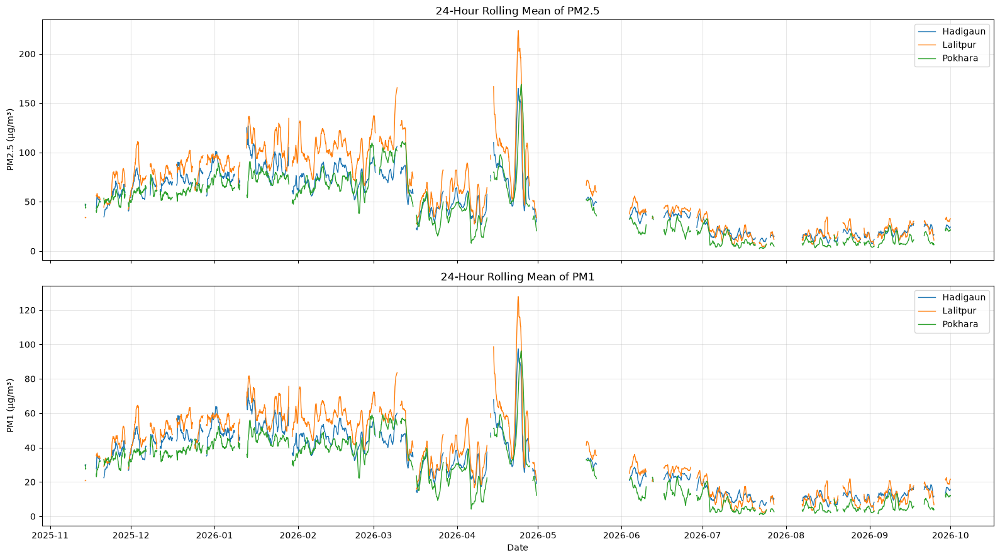

In [ ]:
plot_data = spatial_common.set_index('datetime')

rolling_data = plot_data[
    [
        'pm25_hadigaun', 'pm25_lalitpur', 'pm25_pokhara',
        'pm1_hadigaun', 'pm1_lalitpur', 'pm1_pokhara'
    ]
].rolling('24h', min_periods=12).mean()

fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)

station_labels = {
    'hadigaun': 'Hadigaun',
    'lalitpur': 'Lalitpur',
    'pokhara': 'Pokhara'
}

for station in stations:
    axes[0].plot(
        rolling_data.index,
        rolling_data[f'pm25_{station}'],
        label=station_labels[station],
        linewidth=1
    )

    axes[1].plot(
        rolling_data.index,
        rolling_data[f'pm1_{station}'],
        label=station_labels[station],
        linewidth=1
    )

axes[0].set_title('24-Hour Rolling Mean of PM2.5')
axes[0].set_ylabel('PM2.5 (µg/m³)')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title('24-Hour Rolling Mean of PM1')
axes[1].set_ylabel('PM1 (µg/m³)')
axes[1].set_xlabel('Date')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


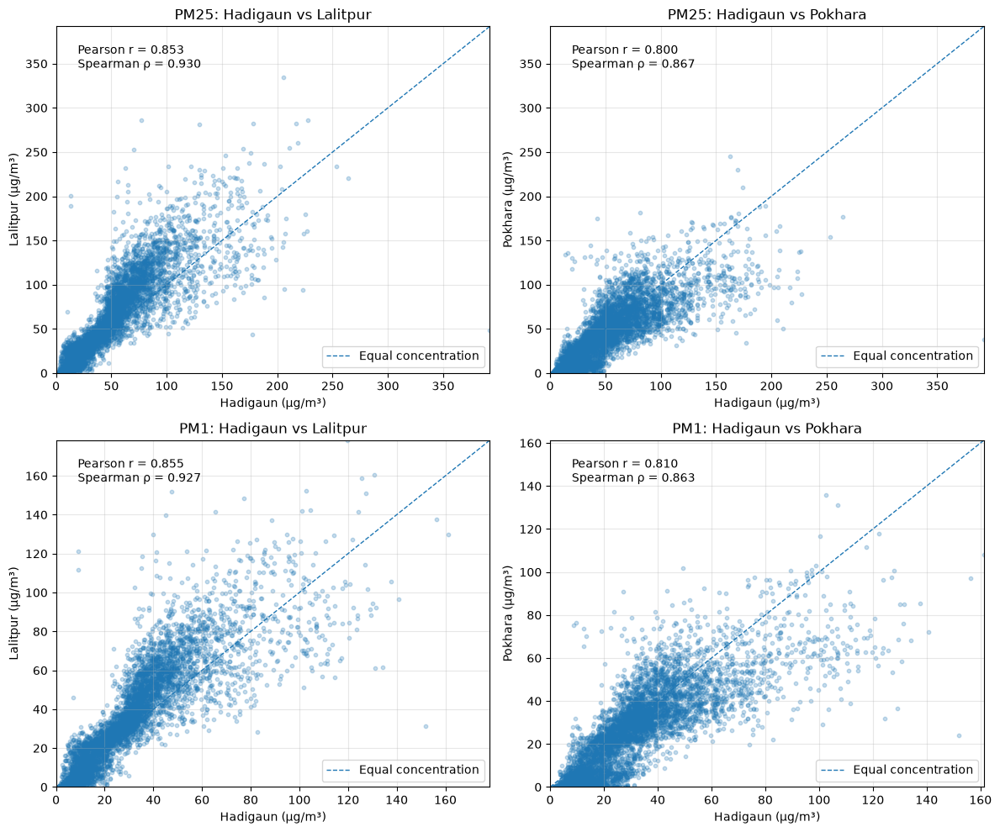

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

comparisons = ['lalitpur', 'pokhara']

for row, pollutant in enumerate(pollutants):
    for col, station in enumerate(comparisons):

        ax = axes[row, col]

        x = spatial_common[f'{pollutant}_hadigaun']
        y = spatial_common[f'{pollutant}_{station}']

        ax.scatter(x, y, alpha=0.25, s=10)

        max_value = max(x.max(), y.max())
        ax.plot(
            [0, max_value],
            [0, max_value],
            linestyle='--',
            linewidth=1,
            label='Equal concentration'
        )

        pearson = x.corr(y, method='pearson')
        spearman = x.corr(y, method='spearman')

        ax.set_title(
            f'{pollutant.upper()}: Hadigaun vs {station.title()}'
        )
        ax.set_xlabel('Hadigaun (µg/m³)')
        ax.set_ylabel(f'{station.title()} (µg/m³)')
        ax.text(
            0.05, 0.95,
            f'Pearson r = {pearson:.3f}\nSpearman ρ = {spearman:.3f}',
            transform=ax.transAxes,
            verticalalignment='top'
        )

        ax.set_xlim(0, max_value)
        ax.set_ylim(0, max_value)
        ax.grid(alpha=0.3)
        ax.legend()

plt.tight_layout()
plt.show()

WHO Comparison

In [39]:
# Common comparison window, using local timestamps
start = pd.Timestamp('2025-11-13 13:45:00', tz='Asia/Kathmandu')
end = pd.Timestamp('2026-09-30 23:45:00', tz='Asia/Kathmandu')

station_data = {
    'Hadigaun': hadigaun,
    'Lalitpur': lalitpur,
    'Pokhara': pokhara
}

daily_results = []
period_results = []
daily_series = {}

for station, df in station_data.items():

    data = df[['datetime', 'pm25', 'pm1']].copy()
    data = data[(data['datetime'] >= start) & (data['datetime'] <= end)]

    # Daily means and valid hourly observation counts
    daily = (
        data.set_index('datetime')
        .resample('D')
        .agg(
            PM25_Mean=('pm25', 'mean'),
            PM25_Valid_Hours=('pm25', 'count'),
            PM1_Mean=('pm1', 'mean'),
            PM1_Valid_Hours=('pm1', 'count')
        )
    )

    # Retain days with at least 18 valid hourly observations
    daily['Valid_Day'] = daily['PM25_Valid_Hours'] >= 18

    valid_daily = daily[daily['Valid_Day']].copy()
    daily_series[station] = valid_daily

    exceedances = valid_daily['PM25_Mean'] > 15

    daily_results.append({
        'Station': station,
        'Valid Days': len(valid_daily),
        'Days > 15 µg/m³': exceedances.sum(),
        'Exceedance Share (%)': exceedances.mean() * 100,
        'Mean Daily PM2.5': valid_daily['PM25_Mean'].mean(),
        'Median Daily PM2.5': valid_daily['PM25_Mean'].median(),
        '99th Percentile': valid_daily['PM25_Mean'].quantile(0.99)
    })

    period_results.append({
        'Station': station,
        'Valid Hourly Observations': data['pm25'].count(),
        'Period Mean PM2.5': data['pm25'].mean(),
        'Period Mean PM1': data['pm1'].mean()
    })

daily_who_table = pd.DataFrame(daily_results)
period_mean_table = pd.DataFrame(period_results)

print("DAILY PM2.5 SUMMARY — 18 OF 24 VALID HOURS")
display(daily_who_table.round(2))

print("\nPERIOD MEAN — COMMON COMPARISON WINDOW")
display(period_mean_table.round(2))

DAILY PM2.5 SUMMARY — 18 OF 24 VALID HOURS


,Station,Valid Days,Days > 15 µg/m³,Exceedance Share (%),Mean Daily PM2.5,Median Daily PM2.5,99th Percentile
0,Hadigaun,310,274,88.39,48.82,44.41,117.89
1,Lalitpur,228,207,90.79,62.85,60.32,159.07
2,Pokhara,313,234,74.76,40.63,35.98,103.88



PERIOD MEAN — COMMON COMPARISON WINDOW


,Station,Valid Hourly Observations,Period Mean PM2.5,Period Mean PM1
0,Hadigaun,7412,48.81,30.54
1,Lalitpur,6000,62.42,36.97
2,Pokhara,7574,40.62,24.54


Hadigaun Year Around

In [40]:
hadigaun_year = hadigaun[
    (hadigaun['datetime'] >= pd.Timestamp(
        '2025-07-01 00:00:00', tz='Asia/Kathmandu'
    ))
    &
    (hadigaun['datetime'] < pd.Timestamp(
        '2026-07-01 00:00:00', tz='Asia/Kathmandu'
    ))
].copy()

expected_hours = 365 * 24
valid_hours = hadigaun_year['pm25'].count()

hadigaun_annual_summary = pd.DataFrame([{
    'Period': '1 Jul 2025 – 30 Jun 2026',
    'Expected Hours': expected_hours,
    'Valid Hours': valid_hours,
    'Missing Hours': expected_hours - valid_hours,
    'Completeness (%)': valid_hours / expected_hours * 100,
    'Indicative Mean PM2.5': hadigaun_year['pm25'].mean()
}])

display(hadigaun_annual_summary.round(2))

,Period,Expected Hours,Valid Hours,Missing Hours,Completeness (%),Indicative Mean PM2.5
0,1 Jul 2025 – 30 Jun 2026,8760,8462,298,96.6,47.49


In [41]:
monthly_data = spatial_common.copy()

monthly_data['Month'] = (
    monthly_data['datetime'].dt.strftime('%Y-%m')
)

monthly_results = []

for month, group in monthly_data.groupby('Month'):

    for pollutant in pollutants:
        monthly_results.append({
            'Month': month,
            'Pollutant': pollutant.upper(),
            'Matched Hours': len(group),
            'Hadigaun Mean': group[f'{pollutant}_hadigaun'].mean(),
            'Lalitpur Mean': group[f'{pollutant}_lalitpur'].mean(),
            'Pokhara Mean': group[f'{pollutant}_pokhara'].mean(),
            'Hadigaun - Lalitpur': (
                group[f'{pollutant}_hadigaun'].mean()
                - group[f'{pollutant}_lalitpur'].mean()
            ),
            'Hadigaun - Pokhara': (
                group[f'{pollutant}_hadigaun'].mean()
                - group[f'{pollutant}_pokhara'].mean()
            )
        })

monthly_comparison = pd.DataFrame(monthly_results)

display(monthly_comparison.round(2))

,Month,Pollutant,Matched Hours,Hadigaun Mean,Lalitpur Mean,Pokhara Mean,Hadigaun - Lalitpur,Hadigaun - Pokhara
0,2025-11,PM25,289,53.58,59.46,51.94,-5.88,1.64
1,2025-11,PM1,289,34.39,37.25,32.46,-2.85,1.94
2,2025-12,PM25,623,72.09,82.74,61.75,-10.65,10.34
3,2025-12,PM1,623,46.18,51.70,38.51,-5.52,7.67
4,2026-01,PM25,642,84.32,100.64,71.94,-16.32,12.38
5,2026-01,PM1,642,52.62,59.93,43.86,-7.31,8.76
6,2026-02,PM25,657,75.41,101.47,69.90,-26.05,5.51
7,2026-02,PM1,657,45.45,56.85,41.16,-11.41,4.29
8,2026-03,PM25,646,58.27,78.08,60.37,-19.81,-2.11
9,2026-03,PM1,646,34.87,43.59,34.99,-8.72,-0.12


In [43]:
adjusted_data = spatial_common.copy()

adjusted_data['Month'] = adjusted_data['datetime'].dt.month
adjusted_data['Hour'] = adjusted_data['datetime'].dt.hour

adjusted_results = []

for pollutant in pollutants:

    columns = [f'{pollutant}_{station}' for station in stations]

    # Remove each station's own month-and-hour average
    for column in columns:
        adjusted_data[f'{column}_adjusted'] = (
            adjusted_data[column]
            - adjusted_data.groupby(['Month', 'Hour'])[column].transform('mean')
        )

    for i in range(len(stations)):
        for j in range(i + 1, len(stations)):

            s1 = stations[i]
            s2 = stations[j]

            x = adjusted_data[f'{pollutant}_{s1}_adjusted']
            y = adjusted_data[f'{pollutant}_{s2}_adjusted']

            adjusted_results.append({
                'Pollutant': pollutant.upper(),
                'Station Pair': f'{s1.title()} - {s2.title()}',
                'Count': x.notna().sum(),
                'Adjusted Pearson': x.corr(y, method='pearson'),
                'Adjusted Spearman': x.corr(y, method='spearman')
            })

adjusted_correlation_table = pd.DataFrame(adjusted_results)

display(adjusted_correlation_table.round(3))

,Pollutant,Station Pair,Count,Adjusted Pearson,Adjusted Spearman
0,PM25,Hadigaun - Lalitpur,5708,0.712,0.650
1,PM25,Hadigaun - Pokhara,5708,0.538,0.471
2,PM25,Lalitpur - Pokhara,5708,0.565,0.483
3,PM1,Hadigaun - Lalitpur,5708,0.708,0.624
4,PM1,Hadigaun - Pokhara,5708,0.530,0.440
5,PM1,Lalitpur - Pokhara,5708,0.547,0.458


Recalculating Rolling Data

In [44]:
regular_data = spatial_common.set_index('datetime').asfreq('h')

rolling_columns = [
    'pm25_hadigaun', 'pm25_lalitpur', 'pm25_pokhara',
    'pm1_hadigaun', 'pm1_lalitpur', 'pm1_pokhara'
]

rolling_data = (
    regular_data[rolling_columns]
    .rolling('24h', min_periods=12)
    .mean()
)

rolling_results = []

for pollutant in pollutants:
    for station in ['lalitpur', 'pokhara']:

        pair = rolling_data[
            [f'{pollutant}_hadigaun', f'{pollutant}_{station}']
        ].dropna()

        x = pair[f'{pollutant}_hadigaun']
        y = pair[f'{pollutant}_{station}']

        rolling_results.append({
            'Pollutant': pollutant.upper(),
            'Comparison': f'Hadigaun - {station.title()}',
            'Count': len(pair),
            'Pearson': x.corr(y, method='pearson'),
            'Spearman': x.corr(y, method='spearman'),
            'Mean Difference': (x - y).mean()
        })

corrected_rolling_table = pd.DataFrame(rolling_results)

display(corrected_rolling_table.round(3))

,Pollutant,Comparison,Count,Pearson,Spearman,Mean Difference
0,PM25,Hadigaun - Lalitpur,5858,0.972,0.969,-11.708
1,PM25,Hadigaun - Pokhara,5858,0.920,0.940,7.003
2,PM1,Hadigaun - Lalitpur,5858,0.975,0.965,-5.340
3,PM1,Hadigaun - Pokhara,5858,0.926,0.932,5.329


In [46]:
comparability_results = []

for station, df in station_data.items():

    row = {
        'Station': station,
        'PM1 Mean': df['pm1'].mean(),
        'PM2.5 Mean': df['pm25'].mean(),
        'PM1 / PM2.5 Mean Ratio': df['pm1'].mean() / df['pm25'].mean()
    }

    if 'particle_count_03um' in df.columns:
        ratio = (
            df['particle_count_03um'] / df['pm25'].replace(0, np.nan)
        )
        row['Median Particle Count / PM2.5'] = ratio.median()

    if 'temperature' in df.columns:
        row['Mean Temperature (°C)'] = df['temperature'].mean()

    if 'relative_humidity' in df.columns:
        row['Mean Relative Humidity (%)'] = df['relative_humidity'].mean()

    comparability_results.append(row)

comparability_table = pd.DataFrame(comparability_results)

display(comparability_table.round(2))

,Station,PM1 Mean,PM2.5 Mean,PM1 / PM2.5 Mean Ratio,Median Particle Count / PM2.5,Mean Temperature (°C),Mean Relative Humidity (%)
0,Hadigaun,25.92,41.19,0.63,141.38,23.00,53.30
1,Lalitpur,36.97,62.42,0.59,42.42,24.32,45.30
2,Pokhara,24.52,40.55,0.60,42.32,23.48,52.91


In [48]:
start = pd.Timestamp("2025-11-13 13:45:00", tz="Asia/Kathmandu")
end = pd.Timestamp("2026-09-30 23:45:00", tz="Asia/Kathmandu")

stations = {
    "Hadigaun": hadigaun,
    "Lalitpur": lalitpur,
    "Pokhara": pokhara
}

period_results = []

for station_name, df in stations.items():
    data = df.loc[
        df["datetime"].between(start, end),
        ["datetime", "pm25", "pm1"]
    ].copy()

    period_results.append({
        "Station": station_name,
        "Valid PM2.5 Hours": data["pm25"].count(),
        "PM2.5 Period Mean (µg/m³)": data["pm25"].mean(),
        "Valid PM1 Hours": data["pm1"].count(),
        "PM1 Period Mean (µg/m³)": data["pm1"].mean()
    })

period_means = pd.DataFrame(period_results)

display(period_means.round(2))

,Station,Valid PM2.5 Hours,PM2.5 Period Mean (µg/m³),Valid PM1 Hours,PM1 Period Mean (µg/m³)
0,Hadigaun,7412,48.81,7412,30.54
1,Lalitpur,6000,62.42,6000,36.97
2,Pokhara,7574,40.62,7574,24.54


Some additional Statistics

In [ ]:
# Inspect the master dataset and temperature-related variables

print("MASTER COLUMNS:")
print(master.columns.tolist())

print("\nTEMPERATURE-RELATED COLUMNS:")
print([
    c for c in master.columns
    if "temp" in c.lower()
])

print("\nMONTHLY TEMPERATURE DATAFRAME VARIABLES:")
print([
    name for name, obj in globals().items()
    if isinstance(obj, pd.DataFrame)
    and any("temp" in str(c).lower() for c in obj.columns)
])

print("\nCLUSTER-RELATED VARIABLES:")
print([
    name for name in globals()
    if "cluster" in name.lower()
    or "kmeans" in name.lower()
])

MASTER COLUMNS:
['datetime', 'pm25', 'pm1', 'temperature', 'relative_humidity', 'particle_count_03um', 'temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'precipitation', 'rain', 'wind_speed_10m', 'wind_direction_10m', 'wind_gusts_10m', 'surface_pressure', 'pressure_msl', 'cloud_cover', 'cloud_cover_low', 'cloud_cover_mid', 'cloud_cover_high', 'boundary_layer_height', 'shortwave_radiation', 'direct_radiation', 'diffuse_radiation', 'terrestrial_radiation', 'sunshine_duration']

TEMPERATURE-RELATED COLUMNS:
['temperature', 'temperature_2m']

MONTHLY TEMPERATURE DATAFRAME VARIABLES:
['hadigaun', 'master', 'lalitpur', 'pokhara']

CLUSTER-RELATED VARIABLES:
[]


In [ ]:
import pandas as pd
from sklearn.cluster import KMeans

# Prepare monthly Open-Meteo temperature means
temperature_data = master[["datetime", "temperature_2m"]].copy()

temperature_data["datetime"] = pd.to_datetime(
    temperature_data["datetime"]
)

temperature_data["temperature_2m"] = pd.to_numeric(
    temperature_data["temperature_2m"],
    errors="coerce"
)

temperature_data = temperature_data.dropna(
    subset=["datetime", "temperature_2m"]
)

temperature_data["Month"] = (
    temperature_data["datetime"].dt.to_period("M")
)

monthly_temperature = (
    temperature_data
    .groupby("Month")["temperature_2m"]
    .agg(["mean", "count"])
    .reset_index()
)

# Apply K-means to the 16 monthly temperature means
X = monthly_temperature[["mean"]].values

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

monthly_temperature["Cluster"] = kmeans.fit_predict(X)

# Identify cooler and warmer groups from their centres
cluster_centres = kmeans.cluster_centers_.flatten()
ordered_clusters = sorted(
    range(2),
    key=lambda cluster: cluster_centres[cluster]
)

group_names = {
    ordered_clusters[0]: "Cooler",
    ordered_clusters[1]: "Warmer"
}

monthly_temperature["Temperature_Group"] = (
    monthly_temperature["Cluster"].map(group_names)
)

# Display monthly assignments
monthly_temperature["Month"] = (
    monthly_temperature["Month"].astype(str)
)

print("MONTHLY TEMPERATURE GROUPING")
print(
    monthly_temperature[
        ["Month", "mean", "count", "Temperature_Group"]
    ].round(2).to_string(index=False)
)

# Summarise the two groups
group_summary = (
    monthly_temperature
    .groupby("Temperature_Group")
    .agg(
        Number_of_Months=("mean", "count"),
        Mean_of_Monthly_Means=("mean", "mean"),
        Minimum=("mean", "min"),
        Maximum=("mean", "max")
    )
    .round(2)
)

print("\nTEMPERATURE GROUP SUMMARY")
print(group_summary)

print("\nK-MEANS CLUSTER CENTRES")
for cluster in ordered_clusters:
    print(
        f"{group_names[cluster]}: "
        f"{cluster_centres[cluster]:.2f} °C"
    )

C:\Users\ianus\AppData\Local\Temp\ipykernel_13932\697288584.py:21: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  temperature_data["datetime"].dt.to_period("M")


MONTHLY TEMPERATURE GROUPING
  Month  mean  count Temperature_Group
2025-07 22.94    742            Warmer
2025-08 22.18    724            Warmer
2025-09 21.76    680            Warmer
2025-10 19.01    691            Warmer
2025-11 14.82    692            Cooler
2025-12 12.11    736            Cooler
2026-01 10.58    734            Cooler
2026-02 13.28    670            Cooler
2026-03 15.74    738            Cooler
2026-04 18.69    701            Warmer
2026-05 19.82    690            Warmer
2026-06 22.68    664            Warmer
2026-07 23.21    726            Warmer
2026-08 23.15    726            Warmer
2026-09 21.54    626            Warmer
2026-10 18.75    441            Warmer

TEMPERATURE GROUP SUMMARY
                   Number_of_Months  Mean_of_Monthly_Means  Minimum  Maximum
Temperature_Group                                                           
Cooler                            5                  13.31    10.58    15.74
Warmer                           11               

## Observations
- All three stations showed strong positive PM1 and PM2.5 correlations. Hadigaun–Lalitpur had the strongest relationship, and positive associations remained after removing average month-and-hour patterns.
- Lalitpur generally recorded higher PM1 and PM2.5 concentrations than Hadigaun, while Pokhara generally recorded lower concentrations. Monthly comparisons showed that these differences varied seasonally, including a temporary reversal between Hadigaun and Pokhara in March 2026.
- Paired differences varied considerably over time despite strong correlations. Rolling averages produced stronger associations by smoothing short-term fluctuations but did not eliminate differences between stations.
- All three stations frequently exceeded the WHO 2021 24-hour PM2.5 guideline of 15 µg/m³. Their period means were also substantially above the annual guideline of 5 µg/m³; however, the partial observation period and uncalibrated low-cost sensors do not support formal regulatory compliance assessment.
- Differences in particle-count ratios and meteorological conditions indicate potential instrument and site influences on cross-station comparability. Undocumented sensor specifications, calibration status and site metadata limit further interpretation.

## 4.5 Temporal and Seasonal Patterns

This section examines temporal variations in PM2.5 and PM1 concentrations at the Hadigaun monitoring station. The analysis focuses on long-term concentration trends, monthly and seasonal variations, and changes in the distribution of particulate matter over time. The curated `master` dataset is used to retain the aligned air-quality and meteorological observations. Temporal patterns are examined using the available hourly measurements, with attention to data completeness and the unequal representation of calendar periods. The findings provide context for identifying recurring pollution patterns and selecting potentially relevant variables for subsequent analysis.

In [49]:
temporal = master.copy()

temporal["datetime"] = pd.to_datetime(temporal["datetime"])
temporal = temporal.sort_values("datetime").set_index("datetime")

# Confirm hourly frequency and observation period
print("Shape:", temporal.shape)
print("Start:", temporal.index.min())
print("End:", temporal.index.max())
print("Duplicate timestamps:", temporal.index.duplicated().sum())

# Construct the expected hourly index over the observed period
expected_index = pd.date_range(
    start=temporal.index.min(),
    end=temporal.index.max(),
    freq="h"
)

print("Expected hourly timestamps:", len(expected_index))
print("Observed timestamps:", len(temporal))
print("Missing timestamps:", len(expected_index.difference(temporal.index)))

Shape: (10981, 25)
Start: 2025-07-01 00:45:00+05:45
End: 2026-10-19 08:45:00+05:45
Duplicate timestamps: 0
Expected hourly timestamps: 11409
Observed timestamps: 10981
Missing timestamps: 428


In [50]:
monthly_coverage = pd.DataFrame(index=expected_index)

monthly_coverage["Month"] = monthly_coverage.index.to_period("M")

expected_monthly = (
    monthly_coverage.groupby("Month")
    .size()
    .rename("Expected Hours")
)

observed_monthly = (
    temporal[["pm25", "pm1"]]
    .groupby(temporal.index.to_period("M"))
    .agg(
        PM25_Valid_Hours=("pm25", "count"),
        PM1_Valid_Hours=("pm1", "count")
    )
)

monthly_coverage_table = expected_monthly.to_frame().join(observed_monthly)

monthly_coverage_table["PM25 Completeness (%)"] = (
    monthly_coverage_table["PM25_Valid_Hours"]
    / monthly_coverage_table["Expected Hours"] * 100
)

monthly_coverage_table["PM1 Completeness (%)"] = (
    monthly_coverage_table["PM1_Valid_Hours"]
    / monthly_coverage_table["Expected Hours"] * 100
)

display(monthly_coverage_table.round(2))

C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\1579628416.py:3: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  monthly_coverage["Month"] = monthly_coverage.index.to_period("M")
C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\1579628416.py:13: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  .groupby(temporal.index.to_period("M"))


,Expected Hours,PM25_Valid_Hours,PM1_Valid_Hours,PM25 Completeness (%),PM1 Completeness (%)
Month,,,,,
2025-07,744,742,742,99.73,99.73
2025-08,744,724,724,97.31,97.31
2025-09,720,680,680,94.44,94.44
2025-10,744,691,691,92.88,92.88
2025-11,720,692,692,96.11,96.11
2025-12,744,736,736,98.92,98.92
2026-01,744,734,734,98.66,98.66
2026-02,672,670,670,99.70,99.70
2026-03,744,738,738,99.19,99.19


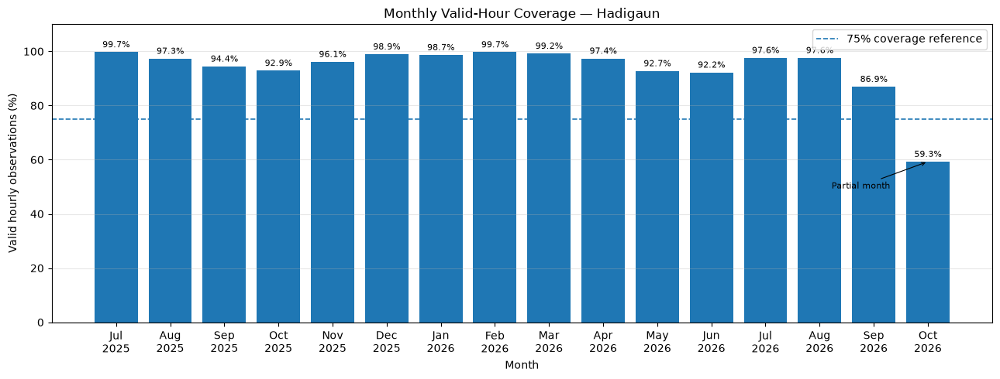

In [78]:
import calendar
import matplotlib.pyplot as plt
import pandas as pd

# Valid hourly PM2.5 observations per month
monthly_valid = temporal["pm25"].resample("MS").count()

# Expected hours in each complete calendar month
monthly_expected = pd.Series(
    [
        calendar.monthrange(date.year, date.month)[1] * 24
        for date in monthly_valid.index
    ],
    index=monthly_valid.index
)

monthly_coverage = (
    monthly_valid / monthly_expected * 100
)

# Plot
fig, ax = plt.subplots(figsize=(13, 5))

bars = ax.bar(
    monthly_coverage.index.strftime("%b\n%Y"),
    monthly_coverage.values
)

# Reference line
ax.axhline(
    75,
    linestyle="--",
    linewidth=1.2,
    label="75% coverage reference"
)

# Percentage labels
for bar, value in zip(bars, monthly_coverage.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=8
    )

# Identify partial final month
ax.annotate(
    "Partial month",
    xy=(len(monthly_coverage) - 1, monthly_coverage.iloc[-1]),
    xytext=(-35, -25),
    textcoords="offset points",
    ha="right",
    fontsize=8,
    arrowprops=dict(arrowstyle="->", linewidth=0.8)
)

ax.set_title("Monthly Valid-Hour Coverage — Hadigaun")
ax.set_xlabel("Month")
ax.set_ylabel("Valid hourly observations (%)")
ax.set_ylim(0, 110)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Monthly Concentration Patterns

In [51]:
monthly_stats = (
    temporal[["pm25", "pm1"]]
    .groupby(temporal.index.to_period("M"))
    .agg(["count", "mean", "median", lambda x: x.quantile(0.95)])
)

monthly_stats.columns = [
    "Valid Hours",
    "Mean",
    "Median",
    "P95"
] * 2

monthly_stats.index.name = "Month"

display(monthly_stats.round(2))

C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\303860869.py:3: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  .groupby(temporal.index.to_period("M"))


,Valid Hours,Mean,Median,P95,Valid Hours,Mean,Median,P95
Month,,,,,,,,
2025-07,742,17.20,16.03,32.76,742,11.40,10.58,21.47
2025-08,724,17.78,16.78,32.04,724,11.64,10.95,20.70
2025-09,680,24.02,23.45,40.41,680,15.55,15.25,26.09
2025-10,691,34.27,34.27,61.89,691,21.78,21.55,39.12
2025-11,692,45.87,44.05,86.34,692,29.40,28.10,55.64
2025-12,736,72.44,62.82,147.16,736,46.42,39.62,94.44
2026-01,734,84.15,73.59,171.56,734,52.65,46.13,107.69
2026-02,670,75.44,67.96,133.07,670,45.42,40.20,82.82
2026-03,738,59.75,55.65,104.84,738,35.67,33.85,60.52


C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\2407816191.py:3: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  .groupby(temporal.index.to_period("M"))


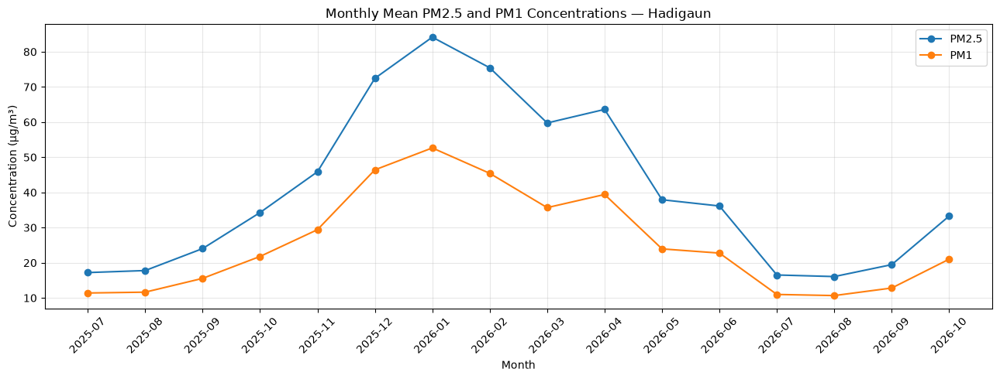

In [52]:
monthly_mean = (
    temporal[["pm25", "pm1"]]
    .groupby(temporal.index.to_period("M"))
    .mean()
)

monthly_mean.index = monthly_mean.index.astype(str)

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    monthly_mean.index,
    monthly_mean["pm25"],
    marker="o",
    label="PM2.5"
)

ax.plot(
    monthly_mean.index,
    monthly_mean["pm1"],
    marker="o",
    label="PM1"
)

ax.set_title("Monthly Mean PM2.5 and PM1 Concentrations — Hadigaun")
ax.set_xlabel("Month")
ax.set_ylabel("Concentration (µg/m³)")
ax.tick_params(axis="x", rotation=45)
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Monthly Distribution Plots

C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\1833210104.py:3: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  .groupby(temporal.index.to_period("M"))


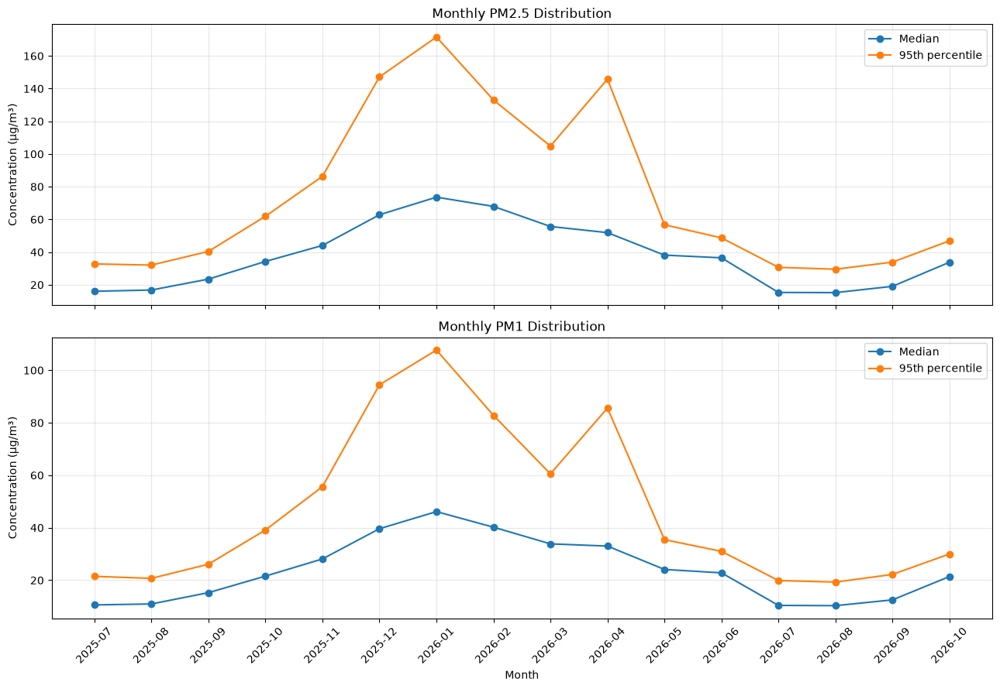

In [53]:
monthly_distribution = (
    temporal[["pm25", "pm1"]]
    .groupby(temporal.index.to_period("M"))
    .agg(
        PM25_Median=("pm25", "median"),
        PM25_P95=("pm25", lambda x: x.quantile(0.95)),
        PM1_Median=("pm1", "median"),
        PM1_P95=("pm1", lambda x: x.quantile(0.95))
    )
)

monthly_distribution.index = monthly_distribution.index.astype(str)

fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

axes[0].plot(
    monthly_distribution.index,
    monthly_distribution["PM25_Median"],
    marker="o",
    label="Median"
)
axes[0].plot(
    monthly_distribution.index,
    monthly_distribution["PM25_P95"],
    marker="o",
    label="95th percentile"
)
axes[0].set_title("Monthly PM2.5 Distribution")
axes[0].set_ylabel("Concentration (µg/m³)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    monthly_distribution.index,
    monthly_distribution["PM1_Median"],
    marker="o",
    label="Median"
)
axes[1].plot(
    monthly_distribution.index,
    monthly_distribution["PM1_P95"],
    marker="o",
    label="95th percentile"
)
axes[1].set_title("Monthly PM1 Distribution")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Concentration (µg/m³)")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Seasonal Concentration

In [54]:
season_map = {
    12: "Winter",
    1: "Winter",
    2: "Winter",
    3: "Pre-monsoon",
    4: "Pre-monsoon",
    5: "Pre-monsoon",
    6: "Monsoon",
    7: "Monsoon",
    8: "Monsoon",
    9: "Monsoon",
    10: "Post-monsoon",
    11: "Post-monsoon"
}

season_order = [
    "Winter",
    "Pre-monsoon",
    "Monsoon",
    "Post-monsoon"
]

seasonal = temporal[["pm25", "pm1"]].copy()

seasonal["Season"] = seasonal.index.month.map(season_map)

seasonal_stats = (
    seasonal.groupby("Season")
    .agg(
        PM25_Valid_Hours=("pm25", "count"),
        PM25_Mean=("pm25", "mean"),
        PM25_Median=("pm25", "median"),
        PM25_P95=("pm25", lambda x: x.quantile(0.95)),
        PM1_Valid_Hours=("pm1", "count"),
        PM1_Mean=("pm1", "mean"),
        PM1_Median=("pm1", "median"),
        PM1_P95=("pm1", lambda x: x.quantile(0.95))
    )
    .reindex(season_order)
)

display(seasonal_stats.round(2))

,PM25_Valid_Hours,PM25_Mean,PM25_Median,PM25_P95,PM1_Valid_Hours,PM1_Mean,PM1_Median,PM1_P95
Season,,,,,,,,
Winter,2140,77.39,67.54,155.45,2140,48.24,41.63,97.91
Pre-monsoon,2129,53.94,47.20,107.30,2129,33.10,29.60,65.82
Monsoon,4888,20.83,18.84,40.00,4888,13.56,12.42,25.20
Post-monsoon,1824,38.43,37.00,69.96,1824,24.49,23.39,44.79


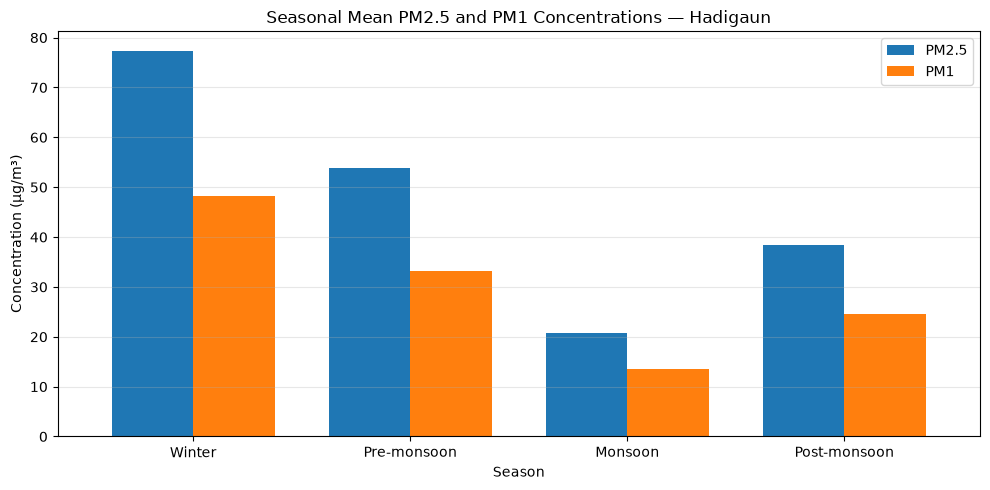

In [55]:
seasonal_plot = seasonal_stats[
    ["PM25_Mean", "PM1_Mean"]
]

ax = seasonal_plot.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.75
)

ax.set_title("Seasonal Mean PM2.5 and PM1 Concentrations — Hadigaun")
ax.set_xlabel("Season")
ax.set_ylabel("Concentration (µg/m³)")
ax.tick_params(axis="x", rotation=0)
ax.legend(["PM2.5", "PM1"])
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [56]:
seasonal_by_year = seasonal.copy()

seasonal_by_year["Year"] = seasonal_by_year.index.year

seasonal_by_year["Season-Year"] = np.where(
    seasonal_by_year.index.month == 12,
    seasonal_by_year["Year"] + 1,
    seasonal_by_year["Year"]
)

seasonal_year_stats = (
    seasonal_by_year.groupby(["Season-Year", "Season"])
    .agg(
        PM25_Hours=("pm25", "count"),
        PM25_Mean=("pm25", "mean"),
        PM1_Hours=("pm1", "count"),
        PM1_Mean=("pm1", "mean")
    )
    .reset_index()
)

seasonal_year_stats["Season"] = pd.Categorical(
    seasonal_year_stats["Season"],
    categories=season_order,
    ordered=True
)

seasonal_year_stats = seasonal_year_stats.sort_values(
    ["Season-Year", "Season"]
)

display(seasonal_year_stats.round(2))

,Season-Year,Season,PM25_Hours,PM25_Mean,PM1_Hours,PM1_Mean
0,2025,Monsoon,2146,19.56,2146,12.79
1,2025,Post-monsoon,1383,40.07,1383,25.59
5,2026,Winter,2140,77.39,2140,48.24
4,2026,Pre-monsoon,2129,53.94,2129,33.10
2,2026,Monsoon,2742,21.82,2742,14.16
3,2026,Post-monsoon,441,33.28,441,21.02


Long Term Concentration Trend

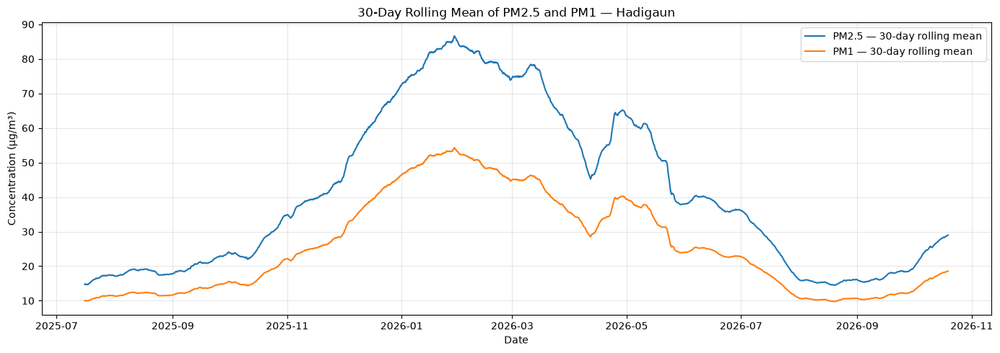

In [57]:
rolling_data = temporal[["pm25", "pm1"]].asfreq("h")

rolling_30d = rolling_data.rolling(
    window="30D",
    min_periods=24 * 15
).mean()

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    rolling_30d.index,
    rolling_30d["pm25"],
    label="PM2.5 — 30-day rolling mean"
)

ax.plot(
    rolling_30d.index,
    rolling_30d["pm1"],
    label="PM1 — 30-day rolling mean"
)

ax.set_title("30-Day Rolling Mean of PM2.5 and PM1 — Hadigaun")
ax.set_xlabel("Date")
ax.set_ylabel("Concentration (µg/m³)")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Monthly Temperature and Surface Radiation Patterns

This analysis examines monthly variations in temperature and surface radiation at Hadigaun to identify recurring meteorological patterns that may help explain seasonal changes in particulate concentrations. Monthly temperature distributions are used to identify groups of months with comparable thermal conditions. Surface radiation variables are examined separately to understand their seasonal variation and potential relevance to subsequent meteorological relationship analysis.

In [58]:
temperature_monthly = (
    temporal["temperature_2m"]
    .groupby(temporal.index.to_period("M"))
    .agg(
        Valid_Hours="count",
        Mean="mean",
        Median="median",
        SD="std",
        Min="min",
        Max="max",
        P5=lambda x: x.quantile(0.05),
        P95=lambda x: x.quantile(0.95)
    )
)

temperature_monthly.index.name = "Month"

display(temperature_monthly.round(2))

C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\3455396608.py:3: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  .groupby(temporal.index.to_period("M"))


,Valid_Hours,Mean,Median,SD,Min,Max,P5,P95
Month,,,,,,,,
2025-07,742,22.94,22.40,2.27,18.4,29.4,19.90,26.80
2025-08,724,22.18,21.60,2.11,17.7,28.6,19.30,25.90
2025-09,680,21.76,21.00,2.56,17.4,28.5,18.50,26.20
2025-10,691,19.01,18.50,3.09,12.6,25.9,14.80,24.20
2025-11,692,14.82,14.70,4.16,5.3,23.3,8.90,21.64
2025-12,736,12.11,11.00,4.02,4.9,20.5,6.70,18.92
2026-01,734,10.58,9.45,4.22,3.2,19.2,5.06,17.90
2026-02,670,13.28,12.45,3.96,5.6,22.2,7.70,19.70
2026-03,738,15.74,15.00,3.48,8.3,25.1,10.68,21.20


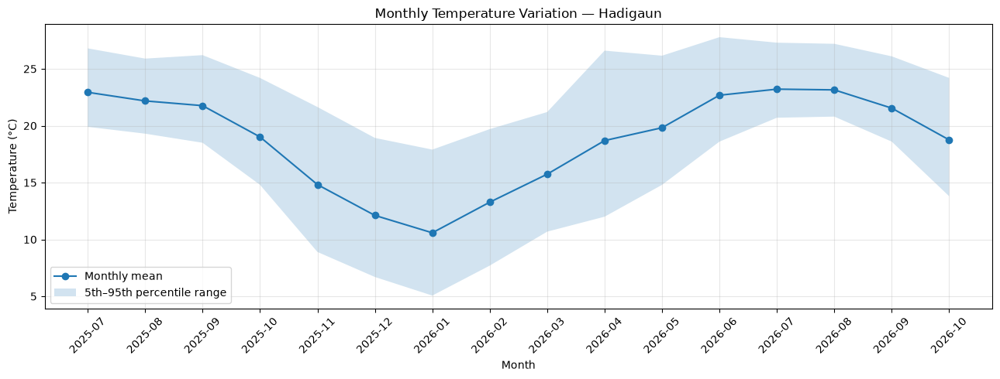

In [59]:
fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    temperature_monthly.index.astype(str),
    temperature_monthly["Mean"],
    marker="o",
    label="Monthly mean"
)

ax.fill_between(
    temperature_monthly.index.astype(str),
    temperature_monthly["P5"],
    temperature_monthly["P95"],
    alpha=0.2,
    label="5th–95th percentile range"
)

ax.set_title("Monthly Temperature Variation — Hadigaun")
ax.set_xlabel("Month")
ax.set_ylabel("Temperature (°C)")
ax.tick_params(axis="x", rotation=45)
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [60]:
radiation_columns = [
    "shortwave_radiation",
    "direct_radiation",
    "diffuse_radiation"
]

radiation_monthly = (
    temporal[radiation_columns]
    .groupby(temporal.index.to_period("M"))
    .agg(["count", "mean", "median", "std"])
)

radiation_monthly.columns = [
    f"{variable}_{stat}"
    for variable, stat in radiation_monthly.columns
]

radiation_monthly.index.name = "Month"

display(radiation_monthly.round(2))

C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\756599772.py:9: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  .groupby(temporal.index.to_period("M"))


,shortwave_radiation_count,shortwave_radiation_mean,shortwave_radiation_median,shortwave_radiation_std,direct_radiation_count,direct_radiation_mean,direct_radiation_median,direct_radiation_std,diffuse_radiation_count,diffuse_radiation_mean,diffuse_radiation_median,diffuse_radiation_std
Month,,,,,,,,,,,,
2025-07,742,203.67,62.0,248.79,742,103.19,9.0,154.87,742,100.48,45.5,113.90
2025-08,724,179.36,30.0,232.21,724,83.66,2.0,136.48,724,95.70,25.5,114.25
2025-09,680,196.48,21.5,254.47,680,113.79,2.5,173.79,680,82.69,17.5,99.86
2025-10,691,171.97,2.0,247.19,691,116.76,0.0,188.62,691,55.21,2.0,73.30
2025-11,692,153.67,0.0,225.40,692,109.21,0.0,172.68,692,44.46,0.0,59.69
2025-12,736,149.69,0.0,217.75,736,111.44,0.0,170.96,736,38.24,0.0,50.42
2026-01,734,161.61,0.0,231.93,734,119.74,0.0,182.18,734,41.87,0.0,57.12
2026-02,670,184.19,0.0,250.86,670,127.04,0.0,185.83,670,57.14,0.0,73.73
2026-03,738,187.93,8.0,250.45,738,109.75,1.0,170.36,738,78.18,7.0,97.03


C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\3546073057.py:3: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  .groupby(temporal.index.to_period("M"))


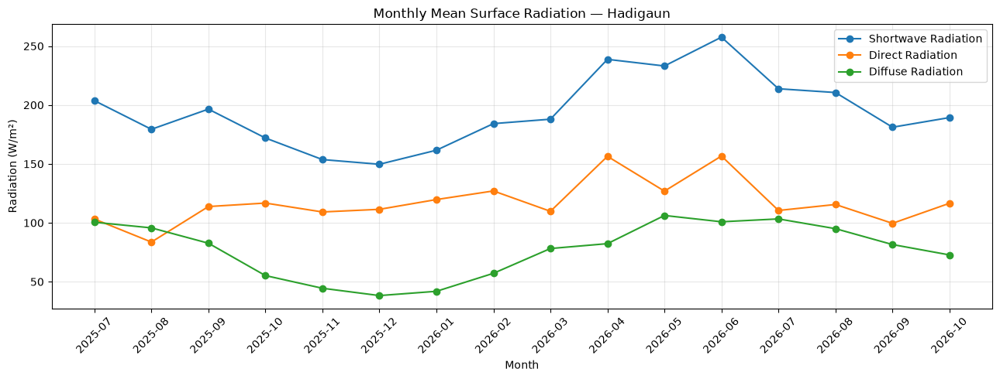

In [61]:
radiation_mean = (
    temporal[radiation_columns]
    .groupby(temporal.index.to_period("M"))
    .mean()
)

radiation_mean.index = radiation_mean.index.astype(str)

fig, ax = plt.subplots(figsize=(13, 5))

for column in radiation_columns:
    ax.plot(
        radiation_mean.index,
        radiation_mean[column],
        marker="o",
        label=column.replace("_", " ").title()
    )

ax.set_title("Monthly Mean Surface Radiation — Hadigaun")
ax.set_xlabel("Month")
ax.set_ylabel("Radiation (W/m²)")
ax.tick_params(axis="x", rotation=45)
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [62]:
temperature_groups = temperature_monthly[["Mean"]].copy()

temperature_groups["Difference from Previous Month"] = (
    temperature_groups["Mean"].diff()
)

temperature_groups["Difference from Overall Mean"] = (
    temperature_groups["Mean"]
    - temperature_groups["Mean"].mean()
)

display(temperature_groups.round(2))

,Mean,Difference from Previous Month,Difference from Overall Mean
Month,,,
2025-07,22.94,NaN,4.17
2025-08,22.18,-0.76,3.41
2025-09,21.76,-0.42,3.00
2025-10,19.01,-2.75,0.25
2025-11,14.82,-4.19,-3.95
2025-12,12.11,-2.71,-6.65
2026-01,10.58,-1.53,-8.18
2026-02,13.28,2.69,-5.49
2026-03,15.74,2.46,-3.03


Heirerchical Clustering of Monthly Mean Temperatures

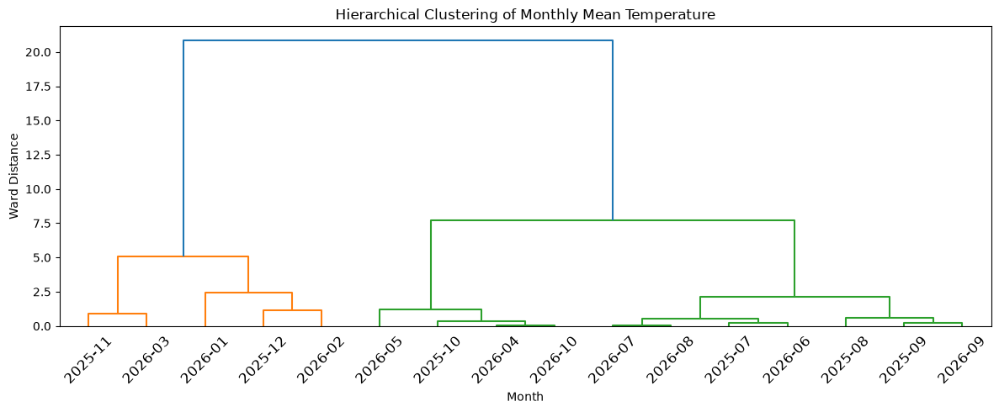

In [63]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler

monthly_temp_values = temperature_monthly[["Mean"]].dropna()

# One-dimensional monthly mean temperature clustering
Z = linkage(
    monthly_temp_values.values,
    method="ward"
)

plt.figure(figsize=(12, 5))

dendrogram(
    Z,
    labels=monthly_temp_values.index.astype(str).tolist()
)

plt.title("Hierarchical Clustering of Monthly Mean Temperature")
plt.xlabel("Month")
plt.ylabel("Ward Distance")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Hadigaun Year Over Year Monthly Comparison

In [64]:
# Use the Hadigaun particulate data
aq = hadigaun.copy()

aq["datetime"] = pd.to_datetime(aq["datetime"])
aq = aq.sort_values("datetime").set_index("datetime")

# Ensure a regular hourly index, retaining missing timestamps
aq = aq.asfreq("h")

# Monthly expected hours and valid observations
monthly_rows = []

for period, group in aq.groupby(aq.index.to_period("M")):

    # Full calendar-month expected hours
    expected = period.days_in_month * 24

    pm25 = group["pm25"].dropna()
    pm1 = group["pm1"].dropna()

    monthly_rows.append({
        "Month": str(period),
        "Expected_Hours": expected,
        "Valid_Hours": pm25.count(),
        "Coverage_%": pm25.count() / expected * 100,

        "PM25_Mean": pm25.mean(),
        "PM25_Median": pm25.median(),
        "PM25_P95": pm25.quantile(0.95),

        "PM1_Mean": pm1.mean(),
        "PM1_Median": pm1.median(),
        "PM1_P95": pm1.quantile(0.95)
    })

monthly_aq = pd.DataFrame(monthly_rows).set_index("Month")

display(monthly_aq.round(2))

C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\1181614484.py:13: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  for period, group in aq.groupby(aq.index.to_period("M")):


,Expected_Hours,Valid_Hours,Coverage_%,PM25_Mean,PM25_Median,PM25_P95,PM1_Mean,PM1_Median,PM1_P95
Month,,,,,,,,,
2025-07,744,742,99.73,17.20,16.03,32.76,11.40,10.58,21.47
2025-08,744,724,97.31,17.78,16.78,32.04,11.64,10.95,20.70
2025-09,720,680,94.44,24.02,23.45,40.41,15.55,15.25,26.09
2025-10,744,691,92.88,34.27,34.27,61.89,21.78,21.55,39.12
2025-11,720,692,96.11,45.87,44.05,86.34,29.40,28.10,55.64
2025-12,744,736,98.92,72.44,62.82,147.16,46.42,39.62,94.44
2026-01,744,734,98.66,84.15,73.59,171.56,52.65,46.13,107.69
2026-02,672,670,99.70,75.44,67.96,133.07,45.42,40.20,82.82
2026-03,744,738,99.19,59.75,55.65,104.84,35.67,33.85,60.52


In [65]:
# Extract year and calendar month
aq_monthly = aq.copy()

aq_monthly["Year"] = aq_monthly.index.year
aq_monthly["Month_Number"] = aq_monthly.index.month
aq_monthly["Month_Name"] = aq_monthly.index.strftime("%b")

yearly_monthly = (
    aq_monthly
    .groupby(["Year", "Month_Number"])
    .agg(
        Valid_Hours=("pm25", "count"),
        PM25_Mean=("pm25", "mean"),
        PM25_Median=("pm25", "median"),
        PM1_Mean=("pm1", "mean"),
        PM1_Median=("pm1", "median")
    )
    .reset_index()
)

# Keep July to October
yearly_monthly = yearly_monthly[
    yearly_monthly["Month_Number"].between(7, 10)
]

display(yearly_monthly.round(2))

,Year,Month_Number,Valid_Hours,PM25_Mean,PM25_Median,PM1_Mean,PM1_Median
0,2025,7,742,17.20,16.03,11.40,10.58
1,2025,8,724,17.78,16.78,11.64,10.95
2,2025,9,680,24.02,23.45,15.55,15.25
3,2025,10,691,34.27,34.27,21.78,21.55
12,2026,7,726,16.52,15.30,10.98,10.40
13,2026,8,726,16.07,15.20,10.66,10.30
14,2026,9,626,19.46,19.05,12.81,12.50
15,2026,10,441,33.28,33.80,21.02,21.40


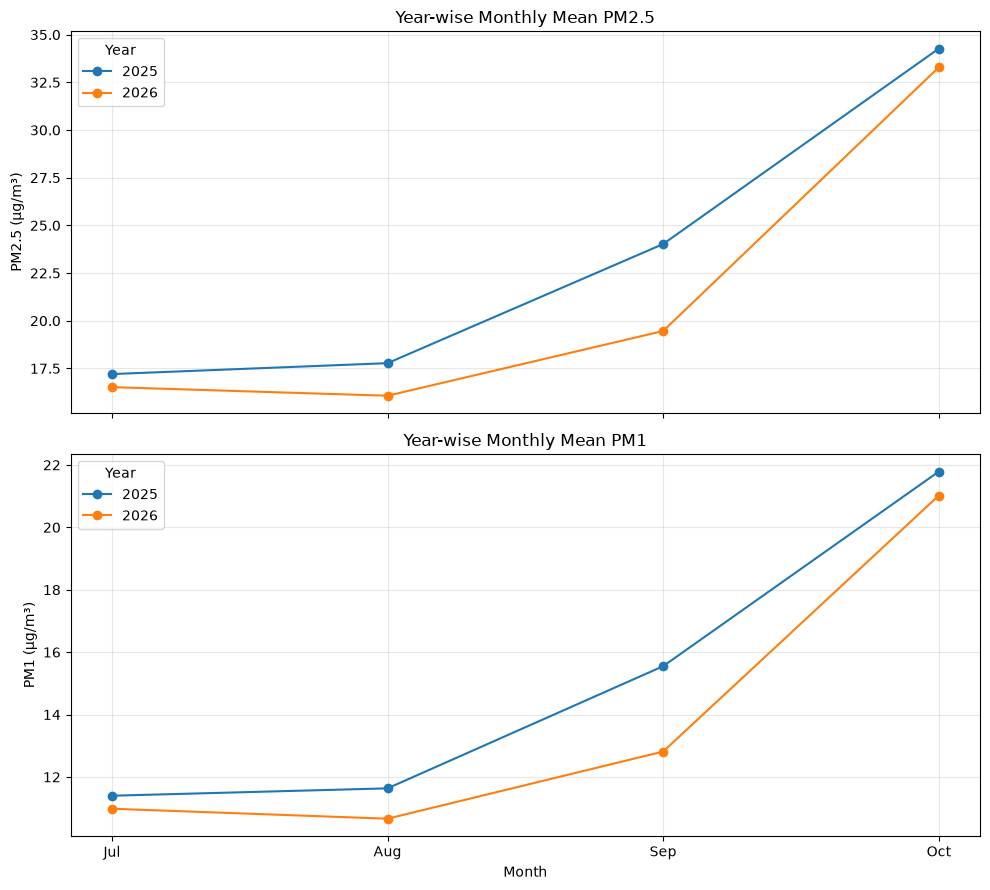

In [66]:
fig, axes = plt.subplots(2, 1, figsize=(10, 9), sharex=True)

for year, group in yearly_monthly.groupby("Year"):

    group = group.sort_values("Month_Number")

    axes[0].plot(
        group["Month_Number"],
        group["PM25_Mean"],
        marker="o",
        label=str(year)
    )

    axes[1].plot(
        group["Month_Number"],
        group["PM1_Mean"],
        marker="o",
        label=str(year)
    )

axes[0].set_title("Year-wise Monthly Mean PM2.5")
axes[0].set_ylabel("PM2.5 (µg/m³)")
axes[0].legend(title="Year")
axes[0].grid(alpha=0.3)

axes[1].set_title("Year-wise Monthly Mean PM1")
axes[1].set_ylabel("PM1 (µg/m³)")
axes[1].set_xlabel("Month")
axes[1].legend(title="Year")
axes[1].grid(alpha=0.3)

month_labels = ["Jul", "Aug", "Sep", "Oct"]
axes[1].set_xticks([7, 8, 9, 10])
axes[1].set_xticklabels(month_labels)

plt.tight_layout()
plt.show()

Embassy and Durbar Historical Assessment

In [67]:
def historical_monthly_summary(df, station_name):

    data = df.copy()

    data["datetime"] = pd.to_datetime(data["datetime"])
    data = data.sort_values("datetime").set_index("datetime")

    # Regular hourly index
    data = data.asfreq("h")

    rows = []

    for period, group in data.groupby(data.index.to_period("M")):

        expected = period.days_in_month * 24

        # Valid values are non-missing after historical cleaning
        valid = group["pm25"].dropna()

        valid_hours = valid.count()
        coverage = valid_hours / expected * 100

        # Only calculate reportable monthly means above the threshold
        if coverage >= 75:
            monthly_mean = valid.mean()
            monthly_median = valid.median()
        else:
            monthly_mean = np.nan
            monthly_median = np.nan

        rows.append({
            "Station": station_name,
            "Month": str(period),
            "Year": period.year,
            "Month_Number": period.month,
            "Expected_Hours": expected,
            "Valid_Hours": valid_hours,
            "Coverage_%": coverage,
            "PM25_Mean": monthly_mean,
            "PM25_Median": monthly_median
        })

    return pd.DataFrame(rows)


embassy_monthly = historical_monthly_summary(
    embassy, "Embassy"
)

durbar_monthly = historical_monthly_summary(
    durbar, "Durbar"
)

historical_monthly = pd.concat(
    [embassy_monthly, durbar_monthly],
    ignore_index=True
)

display(
    historical_monthly
    .round(2)
    .sort_values(["Station", "Month"])
)

C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\419757362.py:13: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  for period, group in data.groupby(data.index.to_period("M")):
C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\419757362.py:13: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  for period, group in data.groupby(data.index.to_period("M")):


,Station,Month,Year,Month_Number,Expected_Hours,Valid_Hours,Coverage_%,PM25_Mean,PM25_Median
30,Durbar,2022-10,2022,10,744,1,0.13,NaN,NaN
31,Durbar,2022-11,2022,11,720,273,37.92,NaN,NaN
32,Durbar,2022-12,2022,12,744,329,44.22,NaN,NaN
33,Durbar,2023-01,2023,1,744,441,59.27,NaN,NaN
34,Durbar,2023-02,2023,2,672,74,11.01,NaN,NaN
35,Durbar,2023-03,2023,3,744,313,42.07,NaN,NaN
36,Durbar,2023-04,2023,4,720,544,75.56,80.56,75.0
37,Durbar,2023-05,2023,5,744,0,0.00,NaN,NaN
38,Durbar,2023-06,2023,6,720,268,37.22,NaN,NaN
39,Durbar,2023-07,2023,7,744,717,96.37,16.93,16.0


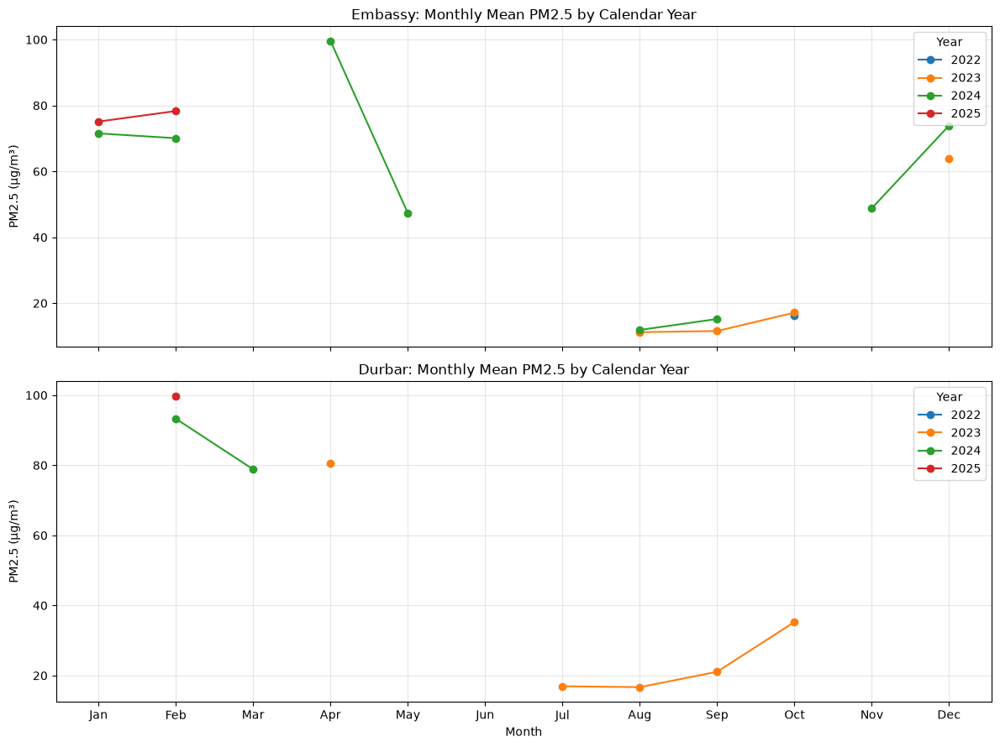

In [68]:
fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

for ax, (station, data) in zip(
    axes,
    [
        ("Embassy", embassy_monthly),
        ("Durbar", durbar_monthly)
    ]
):

    for year, group in data.groupby("Year"):

        group = group.sort_values("Month_Number")

        ax.plot(
            group["Month_Number"],
            group["PM25_Mean"],
            marker="o",
            label=str(year)
        )

    ax.set_title(f"{station}: Monthly Mean PM2.5 by Calendar Year")
    ax.set_ylabel("PM2.5 (µg/m³)")
    ax.legend(title="Year")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Month")
axes[-1].set_xticks(range(1, 13))
axes[-1].set_xticklabels([
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
])

plt.tight_layout()
plt.show()

In [69]:
def winter_summary(monthly_data):

    data = monthly_data.copy()

    data["Month"] = pd.to_datetime(data["Month"])

    # December belongs to the following winter year
    data["Winter_Year"] = np.where(
        data["Month"].dt.month == 12,
        data["Month"].dt.year + 1,
        data["Month"].dt.year
    )

    data["Is_Winter"] = data["Month"].dt.month.isin([12, 1, 2])

    winter = data[data["Is_Winter"]].copy()

    return (
        winter.groupby("Winter_Year")
        .agg(
            Months_Available=("Month", "count"),
            Mean_Monthly_Coverage=("Coverage_%", "mean"),
            Mean_PM25=("PM25_Mean", "mean"),
            Median_PM25=("PM25_Median", "median")
        )
        .round(2)
    )


print("EMBASSY WINTER COMPARISON")
display(winter_summary(embassy_monthly))

print("DURBAR WINTER COMPARISON")
display(winter_summary(durbar_monthly))

EMBASSY WINTER COMPARISON


,Months_Available,Mean_Monthly_Coverage,Mean_PM25,Median_PM25
Winter_Year,,,,
2023,3,4.10,NaN,NaN
2024,3,91.51,68.45,65.0
2025,3,88.71,75.78,71.0


DURBAR WINTER COMPARISON


,Months_Available,Mean_Monthly_Coverage,Mean_PM25,Median_PM25
Winter_Year,,,,
2023,3,38.17,NaN,NaN
2024,3,44.73,93.28,90.0
2025,3,70.27,99.80,97.0


In [70]:
def jul_sep_summary(monthly_data, station_name):

    data = monthly_data.copy()

    data["Month"] = pd.to_datetime(data["Month"])

    data = data[
        data["Month"].dt.month.isin([7, 8, 9])
    ]

    result = (
        data.groupby("Year")
        .agg(
            Months_Available=("Month", "count"),
            Mean_Monthly_Coverage=("Coverage_%", "mean"),
            Mean_PM25=("PM25_Mean", "mean"),
            Median_PM25=("PM25_Median", "median")
        )
        .round(2)
    )

    print(station_name)
    display(result)


jul_sep_summary(embassy_monthly, "EMBASSY")
jul_sep_summary(durbar_monthly, "DURBAR")

EMBASSY


,Months_Available,Mean_Monthly_Coverage,Mean_PM25,Median_PM25
Year,,,,
2023,3,73.86,11.37,9.5
2024,3,86.05,13.53,11.5


DURBAR


,Months_Available,Mean_Monthly_Coverage,Mean_PM25,Median_PM25
Year,,,,
2023,3,96.02,18.23,16.0
2024,3,34.61,NaN,NaN


CAMS as a common comparison reference

In [71]:
# Prepare CAMS
cams_data = cams.copy()

cams_data["datetime_utc"] = pd.to_datetime(
    cams_data["datetime_utc"],
    utc=True
)

cams_data = cams_data.sort_values("datetime_utc")
cams_data = cams_data.set_index("datetime_utc")

# Convert to Nepal local time
cams_data.index = cams_data.index.tz_convert("Asia/Kathmandu")

# Prepare station records
def prepare_station_for_cams(df):

    data = df.copy()

    data["datetime"] = pd.to_datetime(data["datetime"])

    if data["datetime"].dt.tz is None:
        data["datetime"] = data["datetime"].dt.tz_localize(
            "Asia/Kathmandu"
        )

    data = data.sort_values("datetime").set_index("datetime")

    return data


embassy_c = prepare_station_for_cams(embassy)
durbar_c = prepare_station_for_cams(durbar)
hadigaun_c = prepare_station_for_cams(hadigaun)

# Select the common PM2.5 series
cams_pm25 = cams_data["pm25"].rename("CAMS_PM25")

def station_cams_comparison(station, station_name):

    station_pm25 = station["pm25"].rename("Station_PM25")

    matched = pd.concat(
        [station_pm25, cams_pm25],
        axis=1,
        join="inner"
    ).dropna()

    matched["Month"] = matched.index.to_period("M").astype(str)

    monthly = (
        matched.groupby("Month")
        .agg(
            Matched_Hours=("Station_PM25", "count"),
            Station_Mean=("Station_PM25", "mean"),
            CAMS_Mean=("CAMS_PM25", "mean")
        )
    )

    monthly["Station_CAMS_Ratio"] = (
        monthly["Station_Mean"] / monthly["CAMS_Mean"]
    )

    print(station_name)
    display(monthly.round(3))

    overall = pd.DataFrame({
        "Matched_Hours": [len(matched)],
        "Station_Mean": [matched["Station_PM25"].mean()],
        "CAMS_Mean": [matched["CAMS_PM25"].mean()],
        "Station_CAMS_Ratio": [
            matched["Station_PM25"].mean() /
            matched["CAMS_PM25"].mean()
        ]
    }, index=[station_name])

    return overall


cams_comparison = pd.concat([
    station_cams_comparison(embassy_c, "Embassy"),
    station_cams_comparison(durbar_c, "Durbar"),
    station_cams_comparison(hadigaun_c, "Hadigaun")
])

print("Overall matched-period comparison")
display(cams_comparison.round(3))

Embassy


C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\1342931335.py:49: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  matched["Month"] = matched.index.to_period("M").astype(str)


,Matched_Hours,Station_Mean,CAMS_Mean,Station_CAMS_Ratio
Month,,,,


Durbar


C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\1342931335.py:49: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  matched["Month"] = matched.index.to_period("M").astype(str)


,Matched_Hours,Station_Mean,CAMS_Mean,Station_CAMS_Ratio
Month,,,,


Hadigaun


C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\1342931335.py:49: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  matched["Month"] = matched.index.to_period("M").astype(str)


,Matched_Hours,Station_Mean,CAMS_Mean,Station_CAMS_Ratio
Month,,,,
2025-06,5,13.721,35.120,0.391
2025-07,742,17.200,29.347,0.586
2025-08,724,17.800,24.112,0.738
2025-09,680,23.954,24.544,0.976
2025-10,691,34.283,29.550,1.160
2025-11,692,46.280,43.002,1.076
2025-12,736,72.670,63.139,1.151
2026-01,734,83.892,75.145,1.116
2026-02,670,75.576,66.968,1.129


Overall matched-period comparison


,Matched_Hours,Station_Mean,CAMS_Mean,Station_CAMS_Ratio
Embassy,0,NaN,NaN,NaN
Durbar,0,NaN,NaN,NaN
Hadigaun,10981,41.195,39.62,1.04


Daytime Only Suface Radiation

In [73]:
radiation_variables = [
    "shortwave_radiation",
    "direct_radiation",
    "diffuse_radiation"
]

# Use hours with positive incoming shortwave radiation
daytime = temporal[
    temporal["shortwave_radiation"] > 0
].copy()

daytime_monthly = (
    daytime
    .groupby(daytime.index.to_period("M"))[radiation_variables]
    .agg(["count", "mean", "median", "std"])
)

display(daytime_monthly.round(2))

C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\2648074620.py:14: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  .groupby(daytime.index.to_period("M"))[radiation_variables]


shortwave_radiation                        direct_radiation          \
                       count    mean median     std            count    mean   
datetime                                                                       
2025-07                  456  331.41  329.0  241.61              456  167.91   
2025-08                  399  325.45  303.0  224.25              399  151.80   
2025-09                  368  363.05  377.5  243.24              368  210.26   
2025-10                  346  343.45  348.0  251.27              346  233.19   
2025-11                  331  321.26  302.0  228.86              331  228.31   
2025-12                  334  329.85  360.0  212.25              334  245.57   
2026-01                  331  358.37  369.0  220.81              331  265.53   
2026-02                  325  379.70  418.0  235.53              325  261.90   
2026-03                  403  344.16  336.0  247.17              403  200.99   
2026-04                  387  432.44  435.0  286.66              387  283.34   
2026-05                  400  402.10  417.0  264.10              400  218.86   
2026-06                  408  419.16  445.0  288.78              408  254.99   
2026-07                  442  351.11  344.0  258.81              442  181.44   
2026-08                  401  381.23  398.0  251.25              401  209.19   
2026-09                  329  344.63  367.0  248.28              329  189.45   
2026-10                  219  381.21  375.0  244.61              219  234.73   

                        diffuse_radiation                         
         median     std             count    mean median     std  
datetime                                                          
2025-07   120.5  167.84               456  163.50  169.5  103.94  
2025-08   104.0  153.20               399  173.65  178.0  100.70  
2025-09   155.0  188.52               368  152.79  155.0   87.80  
2025-10   192.5  209.58               346  110.26  111.0   68.26  
2025-11   194.0  187.51               331   92.95  105.0   54.22  
2025-12   256.0  177.40               334   84.27   96.0   41.47  
2026-01   270.0  186.78               331   92.84  103.0   50.01  
2026-02   282.0  189.40               325  117.80  122.0   63.70  
2026-03   155.0  186.62               403  143.17  147.0   89.07  
2026-04   244.0  229.45               387  149.10  161.0   81.23  
2026-05   177.5  183.87               400  183.23  196.0  101.99  
2026-06   210.5  209.82               408  164.17  168.5   99.23  
2026-07   139.5  172.09               442  169.67  175.5  108.17  
2026-08   175.0  181.20               401  172.04  179.0   95.84  
2026-09   155.0  179.63               329  155.18  161.0   93.39  
2026-10   220.0  184.71               219  146.48  158.0   75.18

C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\719086918.py:3: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  .groupby(daytime.index.to_period("M"))[radiation_variables]


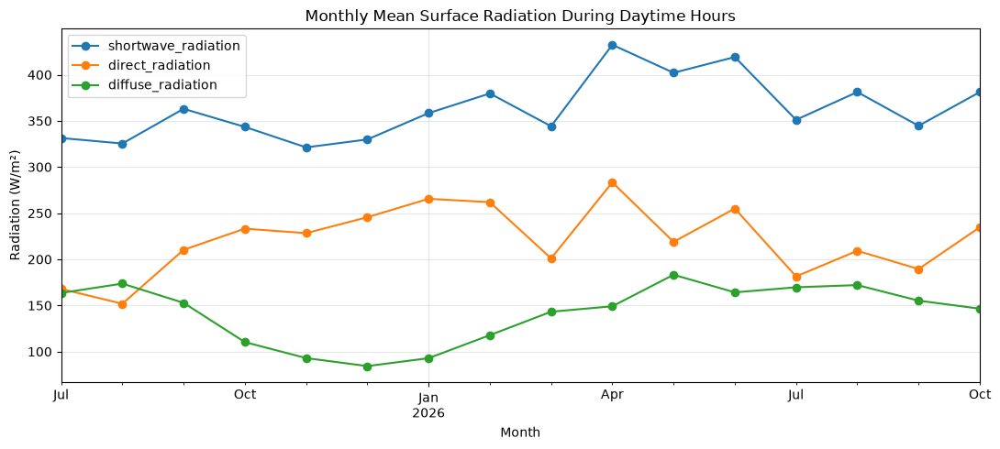

In [74]:
daytime_means = (
    daytime
    .groupby(daytime.index.to_period("M"))[radiation_variables]
    .mean()
)

ax = daytime_means.plot(
    figsize=(11, 5),
    marker="o"
)

ax.set_title("Monthly Mean Surface Radiation During Daytime Hours")
ax.set_xlabel("Month")
ax.set_ylabel("Radiation (W/m²)")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Temperature Clusters

In [75]:
temperature = temporal["temperature_2m"].dropna()

monthly_temperature = (
    temperature
    .groupby(temperature.index.to_period("M"))
    .mean()
    .rename("Monthly_Mean_Temperature")
    .reset_index()
)

monthly_temperature.columns = ["Month", "Mean_Temperature"]

# Assign the two groups based on the dendrogram result
cooler_months = [
    "2025-11", "2025-12",
    "2026-01", "2026-02", "2026-03"
]

monthly_temperature["Regime"] = np.where(
    monthly_temperature["Month"].astype(str).isin(cooler_months),
    "Cooler",
    "Warmer"
)

regime_summary = (
    monthly_temperature
    .groupby("Regime")
    .agg(
        Number_of_Months=("Mean_Temperature", "count"),
        Mean_of_Monthly_Means=("Mean_Temperature", "mean"),
        Minimum_Monthly_Mean=("Mean_Temperature", "min"),
        Maximum_Monthly_Mean=("Mean_Temperature", "max")
    )
)

# Observation-weighted hourly mean
hourly_regime = temporal[["temperature_2m"]].copy()

hourly_regime["Regime"] = np.where(
    hourly_regime.index.to_period("M").astype(str).isin(cooler_months),
    "Cooler",
    "Warmer"
)

weighted_summary = (
    hourly_regime.groupby("Regime")["temperature_2m"]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

print("Monthly temperature group summary")
display(regime_summary.round(2))

print("Observation-weighted hourly temperature summary")
display(weighted_summary.round(2))

Monthly temperature group summary


C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\3648975028.py:5: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  .groupby(temperature.index.to_period("M"))
C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\3648975028.py:40: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  hourly_regime.index.to_period("M").astype(str).isin(cooler_months),


,Number_of_Months,Mean_of_Monthly_Means,Minimum_Monthly_Mean,Maximum_Monthly_Mean
Regime,,,,
Cooler,5,13.31,10.58,15.74
Warmer,11,21.25,18.69,23.21


Observation-weighted hourly temperature summary


,count,mean,median,std,min,max
Regime,,,,,,
Cooler,3570,13.29,13.0,4.39,3.2,25.1
Warmer,7411,21.36,21.4,3.33,8.0,30.4


Winter Summary Cell

In [76]:
def winter_summary_corrected(monthly_data):

    data = monthly_data.copy()
    data["Month"] = pd.to_datetime(data["Month"])

    data["Winter_Year"] = np.where(
        data["Month"].dt.month == 12,
        data["Month"].dt.year + 1,
        data["Month"].dt.year
    )

    winter = data[
        data["Month"].dt.month.isin([12, 1, 2])
    ].copy()

    winter["Eligible"] = winter["PM25_Mean"].notna()

    result = (
        winter.groupby("Winter_Year")
        .agg(
            Calendar_Months=("Month", "count"),
            Eligible_Months=("Eligible", "sum"),
            Mean_Coverage=("Coverage_%", "mean"),
            Winter_PM25_Mean=("PM25_Mean", "mean")
        )
    )

    # Only consider a winter comparable if all three months qualify
    result.loc[
        result["Eligible_Months"] < 3,
        "Winter_PM25_Mean"
    ] = np.nan

    return result.round(2)


print("EMBASSY")
display(winter_summary_corrected(embassy_monthly))

print("DURBAR")
display(winter_summary_corrected(durbar_monthly))

EMBASSY


,Calendar_Months,Eligible_Months,Mean_Coverage,Winter_PM25_Mean
Winter_Year,,,,
2023,3,0,4.10,NaN
2024,3,3,91.51,68.45
2025,3,3,88.71,75.78


DURBAR


,Calendar_Months,Eligible_Months,Mean_Coverage,Winter_PM25_Mean
Winter_Year,,,,
2023,3,0,38.17,NaN
2024,3,1,44.73,NaN
2025,3,1,70.27,NaN


In [77]:
jul_sep = aq[
    aq.index.month.isin([7, 8, 9])
].copy()

jul_sep["Year"] = jul_sep.index.year

jul_sep_comparison = (
    jul_sep.groupby("Year")[["pm25", "pm1"]]
    .agg(["count", "mean", "median", "std"])
)

display(jul_sep_comparison.round(2))

pm25                       pm1                    
     count   mean median   std count   mean median   std
Year                                                    
2025  2146  19.56  18.23  9.67  2146  12.79   11.8  6.04
2026  2078  17.25  16.30  8.06  2078  11.42   10.9  5.13

Few additional statistics

MONTHLY YEAR-OVER-YEAR COMPARISON
 Year  Month  Valid_Hours  PM25_Mean  PM1_Mean
 2025      7          742      17.20     11.40
 2025      8          724      17.78     11.64
 2025      9          680      24.02     15.55
 2025     10          691      34.27     21.78
 2026      7          726      16.52     10.98
 2026      8          726      16.07     10.66
 2026      9          626      19.46     12.81
 2026     10          441      33.28     21.02


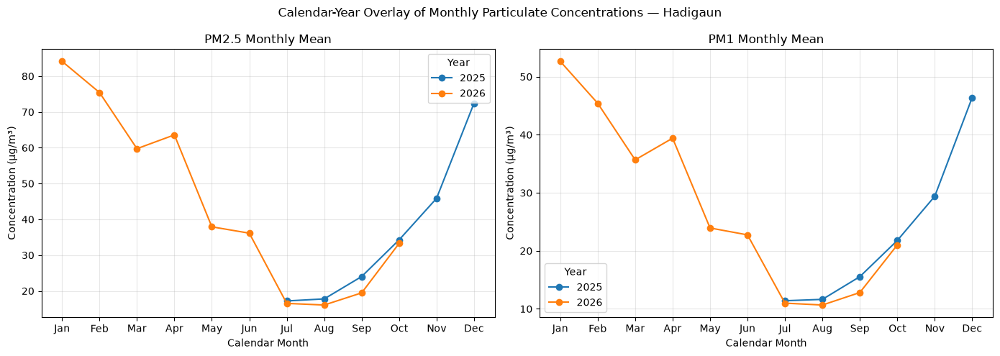

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

monthly_overlay_data = master[["datetime", "pm25", "pm1"]].copy()

monthly_overlay_data["datetime"] = pd.to_datetime(
    monthly_overlay_data["datetime"]
)

monthly_overlay_data["Year"] = (
    monthly_overlay_data["datetime"].dt.year
)

monthly_overlay_data["Month"] = (
    monthly_overlay_data["datetime"].dt.month
)

monthly_overlay = (
    monthly_overlay_data
    .groupby(["Year", "Month"])
    .agg(
        Valid_Hours=("pm25", "count"),
        PM25_Mean=("pm25", "mean"),
        PM1_Mean=("pm1", "mean")
    )
    .reset_index()
)

print("MONTHLY YEAR-OVER-YEAR COMPARISON")
print(
    monthly_overlay[
        monthly_overlay["Month"].between(7, 10)
    ].round(2).to_string(index=False)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for year, group in monthly_overlay.groupby("Year"):

    axes[0].plot(
        group["Month"],
        group["PM25_Mean"],
        marker="o",
        label=str(year)
    )

    axes[1].plot(
        group["Month"],
        group["PM1_Mean"],
        marker="o",
        label=str(year)
    )

for ax, title in zip(
    axes,
    ["PM2.5 Monthly Mean", "PM1 Monthly Mean"]
):
    ax.set_title(title)
    ax.set_xlabel("Calendar Month")
    ax.set_ylabel("Concentration (µg/m³)")
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(
        ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
         "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
    )
    ax.grid(True, alpha=0.3)
    ax.legend(title="Year")

plt.suptitle(
    "Calendar-Year Overlay of Monthly Particulate Concentrations — Hadigaun"
)
plt.tight_layout()
plt.show()

Using dataframe: embassy
Using dataframe: durbar


C:\Users\ianus\AppData\Local\Temp\ipykernel_13932\1428225715.py:51: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  data["Month"] = data["datetime"].dt.to_period("M")
C:\Users\ianus\AppData\Local\Temp\ipykernel_13932\1428225715.py:51: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  data["Month"] = data["datetime"].dt.to_period("M")


QUALIFYING HISTORICAL MONTHS — COVERAGE >= 75%
Station   Month  Year  Month_Number  Expected_Hours  Valid_Hours  Coverage_Percent  PM25_Mean  PM25_Median
 Durbar 2023-04  2023             4             720          544             75.56      80.56         75.0
 Durbar 2023-07  2023             7             744          717             96.37      16.93         16.0
 Durbar 2023-08  2023             8             744          741             99.60      16.68         16.0
 Durbar 2023-09  2023             9             720          663             92.08      21.07         20.0
 Durbar 2023-10  2023            10             744          734             98.66      35.25         33.0
 Durbar 2024-02  2024             2             696          600             86.21      93.28         90.0
 Durbar 2024-03  2024             3             744          594             79.84      78.84         74.0
 Durbar 2025-02  2025             2             672          536             79.76      99.80    

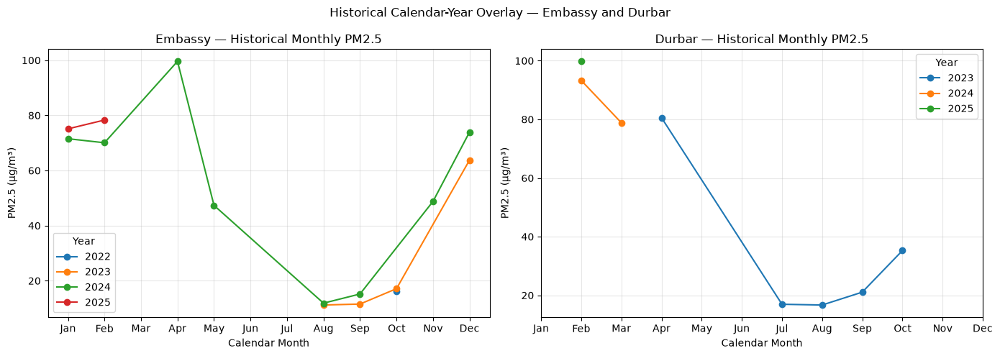

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

def get_dataframe(candidates):
    for name in candidates:
        obj = globals().get(name)
        if isinstance(obj, pd.DataFrame):
            print(f"Using dataframe: {name}")
            return obj
    raise NameError(
        f"Could not find dataframe. Checked: {candidates}"
    )

embassy_data = get_dataframe([
    "embassy", "EMBASSY", "embassy_clean",
    "embassy_cleaned", "embassy_df"
])

durbar_data = get_dataframe([
    "durbar", "DURBAR", "durbar_clean",
    "durbar_cleaned", "durbar_df"
])

historical_frames = {
    "Embassy": embassy_data,
    "Durbar": durbar_data
}

historical_monthly_results = []

for station, df in historical_frames.items():

    data = df.copy()

    data["datetime"] = pd.to_datetime(data["datetime"])

    pm_col = next(
        c for c in ["pm25", "PM2.5", "PM25"]
        if c in data.columns
    )

    data[pm_col] = pd.to_numeric(
        data[pm_col],
        errors="coerce"
    )

    data.loc[data[pm_col] < 0, pm_col] = float("nan")

    data = data.dropna(subset=["datetime"])

    data["Month"] = data["datetime"].dt.to_period("M")

    for month, group in data.groupby("Month"):

        expected_hours = month.days_in_month * 24

        valid_values = group[pm_col].dropna()

        valid_hours = len(valid_values)

        coverage = (
            valid_hours / expected_hours
        ) * 100

        if coverage >= 75:

            historical_monthly_results.append({
                "Station": station,
                "Month": str(month),
                "Year": month.year,
                "Month_Number": month.month,
                "Expected_Hours": expected_hours,
                "Valid_Hours": valid_hours,
                "Coverage_Percent": coverage,
                "PM25_Mean": valid_values.mean(),
                "PM25_Median": valid_values.median()
            })

historical_monthly = pd.DataFrame(
    historical_monthly_results
)

historical_monthly = historical_monthly.sort_values(
    ["Station", "Year", "Month_Number"]
)

print("QUALIFYING HISTORICAL MONTHS — COVERAGE >= 75%")
print(historical_monthly.round(2).to_string(index=False))

# Separate calendar-year overlays for the historical stations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, station in zip(
    axes,
    ["Embassy", "Durbar"]
):

    station_data = historical_monthly[
        historical_monthly["Station"] == station
    ]

    for year, group in station_data.groupby("Year"):

        ax.plot(
            group["Month_Number"],
            group["PM25_Mean"],
            marker="o",
            label=str(year)
        )

    ax.set_title(f"{station} — Historical Monthly PM2.5")
    ax.set_xlabel("Calendar Month")
    ax.set_ylabel("PM2.5 (µg/m³)")
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(
        ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
         "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
    )
    ax.grid(True, alpha=0.3)
    ax.legend(title="Year")

plt.suptitle(
    "Historical Calendar-Year Overlay — Embassy and Durbar"
)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import pearsonr, spearmanr

cams_data = get_dataframe(["cams", "CAMS", "cams_clean"])

cams_time_col = (
    "datetime_utc"
    if "datetime_utc" in cams_data.columns
    else "datetime"
)

cams_pm_col = next(
    c for c in ["pm2_5", "pm25", "PM2.5"]
    if c in cams_data.columns
)

cams_hourly = cams_data[
    [cams_time_col, cams_pm_col]
].copy()

cams_hourly["hour_utc"] = pd.to_datetime(
    cams_hourly[cams_time_col],
    utc=True
).dt.floor("h")

cams_hourly["CAMS_PM25"] = pd.to_numeric(
    cams_hourly[cams_pm_col],
    errors="coerce"
)

cams_hourly = (
    cams_hourly[["hour_utc", "CAMS_PM25"]]
    .dropna()
    .drop_duplicates("hour_utc")
)

def prepare_station_for_cams(df, station_name, time_col, pm_col):

    data = df[[time_col, pm_col]].copy()

    data["datetime"] = pd.to_datetime(data[time_col])

    if data["datetime"].dt.tz is None:
        data["datetime"] = (
            data["datetime"].dt.tz_localize("Asia/Kathmandu")
        )

    data["hour_utc"] = (
        data["datetime"]
        .dt.tz_convert("UTC")
        .dt.floor("h")
    )

    data["Station_PM25"] = pd.to_numeric(
        data[pm_col],
        errors="coerce"
    )

    data.loc[data["Station_PM25"] < 0, "Station_PM25"] = np.nan

    data = (
        data[["hour_utc", "Station_PM25"]]
        .dropna()
        .drop_duplicates("hour_utc")
    )

    matched = data.merge(
        cams_hourly,
        on="hour_utc",
        how="inner"
    )

    matched["Station"] = station_name

    return matched


station_inputs = [
    ("Embassy", embassy_data, "datetime",
     next(c for c in ["pm25", "PM2.5", "PM25"] if c in embassy_data.columns)),

    ("Durbar", durbar_data, "datetime",
     next(c for c in ["pm25", "PM2.5", "PM25"] if c in durbar_data.columns)),

    ("Hadigaun", master, "datetime", "pm25")
]

cams_comparison_results = []
cams_matched_data = {}

for station, df, time_col, pm_col in station_inputs:

    matched = prepare_station_for_cams(
        df, station, time_col, pm_col
    )

    cams_matched_data[station] = matched

    if len(matched) < 3:
        continue

    cams_comparison_results.append({
        "Station": station,
        "Matched_Hours": len(matched),
        "Station_Mean": matched["Station_PM25"].mean(),
        "CAMS_Mean": matched["CAMS_PM25"].mean(),
        "Mean_Bias_CAMS_minus_Station": (
            matched["CAMS_PM25"] - matched["Station_PM25"]
        ).mean(),
        "MAE": (
            matched["CAMS_PM25"] - matched["Station_PM25"]
        ).abs().mean(),
        "RMSE": np.sqrt(
            (
                matched["CAMS_PM25"] - matched["Station_PM25"]
            ).pow(2).mean()
        ),
        "Pearson": pearsonr(
            matched["Station_PM25"],
            matched["CAMS_PM25"]
        ).statistic,
        "Spearman": spearmanr(
            matched["Station_PM25"],
            matched["CAMS_PM25"]
        ).statistic
    })

cams_comparison = pd.DataFrame(
    cams_comparison_results
)

print("CAMS–STATION COMPARISON")
print(cams_comparison.round(3).to_string(index=False))

Using dataframe: cams
CAMS–STATION COMPARISON
 Station  Matched_Hours  Station_Mean  CAMS_Mean  Mean_Bias_CAMS_minus_Station    MAE   RMSE  Pearson  Spearman
 Embassy          13256        44.110     33.252                       -10.858 22.347 39.550    0.456     0.633
  Durbar          10135        59.228     34.869                       -24.359 31.365 46.674    0.504     0.592
Hadigaun          10981        41.195     39.620                        -1.575 18.575 26.774    0.599     0.602


In [ ]:
season_data = master[["datetime", "pm25"]].copy()

season_data["datetime"] = pd.to_datetime(
    season_data["datetime"]
)

season_data = season_data.dropna(subset=["pm25"])

month = season_data["datetime"].dt.month

season_data["Season"] = np.select(
    [
        month.isin([12, 1, 2]),
        month.isin([3, 4, 5]),
        month.isin([6, 7, 8, 9]),
        month.isin([10, 11])
    ],
    [
        "Winter",
        "Pre-monsoon",
        "Monsoon",
        "Post-monsoon"
    ],
    default="Unknown"
)

season_days = (
    season_data
    .assign(Date=season_data["datetime"].dt.date)
    .groupby("Season")
    .agg(
        Valid_Hours=("pm25", "count"),
        Valid_Days=("Date", "nunique")
    )
    .reindex([
        "Winter", "Pre-monsoon",
        "Monsoon", "Post-monsoon"
    ])
)

print(season_days)

              Valid_Hours  Valid_Days
Season                               
Winter               2140          90
Pre-monsoon          2129          92
Monsoon              4888         212
Post-monsoon         1824          79


## Observation — Temporal and Seasonal Patterns

The Hadigaun dataset exhibits a clear temporal and seasonal pattern in particulate concentrations. PM2.5 and PM1 generally increased from the monsoon months towards winter, reaching their highest monthly mean concentrations in January 2026 (84.15 µg/m³ and 52.65 µg/m³, respectively). Concentrations subsequently declined during the pre-monsoon period and reached their lowest monthly means in August 2026 (16.07 µg/m³ and 10.66 µg/m³). The 30-day rolling averages support this broad seasonal pattern.

The pooled seasonal comparison also identifies winter as the highest-concentration season (PM2.5: 77.39 µg/m³; PM1: 48.24 µg/m³), while the monsoon has the lowest concentrations (20.83 µg/m³ and 13.56 µg/m³). A comparison of the available July–September observations shows lower concentrations in 2026 than in 2025 for both pollutants. However, only two monsoon periods are available, so this difference should not be interpreted as an established interannual trend.

Meteorological data show a corresponding annual temperature cycle. Open-Meteo temperature was lowest in January 2026 (monthly mean 10.58°C) and highest in July 2026 (23.21°C). Exploratory grouping of monthly temperature means separated the observed months into cooler and warmer regimes, with mean monthly temperatures of 13.31°C and 21.25°C, respectively. Model-derived radiation estimates also varied seasonally. These shared seasonal patterns do not, by themselves, establish direct relationships between meteorological variables and particulate concentrations; those relationships are examined separately in Sections 4.7 and 4.8.

Temporal coverage was generally high, although September 2026 had reduced pollutant coverage (86.94%), and October 2026 represents only a partial month (441 of 744 expected hours). The historical Embassy and Durbar records were unsuitable for consistent seasonal comparison because of substantial invalid readings and insufficiently complete winter records. They were therefore excluded from subsequent Hadigaun-based analysis.

## 4.6 Daily and Weekly Patterns

This section examines short-term temporal variations in particulate concentrations at the Hadigaun monitoring station. The analysis investigates hourly patterns to identify recurring within-day concentration changes, followed by day-of-week and weekday–weekend comparisons to assess potential weekly variations.

Hourly and daily groupings are evaluated using descriptive statistics, including valid observation counts, means, medians, standard deviations and 95th percentiles. These statistics help distinguish typical concentration patterns from the influence of occasional high-pollution observations.

The analysis is descriptive. Observed differences are not assumed to result from specific emission sources or human activities without supporting evidence.

In [79]:
# Prepare hourly grouping
hourly_profile = hadigaun.copy()

hourly_profile["datetime"] = pd.to_datetime(
    hourly_profile["datetime"]
)

hourly_profile["Hour"] = hourly_profile["datetime"].dt.hour

# Hour-of-day descriptive statistics
hourly_stats = (
    hourly_profile
    .groupby("Hour")
    .agg(
        Valid_Hours=("pm25", "count"),

        PM25_Mean=("pm25", "mean"),
        PM25_Median=("pm25", "median"),
        PM25_SD=("pm25", "std"),
        PM25_P95=("pm25", lambda x: x.quantile(0.95)),

        PM1_Mean=("pm1", "mean"),
        PM1_Median=("pm1", "median"),
        PM1_SD=("pm1", "std"),
        PM1_P95=("pm1", lambda x: x.quantile(0.95))
    )
    .round(2)
)

hourly_stats

,Valid_Hours,PM25_Mean,PM25_Median,PM25_SD,PM25_P95,PM1_Mean,PM1_Median,PM1_SD,PM1_P95
Hour,,,,,,,,,
0,462,35.45,32.27,23.96,77.18,22.16,20.28,14.39,46.97
1,465,35.24,32.20,24.23,78.10,21.95,20.50,14.53,46.16
2,462,35.39,33.04,24.52,79.68,21.99,20.60,14.70,47.39
3,457,38.05,34.29,26.63,85.54,23.70,21.50,16.06,51.63
4,454,40.96,36.03,28.46,92.51,25.72,22.84,17.29,56.00
5,457,47.92,40.70,32.17,107.59,30.18,25.80,19.59,66.67
6,459,55.02,44.10,36.97,124.39,34.96,28.10,22.74,78.20
7,458,65.77,44.49,50.59,165.44,41.82,28.35,31.51,104.85
8,461,65.10,41.80,54.45,181.05,41.15,26.50,33.71,114.12


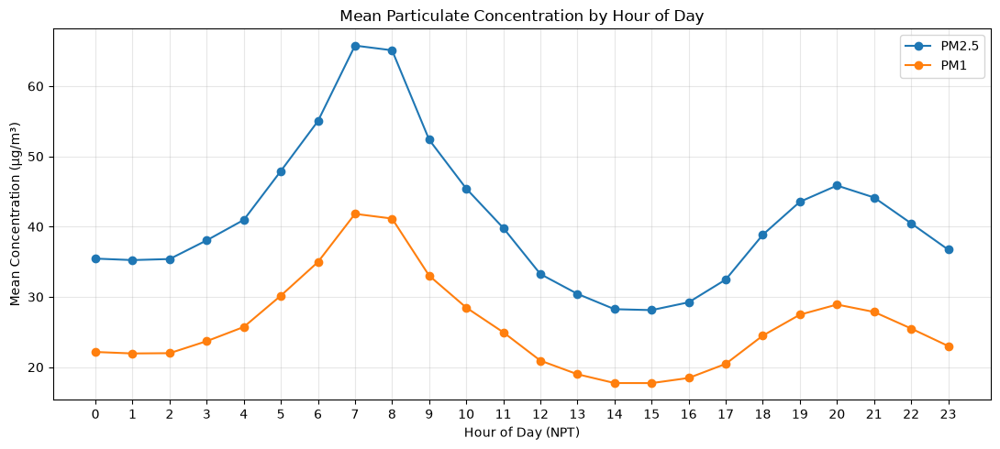

In [80]:
# Hourly mean profile
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    hourly_stats.index,
    hourly_stats["PM25_Mean"],
    marker="o",
    label="PM2.5"
)

ax.plot(
    hourly_stats.index,
    hourly_stats["PM1_Mean"],
    marker="o",
    label="PM1"
)

ax.set_title("Mean Particulate Concentration by Hour of Day")
ax.set_xlabel("Hour of Day (NPT)")
ax.set_ylabel("Mean Concentration (µg/m³)")
ax.set_xticks(range(24))
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

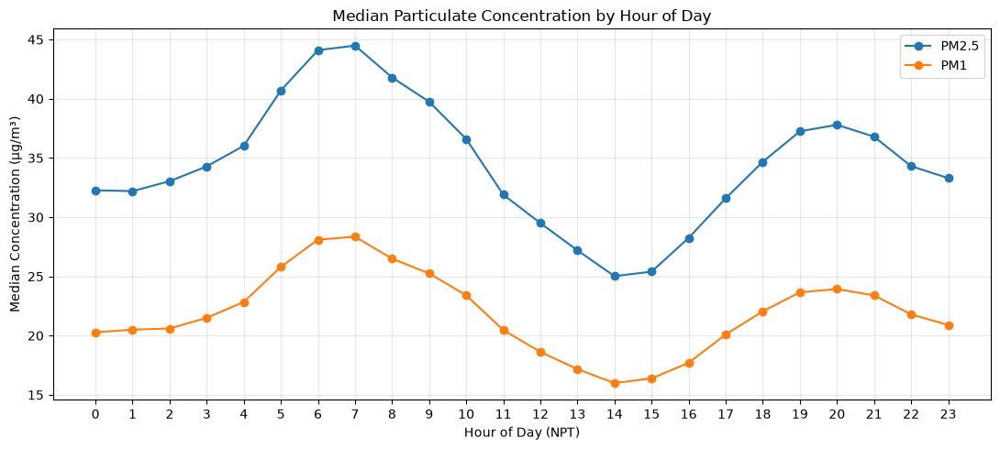

In [81]:
# Hourly median profile
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    hourly_stats.index,
    hourly_stats["PM25_Median"],
    marker="o",
    label="PM2.5"
)

ax.plot(
    hourly_stats.index,
    hourly_stats["PM1_Median"],
    marker="o",
    label="PM1"
)

ax.set_title("Median Particulate Concentration by Hour of Day")
ax.set_xlabel("Hour of Day (NPT)")
ax.set_ylabel("Median Concentration (µg/m³)")
ax.set_xticks(range(24))
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

In [82]:
# Key hourly profile statistics
hourly_summary = pd.DataFrame({
    "PM25_Mean": hourly_stats["PM25_Mean"],
    "PM25_Median": hourly_stats["PM25_Median"],
    "PM1_Mean": hourly_stats["PM1_Mean"],
    "PM1_Median": hourly_stats["PM1_Median"]
})

for col in hourly_summary.columns:
    max_hour = hourly_summary[col].idxmax()
    min_hour = hourly_summary[col].idxmin()

    print(f"\n{col}")
    print(f"Maximum: {hourly_summary[col].max():.2f} at {max_hour:02d}:00")
    print(f"Minimum: {hourly_summary[col].min():.2f} at {min_hour:02d}:00")

print("\nHourly profile values:")
display(hourly_summary.round(2))

print("\nObservation count by hour:")
display(hourly_stats[["Valid_Hours"]])


PM25_Mean
Maximum: 65.77 at 07:00
Minimum: 28.12 at 15:00

PM25_Median
Maximum: 44.49 at 07:00
Minimum: 25.02 at 14:00

PM1_Mean
Maximum: 41.82 at 07:00
Minimum: 17.73 at 15:00

PM1_Median
Maximum: 28.35 at 07:00
Minimum: 15.99 at 14:00

Hourly profile values:


,PM25_Mean,PM25_Median,PM1_Mean,PM1_Median
Hour,,,,
0,35.45,32.27,22.16,20.28
1,35.24,32.20,21.95,20.50
2,35.39,33.04,21.99,20.60
3,38.05,34.29,23.70,21.50
4,40.96,36.03,25.72,22.84
5,47.92,40.70,30.18,25.80
6,55.02,44.10,34.96,28.10
7,65.77,44.49,41.82,28.35
8,65.10,41.80,41.15,26.50



Observation count by hour:


,Valid_Hours
Hour,
0,462
1,465
2,462
3,457
4,454
5,457
6,459
7,458
8,461


The hourly analysis reveals a distinct daily variation in particulate concentrations. Both PM2.5 and PM1 show a pronounced morning peak at 07:00, with mean concentrations of 65.77 µg/m³ and 41.82 µg/m³, respectively. Concentrations subsequently decline, reaching their lowest hourly means at 15:00 (28.12 µg/m³ and 17.73 µg/m³), before increasing again during the evening and reaching a secondary peak around 20:00. The morning mean concentrations are notably higher than their corresponding medians, indicating the influence of elevated observations on the averages. Valid observation counts are relatively consistent across hours (448–465). These pooled patterns describe hourly variation across the monitoring period but do not establish specific emission sources or seasonal consistency.

In [83]:
# Prepare weekday grouping
weekly = hadigaun.copy()

weekly["datetime"] = pd.to_datetime(weekly["datetime"])
weekly["Day"] = weekly["datetime"].dt.day_name()

day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekly["Day"] = pd.Categorical(
    weekly["Day"],
    categories=day_order,
    ordered=True
)

# Day-of-week descriptive statistics
weekday_stats = (
    weekly.groupby("Day", observed=False)
    .agg(
        Valid_Hours=("pm25", "count"),

        PM25_Mean=("pm25", "mean"),
        PM25_Median=("pm25", "median"),
        PM25_SD=("pm25", "std"),
        PM25_P95=("pm25", lambda x: x.quantile(0.95)),

        PM1_Mean=("pm1", "mean"),
        PM1_Median=("pm1", "median"),
        PM1_SD=("pm1", "std"),
        PM1_P95=("pm1", lambda x: x.quantile(0.95))
    )
    .round(2)
)

display(weekday_stats)

,Valid_Hours,PM25_Mean,PM25_Median,PM25_SD,PM25_P95,PM1_Mean,PM1_Median,PM1_SD,PM1_P95
Day,,,,,,,,,
Monday,1569,41.51,34.80,31.33,100.89,26.08,21.93,18.72,63.10
Tuesday,1575,41.73,34.10,32.12,106.84,26.23,21.80,19.63,65.04
Wednesday,1551,43.65,35.00,33.53,109.19,27.47,22.20,20.50,68.45
Thursday,1583,41.65,32.65,32.68,105.99,26.20,20.90,19.84,65.78
Friday,1559,40.77,33.80,30.28,98.39,25.67,21.72,18.34,61.28
Saturday,1561,38.77,33.40,28.98,94.05,24.44,21.20,17.77,57.22
Sunday,1583,40.30,33.80,29.75,99.36,25.37,21.51,18.29,60.98


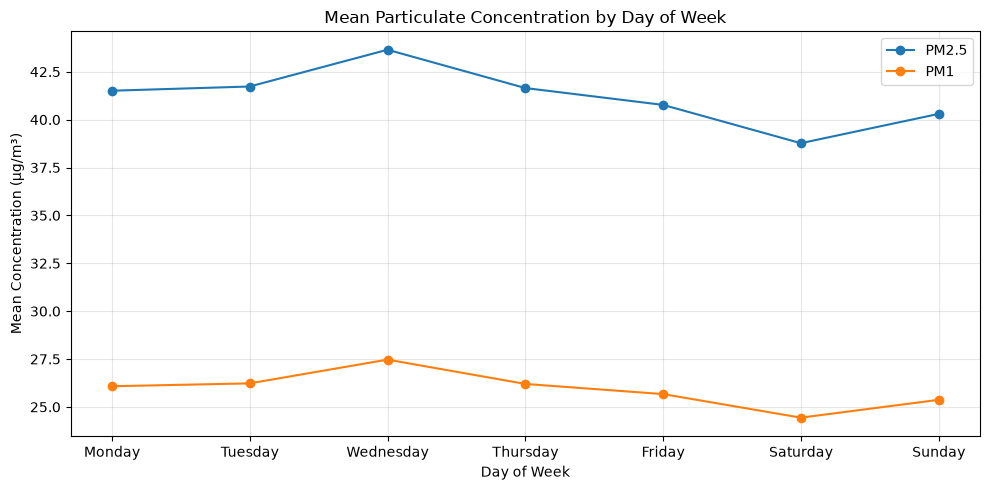

In [84]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    weekday_stats.index.astype(str),
    weekday_stats["PM25_Mean"],
    marker="o",
    label="PM2.5"
)

ax.plot(
    weekday_stats.index.astype(str),
    weekday_stats["PM1_Mean"],
    marker="o",
    label="PM1"
)

ax.set_title("Mean Particulate Concentration by Day of Week")
ax.set_xlabel("Day of Week")
ax.set_ylabel("Mean Concentration (µg/m³)")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

The day-of-week analysis shows relatively modest variation in particulate concentrations. Wednesday recorded the highest mean concentrations (PM2.5: 43.65 µg/m³; PM1: 27.47 µg/m³), whereas Saturday recorded the lowest (38.77 µg/m³ and 24.44 µg/m³, respectively). Friday and Saturday generally exhibited lower mean concentrations than the earlier weekdays. Median concentrations varied less substantially across the week, indicating that differences in mean values may partly reflect elevated observations. Valid observation counts were relatively balanced across days (1,551–1,583). These results indicate descriptive weekly variation but do not establish an association with specific human activities or emission sources.

In [85]:
weekly["Day_Type"] = weekly["datetime"].dt.dayofweek.map(
    lambda x: "Weekend" if x >= 5 else "Weekday"
)

weekday_weekend_stats = (
    weekly.groupby("Day_Type")
    .agg(
        Valid_Hours=("pm25", "count"),

        PM25_Mean=("pm25", "mean"),
        PM25_Median=("pm25", "median"),
        PM25_SD=("pm25", "std"),
        PM25_P95=("pm25", lambda x: x.quantile(0.95)),

        PM1_Mean=("pm1", "mean"),
        PM1_Median=("pm1", "median"),
        PM1_SD=("pm1", "std"),
        PM1_P95=("pm1", lambda x: x.quantile(0.95))
    )
    .round(2)
)

display(weekday_weekend_stats)

,Valid_Hours,PM25_Mean,PM25_Median,PM25_SD,PM25_P95,PM1_Mean,PM1_Median,PM1_SD,PM1_P95
Day_Type,,,,,,,,,
Weekday,7837,41.86,34.07,32.01,104.01,26.33,21.73,19.43,64.47
Weekend,3144,39.54,33.52,29.38,96.91,24.91,21.34,18.04,59.40


In [86]:
comparison = weekday_weekend_stats

for pollutant in ["PM25", "PM1"]:
    weekday_mean = comparison.loc["Weekday", f"{pollutant}_Mean"]
    weekend_mean = comparison.loc["Weekend", f"{pollutant}_Mean"]

    difference = weekend_mean - weekday_mean
    percentage = difference / weekday_mean * 100

    print(f"\n{pollutant}")
    print(f"Weekday mean: {weekday_mean:.2f} µg/m³")
    print(f"Weekend mean: {weekend_mean:.2f} µg/m³")
    print(f"Weekend - Weekday: {difference:.2f} µg/m³")
    print(f"Percentage difference: {percentage:.2f}%")


PM25
Weekday mean: 41.86 µg/m³
Weekend mean: 39.54 µg/m³
Weekend - Weekday: -2.32 µg/m³
Percentage difference: -5.54%

PM1
Weekday mean: 26.33 µg/m³
Weekend mean: 24.91 µg/m³
Weekend - Weekday: -1.42 µg/m³
Percentage difference: -5.39%


Focusing on Seasons

In [91]:
daily_analysis = hadigaun[["datetime", "pm25", "pm1"]].copy()

daily_analysis["datetime"] = pd.to_datetime(daily_analysis["datetime"])
daily_analysis = daily_analysis.sort_values("datetime").reset_index(drop=True)

daily_analysis["date"] = daily_analysis["datetime"].dt.date
daily_analysis["hour"] = daily_analysis["datetime"].dt.hour
daily_analysis["weekday"] = daily_analysis["datetime"].dt.day_name()
daily_analysis["weekday_num"] = daily_analysis["datetime"].dt.dayofweek
daily_analysis["month"] = daily_analysis["datetime"].dt.month

season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Pre-monsoon", 4: "Pre-monsoon", 5: "Pre-monsoon",
    6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
    10: "Post-monsoon", 11: "Post-monsoon"
}

season_order = ["Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"]

daily_analysis["season"] = daily_analysis["month"].map(season_map)

print("Date range:",
      daily_analysis["datetime"].min(),
      "to",
      daily_analysis["datetime"].max())

print("\nValid PM2.5 observations:", daily_analysis["pm25"].count())

print("\nContributing days by season:")
display(
    daily_analysis.groupby("season")
    .agg(
        Valid_Hours=("pm25", "count"),
        Contributing_Days=("date", "nunique")
    )
    .reindex(season_order)
)

Date range: 2025-07-01 00:45:00+05:45 to 2026-10-19 08:45:00+05:45

Valid PM2.5 observations: 10981

Contributing days by season:


,Valid_Hours,Contributing_Days
season,,
Winter,2140,90
Pre-monsoon,2129,92
Monsoon,4888,212
Post-monsoon,1824,79


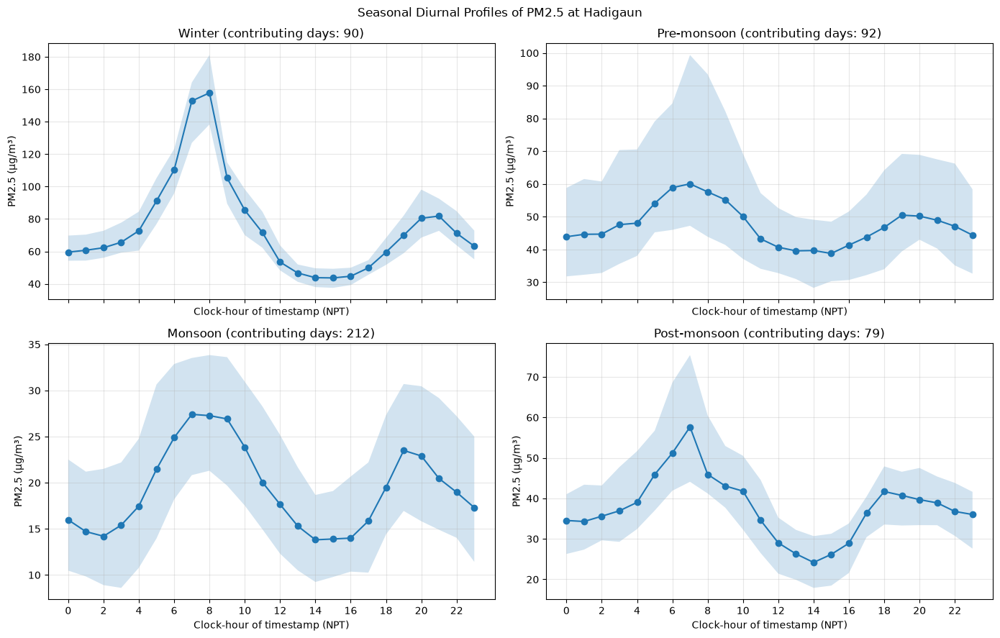

Seasonal hourly PM2.5 statistics:


season,Monsoon,Post-monsoon,Pre-monsoon,Winter
hour,,,,
0,15.97,34.55,43.90,59.57
1,14.70,34.30,44.65,60.72
2,14.20,35.60,44.70,62.27
3,15.40,36.93,47.60,65.66
4,17.47,39.02,48.05,72.73
5,21.46,45.91,54.10,91.11
6,24.89,51.20,58.90,110.30
7,27.41,57.65,60.05,152.82
8,27.27,45.93,57.60,157.77



Contributing days:


,Days
season,
Winter,90
Pre-monsoon,92
Monsoon,212
Post-monsoon,79


In [ ]:
seasonal_hourly = (
    daily_analysis.dropna(subset=["pm25"])
    .groupby(["season", "hour"])["pm25"]
    .agg(
        Valid_Observations="count",
        Median="median",
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75)
    )
    .reset_index()
)

seasonal_days = (
    daily_analysis.dropna(subset=["pm25"])
    .groupby("season")["date"]
    .nunique()
)

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)

for ax, season in zip(axes.flat, season_order):
    data = seasonal_hourly[
        seasonal_hourly["season"] == season
    ].sort_values("hour")

    ax.plot(data["hour"], data["Median"], marker="o")
    ax.fill_between(
        data["hour"],
        data["Q1"],
        data["Q3"],
        alpha=0.2
    )

    ax.set_title(
        f"{season} (contributing days: {seasonal_days.get(season, 0)})"
    )
    ax.set_xlabel("Clock-hour of timestamp (NPT)")
    ax.set_ylabel("PM2.5 (µg/m³)")
    ax.set_xticks(range(0, 24, 2))
    ax.grid(alpha=0.3)

plt.suptitle("Seasonal Diurnal Profiles of PM2.5 at Hadigaun")
plt.tight_layout()
plt.show()

print("Seasonal hourly PM2.5 statistics:")
display(
    seasonal_hourly.pivot(
        index="hour",
        columns="season",
        values="Median"
    ).round(2)
)

print("\nContributing days:")
display(seasonal_days.reindex(season_order).to_frame("Days"))

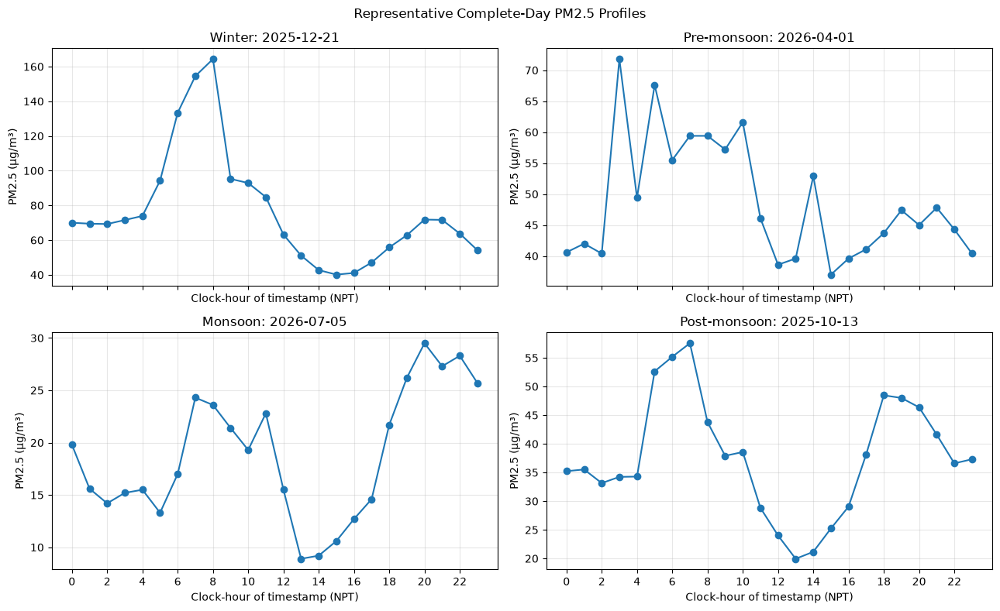

Representative-day statistics:


,season,date,PM25_Mean,PM25_Median,PM25_SD,PM25_Max
368,Monsoon,2026-07-05,18.841667,18.150000,6.174697,29.500000
104,Post-monsoon,2025-10-13,37.618322,36.952183,10.245553,57.549405
273,Pre-monsoon,2026-04-01,48.683333,45.550000,9.781734,71.800000
172,Winter,2025-12-21,76.619745,69.731176,32.938725,164.342261


In [100]:
representative_dates = (
    representative_days[
        representative_days["Selection"] == "Representative"
    ][["season", "date"]]
)

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)

for ax, season in zip(axes.flat, season_order):
    selected_date = representative_dates.loc[
        representative_dates["season"] == season, "date"
    ].iloc[0]

    day_data = daily_analysis[
        daily_analysis["date"] == selected_date
    ].sort_values("hour")

    ax.plot(day_data["hour"], day_data["pm25"], marker="o")

    ax.set_title(f"{season}: {selected_date}")
    ax.set_xlabel("Clock-hour of timestamp (NPT)")
    ax.set_ylabel("PM2.5 (µg/m³)")
    ax.set_xticks(range(0, 24, 2))
    ax.grid(alpha=0.3)

plt.suptitle("Representative Complete-Day PM2.5 Profiles")
plt.tight_layout()
plt.show()

print("Representative-day statistics:")
display(
    representative_days[
        representative_days["Selection"] == "Representative"
    ][
        ["season", "date", "PM25_Mean", "PM25_Median", "PM25_SD", "PM25_Max"]
    ].sort_values("season")
)

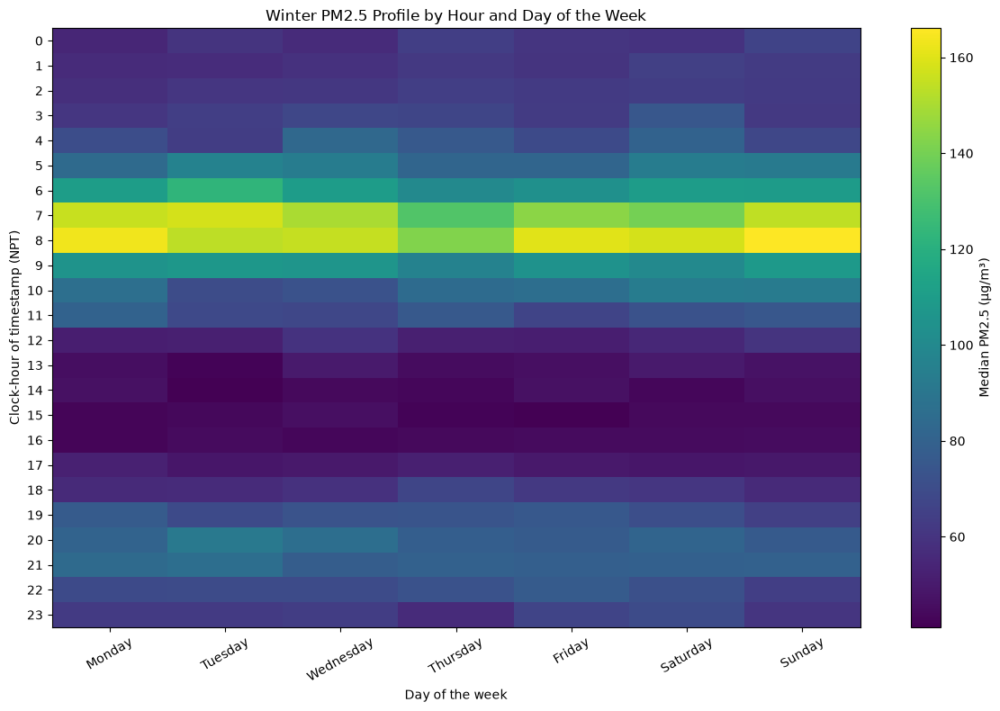

Winter hourly median PM2.5 by weekday:


weekday,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
hour,,,,,,,
0,54.74,60.08,56.42,64.24,60.46,59.57,66.28
1,56.53,57.15,58.76,62.05,60.04,64.90,62.70
2,58.19,60.74,61.15,64.22,62.22,63.78,62.23
3,60.75,64.38,67.78,67.38,62.85,74.91,61.91
4,70.55,63.92,83.20,75.99,69.25,80.49,67.64
5,84.31,96.72,93.74,82.08,81.65,93.48,92.10
6,110.47,123.03,110.13,99.97,103.86,110.13,109.57
7,155.40,157.93,150.46,131.99,144.60,140.19,154.24
8,163.63,153.79,155.27,142.60,160.68,157.87,166.10



Winter observations by weekday:


,Valid_Hours,Contributing_Days
weekday,,
Monday,307,13
Tuesday,310,13
Wednesday,308,13
Thursday,312,13
Friday,310,13
Saturday,309,13
Sunday,284,12


In [94]:
winter_data = daily_analysis[
    daily_analysis["season"] == "Winter"
].dropna(subset=["pm25"])

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

winter_heatmap = winter_data.pivot_table(
    index="hour",
    columns="weekday",
    values="pm25",
    aggfunc="median"
).reindex(columns=weekday_order)

plt.figure(figsize=(12, 8))

plt.imshow(
    winter_heatmap,
    aspect="auto",
    interpolation="nearest"
)

plt.colorbar(label="Median PM2.5 (µg/m³)")
plt.xticks(range(7), weekday_order, rotation=30)
plt.yticks(range(24), range(24))
plt.xlabel("Day of the week")
plt.ylabel("Clock-hour of timestamp (NPT)")
plt.title("Winter PM2.5 Profile by Hour and Day of the Week")

plt.tight_layout()
plt.show()

print("Winter hourly median PM2.5 by weekday:")
display(winter_heatmap.round(2))

print("\nWinter observations by weekday:")
display(
    winter_data.groupby("weekday")
    .agg(
        Valid_Hours=("pm25", "count"),
        Contributing_Days=("date", "nunique")
    )
    .reindex(weekday_order)
)

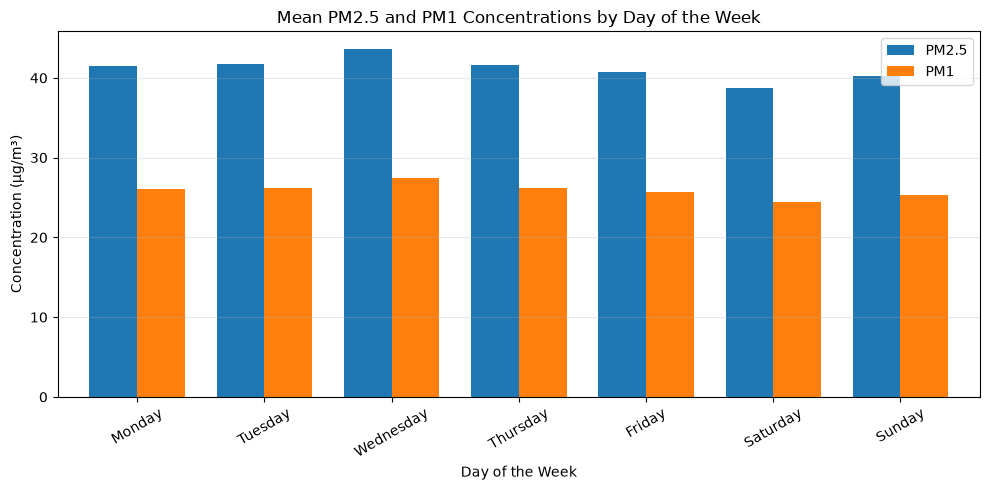

,Valid_Hours,PM25_Mean,PM1_Mean
weekday,,,
Monday,1569,41.51,26.08
Tuesday,1575,41.73,26.23
Wednesday,1551,43.65,27.47
Thursday,1583,41.65,26.20
Friday,1559,40.77,25.67
Saturday,1561,38.77,24.44
Sunday,1583,40.30,25.37


In [101]:
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_summary = (
    daily_analysis.groupby("weekday")
    .agg(
        Valid_Hours=("pm25", "count"),
        PM25_Mean=("pm25", "mean"),
        PM1_Mean=("pm1", "mean")
    )
    .reindex(weekday_order)
)

ax = weekday_summary[["PM25_Mean", "PM1_Mean"]].plot(
    kind="bar",
    figsize=(10, 5),
    width=0.75
)

ax.set_title("Mean PM2.5 and PM1 Concentrations by Day of the Week")
ax.set_xlabel("Day of the Week")
ax.set_ylabel("Concentration (µg/m³)")
ax.tick_params(axis="x", rotation=30)
ax.legend(["PM2.5", "PM1"])
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

display(weekday_summary.round(2))

In [95]:
daily_summary = (
    daily_analysis.groupby(["date", "season"])
    .agg(
        Valid_Hours=("pm25", "count"),
        PM25_Mean=("pm25", "mean"),
        PM25_Median=("pm25", "median"),
        PM25_SD=("pm25", "std"),
        PM25_Max=("pm25", "max"),
        PM1_Mean=("pm1", "mean")
    )
    .reset_index()
)

complete_days = daily_summary[
    daily_summary["Valid_Hours"] == 24
].copy()

representative_days = []

for season in season_order:
    season_days = complete_days[
        complete_days["season"] == season
    ].copy()

    if season_days.empty:
        print(f"No complete days available for {season}")
        continue

    seasonal_median = season_days["PM25_Mean"].median()

    season_days["Distance_From_Seasonal_Median"] = (
        season_days["PM25_Mean"] - seasonal_median
    ).abs()

    representative = season_days.loc[
        season_days["Distance_From_Seasonal_Median"].idxmin()
    ].copy()

    representative["Selection"] = "Representative"

    highest = season_days.loc[
        season_days["PM25_Mean"].idxmax()
    ].copy()
    highest["Selection"] = "Highest"

    lowest = season_days.loc[
        season_days["PM25_Mean"].idxmin()
    ].copy()
    lowest["Selection"] = "Lowest"

    representative_days.extend([representative, highest, lowest])

representative_days = pd.DataFrame(representative_days)

print("Complete days available by season:")
display(
    complete_days.groupby("season")
    .agg(
        Complete_Days=("date", "count"),
        Seasonal_Median_Daily_Mean=("PM25_Mean", "median")
    )
    .reindex(season_order)
    .round(2)
)

print("\nSelected days:")
display(
    representative_days[
        [
            "season", "Selection", "date", "Valid_Hours",
            "PM25_Mean", "PM25_Median", "PM25_SD", "PM25_Max"
        ]
    ].sort_values(["season", "Selection"])
    .round(2)
)

Complete days available by season:


,Complete_Days,Seasonal_Median_Daily_Mean
season,,
Winter,78,76.44
Pre-monsoon,74,49.10
Monsoon,178,18.85
Post-monsoon,60,37.52



Selected days:


,season,Selection,date,Valid_Hours,PM25_Mean,PM25_Median,PM25_SD,PM25_Max
338,Monsoon,Highest,2026-06-05,24,43.96,45.50,7.54,64.30
426,Monsoon,Lowest,2026-09-01,24,7.49,5.95,5.06,21.40
368,Monsoon,Representative,2026-07-05,24,18.84,18.15,6.17,29.50
146,Post-monsoon,Highest,2025-11-25,24,64.68,60.17,26.23,134.84
122,Post-monsoon,Lowest,2025-11-01,24,7.43,7.27,3.87,17.10
104,Post-monsoon,Representative,2025-10-13,24,37.62,36.95,10.25,57.55
295,Pre-monsoon,Highest,2026-04-23,24,152.33,154.10,14.89,178.10
308,Pre-monsoon,Lowest,2026-05-06,24,19.13,20.25,6.36,30.00
273,Pre-monsoon,Representative,2026-04-01,24,48.68,45.55,9.78,71.80
194,Winter,Highest,2026-01-12,24,113.40,92.11,70.99,392.19


Sunday was added as a weekend holiday in Nepal from 2026 April 5

In [97]:
# Official weekly holiday schedule
schedule_change = pd.Timestamp("2026-04-06").date()

daily_means = (
    daily_analysis.groupby(["date", "season"])
    .agg(
        Valid_Hours=("pm25", "count"),
        PM25_Mean=("pm25", "mean"),
        PM1_Mean=("pm1", "mean")
    )
    .reset_index()
)

daily_means = daily_means[
    daily_means["Valid_Hours"] >= 18
].copy()

daily_means["date"] = pd.to_datetime(daily_means["date"])

daily_means["weekday"] = daily_means["date"].dt.day_name()

daily_means["is_weekly_holiday"] = (
    (daily_means["weekday"] == "Saturday") |
    (
        (daily_means["weekday"] == "Sunday") &
        (daily_means["date"].dt.date >= schedule_change)
    )
)

daily_means["day_type"] = np.where(
    daily_means["is_weekly_holiday"],
    "Official weekly holiday",
    "Scheduled working day"
)

daily_means["week"] = daily_means["date"].dt.to_period("W-SUN")

print("Daily observations retained:", len(daily_means))

print("\nClassification counts:")
display(
    daily_means.groupby(["day_type", "season"])
    .agg(
        Valid_Days=("date", "count"),
        PM25_Mean=("PM25_Mean", "mean"),
        PM25_Median=("PM25_Mean", "median"),
        PM1_Mean=("PM1_Mean", "mean")
    )
    .round(2)
)

print("\nClassification by calendar period:")
display(
    daily_means.groupby([
        daily_means["date"].dt.to_period("M"),
        "day_type"
    ]).size().unstack(fill_value=0)
)

Daily observations retained: 458

Classification counts:


Valid_Days  PM25_Mean  PM25_Median  \
day_type                season                                             
Official weekly holiday Monsoon               45      19.74        18.12   
                        Post-monsoon          15      33.93        37.68   
                        Pre-monsoon           20      50.07        43.13   
                        Winter                13      76.21        75.24   
Scheduled working day   Monsoon              159      20.92        19.40   
                        Post-monsoon          60      39.39        39.36   
                        Pre-monsoon           69      55.17        49.82   
                        Winter                77      77.61        76.62   

                                      PM1_Mean  
day_type                season                  
Official weekly holiday Monsoon          12.85  
                        Post-monsoon     21.74  
                        Pre-monsoon      31.06  
                        Winter           47.26  
Scheduled working day   Monsoon          13.65  
                        Post-monsoon     25.08  
                        Pre-monsoon      33.74  
                        Winter           48.42


Classification by calendar period:


day_type,Official weekly holiday,Scheduled working day
date,,
2025-07,4,27
2025-08,5,25
2025-09,4,24
2025-10,4,24
2025-11,5,24
2025-12,4,27
2026-01,5,26
2026-02,4,24
2026-03,4,27


In [98]:
from scipy.stats import wilcoxon

weekly_paired = (
    daily_means.groupby(["season", "week", "day_type"])["PM25_Mean"]
    .mean()
    .unstack("day_type")
)

weekly_paired = weekly_paired.dropna(
    subset=["Official weekly holiday", "Scheduled working day"]
).copy()

weekly_paired["Difference"] = (
    weekly_paired["Official weekly holiday"] -
    weekly_paired["Scheduled working day"]
)

print("Paired weeks by season:")
display(
    weekly_paired.groupby("season")["Difference"]
    .agg(
        Paired_Weeks="count",
        Mean_Difference="mean",
        Median_Difference="median"
    )
    .reindex(season_order)
    .round(2)
)

# Bootstrap confidence intervals and Wilcoxon tests
rng = np.random.default_rng(42)
weekly_results = []

for season in season_order:

    if season not in weekly_paired.index.get_level_values("season"):
        continue

    differences = (
        weekly_paired.xs(season, level="season")["Difference"]
        .dropna()
        .to_numpy()
    )

    n = len(differences)

    if n < 5:
        continue

    bootstrap_means = np.array([
        rng.choice(differences, size=n, replace=True).mean()
        for _ in range(10000)
    ])

    ci_lower, ci_upper = np.percentile(
        bootstrap_means, [2.5, 97.5]
    )

    test = wilcoxon(
        differences,
        alternative="two-sided",
        zero_method="wilcox"
    )

    weekly_results.append({
        "Season": season,
        "Paired_Weeks": n,
        "Mean_Difference": differences.mean(),
        "Median_Difference": np.median(differences),
        "CI_95_Lower": ci_lower,
        "CI_95_Upper": ci_upper,
        "Wilcoxon_p": test.pvalue
    })

weekly_inference = pd.DataFrame(weekly_results).set_index("Season")

display(weekly_inference.round(4))

Paired weeks by season:


,Paired_Weeks,Mean_Difference,Median_Difference
season,,,
Winter,13,-1.37,-2.25
Pre-monsoon,13,-3.85,-3.63
Monsoon,29,-1.57,-1.03
Post-monsoon,12,-3.77,0.76


,Paired_Weeks,Mean_Difference,Median_Difference,CI_95_Lower,CI_95_Upper,Wilcoxon_p
Season,,,,,,
Winter,13,-1.3686,-2.2476,-8.1378,5.1056,0.8394
Pre-monsoon,13,-3.8511,-3.6321,-12.7931,4.5672,0.3757
Monsoon,29,-1.5703,-1.0295,-3.4427,0.2975,0.1622
Post-monsoon,12,-3.7718,0.7589,-10.3862,1.6501,0.5186


Some Additional Statistics

In [21]:
# ============================================================
# SECTION 4.6 — CELL 1
# Overall hourly and day-of-week descriptive statistics
# ============================================================

import pandas as pd
import numpy as np

# Work from the existing master dataset
df_46 = master.copy()

# Identify the timestamp column
print("Dataset shape:", df_46.shape)
print("Columns:", df_46.columns.tolist())

# Ensure datetime is available
df_46["datetime"] = pd.to_datetime(df_46["datetime"])

# Identify the required pollutant columns
pollutants_46 = ["pm25", "pm1"]

missing_columns = [
    col for col in ["datetime"] + pollutants_46
    if col not in df_46.columns
]

if missing_columns:
    raise KeyError(f"Missing required columns: {missing_columns}")

# Extract time-related variables
df_46["Hour"] = df_46["datetime"].dt.hour
df_46["Day_Name"] = df_46["datetime"].dt.day_name()

weekday_order_46 = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

# ------------------------------------------------------------
# A. Overall hourly statistics
# ------------------------------------------------------------

hourly_summary_46 = (
    df_46.groupby("Hour")[pollutants_46]
    .agg(["count", "mean", "median", "std",
          lambda x: x.quantile(0.95)])
)

hourly_summary_46.columns = [
    f"{pollutant}_{stat if stat != '<lambda_0>' else 'P95'}"
    for pollutant, stat in hourly_summary_46.columns
]

hourly_summary_46 = hourly_summary_46.round(2)

print("\n" + "=" * 75)
print("OVERALL HOURLY POLLUTANT STATISTICS")
print("=" * 75)
print(hourly_summary_46.to_string())

# Peak and minimum hourly means
for pollutant in pollutants_46:
    mean_column = f"{pollutant}_mean"

    peak_hour = hourly_summary_46[mean_column].idxmax()
    minimum_hour = hourly_summary_46[mean_column].idxmin()

    print(f"\n{pollutant.upper()}")
    print(
        f"Maximum hourly mean: "
        f"{hourly_summary_46.loc[peak_hour, mean_column]:.2f} "
        f"at {peak_hour:02d}:00"
    )
    print(
        f"Minimum hourly mean: "
        f"{hourly_summary_46.loc[minimum_hour, mean_column]:.2f} "
        f"at {minimum_hour:02d}:00"
    )

# ------------------------------------------------------------
# B. Day-of-week statistics
# ------------------------------------------------------------

weekday_summary_46 = (
    df_46.groupby("Day_Name")[pollutants_46]
    .agg(["count", "mean", "median", "std",
          lambda x: x.quantile(0.95)])
)

weekday_summary_46.columns = [
    f"{pollutant}_{stat if stat != '<lambda_0>' else 'P95'}"
    for pollutant, stat in weekday_summary_46.columns
]

weekday_summary_46 = (
    weekday_summary_46
    .reindex(weekday_order_46)
    .round(2)
)

print("\n" + "=" * 75)
print("DAY-OF-WEEK POLLUTANT STATISTICS")
print("=" * 75)
print(weekday_summary_46.to_string())

# Highest and lowest weekday means
for pollutant in pollutants_46:
    mean_column = f"{pollutant}_mean"

    highest_day = weekday_summary_46[mean_column].idxmax()
    lowest_day = weekday_summary_46[mean_column].idxmin()

    print(f"\n{pollutant.upper()}")
    print(
        f"Highest weekday mean: {highest_day} "
        f"({weekday_summary_46.loc[highest_day, mean_column]:.2f})"
    )
    print(
        f"Lowest weekday mean: {lowest_day} "
        f"({weekday_summary_46.loc[lowest_day, mean_column]:.2f})"
    )

Dataset shape: (10981, 26)
Columns: ['datetime', 'pm25', 'pm1', 'temperature', 'relative_humidity', 'particle_count_03um', 'temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'precipitation', 'rain', 'wind_speed_10m', 'wind_direction_10m', 'wind_gusts_10m', 'surface_pressure', 'pressure_msl', 'cloud_cover', 'cloud_cover_low', 'cloud_cover_mid', 'cloud_cover_high', 'boundary_layer_height', 'shortwave_radiation', 'direct_radiation', 'diffuse_radiation', 'terrestrial_radiation', 'sunshine_duration']

OVERALL HOURLY POLLUTANT STATISTICS
      pm25_count  pm25_mean  pm25_median  pm25_std  pm25_P95  pm1_count  pm1_mean  pm1_median  pm1_std  pm1_P95
Hour                                                                                                           
0            462      35.45        32.27     23.96     77.18        462     22.16       20.28    14.39    46.97
1            465      35.24        32.20     24.23     78.10        465     21.95       20.50    14.53    46.16
2      

WINTER HOURLY MEDIAN PM2.5 BY WEEKDAY (µg/m³)
Day_Name  Monday  Tuesday  Wednesday  Thursday  Friday  Saturday  Sunday
Hour                                                                    
0          54.74    60.08      56.42     64.24   60.46     59.57   66.28
1          56.53    57.15      58.76     62.05   60.04     64.90   62.70
2          58.19    60.74      61.15     64.22   62.22     63.78   62.23
3          60.75    64.38      67.78     67.38   62.85     74.91   61.91
4          70.55    63.92      83.20     75.99   69.25     80.49   67.64
5          84.31    96.72      93.74     82.08   81.65     93.48   92.10
6         110.47   123.03     110.13     99.97  103.86    110.13  109.57
7         155.40   157.93     150.46    131.99  144.60    140.19  154.24
8         163.63   153.79     155.27    142.60  160.68    157.87  166.10
9         105.35   107.30     106.46     96.40  104.87     99.78  108.34
10         86.85    70.26      72.48     84.75   86.33     93.39   93.22
11   

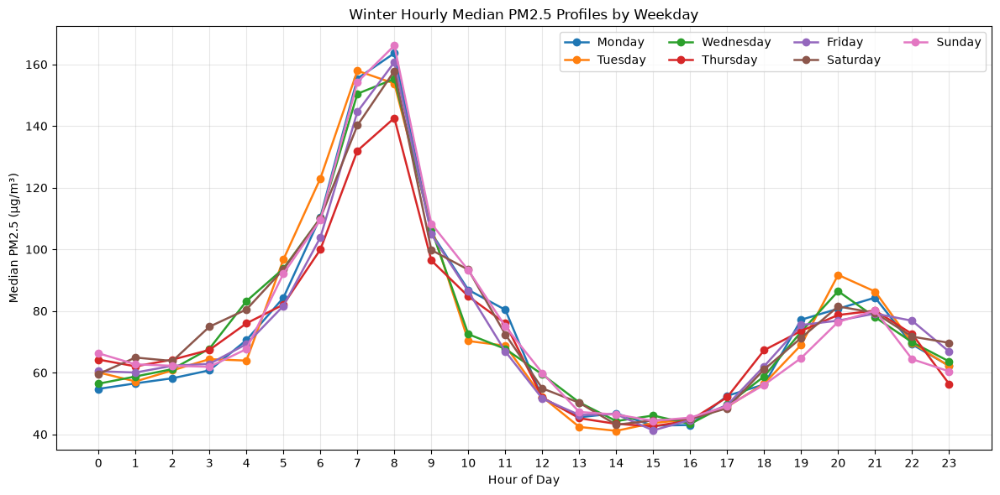

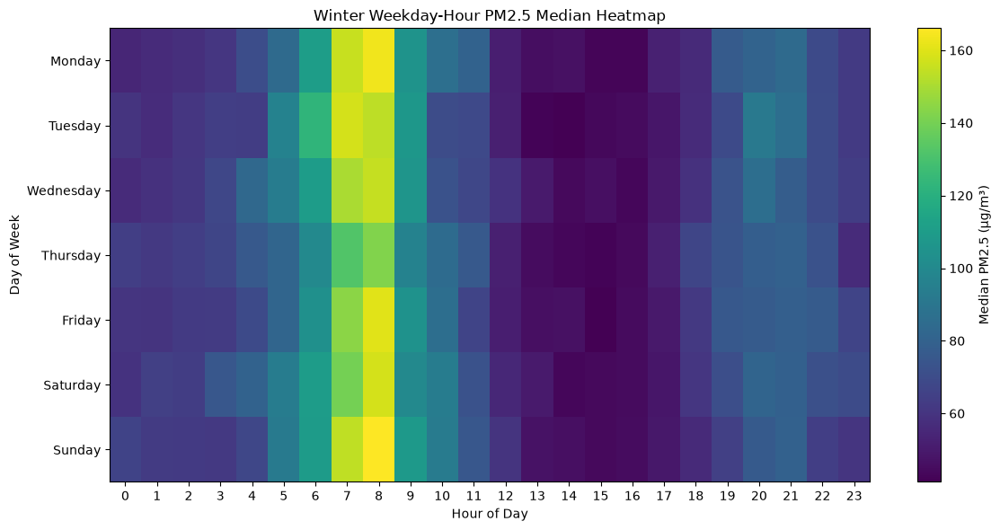

In [22]:
# ============================================================
# SECTION 4.6 — CELL 2
# Winter weekday-hour profiles and heatmap
# ============================================================

# Use the existing master dataset
winter_46 = df_46[
    df_46["datetime"].dt.month.isin([12, 1, 2])
].copy()

winter_46["Day_Name"] = winter_46["datetime"].dt.day_name()
winter_46["Hour"] = winter_46["datetime"].dt.hour

weekday_order_46 = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

# ------------------------------------------------------------
# A. Calculate winter hourly median PM2.5 by weekday
# ------------------------------------------------------------

winter_weekday_median_46 = winter_46.pivot_table(
    index="Hour",
    columns="Day_Name",
    values="pm25",
    aggfunc="median"
).reindex(columns=weekday_order_46)

winter_weekday_count_46 = winter_46.pivot_table(
    index="Hour",
    columns="Day_Name",
    values="pm25",
    aggfunc="count"
).reindex(columns=weekday_order_46)

print("=" * 80)
print("WINTER HOURLY MEDIAN PM2.5 BY WEEKDAY (µg/m³)")
print("=" * 80)
print(winter_weekday_median_46.round(2).to_string())

print("\n" + "=" * 80)
print("WINTER HOURLY VALID OBSERVATION COUNTS BY WEEKDAY")
print("=" * 80)
print(winter_weekday_count_46.fillna(0).astype(int).to_string())

# ------------------------------------------------------------
# B. Print each weekday's maximum and minimum hourly median
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("WINTER WEEKDAY PROFILE EXTREMES")
print("=" * 80)

for day in weekday_order_46:

    profile = winter_weekday_median_46[day].dropna()

    if profile.empty:
        print(f"\n{day}: No valid observations")
        continue

    max_hour = profile.idxmax()
    min_hour = profile.idxmin()

    print(
        f"\n{day}: "
        f"Maximum = {profile[max_hour]:.2f} at {max_hour:02d}:00; "
        f"Minimum = {profile[min_hour]:.2f} at {min_hour:02d}:00"
    )

# ------------------------------------------------------------
# C. Figure 4.6.4 — Winter weekday hourly median profiles
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

for day in weekday_order_46:
    plt.plot(
        winter_weekday_median_46.index,
        winter_weekday_median_46[day],
        marker="o",
        linewidth=1.8,
        label=day
    )

plt.title("Winter Hourly Median PM2.5 Profiles by Weekday")
plt.xlabel("Hour of Day")
plt.ylabel("Median PM2.5 (µg/m³)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.legend(ncol=4)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# D. Figure 4.6.5 — Winter weekday-hour heatmap
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

heatmap_data_46 = winter_weekday_median_46.T

im = plt.imshow(
    heatmap_data_46,
    aspect="auto",
    interpolation="nearest"
)

plt.colorbar(im, label="Median PM2.5 (µg/m³)")
plt.xticks(range(24), range(24))
plt.yticks(range(len(weekday_order_46)), weekday_order_46)

plt.title("Winter Weekday-Hour PM2.5 Median Heatmap")
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")

plt.tight_layout()
plt.show()

SEASONAL HOURLY PM2.5 STATISTICS

WINTER
      Count    Mean  Median     Q25     Q75
Hour                                       
0        89   63.49   59.57   54.27   69.77
1        90   63.83   60.72   54.35   70.37
2        90   64.77   62.27   56.09   72.75
3        90   69.52   65.66   59.24   77.76
4        90   75.72   72.73   60.50   84.54
5        90   90.72   91.11   76.88  105.21
6        90  108.98  110.30   95.77  123.17
7        90  147.96  152.82  126.96  164.20
8        89  157.64  157.77  138.32  181.12
9        89  105.07  105.27   89.50  114.90
10       88   86.90   85.42   70.05   98.35
11       90   75.60   71.63   62.27   84.51
12       89   56.97   53.45   48.31   63.70
13       89   51.19   46.69   41.25   51.95
14       84   46.02   43.81   38.00   49.61
15       89   43.88   43.66   37.54   49.30
16       86   44.73   44.70   39.27   49.96
17       89   49.91   49.88   45.59   54.60
18       90   62.75   59.54   51.70   68.31
19       90   75.11   69.98   58.89

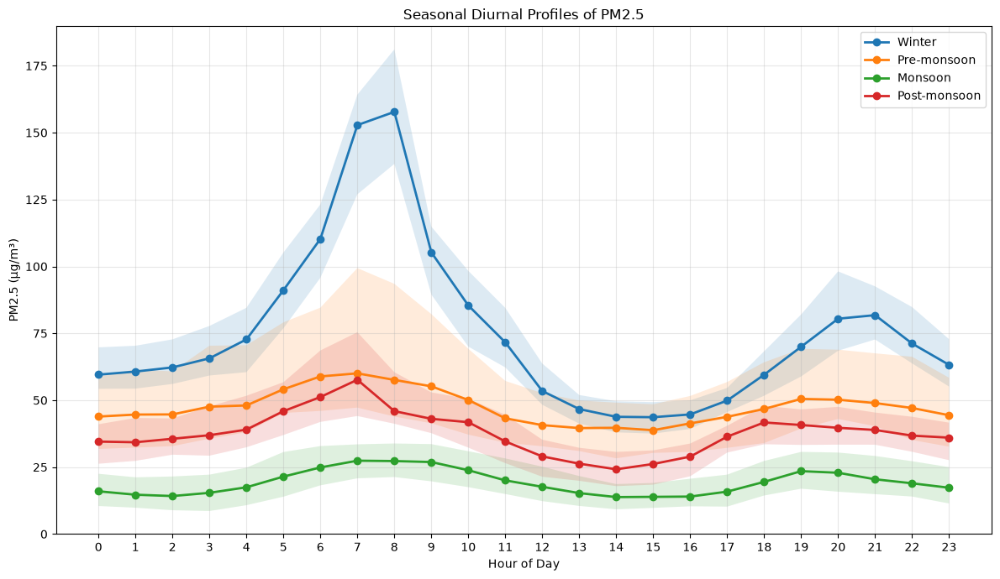

In [23]:
# ============================================================
# SECTION 4.6 — CELL 3
# Seasonal diurnal variation
# ============================================================

# Define seasons consistently with Section 4.5
season_months_46 = {
    "Winter": [12, 1, 2],
    "Pre-monsoon": [3, 4, 5],
    "Monsoon": [6, 7, 8, 9],
    "Post-monsoon": [10, 11]
}

df_46["Month"] = df_46["datetime"].dt.month

df_46["Season"] = pd.NA

for season, months in season_months_46.items():
    df_46.loc[
        df_46["Month"].isin(months), "Season"
    ] = season

season_order_46 = [
    "Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"
]

# ------------------------------------------------------------
# A. Calculate seasonal hourly statistics
# ------------------------------------------------------------

seasonal_hourly_records_46 = []

for season in season_order_46:

    season_data = df_46[df_46["Season"] == season]

    for hour in range(24):

        hour_data = season_data.loc[
            season_data["Hour"] == hour, ["pm25", "pm1"]
        ]

        for pollutant in ["pm25", "pm1"]:

            values = hour_data[pollutant].dropna()

            seasonal_hourly_records_46.append({
                "Season": season,
                "Hour": hour,
                "Pollutant": pollutant,
                "Count": values.count(),
                "Mean": values.mean(),
                "Median": values.median(),
                "Q25": values.quantile(0.25),
                "Q75": values.quantile(0.75)
            })

seasonal_hourly_46 = pd.DataFrame(
    seasonal_hourly_records_46
)

seasonal_hourly_46[
    ["Mean", "Median", "Q25", "Q75"]
] = seasonal_hourly_46[
    ["Mean", "Median", "Q25", "Q75"]
].round(2)

# ------------------------------------------------------------
# B. Print complete PM2.5 seasonal profiles
# ------------------------------------------------------------

print("=" * 90)
print("SEASONAL HOURLY PM2.5 STATISTICS")
print("=" * 90)

for season in season_order_46:

    result = seasonal_hourly_46[
        (seasonal_hourly_46["Season"] == season) &
        (seasonal_hourly_46["Pollutant"] == "pm25")
    ].set_index("Hour")

    print(f"\n{season.upper()}")
    print(
        result[
            ["Count", "Mean", "Median", "Q25", "Q75"]
        ].to_string()
    )

    median_profile = result["Median"].dropna()

    if not median_profile.empty:

        max_hour = median_profile.idxmax()
        min_hour = median_profile.idxmin()

        print(
            f"Maximum hourly median: "
            f"{median_profile[max_hour]:.2f} at {max_hour:02d}:00"
        )

        print(
            f"Minimum hourly median: "
            f"{median_profile[min_hour]:.2f} at {min_hour:02d}:00"
        )

# ------------------------------------------------------------
# C. Print complete PM1 seasonal profiles
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("SEASONAL HOURLY PM1 STATISTICS")
print("=" * 90)

for season in season_order_46:

    result = seasonal_hourly_46[
        (seasonal_hourly_46["Season"] == season) &
        (seasonal_hourly_46["Pollutant"] == "pm1")
    ].set_index("Hour")

    print(f"\n{season.upper()}")
    print(
        result[
            ["Count", "Mean", "Median", "Q25", "Q75"]
        ].to_string()
    )

    median_profile = result["Median"].dropna()

    if not median_profile.empty:

        max_hour = median_profile.idxmax()
        min_hour = median_profile.idxmin()

        print(
            f"Maximum hourly median: "
            f"{median_profile[max_hour]:.2f} at {max_hour:02d}:00"
        )

        print(
            f"Minimum hourly median: "
            f"{median_profile[min_hour]:.2f} at {min_hour:02d}:00"
        )

# ------------------------------------------------------------
# D. Figure 4.6.6 — Seasonal PM2.5 median profiles with IQR
# ------------------------------------------------------------

plt.figure(figsize=(12, 7))

for season in season_order_46:

    result = seasonal_hourly_46[
        (seasonal_hourly_46["Season"] == season) &
        (seasonal_hourly_46["Pollutant"] == "pm25")
    ].set_index("Hour").reindex(range(24))

    hours = result.index
    median = result["Median"].to_numpy(dtype=float)
    q25 = result["Q25"].to_numpy(dtype=float)
    q75 = result["Q75"].to_numpy(dtype=float)

    plt.plot(
        hours,
        median,
        marker="o",
        linewidth=2,
        label=season
    )

    plt.fill_between(
        hours,
        q25,
        q75,
        alpha=0.15
    )

plt.title("Seasonal Diurnal Profiles of PM2.5")
plt.xlabel("Hour of Day")
plt.ylabel("PM2.5 (µg/m³)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

COMPLETE-DAY AVAILABILITY
Total calendar days: 473
Complete days with 24 valid hourly observations: 390

Complete days by season:
Season
Winter           78
Pre-monsoon      74
Monsoon         178
Post-monsoon     60

REPRESENTATIVE DAY SELECTION

Winter
Number of complete days: 78
Median of complete-day means: 76.44
Selected date: 2025-12-21
Daily mean PM2.5: 76.62
Daily median PM2.5: 69.73
Daily SD PM2.5: 32.94
Daily P95 PM2.5: 151.35
Valid observations: 24
Distinct hours: 24

Pre-monsoon
Number of complete days: 74
Median of complete-day means: 49.10
Selected date: 2026-04-01
Daily mean PM2.5: 48.68
Daily median PM2.5: 45.55
Daily SD PM2.5: 9.78
Daily P95 PM2.5: 66.70
Valid observations: 24
Distinct hours: 24

Monsoon
Number of complete days: 178
Median of complete-day means: 18.85
Selected date: 2026-07-05
Daily mean PM2.5: 18.84
Daily median PM2.5: 18.15
Daily SD PM2.5: 6.17
Daily P95 PM2.5: 28.15
Valid observations: 24
Distinct hours: 24

Post-monsoon
Number of complete days: 60


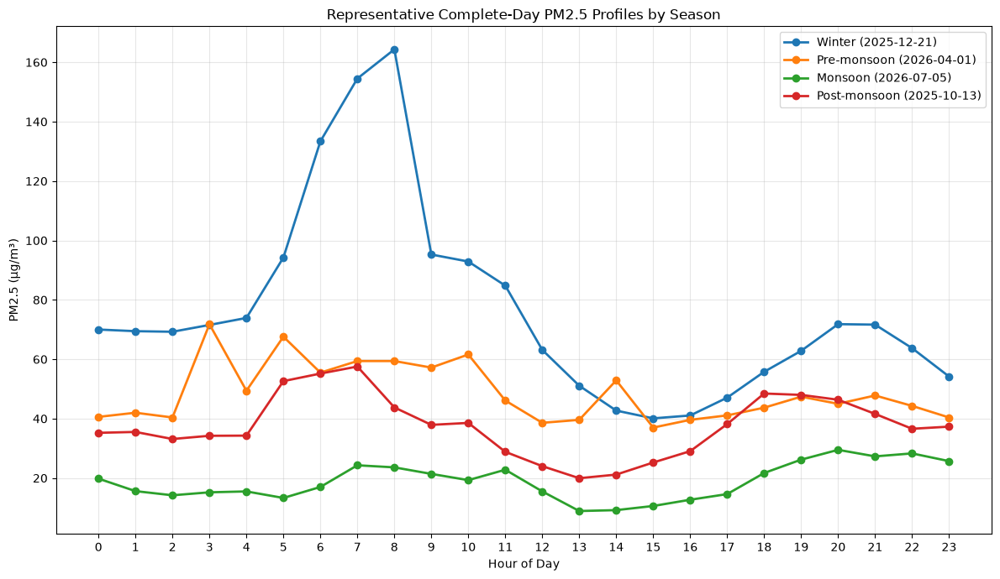

In [24]:
# ============================================================
# SECTION 4.6 — CELL 4
# Representative complete-day PM2.5 profiles
# ============================================================

# Create a date-level grouping variable
df_46["Date"] = df_46["datetime"].dt.date

# ------------------------------------------------------------
# A. Identify complete days
# ------------------------------------------------------------

daily_records_46 = []

for date, group in df_46.groupby("Date"):

    valid = group.dropna(subset=["pm25"])

    daily_records_46.append({
        "Date": date,
        "Season": group["Season"].iloc[0],
        "Valid_Count": valid["pm25"].count(),
        "Unique_Hours": valid["Hour"].nunique(),
        "Daily_Mean_PM25": valid["pm25"].mean(),
        "Daily_Median_PM25": valid["pm25"].median(),
        "Daily_SD_PM25": valid["pm25"].std(),
        "Daily_P95_PM25": valid["pm25"].quantile(0.95)
    })

daily_summary_46 = pd.DataFrame(daily_records_46)

complete_days_46 = daily_summary_46[
    (daily_summary_46["Valid_Count"] == 24) &
    (daily_summary_46["Unique_Hours"] == 24)
].copy()

print("=" * 85)
print("COMPLETE-DAY AVAILABILITY")
print("=" * 85)

print("Total calendar days:", len(daily_summary_46))
print("Complete days with 24 valid hourly observations:", len(complete_days_46))

print("\nComplete days by season:")
print(
    complete_days_46["Season"]
    .value_counts()
    .reindex(season_order_46)
    .fillna(0)
    .astype(int)
    .to_string()
)

# ------------------------------------------------------------
# B. Select representative days
# ------------------------------------------------------------

representative_days_46 = {}

print("\n" + "=" * 85)
print("REPRESENTATIVE DAY SELECTION")
print("=" * 85)

for season in season_order_46:

    seasonal_days = complete_days_46[
        complete_days_46["Season"] == season
    ].copy()

    if seasonal_days.empty:
        print(f"\n{season}: No complete days available")
        continue

    seasonal_median_mean = seasonal_days[
        "Daily_Mean_PM25"
    ].median()

    seasonal_days["Distance_From_Seasonal_Median"] = (
        seasonal_days["Daily_Mean_PM25"] - seasonal_median_mean
    ).abs()

    selected = seasonal_days.sort_values(
        "Distance_From_Seasonal_Median"
    ).iloc[0]

    selected_date = selected["Date"]

    representative_days_46[season] = selected_date

    print(f"\n{season}")
    print("Number of complete days:", len(seasonal_days))
    print(f"Median of complete-day means: {seasonal_median_mean:.2f}")
    print("Selected date:", selected_date)
    print(f"Daily mean PM2.5: {selected['Daily_Mean_PM25']:.2f}")
    print(f"Daily median PM2.5: {selected['Daily_Median_PM25']:.2f}")
    print(f"Daily SD PM2.5: {selected['Daily_SD_PM25']:.2f}")
    print(f"Daily P95 PM2.5: {selected['Daily_P95_PM25']:.2f}")
    print("Valid observations:", int(selected["Valid_Count"]))
    print("Distinct hours:", int(selected["Unique_Hours"]))

# ------------------------------------------------------------
# C. Print all 24 hourly values for selected days
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("HOURLY PM2.5 VALUES FOR REPRESENTATIVE DAYS")
print("=" * 85)

representative_profiles_46 = {}

for season, selected_date in representative_days_46.items():

    selected_data = df_46[
        df_46["Date"] == selected_date
    ].dropna(subset=["pm25"]).copy()

    profile = (
        selected_data.groupby("Hour")["pm25"]
        .mean()
        .reindex(range(24))
    )

    representative_profiles_46[season] = profile

    print(f"\n{season} — {selected_date}")
    print(profile.round(2).to_string())

    print("Number of hourly values:", profile.count())

    if profile.count() != 24:
        print("WARNING: Selected profile does not contain 24 valid hourly values.")

# ------------------------------------------------------------
# D. Figure 4.6.7 — Representative complete-day profiles
# ------------------------------------------------------------

plt.figure(figsize=(12, 7))

for season in season_order_46:

    if season not in representative_profiles_46:
        continue

    profile = representative_profiles_46[season]

    plt.plot(
        profile.index,
        profile.values,
        marker="o",
        linewidth=2,
        label=f"{season} ({representative_days_46[season]})"
    )

plt.title("Representative Complete-Day PM2.5 Profiles by Season")
plt.xlabel("Hour of Day")
plt.ylabel("PM2.5 (µg/m³)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

HOURLY VALUES USED IN FIGURES 4.6.1 AND 4.6.2
      pm25_mean  pm25_median  pm25_count  pm1_mean  pm1_median  pm1_count
Hour                                                                     
0         35.45        32.27         462     22.16       20.28        462
1         35.24        32.20         465     21.95       20.50        465
2         35.39        33.04         462     21.99       20.60        462
3         38.05        34.29         457     23.70       21.50        457
4         40.96        36.03         454     25.72       22.84        454
5         47.92        40.70         457     30.18       25.80        457
6         55.02        44.10         459     34.96       28.10        459
7         65.77        44.49         458     41.82       28.35        458
8         65.10        41.80         461     41.15       26.50        461
9         52.37        39.75         456     33.02       25.25        456
10        45.42        36.60         455     28.48       23.40    

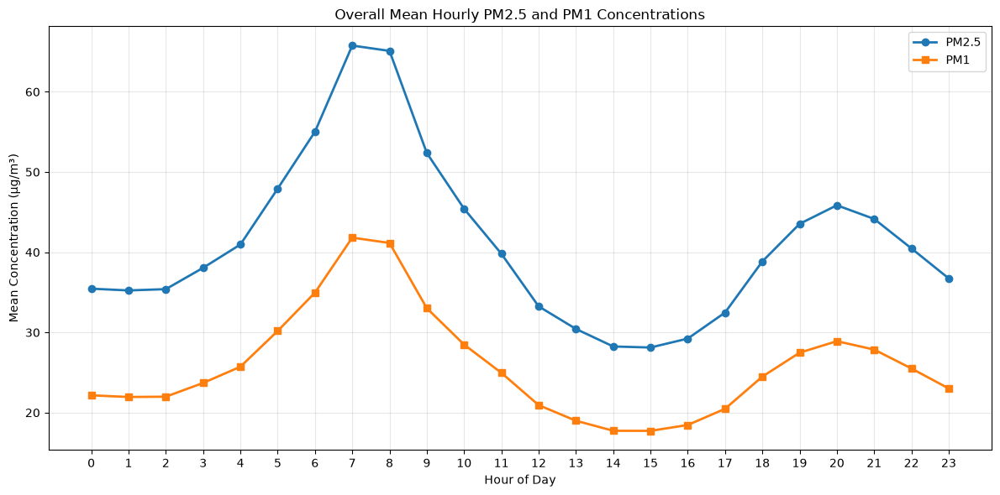

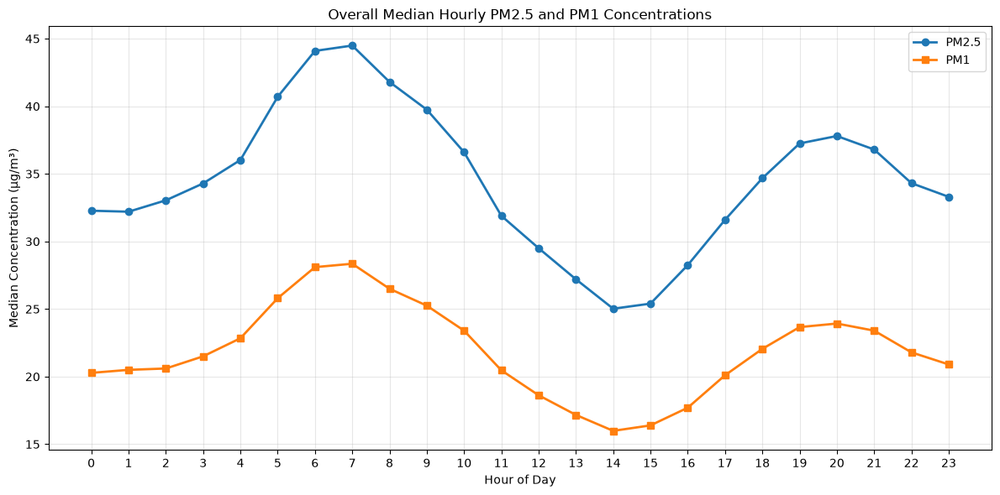


WEEKDAY MEAN CONCENTRATIONS USED IN FIGURE 4.6.3
            pm25    pm1
Day_Name               
Monday     41.51  26.08
Tuesday    41.73  26.23
Wednesday  43.65  27.47
Thursday   41.65  26.20
Friday     40.77  25.67
Saturday   38.77  24.44
Sunday     40.30  25.37


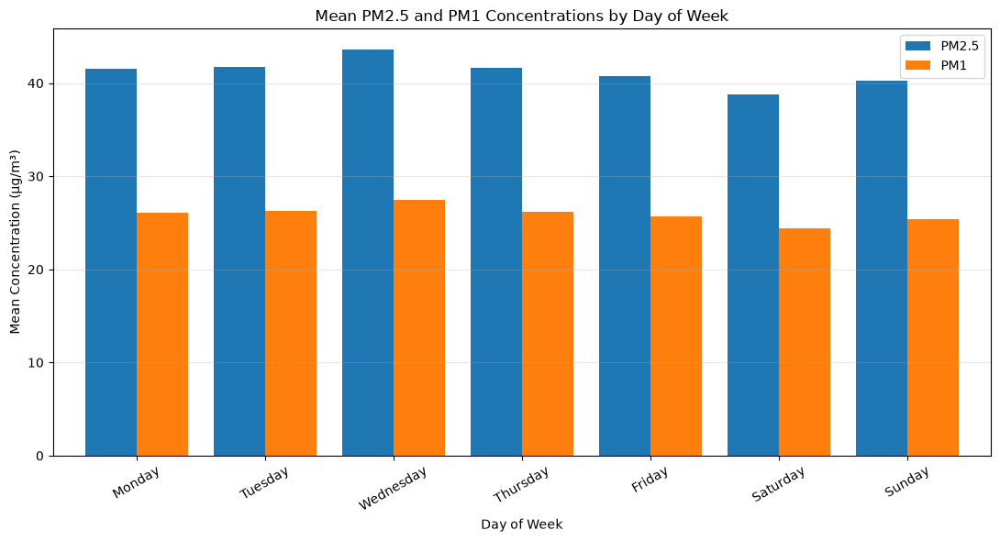


REPRESENTATIVE COMPLETE-DAY HOURLY PM2.5 VALUES

Winter — 2025-12-21
Hour
0      70.01
1      69.46
2      69.26
3      71.56
4      73.91
5      94.26
6     133.38
7     154.52
8     164.34
9      95.27
10     92.91
11     84.79
12     63.16
13     51.08
14     42.72
15     40.10
16     41.07
17     47.07
18     55.78
19     62.84
20     71.82
21     71.66
22     63.74
23     54.18
Valid observations: 24; Distinct hours: 24; Daily mean: 76.62; Daily median: 69.73; Daily SD: 32.94; Daily P95: 151.35

Pre-monsoon — 2026-04-01
Hour
0     40.6
1     42.0
2     40.4
3     71.8
4     49.4
5     67.6
6     55.5
7     59.4
8     59.4
9     57.2
10    61.6
11    46.1
12    38.6
13    39.6
14    52.9
15    37.0
16    39.6
17    41.1
18    43.7
19    47.4
20    45.0
21    47.8
22    44.3
23    40.4
Valid observations: 24; Distinct hours: 24; Daily mean: 48.68; Daily median: 45.55; Daily SD: 9.78; Daily P95: 66.70

Monsoon — 2026-07-05
Hour
0     19.8
1     15.6
2     14.2
3     15.2
4     15.5


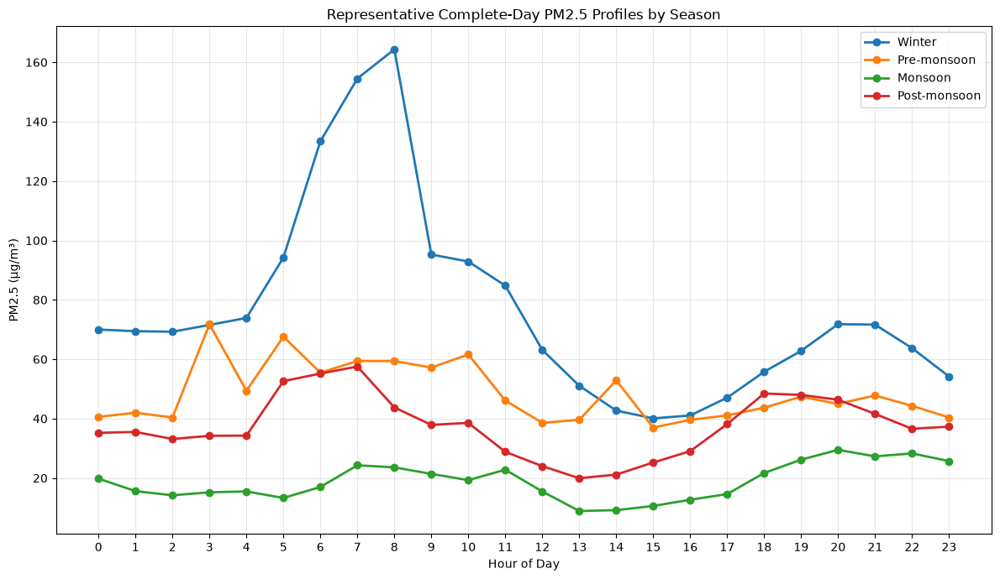

In [25]:
# ============================================================
# SECTION 4.6 — CELL 5
# Remaining figures and final numerical checks
# ============================================================

# ------------------------------------------------------------
# A. Recalculate overall hourly profiles for plotting
# ------------------------------------------------------------

hourly_plot_46 = (
    df_46.groupby("Hour")[["pm25", "pm1"]]
    .agg(["mean", "median", "count"])
)

hourly_plot_46.columns = [
    f"{pollutant}_{stat}"
    for pollutant, stat in hourly_plot_46.columns
]

hourly_plot_46 = hourly_plot_46.reindex(range(24))

print("=" * 85)
print("HOURLY VALUES USED IN FIGURES 4.6.1 AND 4.6.2")
print("=" * 85)
print(hourly_plot_46.round(2).to_string())

# ------------------------------------------------------------
# B. Figure 4.6.1 — Overall mean hourly profiles
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

plt.plot(
    hourly_plot_46.index,
    hourly_plot_46["pm25_mean"],
    marker="o",
    linewidth=2,
    label="PM2.5"
)

plt.plot(
    hourly_plot_46.index,
    hourly_plot_46["pm1_mean"],
    marker="s",
    linewidth=2,
    label="PM1"
)

plt.title("Overall Mean Hourly PM2.5 and PM1 Concentrations")
plt.xlabel("Hour of Day")
plt.ylabel("Mean Concentration (µg/m³)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# C. Figure 4.6.2 — Overall median hourly profiles
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

plt.plot(
    hourly_plot_46.index,
    hourly_plot_46["pm25_median"],
    marker="o",
    linewidth=2,
    label="PM2.5"
)

plt.plot(
    hourly_plot_46.index,
    hourly_plot_46["pm1_median"],
    marker="s",
    linewidth=2,
    label="PM1"
)

plt.title("Overall Median Hourly PM2.5 and PM1 Concentrations")
plt.xlabel("Hour of Day")
plt.ylabel("Median Concentration (µg/m³)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# D. Figure 4.6.3 — Mean concentrations by weekday
# ------------------------------------------------------------

weekday_plot_46 = (
    df_46.groupby("Day_Name")[["pm25", "pm1"]]
    .mean()
    .reindex(weekday_order_46)
)

print("\n" + "=" * 85)
print("WEEKDAY MEAN CONCENTRATIONS USED IN FIGURE 4.6.3")
print("=" * 85)
print(weekday_plot_46.round(2).to_string())

weekday_plot_46.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

plt.title("Mean PM2.5 and PM1 Concentrations by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Mean Concentration (µg/m³)")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.legend(["PM2.5", "PM1"])
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# E. Figure 4.6.7 — Representative complete-day profiles
# ------------------------------------------------------------

representative_dates_46 = {
    "Winter": "2025-12-21",
    "Pre-monsoon": "2026-04-01",
    "Monsoon": "2026-07-05",
    "Post-monsoon": "2025-10-13"
}

representative_profiles_46 = {}

print("\n" + "=" * 85)
print("REPRESENTATIVE COMPLETE-DAY HOURLY PM2.5 VALUES")
print("=" * 85)

for season in season_order_46:

    selected_date = pd.Timestamp(
        representative_dates_46[season]
    ).date()

    day_data = df_46[
        df_46["datetime"].dt.date == selected_date
    ].copy()

    profile = (
        day_data.groupby("Hour")["pm25"]
        .agg(["count", "mean"])
        .reindex(range(24))
    )

    valid_values = day_data["pm25"].dropna()
    distinct_hours = day_data.loc[
        day_data["pm25"].notna(), "Hour"
    ].nunique()

    if len(valid_values) != 24 or distinct_hours != 24:
        raise ValueError(
            f"{season}: {selected_date} is not a complete 24-hour day."
        )

    representative_profiles_46[season] = (
        day_data.set_index("Hour")["pm25"]
        .reindex(range(24))
    )

    print(f"\n{season} — {selected_date}")
    print(profile["mean"].round(2).to_string())
    print(
        f"Valid observations: {len(valid_values)}; "
        f"Distinct hours: {distinct_hours}; "
        f"Daily mean: {valid_values.mean():.2f}; "
        f"Daily median: {valid_values.median():.2f}; "
        f"Daily SD: {valid_values.std():.2f}; "
        f"Daily P95: {valid_values.quantile(0.95):.2f}"
    )

# Plot all four representative days
plt.figure(figsize=(12, 7))

for season in season_order_46:

    plt.plot(
        range(24),
        representative_profiles_46[season],
        marker="o",
        linewidth=2,
        label=season
    )

plt.title("Representative Complete-Day PM2.5 Profiles by Season")
plt.xlabel("Hour of Day")
plt.ylabel("PM2.5 (µg/m³)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [30]:
# SECTION 4.6 — REMAINING VERIFICATION
# Uses df_46 created in the earlier Section 4.6 cells.

import pandas as pd
import numpy as np

d46 = df_46.copy()

# Ensure the timestamp is available as a column.
if "datetime" not in d46.columns:
    if d46.index.name == "datetime":
        d46 = d46.reset_index()
    else:
        raise KeyError("Could not find 'datetime' as a column or named index.")

d46["datetime"] = pd.to_datetime(d46["datetime"])
d46["Date"] = d46["datetime"].dt.date
d46["Hour"] = d46["datetime"].dt.hour
d46["Year"] = d46["datetime"].dt.year
d46["Month"] = d46["datetime"].dt.month

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]
season_order = ["Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"]

d46["Day_Name"] = pd.Categorical(
    d46["Day_Name"], categories=weekday_order, ordered=True
)
d46["Season"] = pd.Categorical(
    d46["Season"], categories=season_order, ordered=True
)

# ------------------------------------------------------------
# A. OBSERVATION AND DISTINCT-DAY COUNTS BY SEASON AND WEEKDAY
# ------------------------------------------------------------
print("\n" + "=" * 90)
print("A. VALID PM2.5 OBSERVATIONS AND DISTINCT DAYS BY SEASON AND WEEKDAY")
print("=" * 90)

weekday_season_counts = (
    d46.groupby(["Season", "Day_Name"], observed=False)
       .agg(
           PM25_Observations=("pm25", "count"),
           Distinct_Days=("Date", "nunique")
       )
       .reset_index()
)

print(weekday_season_counts.to_string(index=False))

# ------------------------------------------------------------
# B. HOURLY PM2.5 PROFILES FOR ALL SEVEN WEEKDAYS BY SEASON
# ------------------------------------------------------------
print("\n" + "=" * 90)
print("B. SEASON × WEEKDAY × HOUR PM2.5 PROFILES")
print("=" * 90)

weekday_season_profiles = (
    d46.groupby(["Season", "Day_Name", "Hour"], observed=True)["pm25"]
       .agg(
           Count="count",
           Mean="mean",
           Median="median",
           Q25=lambda x: x.quantile(0.25),
           Q75=lambda x: x.quantile(0.75)
       )
       .round(2)
       .reset_index()
)

for season in season_order:
    print(f"\n{'-' * 25} {season.upper()} {'-' * 25}")
    subset = weekday_season_profiles[
        weekday_season_profiles["Season"] == season
    ]

    for day in weekday_order:
        day_data = subset[subset["Day_Name"] == day]
        if not day_data.empty:
            print(f"\n{day}")
            print(
                day_data[["Hour", "Count", "Mean", "Median", "Q25", "Q75"]]
                .to_string(index=False)
            )

# ------------------------------------------------------------
# C. CHECK THE MONSOON PM1 MINIMUM AND PROFILE FLATNESS
# ------------------------------------------------------------
print("\n" + "=" * 90)
print("C. MONSOON PM1 HOURLY MEDIAN PROFILE")
print("=" * 90)

monsoon_pm1 = (
    d46[d46["Season"] == "Monsoon"]
    .groupby("Hour")["pm1"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Q25=lambda x: x.quantile(0.25),
        Q75=lambda x: x.quantile(0.75)
    )
    .round(3)
)

print(monsoon_pm1.to_string())

pm1_min_hour = monsoon_pm1["Median"].idxmin()
pm1_min_value = monsoon_pm1.loc[pm1_min_hour, "Median"]
pm1_max_hour = monsoon_pm1["Median"].idxmax()
pm1_max_value = monsoon_pm1.loc[pm1_max_hour, "Median"]

afternoon_pm1 = monsoon_pm1.loc[13:16, "Median"]

print("\nMonsoon PM1 median profile checks:")
print(f"Minimum: {pm1_min_value:.3f} µg/m³ at {pm1_min_hour:02d}:00")
print(f"Maximum: {pm1_max_value:.3f} µg/m³ at {pm1_max_hour:02d}:00")
print(
    f"Full hourly median range: "
    f"{monsoon_pm1['Median'].min():.3f}–"
    f"{monsoon_pm1['Median'].max():.3f} µg/m³"
)
print(
    f"Afternoon (13:00–16:00) median range: "
    f"{afternoon_pm1.min():.3f}–{afternoon_pm1.max():.3f} µg/m³"
)
print(
    f"Difference between 02:00 median and afternoon minimum: "
    f"{pm1_min_value - afternoon_pm1.min():.3f} µg/m³"
)

# ------------------------------------------------------------
# D. YEAR-BY-YEAR CHECK FOR JULY AND AUGUST
# ------------------------------------------------------------
print("\n" + "=" * 90)
print("D. JULY AND AUGUST PM2.5 HOURLY PROFILES BY YEAR")
print("=" * 90)

july_august = d46[d46["Month"].isin([7, 8])].copy()

year_month_profiles = (
    july_august.groupby(["Year", "Month", "Hour"])["pm25"]
    .agg(Count="count", Mean="mean", Median="median")
    .round(2)
    .reset_index()
)

for (year, month), group in year_month_profiles.groupby(["Year", "Month"]):
    month_name = pd.Timestamp(year=int(year), month=int(month), day=1).strftime("%B")
    print(f"\n{month_name} {year}")
    print(group[["Hour", "Count", "Mean", "Median"]].to_string(index=False))

# ------------------------------------------------------------
# E. CHECK WEEKS THAT CROSS SEASONAL BOUNDARIES
# Week definition: Monday to Sunday.
# ------------------------------------------------------------
print("\n" + "=" * 90)
print("E. CALENDAR WEEKS CONTAINING MORE THAN ONE SEASON")
print("=" * 90)

daily_season = (
    d46.groupby("Date", observed=True)["Season"]
       .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan)
       .reset_index()
)

daily_season["Date"] = pd.to_datetime(daily_season["Date"])
daily_season["Week_Start"] = (
    daily_season["Date"]
    - pd.to_timedelta(daily_season["Date"].dt.weekday, unit="D")
)

mixed_weeks = (
    daily_season.groupby("Week_Start")
    .agg(
        Number_of_Seasons=("Season", "nunique"),
        Seasons=("Season", lambda x: ", ".join(sorted(set(map(str, x)))))
    )
    .reset_index()
)

mixed_weeks = mixed_weeks[mixed_weeks["Number_of_Seasons"] > 1]

if mixed_weeks.empty:
    print("No calendar weeks contain more than one season.")
else:
    print(mixed_weeks.to_string(index=False))

# ------------------------------------------------------------
# F. HOURLY WEATHER AND PM2.5 PROFILES BY SEASON
# ------------------------------------------------------------
print("\n" + "=" * 90)
print("F. SEASONAL HOURLY PM2.5, BOUNDARY-LAYER HEIGHT AND TEMPERATURE")
print("=" * 90)

weather_variables = [
    "pm25",
    "boundary_layer_height",
    "temperature_2m"
]

available_weather_variables = [
    col for col in weather_variables if col in d46.columns
]

seasonal_weather_hourly = (
    d46.groupby(["Season", "Hour"], observed=True)[available_weather_variables]
       .agg(["count", "mean", "median"])
       .round(2)
)

for season in season_order:
    if season in seasonal_weather_hourly.index.get_level_values("Season"):
        print(f"\n{season.upper()}")
        print(seasonal_weather_hourly.loc[season].to_string())

# Report the longest gap between valid boundary-layer observations.
if "boundary_layer_height" in d46.columns:
    valid_bl = (
        d46.loc[d46["boundary_layer_height"].notna(), "datetime"]
        .drop_duplicates()
        .sort_values()
        .reset_index(drop=True)
    )

    print("\nBoundary-layer-height availability:")
    print(f"Valid timestamps: {len(valid_bl)}")

    if len(valid_bl) > 1:
        gaps = valid_bl.diff().iloc[1:].reset_index(drop=True)
        max_position = gaps.to_numpy().argmax()

        print(f"Longest gap: {gaps.iloc[max_position]}")
        print(f"Gap from: {valid_bl.iloc[max_position]}")
        print(f"Gap to:   {valid_bl.iloc[max_position + 1]}")


A. VALID PM2.5 OBSERVATIONS AND DISTINCT DAYS BY SEASON AND WEEKDAY
      Season  Day_Name  PM25_Observations  Distinct_Days
      Winter    Monday                307             13
      Winter   Tuesday                310             13
      Winter Wednesday                308             13
      Winter  Thursday                312             13
      Winter    Friday                310             13
      Winter  Saturday                309             13
      Winter    Sunday                284             12
 Pre-monsoon    Monday                307             13
 Pre-monsoon   Tuesday                293             13
 Pre-monsoon Wednesday                311             13
 Pre-monsoon  Thursday                310             13
 Pre-monsoon    Friday                289             13
 Pre-monsoon  Saturday                286             13
 Pre-monsoon    Sunday                333             14
     Monsoon    Monday                722             31
     Monsoon   Tues

In [31]:
if "boundary_layer_height" in d46.columns:
    valid_bl = (
        d46.loc[d46["boundary_layer_height"].notna(), "datetime"]
        .drop_duplicates()
        .sort_values()
        .reset_index(drop=True)
    )

    print("\nBoundary-layer-height availability:")
    print(f"Valid timestamps: {len(valid_bl)}")

    if len(valid_bl) > 1:
        gaps = valid_bl.diff().dropna()
        gap_position = gaps.to_numpy().argmax() + 1

        print(f"Longest gap: {gaps.iloc[gap_position - 1]}")
        print(f"Gap from: {valid_bl.iloc[gap_position - 1]}")
        print(f"Gap to:   {valid_bl.iloc[gap_position]}")


Boundary-layer-height availability:
Valid timestamps: 10504
Longest gap: 20 days 13:00:00
Gap from: 2025-09-18 04:45:00+05:45
Gap to:   2025-10-08 17:45:00+05:45


In [34]:
# Reconstruct daily PM2.5 analysis from df_46

d46_daily = df_46[["datetime", "pm25"]].copy()

d46_daily["datetime"] = pd.to_datetime(d46_daily["datetime"])

# Preserve the original Nepal timezone
d46_daily["date"] = d46_daily["datetime"].dt.normalize()
d46_daily["month"] = d46_daily["datetime"].dt.month
d46_daily["weekday"] = d46_daily["datetime"].dt.dayofweek

# Seasonal classification
season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Pre-monsoon", 4: "Pre-monsoon", 5: "Pre-monsoon",
    6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
    10: "Post-monsoon", 11: "Post-monsoon"
}

d46_daily["Season"] = d46_daily["month"].map(season_map)

# Daily aggregation
daily_means_46 = (
    d46_daily.groupby(["date", "Season"], observed=True)
    .agg(
        Valid_Hours=("pm25", "count"),
        PM25_Mean=("pm25", "mean")
    )
    .reset_index()
)

# Retain days with at least 18 valid hourly observations
daily_means_46 = daily_means_46[
    daily_means_46["Valid_Hours"] >= 18
].copy()

daily_means_46["weekday"] = daily_means_46["date"].dt.dayofweek

# Holiday classification
daily_means_46["Day_Type"] = "Working day"

daily_means_46.loc[
    daily_means_46["weekday"] == 5,
    "Day_Type"
] = "Weekly holiday"

# Timezone-aware effective date
schedule_change = pd.Timestamp(
    "2026-04-06",
    tz=daily_means_46["date"].dt.tz
)

daily_means_46.loc[
    (daily_means_46["weekday"] == 6) &
    (daily_means_46["date"] >= schedule_change),
    "Day_Type"
] = "Weekly holiday"

# Monday-Sunday calendar week
daily_means_46["Week"] = (
    daily_means_46["date"].dt.to_period("W-SUN")
)

print("Eligible daily observations:", len(daily_means_46))
print("\nDaily observations by season and day type:")

print(
    daily_means_46.groupby(
        ["Season", "Day_Type"],
        observed=True
    ).size().unstack(fill_value=0)
)

Eligible daily observations: 458

Daily observations by season and day type:
Day_Type      Weekly holiday  Working day
Season                                   
Monsoon                   45          159
Post-monsoon              15           60
Pre-monsoon               20           69
Winter                    13           77


C:\Users\ianus\AppData\Local\Temp\ipykernel_13932\1551811041.py:61: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  daily_means_46["date"].dt.to_period("W-SUN")


In [35]:
# Calculate weekly average of eligible daily PM2.5 means

weekly_data_46 = (
    daily_means_46.groupby(
        ["Season", "Week", "Day_Type"],
        observed=True
    )["PM25_Mean"]
    .mean()
    .unstack("Day_Type")
)

# Retain weeks containing both day types
weekly_paired_46 = weekly_data_46.dropna(
    subset=["Weekly holiday", "Working day"]
).copy()

weekly_paired_46["Difference"] = (
    weekly_paired_46["Weekly holiday"]
    - weekly_paired_46["Working day"]
)

print("PAIRED WEEKS BY SEASON")

print(
    weekly_paired_46.groupby(level="Season")
    .size()
)

print("\nTotal seasonal paired-week records:",
      len(weekly_paired_46))

print(
    "Unique calendar weeks:",
    weekly_paired_46.index.get_level_values("Week").nunique()
)

print("\nPaired-week summary:")

print(
    weekly_paired_46.groupby(level="Season")["Difference"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

PAIRED WEEKS BY SEASON
Season
Monsoon         29
Post-monsoon    12
Pre-monsoon     13
Winter          13
dtype: int64

Total seasonal paired-week records: 67
Unique calendar weeks: 67

Paired-week summary:
              count  mean  median    std
Season                                  
Monsoon          29 -1.57   -1.03   5.29
Post-monsoon     12 -3.77    0.76  11.22
Pre-monsoon      13 -3.85   -3.63  16.59
Winter           13 -1.37   -2.25  13.03


In [37]:
# Identify calendar weeks containing more than one season

season_count = (
    daily_means_46.groupby("Week")["Season"]
    .nunique()
)

mixed_weeks_46 = season_count[season_count > 1].index

print("MIXED-SEASON CALENDAR WEEKS")

for week in mixed_weeks_46:

    print("\n" + "=" * 65)
    print("Week:", week)

    records = daily_means_46[
        daily_means_46["Week"] == week
    ].sort_values("date")

    print(
        records[
            ["date", "Season", "Day_Type", "PM25_Mean"]
        ].to_string(index=False)
    )

    print("\nPaired-week contribution:")

    try:
        print(
            weekly_paired_46.loc[
                weekly_paired_46.index.get_level_values("Week") == week
            ].to_string()
        )
    except KeyError:
        print("No paired-week record for this calendar week.")

MIXED-SEASON CALENDAR WEEKS

Week: 2025-09-29/2025-10-05
                     date       Season       Day_Type  PM25_Mean
2025-09-29 00:00:00+05:45      Monsoon    Working day  29.054995
2025-09-30 00:00:00+05:45      Monsoon    Working day  28.589728
2025-10-01 00:00:00+05:45 Post-monsoon    Working day  16.024580
2025-10-02 00:00:00+05:45 Post-monsoon    Working day  19.410693
2025-10-03 00:00:00+05:45 Post-monsoon    Working day  29.140414
2025-10-04 00:00:00+05:45 Post-monsoon Weekly holiday  10.143024
2025-10-05 00:00:00+05:45 Post-monsoon    Working day   7.955756

Paired-week contribution:
Day_Type                            Weekly holiday  Working day  Difference
Season       Week                                                          
Post-monsoon 2025-09-29/2025-10-05       10.143024    18.132861   -7.989837

Week: 2026-02-23/2026-03-01
                     date      Season       Day_Type  PM25_Mean
2026-02-23 00:00:00+05:45      Winter    Working day  69.986132
2026-02-24 

### Observation – Daily and Weekly Patterns

- **Hourly variation:** PM2.5 and PM1 exhibit a pronounced diurnal pattern, with the highest overall mean concentrations at 07:00 (65.77 and 41.82 µg/m³) and the lowest at 15:00 (28.12 and 17.73 µg/m³). Concentrations decline during the afternoon and increase again during the evening, with a secondary rise around 20:00. Morning means exceed medians, indicating the influence of higher-concentration observations.
- **Seasonal diurnal profiles:** The morning peak occurs across all four seasons but is substantially stronger in winter. The highest seasonal hourly median PM2.5 values are 157.77 µg/m³ in winter, 60.05 µg/m³ in pre-monsoon, 57.65 µg/m³ in post-monsoon and 27.41 µg/m³ in monsoon. Afternoon concentrations are lower across seasons.
- **Day-of-week variation:** Wednesday has the highest overall mean concentrations (PM2.5: 43.65 µg/m³; PM1: 27.47 µg/m³), while Saturday has the lowest (38.77 and 24.44 µg/m³). However, differences across weekdays are modest, and the winter weekday-by-hour profiles show broadly similar diurnal patterns.
- **Weekly-holiday comparison:** The classification accounts for Nepal's introduction of a Sunday holiday from 6 April 2026, in addition to the existing Saturday holiday. Although daily mean concentrations are descriptively lower on official weekly holidays in every season, paired-week comparisons show no statistically significant differences (all Wilcoxon p-values > 0.05; all 95% bootstrap confidence intervals include zero).
- **Representative days:** Complete 24-hour days closest to each season's median daily PM2.5 mean were selected to illustrate typical seasonal daily profiles. These examples show the difference in concentration levels between seasons but do not capture all within-season variability.
- **Interpretation:** The daily pattern is more pronounced than the observed differences between weekdays. Morning and evening increases may be associated with meteorological conditions and daily human activities, but their causes cannot be established from temporal profiles alone. Meteorological relationships are examined separately in Section 4.7.

Overall, particulate concentrations exhibit a consistent diurnal cycle with substantial seasonal variation. Differences between official weekly holidays and scheduled working days remain statistically inconclusive. The findings are descriptive and do not establish causal relationships.

## 4.7 Meteorological Relationships
This section examines the relationships between meteorological conditions and particulate matter concentrations at Hadigaun. It considers temperature, pressure, humidity, wind, boundary layer height, cloud cover, precipitation, and radiation, accounting for their seasonal and diurnal variations where relevant. Relative temperature and radiation indicators are also examined to distinguish short-term variations from typical temporal patterns. Precipitation and cloud-cover lag effects are addressed separately in Section 4.8.

The meteorological data are Open-Meteo model-derived estimates, not co-located station measurements. Their associations with particulate concentrations are therefore interpreted as exploratory, not causal.

In [89]:
temperature_pair = master[
    ["datetime", "temperature", "temperature_2m"]
].copy()

temperature_pair = temperature_pair.dropna(
    subset=["temperature", "temperature_2m"]
).sort_values("datetime").reset_index(drop=True)

temperature_pair["temperature_difference"] = (
    temperature_pair["temperature_2m"] -
    temperature_pair["temperature"]
)

print("Paired observations:", len(temperature_pair))
print("Date range:",
      temperature_pair["datetime"].min(),
      "to",
      temperature_pair["datetime"].max())

display(
    temperature_pair[
        ["temperature", "temperature_2m", "temperature_difference"]
    ].describe().round(2)
)

Paired observations: 10981
Date range: 2025-07-01 00:45:00+05:45 to 2026-10-19 08:45:00+05:45


,temperature,temperature_2m,temperature_difference
count,10981.00,10981.00,10981.00
mean,23.00,18.73,-4.27
std,5.61,5.29,1.91
min,8.18,3.20,-13.70
25%,19.59,15.40,-5.44
50%,23.68,19.90,-4.20
75%,26.50,22.40,-3.00
max,38.01,30.40,3.14


In [90]:
temperature_pair["month"] = (
    pd.to_datetime(temperature_pair["datetime"]).dt.to_period("M")
)

monthly_temperature_comparison = (
    temperature_pair.groupby("month")
    .agg(
        Valid_Hours=("temperature_difference", "count"),
        Station_Mean=("temperature", "mean"),
        OpenMeteo_Mean=("temperature_2m", "mean"),
        Difference_Mean=("temperature_difference", "mean"),
        Difference_Median=("temperature_difference", "median"),
        Difference_SD=("temperature_difference", "std"),
        Difference_P5=("temperature_difference", lambda x: x.quantile(0.05)),
        Difference_P95=("temperature_difference", lambda x: x.quantile(0.95))
    )
    .round(2)
)

display(monthly_temperature_comparison)

C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\3707037933.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  pd.to_datetime(temperature_pair["datetime"]).dt.to_period("M")


,Valid_Hours,Station_Mean,OpenMeteo_Mean,Difference_Mean,Difference_Median,Difference_SD,Difference_P5,Difference_P95
month,,,,,,,,
2025-07,742,27.07,22.94,-4.13,-3.84,1.87,-8.07,-1.61
2025-08,724,26.25,22.18,-4.08,-3.86,1.72,-7.21,-1.92
2025-09,680,25.93,21.76,-4.16,-4.22,1.64,-6.90,-1.57
2025-10,691,22.43,19.01,-3.42,-3.50,1.67,-6.06,-0.42
2025-11,692,19.00,14.82,-4.18,-4.29,1.53,-6.51,-1.36
2025-12,736,16.03,12.11,-3.92,-4.05,1.75,-6.45,-0.78
2026-01,734,14.94,10.58,-4.35,-4.59,1.84,-7.01,-1.06
2026-02,670,18.29,13.28,-5.01,-5.09,1.84,-8.06,-2.01
2026-03,738,21.33,15.74,-5.59,-5.80,1.96,-8.40,-2.30


In [102]:
temp_pair = temporal[
    ["temperature", "temperature_2m"]
].dropna().copy()

temp_pair["temperature_difference"] = (
    temp_pair["temperature_2m"] - temp_pair["temperature"]
)

difference_mean = temp_pair["temperature_difference"].mean()
difference_sd = temp_pair["temperature_difference"].std()

print("Paired observations:", len(temp_pair))
print("Pearson correlation:",
      round(temp_pair["temperature"].corr(temp_pair["temperature_2m"]), 3))
print("Spearman correlation:",
      round(temp_pair["temperature"].corr(
          temp_pair["temperature_2m"], method="spearman"), 3))
print("Mean difference (Open-Meteo - station):",
      round(difference_mean, 2), "°C")
print("95% limits of agreement:",
      round(difference_mean - 1.96 * difference_sd, 2),
      "to",
      round(difference_mean + 1.96 * difference_sd, 2), "°C")

hourly_temperature_comparison = (
    temp_pair.assign(hour=temp_pair.index.hour)
    .groupby("hour")
    .agg(
        Valid_Hours=("temperature", "count"),
        Station_Mean=("temperature", "mean"),
        OpenMeteo_Mean=("temperature_2m", "mean"),
        Difference_Mean=("temperature_difference", "mean"),
        Difference_SD=("temperature_difference", "std")
    )
)

display(hourly_temperature_comparison.round(2))

Paired observations: 10981
Pearson correlation: 0.94
Spearman correlation: 0.93
Mean difference (Open-Meteo - station): -4.27 °C
95% limits of agreement: -8.01 to -0.53 °C


,Valid_Hours,Station_Mean,OpenMeteo_Mean,Difference_Mean,Difference_SD
hour,,,,,
0,462,20.14,16.24,-3.90,1.30
1,465,19.89,15.99,-3.90,1.36
2,462,19.64,15.76,-3.88,1.42
3,457,19.41,15.52,-3.88,1.44
4,454,19.26,15.34,-3.92,1.41
5,457,19.15,15.56,-3.59,1.49
6,459,19.29,16.18,-3.11,1.50
7,458,20.22,17.90,-2.31,1.48
8,461,22.50,20.13,-2.36,1.78


Calculating Relative Temperature

In [103]:
from scipy.cluster.hierarchy import linkage, fcluster

# Monthly mean of the actual station-recorded temperature
station_monthly_means = (
    temporal["temperature"]
    .resample("MS")
    .mean()
    .dropna()
)

# Hierarchical clustering of monthly means
Z_station = linkage(
    station_monthly_means.to_numpy().reshape(-1, 1),
    method="ward"
)

cluster_ids = fcluster(Z_station, t=2, criterion="maxclust")

station_clusters = pd.DataFrame({
    "Month": station_monthly_means.index.strftime("%Y-%m"),
    "Monthly_Mean_Temperature": station_monthly_means.values,
    "Cluster": cluster_ids
})

# Label clusters according to their average temperature
cluster_order = (
    station_clusters.groupby("Cluster")["Monthly_Mean_Temperature"]
    .mean()
    .sort_values()
)

cluster_labels = {
    cluster_order.index[0]: "Cooler-temperature regime",
    cluster_order.index[1]: "Warmer-temperature regime"
}

station_clusters["Temperature_Regime"] = (
    station_clusters["Cluster"].map(cluster_labels)
)

display(station_clusters.round(2))

print("\nRegime-level monthly temperature means:")
display(
    station_clusters.groupby("Temperature_Regime")
    .agg(
        Number_of_Months=("Month", "count"),
        Mean_of_Monthly_Means=("Monthly_Mean_Temperature", "mean"),
        Minimum_Monthly_Mean=("Monthly_Mean_Temperature", "min"),
        Maximum_Monthly_Mean=("Monthly_Mean_Temperature", "max")
    )
    .round(2)
)

,Month,Monthly_Mean_Temperature,Cluster,Temperature_Regime
0,2025-07,27.07,2,Warmer-temperature regime
1,2025-08,26.25,2,Warmer-temperature regime
2,2025-09,25.93,2,Warmer-temperature regime
3,2025-10,22.43,2,Warmer-temperature regime
4,2025-11,19.00,1,Cooler-temperature regime
5,2025-12,16.03,1,Cooler-temperature regime
6,2026-01,14.94,1,Cooler-temperature regime
7,2026-02,18.29,1,Cooler-temperature regime
8,2026-03,21.33,2,Warmer-temperature regime
9,2026-04,23.29,2,Warmer-temperature regime



Regime-level monthly temperature means:


,Number_of_Months,Mean_of_Monthly_Means,Minimum_Monthly_Mean,Maximum_Monthly_Mean
Temperature_Regime,,,,
Cooler-temperature regime,4,17.07,14.94,19.00
Warmer-temperature regime,12,25.03,21.33,27.38


In [104]:
# Map each calendar month to its station-derived temperature regime
month_regime = {
    pd.to_datetime(row["Month"]).month: row["Temperature_Regime"]
    for _, row in station_clusters.iterrows()
}

met_analysis = temporal[
    ["pm25", "pm1", "temperature"]
].dropna(subset=["temperature"]).copy()

met_analysis["Temperature_Regime"] = (
    met_analysis.index.month.map(month_regime)
)

# Pooled hourly baseline for each temperature regime
temperature_baselines = (
    met_analysis.groupby("Temperature_Regime")["temperature"]
    .agg(
        Valid_Hours="count",
        Baseline_Mean="mean",
        Baseline_Median="median",
        Temperature_SD="std"
    )
)

display(temperature_baselines.round(2))

# Calculate relative temperature
met_analysis["relative_temperature"] = (
    met_analysis["temperature"]
    - met_analysis["Temperature_Regime"].map(
        temperature_baselines["Baseline_Mean"]
    )
)

print("\nRelative temperature summary:")
display(
    met_analysis["relative_temperature"]
    .describe()
    .round(2)
    .to_frame("Relative_Temperature")
)

print("\nCorrelation with particulate concentrations:")
for pollutant in ["pm25", "pm1"]:
    print(
        pollutant.upper(),
        "| Pearson:",
        round(met_analysis["relative_temperature"].corr(
            met_analysis[pollutant]), 3),
        "| Spearman:",
        round(met_analysis["relative_temperature"].corr(
            met_analysis[pollutant], method="spearman"), 3)
    )

,Valid_Hours,Baseline_Mean,Baseline_Median,Temperature_SD
Temperature_Regime,,,,
Cooler-temperature regime,2832,17.01,16.24,4.74
Warmer-temperature regime,8149,25.09,24.60,4.21



Relative temperature summary:


,Relative_Temperature
count,10981.00
mean,-0.00
std,4.36
min,-14.49
25%,-2.89
50%,-0.55
75%,3.11
max,13.73



Correlation with particulate concentrations:
PM25 | Pearson: -0.277 | Spearman: -0.271
PM1 | Pearson: -0.286 | Spearman: -0.273


In [105]:
temp_relationship = met_analysis[
    ["pm25", "pm1", "relative_temperature", "Temperature_Regime"]
].dropna().copy()

temp_relationship["hour"] = temp_relationship.index.hour

# Remove the average regime-and-hour pattern from each variable
for variable in ["pm25", "pm1", "relative_temperature"]:
    temp_relationship[f"{variable}_adjusted"] = (
        temp_relationship[variable]
        - temp_relationship.groupby(
            ["Temperature_Regime", "hour"]
        )[variable].transform("mean")
    )

print("Correlation after removing regime and hour-of-day averages:")

for pollutant in ["pm25", "pm1"]:
    x = temp_relationship["relative_temperature_adjusted"]
    y = temp_relationship[f"{pollutant}_adjusted"]

    print(
        pollutant.upper(),
        "| Pearson:", round(x.corr(y), 3),
        "| Spearman:", round(x.corr(y, method="spearman"), 3)
    )

Correlation after removing regime and hour-of-day averages:
PM25 | Pearson: -0.353 | Spearman: -0.37
PM1 | Pearson: -0.371 | Spearman: -0.383


In [109]:
# Rebuild the analysis using complete observations
month_regime = {
    pd.to_datetime(row["Month"]).month: row["Temperature_Regime"]
    for _, row in station_clusters.iterrows()
}

temp_final = temporal[
    ["pm25", "pm1", "temperature"]
].dropna().copy()

temp_final["Temperature_Regime"] = (
    temp_final.index.month.map(month_regime)
)
temp_final["hour"] = temp_final.index.hour

# Pooled hourly-observation baselines
temperature_baselines_final = (
    temp_final.groupby("Temperature_Regime")["temperature"]
    .agg(
        Valid_Hours="count",
        Baseline_Mean="mean",
        Baseline_Median="median",
        Temperature_SD="std"
    )
)

temp_final["relative_temperature"] = (
    temp_final["temperature"]
    - temp_final["Temperature_Regime"].map(
        temperature_baselines_final["Baseline_Mean"]
    )
)

# Remove regime-and-hour averages
for variable in ["relative_temperature", "pm25", "pm1"]:
    temp_final[f"{variable}_adjusted"] = (
        temp_final[variable]
        - temp_final.groupby(
            ["Temperature_Regime", "hour"]
        )[variable].transform("mean")
    )

print("Complete observations:", len(temp_final))

print("\nFinal temperature baselines:")
display(temperature_baselines_final.round(2))

print("\nRelative temperature summary:")
display(
    temp_final["relative_temperature"]
    .describe().round(2).to_frame()
)

print("\nTemperature–particulate correlations:")
temperature_results = []

for pollutant in ["pm25", "pm1"]:
    for method in ["pearson", "spearman"]:
        raw = temp_final["relative_temperature"].corr(
            temp_final[pollutant], method=method
        )
        adjusted = temp_final["relative_temperature_adjusted"].corr(
            temp_final[f"{pollutant}_adjusted"], method=method
        )

        temperature_results.append({
            "Pollutant": pollutant.upper(),
            "Method": method.title(),
            "Raw_Correlation": raw,
            "Adjusted_Correlation": adjusted
        })

display(pd.DataFrame(temperature_results).round(3))

Complete observations: 10981

Final temperature baselines:


,Valid_Hours,Baseline_Mean,Baseline_Median,Temperature_SD
Temperature_Regime,,,,
Cooler-temperature regime,2832,17.01,16.24,4.74
Warmer-temperature regime,8149,25.09,24.60,4.21



Relative temperature summary:


,relative_temperature
count,10981.00
mean,-0.00
std,4.36
min,-14.49
25%,-2.89
50%,-0.55
75%,3.11
max,13.73



Temperature–particulate correlations:


,Pollutant,Method,Raw_Correlation,Adjusted_Correlation
0,PM25,Pearson,-0.277,-0.353
1,PM25,Spearman,-0.271,-0.370
2,PM1,Pearson,-0.286,-0.371
3,PM1,Spearman,-0.273,-0.383


In [111]:
temp_check = temporal[
    ["pm25", "pm1", "temperature", "temperature_2m"]
].copy()

temp_check = temp_check.sort_index().dropna()

temp_check["month"] = temp_check.index.month
temp_check["hour"] = temp_check.index.hour

temp_check["season"] = temp_check["month"].map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Pre-monsoon", 4: "Pre-monsoon", 5: "Pre-monsoon",
    6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
    10: "Post-monsoon", 11: "Post-monsoon"
})

temp_check["temperature_difference"] = (
    temp_check["temperature_2m"] - temp_check["temperature"]
)

print("Complete paired observations:", len(temp_check))
print("Period:", temp_check.index.min(), "to", temp_check.index.max())

display(
    temp_check[
        ["temperature", "temperature_2m", "temperature_difference"]
    ].describe().round(2)
)

monthly_temperature_comparison = (
    temp_check.groupby(pd.Grouper(freq="MS"))
    .agg(
        Valid_Hours=("temperature", "count"),
        Station_Temperature_Mean=("temperature", "mean"),
        OpenMeteo_Temperature_Mean=("temperature_2m", "mean"),
        Mean_Difference=("temperature_difference", "mean")
    )
)

display(monthly_temperature_comparison.round(2))

hourly_temperature_difference = (
    temp_check.groupby("hour")["temperature_difference"]
    .agg(["count", "mean", "median", "std"])
)

display(hourly_temperature_difference.round(2))

Complete paired observations: 10981
Period: 2025-07-01 00:45:00+05:45 to 2026-10-19 08:45:00+05:45


,temperature,temperature_2m,temperature_difference
count,10981.00,10981.00,10981.00
mean,23.00,18.73,-4.27
std,5.61,5.29,1.91
min,8.18,3.20,-13.70
25%,19.59,15.40,-5.44
50%,23.68,19.90,-4.20
75%,26.50,22.40,-3.00
max,38.01,30.40,3.14


,Valid_Hours,Station_Temperature_Mean,OpenMeteo_Temperature_Mean,Mean_Difference
datetime,,,,
2025-07-01 00:00:00+05:45,742,27.07,22.94,-4.13
2025-08-01 00:00:00+05:45,724,26.25,22.18,-4.08
2025-09-01 00:00:00+05:45,680,25.93,21.76,-4.16
2025-10-01 00:00:00+05:45,691,22.43,19.01,-3.42
2025-11-01 00:00:00+05:45,692,19.00,14.82,-4.18
2025-12-01 00:00:00+05:45,736,16.03,12.11,-3.92
2026-01-01 00:00:00+05:45,734,14.94,10.58,-4.35
2026-02-01 00:00:00+05:45,670,18.29,13.28,-5.01
2026-03-01 00:00:00+05:45,738,21.33,15.74,-5.59


,count,mean,median,std
hour,,,,
0,462,-3.90,-3.80,1.30
1,465,-3.90,-3.80,1.36
2,462,-3.88,-3.80,1.42
3,457,-3.88,-3.85,1.44
4,454,-3.92,-3.80,1.41
5,457,-3.59,-3.60,1.49
6,459,-3.11,-2.89,1.50
7,458,-2.31,-2.40,1.48
8,461,-2.36,-2.50,1.78


In [112]:
from scipy.stats import pearsonr, spearmanr

def correlation_result(x, y):
    paired = pd.concat([x, y], axis=1).dropna()

    if len(paired) < 3:
        return {
            "N": len(paired),
            "Pearson": np.nan,
            "Spearman": np.nan
        }

    return {
        "N": len(paired),
        "Pearson": pearsonr(paired.iloc[:, 0], paired.iloc[:, 1])[0],
        "Spearman": spearmanr(paired.iloc[:, 0], paired.iloc[:, 1])[0]
    }


temperature_sources = {
    "Station": "temperature",
    "Open-Meteo": "temperature_2m"
}

temperature_correlation_results = []

for source_name, temperature_column in temperature_sources.items():

    for pollutant in ["pm25", "pm1"]:

        x = temp_check[temperature_column]
        y = temp_check[pollutant]

        # Raw association
        result = correlation_result(x, y)
        temperature_correlation_results.append({
            "Temperature_Source": source_name,
            "Pollutant": pollutant.upper(),
            "Adjustment": "Raw",
            **result
        })

        # Remove calendar-month averages
        x_month = x - x.groupby(temp_check["month"]).transform("mean")
        y_month = y - y.groupby(temp_check["month"]).transform("mean")

        result = correlation_result(x_month, y_month)
        temperature_correlation_results.append({
            "Temperature_Source": source_name,
            "Pollutant": pollutant.upper(),
            "Adjustment": "Month-adjusted",
            **result
        })

        # Remove calendar-month and hour averages
        month_hour_groups = [temp_check["month"], temp_check["hour"]]

        x_month_hour = x - x.groupby(month_hour_groups).transform("mean")
        y_month_hour = y - y.groupby(month_hour_groups).transform("mean")

        result = correlation_result(x_month_hour, y_month_hour)
        temperature_correlation_results.append({
            "Temperature_Source": source_name,
            "Pollutant": pollutant.upper(),
            "Adjustment": "Month-and-hour-adjusted",
            **result
        })

temperature_correlation_table = pd.DataFrame(
    temperature_correlation_results
)

display(
    temperature_correlation_table.round(3)
)

,Temperature_Source,Pollutant,Adjustment,N,Pearson,Spearman
0,Station,PM25,Raw,10981,-0.554,-0.531
1,Station,PM25,Month-adjusted,10981,-0.186,-0.129
2,Station,PM25,Month-and-hour-adjusted,10981,0.082,0.112
3,Station,PM1,Raw,10981,-0.567,-0.535
4,Station,PM1,Month-adjusted,10981,-0.204,-0.138
5,Station,PM1,Month-and-hour-adjusted,10981,0.057,0.091
6,Open-Meteo,PM25,Raw,10981,-0.582,-0.620
7,Open-Meteo,PM25,Month-adjusted,10981,-0.112,-0.109
8,Open-Meteo,PM25,Month-and-hour-adjusted,10981,0.075,0.027
9,Open-Meteo,PM1,Raw,10981,-0.590,-0.620


In [113]:
seasonal_temperature_results = []

for source_name, temperature_column in temperature_sources.items():

    for season in [
        "Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"
    ]:

        season_data = temp_check[
            temp_check["season"] == season
        ]

        for pollutant in ["pm25", "pm1"]:

            result = correlation_result(
                season_data[temperature_column],
                season_data[pollutant]
            )

            seasonal_temperature_results.append({
                "Temperature_Source": source_name,
                "Season": season,
                "Pollutant": pollutant.upper(),
                **result
            })

seasonal_temperature_table = pd.DataFrame(
    seasonal_temperature_results
)

display(seasonal_temperature_table.round(3))

,Temperature_Source,Season,Pollutant,N,Pearson,Spearman
0,Station,Winter,PM25,2140,-0.401,-0.442
1,Station,Winter,PM1,2140,-0.435,-0.478
2,Station,Pre-monsoon,PM25,2129,-0.073,-0.058
3,Station,Pre-monsoon,PM1,2129,-0.083,-0.074
4,Station,Monsoon,PM25,4888,0.028,0.078
5,Station,Monsoon,PM1,4888,0.039,0.087
6,Station,Post-monsoon,PM25,1824,-0.427,-0.434
7,Station,Post-monsoon,PM1,1824,-0.437,-0.444
8,Open-Meteo,Winter,PM25,2140,-0.257,-0.348
9,Open-Meteo,Winter,PM1,2140,-0.280,-0.375


In [114]:
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.metrics import silhouette_score

temperature_sources = {
    "Station": "temperature",
    "Open-Meteo": "temperature_2m"
}

cluster_results = []
monthly_cluster_assignments = []

for source_name, column in temperature_sources.items():

    monthly_means = (
        temp_check.groupby("month")[column]
        .mean()
        .reindex(range(1, 13))
    )

    # Include the available partial October 2026 as a separate monthly
    # observation, so retain the actual calendar-month grouping.
    monthly_means = (
        temp_check.groupby(temp_check.index.to_period("M"))[column]
        .mean()
    )

    values = monthly_means.to_numpy().reshape(-1, 1)
    Z = linkage(values, method="ward")

    total_sse = np.sum((values - values.mean()) ** 2)

    for k in [1, 2, 3]:

        if k == 1:
            labels = np.ones(len(values), dtype=int)
            cluster_sse = total_sse
            silhouette = np.nan
        else:
            labels = fcluster(Z, t=k, criterion="maxclust")
            cluster_sse = sum(
                np.sum((values[labels == label] -
                        values[labels == label].mean()) ** 2)
                for label in np.unique(labels)
            )
            silhouette = silhouette_score(values, labels)

        cluster_results.append({
            "Temperature_Source": source_name,
            "Clusters": k,
            "Within_Cluster_SSE": cluster_sse,
            "SSE_Reduction_Pct": (
                100 * (1 - cluster_sse / total_sse)
                if total_sse > 0 else np.nan
            ),
            "Silhouette_Score": silhouette
        })

        # Sort cluster labels by their mean temperature:
        # 1 = coolest, 2 = middle, 3 = warmest, where applicable.
        cluster_means = {
            label: values[labels == label].mean()
            for label in np.unique(labels)
        }

        ordered_labels = sorted(cluster_means, key=cluster_means.get)
        label_mapping = {
            old_label: new_label + 1
            for new_label, old_label in enumerate(ordered_labels)
        }

        for period, value, label in zip(
            monthly_means.index, monthly_means.values, labels
        ):
            monthly_cluster_assignments.append({
                "Temperature_Source": source_name,
                "Clusters": k,
                "Month": str(period),
                "Monthly_Mean": value,
                "Regime": label_mapping[label]
            })

cluster_evaluation = pd.DataFrame(cluster_results)
cluster_assignments = pd.DataFrame(monthly_cluster_assignments)

display(cluster_evaluation.round(3))

display(
    cluster_assignments.pivot_table(
        index=["Temperature_Source", "Clusters"],
        columns="Month",
        values="Regime",
        aggfunc="first"
    )
)

C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\3653727794.py:23: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  temp_check.groupby(temp_check.index.to_period("M"))[column]
C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\3653727794.py:23: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  temp_check.groupby(temp_check.index.to_period("M"))[column]


,Temperature_Source,Clusters,Within_Cluster_SSE,SSE_Reduction_Pct,Silhouette_Score
0,Station,1,245.372,0.000,NaN
1,Station,2,54.974,77.596,0.669
2,Station,3,18.531,92.448,0.649
3,Open-Meteo,1,267.336,0.000,NaN
4,Open-Meteo,2,50.431,81.136,0.690
5,Open-Meteo,3,20.566,92.307,0.684


Month                        2025-07  2025-08  2025-09  2025-10  2025-11  \
Temperature_Source Clusters                                                
Open-Meteo         1               1        1        1        1        1   
                   2               2        2        2        2        1   
                   3               3        3        3        2        1   
Station            1               1        1        1        1        1   
                   2               2        2        2        2        1   
                   3               3        3        3        2        1   

Month                        2025-12  2026-01  2026-02  2026-03  2026-04  \
Temperature_Source Clusters                                                
Open-Meteo         1               1        1        1        1        1   
                   2               1        1        1        1        2   
                   3               1        1        1        1        2   
Station            1               1        1        1        1        1   
                   2               1        1        1        2        2   
                   3               1        1        1        2        2   

Month                        2026-05  2026-06  2026-07  2026-08  2026-09  \
Temperature_Source Clusters                                                
Open-Meteo         1               1        1        1        1        1   
                   2               2        2        2        2        2   
                   3               2        3        3        3        3   
Station            1               1        1        1        1        1   
                   2               2        2        2        2        2   
                   3               3        3        3        3        3   

Month                        2026-10  
Temperature_Source Clusters           
Open-Meteo         1               1  
                   2               2  
                   3               2  
Station            1               1  
                   2               2  
                   3               2

In [115]:
regime_correlation_results = []

for source_name, column in temperature_sources.items():

    for k in [1, 2, 3]:

        assignments = (
            cluster_assignments[
                (cluster_assignments["Temperature_Source"] == source_name) &
                (cluster_assignments["Clusters"] == k)
            ]
            .set_index("Month")["Regime"]
        )

        month_keys = temp_check.index.to_period("M").astype(str)
        regime = month_keys.map(assignments)

        for pollutant in ["pm25", "pm1"]:

            x = temp_check[column]
            y = temp_check[pollutant]

            x_adjusted = x - x.groupby(
                [regime, temp_check["hour"]]
            ).transform("mean")

            y_adjusted = y - y.groupby(
                [regime, temp_check["hour"]]
            ).transform("mean")

            result = correlation_result(x_adjusted, y_adjusted)

            regime_correlation_results.append({
                "Temperature_Source": source_name,
                "Clusters": k,
                "Pollutant": pollutant.upper(),
                **result
            })

regime_correlation_table = pd.DataFrame(
    regime_correlation_results
)

display(regime_correlation_table.round(3))

C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\174195854.py:15: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  month_keys = temp_check.index.to_period("M").astype(str)
C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\174195854.py:15: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  month_keys = temp_check.index.to_period("M").astype(str)
C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\174195854.py:15: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  month_keys = temp_check.index.to_period("M").astype(str)
C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\174195854.py:15: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  month_keys = temp_check.index.to_period("M").astype(str)
C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\174195854.py:15: UserWarning: Converting to PeriodArray/Index representation will d

,Temperature_Source,Clusters,Pollutant,N,Pearson,Spearman
0,Station,1,PM25,10981,-0.639,-0.643
1,Station,1,PM1,10981,-0.658,-0.648
2,Station,2,PM25,10981,-0.353,-0.370
3,Station,2,PM1,10981,-0.371,-0.383
4,Station,3,PM25,10981,-0.113,-0.068
5,Station,3,PM1,10981,-0.138,-0.088
6,Open-Meteo,1,PM25,10981,-0.682,-0.727
7,Open-Meteo,1,PM1,10981,-0.696,-0.731
8,Open-Meteo,2,PM25,10981,-0.367,-0.422
9,Open-Meteo,2,PM1,10981,-0.396,-0.445


In [116]:
cluster_assignment_check = cluster_assignments.copy()

cluster_assignment_check["Month"] = pd.PeriodIndex(
    cluster_assignment_check["Month"], freq="M"
)

display(
    cluster_assignment_check.sort_values(
        ["Temperature_Source", "Clusters", "Month"]
    ).round(2)
)

C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\1183851457.py:10: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).round(2)


,Temperature_Source,Clusters,Month,Monthly_Mean,Regime
48,Open-Meteo,1,2025-07,22.94,1
49,Open-Meteo,1,2025-08,22.18,1
50,Open-Meteo,1,2025-09,21.76,1
51,Open-Meteo,1,2025-10,19.01,1
52,Open-Meteo,1,2025-11,14.82,1
...,...,...,...,...,...
43,Station,3,2026-06,27.38,3
44,Station,3,2026-07,26.71,3
45,Station,3,2026-08,26.62,3
46,Station,3,2026-09,25.16,3


In [117]:
from scipy.stats import spearmanr

# Regular hourly index, preserving missing timestamps as NaN
hourly_index = pd.date_range(
    start=temp_check.index.min(),
    end=temp_check.index.max(),
    freq="h"
)

temp_grid = temp_check.reindex(hourly_index).copy()
temp_grid["month"] = temp_grid.index.month
temp_grid["hour"] = temp_grid.index.hour

def block_bootstrap_correlations(x, y, block_size=168, n_boot=500, seed=42):

    paired = pd.concat([x, y], axis=1)
    valid = paired.dropna()

    observed_pearson = pearsonr(
        valid.iloc[:, 0], valid.iloc[:, 1]
    )[0]

    observed_spearman = spearmanr(
        valid.iloc[:, 0], valid.iloc[:, 1]
    )[0]

    x_values = paired.iloc[:, 0].to_numpy()
    y_values = paired.iloc[:, 1].to_numpy()

    n = len(valid)
    total_length = len(paired)

    rng = np.random.default_rng(seed)

    bootstrap_pearson = []
    bootstrap_spearman = []

    while len(bootstrap_pearson) < n_boot:

        sampled_x = []
        sampled_y = []
        sampled_count = 0

        while sampled_count < n:

            start = rng.integers(
                0, total_length - block_size + 1
            )

            end = start + block_size

            bx = x_values[start:end]
            by = y_values[start:end]

            mask = np.isfinite(bx) & np.isfinite(by)

            if mask.any():
                sampled_x.extend(bx[mask])
                sampled_y.extend(by[mask])
                sampled_count += mask.sum()

        sampled_x = np.asarray(sampled_x[:n])
        sampled_y = np.asarray(sampled_y[:n])

        if np.std(sampled_x) == 0 or np.std(sampled_y) == 0:
            continue

        bootstrap_pearson.append(
            np.corrcoef(sampled_x, sampled_y)[0, 1]
        )

        bootstrap_spearman.append(
            spearmanr(sampled_x, sampled_y)[0]
        )

    return {
        "N": n,
        "Pearson": observed_pearson,
        "Pearson_CI_Lower": np.percentile(bootstrap_pearson, 2.5),
        "Pearson_CI_Upper": np.percentile(bootstrap_pearson, 97.5),
        "Spearman": observed_spearman,
        "Spearman_CI_Lower": np.percentile(bootstrap_spearman, 2.5),
        "Spearman_CI_Upper": np.percentile(bootstrap_spearman, 97.5)
    }


bootstrap_results = []

for source_name, column in temperature_sources.items():

    for pollutant in ["pm25", "pm1"]:

        x = temp_grid[column]
        y = temp_grid[pollutant]

        # Month-adjusted residuals
        x_month = x - x.groupby(
            temp_grid["month"]
        ).transform("mean")

        y_month = y - y.groupby(
            temp_grid["month"]
        ).transform("mean")

        # Month-and-hour-adjusted residuals
        groups = [temp_grid["month"], temp_grid["hour"]]

        x_month_hour = x - x.groupby(groups).transform("mean")
        y_month_hour = y - y.groupby(groups).transform("mean")

        for adjustment, x_adj, y_adj in [
            ("Month-adjusted", x_month, y_month),
            ("Month-and-hour-adjusted", x_month_hour, y_month_hour)
        ]:

            result = block_bootstrap_correlations(
                x_adj,
                y_adj,
                block_size=168,
                n_boot=500,
                seed=42
            )

            bootstrap_results.append({
                "Temperature_Source": source_name,
                "Pollutant": pollutant.upper(),
                "Adjustment": adjustment,
                **result
            })

temperature_bootstrap_table = pd.DataFrame(bootstrap_results)

display(temperature_bootstrap_table.round(3))

,Temperature_Source,Pollutant,Adjustment,N,Pearson,Pearson_CI_Lower,Pearson_CI_Upper,Spearman,Spearman_CI_Lower,Spearman_CI_Upper
0,Station,PM25,Month-adjusted,10981,-0.186,-0.253,-0.120,-0.129,-0.201,-0.054
1,Station,PM25,Month-and-hour-adjusted,10981,0.082,-0.023,0.174,0.112,0.000,0.205
2,Station,PM1,Month-adjusted,10981,-0.204,-0.269,-0.137,-0.138,-0.208,-0.064
3,Station,PM1,Month-and-hour-adjusted,10981,0.057,-0.056,0.155,0.091,-0.015,0.186
4,Open-Meteo,PM25,Month-adjusted,10981,-0.112,-0.185,-0.034,-0.109,-0.176,-0.037
5,Open-Meteo,PM25,Month-and-hour-adjusted,10981,0.075,-0.081,0.217,0.027,-0.088,0.138
6,Open-Meteo,PM1,Month-adjusted,10981,-0.125,-0.194,-0.049,-0.112,-0.177,-0.042
7,Open-Meteo,PM1,Month-and-hour-adjusted,10981,0.056,-0.107,0.200,0.015,-0.096,0.124


For Radiation

In [107]:
radiation_check = temporal[
    ["pm25", "pm1", "terrestrial_radiation", "shortwave_radiation"]
].copy()

radiation_check = radiation_check.dropna(
    subset=["terrestrial_radiation", "shortwave_radiation"]
)

radiation_check["radiation_difference"] = (
    radiation_check["terrestrial_radiation"]
    - radiation_check["shortwave_radiation"]
)

# Restrict transmission ratio to meaningful daylight values
radiation_check["radiation_transmission_pct"] = np.where(
    radiation_check["terrestrial_radiation"] > 50,
    radiation_check["shortwave_radiation"]
    / radiation_check["terrestrial_radiation"] * 100,
    np.nan
)

print("Paired observations:", len(radiation_check))

print("\nTOA radiation summary:")
display(
    radiation_check["terrestrial_radiation"]
    .describe().round(2).to_frame()
)

print("\nSurface shortwave radiation summary:")
display(
    radiation_check["shortwave_radiation"]
    .describe().round(2).to_frame()
)

print("\nTOA-to-surface radiation deficit:")
display(
    radiation_check["radiation_difference"]
    .describe().round(2).to_frame()
)

print("\nSurface transmission percentage (TOA > 50 W/m²):")
display(
    radiation_check["radiation_transmission_pct"]
    .describe().round(2).to_frame()
)

print(
    "\nNegative radiation deficits:",
    (radiation_check["radiation_difference"] < 0).sum()
)

Paired observations: 10981

TOA radiation summary:


,terrestrial_radiation
count,10981.00
mean,381.92
std,463.61
min,0.00
25%,0.00
50%,40.90
75%,814.40
max,1319.40



Surface shortwave radiation summary:


,shortwave_radiation
count,10981.00
mean,194.41
std,257.70
min,0.00
25%,0.00
50%,9.00
75%,395.00
max,925.00



TOA-to-surface radiation deficit:


,radiation_difference
count,10981.00
mean,187.52
std,233.91
min,0.00
25%,0.00
50%,29.90
75%,343.00
max,1172.40



Surface transmission percentage (TOA > 50 W/m²):


,radiation_transmission_pct
count,5452.00
mean,47.59
std,15.10
min,0.89
25%,36.89
50%,49.26
75%,60.48
max,73.76



Negative radiation deficits: 0


In [108]:
radiation_relationship = radiation_check[
    radiation_check["terrestrial_radiation"] > 50
].copy()

radiation_relationship = radiation_relationship.dropna(
    subset=["pm25", "pm1", "radiation_difference",
            "radiation_transmission_pct"]
)

radiation_relationship["month"] = radiation_relationship.index.month
radiation_relationship["hour"] = radiation_relationship.index.hour

variables = [
    "radiation_difference",
    "radiation_transmission_pct",
    "pm25",
    "pm1"
]

# Remove average month-and-hour patterns
for variable in variables:
    radiation_relationship[f"{variable}_adjusted"] = (
        radiation_relationship[variable]
        - radiation_relationship.groupby(
            ["month", "hour"]
        )[variable].transform("mean")
    )

print("Daylight observations used:", len(radiation_relationship))

for radiation_var in [
    "radiation_difference",
    "radiation_transmission_pct"
]:
    print(f"\n{radiation_var.upper()}")

    for pollutant in ["pm25", "pm1"]:
        print(
            pollutant.upper(),
            "| Raw Pearson:",
            round(radiation_relationship[radiation_var].corr(
                radiation_relationship[pollutant]), 3),
            "| Raw Spearman:",
            round(radiation_relationship[radiation_var].corr(
                radiation_relationship[pollutant], method="spearman"), 3),
            "| Adjusted Pearson:",
            round(radiation_relationship[
                f"{radiation_var}_adjusted"
            ].corr(radiation_relationship[
                f"{pollutant}_adjusted"
            ]), 3),
            "| Adjusted Spearman:",
            round(radiation_relationship[
                f"{radiation_var}_adjusted"
            ].corr(radiation_relationship[
                f"{pollutant}_adjusted"
            ], method="spearman"), 3)
        )

Daylight observations used: 5452

RADIATION_DIFFERENCE
PM25 | Raw Pearson: -0.351 | Raw Spearman: -0.395 | Adjusted Pearson: -0.029 | Adjusted Spearman: -0.033
PM1 | Raw Pearson: -0.362 | Raw Spearman: -0.399 | Adjusted Pearson: -0.037 | Adjusted Spearman: -0.041

RADIATION_TRANSMISSION_PCT
PM25 | Raw Pearson: 0.176 | Raw Spearman: 0.29 | Adjusted Pearson: 0.03 | Adjusted Spearman: 0.021
PM1 | Raw Pearson: 0.174 | Raw Spearman: 0.29 | Adjusted Pearson: 0.037 | Adjusted Spearman: 0.026


In [110]:
radiation_final = temporal[
    ["pm25", "pm1", "terrestrial_radiation", "shortwave_radiation"]
].dropna().copy()

radiation_final = radiation_final[
    radiation_final["terrestrial_radiation"] > 50
].copy()

radiation_final["radiation_difference"] = (
    radiation_final["terrestrial_radiation"]
    - radiation_final["shortwave_radiation"]
)

radiation_final["radiation_transmission_pct"] = (
    radiation_final["shortwave_radiation"]
    / radiation_final["terrestrial_radiation"] * 100
)

radiation_final["month"] = radiation_final.index.month
radiation_final["hour"] = radiation_final.index.hour

# Remove average month-and-hour patterns
radiation_variables = [
    "radiation_difference",
    "radiation_transmission_pct",
    "pm25",
    "pm1"
]

for variable in radiation_variables:
    radiation_final[f"{variable}_adjusted"] = (
        radiation_final[variable]
        - radiation_final.groupby(
            ["month", "hour"]
        )[variable].transform("mean")
    )

print("Complete daylight observations:", len(radiation_final))

print("\nRadiation deficit summary:")
display(
    radiation_final["radiation_difference"]
    .describe().round(2).to_frame()
)

print("\nTransmission percentage summary:")
display(
    radiation_final["radiation_transmission_pct"]
    .describe().round(2).to_frame()
)

radiation_results = []

for radiation_var in [
    "radiation_difference",
    "radiation_transmission_pct"
]:
    for pollutant in ["pm25", "pm1"]:
        for method in ["pearson", "spearman"]:
            raw = radiation_final[radiation_var].corr(
                radiation_final[pollutant], method=method
            )
            adjusted = radiation_final[
                f"{radiation_var}_adjusted"
            ].corr(
                radiation_final[f"{pollutant}_adjusted"],
                method=method
            )

            radiation_results.append({
                "Radiation_Variable": radiation_var,
                "Pollutant": pollutant.upper(),
                "Method": method.title(),
                "Raw_Correlation": raw,
                "Adjusted_Correlation": adjusted
            })

display(pd.DataFrame(radiation_results).round(3))

Complete daylight observations: 5452

Radiation deficit summary:


,radiation_difference
count,5452.00
mean,376.48
std,198.13
min,32.40
25%,241.05
50%,344.90
75%,496.10
max,1172.40



Transmission percentage summary:


,radiation_transmission_pct
count,5452.00
mean,47.59
std,15.10
min,0.89
25%,36.89
50%,49.26
75%,60.48
max,73.76


,Radiation_Variable,Pollutant,Method,Raw_Correlation,Adjusted_Correlation
0,radiation_difference,PM25,Pearson,-0.351,-0.029
1,radiation_difference,PM25,Spearman,-0.395,-0.033
2,radiation_difference,PM1,Pearson,-0.362,-0.037
3,radiation_difference,PM1,Spearman,-0.399,-0.041
4,radiation_transmission_pct,PM25,Pearson,0.176,0.030
5,radiation_transmission_pct,PM25,Spearman,0.290,0.021
6,radiation_transmission_pct,PM1,Pearson,0.174,0.037
7,radiation_transmission_pct,PM1,Spearman,0.290,0.026


Pressure

In [118]:
pressure_cols = ["surface_pressure", "pressure_msl"]

pressure_data = temporal[pressure_cols].copy()

pressure_quality = pd.DataFrame({
    "Valid_Count": pressure_data.notna().sum(),
    "Missing_Count": pressure_data.isna().sum(),
    "Missing_Percent": pressure_data.isna().mean() * 100,
    "Unique_Values": pressure_data.nunique()
})

pressure_summary = pressure_data.describe(
    percentiles=[0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

display(pressure_quality.round(2))
display(pressure_summary.round(2))

,Valid_Count,Missing_Count,Missing_Percent,Unique_Values
surface_pressure,10981,0,0.0,199
pressure_msl,10981,0,0.0,250


,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
surface_pressure,10981.0,868.42,3.13,858.9,863.7,866.2,868.2,870.5,873.9,875.9,879.2
pressure_msl,10981.0,1011.88,4.90,996.6,1004.4,1008.0,1011.7,1015.9,1019.8,1021.6,1023.4


In [119]:
pressure_change = pressure_data.copy()

for col in pressure_cols:
    pressure_change[f"{col}_change_3h"] = (
        pressure_data[col] - pressure_data[col].shift(3)
    )

    pressure_change[f"{col}_change_24h"] = (
        pressure_data[col] - pressure_data[col].shift(24)
    )

# Verify exact timestamp separation
for col in pressure_cols:
    pressure_change.loc[
        pressure_change.index.to_series().diff() != pd.Timedelta(hours=1),
        [f"{col}_change_3h", f"{col}_change_24h"]
    ] = np.nan

pressure_change_summary = pressure_change[
    [f"{col}_change_{period}"
     for col in pressure_cols
     for period in ["3h", "24h"]]
].describe(
    percentiles=[0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

display(pressure_change_summary.round(2))

,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
surface_pressure_change_3h,10894.0,0.00,1.75,-4.5,-2.3,-1.3,-0.3,1.1,3.4,5.1,7.0
surface_pressure_change_24h,10873.0,0.02,1.53,-6.8,-2.5,-0.9,0.0,1.0,2.4,3.8,8.8
pressure_msl_change_3h,10894.0,0.01,1.56,-5.2,-2.5,-1.2,-0.1,1.2,2.5,3.4,5.6
pressure_msl_change_24h,10873.0,0.03,1.76,-7.3,-2.9,-1.1,0.1,1.2,2.8,4.3,9.0


In [120]:
pressure_analysis = pressure_change.join(
    temporal[["pm25", "pm1"]],
    how="left"
)

pressure_variables = [
    "surface_pressure",
    "pressure_msl",
    "surface_pressure_change_3h",
    "pressure_msl_change_3h",
    "surface_pressure_change_24h",
    "pressure_msl_change_24h"
]

pressure_correlation_results = []

for variable in pressure_variables:
    for pollutant in ["pm25", "pm1"]:

        paired = pressure_analysis[[variable, pollutant]].dropna()

        pressure_correlation_results.append({
            "Pressure_Variable": variable,
            "Pollutant": pollutant.upper(),
            "N": len(paired),
            "Pearson": paired[variable].corr(
                paired[pollutant], method="pearson"
            ),
            "Spearman": paired[variable].corr(
                paired[pollutant], method="spearman"
            )
        })

pressure_correlation_table = pd.DataFrame(
    pressure_correlation_results
)

display(pressure_correlation_table.round(3))

,Pressure_Variable,Pollutant,N,Pearson,Spearman
0,surface_pressure,PM25,10981,0.270,0.339
1,surface_pressure,PM1,10981,0.272,0.341
2,pressure_msl,PM25,10981,0.535,0.606
3,pressure_msl,PM1,10981,0.541,0.608
4,surface_pressure_change_3h,PM25,10894,0.283,0.167
5,surface_pressure_change_3h,PM1,10894,0.296,0.177
6,pressure_msl_change_3h,PM25,10894,0.214,0.198
7,pressure_msl_change_3h,PM1,10894,0.226,0.207
8,surface_pressure_change_24h,PM25,10873,0.027,0.006
9,surface_pressure_change_24h,PM1,10873,0.027,0.011


In [121]:
pressure_adjusted_results = []

for variable in pressure_variables:
    for pollutant in ["pm25", "pm1"]:

        paired = pressure_analysis[
            [variable, pollutant]
        ].dropna().copy()

        paired["month"] = paired.index.month
        paired["hour"] = paired.index.hour

        for adjustment in [
            "Raw",
            "Month-adjusted",
            "Month-and-hour-adjusted"
        ]:

            if adjustment == "Raw":
                x = paired[variable]
                y = paired[pollutant]

            elif adjustment == "Month-adjusted":
                x = paired[variable] - paired.groupby(
                    "month"
                )[variable].transform("mean")

                y = paired[pollutant] - paired.groupby(
                    "month"
                )[pollutant].transform("mean")

            else:
                groups = [paired["month"], paired["hour"]]

                x = paired[variable] - paired.groupby(
                    groups
                )[variable].transform("mean")

                y = paired[pollutant] - paired.groupby(
                    groups
                )[pollutant].transform("mean")

            pressure_adjusted_results.append({
                "Pressure_Variable": variable,
                "Pollutant": pollutant.upper(),
                "Adjustment": adjustment,
                "N": len(paired),
                "Pearson": x.corr(y, method="pearson"),
                "Spearman": x.corr(y, method="spearman")
            })

pressure_adjusted_table = pd.DataFrame(
    pressure_adjusted_results
)

display(
    pressure_adjusted_table.round(3)
)

,Pressure_Variable,Pollutant,Adjustment,N,Pearson,Spearman
0,surface_pressure,PM25,Raw,10981,0.270,0.339
1,surface_pressure,PM25,Month-adjusted,10981,0.092,0.101
2,surface_pressure,PM25,Month-and-hour-adjusted,10981,0.068,0.051
3,surface_pressure,PM1,Raw,10981,0.272,0.341
4,surface_pressure,PM1,Month-adjusted,10981,0.090,0.104
5,surface_pressure,PM1,Month-and-hour-adjusted,10981,0.064,0.055
6,pressure_msl,PM25,Raw,10981,0.535,0.606
7,pressure_msl,PM25,Month-adjusted,10981,0.180,0.185
8,pressure_msl,PM25,Month-and-hour-adjusted,10981,0.039,0.025
9,pressure_msl,PM1,Raw,10981,0.541,0.608


In [122]:
pressure_regime_data = pressure_analysis[
    ["surface_pressure", "pressure_msl", "pm25", "pm1"]
].dropna().copy()

pressure_regime_data["Surface_Pressure_Regime"] = pd.qcut(
    pressure_regime_data["surface_pressure"],
    q=5,
    labels=[
        "Very Low",
        "Low",
        "Middle",
        "High",
        "Very High"
    ]
)

pressure_regime_data["MSL_Pressure_Regime"] = pd.qcut(
    pressure_regime_data["pressure_msl"],
    q=5,
    labels=[
        "Very Low",
        "Low",
        "Middle",
        "High",
        "Very High"
    ]
)

surface_regime_summary = (
    pressure_regime_data.groupby(
        "Surface_Pressure_Regime",
        observed=True
    )
    .agg(
        Observations=("pm25", "count"),
        Pressure_Mean=("surface_pressure", "mean"),
        PM25_Mean=("pm25", "mean"),
        PM25_Median=("pm25", "median"),
        PM1_Mean=("pm1", "mean"),
        PM1_Median=("pm1", "median")
    )
)

msl_regime_summary = (
    pressure_regime_data.groupby(
        "MSL_Pressure_Regime",
        observed=True
    )
    .agg(
        Observations=("pm25", "count"),
        Pressure_Mean=("pressure_msl", "mean"),
        PM25_Mean=("pm25", "mean"),
        PM25_Median=("pm25", "median"),
        PM1_Mean=("pm1", "mean"),
        PM1_Median=("pm1", "median")
    )
)

display(surface_regime_summary.round(2))
display(msl_regime_summary.round(2))

,Observations,Pressure_Mean,PM25_Mean,PM25_Median,PM1_Mean,PM1_Median
Surface_Pressure_Regime,,,,,,
Very Low,2219,864.28,29.56,21.46,18.77,14.00
Low,2258,866.62,34.81,26.27,22.00,16.98
Middle,2112,868.23,40.88,33.83,25.76,21.80
High,2226,870.04,48.43,40.87,30.42,26.04
Very High,2166,873.04,52.64,42.73,32.89,27.14


,Observations,Pressure_Mean,PM25_Mean,PM25_Median,PM1_Mean,PM1_Median
MSL_Pressure_Regime,,,,,,
Very Low,2250,1005.29,21.43,17.80,13.89,11.65
Low,2153,1008.67,28.88,24.30,18.36,15.70
Middle,2210,1011.74,38.24,31.60,23.92,20.15
High,2209,1015.06,49.35,43.20,30.76,27.29
Very High,2159,1018.84,68.75,59.31,43.11,37.21


In [123]:
pressure_regime_data["Season"] = (
    pressure_regime_data.index.month
    .map({
        12: "Winter", 1: "Winter", 2: "Winter",
        3: "Pre-monsoon", 4: "Pre-monsoon", 5: "Pre-monsoon",
        6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
        10: "Post-monsoon", 11: "Post-monsoon"
    })
)

season_order = [
    "Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"
]

surface_season_pressure = (
    pressure_regime_data.groupby(
        ["Season", "Surface_Pressure_Regime"],
        observed=True
    )
    .agg(
        Observations=("pm25", "count"),
        Pressure_Mean=("surface_pressure", "mean"),
        PM25_Mean=("pm25", "mean"),
        PM25_Median=("pm25", "median"),
        PM1_Mean=("pm1", "mean"),
        PM1_Median=("pm1", "median")
    )
    .reindex(
        pd.MultiIndex.from_product(
            [season_order, pressure_regime_data[
                "Surface_Pressure_Regime"
            ].cat.categories],
            names=["Season", "Surface_Pressure_Regime"]
        )
    )
)

msl_season_pressure = (
    pressure_regime_data.groupby(
        ["Season", "MSL_Pressure_Regime"],
        observed=True
    )
    .agg(
        Observations=("pm25", "count"),
        Pressure_Mean=("pressure_msl", "mean"),
        PM25_Mean=("pm25", "mean"),
        PM25_Median=("pm25", "median"),
        PM1_Mean=("pm1", "mean"),
        PM1_Median=("pm1", "median")
    )
    .reindex(
        pd.MultiIndex.from_product(
            [season_order, pressure_regime_data[
                "MSL_Pressure_Regime"
            ].cat.categories],
            names=["Season", "MSL_Pressure_Regime"]
        )
    )
)

display(surface_season_pressure.round(2))
display(msl_season_pressure.round(2))

Observations  Pressure_Mean  PM25_Mean  \
Season       Surface_Pressure_Regime                                           
Winter       Very Low                          157         864.47      84.50   
             Low                               254         866.63      78.95   
             Middle                            413         868.29      74.24   
             High                              649         870.10      76.13   
             Very High                         667         872.90      78.32   
Pre-monsoon  Very Low                          436         864.58      48.68   
             Low                               537         866.69      53.30   
             Middle                            561         868.22      50.13   
             High                              397         869.93      57.31   
             Very High                         198         872.34      71.28   
Monsoon      Very Low                         1611         864.17      19.13   
             Low                              1403         866.59      19.87   
             Middle                            965         868.18      22.09   
             High                              617         869.93      24.05   
             Very High                         292         872.62      23.78   
Post-monsoon Very Low                           15         864.70      19.31   
             Low                                64         866.65      31.94   
             Middle                            173         868.44      35.96   
             High                              563         870.18      36.96   
             Very High                        1009         873.39      40.37   

                                      PM25_Median  PM1_Mean  PM1_Median  
Season       Surface_Pressure_Regime                                     
Winter       Very Low                       82.40     51.75       49.90  
             Low                            70.64     49.05       43.62  
             Middle                         66.89     46.49       41.45  
             High                           64.72     47.81       39.93  
             Very High                      66.69     48.62       41.16  
Pre-monsoon  Very Low                       45.90     30.45       28.70  
             Low                            46.20     33.08       28.80  
             Middle                         44.80     30.94       28.30  
             High                           51.00     34.73       31.90  
             Very High                      73.40     41.80       41.70  
Monsoon      Very Low                       16.40     12.44       10.93  
             Low                            17.80     12.92       11.70  
             Middle                         20.70     14.39       13.50  
             High                           23.63     15.67       15.40  
             Very High                      23.00     15.63       15.00  
Post-monsoon Very Low                       12.22     12.77        8.14  
             Low                            34.79     20.51       22.55  
             Middle                         33.86     22.90       21.14  
             High                           36.62     23.49       23.13  
             Very High                      38.05     25.74       24.10

Observations  Pressure_Mean  PM25_Mean  \
Season       MSL_Pressure_Regime                                           
Winter       Very Low                        4        1006.95      56.88   
             Low                            26        1009.20      77.45   
             Middle                        152        1011.89      66.47   
             High                          699        1015.38      70.50   
             Very High                    1259        1018.88      82.61   
Pre-monsoon  Very Low                      182        1006.47      49.34   
             Low                           496        1008.83      50.89   
             Middle                        897        1011.79      52.70   
             High                          478        1014.61      54.60   
             Very High                      76        1017.92      95.28   
Monsoon      Very Low                     2057        1005.17      18.94   
             Low                          1596        1008.61      21.62   
             Middle                        952        1011.52      23.02   
             High                          244        1014.68      22.83   
             Very High                      39        1017.67      21.84   
Post-monsoon Very Low                        7        1006.66       9.08   
             Low                            35        1009.06      11.72   
             Middle                        209        1012.43      25.00   
             High                          788        1015.16      35.60   
             Very High                     785        1018.91      46.30   

                                  PM25_Median  PM1_Mean  PM1_Median  
Season       MSL_Pressure_Regime                                     
Winter       Very Low                   56.50     33.65       33.45  
             Low                        67.90     45.56       39.35  
             Middle                     60.02     40.40       36.57  
             High                       62.76     43.80       38.37  
             Very High                  70.97     51.76       44.27  
Pre-monsoon  Very Low                   44.95     30.85       28.30  
             Low                        45.25     31.60       28.35  
             Middle                     46.50     32.55       29.30  
             High                       49.00     33.14       31.60  
             Very High                  97.30     54.44       54.40  
Monsoon      Very Low                   16.52     12.38       11.04  
             Low                        19.31     14.03       12.62  
             Middle                     21.75     14.93       14.20  
             High                       22.80     15.08       14.70  
             Very High                  21.50     14.10       13.60  
Post-monsoon Very Low                    9.13      6.08        5.96  
             Low                         6.94      7.91        4.95  
             Middle                     24.24     15.81       15.03  
             High                       35.20     22.62       22.11  
             Very High                  43.18     29.58       27.64

In [124]:
# Construct a complete hourly timeline
hourly_index = pd.date_range(
    start=temporal.index.min(),
    end=temporal.index.max(),
    freq="h"
)

pressure_grid = temporal[
    pressure_cols + ["pm25", "pm1"]
].reindex(hourly_index)

# Calculate exact 3-hour and 24-hour pressure changes
for col in pressure_cols:
    pressure_grid[f"{col}_change_3h"] = (
        pressure_grid[col] - pressure_grid[col].shift(3)
    )

    pressure_grid[f"{col}_change_24h"] = (
        pressure_grid[col] - pressure_grid[col].shift(24)
    )

pressure_change_cols = [
    f"{col}_change_{period}"
    for col in pressure_cols
    for period in ["3h", "24h"]
]

# Descriptive statistics
corrected_change_summary = pressure_grid[
    pressure_change_cols
].describe(
    percentiles=[0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

display(corrected_change_summary.round(2))

# Correlations with particulate matter
corrected_change_correlations = []

for variable in pressure_change_cols:
    for pollutant in ["pm25", "pm1"]:

        paired = pressure_grid[
            [variable, pollutant]
        ].dropna()

        corrected_change_correlations.append({
            "Pressure_Variable": variable,
            "Pollutant": pollutant.upper(),
            "N": len(paired),
            "Pearson": paired[variable].corr(
                paired[pollutant], method="pearson"
            ),
            "Spearman": paired[variable].corr(
                paired[pollutant], method="spearman"
            )
        })

corrected_change_correlation_table = pd.DataFrame(
    corrected_change_correlations
)

display(corrected_change_correlation_table.round(3))

,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
surface_pressure_change_3h,10828.0,0.00,1.74,-4.4,-2.2,-1.3,-0.3,1.0,3.4,5.1,7.0
surface_pressure_change_24h,10659.0,0.00,1.40,-6.7,-2.3,-0.9,0.0,1.0,2.2,3.2,5.6
pressure_msl_change_3h,10828.0,0.01,1.55,-4.9,-2.5,-1.2,-0.1,1.2,2.5,3.4,5.6
pressure_msl_change_24h,10659.0,0.01,1.65,-7.3,-2.8,-1.1,0.1,1.1,2.6,3.9,7.8


,Pressure_Variable,Pollutant,N,Pearson,Spearman
0,surface_pressure_change_3h,PM25,10828,0.287,0.170
1,surface_pressure_change_3h,PM1,10828,0.300,0.181
2,surface_pressure_change_24h,PM25,10659,0.003,-0.007
3,surface_pressure_change_24h,PM1,10659,0.001,-0.004
4,pressure_msl_change_3h,PM25,10828,0.215,0.199
5,pressure_msl_change_3h,PM1,10828,0.227,0.207
6,pressure_msl_change_24h,PM25,10659,-0.011,-0.018
7,pressure_msl_change_24h,PM1,10659,-0.011,-0.014


In [125]:
pressure_grid["Season"] = pressure_grid.index.month.map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Pre-monsoon", 4: "Pre-monsoon", 5: "Pre-monsoon",
    6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
    10: "Post-monsoon", 11: "Post-monsoon"
})

pressure_variables_corrected = [
    "surface_pressure",
    "pressure_msl",
    "surface_pressure_change_3h",
    "pressure_msl_change_3h",
    "surface_pressure_change_24h",
    "pressure_msl_change_24h"
]

seasonal_pressure_correlations = []

for season in season_order:
    season_data = pressure_grid[
        pressure_grid["Season"] == season
    ]

    for variable in pressure_variables_corrected:
        for pollutant in ["pm25", "pm1"]:

            paired = season_data[
                [variable, pollutant]
            ].dropna()

            seasonal_pressure_correlations.append({
                "Season": season,
                "Pressure_Variable": variable,
                "Pollutant": pollutant.upper(),
                "N": len(paired),
                "Pearson": paired[variable].corr(
                    paired[pollutant], method="pearson"
                ),
                "Spearman": paired[variable].corr(
                    paired[pollutant], method="spearman"
                )
            })

seasonal_pressure_correlation_table = pd.DataFrame(
    seasonal_pressure_correlations
)

display(
    seasonal_pressure_correlation_table.round(3)
)

,Season,Pressure_Variable,Pollutant,N,Pearson,Spearman
0,Winter,surface_pressure,PM25,2140,0.007,-0.070
1,Winter,surface_pressure,PM1,2140,0.008,-0.069
2,Winter,pressure_msl,PM25,2140,0.227,0.243
3,Winter,pressure_msl,PM1,2140,0.248,0.267
4,Winter,surface_pressure_change_3h,PM25,2121,0.599,0.652
5,Winter,surface_pressure_change_3h,PM1,2121,0.611,0.659
6,Winter,pressure_msl_change_3h,PM25,2121,0.491,0.501
7,Winter,pressure_msl_change_3h,PM1,2121,0.511,0.514
8,Winter,surface_pressure_change_24h,PM25,2121,0.030,0.027
9,Winter,surface_pressure_change_24h,PM1,2121,0.023,0.025


In [126]:
seasonal_pressure_adjusted_results = []

for season in season_order:

    season_data = pressure_grid[
        pressure_grid["Season"] == season
    ].copy()

    season_data["Hour"] = season_data.index.hour

    for variable in pressure_variables_corrected:
        for pollutant in ["pm25", "pm1"]:

            paired = season_data[
                [variable, pollutant, "Hour"]
            ].dropna()

            x = paired[variable] - paired.groupby(
                "Hour"
            )[variable].transform("mean")

            y = paired[pollutant] - paired.groupby(
                "Hour"
            )[pollutant].transform("mean")

            seasonal_pressure_adjusted_results.append({
                "Season": season,
                "Pressure_Variable": variable,
                "Pollutant": pollutant.upper(),
                "N": len(paired),
                "Pearson": x.corr(y, method="pearson"),
                "Spearman": x.corr(y, method="spearman")
            })

seasonal_pressure_adjusted_table = pd.DataFrame(
    seasonal_pressure_adjusted_results
)

display(seasonal_pressure_adjusted_table.round(3))

,Season,Pressure_Variable,Pollutant,N,Pearson,Spearman
0,Winter,surface_pressure,PM25,2140,-0.087,-0.123
1,Winter,surface_pressure,PM1,2140,-0.079,-0.104
2,Winter,pressure_msl,PM25,2140,-0.029,-0.089
3,Winter,pressure_msl,PM1,2140,-0.001,-0.049
4,Winter,surface_pressure_change_3h,PM25,2121,0.006,0.036
5,Winter,surface_pressure_change_3h,PM1,2121,0.002,0.034
6,Winter,pressure_msl_change_3h,PM25,2121,0.034,0.023
7,Winter,pressure_msl_change_3h,PM1,2121,0.029,0.018
8,Winter,surface_pressure_change_24h,PM25,2121,0.059,0.073
9,Winter,surface_pressure_change_24h,PM1,2121,0.050,0.071


In [127]:
post_data = pressure_grid[
    pressure_grid["Season"] == "Post-monsoon"
][["pressure_msl", "surface_pressure", "pm25", "pm1"]].dropna()

post_data["MSL_Pressure_Quintile"] = pd.qcut(
    post_data["pressure_msl"],
    q=5,
    labels=["Very Low", "Low", "Middle", "High", "Very High"]
)

post_msl_summary = (
    post_data.groupby(
        "MSL_Pressure_Quintile",
        observed=True
    )
    .agg(
        N=("pm25", "count"),
        MSL_Pressure_Mean=("pressure_msl", "mean"),
        PM25_Mean=("pm25", "mean"),
        PM25_Median=("pm25", "median"),
        PM25_P95=("pm25", lambda x: x.quantile(0.95)),
        PM1_Mean=("pm1", "mean"),
        PM1_Median=("pm1", "median")
    )
)

display(post_msl_summary.round(2))

display(
    post_data[
        ["pressure_msl", "pm25", "pm1"]
    ].corr(method="pearson").round(3)
)

,N,MSL_Pressure_Mean,PM25_Mean,PM25_Median,PM25_P95,PM1_Mean,PM1_Median
MSL_Pressure_Quintile,,,,,,,
Very Low,383,1012.46,25.18,25.00,51.65,15.98,15.49
Low,362,1014.84,35.16,34.57,58.87,22.34,21.65
Middle,375,1016.37,39.63,38.00,61.23,25.23,23.99
High,350,1017.93,43.07,42.15,67.16,27.48,26.75
Very High,354,1020.33,50.25,44.96,96.78,32.15,28.74


,pressure_msl,pm25,pm1
pressure_msl,1.000,0.494,0.497
pm25,0.494,1.000,0.998
pm1,0.497,0.998,1.000


Wind

In [128]:
wind_cols = [
    "wind_speed_10m",
    "wind_direction_10m",
    "wind_gusts_10m"
]

wind_data = temporal[wind_cols].copy()

wind_quality = pd.DataFrame({
    "Valid_Count": wind_data.notna().sum(),
    "Missing_Count": wind_data.isna().sum(),
    "Missing_Percent": wind_data.isna().mean() * 100,
    "Unique_Values": wind_data.nunique()
})

wind_summary = wind_data.describe(
    percentiles=[0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

display(wind_quality.round(2))
display(wind_summary.round(2))

,Valid_Count,Missing_Count,Missing_Percent,Unique_Values
wind_speed_10m,10981,0,0.0,276
wind_direction_10m,10981,0,0.0,350
wind_gusts_10m,10981,0,0.0,125


,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
wind_speed_10m,10981.0,0.75,0.47,0.0,0.16,0.4,0.67,1.0,1.59,2.26,4.07
wind_direction_10m,10981.0,200.73,76.55,2.0,47.00,166.0,200.00,243.0,331.00,358.00,360.00
wind_gusts_10m,10981.0,4.07,1.56,0.6,2.10,3.0,3.80,4.8,6.90,9.62,16.20


In [130]:
wind_analysis["Season"] = wind_analysis.index.month.map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Pre-monsoon", 4: "Pre-monsoon", 5: "Pre-monsoon",
    6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
    10: "Post-monsoon", 11: "Post-monsoon"
})

wind_season_summary = (
    wind_analysis.groupby("Season")
    .agg(
        N=("wind_speed_10m", "count"),
        Speed_Mean=("wind_speed_10m", "mean"),
        Speed_Median=("wind_speed_10m", "median"),
        Speed_P95=("wind_speed_10m", lambda x: x.quantile(0.95)),
        Gust_Mean=("wind_gusts_10m", "mean"),
        Gust_P95=("wind_gusts_10m", lambda x: x.quantile(0.95))
    )
    .reindex(season_order)
)

display(wind_season_summary.round(2))

,N,Speed_Mean,Speed_Median,Speed_P95,Gust_Mean,Gust_P95
Season,,,,,,
Winter,2140,0.68,0.60,1.42,3.46,5.30
Pre-monsoon,2129,0.94,0.81,2.18,4.71,8.16
Monsoon,4888,0.72,0.67,1.45,4.26,6.90
Post-monsoon,1824,0.67,0.58,1.47,3.55,5.60


In [131]:
wind_direction_season = (
    wind_analysis.groupby(
        ["Season", "Wind_Sector"],
        observed=False
    )
    .size()
    .rename("Count")
    .reset_index()
)

wind_direction_season["Percentage"] = (
    wind_direction_season["Count"]
    / wind_direction_season.groupby("Season")["Count"].transform("sum")
    * 100
)

wind_direction_season = wind_direction_season.pivot(
    index="Season",
    columns="Wind_Sector",
    values="Percentage"
).reindex(season_order)

display(wind_direction_season.round(2))

Wind_Sector,N,NE,E,SE,S,SW,W,NW
Season,,,,,,,,
Winter,2.52,0.98,1.68,4.63,33.50,31.68,13.88,11.12
Pre-monsoon,4.23,2.58,3.33,8.13,32.41,24.99,13.86,10.47
Monsoon,9.64,6.98,8.16,14.48,29.30,17.27,6.53,7.65
Post-monsoon,5.65,2.47,3.45,6.58,27.25,29.99,11.40,13.21


In [132]:
wind_sector_season_pm = (
    wind_analysis.groupby(
        ["Season", "Wind_Sector"],
        observed=True
    )
    .agg(
        N=("pm25", "count"),
        Wind_Speed_Mean=("wind_speed_10m", "mean"),
        PM25_Mean=("pm25", "mean"),
        PM25_Median=("pm25", "median"),
        PM1_Mean=("pm1", "mean"),
        PM1_Median=("pm1", "median")
    )
    .reindex(
        pd.MultiIndex.from_product(
            [season_order, sector_labels],
            names=["Season", "Wind_Sector"]
        )
    )
)

display(wind_sector_season_pm.round(2))

N  Wind_Speed_Mean  PM25_Mean  PM25_Median  \
Season       Wind_Sector                                                  
Winter       N              54             0.77      67.47        59.05   
             NE             21             0.45      83.11        72.38   
             E              36             0.48      90.84        90.56   
             SE             99             0.58      92.99        90.28   
             S             717             0.64      91.72        79.28   
             SW            678             0.54      77.96        70.15   
             W             297             0.86      56.41        52.07   
             NW            238             1.02      52.05        46.08   
Pre-monsoon  N              90             1.00      45.31        42.95   
             NE             55             0.72      43.33        34.70   
             E              71             0.86      45.98        41.70   
             SE            173             0.85      50.41        42.40   
             S             690             0.79      57.95        48.80   
             SW            532             0.77      56.28        49.80   
             W             295             1.30      50.15        46.70   
             NW            223             1.48      52.34        44.90   
Monsoon      N             471             0.77      20.21        18.40   
             NE            341             0.62      20.84        18.80   
             E             399             0.61      21.15        19.20   
             SE            708             0.75      19.18        18.10   
             S            1432             0.77      19.86        18.32   
             SW            844             0.66      22.88        20.81   
             W             319             0.70      21.86        18.50   
             NW            374             0.78      22.59        21.50   
Post-monsoon N             103             0.82      31.99        31.90   
             NE             45             0.60      31.69        33.30   
             E              63             0.65      35.84        37.78   
             SE            120             0.62      33.43        35.00   
             S             497             0.60      45.11        41.63   
             SW            547             0.52      41.63        39.50   
             W             208             0.78      32.35        32.32   
             NW            241             1.02      29.81        29.89   

                          PM1_Mean  PM1_Median  
Season       Wind_Sector                        
Winter       N               41.94       36.67  
             NE              51.43       47.23  
             E               56.42       56.40  
             SE              57.99       55.90  
             S               57.57       49.35  
             SW              48.52       43.03  
             W               34.79       32.41  
             NW              31.99       29.08  
Pre-monsoon  N               27.88       27.00  
             NE              26.65       22.30  
             E               28.40       26.50  
             SE              30.90       26.50  
             S               35.56       30.85  
             SW              34.42       31.45  
             W               31.00       28.90  
             NW              32.00       28.50  
Monsoon      N               13.17       11.90  
             NE              13.67       12.20  
             E               13.91       12.80  
             SE              12.68       12.00  
             S               12.97       12.02  
             SW              14.73       13.40  
             W               14.06       12.10  
             NW              14.47       13.88  
Post-monsoon N               20.25       20.32  
             NE              20.50       21.33  
             E               23.09       24.10  
             SE              21.55       22.15  
        

In [133]:
wind_speed_season_summary = []

for season in season_order:

    season_data = wind_analysis[
        wind_analysis["Season"] == season
    ].copy()

    season_data["Wind_Speed_Group"] = pd.qcut(
        season_data["wind_speed_10m"],
        q=4,
        labels=["Very Low", "Low", "High", "Very High"],
        duplicates="drop"
    )

    summary = (
        season_data.groupby(
            "Wind_Speed_Group",
            observed=True
        )
        .agg(
            N=("pm25", "count"),
            Wind_Speed_Mean=("wind_speed_10m", "mean"),
            PM25_Mean=("pm25", "mean"),
            PM25_Median=("pm25", "median"),
            PM1_Mean=("pm1", "mean"),
            PM1_Median=("pm1", "median")
        )
        .reset_index()
    )

    summary.insert(0, "Season", season)
    wind_speed_season_summary.append(summary)

wind_speed_season_table = pd.concat(
    wind_speed_season_summary,
    ignore_index=True
)

display(wind_speed_season_table.round(2))

,Season,Wind_Speed_Group,N,Wind_Speed_Mean,PM25_Mean,PM25_Median,PM1_Mean,PM1_Median
0,Winter,Very Low,574,0.23,73.98,68.66,46.17,42.21
1,Winter,Low,498,0.48,79.14,70.46,49.46,43.87
2,Winter,High,534,0.76,78.18,68.01,48.64,42.27
3,Winter,Very High,534,1.25,78.65,60.63,48.94,37.01
4,Pre-monsoon,Very Low,552,0.32,55.13,49.40,33.65,31.05
5,Pre-monsoon,Low,526,0.67,57.09,48.70,34.92,30.90
6,Pre-monsoon,High,520,1.01,55.69,47.60,34.08,29.90
7,Pre-monsoon,Very High,531,1.80,47.86,41.90,29.76,26.50
8,Monsoon,Very Low,1298,0.28,21.80,20.10,14.11,13.10
9,Monsoon,Low,1199,0.56,21.00,18.90,13.67,12.42


In [134]:
wind_corr_data = wind_analysis.copy()

direction_rad = np.deg2rad(
    wind_corr_data["wind_direction_10m"]
)

wind_corr_data["Wind_Direction_Sin"] = np.sin(direction_rad)
wind_corr_data["Wind_Direction_Cos"] = np.cos(direction_rad)

wind_corr_data["Month"] = wind_corr_data.index.month
wind_corr_data["Hour"] = wind_corr_data.index.hour

wind_corr_variables = [
    "wind_speed_10m",
    "wind_gusts_10m",
    "Wind_Direction_Sin",
    "Wind_Direction_Cos"
]

wind_correlation_results = []

for variable in wind_corr_variables:
    for pollutant in ["pm25", "pm1"]:

        paired = wind_corr_data[
            [variable, pollutant, "Month", "Hour"]
        ].dropna()

        x = paired[variable]
        y = paired[pollutant]

        x_adj = x - paired.groupby(
            ["Month", "Hour"]
        )[variable].transform("mean")

        y_adj = y - paired.groupby(
            ["Month", "Hour"]
        )[pollutant].transform("mean")

        wind_correlation_results.append({
            "Variable": variable,
            "Pollutant": pollutant.upper(),
            "N": len(paired),
            "Raw_Pearson": x.corr(y, method="pearson"),
            "Raw_Spearman": x.corr(y, method="spearman"),
            "Adjusted_Pearson": x_adj.corr(y_adj, method="pearson"),
            "Adjusted_Spearman": x_adj.corr(y_adj, method="spearman")
        })

wind_correlation_table = pd.DataFrame(
    wind_correlation_results
)

display(wind_correlation_table.round(3))

,Variable,Pollutant,N,Raw_Pearson,Raw_Spearman,Adjusted_Pearson,Adjusted_Spearman
0,wind_speed_10m,PM25,10981,-0.031,-0.065,-0.057,-0.050
1,wind_speed_10m,PM1,10981,-0.032,-0.065,-0.052,-0.047
2,wind_gusts_10m,PM25,10981,-0.168,-0.209,-0.119,-0.104
3,wind_gusts_10m,PM1,10981,-0.168,-0.206,-0.113,-0.093
4,Wind_Direction_Sin,PM25,10981,-0.143,-0.204,-0.040,-0.047
5,Wind_Direction_Sin,PM1,10981,-0.137,-0.196,-0.038,-0.040
6,Wind_Direction_Cos,PM25,10981,-0.181,-0.137,-0.059,-0.055
7,Wind_Direction_Cos,PM1,10981,-0.187,-0.141,-0.069,-0.063


In [135]:
humidity_cols = [
    "relative_humidity_2m",
    "dew_point_2m",
    "temperature_2m"
]

humidity_data = temporal[humidity_cols].copy()

humidity_data["Temperature_Dewpoint_Gap"] = (
    humidity_data["temperature_2m"]
    - humidity_data["dew_point_2m"]
)

humidity_quality = pd.DataFrame({
    "Valid_Count": humidity_data.notna().sum(),
    "Missing_Count": humidity_data.isna().sum(),
    "Missing_Percent": humidity_data.isna().mean() * 100,
    "Unique_Values": humidity_data.nunique()
})

humidity_summary = humidity_data.describe(
    percentiles=[0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

display(humidity_quality.round(2))
display(humidity_summary.round(2))

,Valid_Count,Missing_Count,Missing_Percent,Unique_Values
relative_humidity_2m,10981,0,0.0,76
dew_point_2m,10981,0,0.0,258
temperature_2m,10981,0,0.0,259
Temperature_Dewpoint_Gap,10981,0,0.0,577


,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
relative_humidity_2m,10981.0,83.40,16.96,24.0,49.0,73.0,89.0,98.0,100.0,100.0,100.0
dew_point_2m,10981.0,15.49,5.82,-2.5,5.3,10.4,17.3,20.7,22.1,22.8,24.1
temperature_2m,10981.0,18.73,5.29,3.2,8.6,15.4,19.9,22.4,26.2,27.8,30.4
Temperature_Dewpoint_Gap,10981.0,3.24,3.71,-0.1,0.0,0.3,1.9,5.0,11.1,14.9,22.7


In [136]:
humidity_data["Season"] = humidity_data.index.month.map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Pre-monsoon", 4: "Pre-monsoon", 5: "Pre-monsoon",
    6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
    10: "Post-monsoon", 11: "Post-monsoon"
})

humidity_season_summary = (
    humidity_data.groupby("Season")
    .agg(
        N=("relative_humidity_2m", "count"),
        RH_Mean=("relative_humidity_2m", "mean"),
        RH_Median=("relative_humidity_2m", "median"),
        RH_P95=("relative_humidity_2m", lambda x: x.quantile(0.95)),
        Dew_Point_Mean=("dew_point_2m", "mean"),
        Temp_Dewpoint_Gap_Mean=("Temperature_Dewpoint_Gap", "mean"),
        Temp_Dewpoint_Gap_Median=("Temperature_Dewpoint_Gap", "median")
    )
    .reindex(season_order)
)

display(humidity_season_summary.round(2))

,N,RH_Mean,RH_Median,RH_P95,Dew_Point_Mean,Temp_Dewpoint_Gap_Mean,Temp_Dewpoint_Gap_Median
Season,,,,,,,
Winter,2140,74.02,77.0,100.0,6.91,5.05,3.80
Pre-monsoon,2129,77.86,81.0,100.0,13.57,4.46,3.20
Monsoon,4888,90.37,97.0,100.0,20.69,1.83,0.60
Post-monsoon,1824,82.18,88.0,100.0,13.88,3.48,2.05


In [137]:
humidity_data["Hour"] = humidity_data.index.hour

humidity_hourly_summary = (
    humidity_data.groupby("Hour")
    .agg(
        N=("relative_humidity_2m", "count"),
        RH_Mean=("relative_humidity_2m", "mean"),
        RH_Median=("relative_humidity_2m", "median"),
        Dew_Point_Mean=("dew_point_2m", "mean"),
        Temp_Dewpoint_Gap_Mean=("Temperature_Dewpoint_Gap", "mean"),
        Temp_Dewpoint_Gap_Median=("Temperature_Dewpoint_Gap", "median")
    )
)

display(humidity_hourly_summary.round(2))

,N,RH_Mean,RH_Median,Dew_Point_Mean,Temp_Dewpoint_Gap_Mean,Temp_Dewpoint_Gap_Median
Hour,,,,,,
0,462,94.33,99.0,15.29,0.95,0.2
1,465,94.22,99.0,15.02,0.97,0.2
2,462,94.01,99.0,14.75,1.01,0.2
3,457,93.77,99.0,14.48,1.04,0.2
4,454,93.67,99.0,14.27,1.06,0.2
5,457,93.45,98.0,14.46,1.10,0.3
6,459,92.71,97.0,14.96,1.22,0.4
7,458,88.12,91.0,15.83,2.07,1.6
8,461,78.13,80.0,16.05,4.08,3.5


In [138]:
humidity_corr_data = temporal[
    ["pm25", "pm1", "relative_humidity_2m",
     "dew_point_2m", "temperature_2m"]
].copy()

humidity_corr_data["Temperature_Dewpoint_Gap"] = (
    humidity_corr_data["temperature_2m"]
    - humidity_corr_data["dew_point_2m"]
)

humidity_corr_data["Month"] = humidity_corr_data.index.month
humidity_corr_data["Hour"] = humidity_corr_data.index.hour

humidity_variables = [
    "relative_humidity_2m",
    "dew_point_2m",
    "Temperature_Dewpoint_Gap"
]

humidity_correlation_results = []

for variable in humidity_variables:
    for pollutant in ["pm25", "pm1"]:

        paired = humidity_corr_data[
            [variable, pollutant, "Month", "Hour"]
        ].dropna()

        x = paired[variable]
        y = paired[pollutant]

        x_month = x - paired.groupby(
            "Month"
        )[variable].transform("mean")

        y_month = y - paired.groupby(
            "Month"
        )[pollutant].transform("mean")

        x_month_hour = x - paired.groupby(
            ["Month", "Hour"]
        )[variable].transform("mean")

        y_month_hour = y - paired.groupby(
            ["Month", "Hour"]
        )[pollutant].transform("mean")

        humidity_correlation_results.append({
            "Variable": variable,
            "Pollutant": pollutant.upper(),
            "N": len(paired),
            "Raw_Pearson": x.corr(y),
            "Raw_Spearman": x.corr(y, method="spearman"),
            "Month_Adjusted_Pearson": x_month.corr(y_month),
            "Month_Adjusted_Spearman": x_month.corr(
                y_month, method="spearman"
            ),
            "Month_Hour_Adjusted_Pearson": x_month_hour.corr(
                y_month_hour
            ),
            "Month_Hour_Adjusted_Spearman": x_month_hour.corr(
                y_month_hour, method="spearman"
            )
        })

humidity_correlation_table = pd.DataFrame(
    humidity_correlation_results
)

display(humidity_correlation_table.round(3))

,Variable,Pollutant,N,Raw_Pearson,Raw_Spearman,Month_Adjusted_Pearson,Month_Adjusted_Spearman,Month_Hour_Adjusted_Pearson,Month_Hour_Adjusted_Spearman
0,relative_humidity_2m,PM25,10981,-0.251,-0.316,0.094,0.079,-0.040,-0.028
1,relative_humidity_2m,PM1,10981,-0.253,-0.319,0.088,0.068,-0.068,-0.049
2,dew_point_2m,PM25,10981,-0.667,-0.752,-0.001,0.000,0.031,0.018
3,dew_point_2m,PM1,10981,-0.676,-0.752,-0.029,-0.018,-0.012,-0.012
4,Temperature_Dewpoint_Gap,PM25,10981,0.218,0.297,-0.108,-0.078,0.032,0.027
5,Temperature_Dewpoint_Gap,PM1,10981,0.219,0.300,-0.104,-0.067,0.058,0.047


Boundry Layer Height

In [139]:
blh_data = temporal[
    ["boundary_layer_height", "pm25", "pm1"]
].copy()

blh_quality = pd.DataFrame({
    "Valid_Count": blh_data["boundary_layer_height"].count(),
    "Missing_Count": blh_data["boundary_layer_height"].isna().sum(),
    "Missing_Percent": blh_data["boundary_layer_height"].isna().mean() * 100,
    "Unique_Values": blh_data["boundary_layer_height"].nunique()
}, index=["boundary_layer_height"])

blh_summary = blh_data["boundary_layer_height"].describe(
    percentiles=[0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
)

print("BLH data quality:")
display(blh_quality.round(2))

print("BLH descriptive statistics:")
display(blh_summary.round(2))

print("BLH missing intervals:")
blh_missing = blh_data["boundary_layer_height"].isna()
blh_missing_groups = (
    blh_missing.ne(blh_missing.shift()).cumsum()
)

display(
    blh_data.loc[blh_missing]
    .groupby(blh_missing_groups[blh_missing])
    .apply(lambda x: pd.Series({
        "Start": x.index.min(),
        "End": x.index.max(),
        "Missing_Hours": len(x)
    }))
    .reset_index(drop=True)
)

BLH data quality:


,Valid_Count,Missing_Count,Missing_Percent,Unique_Values
boundary_layer_height,10504,477,4.34,438


BLH descriptive statistics:


count    10504.00
mean       306.06
std        457.20
min         10.00
5%          10.00
25%         15.00
50%         45.00
75%        485.00
95%       1280.00
99%       1890.00
max       2680.00
Name: boundary_layer_height, dtype: float64

BLH missing intervals:


,Start,End,Missing_Hours
0,2025-09-18 05:45:00+05:45,2025-10-08 16:45:00+05:45,477


In [140]:
blh_data["Season"] = blh_data.index.month.map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Pre-monsoon", 4: "Pre-monsoon", 5: "Pre-monsoon",
    6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
    10: "Post-monsoon", 11: "Post-monsoon"
})

blh_data["Hour"] = blh_data.index.hour

blh_season_summary = (
    blh_data.groupby("Season")["boundary_layer_height"]
    .agg(
        N="count",
        Mean="mean",
        Median="median",
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75),
        P95=lambda x: x.quantile(0.95)
    )
    .reindex(season_order)
)

display(blh_season_summary.round(2))

,N,Mean,Median,Q1,Q3,P95
Season,,,,,,
Winter,2140,312.80,20.0,10.0,586.25,1360.00
Pre-monsoon,2129,423.31,40.0,15.0,725.00,1801.00
Monsoon,4589,250.45,60.0,25.0,410.00,965.00
Post-monsoon,1646,300.70,20.0,10.0,535.00,1303.75


In [141]:
blh_hourly_summary = (
    blh_data.groupby("Hour")["boundary_layer_height"]
    .agg(
        N="count",
        Mean="mean",
        Median="median",
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75),
        P95=lambda x: x.quantile(0.95)
    )
)

display(blh_hourly_summary.round(2))

,N,Mean,Median,Q1,Q3,P95
Hour,,,,,,
0,442,24.65,15.0,10.0,30.00,65.00
1,445,23.69,15.0,10.0,30.00,60.00
2,442,21.40,15.0,10.0,25.00,55.00
3,437,20.68,15.0,10.0,20.00,55.00
4,435,19.68,15.0,10.0,20.00,51.50
5,437,26.16,20.0,15.0,30.00,66.00
6,439,33.49,20.0,15.0,50.00,90.00
7,438,121.02,80.0,15.0,203.75,331.50
8,440,366.95,370.0,165.0,520.00,805.50


In [142]:
blh_corr_data = temporal[
    ["pm25", "pm1", "boundary_layer_height"]
].dropna().copy()

blh_corr_data["Month"] = blh_corr_data.index.month
blh_corr_data["Hour"] = blh_corr_data.index.hour

blh_corr_results = []

for variable in ["boundary_layer_height"]:
    for pollutant in ["pm25", "pm1"]:
        paired = blh_corr_data[
            [variable, pollutant, "Month", "Hour"]
        ].dropna()

        x = paired[variable]
        y = paired[pollutant]

        x_adj = x - paired.groupby(
            ["Month", "Hour"]
        )[variable].transform("mean")

        y_adj = y - paired.groupby(
            ["Month", "Hour"]
        )[pollutant].transform("mean")

        blh_corr_results.append({
            "Variable": variable,
            "Pollutant": pollutant.upper(),
            "N": len(paired),
            "Raw_Pearson": x.corr(y),
            "Raw_Spearman": x.corr(y, method="spearman"),
            "Adjusted_Pearson": x_adj.corr(y_adj),
            "Adjusted_Spearman": x_adj.corr(
                y_adj, method="spearman"
            )
        })

blh_corr_table = pd.DataFrame(blh_corr_results)
display(blh_corr_table.round(3))

,Variable,Pollutant,N,Raw_Pearson,Raw_Spearman,Adjusted_Pearson,Adjusted_Spearman
0,boundary_layer_height,PM25,10504,-0.040,-0.206,-0.063,-0.080
1,boundary_layer_height,PM1,10504,-0.046,-0.207,-0.057,-0.082


In [143]:
blh_season_corr_results = []

for season in season_order:
    season_data = blh_corr_data[
        blh_corr_data.index.month.map({
            12: "Winter", 1: "Winter", 2: "Winter",
            3: "Pre-monsoon", 4: "Pre-monsoon", 5: "Pre-monsoon",
            6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
            10: "Post-monsoon", 11: "Post-monsoon"
        }) == season
    ]

    for pollutant in ["pm25", "pm1"]:
        blh_season_corr_results.append({
            "Season": season,
            "Pollutant": pollutant.upper(),
            "N": len(season_data),
            "Pearson": season_data["boundary_layer_height"].corr(
                season_data[pollutant]
            ),
            "Spearman": season_data["boundary_layer_height"].corr(
                season_data[pollutant], method="spearman"
            )
        })

blh_season_corr_table = pd.DataFrame(blh_season_corr_results)
display(blh_season_corr_table.round(3))

,Season,Pollutant,N,Pearson,Spearman
0,Winter,PM25,2140,-0.271,-0.282
1,Winter,PM1,2140,-0.293,-0.305
2,Pre-monsoon,PM25,2129,-0.101,-0.178
3,Pre-monsoon,PM1,2129,-0.101,-0.183
4,Monsoon,PM25,4589,0.103,0.005
5,Monsoon,PM1,4589,0.116,0.022
6,Post-monsoon,PM25,1646,-0.210,-0.240
7,Post-monsoon,PM1,1646,-0.211,-0.241


Cloud Cover

In [144]:
cloud_cols = [
    "cloud_cover",
    "cloud_cover_low",
    "cloud_cover_mid",
    "cloud_cover_high"
]

cloud_data = temporal[cloud_cols + ["pm25", "pm1"]].copy()

cloud_quality = pd.DataFrame({
    "Valid_Count": cloud_data[cloud_cols].count(),
    "Missing_Count": cloud_data[cloud_cols].isna().sum(),
    "Missing_Percent": cloud_data[cloud_cols].isna().mean() * 100,
    "Unique_Values": cloud_data[cloud_cols].nunique()
})

cloud_summary = cloud_data[cloud_cols].describe(
    percentiles=[0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

display(cloud_quality.round(2))
display(cloud_summary.round(2))

,Valid_Count,Missing_Count,Missing_Percent,Unique_Values
cloud_cover,10981,0,0.0,101
cloud_cover_low,10981,0,0.0,101
cloud_cover_mid,10981,0,0.0,101
cloud_cover_high,10981,0,0.0,101


,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
cloud_cover,10981.0,60.92,40.93,0.0,0.0,15.0,80.0,100.0,100.0,100.0,100.0
cloud_cover_low,10981.0,38.09,39.92,0.0,0.0,1.0,20.0,88.0,100.0,100.0,100.0
cloud_cover_mid,10981.0,27.38,34.05,0.0,0.0,0.0,12.0,42.0,100.0,100.0,100.0
cloud_cover_high,10981.0,35.02,40.72,0.0,0.0,0.0,9.0,80.0,100.0,100.0,100.0


In [145]:
cloud_data["Season"] = cloud_data.index.month.map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Pre-monsoon", 4: "Pre-monsoon", 5: "Pre-monsoon",
    6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
    10: "Post-monsoon", 11: "Post-monsoon"
})

cloud_data["Hour"] = cloud_data.index.hour

cloud_season_summary = (
    cloud_data.groupby("Season")[cloud_cols]
    .agg(["count", "mean", "median"])
    .reindex(season_order)
)

cloud_hourly_summary = (
    cloud_data.groupby("Hour")[cloud_cols]
    .agg(["mean", "median"])
)

display(cloud_season_summary.round(2))
display(cloud_hourly_summary.round(2))

cloud_cover               cloud_cover_low                \
                   count   mean median           count   mean median   
Season                                                                 
Winter              2140  28.47    2.0            2140  15.89    0.0   
Pre-monsoon         2129  54.71   56.0            2129  28.13   10.0   
Monsoon             4888  83.29   99.0            4888  55.18   51.0   
Post-monsoon        1824  46.27   34.0            1824  29.98    9.0   

             cloud_cover_mid               cloud_cover_high                
                       count   mean median            count   mean median  
Season                                                                     
Winter                  2140   5.93    0.0             2140  11.53    0.0  
Pre-monsoon             2129  25.80   13.0             2129  25.89    4.0  
Monsoon                 4888  41.24   29.0             4888  56.09   65.0  
Post-monsoon            1824  17.22    2.0             1824  16.74    0.0

cloud_cover        cloud_cover_low        cloud_cover_mid         \
            mean median            mean median            mean median   
Hour                                                                    
0          68.74   98.0           53.47   63.0           31.34   14.0   
1          68.80   98.0           53.60   63.0           29.25    9.0   
2          68.51   97.0           54.12   68.5           27.80    7.0   
3          67.15   96.0           53.51   67.0           25.38    5.0   
4          65.86   96.0           52.20   63.0           23.41    5.0   
5          62.44   94.0           47.95   43.0           22.48    3.0   
6          61.13   88.0           44.46   27.0           21.83    3.0   
7          50.30   50.0           26.98    9.0           20.50    2.0   
8          44.45   31.0           19.82    8.0           19.38    4.0   
9          48.51   41.0           25.88   14.0           21.38    8.0   
10         57.87   64.0           36.78   17.0           27.20   16.0   
11         62.84   71.0           40.01   26.5           32.36   24.0   
12         65.61   80.0           37.93   22.0           36.41   30.0   
13         67.27   81.0           39.09   27.0           35.79   24.0   
14         69.28   85.0           39.91   26.0           36.66   25.5   
15         65.90   80.0           34.76   23.0           33.02   22.0   
16         61.40   71.0           30.46   19.0           29.80   18.0   
17         56.56   61.0           20.87   11.0           24.85   13.0   
18         53.19   54.0           19.84    6.5           25.31   11.5   
19         53.29   51.5           23.93    9.5           24.93    9.0   
20         54.68   58.0           30.71   14.0           25.46    8.0   
21         58.87   77.0           36.73   18.0           25.37    8.0   
22         62.56   96.5           42.76   28.0           27.12    8.5   
23         67.03   97.0           48.08   39.0           30.44   10.0   

     cloud_cover_high         
                 mean median  
Hour                          
0               37.22    7.5  
1               35.74    9.0  
2               34.66    7.0  
3               31.60    3.0  
4               30.52    2.0  
5               29.78    2.0  
6               27.85    2.0  
7               26.84    2.0  
8               25.67    1.0  
9               26.16    2.0  
10              28.47    5.0  
11              32.35   10.0  
12              38.04   25.0  
13              39.90   29.0  
14              42.43   38.0  
15              41.74   33.0  
16              40.74   28.0  
17              40.99   23.0  
18              40.01   22.0  
19              38.28   16.0  
20              37.68    9.0  
21              37.32    8.0  
22              37.65    7.0  
23              39.02   10.0

In [146]:
cloud_corr_data = temporal[
    ["pm25", "pm1"] + cloud_cols
].copy()

cloud_corr_data["Month"] = cloud_corr_data.index.month
cloud_corr_data["Hour"] = cloud_corr_data.index.hour

cloud_corr_results = []

for variable in cloud_cols:
    for pollutant in ["pm25", "pm1"]:
        paired = cloud_corr_data[
            [variable, pollutant, "Month", "Hour"]
        ].dropna()

        x = paired[variable]
        y = paired[pollutant]

        x_month = x - paired.groupby(
            "Month"
        )[variable].transform("mean")

        y_month = y - paired.groupby(
            "Month"
        )[pollutant].transform("mean")

        x_month_hour = x - paired.groupby(
            ["Month", "Hour"]
        )[variable].transform("mean")

        y_month_hour = y - paired.groupby(
            ["Month", "Hour"]
        )[pollutant].transform("mean")

        cloud_corr_results.append({
            "Variable": variable,
            "Pollutant": pollutant.upper(),
            "N": len(paired),
            "Raw_Pearson": x.corr(y),
            "Raw_Spearman": x.corr(y, method="spearman"),
            "Month_Adjusted_Pearson": x_month.corr(y_month),
            "Month_Adjusted_Spearman": x_month.corr(
                y_month, method="spearman"
            ),
            "Month_Hour_Adjusted_Pearson": x_month_hour.corr(
                y_month_hour
            ),
            "Month_Hour_Adjusted_Spearman": x_month_hour.corr(
                y_month_hour, method="spearman"
            )
        })

cloud_corr_table = pd.DataFrame(cloud_corr_results)
display(cloud_corr_table.round(3))

,Variable,Pollutant,N,Raw_Pearson,Raw_Spearman,Month_Adjusted_Pearson,Month_Adjusted_Spearman,Month_Hour_Adjusted_Pearson,Month_Hour_Adjusted_Spearman
0,cloud_cover,PM25,10981,-0.448,-0.524,-0.111,-0.125,-0.075,-0.062
1,cloud_cover,PM1,10981,-0.456,-0.528,-0.120,-0.134,-0.088,-0.071
2,cloud_cover_low,PM25,10981,-0.319,-0.451,-0.042,-0.065,-0.005,0.005
3,cloud_cover_low,PM1,10981,-0.328,-0.460,-0.056,-0.082,-0.022,-0.012
4,cloud_cover_mid,PM25,10981,-0.369,-0.568,-0.116,-0.202,-0.083,-0.118
5,cloud_cover_mid,PM1,10981,-0.377,-0.572,-0.120,-0.206,-0.090,-0.120
6,cloud_cover_high,PM25,10981,-0.383,-0.529,-0.090,-0.124,-0.090,-0.080
7,cloud_cover_high,PM1,10981,-0.382,-0.527,-0.088,-0.125,-0.088,-0.078


Precipitation Data

In [147]:
precip_data = temporal[
    ["precipitation", "rain", "pm25", "pm1"]
].copy()

precip_cols = ["precipitation", "rain"]

precip_quality = pd.DataFrame({
    "Valid_Count": precip_data[precip_cols].count(),
    "Missing_Count": precip_data[precip_cols].isna().sum(),
    "Missing_Percent": precip_data[precip_cols].isna().mean() * 100,
    "Unique_Values": precip_data[precip_cols].nunique()
})

precip_summary = precip_data[precip_cols].describe(
    percentiles=[0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

display(precip_quality.round(2))
display(precip_summary.round(3))

print("Positive precipitation observations:")
display(
    precip_data[precip_cols].gt(0).sum().to_frame("Positive_Hours")
)

,Valid_Count,Missing_Count,Missing_Percent,Unique_Values
precipitation,10981,0,0.0,96
rain,10981,0,0.0,82


,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
precipitation,10981.0,0.272,0.868,0.0,0.0,0.0,0.0,0.2,1.4,4.1,16.4
rain,10981.0,0.177,0.686,0.0,0.0,0.0,0.0,0.1,0.8,2.8,13.8


Positive precipitation observations:


,Positive_Hours
precipitation,3926
rain,3466


In [148]:
precip_data["Season"] = precip_data.index.month.map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Pre-monsoon", 4: "Pre-monsoon", 5: "Pre-monsoon",
    6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
    10: "Post-monsoon", 11: "Post-monsoon"
})

precip_season_results = []

for season in season_order:
    group = precip_data[
        precip_data["Season"] == season
    ]

    positive = group["precipitation"] > 0
    wet_values = group.loc[positive, "precipitation"]

    precip_season_results.append({
        "Season": season,
        "Total_Hours": len(group),
        "Wet_Hours": int(positive.sum()),
        "Wet_Hour_Percent": positive.mean() * 100,
        "Total_Precipitation_mm": group["precipitation"].sum(),
        "Mean_Per_Hour_mm": group["precipitation"].mean(),
        "Mean_Wet_Hour_mm": wet_values.mean(),
        "Wet_Hour_P95_mm": wet_values.quantile(0.95),
        "Maximum_Hour_mm": group["precipitation"].max()
    })

precip_season_summary = pd.DataFrame(precip_season_results)

display(precip_season_summary.round(3))

,Season,Total_Hours,Wet_Hours,Wet_Hour_Percent,Total_Precipitation_mm,Mean_Per_Hour_mm,Mean_Wet_Hour_mm,Wet_Hour_P95_mm,Maximum_Hour_mm
0,Winter,2140,46,2.150,22.9,0.011,0.498,1.675,4.7
1,Pre-monsoon,2129,675,31.705,357.1,0.168,0.529,1.930,10.1
2,Monsoon,4888,2856,58.429,2333.8,0.477,0.817,3.000,16.4
3,Post-monsoon,1824,349,19.134,274.8,0.151,0.787,3.600,11.0


In [149]:
precip_monthly_summary = (
    precip_data.groupby(precip_data.index.to_period("M"))
    .agg(
        Total_Hours=("precipitation", "count"),
        Wet_Hours=("precipitation", lambda x: (x > 0).sum()),
        Total_Precipitation_mm=("precipitation", "sum"),
        Mean_Hourly_Precipitation=("precipitation", "mean"),
        Maximum_Hourly_Precipitation=("precipitation", "max")
    )
)

precip_monthly_summary["Wet_Hour_Percent"] = (
    precip_monthly_summary["Wet_Hours"]
    / precip_monthly_summary["Total_Hours"] * 100
)

display(precip_monthly_summary.round(3))

C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\3902198160.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  precip_data.groupby(precip_data.index.to_period("M"))


,Total_Hours,Wet_Hours,Total_Precipitation_mm,Mean_Hourly_Precipitation,Maximum_Hourly_Precipitation,Wet_Hour_Percent
datetime,,,,,,
2025-07,742,407,383.6,0.517,13.8,54.852
2025-08,724,425,421.9,0.583,13.0,58.702
2025-09,680,307,189.8,0.279,7.0,45.147
2025-10,691,172,215.8,0.312,11.0,24.891
2025-11,692,38,13.3,0.019,2.8,5.491
2025-12,736,0,0.0,0.000,0.0,0.000
2026-01,734,6,12.1,0.016,4.7,0.817
2026-02,670,40,10.8,0.016,1.7,5.970
2026-03,738,208,87.6,0.119,5.8,28.184


In [150]:
precip_analysis = precip_data[
    ["precipitation", "pm25", "pm1"]
].dropna().copy()

precip_analysis["Wet_Dry"] = np.where(
    precip_analysis["precipitation"] > 0,
    "Wet",
    "Dry"
)

wet_dry_summary = (
    precip_analysis.groupby("Wet_Dry")
    .agg(
        N=("pm25", "count"),
        PM25_Mean=("pm25", "mean"),
        PM25_Median=("pm25", "median"),
        PM25_P95=("pm25", lambda x: x.quantile(0.95)),
        PM1_Mean=("pm1", "mean"),
        PM1_Median=("pm1", "median"),
        PM1_P95=("pm1", lambda x: x.quantile(0.95))
    )
)

display(wet_dry_summary.round(2))

,N,PM25_Mean,PM25_Median,PM25_P95,PM1_Mean,PM1_Median,PM1_P95
Wet_Dry,,,,,,,
Dry,7055,50.31,43.3,115.96,31.55,27.49,72.33
Wet,3926,24.81,20.3,53.86,15.82,13.25,33.30


In [151]:
precip_analysis["Rainfall_Intensity"] = pd.cut(
    precip_analysis["precipitation"],
    bins=[-0.001, 0, 0.5, 2, 5, np.inf],
    labels=["Dry", "Light", "Moderate", "Heavy", "Very Heavy"],
    ordered=True
)

precip_intensity_summary = (
    precip_analysis.groupby(
        "Rainfall_Intensity", observed=False
    )
    .agg(
        N=("pm25", "count"),
        PM25_Mean=("pm25", "mean"),
        PM25_Median=("pm25", "median"),
        PM25_P95=("pm25", lambda x: x.quantile(0.95)),
        PM1_Mean=("pm1", "mean"),
        PM1_Median=("pm1", "median"),
        PM1_P95=("pm1", lambda x: x.quantile(0.95))
    )
)

display(precip_intensity_summary.round(2))

,N,PM25_Mean,PM25_Median,PM25_P95,PM1_Mean,PM1_Median,PM1_P95
Rainfall_Intensity,,,,,,,
Dry,7055,50.31,43.30,115.96,31.55,27.49,72.33
Light,2613,26.91,23.10,57.96,17.07,14.89,34.90
Moderate,962,21.77,17.30,49.09,14.01,11.49,30.69
Heavy,270,17.87,14.42,40.09,11.69,9.95,25.39
Very Heavy,81,16.04,14.95,29.29,10.74,9.80,20.30


In [152]:
precip_analysis["Season"] = precip_analysis.index.month.map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Pre-monsoon", 4: "Pre-monsoon", 5: "Pre-monsoon",
    6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
    10: "Post-monsoon", 11: "Post-monsoon"
})

seasonal_wet_dry = (
    precip_analysis.groupby(
        ["Season", "Wet_Dry"]
    )
    .agg(
        N=("pm25", "count"),
        PM25_Mean=("pm25", "mean"),
        PM25_Median=("pm25", "median"),
        PM1_Mean=("pm1", "mean"),
        PM1_Median=("pm1", "median")
    )
    .reindex(
        pd.MultiIndex.from_product(
            [season_order, ["Dry", "Wet"]],
            names=["Season", "Wet_Dry"]
        )
    )
)

display(seasonal_wet_dry.round(2))

N  PM25_Mean  PM25_Median  PM1_Mean  PM1_Median
Season       Wet_Dry                                                    
Winter       Dry      2094      77.54        67.84     48.38       41.81
             Wet        46      70.95        58.33     42.15       34.05
Pre-monsoon  Dry      1454      57.52        49.60     35.36       31.40
             Wet       675      46.22        43.10     28.24       26.90
Monsoon      Dry      2032      23.72        22.30     15.34       14.58
             Wet      2856      18.77        16.98     12.30       11.30
Post-monsoon Dry      1475      41.21        39.10     26.22       24.66
             Wet       349      26.69        26.61     17.16       17.15

In [153]:
precip_corr_results = []

for variable in ["precipitation"]:
    for pollutant in ["pm25", "pm1"]:

        paired = precip_analysis[
            [variable, pollutant]
        ].dropna()

        x = paired[variable]
        y = paired[pollutant]

        month = paired.index.month
        month_hour = pd.MultiIndex.from_arrays(
            [paired.index.month, paired.index.hour]
        )

        x_month = x - x.groupby(month).transform("mean")
        y_month = y - y.groupby(month).transform("mean")

        x_month_hour = x - x.groupby(month_hour).transform("mean")
        y_month_hour = y - y.groupby(month_hour).transform("mean")

        precip_corr_results.append({
            "Variable": variable,
            "Pollutant": pollutant,
            "N": len(paired),
            "Raw_Pearson": x.corr(y, method="pearson"),
            "Raw_Spearman": x.corr(y, method="spearman"),
            "Month_Adjusted_Pearson": x_month.corr(y_month),
            "Month_Adjusted_Spearman": x_month.corr(
                y_month, method="spearman"
            ),
            "Month_Hour_Adjusted_Pearson": x_month_hour.corr(
                y_month_hour
            ),
            "Month_Hour_Adjusted_Spearman": x_month_hour.corr(
                y_month_hour, method="spearman"
            )
        })

precip_corr_summary = pd.DataFrame(precip_corr_results)
display(precip_corr_summary.round(3))

,Variable,Pollutant,N,Raw_Pearson,Raw_Spearman,Month_Adjusted_Pearson,Month_Adjusted_Spearman,Month_Hour_Adjusted_Pearson,Month_Hour_Adjusted_Spearman
0,precipitation,pm25,10981,-0.210,-0.479,-0.068,-0.193,-0.061,-0.076
1,precipitation,pm1,10981,-0.211,-0.479,-0.069,-0.196,-0.063,-0.075


In [154]:
weather_daily = temporal[
    [
        "pm25", "pm1",
        "cloud_cover",
        "precipitation",
        "wind_speed_10m"
    ]
].copy()

weather_daily["Date"] = weather_daily.index.date
weather_daily["Month"] = weather_daily.index.month

weather_daily["Season"] = weather_daily["Month"].map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Pre-monsoon", 4: "Pre-monsoon", 5: "Pre-monsoon",
    6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
    10: "Post-monsoon", 11: "Post-monsoon"
})

daily_weather = (
    weather_daily.groupby("Date")
    .agg(
        Valid_PM25_Hours=("pm25", "count"),
        PM25_Daily_Mean=("pm25", "mean"),
        PM1_Daily_Mean=("pm1", "mean"),
        Cloud_Mean=("cloud_cover", "mean"),
        Daily_Precipitation=("precipitation", "sum"),
        Wind_Mean=("wind_speed_10m", "mean"),
        Season=("Season", "first")
    )
)

daily_weather = daily_weather[
    daily_weather["Valid_PM25_Hours"] >= 18
].copy()

daily_weather["Cloud_Type"] = np.select(
    [
        daily_weather["Cloud_Mean"] < 20,
        daily_weather["Cloud_Mean"] > 80
    ],
    ["Clear", "Cloudy"],
    default="Intermediate"
)

daily_weather["Rainy"] = (
    daily_weather["Daily_Precipitation"] > 0.1
)

print("Eligible days:", len(daily_weather))
print("\nCloud classification:")
display(daily_weather["Cloud_Type"].value_counts().to_frame("Days"))

print("\nRain classification:")
display(daily_weather["Rainy"].value_counts().to_frame("Days"))

Eligible days: 458

Cloud classification:


,Days
Cloud_Type,
Intermediate,215
Cloudy,172
Clear,71



Rain classification:


,Days
Rainy,
True,328
False,130


In [155]:
cloud_day_summary = (
    daily_weather.groupby("Cloud_Type")
    .agg(
        Days=("PM25_Daily_Mean", "count"),
        PM25_Mean=("PM25_Daily_Mean", "mean"),
        PM25_Median=("PM25_Daily_Mean", "median"),
        PM25_P95=("PM25_Daily_Mean", lambda x: x.quantile(0.95)),
        PM1_Mean=("PM1_Daily_Mean", "mean"),
        PM1_Median=("PM1_Daily_Mean", "median"),
        PM1_P95=("PM1_Daily_Mean", lambda x: x.quantile(0.95))
    )
    .reindex(["Clear", "Intermediate", "Cloudy"])
)

rain_day_summary = (
    daily_weather.groupby("Rainy")
    .agg(
        Days=("PM25_Daily_Mean", "count"),
        PM25_Mean=("PM25_Daily_Mean", "mean"),
        PM25_Median=("PM25_Daily_Mean", "median"),
        PM25_P95=("PM25_Daily_Mean", lambda x: x.quantile(0.95)),
        PM1_Mean=("PM1_Daily_Mean", "mean"),
        PM1_Median=("PM1_Daily_Mean", "median"),
        PM1_P95=("PM1_Daily_Mean", lambda x: x.quantile(0.95))
    )
    .rename(index={False: "Dry", True: "Rainy"})
    .reindex(["Dry", "Rainy"])
)

print("Daily pollution by cloud classification:")
display(cloud_day_summary.round(2))

print("\nDaily pollution by rainfall classification:")
display(rain_day_summary.round(2))

Daily pollution by cloud classification:


,Days,PM25_Mean,PM25_Median,PM25_P95,PM1_Mean,PM1_Median,PM1_P95
Cloud_Type,,,,,,,
Clear,71,66.90,68.69,102.79,42.05,44.45,64.34
Intermediate,215,47.68,41.91,87.42,29.74,25.85,52.20
Cloudy,172,22.44,18.60,55.67,14.49,12.21,35.21



Daily pollution by rainfall classification:


,Days,PM25_Mean,PM25_Median,PM25_P95,PM1_Mean,PM1_Median,PM1_P95
Rainy,,,,,,,
Dry,130,67.58,68.89,95.91,42.44,44.14,60.04
Rainy,328,30.72,24.57,75.48,19.37,15.77,44.19


In [156]:
wind_thresholds = (
    daily_weather.groupby("Season")["Wind_Mean"]
    .quantile(0.75)
    .rename("Windy_Threshold")
)

daily_weather = daily_weather.join(
    wind_thresholds, on="Season"
)

daily_weather["Wind_Type"] = np.where(
    daily_weather["Wind_Mean"] > daily_weather["Windy_Threshold"],
    "Windy",
    "Not_Windy"
)

wind_day_counts = (
    daily_weather.groupby(["Season", "Wind_Type"])
    .size()
    .unstack(fill_value=0)
    .reindex(season_order)
)

print("Season-specific 75th-percentile thresholds:")
display(wind_thresholds.to_frame().round(3))

print("\nWindy-day counts by season:")
display(wind_day_counts)

print("\nOverall wind classification:")
display(daily_weather["Wind_Type"].value_counts().to_frame("Days"))

Season-specific 75th-percentile thresholds:


,Windy_Threshold
Season,
Monsoon,0.807
Post-monsoon,0.760
Pre-monsoon,1.069
Winter,0.730



Windy-day counts by season:


Wind_Type,Not_Windy,Windy
Season,,
Winter,67,23
Pre-monsoon,67,22
Monsoon,153,51
Post-monsoon,56,19



Overall wind classification:


,Days
Wind_Type,
Not_Windy,343
Windy,115


In [157]:
wind_day_summary = (
    daily_weather.groupby("Wind_Type")
    .agg(
        Days=("PM25_Daily_Mean", "count"),
        PM25_Mean=("PM25_Daily_Mean", "mean"),
        PM25_Median=("PM25_Daily_Mean", "median"),
        PM25_P95=("PM25_Daily_Mean", lambda x: x.quantile(0.95)),
        PM1_Mean=("PM1_Daily_Mean", "mean"),
        PM1_Median=("PM1_Daily_Mean", "median"),
        PM1_P95=("PM1_Daily_Mean", lambda x: x.quantile(0.95))
    )
    .reindex(["Not_Windy", "Windy"])
)

wind_season_summary = (
    daily_weather.groupby(["Season", "Wind_Type"])
    .agg(
        Days=("PM25_Daily_Mean", "count"),
        PM25_Mean=("PM25_Daily_Mean", "mean"),
        PM25_Median=("PM25_Daily_Mean", "median"),
        PM1_Mean=("PM1_Daily_Mean", "mean"),
        PM1_Median=("PM1_Daily_Mean", "median")
    )
)

display(wind_day_summary.round(2))
display(wind_season_summary.round(2))

,Days,PM25_Mean,PM25_Median,PM25_P95,PM1_Mean,PM1_Median,PM1_P95
Wind_Type,,,,,,,
Not_Windy,343,41.30,35.18,85.67,26.00,22.18,52.08
Windy,115,40.82,33.78,90.38,25.67,21.38,55.96


Days  PM25_Mean  PM25_Median  PM1_Mean  PM1_Median
Season       Wind_Type                                                    
Monsoon      Not_Windy   153      20.68        19.33     13.49       12.58
             Windy        51      20.59        17.99     13.41       11.74
Post-monsoon Not_Windy    56      39.42        38.18     25.11       24.09
             Windy        19      35.01        35.85     22.35       22.78
Pre-monsoon  Not_Windy    67      54.86        49.51     33.48       30.53
             Windy        22      51.46        46.58     32.09       29.39
Winter       Not_Windy    67      76.42        76.20     47.85       47.71
             Windy        23      80.28        78.54     49.43       48.38

In [158]:
cloud_season_summary = (
    daily_weather[
        daily_weather["Cloud_Type"].isin(["Clear", "Cloudy"])
    ]
    .groupby(["Season", "Cloud_Type"])
    .agg(
        Days=("PM25_Daily_Mean", "count"),
        PM25_Mean=("PM25_Daily_Mean", "mean"),
        PM25_Median=("PM25_Daily_Mean", "median"),
        PM1_Mean=("PM1_Daily_Mean", "mean"),
        PM1_Median=("PM1_Daily_Mean", "median")
    )
    .reindex(
        pd.MultiIndex.from_product(
            [season_order, ["Clear", "Cloudy"]],
            names=["Season", "Cloud_Type"]
        )
    )
)

display(cloud_season_summary.round(2))

Days  PM25_Mean  PM25_Median  PM1_Mean  PM1_Median
Season       Cloud_Type                                                     
Winter       Clear        39.0      78.18        76.69     49.21       48.62
             Cloudy        2.0      65.79        65.79     42.03       42.03
Pre-monsoon  Clear         9.0      82.18        73.33     50.54       46.77
             Cloudy       13.0      53.80        46.92     32.37       29.17
Monsoon      Clear         NaN        NaN          NaN       NaN         NaN
             Cloudy      141.0      18.01        17.49     11.84       11.74
Post-monsoon Clear        23.0      41.78        41.34     26.57       25.81
             Cloudy       16.0      30.56        29.94     19.87       19.50

In [159]:
radiation_data = temporal[
    [
        "pm25", "pm1",
        "cloud_cover",
        "terrestrial_radiation",
        "shortwave_radiation"
    ]
].dropna().copy()

radiation_data["Transmission"] = (
    radiation_data["shortwave_radiation"]
    / radiation_data["terrestrial_radiation"].replace(0, np.nan)
    * 100
)

radiation_results = []

for threshold in [20, 50, 100]:
    for cloud_condition, subset in [
        ("All_Conditions", radiation_data),
        ("Clear_Hours", radiation_data[
            radiation_data["cloud_cover"] < 20
        ])
    ]:
        selected = subset[
            subset["terrestrial_radiation"] > threshold
        ].dropna(subset=["Transmission"])

        for pollutant in ["pm25", "pm1"]:
            radiation_results.append({
                "Cloud_Condition": cloud_condition,
                "TOA_Threshold_Wm2": threshold,
                "Pollutant": pollutant,
                "N": len(selected),
                "Transmission_Mean": selected["Transmission"].mean(),
                "Transmission_Median": selected["Transmission"].median(),
                "Pearson": selected["Transmission"].corr(
                    selected[pollutant]
                ),
                "Spearman": selected["Transmission"].corr(
                    selected[pollutant], method="spearman"
                )
            })

radiation_sensitivity = pd.DataFrame(radiation_results)

display(radiation_sensitivity.round(3))

,Cloud_Condition,TOA_Threshold_Wm2,Pollutant,N,Transmission_Mean,Transmission_Median,Pearson,Spearman
0,All_Conditions,20,pm25,5639,46.831,48.135,0.171,0.266
1,All_Conditions,20,pm1,5639,46.831,48.135,0.168,0.266
2,Clear_Hours,20,pm25,1321,54.889,57.775,-0.068,0.006
3,Clear_Hours,20,pm1,1321,54.889,57.775,-0.080,0.003
4,All_Conditions,50,pm25,5452,47.593,49.256,0.176,0.290
5,All_Conditions,50,pm1,5452,47.593,49.256,0.174,0.290
6,Clear_Hours,50,pm25,1268,55.961,59.042,-0.115,-0.016
7,Clear_Hours,50,pm1,1268,55.961,59.042,-0.128,-0.018
8,All_Conditions,100,pm25,5259,48.253,50.194,0.214,0.328
9,All_Conditions,100,pm1,5259,48.253,50.194,0.214,0.329


In [160]:
wind_time_data = wind_analysis.copy()

wind_time_data["Hour"] = wind_time_data.index.hour

wind_time_data["Time_Period"] = pd.cut(
    wind_time_data["Hour"],
    bins=[-1, 5, 11, 17, 23],
    labels=["Night (00–05)", "Morning (06–11)",
            "Afternoon (12–17)", "Evening (18–23)"]
)

wind_direction_counts = pd.crosstab(
    wind_time_data["Time_Period"],
    wind_time_data["Wind_Sector"]
)

wind_direction_percent = (
    wind_direction_counts
    .div(wind_direction_counts.sum(axis=1), axis=0)
    * 100
)

print("Wind direction counts by time of day:")
display(wind_direction_counts)

print("\nWind direction distribution (%):")
display(wind_direction_percent.round(2))

Wind direction counts by time of day:


Wind_Sector,N,NE,E,SE,S,SW,W,NW
Time_Period,,,,,,,,
Night (00–05),66,48,55,204,1405,842,85,52
Morning (06–11),263,209,280,405,697,339,265,287
Afternoon (12–17),319,138,139,194,273,380,605,664
Evening (18–23),70,67,95,297,961,1040,164,73



Wind direction distribution (%):


Wind_Sector,N,NE,E,SE,S,SW,W,NW
Time_Period,,,,,,,,
Night (00–05),2.39,1.74,1.99,7.40,50.96,30.54,3.08,1.89
Morning (06–11),9.58,7.61,10.20,14.75,25.39,12.35,9.65,10.46
Afternoon (12–17),11.76,5.09,5.13,7.15,10.07,14.01,22.31,24.48
Evening (18–23),2.53,2.42,3.43,10.73,34.73,37.59,5.93,2.64


In [161]:
# Create a separate temperature analysis dataframe
relative_temp = temporal[
    ["pm25", "pm1", "temperature"]
].dropna().copy()

relative_temp["Month"] = relative_temp.index.month
relative_temp["Hour"] = relative_temp.index.hour

# One baseline: overall mean
relative_temp["Temp_One_Baseline"] = (
    relative_temp["temperature"]
    - relative_temp["temperature"].mean()
)

# Two regimes: station-temperature clustering
relative_temp["Temp_Regime_2"] = relative_temp["Month"].map(
    {
        7: "Warmer", 8: "Warmer", 9: "Warmer",
        10: "Cooler", 11: "Cooler", 12: "Cooler",
        1: "Cooler", 2: "Cooler",
        3: "Warmer", 4: "Warmer", 5: "Warmer",
        6: "Warmer"
    }
)

# Three regimes: station-temperature clustering
relative_temp["Temp_Regime_3"] = relative_temp["Month"].map(
    {
        7: "Warm_1", 8: "Warm_1",
        9: "Middle_1",
        10: "Cooler", 11: "Cooler",
        12: "Cooler", 1: "Cooler", 2: "Cooler",
        3: "Middle_1", 4: "Middle_1",
        5: "Warm_1", 6: "Warm_1",
        7: "Warm_1", 8: "Warm_1",
        9: "Middle_1", 10: "Middle_1"
    }
)

# Calculate relative temperature using each regime's mean
relative_temp["Temp_Two_Baseline"] = (
    relative_temp["temperature"]
    - relative_temp.groupby("Temp_Regime_2")["temperature"]
      .transform("mean")
)

relative_temp["Temp_Three_Baseline"] = (
    relative_temp["temperature"]
    - relative_temp.groupby("Temp_Regime_3")["temperature"]
      .transform("mean")
)

# Monthly baseline
relative_temp["Temp_Monthly_Baseline"] = (
    relative_temp["temperature"]
    - relative_temp.groupby("Month")["temperature"]
      .transform("mean")
)

# Display baseline means and relative-temperature summaries
baseline_columns = [
    "Temp_One_Baseline",
    "Temp_Two_Baseline",
    "Temp_Three_Baseline",
    "Temp_Monthly_Baseline"
]

display(
    relative_temp[baseline_columns]
    .agg(["count", "mean", "std", "min", "median", "max"])
    .T.round(3)
)

,count,mean,std,min,median,max
Temp_One_Baseline,10981.0,0.0,5.609,-14.824,0.676,15.011
Temp_Two_Baseline,10981.0,-0.0,4.554,-14.864,-0.489,14.255
Temp_Three_Baseline,10981.0,0.0,4.163,-12.920,-0.706,13.735
Temp_Monthly_Baseline,10981.0,-0.0,3.941,-10.728,-1.010,11.738


In [162]:
from scipy.stats import pearsonr, spearmanr

temperature_baselines = {
    "Overall": "Temp_One_Baseline",
    "Two_Regimes": "Temp_Two_Baseline",
    "Three_Regimes": "Temp_Three_Baseline",
    "Monthly": "Temp_Monthly_Baseline"
}

def residualize_by_groups(data, column, groups):
    return data[column] - data.groupby(groups)[column].transform("mean")

temperature_correlation_results = []

for baseline_name, temperature_column in temperature_baselines.items():

    for pollutant in ["pm25", "pm1"]:

        pair = relative_temp[
            [temperature_column, pollutant, "Month", "Hour"]
        ].dropna().copy()

        # Raw values
        raw_x = pair[temperature_column]
        raw_y = pair[pollutant]

        # Remove monthly averages from both variables
        month_x = residualize_by_groups(
            pair, temperature_column, "Month"
        )
        month_y = residualize_by_groups(
            pair, pollutant, "Month"
        )

        # Remove month-hour averages from both variables
        month_hour_x = residualize_by_groups(
            pair, temperature_column, ["Month", "Hour"]
        )
        month_hour_y = residualize_by_groups(
            pair, pollutant, ["Month", "Hour"]
        )

        for adjustment, x, y in [
            ("Raw", raw_x, raw_y),
            ("Month_Adjusted", month_x, month_y),
            ("Month_Hour_Adjusted", month_hour_x, month_hour_y)
        ]:
            temperature_correlation_results.append({
                "Baseline": baseline_name,
                "Pollutant": pollutant,
                "Adjustment": adjustment,
                "N": len(pair),
                "Pearson": pearsonr(x, y)[0],
                "Spearman": spearmanr(x, y)[0]
            })

temperature_correlation_table = pd.DataFrame(
    temperature_correlation_results
)

display(
    temperature_correlation_table
    .pivot(
        index=["Baseline", "Pollutant"],
        columns="Adjustment",
        values=["Pearson", "Spearman"]
    )
    .round(3)
)

Pearson                             \
Adjustment              Month_Adjusted Month_Hour_Adjusted    Raw   
Baseline      Pollutant                                             
Monthly       pm1               -0.204               0.057 -0.139   
              pm25              -0.186               0.082 -0.127   
Overall       pm1               -0.204               0.057 -0.567   
              pm25              -0.186               0.082 -0.554   
Three_Regimes pm1               -0.204               0.057 -0.230   
              pm25              -0.186               0.082 -0.219   
Two_Regimes   pm1               -0.204               0.057 -0.376   
              pm25              -0.186               0.082 -0.366   

                              Spearman                             
Adjustment              Month_Adjusted Month_Hour_Adjusted    Raw  
Baseline      Pollutant                                            
Monthly       pm1               -0.138               0.091 -0.094  
              pm25              -0.129               0.112 -0.089  
Overall       pm1               -0.138               0.091 -0.535  
              pm25              -0.129               0.112 -0.531  
Three_Regimes pm1               -0.138               0.091 -0.196  
              pm25              -0.129               0.112 -0.193  
Two_Regimes   pm1               -0.138               0.091 -0.327  
              pm25              -0.129               0.112 -0.323

In [164]:
baseline_groups = {
    "Overall": [],
    "Two_Regimes": ["Temp_Regime_2"],
    "Three_Regimes": ["Temp_Regime_3"],
    "Monthly": ["Month"]
}

regime_hour_results = []

for baseline_name, groups in baseline_groups.items():

    temperature_column = temperature_baselines[baseline_name]

    for pollutant in ["pm25", "pm1"]:

        required_columns = list(set(
            [temperature_column, pollutant, "Hour"] + groups
        ))

        pair = relative_temp[required_columns].dropna().copy()

        x = pair[temperature_column]
        y = pair[pollutant]

        adjustment_groups = groups + ["Hour"]

        group_keys = [pair[g] for g in adjustment_groups]

        x_adjusted = x - x.groupby(group_keys).transform("mean")
        y_adjusted = y - y.groupby(group_keys).transform("mean")

        regime_hour_results.append({
            "Baseline": baseline_name,
            "Pollutant": pollutant,
            "N": len(pair),
            "Pearson": pearsonr(x_adjusted, y_adjusted)[0],
            "Spearman": spearmanr(x_adjusted, y_adjusted)[0]
        })

regime_hour_table = pd.DataFrame(regime_hour_results)

display(regime_hour_table.round(3))

,Baseline,Pollutant,N,Pearson,Spearman
0,Overall,pm25,10981,-0.639,-0.643
1,Overall,pm1,10981,-0.658,-0.648
2,Two_Regimes,pm25,10981,-0.490,-0.505
3,Two_Regimes,pm1,10981,-0.509,-0.515
4,Three_Regimes,pm25,10981,-0.239,-0.251
5,Three_Regimes,pm1,10981,-0.261,-0.267
6,Monthly,pm25,10981,0.082,0.112
7,Monthly,pm1,10981,0.057,0.091


In [165]:
radiation_check = temporal[
    [
        "pm25",
        "pm1",
        "shortwave_radiation",
        "terrestrial_radiation",
        "cloud_cover"
    ]
].dropna().copy()

radiation_check["Month"] = radiation_check.index.month
radiation_check["Hour"] = radiation_check.index.hour

# TOA-to-surface difference and transmission ratio
radiation_check["Radiation_Deficit"] = (
    radiation_check["terrestrial_radiation"]
    - radiation_check["shortwave_radiation"]
)

radiation_check["Transmission"] = (
    radiation_check["shortwave_radiation"]
    / radiation_check["terrestrial_radiation"].replace(0, np.nan)
    * 100
)

radiation_check = radiation_check.dropna(
    subset=["Radiation_Deficit", "Transmission"]
)

radiation_variables = [
    "Radiation_Deficit",
    "Transmission"
]

radiation_correlation_results = []

for variable in radiation_variables:
    for pollutant in ["pm25", "pm1"]:

        pair = radiation_check[
            [variable, pollutant, "Month", "Hour"]
        ].dropna()

        x = pair[variable]
        y = pair[pollutant]

        # Remove average month-hour patterns
        groups = [pair["Month"], pair["Hour"]]

        x_adjusted = x - x.groupby(groups).transform("mean")
        y_adjusted = y - y.groupby(groups).transform("mean")

        radiation_correlation_results.append({
            "Variable": variable,
            "Pollutant": pollutant,
            "N": len(pair),
            "Raw_Pearson": pearsonr(x, y)[0],
            "Raw_Spearman": spearmanr(x, y)[0],
            "Adjusted_Pearson": pearsonr(
                x_adjusted, y_adjusted
            )[0],
            "Adjusted_Spearman": spearmanr(
                x_adjusted, y_adjusted
            )[0]
        })

display(
    pd.DataFrame(radiation_correlation_results).round(3)
)

print("Radiation deficit summary:")
display(
    radiation_check["Radiation_Deficit"]
    .describe()
    .round(2)
)

,Variable,Pollutant,N,Raw_Pearson,Raw_Spearman,Adjusted_Pearson,Adjusted_Spearman
0,Radiation_Deficit,pm25,5991,-0.300,-0.346,-0.030,-0.040
1,Radiation_Deficit,pm1,5991,-0.308,-0.349,-0.037,-0.048
2,Transmission,pm25,5991,0.150,0.239,0.026,0.018
3,Transmission,pm1,5991,0.148,0.240,0.033,0.022


Radiation deficit summary:


count    5991.00
mean      343.70
std       215.87
min         0.10
25%       193.90
50%       320.40
75%       477.15
max      1172.40
Name: Radiation_Deficit, dtype: float64

In [166]:
precip_threshold_results = []

precip_data = temporal[
    ["pm25", "pm1", "precipitation"]
].dropna().copy()

precip_data["Season"] = precip_data.index.month.map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Pre-monsoon", 4: "Pre-monsoon", 5: "Pre-monsoon",
    6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
    10: "Post-monsoon", 11: "Post-monsoon"
})

for threshold in [0, 0.1]:

    precip_data["Wet_Dry"] = np.where(
        precip_data["precipitation"] > threshold,
        "Wet",
        "Dry"
    )

    summary = (
        precip_data.groupby(["Season", "Wet_Dry"])
        .agg(
            Hours=("pm25", "count"),
            PM25_Mean=("pm25", "mean"),
            PM25_Median=("pm25", "median"),
            PM1_Mean=("pm1", "mean"),
            PM1_Median=("pm1", "median")
        )
    )

    for (season, condition), row in summary.iterrows():
        precip_threshold_results.append({
            "Threshold_mm": threshold,
            "Season": season,
            "Condition": condition,
            **row.to_dict()
        })

precip_threshold_table = pd.DataFrame(
    precip_threshold_results
)

display(
    precip_threshold_table.round(2)
    .sort_values(["Threshold_mm", "Season", "Condition"])
)

,Threshold_mm,Season,Condition,Hours,PM25_Mean,PM25_Median,PM1_Mean,PM1_Median
0,0.0,Monsoon,Dry,2032.0,23.72,22.30,15.34,14.58
1,0.0,Monsoon,Wet,2856.0,18.77,16.98,12.30,11.30
2,0.0,Post-monsoon,Dry,1475.0,41.21,39.10,26.22,24.66
3,0.0,Post-monsoon,Wet,349.0,26.69,26.61,17.16,17.15
4,0.0,Pre-monsoon,Dry,1454.0,57.52,49.60,35.36,31.40
5,0.0,Pre-monsoon,Wet,675.0,46.22,43.10,28.24,26.90
6,0.0,Winter,Dry,2094.0,77.54,67.84,48.38,41.81
7,0.0,Winter,Wet,46.0,70.95,58.33,42.15,34.05
8,0.1,Monsoon,Dry,2784.0,23.11,21.60,14.97,14.09
9,0.1,Monsoon,Wet,2104.0,17.80,16.10,11.70,10.80


In [167]:
post_pressure = temporal[
    ["pressure_msl", "pm25", "pm1"]
].dropna().copy()

post_pressure["Date"] = post_pressure.index.date
post_pressure["Month"] = post_pressure.index.month

post_pressure = post_pressure[
    post_pressure["Month"].isin([10, 11])
].copy()

daily_pressure = (
    post_pressure.groupby("Date")
    .agg(
        Pressure=("pressure_msl", "mean"),
        PM25=("pm25", "mean"),
        PM1=("pm1", "mean"),
        Valid_Hours=("pm25", "count")
    )
)

daily_pressure.index = pd.to_datetime(daily_pressure.index)
daily_pressure = daily_pressure.sort_index()

# Retain days with at least 18 valid hourly observations
daily_pressure = daily_pressure[
    daily_pressure["Valid_Hours"] >= 18
].copy()

# Identify separate contiguous segments (gap > 7 days)
date_gaps = daily_pressure.index.to_series().diff().dt.days
daily_pressure["Segment"] = (date_gaps > 7).cumsum()

def detrend_by_segment(series, segments):
    residuals = pd.Series(index=series.index, dtype=float)

    for segment in segments.unique():
        mask = segments == segment
        values = series.loc[mask].to_numpy()
        time = np.arange(len(values))

        if len(values) >= 3:
            coefficients = np.polyfit(time, values, 1)
            residuals.loc[mask] = (
                values - np.polyval(coefficients, time)
            )
        else:
            residuals.loc[mask] = values - values.mean()

    return residuals

daily_pressure["Pressure_Anomaly"] = detrend_by_segment(
    daily_pressure["Pressure"], daily_pressure["Segment"]
)

daily_pressure["PM25_Anomaly"] = detrend_by_segment(
    daily_pressure["PM25"], daily_pressure["Segment"]
)

daily_pressure["PM1_Anomaly"] = detrend_by_segment(
    daily_pressure["PM1"], daily_pressure["Segment"]
)

def lag1_autocorrelation(series):
    return series.autocorr(lag=1)

pressure_detrend_results = []

for pollutant in ["PM25", "PM1"]:

    x = daily_pressure["Pressure"]
    y = daily_pressure[pollutant]

    xa = daily_pressure["Pressure_Anomaly"]
    ya = daily_pressure[f"{pollutant}_Anomaly"]

    rho_x = lag1_autocorrelation(xa)
    rho_y = lag1_autocorrelation(ya)

    n = len(daily_pressure)

    # Approximate effective sample size accounting for AR(1)
    effective_n = n * (1 - rho_x * rho_y) / (1 + rho_x * rho_y)
    effective_n = np.clip(effective_n, 1, n)

    pressure_detrend_results.append({
        "Pollutant": pollutant,
        "N_Daily": n,
        "Segments": daily_pressure["Segment"].nunique(),
        "Raw_Pearson": pearsonr(x, y)[0],
        "Raw_Spearman": spearmanr(x, y)[0],
        "Detrended_Pearson": pearsonr(xa, ya)[0],
        "Detrended_Spearman": spearmanr(xa, ya)[0],
        "Pressure_Anomaly_AR1": rho_x,
        "Pollution_Anomaly_AR1": rho_y,
        "Approx_Effective_N": effective_n
    })

display(pd.DataFrame(pressure_detrend_results).round(3))

print("Post-monsoon daily observations by segment:")
display(
    daily_pressure.groupby("Segment")
    .agg(
        Start=("Pressure", lambda x: x.index.min()),
        End=("Pressure", lambda x: x.index.max()),
        Days=("Pressure", "count")
    )
)

,Pollutant,N_Daily,Segments,Raw_Pearson,Raw_Spearman,Detrended_Pearson,Detrended_Spearman,Pressure_Anomaly_AR1,Pollution_Anomaly_AR1,Approx_Effective_N
0,PM25,75,2,0.551,0.497,0.416,0.361,0.666,0.687,27.913
1,PM1,75,2,0.558,0.508,0.430,0.373,0.666,0.686,27.951


Post-monsoon daily observations by segment:


,Start,End,Days
Segment,,,
0,2025-10-01,2025-11-30,57
1,2026-10-01,2026-10-18,18


In [168]:
pressure_segment_results = []

for segment, subset in daily_pressure.groupby("Segment"):

    for pollutant in ["PM25", "PM1"]:

        x = subset["Pressure"]
        y = subset[pollutant]

        xa = detrend_by_segment(
            x, pd.Series(segment, index=subset.index)
        )
        ya = detrend_by_segment(
            y, pd.Series(segment, index=subset.index)
        )

        pressure_segment_results.append({
            "Segment": segment,
            "Start": subset.index.min().date(),
            "End": subset.index.max().date(),
            "Pollutant": pollutant,
            "N_Daily": len(subset),
            "Raw_Pearson": pearsonr(x, y)[0],
            "Detrended_Pearson": pearsonr(xa, ya)[0]
        })

display(pd.DataFrame(pressure_segment_results).round(3))

,Segment,Start,End,Pollutant,N_Daily,Raw_Pearson,Detrended_Pearson
0,0,2025-10-01,2025-11-30,PM25,57,0.767,0.526
1,0,2025-10-01,2025-11-30,PM1,57,0.779,0.538
2,1,2026-10-01,2026-10-18,PM25,18,-0.275,-0.276
3,1,2026-10-01,2026-10-18,PM1,18,-0.248,-0.253


In [ ]:
blh_diurnal = temporal[
    ["pm25", "boundary_layer_height"]
].dropna().copy()

blh_diurnal["Month"] = blh_diurnal.index.month
blh_diurnal["Hour"] = blh_diurnal.index.hour

blh_diurnal["Season"] = blh_diurnal["Month"].map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Pre-monsoon", 4: "Pre-monsoon", 5: "Pre-monsoon",
    6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
    10: "Post-monsoon", 11: "Post-monsoon"
})

season_order = [
    "Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"
]

blh_hourly_summary = (
    blh_diurnal.groupby(["Season", "Hour"])
    .agg(
        N=("pm25", "count"),
        PM25_Mean=("pm25", "mean"),
        PM25_Median=("pm25", "median"),
        BLH_Mean=("boundary_layer_height", "mean"),
        BLH_Median=("boundary_layer_height", "median")
    )
    .reindex(pd.MultiIndex.from_product(
        [season_order, range(24)],
        names=["Season", "Hour"]
    ))
)

display(blh_hourly_summary.round(2))

N  PM25_Mean  PM25_Median  BLH_Mean  BLH_Median
Season       Hour                                                  
Winter       0     89      63.49        59.57     15.84        10.0
             1     90      63.83        60.72     14.89        10.0
             2     90      64.77        62.27     13.78        10.0
             3     90      69.52        65.66     15.22        10.0
             4     90      75.72        72.73     14.72        10.0
...                ..        ...          ...       ...         ...
Post-monsoon 19    70      41.52        41.03     20.36        15.0
             20    70      42.79        40.55     15.93        10.0
             21    70      41.15        39.77     15.21        10.0
             22    69      38.68        38.04     15.43        10.0
             23    70      36.73        36.73     18.29        10.0

[96 rows x 5 columns]

In [170]:
# Check the available source and derived dataframes

print("TEMPORAL COLUMNS")
print(temporal.columns.tolist())

print("\nHADIGAUN COLUMNS")
print(hadigaun.columns.tolist())

for name in [
    "relative_temp",
    "radiation_analysis",
    "radiation_data",
    "wind_analysis",
    "daily_weather"
]:
    if name in globals():
        obj = globals()[name]
        print(f"\n{name}: {type(obj).__name__}")
        if isinstance(obj, pd.DataFrame):
            print("Shape:", obj.shape)
            print("Columns:", obj.columns.tolist())

TEMPORAL COLUMNS
['pm25', 'pm1', 'temperature', 'relative_humidity', 'particle_count_03um', 'temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'precipitation', 'rain', 'wind_speed_10m', 'wind_direction_10m', 'wind_gusts_10m', 'surface_pressure', 'pressure_msl', 'cloud_cover', 'cloud_cover_low', 'cloud_cover_mid', 'cloud_cover_high', 'boundary_layer_height', 'shortwave_radiation', 'direct_radiation', 'diffuse_radiation', 'terrestrial_radiation', 'sunshine_duration']

HADIGAUN COLUMNS
['datetime', 'pm25', 'pm1', 'temperature', 'relative_humidity', 'particle_count_03um']

relative_temp: DataFrame
Shape: (10981, 11)
Columns: ['pm25', 'pm1', 'temperature', 'Month', 'Hour', 'Temp_One_Baseline', 'Temp_Regime_2', 'Temp_Regime_3', 'Temp_Two_Baseline', 'Temp_Three_Baseline', 'Temp_Monthly_Baseline']

radiation_analysis: DataFrame
Shape: (5879, 7)
Columns: ['pm25', 'pm1', 'shortwave_radiation', 'month', 'hour', 'radiation_baseline', 'relative_radiation']

radiation_data: DataFrame
Shape: (

In [171]:
print("TEMPERATURE BASELINE CHECK")
display(
    relative_temp[
        ["temperature", "Temp_Monthly_Baseline"]
    ].head(8).round(3)
)

print("\nRADIATION SOURCE CHECK")
display(
    radiation_data[
        ["terrestrial_radiation", "shortwave_radiation", "Transmission"]
    ].describe().round(3)
)

print("\nRADIATION SAMPLE")
display(
    radiation_data[
        ["terrestrial_radiation", "shortwave_radiation", "Transmission"]
    ].head(10).round(3)
)

print("\nINDEX ALIGNMENT")
print("Radiation index equals temporal index:",
      radiation_data.index.equals(temporal.index))

TEMPERATURE BASELINE CHECK


,temperature,Temp_Monthly_Baseline
datetime,,
2025-07-01 00:45:00+05:45,24.238,-2.652
2025-07-01 01:45:00+05:45,23.981,-2.908
2025-07-01 02:45:00+05:45,23.723,-3.167
2025-07-01 03:45:00+05:45,23.914,-2.975
2025-07-01 04:45:00+05:45,23.752,-3.138
2025-07-01 05:45:00+05:45,23.477,-3.412
2025-07-01 06:45:00+05:45,24.390,-2.500
2025-07-01 07:45:00+05:45,25.904,-0.986



RADIATION SOURCE CHECK


,terrestrial_radiation,shortwave_radiation,Transmission
count,10981.000,10981.000,5991.000
mean,381.923,194.407,45.025
std,463.610,257.699,16.920
min,0.000,0.000,0.000
25%,0.000,0.000,33.460
50%,40.900,9.000,46.660
75%,814.400,395.000,59.406
max,1319.400,925.000,73.756



RADIATION SAMPLE


,terrestrial_radiation,shortwave_radiation,Transmission
datetime,,,
2025-07-01 00:45:00+05:45,0.0,0.0,NaN
2025-07-01 01:45:00+05:45,0.0,0.0,NaN
2025-07-01 02:45:00+05:45,0.0,0.0,NaN
2025-07-01 03:45:00+05:45,0.0,0.0,NaN
2025-07-01 04:45:00+05:45,0.0,0.0,NaN
2025-07-01 05:45:00+05:45,31.9,9.0,28.213
2025-07-01 06:45:00+05:45,274.3,109.0,39.738
2025-07-01 07:45:00+05:45,551.2,304.0,55.152
2025-07-01 08:45:00+05:45,807.0,513.0,63.569



INDEX ALIGNMENT
Radiation index equals temporal index: True


In [172]:
# Complete hourly index, including missing timestamps
hourly_index = pd.date_range(
    start=temporal.index.min(),
    end=temporal.index.max(),
    freq="h"
)

corr_data = temporal.reindex(hourly_index)[[
    "pm25",
    "pm1",
    "surface_pressure",
    "pressure_msl",
    "relative_humidity_2m",
    "dew_point_2m",
    "wind_speed_10m",
    "wind_gusts_10m",
    "boundary_layer_height",
    "cloud_cover",
    "precipitation"
]].copy()

# Station temperature anomaly from the monthly baseline
corr_data["Relative_Temperature"] = (
    relative_temp["Temp_Monthly_Baseline"].reindex(hourly_index)
)

# Radiation variables: use only hours with positive TOA radiation
radiation_aligned = radiation_data.reindex(hourly_index)

daylight = radiation_aligned["terrestrial_radiation"] > 0

corr_data["Radiation_Deficit"] = (
    radiation_aligned["terrestrial_radiation"]
    - radiation_aligned["shortwave_radiation"]
).where(daylight)

corr_data["Radiation_Transmission"] = (
    radiation_aligned["Transmission"].where(daylight)
)

# Consistent, descriptive variable names
corr_data = corr_data.rename(columns={
    "surface_pressure": "Surface_Pressure",
    "pressure_msl": "MSL_Pressure",
    "relative_humidity_2m": "Relative_Humidity",
    "dew_point_2m": "Dew_Point",
    "wind_speed_10m": "Wind_Speed",
    "wind_gusts_10m": "Wind_Gusts",
    "boundary_layer_height": "BLH",
    "cloud_cover": "Cloud_Cover",
    "precipitation": "Precipitation"
})

print("Analysis dataset shape:", corr_data.shape)
print("Hourly interval:", corr_data.index.min(), "to", corr_data.index.max())

print("\nValid observations by variable:")
display(corr_data.count().to_frame("Valid_Hours"))

print("\nRadiation validation:")
print("Deficit valid:", corr_data["Radiation_Deficit"].count())
print("Transmission valid:", corr_data["Radiation_Transmission"].count())

Analysis dataset shape: (11409, 14)
Hourly interval: 2025-07-01 00:45:00+05:45 to 2026-10-19 08:45:00+05:45

Valid observations by variable:


,Valid_Hours
pm25,10981
pm1,10981
Surface_Pressure,10981
MSL_Pressure,10981
Relative_Humidity,10981
Dew_Point,10981
Wind_Speed,10981
Wind_Gusts,10981
BLH,10504
Cloud_Cover,10981



Radiation validation:
Deficit valid: 5991
Transmission valid: 5991


In [173]:
from scipy.stats import pearsonr, spearmanr

# Variables included in the consolidated table
candidate_variables = [
    "Relative_Temperature",
    "Surface_Pressure",
    "MSL_Pressure",
    "Relative_Humidity",
    "Dew_Point",
    "Wind_Speed",
    "Wind_Gusts",
    "BLH",
    "Cloud_Cover",
    "Precipitation",
    "Radiation_Deficit",
    "Radiation_Transmission"
]

pollutants = ["pm25", "pm1"]

# Bootstrap settings
block_size = 168       # 7 days of hourly observations
n_bootstrap = 500
rng = np.random.default_rng(42)

def correlation_pair(x, y):
    valid = np.isfinite(x) & np.isfinite(y)
    x_valid = x[valid]
    y_valid = y[valid]

    if len(x_valid) < 10:
        return np.nan, np.nan

    if np.std(x_valid) == 0 or np.std(y_valid) == 0:
        return np.nan, np.nan

    return (
        pearsonr(x_valid, y_valid)[0],
        spearmanr(x_valid, y_valid)[0]
    )


def bootstrap_correlations(x, y):
    n = len(x)
    starts_max = n - block_size

    pearson_values = []
    spearman_values = []

    blocks_needed = int(np.ceil(n / block_size))

    for _ in range(n_bootstrap):
        starts = rng.integers(
            0, starts_max + 1, size=blocks_needed
        )

        indices = np.concatenate([
            np.arange(start, start + block_size)
            for start in starts
        ])[:n]

        p, s = correlation_pair(x[indices], y[indices])

        if np.isfinite(p) and np.isfinite(s):
            pearson_values.append(p)
            spearman_values.append(s)

    if len(pearson_values) < n_bootstrap * 0.8:
        return (np.nan, np.nan), (np.nan, np.nan)

    return (
        tuple(np.percentile(pearson_values, [2.5, 97.5])),
        tuple(np.percentile(spearman_values, [2.5, 97.5]))
    )


def calculate_adjusted_pair(data, variable, pollutant, group_columns):
    pair = data[[variable, pollutant]].dropna().copy()

    # Remove recurring group means from both variables
    x_residual = pair[variable] - pair.groupby(
        [pair.index.month] if group_columns == "month"
        else [pair.index.month, pair.index.hour]
    )[variable].transform("mean")

    y_residual = pair[pollutant] - pair.groupby(
        [pair.index.month] if group_columns == "month"
        else [pair.index.month, pair.index.hour]
    )[pollutant].transform("mean")

    return x_residual, y_residual


results = []

for variable in candidate_variables:
    for pollutant in pollutants:

        pair = corr_data[[variable, pollutant]].dropna()
        n = len(pair)

        if n < 100:
            continue

        # Raw correlations
        raw_p, raw_s = correlation_pair(
            pair[variable].to_numpy(),
            pair[pollutant].to_numpy()
        )

        row = {
            "Variable": variable,
            "Pollutant": pollutant,
            "N": n,
            "Raw_Pearson": raw_p,
            "Raw_Spearman": raw_s
        }

        for adjustment in ["month", "month_hour"]:

            x_res, y_res = calculate_adjusted_pair(
                pair, variable, pollutant, adjustment
            )

            adj_p, adj_s = correlation_pair(
                x_res.to_numpy(),
                y_res.to_numpy()
            )

            # Reinsert residuals into full hourly arrays so the
            # bootstrap samples contiguous 168-hour time blocks.
            x_full = np.full(len(hourly_index), np.nan)
            y_full = np.full(len(hourly_index), np.nan)

            positions = hourly_index.get_indexer(x_res.index)

            x_full[positions] = x_res.to_numpy()
            y_full[positions] = y_res.to_numpy()

            ci_p, ci_s = bootstrap_correlations(x_full, y_full)

            row[f"{adjustment}_Pearson"] = adj_p
            row[f"{adjustment}_Pearson_CI_Lower"] = ci_p[0]
            row[f"{adjustment}_Pearson_CI_Upper"] = ci_p[1]

            row[f"{adjustment}_Spearman"] = adj_s
            row[f"{adjustment}_Spearman_CI_Lower"] = ci_s[0]
            row[f"{adjustment}_Spearman_CI_Upper"] = ci_s[1]

        results.append(row)

correlation_table = pd.DataFrame(results)

display(correlation_table.round(3))

,Variable,Pollutant,N,Raw_Pearson,Raw_Spearman,month_Pearson,month_Pearson_CI_Lower,month_Pearson_CI_Upper,month_Spearman,month_Spearman_CI_Lower,month_Spearman_CI_Upper,month_hour_Pearson,month_hour_Pearson_CI_Lower,month_hour_Pearson_CI_Upper,month_hour_Spearman,month_hour_Spearman_CI_Lower,month_hour_Spearman_CI_Upper
0,Relative_Temperature,pm25,10981,-0.127,-0.089,-0.186,-0.255,-0.115,-0.129,-0.201,-0.055,0.082,-0.020,0.182,0.112,0.011,0.206
1,Relative_Temperature,pm1,10981,-0.139,-0.094,-0.204,-0.269,-0.134,-0.138,-0.207,-0.066,0.057,-0.048,0.159,0.091,-0.008,0.188
2,Surface_Pressure,pm25,10981,0.270,0.339,0.092,0.026,0.162,0.101,0.037,0.170,0.068,-0.042,0.166,0.051,-0.044,0.145
3,Surface_Pressure,pm1,10981,0.272,0.341,0.090,0.032,0.155,0.104,0.037,0.176,0.064,-0.029,0.160,0.055,-0.030,0.152
4,MSL_Pressure,pm25,10981,0.535,0.606,0.180,0.108,0.263,0.185,0.106,0.268,0.039,-0.072,0.156,0.025,-0.096,0.140
5,MSL_Pressure,pm1,10981,0.541,0.608,0.186,0.109,0.261,0.191,0.110,0.270,0.042,-0.066,0.162,0.033,-0.087,0.149
6,Relative_Humidity,pm25,10981,-0.251,-0.316,0.094,0.028,0.155,0.079,0.012,0.139,-0.040,-0.137,0.079,-0.028,-0.124,0.058
7,Relative_Humidity,pm1,10981,-0.253,-0.319,0.088,0.023,0.143,0.068,0.007,0.125,-0.068,-0.174,0.039,-0.049,-0.144,0.042
8,Dew_Point,pm25,10981,-0.667,-0.752,-0.001,-0.105,0.109,0.000,-0.098,0.113,0.031,-0.114,0.161,0.018,-0.098,0.136
9,Dew_Point,pm1,10981,-0.676,-0.752,-0.029,-0.125,0.073,-0.018,-0.109,0.078,-0.012,-0.144,0.124,-0.012,-0.127,0.113


In [174]:
# Compact view for reviewing the results
review_columns = [
    "Variable", "Pollutant", "N",
    "Raw_Pearson", "Raw_Spearman",
    "month_Pearson",
    "month_Pearson_CI_Lower",
    "month_Pearson_CI_Upper",
    "month_Spearman",
    "month_hour_Pearson",
    "month_hour_Pearson_CI_Lower",
    "month_hour_Pearson_CI_Upper",
    "month_hour_Spearman",
    "month_hour_Spearman_CI_Lower",
    "month_hour_Spearman_CI_Upper"
]

display(correlation_table[review_columns].round(3))

,Variable,Pollutant,N,Raw_Pearson,Raw_Spearman,month_Pearson,month_Pearson_CI_Lower,month_Pearson_CI_Upper,month_Spearman,month_hour_Pearson,month_hour_Pearson_CI_Lower,month_hour_Pearson_CI_Upper,month_hour_Spearman,month_hour_Spearman_CI_Lower,month_hour_Spearman_CI_Upper
0,Relative_Temperature,pm25,10981,-0.127,-0.089,-0.186,-0.255,-0.115,-0.129,0.082,-0.020,0.182,0.112,0.011,0.206
1,Relative_Temperature,pm1,10981,-0.139,-0.094,-0.204,-0.269,-0.134,-0.138,0.057,-0.048,0.159,0.091,-0.008,0.188
2,Surface_Pressure,pm25,10981,0.270,0.339,0.092,0.026,0.162,0.101,0.068,-0.042,0.166,0.051,-0.044,0.145
3,Surface_Pressure,pm1,10981,0.272,0.341,0.090,0.032,0.155,0.104,0.064,-0.029,0.160,0.055,-0.030,0.152
4,MSL_Pressure,pm25,10981,0.535,0.606,0.180,0.108,0.263,0.185,0.039,-0.072,0.156,0.025,-0.096,0.140
5,MSL_Pressure,pm1,10981,0.541,0.608,0.186,0.109,0.261,0.191,0.042,-0.066,0.162,0.033,-0.087,0.149
6,Relative_Humidity,pm25,10981,-0.251,-0.316,0.094,0.028,0.155,0.079,-0.040,-0.137,0.079,-0.028,-0.124,0.058
7,Relative_Humidity,pm1,10981,-0.253,-0.319,0.088,0.023,0.143,0.068,-0.068,-0.174,0.039,-0.049,-0.144,0.042
8,Dew_Point,pm25,10981,-0.667,-0.752,-0.001,-0.105,0.109,0.000,0.031,-0.114,0.161,0.018,-0.098,0.136
9,Dew_Point,pm1,10981,-0.676,-0.752,-0.029,-0.125,0.073,-0.018,-0.012,-0.144,0.124,-0.012,-0.127,0.113


In [175]:
rainy_summary = (
    daily_weather.groupby(["Season", "Rainy"])
    .agg(
        Days=("PM25_Daily_Mean", "count"),
        PM25_Mean=("PM25_Daily_Mean", "mean"),
        PM25_Median=("PM25_Daily_Mean", "median"),
        PM25_SD=("PM25_Daily_Mean", "std")
    )
    .round(2)
)

display(rainy_summary)

print("\nRainy-day definition and threshold:")
print(
    daily_weather.groupby("Rainy")["Daily_Precipitation"]
    .agg(["count", "min", "max", "mean"])
    .round(3)
)

Days  PM25_Mean  PM25_Median  PM25_SD
Season       Rainy                                       
Monsoon      False     1      25.11        25.11      NaN
             True    203      20.63        18.84     7.85
Post-monsoon False    34      46.22        44.89     9.08
             True     41      31.74        32.11    12.19
Pre-monsoon  False    16      68.94        63.05    31.49
             True     73      50.75        45.35    20.88
Winter       False    79      77.03        76.26    11.46
             True     11      80.12        77.51    16.81


Rainy-day definition and threshold:
       count  min   max   mean
Rainy                         
False    130  0.0   0.1  0.005
True     328  0.2  98.1  9.050


Few missed statistics

In [38]:
# Relative shortwave radiation using calendar-month and hour baseline

rad47 = df_46[
    ["datetime", "pm25", "pm1", "shortwave_radiation"]
].copy()

rad47["datetime"] = pd.to_datetime(rad47["datetime"])
rad47["Month"] = rad47["datetime"].dt.month
rad47["Hour"] = rad47["datetime"].dt.hour

rad47 = rad47.dropna(
    subset=["pm25", "pm1", "shortwave_radiation"]
).copy()

# Month-hour baseline
rad47["SW_Baseline"] = (
    rad47.groupby(["Month", "Hour"])["shortwave_radiation"]
    .transform("mean")
)

rad47["Relative_SW"] = (
    rad47["shortwave_radiation"] - rad47["SW_Baseline"]
)

# Remove the same month-hour patterns from particulate concentrations
for pollutant in ["pm25", "pm1"]:

    baseline = (
        rad47.groupby(["Month", "Hour"])[pollutant]
        .transform("mean")
    )

    rad47[pollutant + "_Adjusted"] = rad47[pollutant] - baseline

print("Valid observations:", len(rad47))

print("\nRelative radiation statistics:")
print(rad47["Relative_SW"].describe().round(3))

print("\nRelative radiation by month:")
print(
    rad47.groupby("Month")["Relative_SW"]
    .agg(["count", "mean", "std"])
    .round(3)
)

Valid observations: 10981

Relative radiation statistics:
count    10981.000
mean        -0.000
std         68.177
min       -643.345
25%          0.000
50%          0.000
75%          8.667
max        295.250
Name: Relative_SW, dtype: float64

Relative radiation by month:
       count  mean     std
Month                     
1        734  -0.0  28.935
2        670  -0.0  35.028
3        738  -0.0  75.591
4        701   0.0  78.117
5        690  -0.0  69.388
6        664   0.0  56.560
7       1468  -0.0  78.081
8       1450  -0.0  79.326
9       1306  -0.0  80.169
10      1132  -0.0  84.064
11       692   0.0  40.859
12       736  -0.0  10.745


In [39]:
from scipy.stats import pearsonr, spearmanr

results_rad47 = []

for pollutant in ["pm25", "pm1"]:

    comparisons = [
        (
            "Raw shortwave radiation",
            rad47["shortwave_radiation"],
            rad47[pollutant]
        ),
        (
            "Relative shortwave radiation",
            rad47["Relative_SW"],
            rad47[pollutant + "_Adjusted"]
        )
    ]

    for label, x, y in comparisons:

        valid = pd.concat([x, y], axis=1).dropna()

        r, p = pearsonr(valid.iloc[:, 0], valid.iloc[:, 1])
        rho, p_s = spearmanr(valid.iloc[:, 0], valid.iloc[:, 1])

        results_rad47.append({
            "Pollutant": pollutant.upper(),
            "Comparison": label,
            "N": len(valid),
            "Pearson_r": r,
            "Pearson_p": p,
            "Spearman_rho": rho,
            "Spearman_p": p_s
        })

print(
    pd.DataFrame(results_rad47)
    .round(4)
    .to_string(index=False)
)

Pollutant                   Comparison     N  Pearson_r  Pearson_p  Spearman_rho  Spearman_p
     PM25      Raw shortwave radiation 10981    -0.0776     0.0000       -0.0748      0.0000
     PM25 Relative shortwave radiation 10981    -0.0079     0.4055       -0.0170      0.0746
      PM1      Raw shortwave radiation 10981    -0.0804     0.0000       -0.0721      0.0000
      PM1 Relative shortwave radiation 10981    -0.0061     0.5232       -0.0184      0.0542


In [3]:
# SECTION 4.7 — CURATED MASTER DATASET VERIFICATION

print("MASTER DATASET")
print("=" * 75)

print("Shape:", master.shape)
print("\nColumns:")
for col in master.columns:
    print(f"  {col}: {master[col].dtype}")

print("\nDate range:")
print("Start:", master["datetime"].min())
print("End:  ", master["datetime"].max())

print("\nMissing values:")
print(master.isna().sum().to_string())

print("\nDuplicate timestamps:",
      master["datetime"].duplicated().sum())

MASTER DATASET
Shape: (10981, 26)

Columns:
  datetime: datetime64[us, UTC+05:45]
  pm25: float64
  pm1: float64
  temperature: float64
  relative_humidity: float64
  particle_count_03um: float64
  temperature_2m: float64
  relative_humidity_2m: int64
  dew_point_2m: float64
  precipitation: float64
  rain: float64
  wind_speed_10m: float64
  wind_direction_10m: int64
  wind_gusts_10m: float64
  surface_pressure: float64
  pressure_msl: float64
  cloud_cover: int64
  cloud_cover_low: int64
  cloud_cover_mid: int64
  cloud_cover_high: int64
  boundary_layer_height: float64
  shortwave_radiation: float64
  direct_radiation: float64
  diffuse_radiation: float64
  terrestrial_radiation: float64
  sunshine_duration: float64

Date range:
Start: 2025-07-01 00:45:00+05:45
End:   2026-10-19 08:45:00+05:45

Missing values:
datetime                   0
pm25                       0
pm1                        0
temperature                0
relative_humidity          0
particle_count_03um        0
t

In [4]:
# CELL 1 — Reconstruct hourly and daily Section 4.7 datasets

m47 = master.copy()
m47["datetime"] = pd.to_datetime(m47["datetime"])
m47["Date"] = m47["datetime"].dt.date
m47["Month"] = m47["datetime"].dt.month
m47["Hour"] = m47["datetime"].dt.hour

season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Pre-monsoon", 4: "Pre-monsoon", 5: "Pre-monsoon",
    6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
    10: "Post-monsoon", 11: "Post-monsoon"
}
season_order = ["Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"]

m47["Season"] = m47["Month"].map(season_map)

daily47 = m47.groupby("Date").agg(
    Season=("Season", "first"),
    PM25=("pm25", "mean"),
    PM1=("pm1", "mean"),
    PM25_Hours=("pm25", "count"),
    Cloud=("cloud_cover", "mean"),
    RH=("relative_humidity_2m", "mean"),
    Temperature=("temperature", "mean"),
    Temperature_Model=("temperature_2m", "mean"),
    Precipitation=("precipitation", "sum"),
    Rain=("rain", "sum"),
    Wind_Speed=("wind_speed_10m", "mean"),
    Wind_Direction=("wind_direction_10m", "mean"),
    Pressure_MSL=("pressure_msl", "mean"),
    Surface_Pressure=("surface_pressure", "mean")
).reset_index()

# Retain days with at least 18 valid hourly PM2.5 observations
daily47 = daily47.loc[daily47["PM25_Hours"] >= 18].copy()

daily47["Cloud_Class"] = pd.cut(
    daily47["Cloud"],
    bins=[-0.001, 20, 80, 100.001],
    labels=["Clear", "Intermediate", "Cloudy"],
    include_lowest=True
)

print("Eligible daily observations:", len(daily47))
print("\nDaily observations by season:")
print(daily47["Season"].value_counts().reindex(season_order).to_string())

print("\nCloud-class counts:")
print(pd.crosstab(
    daily47["Season"], daily47["Cloud_Class"],
    margins=True
).reindex(season_order + ["All"]))

print("\nCloud-class PM2.5 results (µg/m³):")
cloud_results = (
    daily47.groupby(["Season", "Cloud_Class"], observed=False)
    .agg(
        N=("PM25", "count"),
        Mean_PM25=("PM25", "mean"),
        Median_PM25=("PM25", "median"),
        SD_PM25=("PM25", "std")
    )
    .round(2)
)
print(cloud_results.to_string())

Eligible daily observations: 458

Daily observations by season:
Season
Winter           90
Pre-monsoon      89
Monsoon         204
Post-monsoon     75

Cloud-class counts:
Cloud_Class   Clear  Intermediate  Cloudy  All
Season                                        
Winter           39            49       2   90
Pre-monsoon       9            67      13   89
Monsoon           0            63     141  204
Post-monsoon     23            36      16   75
All              71           215     172  458

Cloud-class PM2.5 results (µg/m³):
                             N  Mean_PM25  Median_PM25  SD_PM25
Season       Cloud_Class                                       
Monsoon      Clear           0        NaN          NaN      NaN
             Intermediate   63      26.57        25.68     9.49
             Cloudy        141      18.01        17.49     5.13
Post-monsoon Clear          23      41.78        41.34     8.09
             Intermediate   36      39.52        37.83    12.39
             Cl

In [5]:
# CELL 2 — Hourly wind direction by season and sector

import numpy as np

sector_labels = [
    "N", "NE", "E", "SE", "S", "SW", "W", "NW"
]

m47["Wind_Sector"] = pd.cut(
    (m47["wind_direction_10m"] + 22.5) % 360,
    bins=np.arange(0, 361, 45),
    labels=sector_labels,
    right=False,
    include_lowest=True
)

wind_sector = (
    m47.groupby(["Season", "Wind_Sector"], observed=False)
    .agg(
        N=("pm25", "count"),
        Mean_PM25=("pm25", "mean"),
        Median_PM25=("pm25", "median"),
        Mean_PM1=("pm1", "mean")
    )
    .round(2)
)

print("HOURLY WIND-DIRECTION RESULTS")
print(wind_sector.to_string())

print("\nSEASONAL WIND-DIRECTION FREQUENCY (%)")
wind_frequency = pd.crosstab(
    m47["Season"], m47["Wind_Sector"], normalize="index"
).mul(100).reindex(season_order).round(1)

print(wind_frequency.to_string())

HOURLY WIND-DIRECTION RESULTS
                             N  Mean_PM25  Median_PM25  Mean_PM1
Season       Wind_Sector                                        
Monsoon      N             471      20.21        18.40     13.17
             NE            341      20.84        18.80     13.67
             E             399      21.15        19.20     13.91
             SE            708      19.18        18.10     12.68
             S            1432      19.86        18.32     12.97
             SW            844      22.88        20.81     14.73
             W             319      21.86        18.50     14.06
             NW            374      22.59        21.50     14.47
Post-monsoon N             103      31.99        31.90     20.25
             NE             45      31.69        33.30     20.50
             E              63      35.84        37.78     23.09
             SE            120      33.43        35.00     21.55
             S             497      45.11        41.63     2

In [6]:
# CELL 3 — Wind direction and particulate levels by season and time

def time_period(hour):
    if 0 <= hour < 6:
        return "Night (00–05)"
    elif 6 <= hour < 12:
        return "Morning (06–11)"
    elif 12 <= hour < 18:
        return "Afternoon (12–17)"
    return "Evening (18–23)"

period_order = [
    "Night (00–05)", "Morning (06–11)",
    "Afternoon (12–17)", "Evening (18–23)"
]

m47["Time_Period"] = m47["Hour"].map(time_period)

wind_time = (
    m47.groupby(
        ["Season", "Time_Period", "Wind_Sector"],
        observed=False
    )
    .agg(
        N=("pm25", "count"),
        Mean_PM25=("pm25", "mean")
    )
    .reset_index()
)

print("WIND-DIRECTION COUNTS AND PM2.5 BY SEASON AND TIME")
print(wind_time.to_string(index=False))

print("\nMOST FREQUENT WIND SECTOR BY SEASON AND TIME")
for season in season_order:
    subset = m47[m47["Season"] == season]
    print(f"\n{season}")
    for period in period_order:
        part = subset[subset["Time_Period"] == period]
        if len(part):
            counts = part["Wind_Sector"].value_counts()
            sector = counts.index[0]
            pct = 100 * counts.iloc[0] / len(part)
            print(
                f"{period}: {sector}, "
                f"{counts.iloc[0]} observations ({pct:.1f}%)"
            )

WIND-DIRECTION COUNTS AND PM2.5 BY SEASON AND TIME
      Season       Time_Period Wind_Sector   N  Mean_PM25
     Monsoon Afternoon (12–17)           N 186  17.110254
     Monsoon Afternoon (12–17)          NE  99  14.296788
     Monsoon Afternoon (12–17)           E 103  14.080736
     Monsoon Afternoon (12–17)          SE 149  14.240299
     Monsoon Afternoon (12–17)           S 205  15.086983
     Monsoon Afternoon (12–17)          SW 168  17.877716
     Monsoon Afternoon (12–17)           W 139  18.806716
     Monsoon Afternoon (12–17)          NW 162  20.856930
     Monsoon   Evening (18–23)           N  51  19.738500
     Monsoon   Evening (18–23)          NE  53  20.584287
     Monsoon   Evening (18–23)           E  80  20.651322
     Monsoon   Evening (18–23)          SE 227  19.420842
     Monsoon   Evening (18–23)           S 479  21.822560
     Monsoon   Evening (18–23)          SW 260  26.114011
     Monsoon   Evening (18–23)           W  45  25.242686
     Monsoon   Evenin

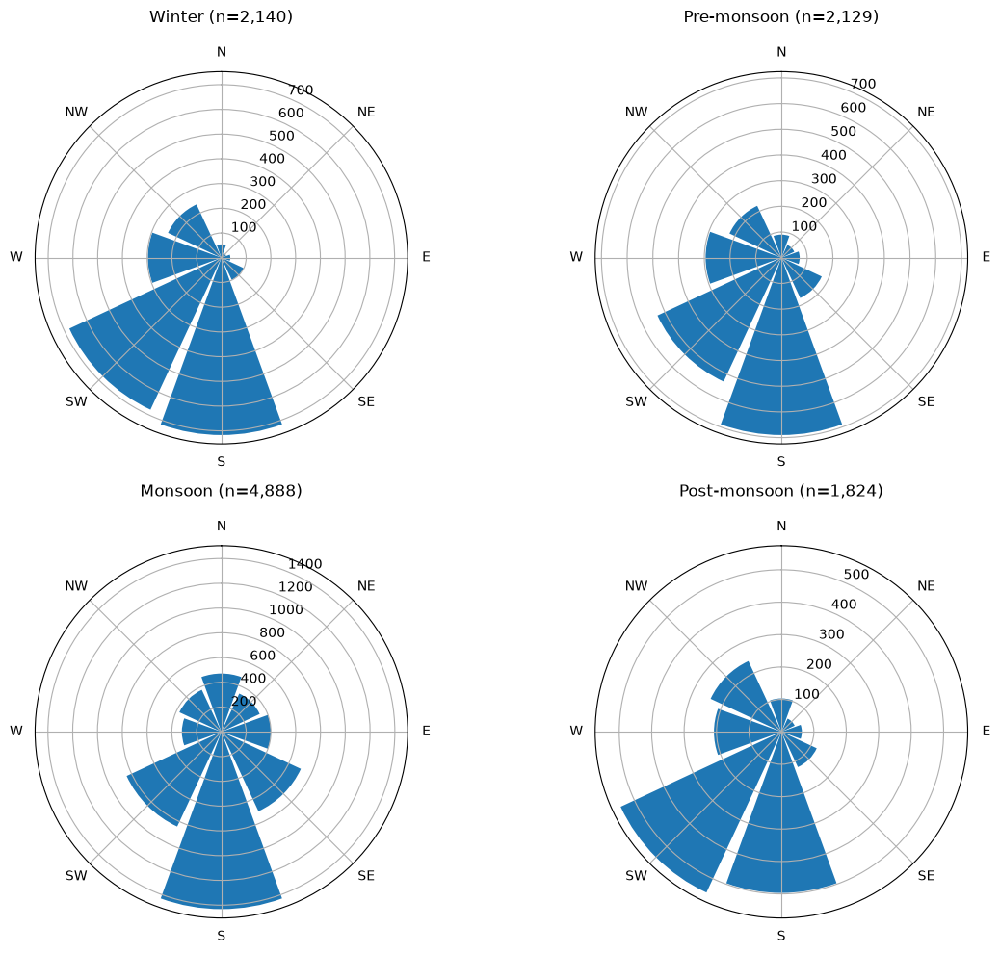

In [7]:
# CELL 4 — Seasonal wind roses

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    2, 2, figsize=(12, 10),
    subplot_kw={"projection": "polar"}
)

for ax, season in zip(axes.flat, season_order):
    subset = m47[m47["Season"] == season]
    counts = (
        subset["Wind_Sector"]
        .value_counts()
        .reindex(sector_labels, fill_value=0)
    )

    angles = np.deg2rad(np.arange(0, 360, 45))
    ax.bar(
        angles, counts.values,
        width=np.deg2rad(40),
        align="center"
    )

    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.set_xticks(angles)
    ax.set_xticklabels(sector_labels)
    ax.set_title(
        f"{season} (n={len(subset):,})",
        pad=18
    )

plt.tight_layout()
plt.show()

In [8]:
# SECTION 4.7 — DAILY PM2.5 BY CLOUD-COVER CLASS

import pandas as pd
import numpy as np

cloud_data = master[[
    "datetime", "pm25", "cloud_cover"
]].copy()

cloud_data["datetime"] = pd.to_datetime(cloud_data["datetime"])
cloud_data["Date"] = cloud_data["datetime"].dt.date
cloud_data["Month"] = cloud_data["datetime"].dt.month

def assign_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Pre-monsoon"
    elif month in [6, 7, 8, 9]:
        return "Monsoon"
    return "Post-monsoon"

cloud_data["Season"] = cloud_data["Month"].apply(assign_season)

cloud_daily = cloud_data.groupby("Date").agg(
    N_Hours=("pm25", "count"),
    PM25_Mean=("pm25", "mean"),
    PM25_Median=("pm25", "median"),
    Cloud_Mean=("cloud_cover", "mean"),
    Season=("Season", "first")
).reset_index()

cloud_daily = cloud_daily[
    cloud_daily["N_Hours"] >= 18
].copy()

cloud_daily["Cloud_Class"] = np.select(
    [
        cloud_daily["Cloud_Mean"] < 20,
        cloud_daily["Cloud_Mean"] > 80
    ],
    ["Clear", "Cloudy"],
    default="Intermediate"
)

cloud_table = cloud_daily.groupby(
    ["Season", "Cloud_Class"], observed=False
).agg(
    N=("PM25_Mean", "count"),
    Mean_PM25=("PM25_Mean", "mean"),
    Median_PM25=("PM25_Mean", "median"),
    Mean_Cloud=("Cloud_Mean", "mean")
).round(2)

print("DAILY PM2.5 BY SEASON AND CLOUD CLASS")
print(cloud_table.to_string())

print("\nCLASS COUNTS")
print(cloud_daily["Cloud_Class"].value_counts().to_string())

print("\nTOTAL ELIGIBLE DAYS:", len(cloud_daily))
print("SEASON COUNTS:")
print(cloud_daily["Season"].value_counts().to_string())

DAILY PM2.5 BY SEASON AND CLOUD CLASS
                             N  Mean_PM25  Median_PM25  Mean_Cloud
Season       Cloud_Class                                          
Monsoon      Cloudy        141      18.01        17.49       93.63
             Intermediate   63      26.57        25.68       60.04
Post-monsoon Clear          23      41.78        41.34       10.57
             Cloudy         16      30.56        29.94       92.89
             Intermediate   36      39.52        37.83       48.78
Pre-monsoon  Clear           9      82.18        73.33       13.38
             Cloudy         13      53.80        46.92       86.83
             Intermediate   67      50.28        45.35       53.90
Winter       Clear          39      78.18        76.69        4.32
             Cloudy          2      65.79        65.79       97.14
             Intermediate   49      77.26        76.62       45.29

CLASS COUNTS
Cloud_Class
Intermediate    215
Cloudy          172
Clear            71

TOTA

In [9]:
# SECTION 4.7 — RAINY-DAY THRESHOLD SENSITIVITY

rain_data = master[[
    "datetime", "pm25", "precipitation"
]].copy()

rain_data["datetime"] = pd.to_datetime(rain_data["datetime"])
rain_data["Date"] = rain_data["datetime"].dt.date
rain_data["Month"] = rain_data["datetime"].dt.month

def assign_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Pre-monsoon"
    elif month in [6, 7, 8, 9]:
        return "Monsoon"
    return "Post-monsoon"

rain_data["Season"] = rain_data["Month"].apply(assign_season)

rain_daily = rain_data.groupby("Date").agg(
    N_Hours=("pm25", "count"),
    PM25_Mean=("pm25", "mean"),
    Daily_Precipitation=("precipitation", "sum"),
    Season=("Season", "first")
).reset_index()

rain_daily = rain_daily[
    rain_daily["N_Hours"] >= 18
].copy()

for threshold in [0.2, 1.0, 2.5]:
    rain_daily[f"Rain_Class_{threshold}"] = np.where(
        rain_daily["Daily_Precipitation"] >= threshold,
        "Rainy", "Dry"
    )

    result = rain_daily.groupby(
        ["Season", f"Rain_Class_{threshold}"]
    ).agg(
        N=("PM25_Mean", "count"),
        Mean_PM25=("PM25_Mean", "mean"),
        Median_PM25=("PM25_Mean", "median")
    ).round(2)

    print(f"\n{'='*75}")
    print(f"DAILY PRECIPITATION THRESHOLD: >= {threshold} mm")
    print(result.to_string())

    print("\nOverall classification:")
    print(rain_daily[f"Rain_Class_{threshold}"].value_counts().to_string())


DAILY PRECIPITATION THRESHOLD: >= 0.2 mm
                               N  Mean_PM25  Median_PM25
Season       Rain_Class_0.2                             
Monsoon      Dry               1      25.11        25.11
             Rainy           203      20.63        18.84
Post-monsoon Dry              34      46.22        44.89
             Rainy            41      31.74        32.11
Pre-monsoon  Dry              16      68.94        63.05
             Rainy            73      50.75        45.35
Winter       Dry              79      77.03        76.26
             Rainy            11      80.12        77.51

Overall classification:
Rain_Class_0.2
Rainy    328
Dry      130

DAILY PRECIPITATION THRESHOLD: >= 1.0 mm
                               N  Mean_PM25  Median_PM25
Season       Rain_Class_1.0                             
Monsoon      Dry               4      30.12        30.42
             Rainy           200      20.47        18.78
Post-monsoon Dry              48      43.59        4

In [10]:
# SECTION 4.7 — SEASONAL PRESSURE-CHANGE ANALYSIS

import pandas as pd
import numpy as np
from scipy.stats import pearsonr, spearmanr

pressure_data = master[
    ["datetime", "pm25", "pm1", "surface_pressure", "pressure_msl"]
].copy()

pressure_data["datetime"] = pd.to_datetime(pressure_data["datetime"])
pressure_data = pressure_data.sort_values("datetime").reset_index(drop=True)

# Verify hourly continuity before calculating lags
time_diff = pressure_data["datetime"].diff()

print("TIME INTERVAL CHECK")
print(time_diff.value_counts().head(10).to_string())

# Calculate changes only when timestamps are exactly 3 or 24 hours apart
for variable in ["surface_pressure", "pressure_msl"]:
    for lag in [3, 24]:
        previous = pressure_data[["datetime", variable]].copy()
        previous["datetime"] += pd.Timedelta(hours=lag)

        previous = previous.rename(
            columns={variable: f"{variable}_lag{lag}"}
        )

        pressure_data = pressure_data.merge(
            previous,
            on="datetime",
            how="left"
        )

        pressure_data[f"{variable}_change_{lag}h"] = (
            pressure_data[variable] -
            pressure_data[f"{variable}_lag{lag}"]
        )

# Assign seasons
def assign_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Pre-monsoon"
    elif month in [6, 7, 8, 9]:
        return "Monsoon"
    return "Post-monsoon"

pressure_data["Season"] = (
    pressure_data["datetime"].dt.month.apply(assign_season)
)

print("\nPRESSURE CHANGE AVAILABILITY")
for col in [
    "surface_pressure_change_3h",
    "surface_pressure_change_24h",
    "pressure_msl_change_3h",
    "pressure_msl_change_24h"
]:
    print(f"{col}: {pressure_data[col].notna().sum()} valid observations")

TIME INTERVAL CHECK
datetime
0 days 01:00:00    10896
0 days 02:00:00       47
0 days 04:00:00        8
0 days 03:00:00        7
0 days 05:00:00        5
0 days 06:00:00        4
0 days 07:00:00        4
1 days 20:00:00        2
0 days 21:00:00        1
0 days 17:00:00        1

PRESSURE CHANGE AVAILABILITY
surface_pressure_change_3h: 10828 valid observations
surface_pressure_change_24h: 10659 valid observations
pressure_msl_change_3h: 10828 valid observations
pressure_msl_change_24h: 10659 valid observations


In [11]:
# SEASONAL PEARSON AND SPEARMAN CORRELATIONS

pressure_variables = [
    "surface_pressure_change_3h",
    "surface_pressure_change_24h",
    "pressure_msl_change_3h",
    "pressure_msl_change_24h"
]

pollutants = ["pm25", "pm1"]

season_order = [
    "Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"
]

results = []

for season in season_order:
    subset = pressure_data[
        pressure_data["Season"] == season
    ]

    for pressure_var in pressure_variables:
        for pollutant in pollutants:

            pair = subset[
                [pressure_var, pollutant]
            ].dropna()

            n = len(pair)

            if n < 3:
                continue

            pearson_r, pearson_p = pearsonr(
                pair[pressure_var], pair[pollutant]
            )

            spearman_r, spearman_p = spearmanr(
                pair[pressure_var], pair[pollutant]
            )

            results.append({
                "Season": season,
                "Pressure_Change": pressure_var,
                "Pollutant": pollutant.upper(),
                "N": n,
                "Pearson_r": pearson_r,
                "Pearson_p": pearson_p,
                "Spearman_r": spearman_r,
                "Spearman_p": spearman_p
            })

pressure_corr_results = pd.DataFrame(results)

pressure_corr_results[
    ["Pearson_r", "Pearson_p", "Spearman_r", "Spearman_p"]
] = pressure_corr_results[
    ["Pearson_r", "Pearson_p", "Spearman_r", "Spearman_p"]
].round(4)

print("SEASONAL PRESSURE-CHANGE CORRELATIONS")
print(pressure_corr_results.to_string(index=False))

SEASONAL PRESSURE-CHANGE CORRELATIONS
      Season             Pressure_Change Pollutant    N  Pearson_r  Pearson_p  Spearman_r  Spearman_p
      Winter  surface_pressure_change_3h      PM25 2121     0.5990     0.0000      0.6524      0.0000
      Winter  surface_pressure_change_3h       PM1 2121     0.6106     0.0000      0.6592      0.0000
      Winter surface_pressure_change_24h      PM25 2121     0.0303     0.1626      0.0275      0.2059
      Winter surface_pressure_change_24h       PM1 2121     0.0234     0.2820      0.0251      0.2475
      Winter      pressure_msl_change_3h      PM25 2121     0.4910     0.0000      0.5010      0.0000
      Winter      pressure_msl_change_3h       PM1 2121     0.5114     0.0000      0.5140      0.0000
      Winter     pressure_msl_change_24h      PM25 2121     0.0319     0.1414      0.0391      0.0715
      Winter     pressure_msl_change_24h       PM1 2121     0.0277     0.2024      0.0391      0.0721
 Pre-monsoon  surface_pressure_change_3h    

In [12]:
# SEASONAL DISTRIBUTION AND STRONGEST ASSOCIATIONS

print("SEASONAL PRESSURE-CHANGE DISTRIBUTIONS")

distribution = pressure_data.groupby("Season")[
    pressure_variables
].agg(["count", "mean", "std", "median", "min", "max"])

print(distribution.round(3).to_string())

print("\nSTRONGEST SEASONAL ASSOCIATIONS")
for pollutant in ["PM25", "PM1"]:
    subset = pressure_corr_results[
        pressure_corr_results["Pollutant"] == pollutant
    ].copy()

    subset["Absolute_Spearman"] = subset["Spearman_r"].abs()

    print(f"\n{pollutant}")
    print(
        subset.sort_values(
            "Absolute_Spearman", ascending=False
        )[[
            "Season", "Pressure_Change", "N",
            "Pearson_r", "Spearman_r"
        ]].head(8).to_string(index=False)
    )

SEASONAL PRESSURE-CHANGE DISTRIBUTIONS
             surface_pressure_change_3h                                surface_pressure_change_24h                                pressure_msl_change_3h                                pressure_msl_change_24h                               
                                  count   mean    std median  min  max                       count   mean    std median  min  max                  count   mean    std median  min  max                   count   mean    std median  min  max
Season                                                                                                                                                                                                                                        
Monsoon                            4812 -0.000  1.503    0.0 -3.7  5.0                        4704 -0.001  1.222    0.0 -4.3  4.2                   4812 -0.000  1.582   -0.2 -4.8  5.6                    4704  0.001  1.491    0.0 -5.8  5.5
Post-

In [13]:
# SEASONAL PRESSURE-CHANGE CORRELATIONS
# RAW VS MONTH-ADJUSTED VS MONTH-HOUR-ADJUSTED

pressure_adjusted = pressure_data.copy()

pressure_adjusted["Month"] = (
    pressure_adjusted["datetime"].dt.month
)

pressure_adjusted["Hour"] = (
    pressure_adjusted["datetime"].dt.hour
)

pressure_variables = [
    "surface_pressure_change_3h",
    "surface_pressure_change_24h",
    "pressure_msl_change_3h",
    "pressure_msl_change_24h"
]

results_adjusted = []

for season in season_order:
    seasonal_data = pressure_adjusted[
        pressure_adjusted["Season"] == season
    ].copy()

    for pressure_var in pressure_variables:
        for pollutant in ["pm25", "pm1"]:

            pair = seasonal_data[
                ["Month", "Hour", pressure_var, pollutant]
            ].dropna().copy()

            if len(pair) < 3:
                continue

            # Raw values
            x_raw = pair[pressure_var]
            y_raw = pair[pollutant]

            # Remove calendar-month means
            x_month = x_raw - pair.groupby("Month")[pressure_var].transform("mean")
            y_month = y_raw - pair.groupby("Month")[pollutant].transform("mean")

            # Remove calendar-month × hour means
            group = pair.groupby(["Month", "Hour"])

            x_month_hour = (
                x_raw - group[pressure_var].transform("mean")
            )
            y_month_hour = (
                y_raw - group[pollutant].transform("mean")
            )

            for adjustment, x, y in [
                ("Raw", x_raw, y_raw),
                ("Month-adjusted", x_month, y_month),
                ("Month-hour-adjusted", x_month_hour, y_month_hour)
            ]:

                pearson_r = pearsonr(x, y).statistic
                spearman_r = spearmanr(x, y).statistic

                results_adjusted.append({
                    "Season": season,
                    "Pressure_Change": pressure_var,
                    "Pollutant": pollutant.upper(),
                    "Adjustment": adjustment,
                    "N": len(pair),
                    "Pearson_r": pearson_r,
                    "Spearman_r": spearman_r
                })

pressure_adjusted_results = pd.DataFrame(results_adjusted)

pressure_adjusted_results[
    ["Pearson_r", "Spearman_r"]
] = pressure_adjusted_results[
    ["Pearson_r", "Spearman_r"]
].round(4)

print("SEASONAL PRESSURE-CHANGE CORRELATIONS")
print("RAW VS MONTH-ADJUSTED VS MONTH-HOUR-ADJUSTED\n")

print(
    pressure_adjusted_results.to_string(index=False)
)

SEASONAL PRESSURE-CHANGE CORRELATIONS
RAW VS MONTH-ADJUSTED VS MONTH-HOUR-ADJUSTED

      Season             Pressure_Change Pollutant          Adjustment    N  Pearson_r  Spearman_r
      Winter  surface_pressure_change_3h      PM25                 Raw 2121     0.5990      0.6524
      Winter  surface_pressure_change_3h      PM25      Month-adjusted 2121     0.6044      0.6543
      Winter  surface_pressure_change_3h      PM25 Month-hour-adjusted 2121     0.0015      0.0263
      Winter  surface_pressure_change_3h       PM1                 Raw 2121     0.6106      0.6592
      Winter  surface_pressure_change_3h       PM1      Month-adjusted 2121     0.6160      0.6580
      Winter  surface_pressure_change_3h       PM1 Month-hour-adjusted 2121    -0.0053      0.0222
      Winter surface_pressure_change_24h      PM25                 Raw 2121     0.0303      0.0275
      Winter surface_pressure_change_24h      PM25      Month-adjusted 2121     0.0156      0.0163
      Winter surface_pres

In [14]:
# SECTION 4.7 — HUMIDITY AND TEMPERATURE INTERACTION

humidity_data = master[
    ["datetime", "pm25", "pm1",
     "relative_humidity_2m", "temperature_2m"]
].copy()

humidity_data["datetime"] = pd.to_datetime(humidity_data["datetime"])
humidity_data["Month"] = humidity_data["datetime"].dt.month
humidity_data["Hour"] = humidity_data["datetime"].dt.hour

def assign_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Pre-monsoon"
    elif month in [6, 7, 8, 9]:
        return "Monsoon"
    return "Post-monsoon"

humidity_data["Season"] = humidity_data["Month"].apply(assign_season)

humidity_data = humidity_data.dropna(
    subset=["pm25", "pm1", "relative_humidity_2m", "temperature_2m"]
).copy()

humidity_data["RH_Band"] = pd.cut(
    humidity_data["relative_humidity_2m"],
    bins=[-np.inf, 60, 80, 90, np.inf],
    labels=["Below 60%", "60–80%", "80–90%", "Above 90%"],
    right=False
)

# Three temperature groups reduce sparsity in the interaction table
humidity_data["Temperature_Group"] = pd.qcut(
    humidity_data["temperature_2m"],
    q=3,
    labels=["Cooler", "Middle", "Warmer"],
    duplicates="drop"
)

print("OBSERVATION COUNTS")
print("Total valid hourly observations:", len(humidity_data))
print("\nRelative humidity distribution:")
print(humidity_data["RH_Band"].value_counts().sort_index())

print("\nTemperature group distribution:")
print(humidity_data["Temperature_Group"].value_counts().sort_index())

print("\nTemperature group boundaries (°C):")
print(
    humidity_data.groupby("Temperature_Group", observed=True)[
        "temperature_2m"
    ].agg(["min", "max", "mean"]).round(2).to_string()
)

OBSERVATION COUNTS
Total valid hourly observations: 10981

Relative humidity distribution:
RH_Band
Below 60%    1334
60–80%       2444
80–90%       1881
Above 90%    5322
Name: count, dtype: int64

Temperature group distribution:
Temperature_Group
Cooler    3664
Middle    3668
Warmer    3649
Name: count, dtype: int64

Temperature group boundaries (°C):
                    min   max   mean
Temperature_Group                   
Cooler              3.2  17.3  12.47
Middle             17.4  21.5  19.74
Warmer             21.6  30.4  24.02


In [15]:
# SEASONAL PARTICULATE CONCENTRATIONS BY AMBIENT RH BAND

humidity_results = humidity_data.groupby(
    ["Season", "RH_Band"], observed=True
).agg(
    N_PM25=("pm25", "count"),
    Mean_PM25=("pm25", "mean"),
    Median_PM25=("pm25", "median"),
    N_PM1=("pm1", "count"),
    Mean_PM1=("pm1", "mean"),
    Median_PM1=("pm1", "median"),
    Mean_Temperature=("temperature_2m", "mean")
).round(2)

print("SEASONAL PM CONCENTRATIONS BY AMBIENT RELATIVE HUMIDITY")
print(humidity_results.to_string())

print("\nSEASONAL OBSERVATION COUNTS")
print(
    humidity_data.groupby(
        ["Season", "RH_Band"], observed=True
    ).size().unstack(fill_value=0).to_string()
)

SEASONAL PM CONCENTRATIONS BY AMBIENT RELATIVE HUMIDITY
                        N_PM25  Mean_PM25  Median_PM25  N_PM1  Mean_PM1  Median_PM1  Mean_Temperature
Season       RH_Band                                                                                 
Monsoon      Below 60%     101      30.09        31.50    101     19.41       20.40             27.52
             60–80%        847      22.42        20.80    847     14.67       13.81             26.04
             80–90%        732      19.65        17.77    732     12.93       11.60             24.03
             Above 90%    3208      20.38        18.44   3208     13.23       12.07             21.09
Post-monsoon Below 60%     299      36.48        34.27    299     23.23       21.85             21.71
             60–80%        346      39.59        37.22    346     25.30       23.16             19.23
             80–90%        350      42.97        40.84    350     27.43       25.91             16.42
             Above 90%    

In [16]:
# TEMPERATURE × HUMIDITY INTERACTION

interaction_results = humidity_data.groupby(
    ["Season", "Temperature_Group", "RH_Band"],
    observed=True
).agg(
    N=("pm25", "count"),
    Mean_PM25=("pm25", "mean"),
    Median_PM25=("pm25", "median"),
    Mean_PM1=("pm1", "mean"),
    Mean_Temperature=("temperature_2m", "mean"),
    Mean_RH=("relative_humidity_2m", "mean")
).reset_index()

interaction_results[
    ["Mean_PM25", "Median_PM25", "Mean_PM1",
     "Mean_Temperature", "Mean_RH"]
] = interaction_results[
    ["Mean_PM25", "Median_PM25", "Mean_PM1",
     "Mean_Temperature", "Mean_RH"]
].round(2)

print("TEMPERATURE × HUMIDITY INTERACTION")
print("All combinations with at least 20 observations:\n")

print(
    interaction_results[
        interaction_results["N"] >= 20
    ].to_string(index=False)
)

print("\nSPARSE COMBINATIONS (N < 20)")
print(
    interaction_results[
        interaction_results["N"] < 20
    ].to_string(index=False)
)

print("\nTOTAL COMBINATIONS:", len(interaction_results))
print(
    "Combinations with N >= 20:",
    (interaction_results["N"] >= 20).sum()
)

TEMPERATURE × HUMIDITY INTERACTION
All combinations with at least 20 observations:

      Season Temperature_Group   RH_Band    N  Mean_PM25  Median_PM25  Mean_PM1  Mean_Temperature  Mean_RH
     Monsoon            Middle Above 90% 1969      21.06        18.80     13.59             20.25    98.52
     Monsoon            Warmer Below 60%  101      30.09        31.50     19.41             27.52    55.51
     Monsoon            Warmer    60–80%  847      22.42        20.80     14.67             26.04    71.71
     Monsoon            Warmer    80–90%  715      19.20        17.49     12.65             24.12    84.38
     Monsoon            Warmer Above 90% 1232      19.22        17.70     12.60             22.45    96.52
Post-monsoon            Cooler    60–80%  109      55.53        48.41     35.81             14.20    72.76
Post-monsoon            Cooler    80–90%  211      47.81        44.89     30.64             14.35    85.27
Post-monsoon            Cooler Above 90%  553      42.12    

In [17]:
# CONSOLIDATED METEOROLOGICAL CORRELATION TABLE

weather_candidates = [
    "temperature_2m",
    "relative_humidity_2m",
    "dew_point_2m",
    "surface_pressure",
    "pressure_msl",
    "wind_speed_10m",
    "wind_gusts_10m",
    "boundary_layer_height",
    "cloud_cover",
    "precipitation",
    "shortwave_radiation",
    "terrestrial_radiation",
    "direct_radiation",
    "diffuse_radiation"
]

weather_variables = [
    col for col in weather_candidates
    if col in master.columns
]

print("WEATHER VARIABLES INCLUDED:")
print(weather_variables)

print("\nCANDIDATE VARIABLES NOT FOUND:")
print([col for col in weather_candidates if col not in master.columns])

corr_data = master[
    ["datetime", "pm25", "pm1"] + weather_variables
].copy()

corr_data["datetime"] = pd.to_datetime(corr_data["datetime"])
corr_data["Month"] = corr_data["datetime"].dt.month
corr_data["Hour"] = corr_data["datetime"].dt.hour

correlation_results = []

for variable in weather_variables:
    for pollutant in ["pm25", "pm1"]:

        pair = corr_data[
            ["Month", "Hour", variable, pollutant]
        ].dropna().copy()

        if len(pair) < 3:
            continue

        x = pair[variable]
        y = pair[pollutant]

        x_month = x - pair.groupby("Month")[variable].transform("mean")
        y_month = y - pair.groupby("Month")[pollutant].transform("mean")

        month_hour_group = pair.groupby(["Month", "Hour"])

        x_month_hour = (
            x - month_hour_group[variable].transform("mean")
        )
        y_month_hour = (
            y - month_hour_group[pollutant].transform("mean")
        )

        adjustments = [
            ("Raw", x, y),
            ("Month-adjusted", x_month, y_month),
            ("Month-hour-adjusted", x_month_hour, y_month_hour)
        ]

        for adjustment, x_values, y_values in adjustments:

            correlation_results.append({
                "Variable": variable,
                "Pollutant": pollutant.upper(),
                "Adjustment": adjustment,
                "N": len(pair),
                "Pearson_r": pearsonr(
                    x_values, y_values
                ).statistic,
                "Spearman_r": spearmanr(
                    x_values, y_values
                ).statistic
            })

correlation_summary = pd.DataFrame(correlation_results)

correlation_summary[
    ["Pearson_r", "Spearman_r"]
] = correlation_summary[
    ["Pearson_r", "Spearman_r"]
].round(4)

print("\nCONSOLIDATED METEOROLOGICAL CORRELATIONS")
print(correlation_summary.to_string(index=False))

WEATHER VARIABLES INCLUDED:
['temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'surface_pressure', 'pressure_msl', 'wind_speed_10m', 'wind_gusts_10m', 'boundary_layer_height', 'cloud_cover', 'precipitation', 'shortwave_radiation', 'terrestrial_radiation', 'direct_radiation', 'diffuse_radiation']

CANDIDATE VARIABLES NOT FOUND:
[]

CONSOLIDATED METEOROLOGICAL CORRELATIONS
             Variable Pollutant          Adjustment     N  Pearson_r  Spearman_r
       temperature_2m      PM25                 Raw 10981    -0.5819     -0.6201
       temperature_2m      PM25      Month-adjusted 10981    -0.1119     -0.1094
       temperature_2m      PM25 Month-hour-adjusted 10981     0.0755      0.0267
       temperature_2m       PM1                 Raw 10981    -0.5904     -0.6198
       temperature_2m       PM1      Month-adjusted 10981    -0.1249     -0.1123
       temperature_2m       PM1 Month-hour-adjusted 10981     0.0565      0.0151
 relative_humidity_2m      PM25                 Raw

In [18]:
# FINAL SECTION 4.7 — CORRELATION CONSISTENCY CHECK

weather_variables = [
    "temperature_2m",
    "relative_humidity_2m",
    "dew_point_2m",
    "surface_pressure",
    "pressure_msl",
    "wind_speed_10m",
    "wind_gusts_10m",
    "boundary_layer_height",
    "cloud_cover",
    "precipitation",
    "shortwave_radiation",
    "terrestrial_radiation",
    "direct_radiation",
    "diffuse_radiation"
]

weather_variables = [
    v for v in weather_variables if v in master.columns
]

corr_data = master[
    ["datetime", "pm25", "pm1"] + weather_variables
].copy()

corr_data["datetime"] = pd.to_datetime(corr_data["datetime"])
corr_data = corr_data.sort_values("datetime").reset_index(drop=True)

corr_data["Date"] = corr_data["datetime"].dt.date
corr_data["Month"] = corr_data["datetime"].dt.month
corr_data["Hour"] = corr_data["datetime"].dt.hour

def calculate_adjusted_correlations(data, variable, pollutant):

    pair = data[
        ["Month", "Hour", variable, pollutant]
    ].dropna().copy()

    x = pair[variable]
    y = pair[pollutant]

    x_month = x - pair.groupby("Month")[variable].transform("mean")
    y_month = y - pair.groupby("Month")[pollutant].transform("mean")

    group = pair.groupby(["Month", "Hour"])

    x_month_hour = x - group[variable].transform("mean")
    y_month_hour = y - group[pollutant].transform("mean")

    output = []

    for adjustment, a, b in [
        ("Raw", x, y),
        ("Month-adjusted", x_month, y_month),
        ("Month-hour-adjusted", x_month_hour, y_month_hour)
    ]:
        output.append({
            "Variable": variable,
            "Pollutant": pollutant.upper(),
            "Adjustment": adjustment,
            "N": len(pair),
            "Pearson_r": pearsonr(a, b).statistic,
            "Spearman_r": spearmanr(a, b).statistic
        })

    return output


point_results = []

for variable in weather_variables:
    for pollutant in ["pm25", "pm1"]:
        point_results.extend(
            calculate_adjusted_correlations(
                corr_data, variable, pollutant
            )
        )

point_summary = pd.DataFrame(point_results)

point_summary[
    ["Pearson_r", "Spearman_r"]
] = point_summary[
    ["Pearson_r", "Spearman_r"]
].round(4)

print("FINAL POINT ESTIMATES AND SAMPLE SIZES")
print(point_summary.to_string(index=False))

print("\nSAMPLE SIZE CHECK")
print(
    point_summary.groupby(
        ["Variable", "Pollutant"]
    )["N"].first().to_string()
)

FINAL POINT ESTIMATES AND SAMPLE SIZES
             Variable Pollutant          Adjustment     N  Pearson_r  Spearman_r
       temperature_2m      PM25                 Raw 10981    -0.5819     -0.6201
       temperature_2m      PM25      Month-adjusted 10981    -0.1119     -0.1094
       temperature_2m      PM25 Month-hour-adjusted 10981     0.0755      0.0267
       temperature_2m       PM1                 Raw 10981    -0.5904     -0.6198
       temperature_2m       PM1      Month-adjusted 10981    -0.1249     -0.1123
       temperature_2m       PM1 Month-hour-adjusted 10981     0.0565      0.0151
 relative_humidity_2m      PM25                 Raw 10981    -0.2514     -0.3159
 relative_humidity_2m      PM25      Month-adjusted 10981     0.0935      0.0790
 relative_humidity_2m      PM25 Month-hour-adjusted 10981    -0.0405     -0.0278
 relative_humidity_2m       PM1                 Raw 10981    -0.2534     -0.3192
 relative_humidity_2m       PM1      Month-adjusted 10981     0.0880  

In [20]:
# FINAL SECTION 4.7 — METEOROLOGICAL CORRELATION TABLE
# No bootstrap or significance testing; point estimates only.

from scipy.stats import pearsonr, spearmanr

weather_variables = [
    "temperature_2m",
    "relative_humidity_2m",
    "dew_point_2m",
    "surface_pressure",
    "pressure_msl",
    "wind_speed_10m",
    "wind_gusts_10m",
    "boundary_layer_height",
    "cloud_cover",
    "precipitation",
    "shortwave_radiation",
    "terrestrial_radiation",
    "direct_radiation",
    "diffuse_radiation"
]

pollutants = ["pm25", "pm1"]

# Confirm required columns
required = ["datetime"] + pollutants + weather_variables
missing_columns = [c for c in required if c not in master.columns]

if missing_columns:
    raise KeyError(f"Missing columns: {missing_columns}")

data = master[required].copy()
data["datetime"] = pd.to_datetime(data["datetime"])

data["Month"] = data["datetime"].dt.month
data["Hour"] = data["datetime"].dt.hour

results = []

for variable in weather_variables:

    for pollutant in pollutants:

        pair = data[
            ["Month", "Hour", variable, pollutant]
        ].dropna().copy()

        # Raw values
        x_raw = pair[variable]
        y_raw = pair[pollutant]

        # Remove calendar-month means
        x_month = (
            x_raw -
            pair.groupby("Month")[variable].transform("mean")
        )

        y_month = (
            y_raw -
            pair.groupby("Month")[pollutant].transform("mean")
        )

        # Remove calendar-month × hour means
        groups = pair.groupby(["Month", "Hour"])

        x_month_hour = (
            x_raw -
            groups[variable].transform("mean")
        )

        y_month_hour = (
            y_raw -
            groups[pollutant].transform("mean")
        )

        adjustments = [
            ("Raw", x_raw, y_raw),
            ("Month-adjusted", x_month, y_month),
            ("Month-hour-adjusted", x_month_hour, y_month_hour)
        ]

        for adjustment, x, y in adjustments:

            results.append({
                "Variable": variable,
                "Pollutant": pollutant.upper(),
                "Adjustment": adjustment,
                "N": len(pair),
                "Pearson_r": pearsonr(x, y).statistic,
                "Spearman_r": spearmanr(x, y).statistic
            })

final_corr = pd.DataFrame(results)

final_corr[["Pearson_r", "Spearman_r"]] = (
    final_corr[["Pearson_r", "Spearman_r"]].round(4)
)

# Display final table
print("=" * 100)
print("FINAL METEOROLOGICAL CORRELATION RESULTS")
print("=" * 100)

print(final_corr.to_string(index=False))

# Sample-size verification
print("\n" + "=" * 100)
print("SAMPLE SIZE VERIFICATION")
print("=" * 100)

sample_check = (
    final_corr[
        ["Variable", "Pollutant", "N"]
    ]
    .drop_duplicates()
    .sort_values(["Variable", "Pollutant"])
)

print(sample_check.to_string(index=False))

print("\nExpected variables:", len(weather_variables))
print("Expected pollutant comparisons:", len(weather_variables) * 2)
print("Expected correlation estimates:", len(final_corr))
print("Expected estimates:", len(weather_variables) * 2 * 3)

print("\nMissing observations in master dataset:")
print(
    data[weather_variables].isna().sum().to_string()
)

FINAL METEOROLOGICAL CORRELATION RESULTS
             Variable Pollutant          Adjustment     N  Pearson_r  Spearman_r
       temperature_2m      PM25                 Raw 10981    -0.5819     -0.6201
       temperature_2m      PM25      Month-adjusted 10981    -0.1119     -0.1094
       temperature_2m      PM25 Month-hour-adjusted 10981     0.0755      0.0267
       temperature_2m       PM1                 Raw 10981    -0.5904     -0.6198
       temperature_2m       PM1      Month-adjusted 10981    -0.1249     -0.1123
       temperature_2m       PM1 Month-hour-adjusted 10981     0.0565      0.0151
 relative_humidity_2m      PM25                 Raw 10981    -0.2514     -0.3159
 relative_humidity_2m      PM25      Month-adjusted 10981     0.0935      0.0790
 relative_humidity_2m      PM25 Month-hour-adjusted 10981    -0.0405     -0.0278
 relative_humidity_2m       PM1                 Raw 10981    -0.2534     -0.3192
 relative_humidity_2m       PM1      Month-adjusted 10981     0.0880

## Observation
The results indicate that meteorological conditions are associated with particulate matter concentrations, but the strength of these relationships varies considerably across variables and temporal adjustments. Raw correlations are generally stronger, partly reflecting shared seasonal and diurnal patterns. After accounting for monthly and hourly variation, most associations weaken substantially. Relative temperature also shows that the apparent temperature–pollution relationship depends on the baseline used. Some variables, particularly wind gusts, precipitation, and boundary layer height, retain relatively weak associations after adjustment. These findings suggest that meteorological influences should not be interpreted through raw correlations alone. Their potential predictive value, including delayed effects, requires further examination alongside temporal patterns and data limitations.

## 4.8 Lagged Meteorological Relationships
This section examines whether meteorological conditions are associated with particulate matter concentrations not only during the same hour but also in subsequent hours. The analysis focuses on precipitation and cloud cover, for which delayed relationships with particulate concentrations may be relevant. Associations are evaluated across lags of up to 24 hours using both raw and temporally adjusted correlations. This is an exploratory analysis and does not establish causal or predictive effects.

Lagged Dataset Preparation

In [176]:
# Restore the complete hourly timeline
hourly_index = pd.date_range(
    start=temporal.index.min(),
    end=temporal.index.max(),
    freq="h"
)

lag_data = temporal[
    ["pm25", "pm1", "precipitation", "cloud_cover"]
].reindex(hourly_index)

lag_data.index.name = "datetime"

print("Hourly dataset shape:", lag_data.shape)
print("Time interval:", lag_data.index.min(), "to", lag_data.index.max())
print("\nMissing observations:")
display(lag_data.isna().sum().to_frame("Missing_Count"))

Hourly dataset shape: (11409, 4)
Time interval: 2025-07-01 00:45:00+05:45 to 2026-10-19 08:45:00+05:45

Missing observations:


,Missing_Count
pm25,428
pm1,428
precipitation,428
cloud_cover,428


Calculating Lagged Correlations

In [179]:
lag_results = []

for variable in ["precipitation", "cloud_cover"]:

    weather = lag_data[variable]

    # Calculate weather baseline at its original timestamps
    weather_baseline = weather.groupby(
        [weather.index.month, weather.index.hour]
    ).transform("mean")

    for pollutant in ["pm25", "pm1"]:

        pollution = lag_data[pollutant]

        # Calculate pollutant baseline at target timestamps
        pollution_baseline = pollution.groupby(
            [pollution.index.month, pollution.index.hour]
        ).transform("mean")

        for lag in range(25):

            weather_lagged = weather.shift(lag)
            weather_baseline_lagged = weather_baseline.shift(lag)

            temp = pd.DataFrame({
                "Pollutant": pollution,
                "Weather": weather_lagged,
                "Pollutant_Residual": pollution - pollution_baseline,
                "Weather_Residual": (
                    weather_lagged - weather_baseline_lagged
                )
            }).dropna()

            lag_results.append({
                "Variable": variable,
                "Pollutant": pollutant.upper(),
                "Lag_Hours": lag,
                "N": len(temp),
                "Raw_Pearson": temp["Pollutant"].corr(
                    temp["Weather"], method="pearson"
                ),
                "Raw_Spearman": temp["Pollutant"].corr(
                    temp["Weather"], method="spearman"
                ),
                "Adjusted_Pearson": temp["Pollutant_Residual"].corr(
                    temp["Weather_Residual"], method="pearson"
                ),
                "Adjusted_Spearman": temp["Pollutant_Residual"].corr(
                    temp["Weather_Residual"], method="spearman"
                )
            })

lag_correlations = pd.DataFrame(lag_results)

display(lag_correlations.round(3))

,Variable,Pollutant,Lag_Hours,N,Raw_Pearson,Raw_Spearman,Adjusted_Pearson,Adjusted_Spearman
0,precipitation,PM25,0,10981,-0.210,-0.479,-0.061,-0.076
1,precipitation,PM25,1,10896,-0.214,-0.494,-0.065,-0.089
2,precipitation,PM25,2,10862,-0.213,-0.494,-0.065,-0.094
3,precipitation,PM25,3,10828,-0.212,-0.485,-0.071,-0.092
4,precipitation,PM25,4,10807,-0.207,-0.468,-0.071,-0.092
...,...,...,...,...,...,...,...,...
95,cloud_cover,PM1,20,10676,-0.431,-0.502,-0.140,-0.116
96,cloud_cover,PM1,21,10671,-0.451,-0.518,-0.143,-0.117
97,cloud_cover,PM1,22,10668,-0.469,-0.531,-0.139,-0.113
98,cloud_cover,PM1,23,10665,-0.480,-0.542,-0.138,-0.114


In [180]:
strongest_lags = (
    lag_correlations
    .assign(
        Abs_Adjusted_Pearson=lambda x: x["Adjusted_Pearson"].abs(),
        Abs_Adjusted_Spearman=lambda x: x["Adjusted_Spearman"].abs()
    )
    .sort_values(
        ["Variable", "Pollutant", "Abs_Adjusted_Spearman"],
        ascending=[True, True, False]
    )
    .groupby(["Variable", "Pollutant"])
    .head(1)
    .sort_values(["Variable", "Pollutant"])
)

display(
    strongest_lags[
        [
            "Variable", "Pollutant", "Lag_Hours", "N",
            "Adjusted_Pearson", "Adjusted_Spearman"
        ]
    ].round(3)
)

,Variable,Pollutant,Lag_Hours,N,Adjusted_Pearson,Adjusted_Spearman
99,cloud_cover,PM1,24,10659,-0.145,-0.124
74,cloud_cover,PM25,24,10659,-0.131,-0.112
27,precipitation,PM1,2,10862,-0.068,-0.093
2,precipitation,PM25,2,10862,-0.065,-0.094


Comparison Accross Lagged Windows

In [181]:
selected_lags = [0, 1, 2, 3, 6, 12, 18, 24]

selected_lag_summary = lag_correlations[
    lag_correlations["Lag_Hours"].isin(selected_lags)
][[
    "Variable", "Pollutant", "Lag_Hours", "N",
    "Raw_Spearman", "Adjusted_Spearman"
]]

display(
    selected_lag_summary
    .pivot(
        index=["Variable", "Pollutant"],
        columns="Lag_Hours",
        values="Adjusted_Spearman"
    )
    .round(3)
)

Lag_Hours                   0      1      2      3      6      12     18  \
Variable      Pollutant                                                    
cloud_cover   PM1       -0.071 -0.070 -0.077 -0.083 -0.095 -0.091 -0.099   
              PM25      -0.062 -0.061 -0.066 -0.072 -0.084 -0.081 -0.088   
precipitation PM1       -0.075 -0.088 -0.093 -0.091 -0.087 -0.078 -0.092   
              PM25      -0.076 -0.089 -0.094 -0.092 -0.091 -0.081 -0.093   

Lag_Hours                   24  
Variable      Pollutant         
cloud_cover   PM1       -0.124  
              PM25      -0.112  
precipitation PM1       -0.077  
              PM25      -0.079

Compare Short, Mediun, and Longer Lag Associations

In [182]:
lag_correlations["Lag_Window"] = pd.cut(
    lag_correlations["Lag_Hours"],
    bins=[-1, 6, 12, 24],
    labels=["0–6 hours", "7–12 hours", "13–24 hours"]
)

window_summary = (
    lag_correlations
    .assign(
        Abs_Adjusted_Spearman=lambda x: x["Adjusted_Spearman"].abs()
    )
    .groupby(
        ["Variable", "Pollutant", "Lag_Window"],
        observed=True
    )
    .agg(
        Mean_Adjusted_Spearman=("Adjusted_Spearman", "mean"),
        Min_Adjusted_Spearman=("Adjusted_Spearman", "min"),
        Max_Adjusted_Spearman=("Adjusted_Spearman", "max"),
        Mean_Absolute_Association=("Abs_Adjusted_Spearman", "mean")
    )
    .round(3)
)

display(window_summary)

Mean_Adjusted_Spearman  \
Variable      Pollutant Lag_Window                            
cloud_cover   PM1       0–6 hours                    -0.082   
                        7–12 hours                   -0.093   
                        13–24 hours                  -0.104   
              PM25      0–6 hours                    -0.071   
                        7–12 hours                   -0.083   
                        13–24 hours                  -0.092   
precipitation PM1       0–6 hours                    -0.088   
                        7–12 hours                   -0.079   
                        13–24 hours                  -0.080   
              PM25      0–6 hours                    -0.089   
                        7–12 hours                   -0.083   
                        13–24 hours                  -0.081   

                                     Min_Adjusted_Spearman  \
Variable      Pollutant Lag_Window                           
cloud_cover   PM1       0–6 hours                   -0.095   
                        7–12 hours                  -0.095   
                        13–24 hours                 -0.124   
              PM25      0–6 hours                   -0.084   
                        7–12 hours                  -0.084   
                        13–24 hours                 -0.112   
precipitation PM1       0–6 hours                   -0.093   
                        7–12 hours                  -0.084   
                        13–24 hours                 -0.092   
              PM25      0–6 hours                   -0.094   
                        7–12 hours                  -0.088   
                        13–24 hours                 -0.093   

                                     Max_Adjusted_Spearman  \
Variable      Pollutant Lag_Window                           
cloud_cover   PM1       0–6 hours                   -0.070   
                        7–12 hours                  -0.091   
                        13–24 hours                 -0.087   
              PM25      0–6 hours                   -0.061   
                        7–12 hours                  -0.081   
                        13–24 hours                 -0.078   
precipitation PM1       0–6 hours                   -0.075   
                        7–12 hours                  -0.076   
                        13–24 hours                 -0.071   
              PM25      0–6 hours                   -0.076   
                        7–12 hours                  -0.080   
                        13–24 hours                 -0.073   

                                     Mean_Absolute_Association  
Variable      Pollutant Lag_Window                              
cloud_cover   PM1       0–6 hours                        0.082  
                        7–12 hours                       0.093  
                        13–24 hours                      0.104  
              PM25      0–6 hours                        0.071  
                        7–12 hours                       0.083  
                        13–24 hours                      0.092  
precipitation PM1       0–6 hours                        0.088  
                        7–12 hours                       0.079  
                        13–24 hours                      0.080  
              PM25      0–6 hours                        0.089  
                        7–12 hours                       0.083  
                        13–24 hours                      0.081

Visualising the Lag Profiles

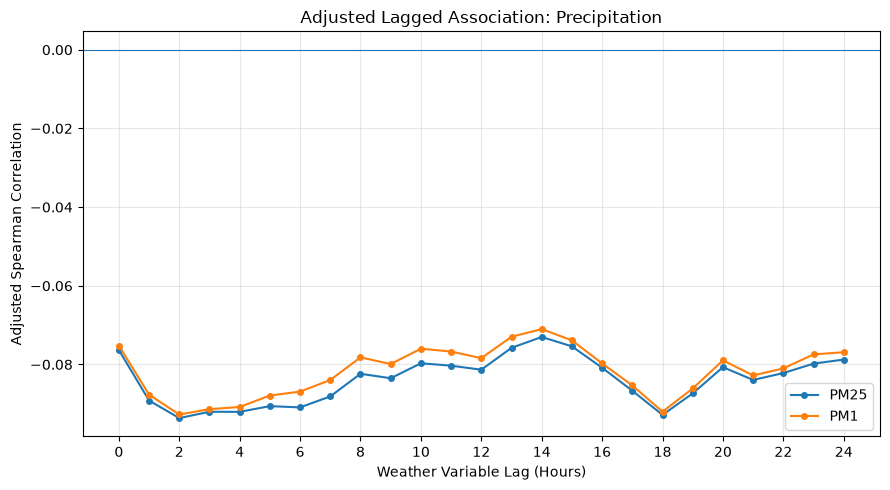

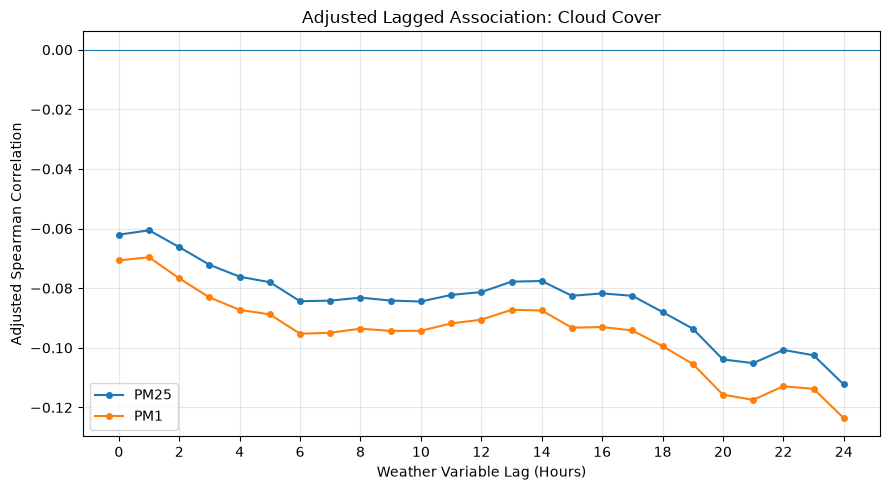

In [183]:
for variable in ["precipitation", "cloud_cover"]:

    fig, ax = plt.subplots(figsize=(9, 5))

    for pollutant in ["PM25", "PM1"]:
        subset = lag_correlations[
            (lag_correlations["Variable"] == variable) &
            (lag_correlations["Pollutant"] == pollutant)
        ]

        ax.plot(
            subset["Lag_Hours"],
            subset["Adjusted_Spearman"],
            marker="o",
            markersize=4,
            label=pollutant
        )

    ax.axhline(0, linewidth=0.8)
    ax.set_title(f"Adjusted Lagged Association: {variable.replace('_', ' ').title()}")
    ax.set_xlabel("Weather Variable Lag (Hours)")
    ax.set_ylabel("Adjusted Spearman Correlation")
    ax.set_xticks(range(0, 25, 2))
    ax.legend()
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


PRECIPITATION — PM25
Strongest adjusted Spearman association: lag 2 h, r = -0.094
Adjusted Pearson range: -0.081 to -0.061
Adjusted Spearman range: -0.094 to -0.073

PRECIPITATION — PM1
Strongest adjusted Spearman association: lag 2 h, r = -0.093
Adjusted Pearson range: -0.085 to -0.062
Adjusted Spearman range: -0.093 to -0.071


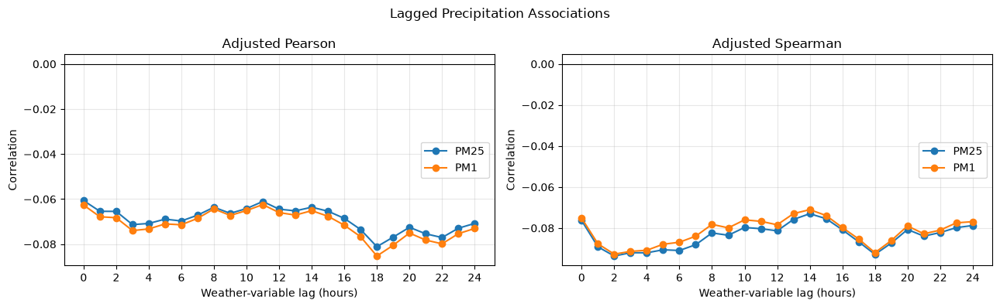


Full lag-wise adjusted correlations:


,Pollutant,Lag_Hours,N,Adjusted_Pearson,Adjusted_Spearman
0,PM25,0,10981,-0.061,-0.076
1,PM25,1,10896,-0.065,-0.089
2,PM25,2,10862,-0.065,-0.094
3,PM25,3,10828,-0.071,-0.092
4,PM25,4,10807,-0.071,-0.092
5,PM25,5,10790,-0.069,-0.091
6,PM25,6,10774,-0.070,-0.091
7,PM25,7,10765,-0.067,-0.088
8,PM25,8,10754,-0.064,-0.082
9,PM25,9,10746,-0.066,-0.084



CLOUD_COVER — PM25
Strongest adjusted Spearman association: lag 24 h, r = -0.112
Adjusted Pearson range: -0.131 to -0.075
Adjusted Spearman range: -0.112 to -0.061

CLOUD_COVER — PM1
Strongest adjusted Spearman association: lag 24 h, r = -0.124
Adjusted Pearson range: -0.145 to -0.088
Adjusted Spearman range: -0.124 to -0.070


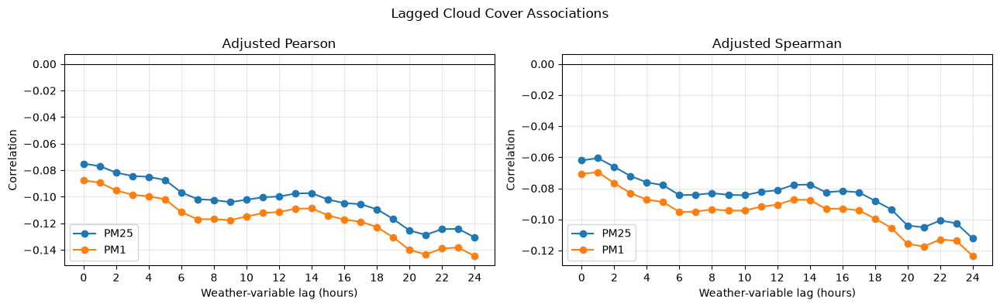


Full lag-wise adjusted correlations:


,Pollutant,Lag_Hours,N,Adjusted_Pearson,Adjusted_Spearman
0,PM25,0,10981,-0.075,-0.062
1,PM25,1,10896,-0.077,-0.061
2,PM25,2,10862,-0.082,-0.066
3,PM25,3,10828,-0.084,-0.072
4,PM25,4,10807,-0.085,-0.076
5,PM25,5,10790,-0.087,-0.078
6,PM25,6,10774,-0.097,-0.084
7,PM25,7,10765,-0.102,-0.084
8,PM25,8,10754,-0.102,-0.083
9,PM25,9,10746,-0.104,-0.084


In [184]:
import matplotlib.pyplot as plt

for variable in ["precipitation", "cloud_cover"]:

    fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharex=True)

    for pollutant in ["PM25", "PM1"]:
        subset = lag_correlations[
            (lag_correlations["Variable"] == variable) &
            (lag_correlations["Pollutant"] == pollutant)
        ].sort_values("Lag_Hours")

        axes[0].plot(
            subset["Lag_Hours"], subset["Adjusted_Pearson"],
            marker="o", label=pollutant
        )
        axes[1].plot(
            subset["Lag_Hours"], subset["Adjusted_Spearman"],
            marker="o", label=pollutant
        )

        peak = subset.loc[
            subset["Adjusted_Spearman"].abs().idxmax()
        ]

        print(f"\n{variable.upper()} — {pollutant}")
        print(
            f"Strongest adjusted Spearman association: "
            f"lag {int(peak['Lag_Hours'])} h, "
            f"r = {peak['Adjusted_Spearman']:.3f}"
        )
        print(
            f"Adjusted Pearson range: "
            f"{subset['Adjusted_Pearson'].min():.3f} to "
            f"{subset['Adjusted_Pearson'].max():.3f}"
        )
        print(
            f"Adjusted Spearman range: "
            f"{subset['Adjusted_Spearman'].min():.3f} to "
            f"{subset['Adjusted_Spearman'].max():.3f}"
        )

    for ax, method in zip(
        axes, ["Adjusted Pearson", "Adjusted Spearman"]
    ):
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set_title(method)
        ax.set_xlabel("Weather-variable lag (hours)")
        ax.set_ylabel("Correlation")
        ax.set_xticks(range(0, 25, 2))
        ax.grid(alpha=0.3)
        ax.legend()

    fig.suptitle(f"Lagged {variable.replace('_', ' ').title()} Associations")
    plt.tight_layout()
    plt.show()

    print("\nFull lag-wise adjusted correlations:")
    display(
        lag_correlations[
            lag_correlations["Variable"] == variable
        ][[
            "Pollutant", "Lag_Hours", "N",
            "Adjusted_Pearson", "Adjusted_Spearman"
        ]].round(3).reset_index(drop=True)
    )

Extended Lag Analysis

In [185]:
extended_lag_results = []

for variable in ["precipitation", "cloud_cover"]:

    weather = lag_data[variable]
    weather_baseline = weather.groupby(
        [weather.index.month, weather.index.hour]
    ).transform("mean")

    for pollutant in ["pm25", "pm1"]:

        pollution = lag_data[pollutant]
        pollution_baseline = pollution.groupby(
            [pollution.index.month, pollution.index.hour]
        ).transform("mean")

        for lag in range(73):

            weather_lagged = weather.shift(lag)
            weather_baseline_lagged = weather_baseline.shift(lag)

            temp = pd.DataFrame({
                "Pollutant": pollution,
                "Weather": weather_lagged,
                "Pollutant_Residual": pollution - pollution_baseline,
                "Weather_Residual": (
                    weather_lagged - weather_baseline_lagged
                )
            }).dropna()

            extended_lag_results.append({
                "Variable": variable,
                "Pollutant": pollutant.upper(),
                "Lag_Hours": lag,
                "N": len(temp),
                "Adjusted_Pearson": temp["Pollutant_Residual"].corr(
                    temp["Weather_Residual"], method="pearson"
                ),
                "Adjusted_Spearman": temp["Pollutant_Residual"].corr(
                    temp["Weather_Residual"], method="spearman"
                )
            })

extended_lag_correlations = pd.DataFrame(extended_lag_results)

print("Extended lag analysis:", extended_lag_correlations.shape)

Extended lag analysis: (292, 6)



PRECIPITATION — PM25
Strongest adjusted Spearman: lag 2 h, r = -0.094
Adjusted Pearson range: -0.081 to -0.033
Adjusted Spearman range: -0.094 to -0.053

PRECIPITATION — PM1
Strongest adjusted Spearman: lag 2 h, r = -0.093
Adjusted Pearson range: -0.085 to -0.034
Adjusted Spearman range: -0.093 to -0.050


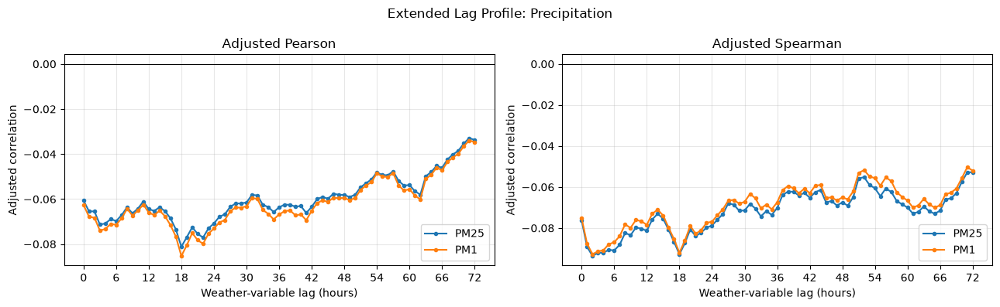


Selected lag values:


,Variable,Pollutant,Lag_Hours,N,Adjusted_Pearson,Adjusted_Spearman
0,precipitation,PM25,0,10981,-0.061,-0.076
1,precipitation,PM25,2,10862,-0.065,-0.094
2,precipitation,PM25,6,10774,-0.070,-0.091
3,precipitation,PM25,12,10727,-0.064,-0.081
4,precipitation,PM25,18,10686,-0.081,-0.093
5,precipitation,PM25,24,10659,-0.071,-0.079
6,precipitation,PM25,30,10628,-0.061,-0.071
7,precipitation,PM25,36,10597,-0.064,-0.070
8,precipitation,PM25,48,10549,-0.058,-0.067
9,precipitation,PM25,60,10523,-0.054,-0.070



CLOUD_COVER — PM25
Strongest adjusted Spearman: lag 69 h, r = -0.128
Adjusted Pearson range: -0.142 to -0.075
Adjusted Spearman range: -0.128 to -0.061

CLOUD_COVER — PM1
Strongest adjusted Spearman: lag 51 h, r = -0.134
Adjusted Pearson range: -0.153 to -0.088
Adjusted Spearman range: -0.134 to -0.070


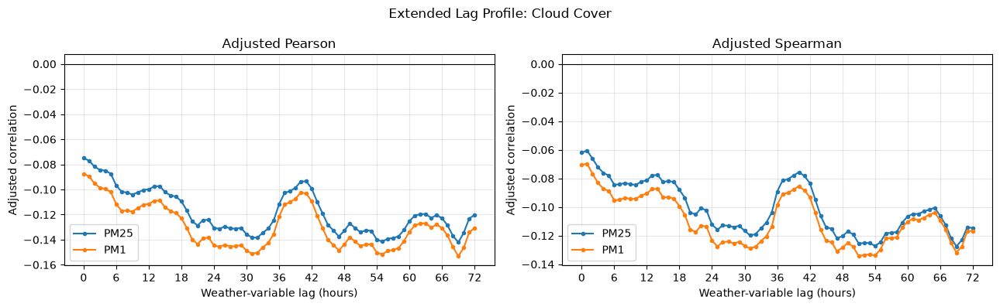


Selected lag values:


,Variable,Pollutant,Lag_Hours,N,Adjusted_Pearson,Adjusted_Spearman
0,cloud_cover,PM25,0,10981,-0.075,-0.062
1,cloud_cover,PM25,2,10862,-0.082,-0.066
2,cloud_cover,PM25,6,10774,-0.097,-0.084
3,cloud_cover,PM25,12,10727,-0.100,-0.081
4,cloud_cover,PM25,18,10686,-0.109,-0.088
5,cloud_cover,PM25,24,10659,-0.131,-0.112
6,cloud_cover,PM25,30,10628,-0.136,-0.117
7,cloud_cover,PM25,36,10597,-0.112,-0.089
8,cloud_cover,PM25,48,10549,-0.133,-0.120
9,cloud_cover,PM25,60,10523,-0.125,-0.107


In [186]:
for variable in ["precipitation", "cloud_cover"]:

    fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharex=True)

    for pollutant in ["PM25", "PM1"]:

        subset = extended_lag_correlations[
            (extended_lag_correlations["Variable"] == variable) &
            (extended_lag_correlations["Pollutant"] == pollutant)
        ].sort_values("Lag_Hours")

        axes[0].plot(
            subset["Lag_Hours"], subset["Adjusted_Pearson"],
            marker="o", markersize=3, label=pollutant
        )
        axes[1].plot(
            subset["Lag_Hours"], subset["Adjusted_Spearman"],
            marker="o", markersize=3, label=pollutant
        )

        peak = subset.loc[
            subset["Adjusted_Spearman"].abs().idxmax()
        ]

        print(f"\n{variable.upper()} — {pollutant}")
        print(
            f"Strongest adjusted Spearman: "
            f"lag {int(peak['Lag_Hours'])} h, "
            f"r = {peak['Adjusted_Spearman']:.3f}"
        )
        print(
            f"Adjusted Pearson range: "
            f"{subset['Adjusted_Pearson'].min():.3f} to "
            f"{subset['Adjusted_Pearson'].max():.3f}"
        )
        print(
            f"Adjusted Spearman range: "
            f"{subset['Adjusted_Spearman'].min():.3f} to "
            f"{subset['Adjusted_Spearman'].max():.3f}"
        )

    for ax, method in zip(
        axes, ["Adjusted Pearson", "Adjusted Spearman"]
    ):
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set_title(method)
        ax.set_xlabel("Weather-variable lag (hours)")
        ax.set_ylabel("Adjusted correlation")
        ax.set_xticks(range(0, 73, 6))
        ax.grid(alpha=0.3)
        ax.legend()

    fig.suptitle(f"Extended Lag Profile: {variable.replace('_', ' ').title()}")
    plt.tight_layout()
    plt.show()

    print("\nSelected lag values:")
    display(
        extended_lag_correlations[
            (extended_lag_correlations["Variable"] == variable) &
            (extended_lag_correlations["Lag_Hours"].isin(
                [0, 2, 6, 12, 18, 24, 30, 36, 48, 60, 72]
            ))
        ].round(3).reset_index(drop=True)
    )

Calculating Partial Correlations

In [187]:
partial_results = []

selected_lags = [0, 2, 6, 12, 18, 24, 30, 36, 48, 51, 60, 69, 72]

for variable in ["precipitation", "cloud_cover"]:

    weather = lag_data[variable]
    weather_baseline = weather.groupby(
        [weather.index.month, weather.index.hour]
    ).transform("mean")
    weather_residual = weather - weather_baseline

    for pollutant in ["pm25", "pm1"]:

        pollution = lag_data[pollutant]
        pollution_baseline = pollution.groupby(
            [pollution.index.month, pollution.index.hour]
        ).transform("mean")
        pollution_residual = pollution - pollution_baseline

        # Control variable: pollutant concentration one hour earlier
        previous_pollution = pollution_residual.shift(1)

        for lag in selected_lags:

            temp = pd.DataFrame({
                "Y": pollution_residual,
                "X": weather_residual.shift(lag),
                "Control": previous_pollution
            }).dropna()

            # Regress X and Y separately on the control variable
            z = np.column_stack([
                np.ones(len(temp)),
                temp["Control"].to_numpy()
            ])

            y_resid = (
                temp["Y"].to_numpy() -
                z @ np.linalg.lstsq(
                    z, temp["Y"].to_numpy(), rcond=None
                )[0]
            )

            x_resid = (
                temp["X"].to_numpy() -
                z @ np.linalg.lstsq(
                    z, temp["X"].to_numpy(), rcond=None
                )[0]
            )

            partial_r = np.corrcoef(x_resid, y_resid)[0, 1]

            partial_results.append({
                "Variable": variable,
                "Pollutant": pollutant.upper(),
                "Lag_Hours": lag,
                "N": len(temp),
                "Adjusted_Spearman": extended_lag_correlations.loc[
                    (extended_lag_correlations["Variable"] == variable) &
                    (extended_lag_correlations["Pollutant"] == pollutant.upper()) &
                    (extended_lag_correlations["Lag_Hours"] == lag),
                    "Adjusted_Spearman"
                ].iloc[0],
                "Partial_Pearson_Control_PM1h": partial_r
            })

partial_lag_results = pd.DataFrame(partial_results)

display(partial_lag_results.round(3))

,Variable,Pollutant,Lag_Hours,N,Adjusted_Spearman,Partial_Pearson_Control_PM1h
0,precipitation,PM25,0,10896,-0.076,-0.017
1,precipitation,PM25,2,10815,-0.094,-0.022
2,precipitation,PM25,6,10706,-0.091,-0.022
3,precipitation,PM25,12,10653,-0.081,-0.023
4,precipitation,PM25,18,10614,-0.093,-0.036
5,precipitation,PM25,24,10584,-0.079,-0.018
6,precipitation,PM25,30,10553,-0.071,-0.018
7,precipitation,PM25,36,10523,-0.070,-0.015
8,precipitation,PM25,48,10472,-0.067,-0.016
9,precipitation,PM25,51,10464,-0.056,-0.011


In [188]:
for pollutant in ["pm25", "pm1"]:

    pollution = lag_data[pollutant]
    baseline = pollution.groupby(
        [pollution.index.month, pollution.index.hour]
    ).transform("mean")

    residual = pollution - baseline

    print(f"\n{pollutant.upper()} temporal autocorrelation")

    for lag in [1, 2, 6, 12, 24, 48, 72]:
        print(f"Lag {lag:>2} h: {residual.autocorr(lag=lag):.3f}")

print("\nPartial-correlation comparison:")
display(
    partial_lag_results.pivot_table(
        index=["Variable", "Pollutant"],
        columns="Lag_Hours",
        values="Partial_Pearson_Control_PM1h"
    ).round(3)
)


PM25 temporal autocorrelation
Lag  1 h: 0.842
Lag  2 h: 0.713
Lag  6 h: 0.540
Lag 12 h: 0.453
Lag 24 h: 0.382
Lag 48 h: 0.204
Lag 72 h: 0.100

PM1 temporal autocorrelation
Lag  1 h: 0.846
Lag  2 h: 0.712
Lag  6 h: 0.517
Lag 12 h: 0.435
Lag 24 h: 0.377
Lag 48 h: 0.195
Lag 72 h: 0.079

Partial-correlation comparison:


Lag_Hours                   0      2      6      12     18     24     30  \
Variable      Pollutant                                                    
cloud_cover   PM1       -0.032 -0.040 -0.048 -0.032 -0.044 -0.052 -0.052   
              PM25      -0.030 -0.034 -0.044 -0.030 -0.040 -0.048 -0.049   
precipitation PM1       -0.017 -0.023 -0.021 -0.024 -0.038 -0.018 -0.018   
              PM25      -0.017 -0.022 -0.022 -0.023 -0.036 -0.018 -0.018   

Lag_Hours                   36     48     51     60     69     72  
Variable      Pollutant                                            
cloud_cover   PM1       -0.019 -0.035 -0.052 -0.030 -0.057 -0.034  
              PM25      -0.018 -0.032 -0.048 -0.029 -0.051 -0.033  
precipitation PM1       -0.015 -0.016 -0.011 -0.014 -0.011 -0.010  
              PM25      -0.015 -0.016 -0.011 -0.015 -0.011 -0.010

Correct Temporal Alignment

In [189]:
# Complete hourly index, including timestamps missing from the sensor dataset
full_index = pd.date_range(
    start=temporal.index.min(),
    end=temporal.index.max(),
    freq="h"
)

weather_columns = [
    "temperature",
    "temperature_2m",
    "precipitation",
    "rain",
    "cloud_cover",
    "wind_gusts_10m",
    "shortwave_radiation",
    "terrestrial_radiation"
]

# Reindex weather independently of pollutant availability
weather_full = temporal[weather_columns].reindex(full_index).copy()

# Attach pollutant observations only after constructing the complete timeline
analysis_data = weather_full.copy()

analysis_data["pm25"] = temporal["pm25"].reindex(full_index)
analysis_data["pm1"] = temporal["pm1"].reindex(full_index)

# Attach particle count from the original Hadigaun dataset
particle_data = hadigaun.copy()
particle_data["datetime"] = pd.to_datetime(particle_data["datetime"])
particle_data = particle_data.set_index("datetime").sort_index()

analysis_data["particle_count_03um"] = (
    particle_data["particle_count_03um"].reindex(full_index)
)

# Monthly temperature anomaly using the co-located station temperature
monthly_temperature_mean = (
    analysis_data["temperature"]
    .groupby(analysis_data.index.month)
    .transform("mean")
)

analysis_data["relative_temperature"] = (
    analysis_data["temperature"] - monthly_temperature_mean
)

# Short-term temperature changes
analysis_data["temperature_change_1h"] = (
    analysis_data["temperature"].diff(1)
)

analysis_data["temperature_change_3h"] = (
    analysis_data["temperature"] - analysis_data["temperature"].shift(3)
)

# Solar radiation indicators
analysis_data["radiation_deficit"] = (
    analysis_data["terrestrial_radiation"]
    - analysis_data["shortwave_radiation"]
)

analysis_data["radiation_transmission"] = np.where(
    analysis_data["terrestrial_radiation"] > 0,
    (
        analysis_data["shortwave_radiation"]
        / analysis_data["terrestrial_radiation"]
    ) * 100,
    np.nan
)

# Primary clear-hour definition for radiation lag analysis
analysis_data["clear_hour"] = (
    (analysis_data["cloud_cover"] < 20)
    & (analysis_data["terrestrial_radiation"] > 50)
)

analysis_data["clear_radiation_transmission"] = (
    analysis_data["radiation_transmission"]
    .where(analysis_data["clear_hour"])
)

analysis_data["clear_radiation_deficit"] = (
    analysis_data["radiation_deficit"]
    .where(analysis_data["clear_hour"])
)

# Report dataset dimensions and missingness
print("Complete hourly timeline:", len(analysis_data))
print("Available sensor observations:", analysis_data["pm25"].notna().sum())
print("Missing PM2.5 observations:", analysis_data["pm25"].isna().sum())

print("\nMissing observations by variable:")
display(
    analysis_data.isna()
    .sum()
    .to_frame("Missing_Count")
    .assign(
        Missing_Percent=lambda x:
        (x["Missing_Count"] / len(analysis_data) * 100).round(2)
    )
)

print("\nRadiation analysis coverage:")
print("Clear-hour observations:", analysis_data["clear_hour"].sum())
print(
    "Clear-hour transmission observations:",
    analysis_data["clear_radiation_transmission"].notna().sum()
)

print("\nTemperature anomaly summary:")
display(
    analysis_data[
        ["temperature", "relative_temperature",
         "temperature_change_1h", "temperature_change_3h"]
    ].describe().round(3)
)

Complete hourly timeline: 11409
Available sensor observations: 10981
Missing PM2.5 observations: 428

Missing observations by variable:


,Missing_Count,Missing_Percent
temperature,428,3.75
temperature_2m,428,3.75
precipitation,428,3.75
rain,428,3.75
cloud_cover,428,3.75
wind_gusts_10m,428,3.75
shortwave_radiation,428,3.75
terrestrial_radiation,428,3.75
pm25,428,3.75
pm1,428,3.75



Radiation analysis coverage:
Clear-hour observations: 1268
Clear-hour transmission observations: 1268

Temperature anomaly summary:


,temperature,relative_temperature,temperature_change_1h,temperature_change_3h
count,10981.000,10981.000,10896.000,10828.000
mean,23.002,-0.000,0.008,0.002
std,5.609,3.941,1.514,3.583
min,8.178,-10.728,-9.800,-17.000
25%,19.594,-2.906,-0.684,-1.999
50%,23.678,-1.010,-0.200,-0.680
75%,26.503,3.092,0.469,1.075
max,38.013,11.738,5.967,12.500


In [193]:
DATASET_DIR = Path(r'D:/MSDSA/4th Sem/Thesis/Dataset')
weather_raw = pd.read_csv(DATASET_DIR / "weather_data_hadigaun.csv", parse_dates=["datetime"])

In [194]:
print("Shape:", weather_raw.shape)
print("\nColumns:")
print(weather_raw.columns.tolist())

print("\nFirst five rows:")
display(weather_raw.head())

print("\nData types:")
print(weather_raw.dtypes)

Shape: (11736, 21)

Columns:
['datetime', 'temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'precipitation', 'rain', 'wind_speed_10m', 'wind_direction_10m', 'wind_gusts_10m', 'surface_pressure', 'pressure_msl', 'cloud_cover', 'cloud_cover_low', 'cloud_cover_mid', 'cloud_cover_high', 'boundary_layer_height', 'shortwave_radiation', 'direct_radiation', 'diffuse_radiation', 'terrestrial_radiation', 'sunshine_duration']

First five rows:


,datetime,temperature_2m,relative_humidity_2m,dew_point_2m,precipitation,rain,wind_speed_10m,wind_direction_10m,wind_gusts_10m,surface_pressure,...,cloud_cover,cloud_cover_low,cloud_cover_mid,cloud_cover_high,boundary_layer_height,shortwave_radiation,direct_radiation,diffuse_radiation,terrestrial_radiation,sunshine_duration
0,2025-06-30 00:00:00+00:00,20.3,98,19.9,0.0,0.0,0.05,180,1.7,861.4,...,96,20,6,95,10.0,6,0,6,32.7,0.00
1,2025-06-30 01:00:00+00:00,21.8,96,21.0,0.0,0.0,0.35,352,3.3,862.7,...,100,27,81,100,100.0,107,36,71,275.9,3379.89
2,2025-06-30 02:00:00+00:00,22.3,95,21.5,0.1,0.1,0.72,56,3.6,863.5,...,100,99,26,98,230.0,173,71,102,552.6,3300.19
3,2025-06-30 03:00:00+00:00,23.4,88,21.4,0.0,0.0,0.61,9,3.9,863.8,...,100,56,46,99,405.0,265,82,183,808.2,2227.79
4,2025-06-30 04:00:00+00:00,24.0,85,21.3,0.0,0.0,0.50,6,3.6,864.3,...,100,41,45,100,540.0,235,26,209,1025.1,0.00



Data types:
datetime                 datetime64[us, UTC]
temperature_2m                       float64
relative_humidity_2m                   int64
dew_point_2m                         float64
precipitation                        float64
rain                                 float64
wind_speed_10m                       float64
wind_direction_10m                     int64
wind_gusts_10m                       float64
surface_pressure                     float64
pressure_msl                         float64
cloud_cover                            int64
cloud_cover_low                        int64
cloud_cover_mid                        int64
cloud_cover_high                       int64
boundary_layer_height                float64
shortwave_radiation                    int64
direct_radiation                       int64
diffuse_radiation                      int64
terrestrial_radiation                float64
sunshine_duration                    float64
dtype: object


In [196]:
# Parse and convert original weather timestamps to Nepal Time
weather_raw["datetime"] = pd.to_datetime(
    weather_raw["datetime"], utc=True
)

weather_raw = weather_raw.sort_values("datetime").copy()

weather_raw["datetime_npt"] = (
    weather_raw["datetime"].dt.tz_convert("Asia/Kathmandu")
)

weather_index = pd.DatetimeIndex(
    weather_raw["datetime_npt"]
)

print("Original weather dataset")
print("Rows:", len(weather_raw))
print("First UTC timestamp:", weather_raw["datetime"].min())
print("Last UTC timestamp:", weather_raw["datetime"].max())
print("First NPT timestamp:", weather_index.min())
print("Last NPT timestamp:", weather_index.max())
print("Duplicate timestamps:", weather_index.duplicated().sum())

# Check hourly intervals
print("\nWeather timestamp intervals:")
display(weather_index.to_series().diff().value_counts().head(10))

# Check missing values in original weather variables
weather_variables = [
    col for col in weather_raw.columns
    if col not in ["datetime", "datetime_npt"]
]

display(
    weather_raw[weather_variables]
    .isna()
    .sum()
    .to_frame("Missing_Count")
)

# Compare with the Hadigaun sensor timeline
sensor_index = pd.DatetimeIndex(temporal.index)

print("\nSensor and weather coverage comparison")
print("Sensor start:", sensor_index.min())
print("Sensor end:", sensor_index.max())
print("Weather start:", weather_index.min())
print("Weather end:", weather_index.max())

print(
    "Sensor timestamps covered by weather:",
    sensor_index.isin(weather_index).sum(),
    "/",
    len(sensor_index)
)

print(
    "Weather timestamps within sensor period:",
    weather_index.isin(
        pd.date_range(
            sensor_index.min(),
            sensor_index.max(),
            freq="h"
        )
    ).sum()
)

Original weather dataset
Rows: 11736
First UTC timestamp: 2025-06-30 00:00:00+00:00
Last UTC timestamp: 2026-10-31 23:00:00+00:00
First NPT timestamp: 2025-06-30 05:45:00+05:45
Last NPT timestamp: 2026-11-01 04:45:00+05:45
Duplicate timestamps: 0

Weather timestamp intervals:


datetime_npt
0 days 01:00:00    11735
Name: count, dtype: int64

,Missing_Count
temperature_2m,0
relative_humidity_2m,0
dew_point_2m,0
precipitation,0
rain,0
wind_speed_10m,0
wind_direction_10m,0
wind_gusts_10m,0
surface_pressure,0
pressure_msl,0



Sensor and weather coverage comparison
Sensor start: 2025-07-01 00:45:00+05:45
Sensor end: 2026-10-19 08:45:00+05:45
Weather start: 2025-06-30 05:45:00+05:45
Weather end: 2026-11-01 04:45:00+05:45
Sensor timestamps covered by weather: 10981 / 10981
Weather timestamps within sensor period: 11409


In [ ]:
# Original weather series, indexed in Nepal Time
weather_source = (
    weather_raw
    .set_index("datetime_npt")
    .drop(columns=["datetime"])
    .sort_index()
    .copy()
)

# Keep all original weather observations, including the 72-hour margins
analysis_data = weather_source.copy()

# Attach Hadigaun sensor observations
sensor_variables = [
    "pm25",
    "pm1",
    "temperature",
    "relative_humidity"
]

sensor_data = temporal[sensor_variables].copy()

analysis_data = analysis_data.join(
    sensor_data,
    how="left"
)

# Attach particle count
particle_data = hadigaun.copy()
particle_data["datetime"] = pd.to_datetime(particle_data["datetime"])
particle_data = (
    particle_data
    .set_index("datetime")
    .sort_index()
)

analysis_data["particle_count_03um"] = (
    particle_data["particle_count_03um"]
)

# Monthly temperature anomalies
# Station temperature: primary co-located measurement
station_monthly_baseline = (
    analysis_data["temperature"]
    .groupby(analysis_data.index.month)
    .transform("mean")
)

analysis_data["relative_temperature"] = (
    analysis_data["temperature"] - station_monthly_baseline
)

# Open-Meteo temperature: supplementary model-derived measurement
met_monthly_baseline = (
    analysis_data["temperature_2m"]
    .groupby(analysis_data.index.month)
    .transform("mean")
)

analysis_data["relative_temperature_2m"] = (
    analysis_data["temperature_2m"] - met_monthly_baseline
)

# Short-term station temperature changes
analysis_data["temperature_change_1h"] = (
    analysis_data["temperature"].diff(1)
)

analysis_data["temperature_change_3h"] = (
    analysis_data["temperature"] -
    analysis_data["temperature"].shift(3)
)

# Short-term Open-Meteo temperature changes
analysis_data["temperature_2m_change_1h"] = (
    analysis_data["temperature_2m"].diff(1)
)

analysis_data["temperature_2m_change_3h"] = (
    analysis_data["temperature_2m"] -
    analysis_data["temperature_2m"].shift(3)
)

# Radiation indicators
analysis_data["radiation_deficit"] = (
    analysis_data["terrestrial_radiation"]
    - analysis_data["shortwave_radiation"]
)

analysis_data["radiation_transmission"] = np.where(
    analysis_data["terrestrial_radiation"] > 0,
    (
        analysis_data["shortwave_radiation"]
        / analysis_data["terrestrial_radiation"]
    ) * 100,
    np.nan
)

# Clear-hour radiation indicators
analysis_data["clear_hour"] = (
    (analysis_data["cloud_cover"] < 20)
    & (analysis_data["terrestrial_radiation"] > 50)
)

analysis_data["clear_radiation_transmission"] = (
    analysis_data["radiation_transmission"]
    .where(analysis_data["clear_hour"])
)

analysis_data["clear_radiation_deficit"] = (
    analysis_data["radiation_deficit"]
    .where(analysis_data["clear_hour"])
)

# Verify the rebuilt dataset
print("Rebuilt analysis dataset:", analysis_data.shape)
print("Start:", analysis_data.index.min())
print("End:", analysis_data.index.max())
print("Duplicate timestamps:", analysis_data.index.duplicated().sum())

print("\nMissing observations:")
display(
    analysis_data.isna().sum()
    .to_frame("Missing_Count")
    .assign(
        Missing_Percent=lambda x:
        (x["Missing_Count"] / len(analysis_data) * 100).round(2)
    )
)

print("\nSensor coverage:")
print("PM2.5:", analysis_data["pm25"].notna().sum())
print("PM1:", analysis_data["pm1"].notna().sum())
print("Station temperature:", analysis_data["temperature"].notna().sum())
print("Particle count:", analysis_data["particle_count_03um"].notna().sum())

print("\nWeather coverage:")
print("Precipitation:", analysis_data["precipitation"].notna().sum())
print("Cloud cover:", analysis_data["cloud_cover"].notna().sum())
print("Wind gusts:", analysis_data["wind_gusts_10m"].notna().sum())
print("Radiation:", analysis_data["shortwave_radiation"].notna().sum())
print("Boundary layer height:", analysis_data["boundary_layer_height"].notna().sum())

print("\nClear-hour observations:", analysis_data["clear_hour"].sum())

Rebuilt analysis dataset: (11736, 36)
Start: 2025-06-30 00:00:00+00:00
End: 2026-10-31 23:00:00+00:00
Duplicate timestamps: 0

Missing observations:


,Missing_Count,Missing_Percent
temperature_2m,0,0.00
relative_humidity_2m,0,0.00
dew_point_2m,0,0.00
precipitation,0,0.00
rain,0,0.00
wind_speed_10m,0,0.00
wind_direction_10m,0,0.00
wind_gusts_10m,0,0.00
surface_pressure,0,0.00
pressure_msl,0,0.00



Sensor coverage:
PM2.5: 10981
PM1: 10981
Station temperature: 10981
Particle count: 10981

Weather coverage:
Precipitation: 11736
Cloud cover: 11736
Wind gusts: 11736
Radiation: 11736
Boundary layer height: 11244

Clear-hour observations: 1398


In [198]:
# Convert the complete analysis timeline to Nepal Time
analysis_data.index = analysis_data.index.tz_convert("Asia/Kathmandu")
analysis_data.index.name = "datetime"

# Recalculate monthly temperature anomalies using Nepal calendar months
station_monthly_baseline = (
    analysis_data["temperature"]
    .groupby(analysis_data.index.month)
    .transform("mean")
)

analysis_data["relative_temperature"] = (
    analysis_data["temperature"] - station_monthly_baseline
)

met_monthly_baseline = (
    analysis_data["temperature_2m"]
    .groupby(analysis_data.index.month)
    .transform("mean")
)

analysis_data["relative_temperature_2m"] = (
    analysis_data["temperature_2m"] - met_monthly_baseline
)

# Verify timezone and alignment
print("Index timezone:", analysis_data.index.tz)
print("Start:", analysis_data.index.min())
print("End:", analysis_data.index.max())

print("\nSensor and weather alignment:")
print("Matched PM2.5 observations:",
      analysis_data["pm25"].notna().sum())

print("Weather-only timestamps:",
      analysis_data["pm25"].isna().sum())

print("\nFirst five sensor observations:")
display(
    analysis_data.loc[
        analysis_data["pm25"].notna(),
        ["pm25", "pm1", "precipitation", "cloud_cover"]
    ].head()
)

print("\nTemperature anomaly summary:")
display(
    analysis_data[
        ["relative_temperature", "relative_temperature_2m"]
    ].describe().round(3)
)

Index timezone: Asia/Kathmandu
Start: 2025-06-30 05:45:00+05:45
End: 2026-11-01 04:45:00+05:45

Sensor and weather alignment:
Matched PM2.5 observations: 10981
Weather-only timestamps: 755

First five sensor observations:


,pm25,pm1,precipitation,cloud_cover
datetime,,,,
2025-07-01 00:45:00+05:45,13.717708,9.164286,1.2,100
2025-07-01 01:45:00+05:45,11.052827,7.255308,0.5,100
2025-07-01 02:45:00+05:45,9.482589,6.263244,0.2,98
2025-07-01 03:45:00+05:45,10.492857,6.811310,0.0,93
2025-07-01 04:45:00+05:45,23.859673,16.167559,0.0,90



Temperature anomaly summary:


,relative_temperature,relative_temperature_2m
count,10981.000,11736.000
mean,-0.000,-0.000
std,3.941,3.273
min,-10.728,-10.742
25%,-2.906,-2.332
50%,-1.010,-0.642
75%,3.092,2.432
max,11.738,10.058


In [199]:

particulate = analysis_data[
    ["pm25", "pm1", "particle_count_03um"]
].dropna().copy()

# Ratios
particulate["PM1_PM25_Ratio"] = (
    particulate["pm1"] / particulate["pm25"]
)

particulate["ParticleCount_PM25_Ratio"] = (
    particulate["particle_count_03um"] / particulate["pm25"]
)

# Correlations before temporal adjustment
variables = ["pm25", "pm1", "particle_count_03um"]

raw_correlations = []

for i, var1 in enumerate(variables):
    for var2 in variables[i + 1:]:
        raw_correlations.append({
            "Variable_1": var1,
            "Variable_2": var2,
            "N": particulate[[var1, var2]].dropna().shape[0],
            "Pearson": particulate[var1].corr(
                particulate[var2], method="pearson"
            ),
            "Spearman": particulate[var1].corr(
                particulate[var2], method="spearman"
            )
        })

raw_correlation_table = pd.DataFrame(raw_correlations)

# Month-adjusted and month-hour-adjusted correlations
adjusted_results = []

for var1, var2 in [
    ("pm25", "pm1"),
    ("pm25", "particle_count_03um"),
    ("pm1", "particle_count_03um")
]:
    pair = particulate[[var1, var2]].copy()

    month_baseline_1 = pair[var1].groupby(
        pair.index.month
    ).transform("mean")

    month_baseline_2 = pair[var2].groupby(
        pair.index.month
    ).transform("mean")

    month_residual_1 = pair[var1] - month_baseline_1
    month_residual_2 = pair[var2] - month_baseline_2

    month_hour_groups = [
        pair.index.month,
        pair.index.hour
    ]

    month_hour_baseline_1 = pair[var1].groupby(
        month_hour_groups
    ).transform("mean")

    month_hour_baseline_2 = pair[var2].groupby(
        month_hour_groups
    ).transform("mean")

    month_hour_residual_1 = pair[var1] - month_hour_baseline_1
    month_hour_residual_2 = pair[var2] - month_hour_baseline_2

    adjusted_results.append({
        "Variable_1": var1,
        "Variable_2": var2,
        "N": len(pair),
        "Month_Pearson": month_residual_1.corr(month_residual_2),
        "Month_Spearman": month_residual_1.corr(
            month_residual_2, method="spearman"
        ),
        "Month_Hour_Pearson": month_hour_residual_1.corr(
            month_hour_residual_2
        ),
        "Month_Hour_Spearman": month_hour_residual_1.corr(
            month_hour_residual_2, method="spearman"
        )
    })

adjusted_correlation_table = pd.DataFrame(adjusted_results)

# Ratio summaries
ratio_summary = particulate[
    ["PM1_PM25_Ratio", "ParticleCount_PM25_Ratio"]
].describe(
    percentiles=[0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

# PM1 <= PM2.5 validation
pm1_exceeds_pm25 = (
    particulate["pm1"] > particulate["pm25"]
).sum()

# Monthly ratio variation
monthly_ratios = (
    particulate.groupby(particulate.index.to_period("M"))
    .agg(
        N=("PM1_PM25_Ratio", "count"),
        PM1_PM25_Mean=("PM1_PM25_Ratio", "mean"),
        PM1_PM25_Median=("PM1_PM25_Ratio", "median"),
        ParticleCount_PM25_Mean=("ParticleCount_PM25_Ratio", "mean"),
        ParticleCount_PM25_Median=("ParticleCount_PM25_Ratio", "median")
    )
)

print("Particulate observations:", len(particulate))
print("PM1 exceeds PM2.5:", pm1_exceeds_pm25)
print(
    "Percentage where PM1 <= PM2.5:",
    round((1 - pm1_exceeds_pm25 / len(particulate)) * 100, 3)
)

print("\nRaw correlations:")
display(raw_correlation_table.round(4))

print("\nTemporally adjusted correlations:")
display(adjusted_correlation_table.round(4))

print("\nRatio distributions:")
display(ratio_summary.round(4))

print("\nMonthly ratio variation:")
display(monthly_ratios.round(4))

Particulate observations: 10981
PM1 exceeds PM2.5: 0
Percentage where PM1 <= PM2.5: 100.0

Raw correlations:


C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\3082101226.py:104: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  particulate.groupby(particulate.index.to_period("M"))


,Variable_1,Variable_2,N,Pearson,Spearman
0,pm25,pm1,10981,0.9964,0.9986
1,pm25,particle_count_03um,10981,0.9932,0.9979
2,pm1,particle_count_03um,10981,0.9944,0.9993



Temporally adjusted correlations:


,Variable_1,Variable_2,N,Month_Pearson,Month_Spearman,Month_Hour_Pearson,Month_Hour_Spearman
0,pm25,pm1,10981,0.9936,0.9949,0.9904,0.9925
1,pm25,particle_count_03um,10981,0.9869,0.9849,0.9822,0.9819
2,pm1,particle_count_03um,10981,0.9896,0.9875,0.9867,0.9870



Ratio distributions:


,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
PM1_PM25_Ratio,10981.0,0.6426,0.0354,0.3000,0.5863,0.6215,0.6399,0.6620,0.7065,0.7297,0.7647
ParticleCount_PM25_Ratio,10981.0,143.0991,19.9312,100.5723,120.1490,129.5015,141.3836,154.3952,168.2279,191.9189,758.9231



Monthly ratio variation:


,N,PM1_PM25_Mean,PM1_PM25_Median,ParticleCount_PM25_Mean,ParticleCount_PM25_Median
datetime,,,,,
2025-07,742,0.6701,0.6732,138.0380,134.7968
2025-08,724,0.6600,0.6622,134.5626,131.3788
2025-09,680,0.6529,0.6524,132.5502,130.4526
2025-10,691,0.6388,0.6352,140.5520,135.2156
2025-11,692,0.6440,0.6431,146.2765,146.5666
2025-12,736,0.6406,0.6418,157.1235,159.9622
2026-01,734,0.6269,0.6289,151.9206,154.1673
2026-02,670,0.6031,0.6028,151.1536,152.5315
2026-03,738,0.6061,0.6111,146.2000,148.9058


In [200]:
# 4.8.3 — Temperature lag profiles: -24 to +72 hours

temperature_variables = [
    "relative_temperature",
    "relative_temperature_2m",
    "temperature_change_1h",
    "temperature_change_3h",
    "temperature_2m_change_1h",
    "temperature_2m_change_3h"
]

pollutants = ["pm25", "pm1"]
lag_range = range(-24, 73)

temperature_lag_results = []

for variable in temperature_variables:

    weather = analysis_data[variable]

    # Calculate month-hour baseline at the original weather timestamp
    weather_baseline = weather.groupby(
        [weather.index.month, weather.index.hour]
    ).transform("mean")

    weather_residual = weather - weather_baseline

    for pollutant in pollutants:

        pollution = analysis_data[pollutant]

        # Calculate pollutant baseline at its target timestamp
        pollution_baseline = pollution.groupby(
            [pollution.index.month, pollution.index.hour]
        ).transform("mean")

        pollution_residual = pollution - pollution_baseline

        for lag in lag_range:

            # Positive lag: weather precedes pollution
            # Negative lag: pollution precedes weather
            weather_lagged = weather.shift(lag)
            weather_residual_lagged = weather_residual.shift(lag)

            pair = pd.DataFrame({
                "Pollution": pollution,
                "Weather": weather_lagged,
                "Pollution_Residual": pollution_residual,
                "Weather_Residual": weather_residual_lagged
            }).dropna()

            if len(pair) < 100:
                continue

            temperature_lag_results.append({
                "Variable": variable,
                "Pollutant": pollutant,
                "Lag_Hours": lag,
                "N": len(pair),
                "Raw_Pearson": pair["Pollution"].corr(
                    pair["Weather"]
                ),
                "Raw_Spearman": pair["Pollution"].corr(
                    pair["Weather"], method="spearman"
                ),
                "Adjusted_Pearson": pair["Pollution_Residual"].corr(
                    pair["Weather_Residual"]
                ),
                "Adjusted_Spearman": pair["Pollution_Residual"].corr(
                    pair["Weather_Residual"], method="spearman"
                )
            })

temperature_lag_results = pd.DataFrame(temperature_lag_results)

print("Lag result dimensions:", temperature_lag_results.shape)
print("Variables:", temperature_lag_results["Variable"].nunique())
print("Pollutants:", temperature_lag_results["Pollutant"].nunique())
print("Lag range:",
      temperature_lag_results["Lag_Hours"].min(),
      "to",
      temperature_lag_results["Lag_Hours"].max())

# Show selected lags for comparison
selected_lags = [-24, -12, -6, -3, -1, 0, 1, 2, 3, 6, 12, 18, 24, 36, 48, 60, 72]

temperature_selected = temperature_lag_results[
    temperature_lag_results["Lag_Hours"].isin(selected_lags)
].copy()

display(
    temperature_selected.round(4)
)

Lag result dimensions: (1164, 8)
Variables: 6
Pollutants: 2
Lag range: -24 to 72


,Variable,Pollutant,Lag_Hours,N,Raw_Pearson,Raw_Spearman,Adjusted_Pearson,Adjusted_Spearman
0,relative_temperature,pm25,-24,10659,-0.1345,-0.1196,0.0772,0.0707
12,relative_temperature,pm25,-12,10727,0.0509,0.0564,0.1354,0.1247
18,relative_temperature,pm25,-6,10774,0.2320,0.1074,0.1271,0.1234
21,relative_temperature,pm25,-3,10828,0.1545,0.0609,0.1231,0.1317
23,relative_temperature,pm25,-1,10896,-0.0366,-0.0363,0.0942,0.1191
...,...,...,...,...,...,...,...,...
1115,temperature_2m_change_3h,pm1,24,10973,0.1732,0.0438,0.0205,0.0075
1127,temperature_2m_change_3h,pm1,36,10961,-0.0841,-0.1129,0.0104,-0.0132
1139,temperature_2m_change_3h,pm1,48,10949,0.1734,0.0422,0.0111,-0.0111
1151,temperature_2m_change_3h,pm1,60,10937,-0.0858,-0.1104,-0.0024,-0.0177


In [201]:
# Summarize lag profiles without treating the maximum as a definitive response time

temperature_lag_summary = (
    temperature_lag_results
    .groupby(["Variable", "Pollutant"])
    .apply(
        lambda group: pd.Series({
            "N_at_0h": group.loc[
                group["Lag_Hours"] == 0, "N"
            ].iloc[0],
            "Adjusted_Pearson_at_0h": group.loc[
                group["Lag_Hours"] == 0, "Adjusted_Pearson"
            ].iloc[0],
            "Adjusted_Spearman_at_0h": group.loc[
                group["Lag_Hours"] == 0, "Adjusted_Spearman"
            ].iloc[0],
            "Minimum_Adjusted_Pearson": group["Adjusted_Pearson"].min(),
            "Lag_Min_Pearson": group.loc[
                group["Adjusted_Pearson"].idxmin(), "Lag_Hours"
            ],
            "Maximum_Adjusted_Pearson": group["Adjusted_Pearson"].max(),
            "Lag_Max_Pearson": group.loc[
                group["Adjusted_Pearson"].idxmax(), "Lag_Hours"
            ],
            "Minimum_Adjusted_Spearman": group["Adjusted_Spearman"].min(),
            "Lag_Min_Spearman": group.loc[
                group["Adjusted_Spearman"].idxmin(), "Lag_Hours"
            ],
            "Maximum_Adjusted_Spearman": group["Adjusted_Spearman"].max(),
            "Lag_Max_Spearman": group.loc[
                group["Adjusted_Spearman"].idxmax(), "Lag_Hours"
            ]
        }),
        include_groups=False
    )
    .reset_index()
)

display(temperature_lag_summary.round(4))

,Variable,Pollutant,N_at_0h,Adjusted_Pearson_at_0h,Adjusted_Spearman_at_0h,Minimum_Adjusted_Pearson,Lag_Min_Pearson,Maximum_Adjusted_Pearson,Lag_Max_Pearson,Minimum_Adjusted_Spearman,Lag_Min_Spearman,Maximum_Adjusted_Spearman,Lag_Max_Spearman
0,relative_temperature,pm1,10981.0,0.0573,0.0911,0.0018,72.0,0.1201,-10.0,-0.0331,72.0,0.1118,-11.0
1,relative_temperature,pm25,10981.0,0.0822,0.1119,0.0161,72.0,0.1365,-10.0,-0.0234,72.0,0.1317,-3.0
2,relative_temperature_2m,pm1,10981.0,0.0564,0.0184,-0.0297,72.0,0.1314,-8.0,-0.0719,65.0,0.0819,-8.0
3,relative_temperature_2m,pm25,10981.0,0.0753,0.0301,-0.0141,72.0,0.1452,-13.0,-0.0654,66.0,0.0884,-13.0
4,temperature_2m_change_1h,pm1,10981.0,0.0149,0.0006,-0.0158,-15.0,0.0353,-2.0,-0.0383,8.0,0.0231,-2.0
5,temperature_2m_change_1h,pm25,10981.0,0.0125,-0.0012,-0.0129,-15.0,0.0318,23.0,-0.0363,8.0,0.0195,-2.0
6,temperature_2m_change_3h,pm1,10981.0,-0.0035,-0.0070,-0.0235,-17.0,0.0589,22.0,-0.0405,7.0,0.0406,-3.0
7,temperature_2m_change_3h,pm25,10981.0,-0.0043,-0.0073,-0.0211,5.0,0.0532,22.0,-0.0376,7.0,0.0360,-3.0
8,temperature_change_1h,pm1,10896.0,-0.0067,-0.0162,-0.0223,7.0,0.0378,22.0,-0.0537,7.0,0.0174,23.0
9,temperature_change_1h,pm25,10896.0,-0.0062,-0.0181,-0.0193,7.0,0.0353,22.0,-0.0515,7.0,0.0162,23.0


In [202]:
# Inspect the extreme particle-count / PM2.5 ratio

ratio_check = particulate.nlargest(
    10, "ParticleCount_PM25_Ratio"
)[[
    "pm25",
    "pm1",
    "particle_count_03um",
    "PM1_PM25_Ratio",
    "ParticleCount_PM25_Ratio"
]]

display(ratio_check.round(3))

,pm25,pm1,particle_count_03um,PM1_PM25_Ratio,ParticleCount_PM25_Ratio
datetime,,,,,
2025-10-05 03:45:00+05:45,0.310,0.093,234.905,0.300,758.923
2025-10-05 04:45:00+05:45,0.388,0.129,250.372,0.333,646.037
2026-09-26 03:45:00+05:45,0.800,0.500,397.000,0.625,496.250
2026-09-25 04:45:00+05:45,0.800,0.500,367.000,0.625,458.750
2026-09-25 05:45:00+05:45,0.900,0.600,384.000,0.667,426.667
2025-10-05 02:45:00+05:45,0.815,0.444,310.369,0.545,380.599
2025-07-04 02:45:00+05:45,1.049,0.591,350.766,0.564,334.442
2026-09-26 04:45:00+05:45,1.500,1.100,494.000,0.733,329.333
2025-07-04 01:45:00+05:45,1.173,0.701,378.443,0.597,322.611


Temperature Lag Profiles

In [203]:
# Selected temperature lag profiles for detailed interpretation

selected_lags = [-24, -18, -12, -10, -6, -3, 0, 3, 6, 10, 12, 18, 24, 36, 48, 60, 72]

temperature_profile = temperature_lag_results[
    temperature_lag_results["Lag_Hours"].isin(selected_lags)
].copy()

for pollutant in ["pm25", "pm1"]:
    print(f"\n{pollutant.upper()} — adjusted Pearson")
    display(
        temperature_profile[
            temperature_profile["Pollutant"] == pollutant
        ].pivot(
            index="Lag_Hours",
            columns="Variable",
            values="Adjusted_Pearson"
        ).round(3)
    )

    print(f"\n{pollutant.upper()} — adjusted Spearman")
    display(
        temperature_profile[
            temperature_profile["Pollutant"] == pollutant
        ].pivot(
            index="Lag_Hours",
            columns="Variable",
            values="Adjusted_Spearman"
        ).round(3)
    )


PM25 — adjusted Pearson


Variable,relative_temperature,relative_temperature_2m,temperature_2m_change_1h,temperature_2m_change_3h,temperature_change_1h,temperature_change_3h
Lag_Hours,,,,,,
-24,0.077,0.115,0.004,-0.007,0.001,-0.005
-18,0.114,0.132,-0.006,-0.013,-0.018,-0.013
-12,0.135,0.144,0.003,0.004,-0.005,-0.002
-10,0.137,0.140,-0.002,-0.002,0.000,0.009
-6,0.127,0.134,0.016,0.034,-0.007,0.005
-3,0.123,0.109,0.024,0.046,0.023,0.045
0,0.082,0.075,0.012,-0.004,-0.006,-0.000
3,0.083,0.081,-0.007,-0.019,-0.014,-0.015
6,0.100,0.097,-0.010,-0.020,-0.012,-0.023



PM25 — adjusted Spearman


Variable,relative_temperature,relative_temperature_2m,temperature_2m_change_1h,temperature_2m_change_3h,temperature_change_1h,temperature_change_3h
Lag_Hours,,,,,,
-24,0.071,0.062,-0.012,-0.011,-0.005,-0.009
-18,0.103,0.066,-0.023,-0.027,-0.035,-0.029
-12,0.125,0.087,-0.003,-0.008,-0.016,-0.016
-10,0.125,0.082,-0.017,-0.020,-0.014,-0.005
-6,0.123,0.082,0.005,0.024,-0.012,-0.010
-3,0.132,0.065,0.013,0.036,0.007,0.012
0,0.112,0.030,-0.001,-0.007,-0.018,0.006
3,0.086,0.025,-0.023,-0.030,-0.025,-0.017
6,0.088,0.038,-0.024,-0.038,-0.043,-0.047



PM1 — adjusted Pearson


Variable,relative_temperature,relative_temperature_2m,temperature_2m_change_1h,temperature_2m_change_3h,temperature_change_1h,temperature_change_3h
Lag_Hours,,,,,,
-24,0.057,0.096,0.005,-0.006,0.002,-0.005
-18,0.095,0.113,-0.007,-0.018,-0.020,-0.016
-12,0.119,0.130,0.002,0.001,-0.005,-0.002
-10,0.120,0.127,-0.003,-0.004,0.000,0.009
-6,0.109,0.122,0.015,0.035,-0.006,0.007
-3,0.103,0.095,0.029,0.054,0.027,0.050
0,0.057,0.056,0.015,-0.003,-0.007,0.001
3,0.057,0.062,-0.008,-0.020,-0.012,-0.013
6,0.073,0.078,-0.009,-0.023,-0.014,-0.027



PM1 — adjusted Spearman


Variable,relative_temperature,relative_temperature_2m,temperature_2m_change_1h,temperature_2m_change_3h,temperature_change_1h,temperature_change_3h
Lag_Hours,,,,,,
-24,0.052,0.048,-0.012,-0.010,-0.003,-0.008
-18,0.086,0.053,-0.024,-0.031,-0.037,-0.032
-12,0.111,0.079,-0.004,-0.010,-0.015,-0.015
-10,0.111,0.075,-0.017,-0.020,-0.012,-0.002
-6,0.105,0.076,0.007,0.028,-0.009,-0.007
-3,0.111,0.057,0.016,0.041,0.009,0.012
0,0.091,0.018,0.001,-0.007,-0.016,0.009
3,0.063,0.014,-0.023,-0.029,-0.024,-0.018
6,0.066,0.026,-0.023,-0.039,-0.044,-0.049


Precipitation, Cumlative Rainfall, and Dry Spells Lag Association

In [204]:
# Work on the complete hourly weather timeline before matching to sensor observations
rain_data = analysis_data[[
    "precipitation", "rain"
]].copy().sort_index()

# Cumulative rainfall during the preceding hours, excluding the current hour
for window in [3, 6, 12, 24]:
    rain_data[f"precip_previous_{window}h"] = (
        rain_data["precipitation"]
        .shift(1)
        .rolling(window=window, min_periods=window)
        .sum()
    )

    rain_data[f"rain_previous_{window}h"] = (
        rain_data["rain"]
        .shift(1)
        .rolling(window=window, min_periods=window)
        .sum()
    )

# Define wet and dry hours using total precipitation
rain_data["wet_hour"] = rain_data["precipitation"] > 0.1
rain_data["dry_hour"] = ~rain_data["wet_hour"]

# Consecutive dry hours ending immediately before the current timestamp
dry_groups = (~rain_data["dry_hour"]).cumsum()
rain_data["dry_spell_hours"] = (
    rain_data["dry_hour"]
    .groupby(dry_groups)
    .cumsum()
    .shift(1)
    .fillna(0)
)

# Hours since the most recent wet hour, excluding the current hour
last_wet_time = pd.Series(
    rain_data.index.where(rain_data["wet_hour"]),
    index=rain_data.index
).ffill()

rain_data["hours_since_rain"] = (
    (rain_data.index.to_series() - last_wet_time)
    .dt.total_seconds() / 3600
)

# Attach the weather-derived variables to the sensor timeline
rain_columns = [
    f"{measure}_previous_{window}h"
    for measure in ["precip", "rain"]
    for window in [3, 6, 12, 24]
] + ["dry_spell_hours", "hours_since_rain"]

analysis_data[rain_columns] = rain_data[rain_columns]

In [205]:
rain_summary = analysis_data[rain_columns].describe(
    percentiles=[0.5, 0.75, 0.90, 0.95, 0.99]
).T

display(rain_summary.round(3))

print("Wet-hour count:", int(rain_data["wet_hour"].sum()))
print("Dry-hour count:", int(rain_data["dry_hour"].sum()))
print("Maximum dry spell (hours):", rain_data["dry_spell_hours"].max())
print("Hours with at least 1 mm in preceding 3 hours:",
      int((rain_data["precip_previous_3h"] >= 1).sum()))
print("Hours with at least 1 mm in preceding 24 hours:",
      int((rain_data["precip_previous_24h"] >= 1).sum()))

,count,mean,std,min,50%,75%,90%,95%,99%,max
precip_previous_3h,11733.0,0.828,2.124,0.0,0.0,0.6,2.40,4.60,9.800,39.7
precip_previous_6h,11730.0,1.657,3.685,0.0,0.2,1.6,5.10,8.50,16.771,50.6
precip_previous_12h,11724.0,3.311,6.244,0.0,0.8,4.1,9.60,14.20,28.900,80.5
precip_previous_24h,11712.0,6.596,10.283,0.0,3.0,9.1,16.80,25.20,48.756,109.5
rain_previous_3h,11733.0,0.532,1.640,0.0,0.0,0.4,1.30,2.50,8.300,31.1
rain_previous_6h,11730.0,1.065,2.869,0.0,0.1,0.9,2.51,5.00,14.071,49.2
rain_previous_12h,11724.0,2.128,4.869,0.0,0.4,2.2,5.40,9.90,24.200,76.3
rain_previous_24h,11712.0,4.242,7.992,0.0,1.6,5.0,11.00,18.10,38.900,102.2
dry_spell_hours,11736.0,189.832,436.620,0.0,7.0,80.0,814.50,1401.25,1870.650,1988.0
hours_since_rain,11730.0,189.929,436.711,0.0,7.0,80.0,815.10,1401.55,1870.710,1988.0


Wet-hour count: 2949
Dry-hour count: 8787
Maximum dry spell (hours): 1988.0
Hours with at least 1 mm in preceding 3 hours: 2254
Hours with at least 1 mm in preceding 24 hours: 7289


In [206]:
rain_predictors = rain_columns

rain_association_results = []

for variable in rain_predictors:
    x = analysis_data[variable]

    # Remove the typical month-hour pattern from the rainfall predictor
    x_baseline = x.groupby([
        x.index.month, x.index.hour
    ]).transform("mean")
    x_adjusted = x - x_baseline

    for pollutant in ["pm25", "pm1"]:
        y = analysis_data[pollutant]

        y_baseline = y.groupby([
            y.index.month, y.index.hour
        ]).transform("mean")
        y_adjusted = y - y_baseline

        pair = pd.DataFrame({
            "x": x,
            "x_adjusted": x_adjusted,
            "y": y,
            "y_adjusted": y_adjusted
        }).dropna()

        rain_association_results.append({
            "Variable": variable,
            "Pollutant": pollutant,
            "N": len(pair),
            "Raw_Pearson": pair["x"].corr(pair["y"], method="pearson"),
            "Raw_Spearman": pair["x"].corr(pair["y"], method="spearman"),
            "Adjusted_Pearson": pair["x_adjusted"].corr(
                pair["y_adjusted"], method="pearson"
            ),
            "Adjusted_Spearman": pair["x_adjusted"].corr(
                pair["y_adjusted"], method="spearman"
            )
        })

rain_association_results = pd.DataFrame(rain_association_results)

display(
    rain_association_results.round(4)
)

,Variable,Pollutant,N,Raw_Pearson,Raw_Spearman,Adjusted_Pearson,Adjusted_Spearman
0,precip_previous_3h,pm25,10981,-0.2682,-0.5517,-0.0891,-0.1120
1,precip_previous_3h,pm1,10981,-0.2693,-0.5540,-0.0927,-0.1114
2,precip_previous_6h,pm25,10981,-0.3020,-0.5922,-0.1069,-0.1233
3,precip_previous_6h,pm1,10981,-0.3028,-0.5948,-0.1107,-0.1233
4,precip_previous_12h,pm25,10981,-0.3510,-0.6644,-0.1258,-0.1407
5,precip_previous_12h,pm1,10981,-0.3520,-0.6676,-0.1292,-0.1400
6,precip_previous_24h,pm25,10976,-0.4153,-0.7082,-0.1641,-0.1873
7,precip_previous_24h,pm1,10976,-0.4149,-0.7077,-0.1691,-0.1877
8,rain_previous_3h,pm25,10981,-0.2405,-0.5655,-0.0805,-0.1084
9,rain_previous_3h,pm1,10981,-0.2410,-0.5667,-0.0839,-0.1053


Cumulative Rainfall Lag Profiles

In [207]:
rain_lag_variables = [
    "precip_previous_3h",
    "precip_previous_6h",
    "precip_previous_12h",
    "precip_previous_24h",
    "rain_previous_24h",
    "dry_spell_hours"
]

rain_lag_results = []

for variable in rain_lag_variables:
    weather = analysis_data[variable]

    weather_baseline = weather.groupby([
        weather.index.month, weather.index.hour
    ]).transform("mean")
    weather_residual = weather - weather_baseline

    for pollutant in ["pm25", "pm1"]:
        pollution = analysis_data[pollutant]

        pollution_baseline = pollution.groupby([
            pollution.index.month, pollution.index.hour
        ]).transform("mean")
        pollution_residual = pollution - pollution_baseline

        for lag in range(-24, 73):
            pair = pd.DataFrame({
                "weather": weather.shift(lag),
                "weather_residual": weather_residual.shift(lag),
                "pollution": pollution,
                "pollution_residual": pollution_residual
            }).dropna()

            rain_lag_results.append({
                "Variable": variable,
                "Pollutant": pollutant,
                "Lag_Hours": lag,
                "N": len(pair),
                "Raw_Pearson": pair["weather"].corr(
                    pair["pollution"], method="pearson"
                ),
                "Raw_Spearman": pair["weather"].corr(
                    pair["pollution"], method="spearman"
                ),
                "Adjusted_Pearson": pair["weather_residual"].corr(
                    pair["pollution_residual"], method="pearson"
                ),
                "Adjusted_Spearman": pair["weather_residual"].corr(
                    pair["pollution_residual"], method="spearman"
                )
            })

rain_lag_results = pd.DataFrame(rain_lag_results)

print("Result dimensions:", rain_lag_results.shape)
print("Unique variables:", rain_lag_results["Variable"].nunique())
print("Unique pollutants:", rain_lag_results["Pollutant"].nunique())

Result dimensions: (1164, 8)
Unique variables: 6
Unique pollutants: 2


In [208]:
rain_lag_summary = (
    rain_lag_results
    .groupby(["Variable", "Pollutant"])
    .agg(
        N_at_0h=("N", lambda x: x.loc[
            rain_lag_results.loc[x.index, "Lag_Hours"].eq(0)
        ].iloc[0]),
        Adjusted_Pearson_at_0h=("Adjusted_Pearson", lambda x: x.loc[
            rain_lag_results.loc[x.index, "Lag_Hours"].eq(0)
        ].iloc[0]),
        Adjusted_Spearman_at_0h=("Adjusted_Spearman", lambda x: x.loc[
            rain_lag_results.loc[x.index, "Lag_Hours"].eq(0)
        ].iloc[0]),
        Min_Adjusted_Spearman=("Adjusted_Spearman", "min"),
        Lag_Min_Spearman=("Adjusted_Spearman", lambda x: x.idxmin()),
        Max_Adjusted_Spearman=("Adjusted_Spearman", "max"),
        Lag_Max_Spearman=("Adjusted_Spearman", lambda x: x.idxmax())
    )
    .reset_index()
)

display(rain_lag_summary.round(4))

,Variable,Pollutant,N_at_0h,Adjusted_Pearson_at_0h,Adjusted_Spearman_at_0h,Min_Adjusted_Spearman,Lag_Min_Spearman,Max_Adjusted_Spearman,Lag_Max_Spearman
0,dry_spell_hours,pm1,10981,0.1576,0.2292,0.1347,1067,0.2365,1110
1,dry_spell_hours,pm25,10981,0.1461,0.2197,0.1255,970,0.2292,1013
2,precip_previous_12h,pm1,10981,-0.1292,-0.1400,-0.1461,520,-0.0840,491
3,precip_previous_12h,pm25,10981,-0.1258,-0.1407,-0.1459,423,-0.0904,395
4,precip_previous_24h,pm1,10976,-0.1691,-0.1877,-0.1889,704,-0.1115,775
5,precip_previous_24h,pm25,10976,-0.1641,-0.1873,-0.1883,607,-0.1128,678
6,precip_previous_3h,pm1,10981,-0.0927,-0.1114,-0.1126,122,-0.0541,108
7,precip_previous_3h,pm25,10981,-0.0891,-0.1120,-0.1132,25,-0.0588,12
8,precip_previous_6h,pm1,10981,-0.1107,-0.1233,-0.1238,332,-0.0677,299
9,precip_previous_6h,pm25,10981,-0.1069,-0.1233,-0.1241,235,-0.0739,205


In [209]:
selected_lags = [-24, -12, -6, 0, 3, 6, 12, 18, 24, 36, 48, 60, 72]

rain_selected = rain_lag_results[
    rain_lag_results["Lag_Hours"].isin(selected_lags)
]

for pollutant in ["pm25", "pm1"]:
    print(f"\n{pollutant.upper()} — adjusted Spearman")

    display(
        rain_selected[
            rain_selected["Pollutant"] == pollutant
        ].pivot(
            index="Lag_Hours",
            columns="Variable",
            values="Adjusted_Spearman"
        ).round(3)
    )


PM25 — adjusted Spearman


Variable,dry_spell_hours,precip_previous_12h,precip_previous_24h,precip_previous_3h,precip_previous_6h,rain_previous_24h
Lag_Hours,,,,,,
-24,0.126,-0.099,-0.132,-0.062,-0.078,-0.076
-12,0.147,-0.102,-0.153,-0.059,-0.076,-0.101
-6,0.187,-0.136,-0.174,-0.082,-0.101,-0.107
0,0.220,-0.141,-0.187,-0.112,-0.123,-0.109
3,0.216,-0.138,-0.186,-0.113,-0.119,-0.099
6,0.215,-0.140,-0.180,-0.101,-0.113,-0.089
12,0.213,-0.145,-0.178,-0.100,-0.121,-0.094
18,0.227,-0.137,-0.170,-0.107,-0.122,-0.092
24,0.223,-0.128,-0.162,-0.097,-0.108,-0.089



PM1 — adjusted Spearman


Variable,dry_spell_hours,precip_previous_12h,precip_previous_24h,precip_previous_3h,precip_previous_6h,rain_previous_24h
Lag_Hours,,,,,,
-24,0.135,-0.092,-0.125,-0.056,-0.072,-0.069
-12,0.157,-0.099,-0.151,-0.054,-0.072,-0.098
-6,0.197,-0.136,-0.174,-0.080,-0.100,-0.105
0,0.229,-0.140,-0.188,-0.111,-0.123,-0.107
3,0.225,-0.137,-0.186,-0.111,-0.117,-0.097
6,0.223,-0.139,-0.180,-0.098,-0.111,-0.087
12,0.221,-0.145,-0.178,-0.098,-0.121,-0.092
18,0.235,-0.137,-0.169,-0.106,-0.121,-0.091
24,0.229,-0.126,-0.161,-0.096,-0.106,-0.087


In [210]:
longest_dry_end = rain_data["dry_spell_hours"].idxmax()
longest_dry_start = longest_dry_end - pd.Timedelta(
    hours=float(rain_data.loc[longest_dry_end, "dry_spell_hours"])
)

print("Longest dry spell start:", longest_dry_start)
print("Longest dry spell end:", longest_dry_end)
print("Duration (hours):", rain_data.loc[longest_dry_end, "dry_spell_hours"])

display(
    rain_data.loc[
        longest_dry_start - pd.Timedelta(hours=2):
        longest_dry_end + pd.Timedelta(hours=2),
        ["precipitation", "rain", "dry_spell_hours", "hours_since_rain"]
    ].head(10)
)

display(
    rain_data.loc[
        longest_dry_end - pd.Timedelta(hours=5):
        longest_dry_end + pd.Timedelta(hours=2),
        ["precipitation", "rain", "dry_spell_hours", "hours_since_rain"]
    ]
)

Longest dry spell start: 2025-11-06 13:45:00+05:45
Longest dry spell end: 2026-01-28 09:45:00+05:45
Duration (hours): 1988.0


,precipitation,rain,dry_spell_hours,hours_since_rain
datetime,,,,
2025-11-06 11:45:00+05:45,0.0,0.0,23.0,24.0
2025-11-06 12:45:00+05:45,0.2,0.0,24.0,0.0
2025-11-06 13:45:00+05:45,0.0,0.0,0.0,1.0
2025-11-06 14:45:00+05:45,0.0,0.0,1.0,2.0
2025-11-06 15:45:00+05:45,0.0,0.0,2.0,3.0
2025-11-06 16:45:00+05:45,0.0,0.0,3.0,4.0
2025-11-06 17:45:00+05:45,0.0,0.0,4.0,5.0
2025-11-06 18:45:00+05:45,0.0,0.0,5.0,6.0
2025-11-06 19:45:00+05:45,0.0,0.0,6.0,7.0


,precipitation,rain,dry_spell_hours,hours_since_rain
datetime,,,,
2026-01-28 04:45:00+05:45,0.0,0.0,1983.0,1984.0
2026-01-28 05:45:00+05:45,0.0,0.0,1984.0,1985.0
2026-01-28 06:45:00+05:45,0.0,0.0,1985.0,1986.0
2026-01-28 07:45:00+05:45,0.0,0.0,1986.0,1987.0
2026-01-28 08:45:00+05:45,0.0,0.0,1987.0,1988.0
2026-01-28 09:45:00+05:45,1.0,0.0,1988.0,0.0
2026-01-28 10:45:00+05:45,4.7,0.0,0.0,0.0
2026-01-28 11:45:00+05:45,1.6,0.0,0.0,0.0


Rain Onset Event Analysis

In [211]:
event_candidates = []

for timestamp, row in rain_data.iterrows():
    if row["precipitation"] <= 0.1:
        continue

    if row["dry_spell_hours"] < 12:
        continue

    # Six-hour total, including the onset hour
    event_total = rain_data.loc[
        timestamp:timestamp + pd.Timedelta(hours=5),
        "precipitation"
    ]

    if len(event_total) < 6 or event_total.sum() < 1.0:
        continue

    event_candidates.append({
        "event_time": timestamp,
        "preceding_dry_hours": row["dry_spell_hours"],
        "precipitation_6h": event_total.sum(),
        "rain_6h": rain_data.loc[
            timestamp:timestamp + pd.Timedelta(hours=5),
            "rain"
        ].sum()
    })

rain_events = pd.DataFrame(event_candidates)

print("Qualifying rainfall events:", len(rain_events))
if len(rain_events):
    display(rain_events.describe().round(2))
    display(rain_events.head(20))

Qualifying rainfall events: 128


,preceding_dry_hours,precipitation_6h,rain_6h
count,128.00,128.00,128.00
mean,41.20,4.49,2.88
std,179.52,3.80,3.73
min,12.00,1.00,0.00
25%,14.00,1.70,0.70
50%,17.00,3.15,1.65
75%,19.25,6.05,3.12
max,1988.00,26.70,26.70


,event_time,preceding_dry_hours,precipitation_6h,rain_6h
0,2025-07-06 11:45:00+05:45,13.0,2.8,2.8
1,2025-07-08 09:45:00+05:45,17.0,5.6,5.6
2,2025-07-09 06:45:00+05:45,13.0,5.6,5.6
3,2025-07-11 10:45:00+05:45,18.0,8.8,8.8
4,2025-07-12 09:45:00+05:45,13.0,10.6,10.6
5,2025-07-13 12:45:00+05:45,22.0,2.1,2.1
6,2025-07-16 11:45:00+05:45,12.0,16.0,16.0
7,2025-07-19 11:45:00+05:45,21.0,2.2,2.2
8,2025-07-21 11:45:00+05:45,27.0,1.4,1.4
9,2025-07-23 12:45:00+05:45,18.0,5.6,5.6


In [212]:
# Remove the typical month-hour PM2.5 pattern
pm25 = analysis_data["pm25"]
pm25_baseline = pm25.groupby([
    pm25.index.month, pm25.index.hour
]).transform("mean")

analysis_data["pm25_month_hour_anomaly"] = pm25 - pm25_baseline

event_offsets = range(-24, 49)
event_profiles = []

for event_number, event in rain_events.iterrows():
    onset = event["event_time"]

    for offset in event_offsets:
        timestamp = onset + pd.Timedelta(hours=offset)

        if timestamp not in analysis_data.index:
            continue

        value = analysis_data.loc[
            timestamp, "pm25_month_hour_anomaly"
        ]

        event_profiles.append({
            "Event": event_number,
            "Event_Time": onset,
            "Offset_Hours": offset,
            "PM25_Anomaly": value
        })

event_profiles = pd.DataFrame(event_profiles)

# Retain events with at least 80% of the 73-hour profile observed
event_coverage = (
    event_profiles.groupby("Event")["PM25_Anomaly"]
    .apply(lambda x: x.notna().sum() / len(event_offsets))
)

eligible_events = event_coverage[event_coverage >= 0.80].index

event_profiles = event_profiles[
    event_profiles["Event"].isin(eligible_events)
].copy()

print("Events initially identified:", len(rain_events))
print("Events retained (>=80% PM2.5 coverage):", len(eligible_events))
print("Event-offset rows:", len(event_profiles))

Events initially identified: 128
Events retained (>=80% PM2.5 coverage): 118
Event-offset rows: 8614


In [213]:
import numpy as np

# One row per event, one column per relative hour
event_matrix = event_profiles.pivot(
    index="Event",
    columns="Offset_Hours",
    values="PM25_Anomaly"
).reindex(columns=list(event_offsets))

# Keep the same eligible event set; calculate means using available observations
observed_mean = event_matrix.mean(axis=0)
observed_n = event_matrix.count(axis=0)

rng = np.random.default_rng(42)
n_bootstrap = 2000
n_events = len(event_matrix)

bootstrap_means = np.full(
    (n_bootstrap, len(event_offsets)), np.nan
)

for b in range(n_bootstrap):
    sampled_rows = rng.integers(0, n_events, size=n_events)
    sampled = event_matrix.iloc[sampled_rows]

    bootstrap_means[b, :] = sampled.mean(axis=0).to_numpy()

lower = np.nanpercentile(bootstrap_means, 2.5, axis=0)
upper = np.nanpercentile(bootstrap_means, 97.5, axis=0)

rain_onset_composite = pd.DataFrame({
    "Offset_Hours": list(event_offsets),
    "Events_Observed": observed_n.to_numpy(),
    "Mean_PM25_Anomaly": observed_mean.to_numpy(),
    "CI_Lower_95": lower,
    "CI_Upper_95": upper
})

display(
    rain_onset_composite[
        rain_onset_composite["Offset_Hours"].isin(
            [-24, -18, -12, -6, 0, 3, 6, 12, 18, 24, 36, 48]
        )
    ].round(3)
)

,Offset_Hours,Events_Observed,Mean_PM25_Anomaly,CI_Lower_95,CI_Upper_95
0,-24,113,0.733,-1.612,2.984
6,-18,115,-0.713,-2.586,1.107
12,-12,116,0.316,-1.473,2.059
18,-6,117,1.185,-1.217,3.501
24,0,117,1.173,-0.956,3.633
27,3,115,1.557,-0.860,4.388
30,6,116,0.733,-1.259,2.656
36,12,118,0.284,-2.001,2.959
42,18,117,-1.303,-3.943,1.308
48,24,115,-0.556,-2.869,1.837


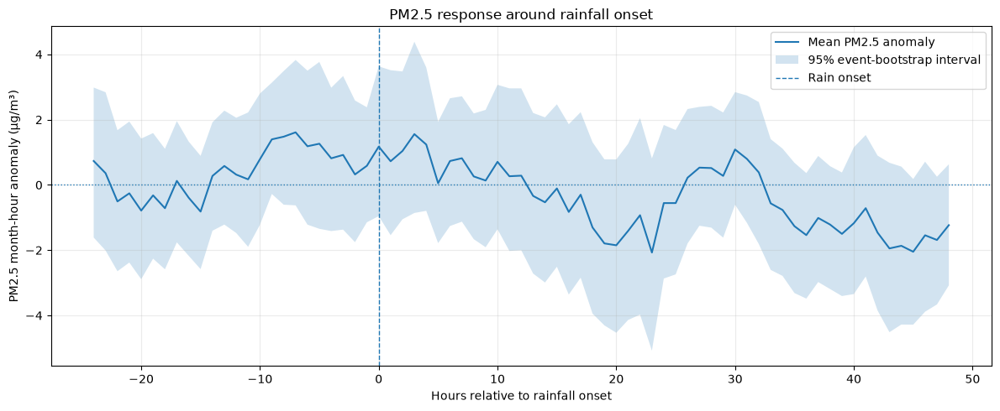

In [214]:
plt.figure(figsize=(12, 5))

plt.plot(
    rain_onset_composite["Offset_Hours"],
    rain_onset_composite["Mean_PM25_Anomaly"],
    label="Mean PM2.5 anomaly"
)

plt.fill_between(
    rain_onset_composite["Offset_Hours"],
    rain_onset_composite["CI_Lower_95"],
    rain_onset_composite["CI_Upper_95"],
    alpha=0.2,
    label="95% event-bootstrap interval"
)

plt.axvline(0, linestyle="--", linewidth=1, label="Rain onset")
plt.axhline(0, linestyle=":", linewidth=1)

plt.xlabel("Hours relative to rainfall onset")
plt.ylabel("PM2.5 month-hour anomaly (µg/m³)")
plt.title("PM2.5 response around rainfall onset")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Cloud Cover Lag Analysis

In [215]:
cloud_lag_results = []

cloud = analysis_data["cloud_cover"]
cloud_baseline = cloud.groupby([
    cloud.index.month, cloud.index.hour
]).transform("mean")
cloud_residual = cloud - cloud_baseline

for pollutant in ["pm25", "pm1"]:
    pollution = analysis_data[pollutant]

    pollution_baseline = pollution.groupby([
        pollution.index.month, pollution.index.hour
    ]).transform("mean")
    pollution_residual = pollution - pollution_baseline

    for lag in range(-24, 73):
        pair = pd.DataFrame({
            "cloud": cloud.shift(lag),
            "cloud_residual": cloud_residual.shift(lag),
            "pollution": pollution,
            "pollution_residual": pollution_residual
        }).dropna()

        cloud_lag_results.append({
            "Pollutant": pollutant,
            "Lag_Hours": lag,
            "N": len(pair),
            "Raw_Pearson": pair["cloud"].corr(
                pair["pollution"], method="pearson"
            ),
            "Raw_Spearman": pair["cloud"].corr(
                pair["pollution"], method="spearman"
            ),
            "Adjusted_Pearson": pair["cloud_residual"].corr(
                pair["pollution_residual"], method="pearson"
            ),
            "Adjusted_Spearman": pair["cloud_residual"].corr(
                pair["pollution_residual"], method="spearman"
            )
        })

cloud_lag_results = pd.DataFrame(cloud_lag_results)

print("Result dimensions:", cloud_lag_results.shape)

Result dimensions: (194, 7)


In [216]:
cloud_selected_lags = [-24, -12, -6, 0, 3, 6, 12, 18, 24, 36, 48, 60, 69, 72]

display(
    cloud_lag_results[
        cloud_lag_results["Lag_Hours"].isin(cloud_selected_lags)
    ].pivot(
        index="Lag_Hours",
        columns="Pollutant",
        values="Adjusted_Spearman"
    ).round(4)
)

for pollutant in ["pm25", "pm1"]:
    subset = cloud_lag_results[
        cloud_lag_results["Pollutant"] == pollutant
    ]

    print(f"\n{pollutant.upper()}")
    print("Adjusted Spearman range:",
          round(subset["Adjusted_Spearman"].min(), 4),
          "to",
          round(subset["Adjusted_Spearman"].max(), 4))
    print("Minimum lag:",
          int(subset.loc[
              subset["Adjusted_Spearman"].idxmin(), "Lag_Hours"
          ]))
    print("Maximum lag:",
          int(subset.loc[
              subset["Adjusted_Spearman"].idxmax(), "Lag_Hours"
          ]))

Pollutant,pm1,pm25
Lag_Hours,,
-24,-0.0501,-0.0511
-12,-0.0316,-0.0290
-6,-0.0499,-0.0432
0,-0.0710,-0.0621
3,-0.0858,-0.0749
6,-0.0959,-0.0854
12,-0.0914,-0.0825
18,-0.1030,-0.0919
24,-0.1268,-0.1158



PM25
Adjusted Spearman range: -0.1303 to -0.0274
Minimum lag: 54
Maximum lag: -11

PM1
Adjusted Spearman range: -0.1373 to -0.031
Minimum lag: 54
Maximum lag: -11


In [217]:
daily_cloud_pm = analysis_data[
    ["cloud_cover", "pm25", "pm1"]
].resample("D").mean()

for variable in ["cloud_cover", "pm25", "pm1"]:
    monthly_daily_mean = daily_cloud_pm.groupby(
        daily_cloud_pm.index.month
    )[variable].transform("mean")

    daily_cloud_pm[f"{variable}_anomaly"] = (
        daily_cloud_pm[variable] - monthly_daily_mean
    )

display(
    daily_cloud_pm[
        ["cloud_cover_anomaly", "pm25_anomaly", "pm1_anomaly"]
    ].describe().round(3)
)

,cloud_cover_anomaly,pm25_anomaly,pm1_anomaly
count,490.000,473.000,473.000
mean,-0.000,-0.000,0.000
std,22.408,11.782,6.813
min,-46.485,-38.568,-24.174
25%,-16.852,-4.921,-2.791
50%,0.622,-0.043,-0.044
75%,12.300,4.329,2.692
max,78.093,88.933,50.348


In [218]:
daily_cloud_lag_results = []

for pollutant in ["pm25", "pm1"]:
    for lag in range(-7, 15):
        pair = pd.DataFrame({
            "cloud": daily_cloud_pm["cloud_cover_anomaly"].shift(lag),
            "pollution": daily_cloud_pm[f"{pollutant}_anomaly"]
        }).dropna()

        daily_cloud_lag_results.append({
            "Pollutant": pollutant,
            "Lag_Days": lag,
            "N": len(pair),
            "Pearson": pair["cloud"].corr(
                pair["pollution"], method="pearson"
            ),
            "Spearman": pair["cloud"].corr(
                pair["pollution"], method="spearman"
            )
        })

daily_cloud_lag_results = pd.DataFrame(daily_cloud_lag_results)

display(
    daily_cloud_lag_results.pivot(
        index="Lag_Days",
        columns="Pollutant",
        values="Spearman"
    ).round(4)
)

Pollutant,pm1,pm25
Lag_Days,,
-7,0.0970,0.0971
-6,0.0734,0.0718
-5,0.0869,0.0817
-4,0.0608,0.0514
-3,0.0556,0.0424
-2,-0.0398,-0.0490
-1,-0.0820,-0.0864
0,-0.1486,-0.1308
1,-0.2450,-0.2193


In [219]:
comparison_rows = []

for pollutant in ["pm25", "pm1"]:
    hourly = cloud_lag_results[
        cloud_lag_results["Pollutant"] == pollutant
    ]

    daily = daily_cloud_lag_results[
        daily_cloud_lag_results["Pollutant"] == pollutant
    ]

    for lag in [0, 24, 48, 72]:
        hourly_row = hourly[hourly["Lag_Hours"] == lag].iloc[0]

        comparison_rows.append({
            "Pollutant": pollutant,
            "Hourly_Lag_Hours": lag,
            "Hourly_Adjusted_Spearman": hourly_row["Adjusted_Spearman"]
        })

    print(f"\n{pollutant.upper()} — daily anomaly profile")
    display(daily.round(4))

print("\nHourly selected-lag comparison")
display(pd.DataFrame(comparison_rows).round(4))


PM25 — daily anomaly profile


,Pollutant,Lag_Days,N,Pearson,Spearman
0,pm25,-7,473,0.1031,0.0971
1,pm25,-6,473,0.0920,0.0718
2,pm25,-5,473,0.1086,0.0817
3,pm25,-4,473,0.1032,0.0514
4,pm25,-3,473,0.0862,0.0424
5,pm25,-2,473,-0.0215,-0.0490
6,pm25,-1,473,-0.1004,-0.0864
7,pm25,0,473,-0.1539,-0.1308
8,pm25,1,473,-0.2522,-0.2193
9,pm25,2,472,-0.2513,-0.1997



PM1 — daily anomaly profile


,Pollutant,Lag_Days,N,Pearson,Spearman
22,pm1,-7,473,0.1097,0.0970
23,pm1,-6,473,0.1010,0.0734
24,pm1,-5,473,0.1225,0.0869
25,pm1,-4,473,0.1161,0.0608
26,pm1,-3,473,0.0928,0.0556
27,pm1,-2,473,-0.0243,-0.0398
28,pm1,-1,473,-0.1104,-0.0820
29,pm1,0,473,-0.1772,-0.1486
30,pm1,1,473,-0.2800,-0.2450
31,pm1,2,472,-0.2748,-0.2183



Hourly selected-lag comparison


,Pollutant,Hourly_Lag_Hours,Hourly_Adjusted_Spearman
0,pm25,0,-0.0621
1,pm25,24,-0.1158
2,pm25,48,-0.1206
3,pm25,72,-0.1174
4,pm1,0,-0.0710
5,pm1,24,-0.1268
6,pm1,48,-0.1288
7,pm1,72,-0.1198


In [220]:
daily_cloud_pm = analysis_data[["cloud_cover", "pm25", "pm1"]].resample("D").agg(
    cloud_cover_mean=("cloud_cover", "mean"),
    pm25_mean=("pm25", "mean"),
    pm1_mean=("pm1", "mean"),
    pm25_hours=("pm25", "count"),
    pm1_hours=("pm1", "count"),
    cloud_hours=("cloud_cover", "count")
)

daily_cloud_pm["pm25_mean"] = daily_cloud_pm["pm25_mean"].where(
    daily_cloud_pm["pm25_hours"] >= 18
)
daily_cloud_pm["pm1_mean"] = daily_cloud_pm["pm1_mean"].where(
    daily_cloud_pm["pm1_hours"] >= 18
)

print("Daily coverage summary:")
print(daily_cloud_pm[
    ["pm25_hours", "pm1_hours", "cloud_hours"]
].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(2))

print("\nDays meeting the 18-hour threshold:")
print({
    "PM2.5": int(daily_cloud_pm["pm25_mean"].notna().sum()),
    "PM1": int(daily_cloud_pm["pm1_mean"].notna().sum()),
    "Cloud cover": int(daily_cloud_pm["cloud_cover_mean"].notna().sum())
})

Daily coverage summary:
       pm25_hours  pm1_hours  cloud_hours
count      490.00     490.00       490.00
mean        22.41      22.41        23.95
std          5.10       5.10         0.89
min          0.00       0.00         5.00
10%         21.00      21.00        24.00
25%         24.00      24.00        24.00
50%         24.00      24.00        24.00
75%         24.00      24.00        24.00
90%         24.00      24.00        24.00
max         24.00      24.00        24.00

Days meeting the 18-hour threshold:
{'PM2.5': 458, 'PM1': 458, 'Cloud cover': 490}


In [221]:
for variable in ["cloud_cover_mean", "pm25_mean", "pm1_mean"]:
    monthly_baseline = daily_cloud_pm.groupby(
        daily_cloud_pm.index.month
    )[variable].transform("mean")

    daily_cloud_pm[f"{variable}_anomaly"] = (
        daily_cloud_pm[variable] - monthly_baseline
    )

In [222]:
cloud_daily_lag_results = []

for pollutant in ["pm25", "pm1"]:
    for lag in range(-7, 15):
        pair = pd.DataFrame({
            "cloud": daily_cloud_pm["cloud_cover_mean_anomaly"].shift(lag),
            "pollution": daily_cloud_pm[f"{pollutant}_mean_anomaly"]
        }).dropna()

        cloud_daily_lag_results.append({
            "Pollutant": pollutant,
            "Lag_Days": lag,
            "N": len(pair),
            "Pearson": pair["cloud"].corr(pair["pollution"], method="pearson"),
            "Spearman": pair["cloud"].corr(pair["pollution"], method="spearman")
        })

cloud_daily_lag_results = pd.DataFrame(cloud_daily_lag_results)

print(cloud_daily_lag_results.round(4).to_string(index=False))

Pollutant  Lag_Days   N  Pearson  Spearman
     pm25        -7 458   0.0894    0.0755
     pm25        -6 458   0.0889    0.0629
     pm25        -5 458   0.1114    0.0850
     pm25        -4 458   0.1089    0.0624
     pm25        -3 458   0.0991    0.0603
     pm25        -2 458  -0.0132   -0.0364
     pm25        -1 458  -0.0900   -0.0666
     pm25         0 458  -0.1464   -0.1212
     pm25         1 458  -0.2485   -0.2148
     pm25         2 457  -0.2485   -0.1972
     pm25         3 456  -0.2460   -0.1881
     pm25         4 455  -0.2043   -0.2070
     pm25         5 454  -0.1966   -0.1634
     pm25         6 453  -0.1327   -0.1481
     pm25         7 452  -0.1395   -0.1501
     pm25         8 451  -0.0958   -0.0908
     pm25         9 450  -0.0442   -0.0515
     pm25        10 449   0.0047    0.0216
     pm25        11 448   0.0029    0.0089
     pm25        12 447   0.0049    0.0146
     pm25        13 446   0.0232    0.0566
     pm25        14 445   0.0827    0.1044
      pm1  

Solar Radiation Lag Analysis

In [223]:
radiation_variables = [
    "shortwave_radiation",
    "terrestrial_radiation",
    "radiation_transmission",
    "radiation_deficit",
    "clear_hour",
    "clear_radiation_transmission",
    "clear_radiation_deficit"
]

print("Radiation variable coverage:")
print(analysis_data[radiation_variables].notna().sum())

print("\nClear-hour distribution:")
print(analysis_data["clear_hour"].value_counts(dropna=False))

print("\nSensor overlap:")
print(
    analysis_data[["pm25", "pm1"] + radiation_variables]
    .notna().sum()
)

Radiation variable coverage:
shortwave_radiation             11736
terrestrial_radiation           11736
radiation_transmission           6428
radiation_deficit               11736
clear_hour                      11736
clear_radiation_transmission     1398
clear_radiation_deficit          1398
dtype: int64

Clear-hour distribution:
clear_hour
False    10338
True      1398
Name: count, dtype: int64

Sensor overlap:
pm25                            10981
pm1                             10981
shortwave_radiation             11736
terrestrial_radiation           11736
radiation_transmission           6428
radiation_deficit               11736
clear_hour                      11736
clear_radiation_transmission     1398
clear_radiation_deficit          1398
dtype: int64


In [224]:
radiation_lag_results = []

radiation_variables = [
    "radiation_transmission",
    "radiation_deficit",
    "clear_radiation_transmission",
    "clear_radiation_deficit"
]

for variable in radiation_variables:
    radiation = analysis_data[variable]

    radiation_baseline = radiation.groupby([
        radiation.index.month,
        radiation.index.hour
    ]).transform("mean")

    radiation_residual = radiation - radiation_baseline

    for pollutant in ["pm25", "pm1"]:
        pollution = analysis_data[pollutant]

        pollution_baseline = pollution.groupby([
            pollution.index.month,
            pollution.index.hour
        ]).transform("mean")

        pollution_residual = pollution - pollution_baseline

        for lag in range(-24, 73):
            pair = pd.DataFrame({
                "radiation": radiation.shift(lag),
                "radiation_residual": radiation_residual.shift(lag),
                "pollution": pollution,
                "pollution_residual": pollution_residual
            }).dropna()

            radiation_lag_results.append({
                "Variable": variable,
                "Pollutant": pollutant,
                "Lag_Hours": lag,
                "N": len(pair),
                "Raw_Spearman": pair["radiation"].corr(
                    pair["pollution"], method="spearman"
                ),
                "Adjusted_Pearson": pair["radiation_residual"].corr(
                    pair["pollution_residual"], method="pearson"
                ),
                "Adjusted_Spearman": pair["radiation_residual"].corr(
                    pair["pollution_residual"], method="spearman"
                )
            })

radiation_lag_results = pd.DataFrame(radiation_lag_results)

print("Result dimensions:", radiation_lag_results.shape)

selected_lags = [-24, -12, -6, 0, 3, 6, 12, 18, 24, 36, 48, 60, 72]

print("\nSelected adjusted Spearman correlations:")
print(
    radiation_lag_results[
        radiation_lag_results["Lag_Hours"].isin(selected_lags)
    ].pivot_table(
        index=["Variable", "Lag_Hours"],
        columns="Pollutant",
        values="Adjusted_Spearman"
    ).round(4)
)

print("\nLag-profile ranges and extrema:")
for (variable, pollutant), group in radiation_lag_results.groupby(
    ["Variable", "Pollutant"]
):
    valid = group.dropna(subset=["Adjusted_Spearman"])
    minimum = valid.loc[valid["Adjusted_Spearman"].idxmin()]
    maximum = valid.loc[valid["Adjusted_Spearman"].idxmax()]

    print(
        f"{variable} | {pollutant} | "
        f"N range: {valid['N'].min()}–{valid['N'].max()} | "
        f"Spearman range: {valid['Adjusted_Spearman'].min():.4f} "
        f"to {valid['Adjusted_Spearman'].max():.4f} | "
        f"minimum at {int(minimum['Lag_Hours'])}h | "
        f"maximum at {int(maximum['Lag_Hours'])}h"
    )

Result dimensions: (776, 7)

Selected adjusted Spearman correlations:
Pollutant                                  pm1    pm25
Variable                     Lag_Hours                
clear_radiation_deficit      -24       -0.0395 -0.0179
                             -12       -0.0450 -0.0223
                             -6        -0.0478 -0.0245
                              0        -0.0990 -0.0718
                              3        -0.0520 -0.0325
                              6         0.0044  0.0254
                              12       -0.1032 -0.0745
                              18       -0.1386 -0.1141
                              24       -0.1553 -0.1297
                              36       -0.1979 -0.1774
                              48       -0.1370 -0.1180
                              60       -0.1229 -0.1136
                              72       -0.1354 -0.1247
clear_radiation_transmission -24       -0.1092 -0.1056
                             -12       -0.0306 -0.

Wind Gust Lag Analysis

In [225]:
gust_lag_results = []

gust = analysis_data["wind_gusts_10m"]

gust_baseline = gust.groupby([
    gust.index.month,
    gust.index.hour
]).transform("mean")

gust_residual = gust - gust_baseline

for pollutant in ["pm25", "pm1"]:
    pollution = analysis_data[pollutant]

    pollution_baseline = pollution.groupby([
        pollution.index.month,
        pollution.index.hour
    ]).transform("mean")

    pollution_residual = pollution - pollution_baseline

    for lag in range(-24, 73):
        pair = pd.DataFrame({
            "gust": gust.shift(lag),
            "gust_residual": gust_residual.shift(lag),
            "pollution": pollution,
            "pollution_residual": pollution_residual
        }).dropna()

        gust_lag_results.append({
            "Pollutant": pollutant,
            "Lag_Hours": lag,
            "N": len(pair),
            "Raw_Spearman": pair["gust"].corr(
                pair["pollution"], method="spearman"
            ),
            "Adjusted_Pearson": pair["gust_residual"].corr(
                pair["pollution_residual"], method="pearson"
            ),
            "Adjusted_Spearman": pair["gust_residual"].corr(
                pair["pollution_residual"], method="spearman"
            )
        })

gust_lag_results = pd.DataFrame(gust_lag_results)

selected_lags = [-24, -12, -6, 0, 3, 6, 12, 18, 24, 36, 48, 60, 72]

print("Result dimensions:", gust_lag_results.shape)

print("\nSelected adjusted correlations:")
print(
    gust_lag_results[
        gust_lag_results["Lag_Hours"].isin(selected_lags)
    ].pivot(
        index="Lag_Hours",
        columns="Pollutant",
        values="Adjusted_Spearman"
    ).round(4)
)

print("\nLag-profile summary:")
for pollutant, group in gust_lag_results.groupby("Pollutant"):
    valid = group.dropna(subset=["Adjusted_Spearman"])

    minimum = valid.loc[valid["Adjusted_Spearman"].idxmin()]
    maximum = valid.loc[valid["Adjusted_Spearman"].idxmax()]

    print(
        f"{pollutant}: "
        f"range {valid['Adjusted_Spearman'].min():.4f} "
        f"to {valid['Adjusted_Spearman'].max():.4f}; "
        f"minimum at {int(minimum['Lag_Hours'])}h; "
        f"maximum at {int(maximum['Lag_Hours'])}h; "
        f"N={valid['N'].min()}–{valid['N'].max()}"
    )

Result dimensions: (194, 6)

Selected adjusted correlations:
Pollutant     pm1    pm25
Lag_Hours                
-24       -0.0642 -0.0735
-12       -0.0613 -0.0706
-6        -0.0817 -0.0904
 0        -0.0936 -0.1043
 3        -0.0812 -0.0902
 6        -0.0965 -0.1066
 12       -0.1061 -0.1160
 18       -0.0933 -0.1015
 24       -0.0759 -0.0848
 36       -0.0732 -0.0802
 48       -0.0805 -0.0849
 60       -0.0791 -0.0810
 72       -0.0551 -0.0552

Lag-profile summary:
pm1: range -0.1113 to -0.0551; minimum at 11h; maximum at 72h; N=10928–10981
pm25: range -0.1213 to -0.0552; minimum at 11h; maximum at 72h; N=10928–10981


Joint Meteorological Relationships and Multicollinearity

In [226]:
met_candidates = {
    "Temperature_Anomaly": "relative_temperature",
    "Relative_Humidity": "relative_humidity_2m",
    "Pressure_MSL": "pressure_msl",
    "Wind_Gusts": "wind_gusts_10m",
    "Boundary_Layer_Height": "boundary_layer_height",
    "Cloud_Cover": "cloud_cover",
    "Precipitation": "precipitation",
    "Radiation_Deficit": "radiation_deficit"
}

met_data = analysis_data[list(met_candidates.values())].copy()
met_data.columns = list(met_candidates.keys())

# Remove average month-hour patterns from each variable
met_adjusted = met_data.copy()

for column in met_adjusted.columns:
    baseline = met_adjusted[column].groupby([
        met_adjusted.index.month,
        met_adjusted.index.hour
    ]).transform("mean")

    met_adjusted[column] = met_adjusted[column] - baseline

# Complete-case samples for comparable correlation and VIF calculations
raw_complete = met_data.dropna()
adjusted_complete = met_adjusted.dropna()

print("Raw complete-case observations:", len(raw_complete))
print("Adjusted complete-case observations:", len(adjusted_complete))

print("\nRaw Pearson correlations:")
print(raw_complete.corr(method="pearson").round(3))

print("\nAdjusted Pearson correlations:")
print(adjusted_complete.corr(method="pearson").round(3))

print("\nAdjusted Spearman correlations:")
print(adjusted_complete.corr(method="spearman").round(3))

# VIF from the inverse of the adjusted-variable correlation matrix
corr_matrix = adjusted_complete.corr(method="pearson")
vif_values = np.linalg.inv(corr_matrix.to_numpy()).diagonal()

vif_results = pd.DataFrame({
    "Variable": corr_matrix.columns,
    "VIF": vif_values
}).sort_values("VIF", ascending=False)

print("\nAdjusted VIF:")
print(vif_results.round(3).to_string(index=False))

Raw complete-case observations: 10504
Adjusted complete-case observations: 10504

Raw Pearson correlations:
                       Temperature_Anomaly  Relative_Humidity  Pressure_MSL  \
Temperature_Anomaly                  1.000             -0.650        -0.126   
Relative_Humidity                   -0.650              1.000        -0.219   
Pressure_MSL                        -0.126             -0.219         1.000   
Wind_Gusts                           0.352             -0.279        -0.245   
Boundary_Layer_Height                0.756             -0.817        -0.033   
Cloud_Cover                         -0.006              0.400        -0.432   
Precipitation                        0.082              0.126        -0.233   
Radiation_Deficit                    0.661             -0.454        -0.264   

                       Wind_Gusts  Boundary_Layer_Height  Cloud_Cover  \
Temperature_Anomaly         0.352                  0.756       -0.006   
Relative_Humidity          -0.279 

Season Stratified Associations

In [227]:
seasonal_data = analysis_data[
    [
        "pm25", "pm1",
        "relative_temperature",
        "relative_humidity_2m",
        "pressure_msl",
        "wind_gusts_10m",
        "boundary_layer_height",
        "cloud_cover",
        "precipitation",
        "radiation_deficit"
    ]
].copy()

season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Pre-monsoon", 4: "Pre-monsoon", 5: "Pre-monsoon",
    6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
    10: "Post-monsoon", 11: "Post-monsoon"
}

seasonal_data["Season"] = seasonal_data.index.month.map(season_map)
seasonal_data["Hour"] = seasonal_data.index.hour

met_variables = [
    "relative_temperature",
    "relative_humidity_2m",
    "pressure_msl",
    "wind_gusts_10m",
    "boundary_layer_height",
    "cloud_cover",
    "precipitation",
    "radiation_deficit"
]

# Remove season-specific hourly means
for variable in met_variables + ["pm25", "pm1"]:
    baseline = seasonal_data.groupby(
        ["Season", "Hour"]
    )[variable].transform("mean")

    seasonal_data[f"{variable}_resid"] = seasonal_data[variable] - baseline

seasonal_results = []

for season in ["Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"]:
    subset = seasonal_data[seasonal_data["Season"] == season]

    for variable in met_variables:
        for pollutant in ["pm25", "pm1"]:
            pair = subset[
                [f"{variable}_resid", f"{pollutant}_resid"]
            ].dropna()

            seasonal_results.append({
                "Season": season,
                "Variable": variable,
                "Pollutant": pollutant,
                "N": len(pair),
                "Pearson": pair.iloc[:, 0].corr(pair.iloc[:, 1]),
                "Spearman": pair.iloc[:, 0].corr(
                    pair.iloc[:, 1], method="spearman"
                )
            })

seasonal_results = pd.DataFrame(seasonal_results)

print("Result dimensions:", seasonal_results.shape)

print("\nPM2.5 season-stratified Spearman correlations:")
print(
    seasonal_results[seasonal_results["Pollutant"] == "pm25"]
    .pivot(index="Variable", columns="Season", values="Spearman")
    .round(3)
)

print("\nPM1 season-stratified Spearman correlations:")
print(
    seasonal_results[seasonal_results["Pollutant"] == "pm1"]
    .pivot(index="Variable", columns="Season", values="Spearman")
    .round(3)
)

print("\nSample sizes:")
print(
    seasonal_results[seasonal_results["Pollutant"] == "pm25"]
    .pivot(index="Variable", columns="Season", values="N")
)

Result dimensions: (64, 6)

PM2.5 season-stratified Spearman correlations:
Season                 Monsoon  Post-monsoon  Pre-monsoon  Winter
Variable                                                         
boundary_layer_height    0.028        -0.109       -0.136  -0.040
cloud_cover             -0.237        -0.177       -0.159   0.077
precipitation           -0.186        -0.187       -0.090   0.032
pressure_msl             0.129         0.399        0.101  -0.089
radiation_deficit       -0.116        -0.248       -0.158   0.023
relative_humidity_2m    -0.215        -0.289       -0.126   0.041
relative_temperature     0.151        -0.340        0.357  -0.048
wind_gusts_10m          -0.145        -0.051       -0.194   0.070

PM1 season-stratified Spearman correlations:
Season                 Monsoon  Post-monsoon  Pre-monsoon  Winter
Variable                                                         
boundary_layer_height    0.028        -0.116       -0.126  -0.092
cloud_cover          

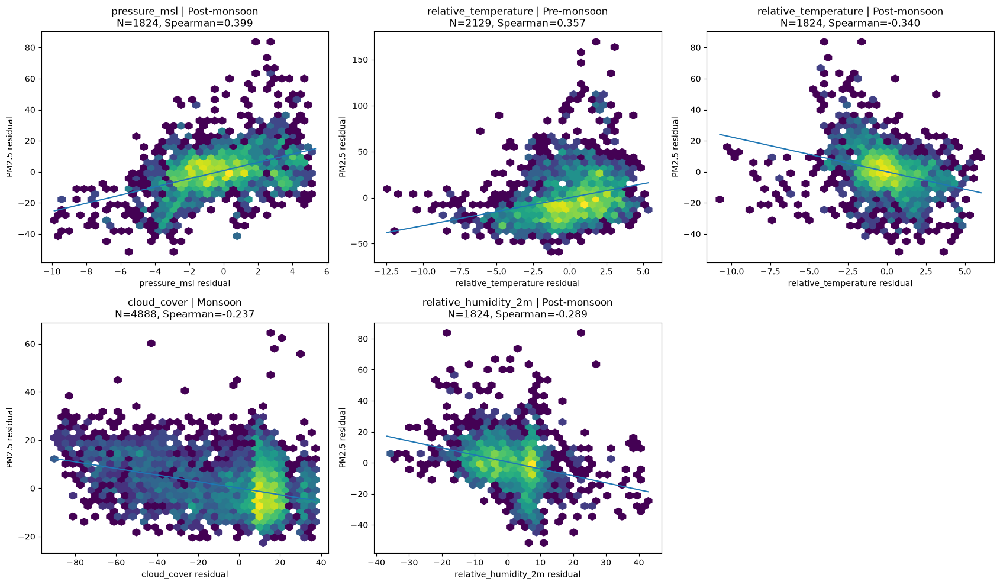


SCATTERPLOT NUMERICAL RESULTS
            Variable       Season    N  Pearson  Spearman   Slope  Intercept    X_Min   X_Max  PM25_Min  PM25_Max
        pressure_msl Post-monsoon 1824   0.4366    0.3994  2.6358     0.7758  -9.8576  5.3419  -51.5925   83.6511
relative_temperature  Pre-monsoon 2129   0.2743    0.3570  3.0363    -0.0000 -12.4523  5.3572  -58.8330  169.2056
relative_temperature Post-monsoon 1824  -0.3015   -0.3400 -2.2403     0.0000 -10.7429  6.0421  -51.5925   83.6511
         cloud_cover      Monsoon 4888  -0.3587   -0.2374 -0.1365     0.0342 -90.2103 37.2605  -22.6514   64.4853
relative_humidity_2m Post-monsoon 1824  -0.2806   -0.2887 -0.4487     0.5099 -36.7419 42.8804  -51.5925   83.6511


In [229]:
scatter_cases = [
    ("pressure_msl", "Post-monsoon"),
    ("relative_temperature", "Pre-monsoon"),
    ("relative_temperature", "Post-monsoon"),
    ("cloud_cover", "Monsoon"),
    ("relative_humidity_2m", "Post-monsoon")
]

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.flatten()

scatter_results = []

for ax, (variable, season) in zip(axes, scatter_cases):

    subset = seasonal_data[
        seasonal_data["Season"] == season
    ][[f"{variable}_resid", "pm25_resid"]].dropna()

    x = subset[f"{variable}_resid"]
    y = subset["pm25_resid"]

    ax.hexbin(x, y, gridsize=35, mincnt=1, bins="log")

    slope, intercept = np.polyfit(x, y, 1)
    x_line = np.linspace(x.min(), x.max(), 100)
    ax.plot(x_line, slope * x_line + intercept)

    pearson = x.corr(y)
    spearman = x.corr(y, method="spearman")

    ax.set_title(
        f"{variable} | {season}\n"
        f"N={len(subset)}, Spearman={spearman:.3f}"
    )
    ax.set_xlabel(f"{variable} residual")
    ax.set_ylabel("PM2.5 residual")

    scatter_results.append({
        "Variable": variable,
        "Season": season,
        "N": len(subset),
        "Pearson": pearson,
        "Spearman": spearman,
        "Slope": slope,
        "Intercept": intercept,
        "X_Min": x.min(),
        "X_Max": x.max(),
        "PM25_Min": y.min(),
        "PM25_Max": y.max()
    })

axes[-1].axis("off")
plt.tight_layout()
plt.show()

scatter_results = pd.DataFrame(scatter_results)

print("\nSCATTERPLOT NUMERICAL RESULTS")
print(scatter_results.round(4).to_string(index=False))

CAMS vs Sensor Data

In [230]:
print("Hadigaun:")
print(hadigaun[["datetime", "pm25"]].dtypes)
print(hadigaun[["datetime", "pm25"]].head())
print(hadigaun["datetime"].min(), hadigaun["datetime"].max())

print("\nCAMS:")
print(cams[["datetime_utc", "pm25"]].dtypes)
print(cams[["datetime_utc", "pm25"]].head())
print(cams["datetime_utc"].min(), cams["datetime_utc"].max())

Hadigaun:
datetime    datetime64[us, UTC+05:45]
pm25                          float64
dtype: object
                   datetime       pm25
0 2025-07-01 00:45:00+05:45  13.717708
1 2025-07-01 01:45:00+05:45  11.052827
2 2025-07-01 02:45:00+05:45   9.482589
3 2025-07-01 03:45:00+05:45  10.492857
4 2025-07-01 04:45:00+05:45  23.859673
2025-07-01 00:45:00+05:45 2026-10-19 08:45:00+05:45

CAMS:
datetime_utc    datetime64[us, UTC]
pm25                        float64
dtype: object
               datetime_utc  pm25
0 2022-08-04 00:00:00+00:00  15.0
1 2022-08-04 01:00:00+00:00  13.2
2 2022-08-04 02:00:00+00:00  11.3
3 2022-08-04 03:00:00+00:00  11.7
4 2022-08-04 04:00:00+00:00  12.2
2022-08-04 00:00:00+00:00 2026-10-31 23:00:00+00:00


In [231]:
hadigaun_cams = hadigaun[["datetime", "pm25"]].copy()
cams_compare = cams[["datetime_utc", "pm25"]].copy()

hadigaun_cams["datetime_utc"] = hadigaun_cams["datetime"].dt.tz_convert("UTC")

hadigaun_cams = hadigaun_cams.rename(
    columns={"pm25": "Hadigaun_PM25"}
)

cams_compare = cams_compare.rename(
    columns={"pm25": "CAMS_PM25"}
)

cams_matched = pd.merge(
    hadigaun_cams[["datetime_utc", "Hadigaun_PM25"]],
    cams_compare,
    on="datetime_utc",
    how="inner"
).sort_values("datetime_utc")

print("Matched observations:", len(cams_matched))
print("Hadigaun observations:", len(hadigaun_cams))
print("CAMS observations:", len(cams_compare))

print("\nMatched period:")
print(cams_matched["datetime_utc"].min())
print(cams_matched["datetime_utc"].max())

print("\nMissing values:")
print(cams_matched[["Hadigaun_PM25", "CAMS_PM25"]].isna().sum())

print("\nDuplicate timestamps:")
print(cams_matched["datetime_utc"].duplicated().sum())

Matched observations: 10981
Hadigaun observations: 10981
CAMS observations: 37200

Matched period:
2025-06-30 19:00:00+00:00
2026-10-19 03:00:00+00:00

Missing values:
Hadigaun_PM25    0
CAMS_PM25        0
dtype: int64

Duplicate timestamps:
0


In [232]:
pair = cams_matched.dropna(
    subset=["Hadigaun_PM25", "CAMS_PM25"]
).copy()

difference = pair["CAMS_PM25"] - pair["Hadigaun_PM25"]

agreement_results = pd.Series({
    "N": len(pair),
    "Hadigaun_Mean": pair["Hadigaun_PM25"].mean(),
    "CAMS_Mean": pair["CAMS_PM25"].mean(),
    "Mean_Bias_CAMS_minus_Hadigaun": difference.mean(),
    "Median_Bias": difference.median(),
    "Bias_SD": difference.std(),
    "MAE": difference.abs().mean(),
    "RMSE": np.sqrt((difference ** 2).mean()),
    "Pearson": pair["Hadigaun_PM25"].corr(pair["CAMS_PM25"]),
    "Spearman": pair["Hadigaun_PM25"].corr(
        pair["CAMS_PM25"], method="spearman"
    ),
    "Regression_Slope": np.polyfit(
        pair["Hadigaun_PM25"], pair["CAMS_PM25"], 1
    )[0],
    "Regression_Intercept": np.polyfit(
        pair["Hadigaun_PM25"], pair["CAMS_PM25"], 1
    )[1]
})

print(agreement_results.round(4).to_string())

N                                10981.0000
Hadigaun_Mean                       41.1949
CAMS_Mean                           39.6200
Mean_Bias_CAMS_minus_Hadigaun       -1.5749
Median_Bias                         -0.3119
Bias_SD                             26.7288
MAE                                 18.5746
RMSE                                26.7739
Pearson                              0.5986
Spearman                             0.6023
Regression_Slope                     0.5357
Regression_Intercept                17.5521


In [233]:
pair["Season"] = pair["datetime_utc"].dt.month.map(season_map)

seasonal_cams_results = []

for season in [
    "Monsoon", "Post-monsoon", "Pre-monsoon", "Winter"
]:
    subset = pair[pair["Season"] == season]

    diff = subset["CAMS_PM25"] - subset["Hadigaun_PM25"]

    seasonal_cams_results.append({
        "Season": season,
        "N": len(subset),
        "Hadigaun_Mean": subset["Hadigaun_PM25"].mean(),
        "CAMS_Mean": subset["CAMS_PM25"].mean(),
        "Mean_Bias": diff.mean(),
        "MAE": diff.abs().mean(),
        "Pearson": subset["Hadigaun_PM25"].corr(
            subset["CAMS_PM25"]
        ),
        "Spearman": subset["Hadigaun_PM25"].corr(
            subset["CAMS_PM25"], method="spearman"
        )
    })

seasonal_cams_results = pd.DataFrame(seasonal_cams_results)

print(seasonal_cams_results.round(4).to_string(index=False))

      Season    N  Hadigaun_Mean  CAMS_Mean  Mean_Bias     MAE  Pearson  Spearman
     Monsoon 4893        20.7997    26.2140     5.4143 12.7369   0.2977    0.2589
Post-monsoon 1819        38.6344    35.8687    -2.7657 15.7735   0.4284    0.4576
 Pre-monsoon 2129        53.8348    44.6506    -9.1842 22.1583   0.4077    0.5335
      Winter 2140        77.4289    68.4558    -8.9731 30.7379   0.3287    0.4095


In [234]:
pair["datetime_npt"] = pair["datetime_utc"].dt.tz_convert(
    "Asia/Kathmandu"
)
pair["Date"] = pair["datetime_npt"].dt.floor("D")

daily_cams = (
    pair.groupby("Date")
    .agg(
        Hadigaun_PM25=("Hadigaun_PM25", "mean"),
        CAMS_PM25=("CAMS_PM25", "mean"),
        Matched_Hours=("datetime_utc", "count")
    )
)

daily_cams = daily_cams[
    daily_cams["Matched_Hours"] >= 18
].copy()

daily_diff = daily_cams["CAMS_PM25"] - daily_cams["Hadigaun_PM25"]

daily_results = pd.Series({
    "Valid_Days": len(daily_cams),
    "Hadigaun_Daily_Mean": daily_cams["Hadigaun_PM25"].mean(),
    "CAMS_Daily_Mean": daily_cams["CAMS_PM25"].mean(),
    "Mean_Bias": daily_diff.mean(),
    "Median_Bias": daily_diff.median(),
    "MAE": daily_diff.abs().mean(),
    "RMSE": np.sqrt((daily_diff ** 2).mean()),
    "Pearson": daily_cams["Hadigaun_PM25"].corr(
        daily_cams["CAMS_PM25"]
    ),
    "Spearman": daily_cams["Hadigaun_PM25"].corr(
        daily_cams["CAMS_PM25"], method="spearman"
    )
})

print("DAILY CAMS AGREEMENT")
print(daily_results.round(4).to_string())

daily_cams["Month"] = daily_cams.index.to_period("M")

monthly_cams = (
    daily_cams.groupby("Month")
    .agg(
        Days=("Hadigaun_PM25", "count"),
        Hadigaun_Mean=("Hadigaun_PM25", "mean"),
        CAMS_Mean=("CAMS_PM25", "mean")
    )
)

monthly_cams["Mean_Bias"] = (
    monthly_cams["CAMS_Mean"] - monthly_cams["Hadigaun_Mean"]
)

print("\nMONTHLY CAMS COMPARISON")
print(monthly_cams.round(2).to_string())

DAILY CAMS AGREEMENT
Valid_Days             458.0000
Hadigaun_Daily_Mean     41.1809
CAMS_Daily_Mean         39.6308
Mean_Bias               -1.5501
Median_Bias             -0.0320
MAE                      9.8535
RMSE                    14.6159
Pearson                  0.8284
Spearman                 0.8296

MONTHLY CAMS COMPARISON
         Days  Hadigaun_Mean  CAMS_Mean  Mean_Bias
Month                                             
2025-07    31          17.20      29.37      12.17
2025-08    30          17.77      24.08       6.30
2025-09    28          23.23      24.41       1.18
2025-10    28          33.75      29.58      -4.17
2025-11    29          45.88      42.45      -3.43
2025-12    31          72.47      62.95      -9.52
2026-01    31          84.11      75.29      -8.82
2026-02    28          75.45      66.80      -8.65
2026-03    31          59.76      60.08       0.31
2026-04    29          64.00      36.56     -27.43
2026-05    29          37.91      36.81      -1.09
202

C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\1272497226.py:40: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  daily_cams["Month"] = daily_cams.index.to_period("M")


In [235]:
april = pair[
    (pair["datetime_npt"].dt.year == 2026) &
    (pair["datetime_npt"].dt.month == 4)
].copy()

april["Difference"] = april["CAMS_PM25"] - april["Hadigaun_PM25"]

print("APRIL 2026 HOURLY COMPARISON")
print(april[["Hadigaun_PM25", "CAMS_PM25", "Difference"]].describe().round(2))

print("\nAPRIL 2026 DAILY COMPARISON")
april_daily = daily_cams[
    daily_cams.index.to_period("M") == pd.Period("2026-04")
].copy()

april_daily["Difference"] = (
    april_daily["CAMS_PM25"] - april_daily["Hadigaun_PM25"]
)

print(april_daily.round(2).to_string())

print("\nAPRIL 2026 EXTREME DAILY DIFFERENCES")
print(
    april_daily.reindex(
        april_daily["Difference"].abs()
        .sort_values(ascending=False).index
    ).head(10).round(2).to_string()
)

APRIL 2026 HOURLY COMPARISON
       Hadigaun_PM25  CAMS_PM25  Difference
count         701.00     701.00      701.00
mean           63.60      36.47      -27.13
std            36.09      19.65       34.41
min            11.00       4.70     -190.40
25%            40.10      21.70      -39.00
50%            51.90      33.90      -20.60
75%            78.60      47.00       -7.40
max           227.40      98.70       61.40

APRIL 2026 DAILY COMPARISON


C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\2398700878.py:13: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  daily_cams.index.to_period("M") == pd.Period("2026-04")


                           Hadigaun_PM25  CAMS_PM25  Matched_Hours    Month  Difference
Date                                                                                   
2026-04-01 00:00:00+05:45          48.68      37.32             24  2026-04      -11.36
2026-04-02 00:00:00+05:45          44.48      21.59             24  2026-04      -22.89
2026-04-03 00:00:00+05:45          50.70      24.22             24  2026-04      -26.48
2026-04-04 00:00:00+05:45          60.85      26.77             24  2026-04      -34.09
2026-04-05 00:00:00+05:45          36.22      19.22             24  2026-04      -17.00
2026-04-06 00:00:00+05:45          35.25      17.96             24  2026-04      -17.29
2026-04-07 00:00:00+05:45          35.18      17.37             24  2026-04      -17.81
2026-04-08 00:00:00+05:45          53.24      26.19             24  2026-04      -27.05
2026-04-09 00:00:00+05:45          26.97      27.80             24  2026-04        0.83
2026-04-10 00:00:00+05:45       

C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\2398700878.py:20: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(april_daily.round(2).to_string())
C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\2398700878.py:27: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).head(10).round(2).to_string()


Pollutant Autocorrelation

In [236]:
# Preserve the complete hourly timeline, including missing sensor readings
autocorr_data = analysis_data[["pm25", "pm1"]].copy()

autocorr_data["_month"] = autocorr_data.index.month
autocorr_data["_hour"] = autocorr_data.index.hour

# Remove average month-hour patterns
for variable in ["pm25", "pm1"]:
    baseline = autocorr_data.groupby(
        ["_month", "_hour"]
    )[variable].transform("mean")

    autocorr_data[f"{variable}_adjusted"] = (
        autocorr_data[variable] - baseline
    )

# Selected lags in hours
selected_lags = [1, 2, 3, 6, 12, 18, 24, 36, 48, 72, 96, 120, 168]

autocorr_results = []

for variable in ["pm25", "pm1"]:
    for adjustment in ["Raw", "Month_Hour_Adjusted"]:

        column = (
            variable if adjustment == "Raw"
            else f"{variable}_adjusted"
        )

        series = autocorr_data[column]

        for lag in selected_lags:
            paired = pd.DataFrame({
                "Current": series,
                "Previous": series.shift(lag)
            }).dropna()

            autocorr_results.append({
                "Pollutant": variable.upper(),
                "Adjustment": adjustment,
                "Lag_Hours": lag,
                "N": len(paired),
                "Pearson": paired["Current"].corr(
                    paired["Previous"]
                ),
                "Spearman": paired["Current"].corr(
                    paired["Previous"], method="spearman"
                )
            })

autocorr_results = pd.DataFrame(autocorr_results)

print("POLLUTANT AUTOCORRELATION")
print(
    autocorr_results.round(4).to_string(index=False)
)

POLLUTANT AUTOCORRELATION
Pollutant          Adjustment  Lag_Hours     N  Pearson  Spearman
     PM25                 Raw          1 10896   0.9248    0.9589
     PM25                 Raw          2 10862   0.8263    0.9084
     PM25                 Raw          3 10828   0.7407    0.8607
     PM25                 Raw          6 10774   0.5780    0.7596
     PM25                 Raw         12 10727   0.6899    0.8139
     PM25                 Raw         18 10686   0.5393    0.7307
     PM25                 Raw         24 10659   0.8455    0.8629
     PM25                 Raw         36 10597   0.6381    0.7794
     PM25                 Raw         48 10549   0.8033    0.8328
     PM25                 Raw         72 10504   0.7780    0.8086
     PM25                 Raw         96 10483   0.7786    0.8009
     PM25                 Raw        120 10448   0.7647    0.7854
     PM25                 Raw        168 10403   0.7397    0.7612
     PM25 Month_Hour_Adjusted          1 10896   0

Meterological Associations after controlling for previous hour pollution

In [237]:
# Variables must exist on the complete hourly weather timeline
conditional_variables = [
    "cloud_cover",
    "precipitation",
    "precip_previous_24h",
    "dry_spell_hours"
]

conditional_lags = [-24, -12, -6, 0, 6, 12, 24, 48, 72]

def month_hour_residual(series):
    baseline = series.groupby(
        [series.index.month, series.index.hour]
    ).transform("mean")
    return series - baseline

def partial_correlation(x, y, control, method="pearson"):
    data = pd.concat(
        [x.rename("x"), y.rename("y"), control.rename("z")],
        axis=1
    ).dropna()

    if method == "spearman":
        data = data.rank()

    corr = data.corr()

    r_xy = corr.loc["x", "y"]
    r_xz = corr.loc["x", "z"]
    r_yz = corr.loc["y", "z"]

    denominator = np.sqrt(
        (1 - r_xz ** 2) * (1 - r_yz ** 2)
    )

    result = (
        (r_xy - r_xz * r_yz) / denominator
        if denominator > 0 else np.nan
    )

    return len(data), result

# Month-hour-adjusted pollutant and its previous-hour value
pm25_resid = month_hour_residual(analysis_data["pm25"])
previous_pm25_resid = pm25_resid.shift(1)

conditional_results = []

for variable in conditional_variables:

    weather_resid = month_hour_residual(
        analysis_data[variable]
    )

    for lag in conditional_lags:

        # Positive lag: weather precedes current PM2.5
        lagged_weather = weather_resid.shift(lag)

        n_p, partial_pearson = partial_correlation(
            lagged_weather,
            pm25_resid,
            previous_pm25_resid,
            method="pearson"
        )

        n_s, partial_spearman = partial_correlation(
            lagged_weather,
            pm25_resid,
            previous_pm25_resid,
            method="spearman"
        )

        conditional_results.append({
            "Variable": variable,
            "Weather_Lag_Hours": lag,
            "N": n_p,
            "Partial_Pearson": partial_pearson,
            "Partial_Spearman": partial_spearman
        })

conditional_results = pd.DataFrame(conditional_results)

print("PARTIAL CORRELATIONS CONTROLLING FOR PREVIOUS-HOUR PM2.5")
print(conditional_results.round(4).to_string(index=False))

PARTIAL CORRELATIONS CONTROLLING FOR PREVIOUS-HOUR PM2.5
           Variable  Weather_Lag_Hours     N  Partial_Pearson  Partial_Spearman
        cloud_cover                -24 10896          -0.0302           -0.0223
        cloud_cover                -12 10896          -0.0091           -0.0025
        cloud_cover                 -6 10896          -0.0266           -0.0192
        cloud_cover                  0 10896          -0.0297           -0.0245
        cloud_cover                  6 10896          -0.0411           -0.0326
        cloud_cover                 12 10896          -0.0288           -0.0234
        cloud_cover                 24 10892          -0.0490           -0.0473
        cloud_cover                 48 10868          -0.0313           -0.0316
        cloud_cover                 72 10844          -0.0329           -0.0361
      precipitation                -24 10896          -0.0166           -0.0232
      precipitation                -12 10896          -0.0170  

Confidence Intervals for Selected Lag Profiles

In [238]:
from scipy.stats import spearmanr

bootstrap_variables = [
    "relative_temperature_2m",
    "precip_previous_24h",
    "cloud_cover",
    "radiation_deficit",
    "wind_gusts_10m"
]

bootstrap_lags = [-24, 0, 12, 24, 48, 72]
n_bootstrap = 500
block_length = 168  # 7 days of hourly observations

# Month-hour residuals on the complete hourly timeline
bootstrap_data = pd.DataFrame(index=analysis_data.index)

for variable in bootstrap_variables + ["pm25", "pm1"]:
    bootstrap_data[variable] = month_hour_residual(
        analysis_data[variable]
    )

n_total = len(bootstrap_data)
n_blocks = int(np.ceil(n_total / block_length))

# Generate moving-block bootstrap indices
rng = np.random.default_rng(42)
bootstrap_indices = []

for _ in range(n_bootstrap):
    starts = rng.integers(
        0,
        n_total - block_length + 1,
        size=n_blocks
    )

    indices = np.concatenate([
        np.arange(start, start + block_length)
        for start in starts
    ])[:n_total]

    bootstrap_indices.append(indices)

bootstrap_results = []

for variable in bootstrap_variables:

    for pollutant in ["pm25", "pm1"]:

        y = bootstrap_data[pollutant].to_numpy()
        weather = bootstrap_data[variable]

        for lag in bootstrap_lags:

            x = weather.shift(lag).to_numpy()

            valid = np.isfinite(x) & np.isfinite(y)
            observed_n = valid.sum()

            observed_rho = spearmanr(
                x[valid], y[valid]
            ).statistic

            bootstrap_correlations = []

            for indices in bootstrap_indices:

                xb = x[indices]
                yb = y[indices]

                valid_b = np.isfinite(xb) & np.isfinite(yb)

                if valid_b.sum() < 30:
                    continue

                rho_b = spearmanr(
                    xb[valid_b], yb[valid_b]
                ).statistic

                if np.isfinite(rho_b):
                    bootstrap_correlations.append(rho_b)

            bootstrap_correlations = np.asarray(
                bootstrap_correlations
            )

            bootstrap_results.append({
                "Variable": variable,
                "Pollutant": pollutant.upper(),
                "Lag_Hours": lag,
                "N": observed_n,
                "Spearman": observed_rho,
                "CI_Lower": np.percentile(
                    bootstrap_correlations, 2.5
                ),
                "CI_Upper": np.percentile(
                    bootstrap_correlations, 97.5
                ),
                "Valid_Bootstrap_Reps": len(
                    bootstrap_correlations
                )
            })

bootstrap_results = pd.DataFrame(bootstrap_results)

print("7-DAY MOVING-BLOCK BOOTSTRAP RESULTS")
print(bootstrap_results.round(4).to_string(index=False))

7-DAY MOVING-BLOCK BOOTSTRAP RESULTS
               Variable Pollutant  Lag_Hours     N  Spearman  CI_Lower  CI_Upper  Valid_Bootstrap_Reps
relative_temperature_2m      PM25        -24 10981    0.0616   -0.0478    0.1628                   500
relative_temperature_2m      PM25          0 10981    0.0301   -0.0734    0.1270                   500
relative_temperature_2m      PM25         12 10981    0.0600   -0.0307    0.1588                   500
relative_temperature_2m      PM25         24 10976    0.0060   -0.0785    0.1026                   500
relative_temperature_2m      PM25         48 10952   -0.0441   -0.1322    0.0465                   500
relative_temperature_2m      PM25         72 10928   -0.0611   -0.1441    0.0277                   500
relative_temperature_2m       PM1        -24 10981    0.0477   -0.0578    0.1455                   500
relative_temperature_2m       PM1          0 10981    0.0184   -0.0831    0.1145                   500
relative_temperature_2m       PM1   

Figures

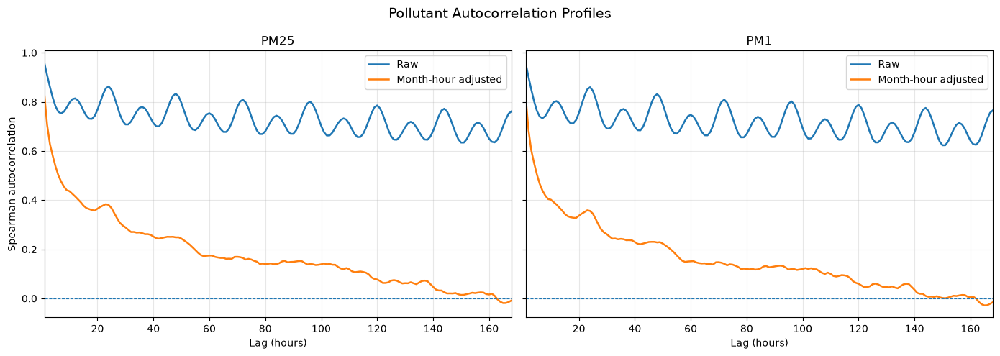

Pollutant  Lag_Hours  Raw_Spearman  Adjusted_Spearman  Raw_N  Adjusted_N
     PM25          1        0.9589             0.8321  10896       10896
     PM25          6        0.7596             0.5012  10774       10774
     PM25         12        0.8139             0.4152  10727       10727
     PM25         24        0.8629             0.3804  10659       10659
     PM25         48        0.8328             0.2485  10549       10549
     PM25         72        0.8086             0.1647  10504       10504
     PM25        120        0.7854             0.0770  10448       10448
     PM25        168        0.7612            -0.0086  10403       10403
      PM1          1        0.9560             0.8191  10896       10896
      PM1          6        0.7401             0.4665  10774       10774
      PM1         12        0.8030             0.3821  10727       10727
      PM1         24        0.8597             0.3560  10659       10659
      PM1         48        0.8316             0.22

In [240]:
from scipy.stats import spearmanr

# Calculate raw and month-hour-adjusted autocorrelation
pollutants = ["pm25", "pm1"]
max_lag = 168

autocorr_results = []

for pollutant in pollutants:

    series = analysis_data[pollutant]

    # Remove monthly and hourly average patterns
    baseline = series.groupby(
        [series.index.month, series.index.hour]
    ).transform("mean")

    adjusted = series - baseline

    for lag in range(1, max_lag + 1):

        raw_x = series.shift(lag)
        adj_x = adjusted.shift(lag)

        raw_valid = series.notna() & raw_x.notna()
        adj_valid = adjusted.notna() & adj_x.notna()

        raw_rho = spearmanr(
            raw_x[raw_valid], series[raw_valid]
        ).statistic

        adj_rho = spearmanr(
            adj_x[adj_valid], adjusted[adj_valid]
        ).statistic

        autocorr_results.append({
            "Pollutant": pollutant.upper(),
            "Lag_Hours": lag,
            "Raw_Spearman": raw_rho,
            "Adjusted_Spearman": adj_rho,
            "Raw_N": raw_valid.sum(),
            "Adjusted_N": adj_valid.sum()
        })

autocorr_results = pd.DataFrame(autocorr_results)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, pollutant in zip(axes, pollutants):

    data = autocorr_results[
        autocorr_results["Pollutant"] == pollutant.upper()
    ]

    ax.plot(
        data["Lag_Hours"],
        data["Raw_Spearman"],
        label="Raw",
        linewidth=1.8
    )

    ax.plot(
        data["Lag_Hours"],
        data["Adjusted_Spearman"],
        label="Month-hour adjusted",
        linewidth=1.8
    )

    ax.axhline(0, linestyle="--", linewidth=0.8)
    ax.set_title(pollutant.upper())
    ax.set_xlabel("Lag (hours)")
    ax.set_xlim(1, 168)
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Spearman autocorrelation")

fig.suptitle(
    "Pollutant Autocorrelation Profiles",
    fontsize=14
)

plt.tight_layout()
plt.show()

# Verify selected values against the report
print(
    autocorr_results[
        autocorr_results["Lag_Hours"].isin(
            [1, 6, 12, 24, 48, 72, 120, 168]
        )
    ].round(4).to_string(index=False)
)

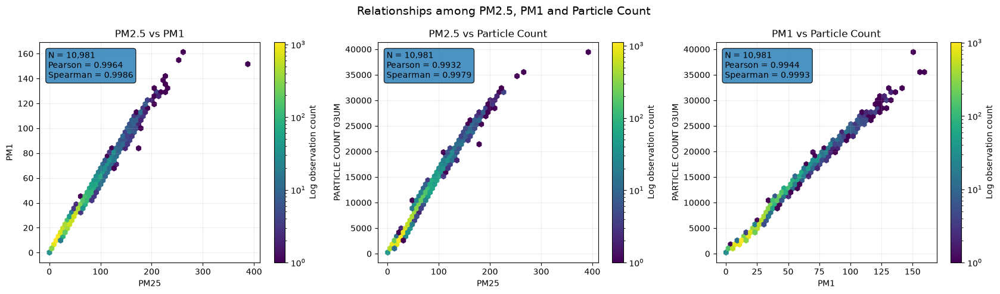

In [241]:
from scipy.stats import pearsonr, spearmanr

pairs = [
    ("pm25", "pm1", "PM2.5 vs PM1"),
    ("pm25", "particle_count_03um", "PM2.5 vs Particle Count"),
    ("pm1", "particle_count_03um", "PM1 vs Particle Count")
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (x, y, title) in zip(axes, pairs):

    valid = analysis_data[[x, y]].dropna()

    hb = ax.hexbin(
        valid[x],
        valid[y],
        gridsize=45,
        mincnt=1,
        bins="log"
    )

    ax.set_title(title)
    ax.set_xlabel(x.replace("_", " ").upper())
    ax.set_ylabel(y.replace("_", " ").upper())
    ax.grid(True, alpha=0.2)

    pearson = pearsonr(valid[x], valid[y]).statistic
    spearman = spearmanr(valid[x], valid[y]).statistic

    ax.text(
        0.04, 0.96,
        f"N = {len(valid):,}\nPearson = {pearson:.4f}\nSpearman = {spearman:.4f}",
        transform=ax.transAxes,
        verticalalignment="top",
        bbox=dict(boxstyle="round", alpha=0.8)
    )

    fig.colorbar(hb, ax=ax, label="Log observation count")

fig.suptitle(
    "Relationships among PM2.5, PM1 and Particle Count",
    fontsize=14
)

plt.tight_layout()
plt.show()

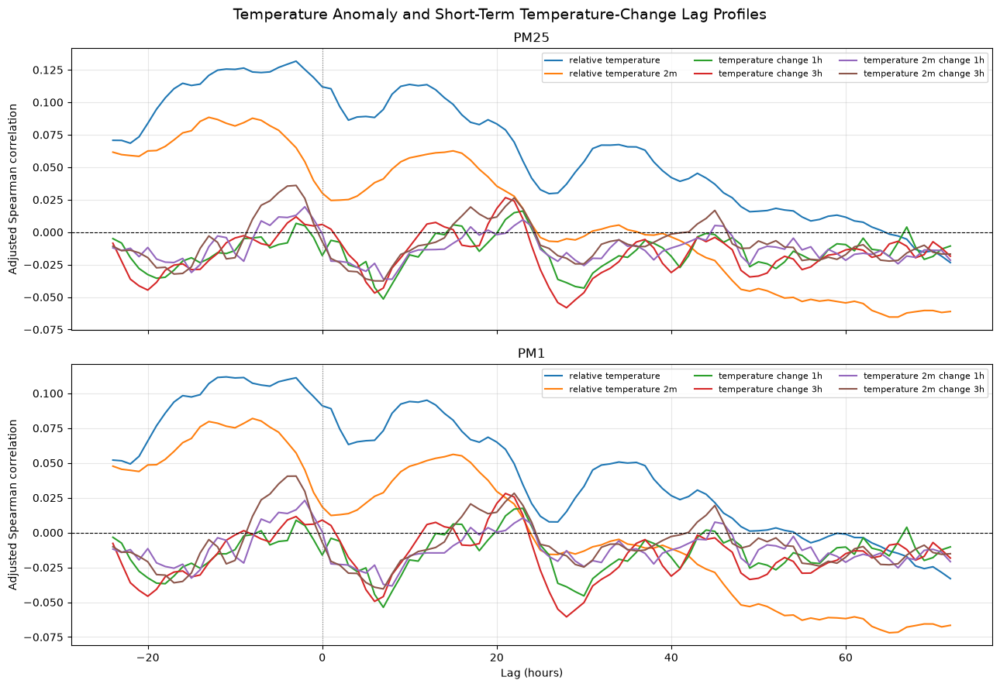

In [242]:
temperature_variables = [
    "relative_temperature",
    "relative_temperature_2m",
    "temperature_change_1h",
    "temperature_change_3h",
    "temperature_2m_change_1h",
    "temperature_2m_change_3h"
]

pollutants = ["pm25", "pm1"]
lags = range(-24, 73)

temperature_lag_results = []

for variable in temperature_variables:

    x = analysis_data[variable]
    x_adjusted = month_hour_residual(x)

    for pollutant in pollutants:

        y = analysis_data[pollutant]
        y_adjusted = month_hour_residual(y)

        for lag in lags:

            shifted_x = x_adjusted.shift(lag)
            valid = shifted_x.notna() & y_adjusted.notna()

            if valid.sum() >= 100:
                rho = spearmanr(
                    shifted_x[valid],
                    y_adjusted[valid]
                ).statistic
            else:
                rho = np.nan

            temperature_lag_results.append({
                "Variable": variable,
                "Pollutant": pollutant.upper(),
                "Lag_Hours": lag,
                "Spearman": rho,
                "N": valid.sum()
            })

temperature_lag_results = pd.DataFrame(temperature_lag_results)

# Plot
fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

for ax, pollutant in zip(axes, ["PM25", "PM1"]):

    subset = temperature_lag_results[
        temperature_lag_results["Pollutant"] == pollutant
    ]

    for variable in temperature_variables:

        data = subset[subset["Variable"] == variable]

        ax.plot(
            data["Lag_Hours"],
            data["Spearman"],
            label=variable.replace("_", " "),
            linewidth=1.5
        )

    ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
    ax.axvline(0, color="grey", linestyle=":", linewidth=0.8)
    ax.set_title(pollutant)
    ax.set_ylabel("Adjusted Spearman correlation")
    ax.grid(True, alpha=0.3)
    ax.legend(ncol=3, fontsize=8)

axes[-1].set_xlabel("Lag (hours)")

fig.suptitle(
    "Temperature Anomaly and Short-Term Temperature-Change Lag Profiles",
    fontsize=14
)

plt.tight_layout()
plt.show()

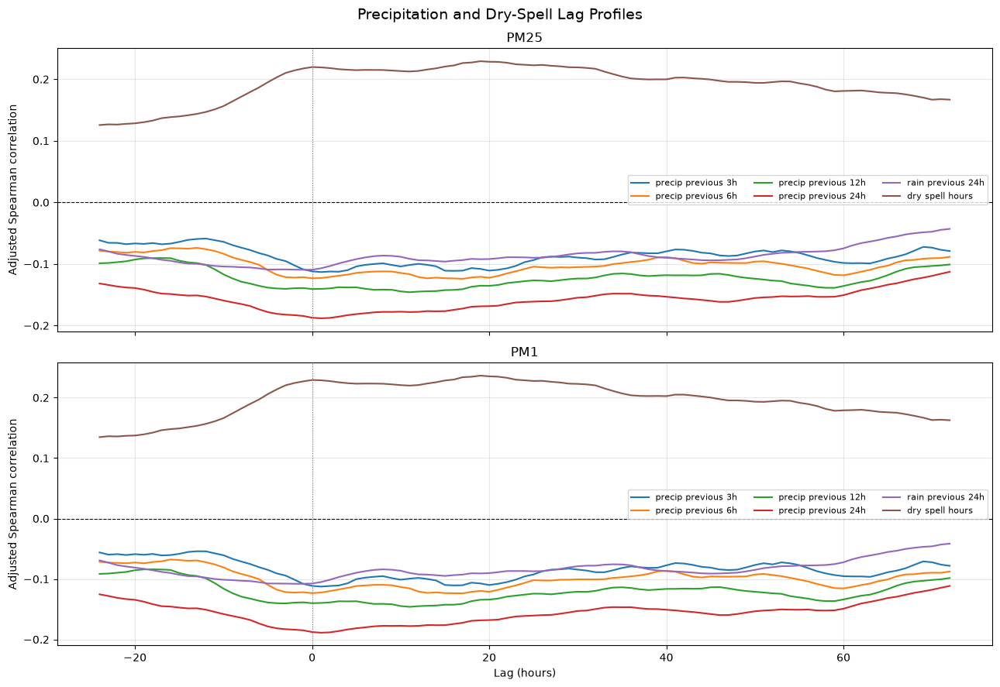

In [243]:
rain_variables = [
    "precip_previous_3h",
    "precip_previous_6h",
    "precip_previous_12h",
    "precip_previous_24h",
    "rain_previous_24h",
    "dry_spell_hours"
]

pollutants = ["pm25", "pm1"]
lags = range(-24, 73)

rain_lag_results = []

for variable in rain_variables:

    x = analysis_data[variable]
    x_adjusted = month_hour_residual(x)

    for pollutant in pollutants:

        y = analysis_data[pollutant]
        y_adjusted = month_hour_residual(y)

        for lag in lags:

            shifted_x = x_adjusted.shift(lag)
            valid = shifted_x.notna() & y_adjusted.notna()

            if valid.sum() >= 100:
                rho = spearmanr(
                    shifted_x[valid],
                    y_adjusted[valid]
                ).statistic
            else:
                rho = np.nan

            rain_lag_results.append({
                "Variable": variable,
                "Pollutant": pollutant.upper(),
                "Lag_Hours": lag,
                "Spearman": rho,
                "N": valid.sum()
            })

rain_lag_results = pd.DataFrame(rain_lag_results)

# Plot
fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

for ax, pollutant in zip(axes, ["PM25", "PM1"]):

    subset = rain_lag_results[
        rain_lag_results["Pollutant"] == pollutant
    ]

    for variable in rain_variables:

        data = subset[subset["Variable"] == variable]

        ax.plot(
            data["Lag_Hours"],
            data["Spearman"],
            label=variable.replace("_", " "),
            linewidth=1.5
        )

    ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
    ax.axvline(0, color="grey", linestyle=":", linewidth=0.8)
    ax.set_title(pollutant)
    ax.set_ylabel("Adjusted Spearman correlation")
    ax.grid(True, alpha=0.3)
    ax.legend(ncol=3, fontsize=8)

axes[-1].set_xlabel("Lag (hours)")

fig.suptitle(
    "Precipitation and Dry-Spell Lag Profiles",
    fontsize=14
)

plt.tight_layout()
plt.show()

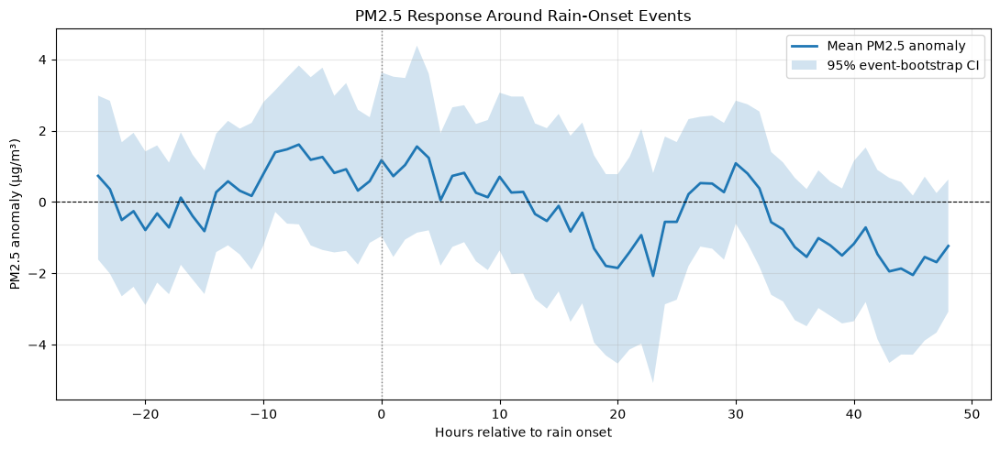

In [249]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    rain_onset_composite["Offset_Hours"],
    rain_onset_composite["Mean_PM25_Anomaly"],
    linewidth=2,
    label="Mean PM2.5 anomaly"
)

ax.fill_between(
    rain_onset_composite["Offset_Hours"],
    rain_onset_composite["CI_Lower_95"],
    rain_onset_composite["CI_Upper_95"],
    alpha=0.2,
    label="95% event-bootstrap CI"
)

ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
ax.axvline(0, color="grey", linestyle=":", linewidth=1)

ax.set_xlabel("Hours relative to rain onset")
ax.set_ylabel("PM2.5 anomaly (µg/m³)")
ax.set_title("PM2.5 Response Around Rain-Onset Events")
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

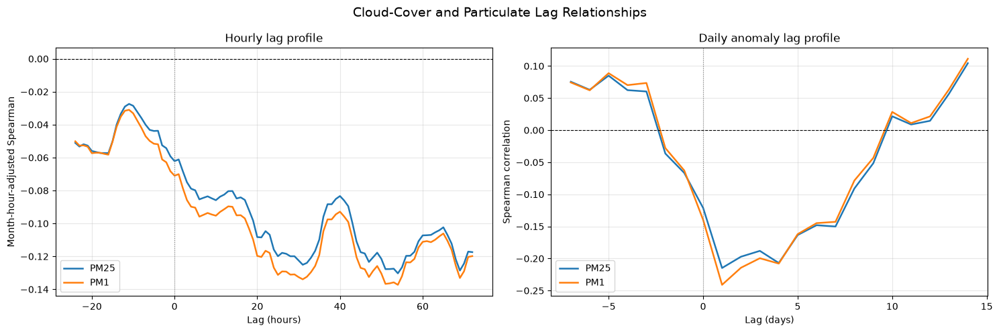

In [250]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Hourly lag profile
for pollutant in ["pm25", "pm1"]:

    data = cloud_lag_results[
        cloud_lag_results["Pollutant"].str.lower() == pollutant
    ].sort_values("Lag_Hours")

    axes[0].plot(
        data["Lag_Hours"],
        data["Adjusted_Spearman"],
        label=pollutant.upper(),
        linewidth=1.8
    )

axes[0].axhline(0, color="black", linestyle="--", linewidth=0.8)
axes[0].axvline(0, color="grey", linestyle=":", linewidth=0.8)
axes[0].set_title("Hourly lag profile")
axes[0].set_xlabel("Lag (hours)")
axes[0].set_ylabel("Month-hour-adjusted Spearman")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Daily anomaly lag profile
for pollutant in ["pm25", "pm1"]:

    data = cloud_daily_lag_results[
        cloud_daily_lag_results["Pollutant"].str.lower() == pollutant
    ].sort_values("Lag_Days")

    axes[1].plot(
        data["Lag_Days"],
        data["Spearman"],
        label=pollutant.upper(),
        linewidth=1.8
    )

axes[1].axhline(0, color="black", linestyle="--", linewidth=0.8)
axes[1].axvline(0, color="grey", linestyle=":", linewidth=0.8)
axes[1].set_title("Daily anomaly lag profile")
axes[1].set_xlabel("Lag (days)")
axes[1].set_ylabel("Spearman correlation")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

fig.suptitle("Cloud-Cover and Particulate Lag Relationships", fontsize=14)
plt.tight_layout()
plt.show()

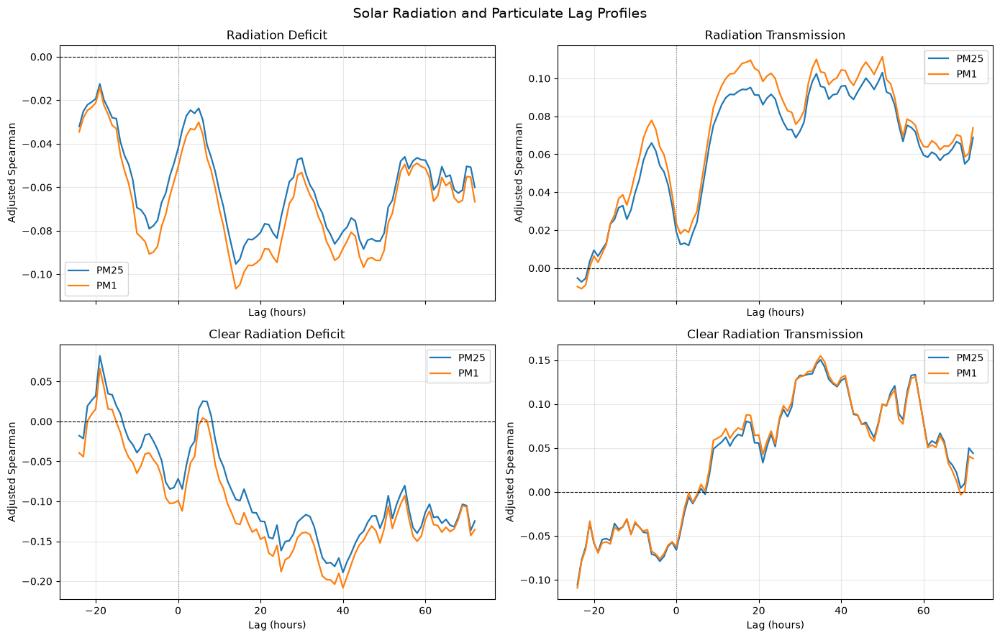

In [251]:
radiation_variables = [
    "radiation_deficit",
    "radiation_transmission",
    "clear_radiation_deficit",
    "clear_radiation_transmission"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)

for ax, variable in zip(axes.flat, radiation_variables):

    subset = radiation_lag_results[
        radiation_lag_results["Variable"] == variable
    ]

    for pollutant in ["pm25", "pm1"]:

        data = subset[
            subset["Pollutant"].str.lower() == pollutant
        ].sort_values("Lag_Hours")

        ax.plot(
            data["Lag_Hours"],
            data["Adjusted_Spearman"],
            label=pollutant.upper(),
            linewidth=1.6
        )

    ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
    ax.axvline(0, color="grey", linestyle=":", linewidth=0.8)
    ax.set_title(variable.replace("_", " ").title())
    ax.set_xlabel("Lag (hours)")
    ax.set_ylabel("Adjusted Spearman")
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.suptitle("Solar Radiation and Particulate Lag Profiles", fontsize=14)
plt.tight_layout()
plt.show()

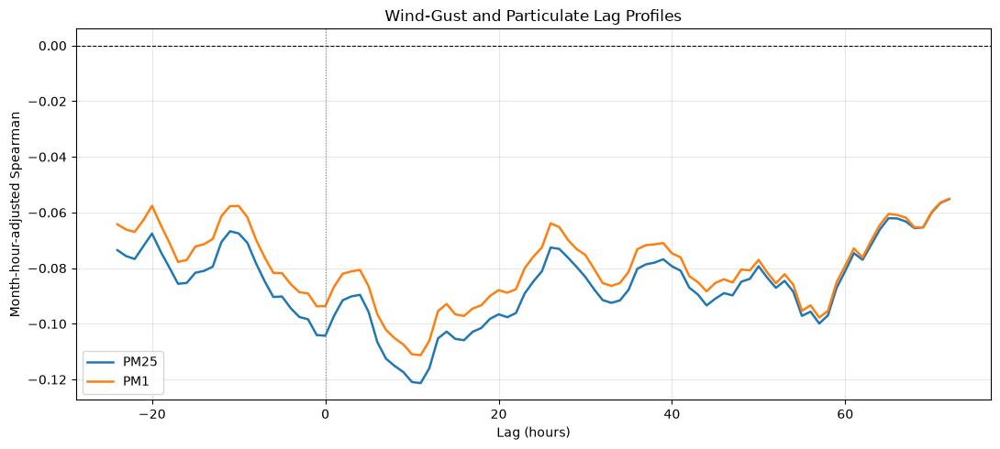

In [252]:
fig, ax = plt.subplots(figsize=(11, 5))

for pollutant in ["pm25", "pm1"]:

    data = gust_lag_results[
        gust_lag_results["Pollutant"].str.lower() == pollutant
    ].sort_values("Lag_Hours")

    ax.plot(
        data["Lag_Hours"],
        data["Adjusted_Spearman"],
        label=pollutant.upper(),
        linewidth=1.8
    )

ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
ax.axvline(0, color="grey", linestyle=":", linewidth=0.8)

ax.set_xlabel("Lag (hours)")
ax.set_ylabel("Month-hour-adjusted Spearman")
ax.set_title("Wind-Gust and Particulate Lag Profiles")
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

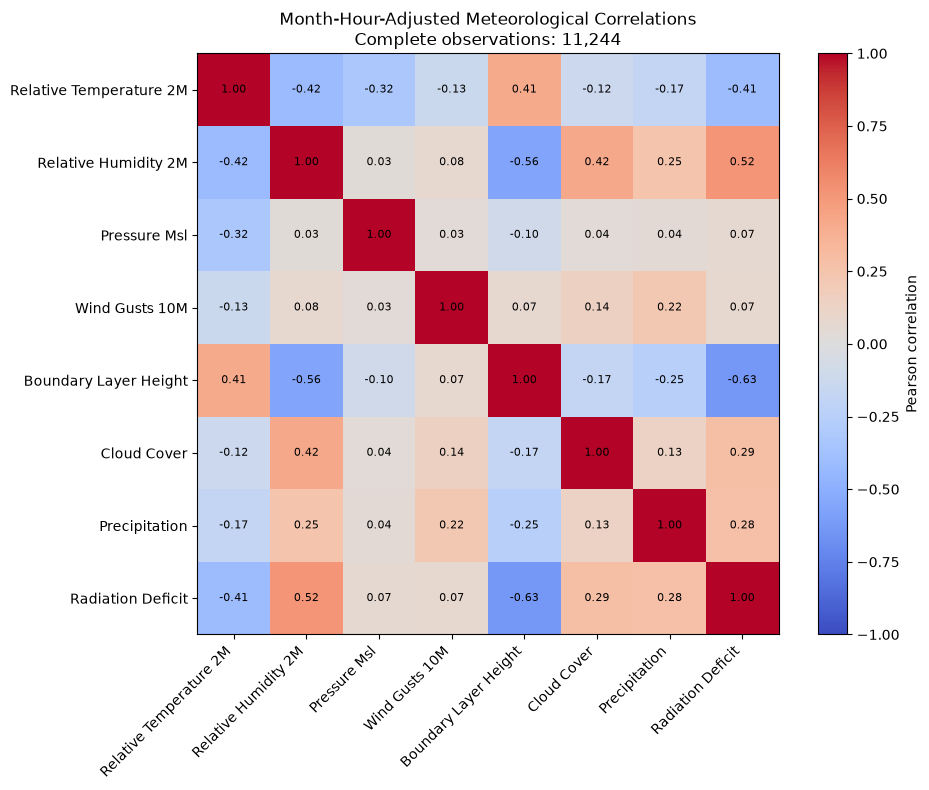

Adjusted correlation matrix:


,relative_temperature_2m,relative_humidity_2m,pressure_msl,wind_gusts_10m,boundary_layer_height,cloud_cover,precipitation,radiation_deficit
relative_temperature_2m,1.000,-0.419,-0.323,-0.132,0.410,-0.122,-0.174,-0.412
relative_humidity_2m,-0.419,1.000,0.026,0.077,-0.560,0.419,0.250,0.518
pressure_msl,-0.323,0.026,1.000,0.032,-0.098,0.037,0.044,0.067
wind_gusts_10m,-0.132,0.077,0.032,1.000,0.073,0.137,0.216,0.075
boundary_layer_height,0.410,-0.560,-0.098,0.073,1.000,-0.173,-0.253,-0.632
cloud_cover,-0.122,0.419,0.037,0.137,-0.173,1.000,0.130,0.288
precipitation,-0.174,0.250,0.044,0.216,-0.253,0.130,1.000,0.277
radiation_deficit,-0.412,0.518,0.067,0.075,-0.632,0.288,0.277,1.000


In [253]:
# Figure 4.8.9: Month-hour-adjusted meteorological correlation matrix

met_variables = [
    "relative_temperature_2m",
    "relative_humidity_2m",
    "pressure_msl",
    "wind_gusts_10m",
    "boundary_layer_height",
    "cloud_cover",
    "precipitation",
    "radiation_deficit"
]

# Use analysis_data because it contains all selected variables
met_data = analysis_data[met_variables].copy()

# Remove month-hour mean patterns
met_adjusted = pd.DataFrame(index=met_data.index)

for variable in met_variables:
    met_adjusted[variable] = month_hour_residual(met_data[variable])

# Complete-case correlation matrix
met_corr = met_adjusted.dropna().corr(method="pearson")

fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(
    met_corr,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(met_variables)))
ax.set_yticks(range(len(met_variables)))

labels = [v.replace("_", " ").title() for v in met_variables]

ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticklabels(labels)

for i in range(len(met_variables)):
    for j in range(len(met_variables)):
        ax.text(
            j, i,
            f"{met_corr.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

fig.colorbar(im, ax=ax, label="Pearson correlation")

ax.set_title(
    f"Month-Hour-Adjusted Meteorological Correlations\n"
    f"Complete observations: {met_adjusted.dropna().shape[0]:,}"
)

plt.tight_layout()
plt.show()

print("Adjusted correlation matrix:")
display(met_corr.round(3))

C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\3694466956.py:122: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


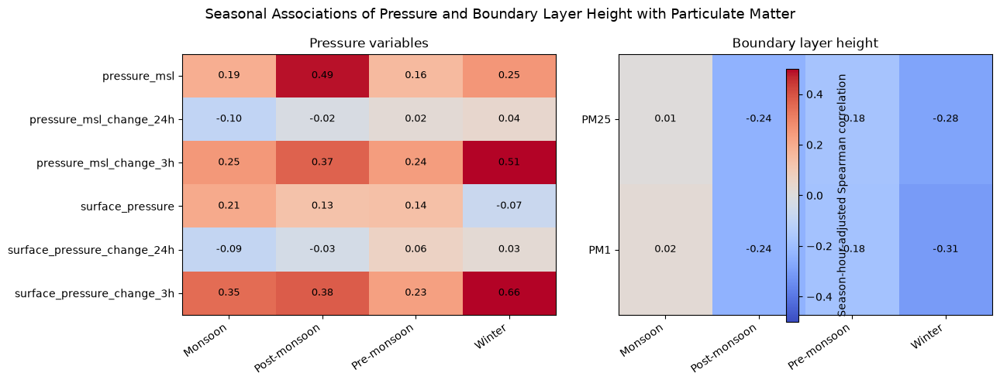

PRESSURE CORRELATIONS


,Season,Pressure_Variable,Pollutant,N,Pearson,Spearman
27,Monsoon,pressure_msl,PM1,4888,0.169,0.192
39,Post-monsoon,pressure_msl,PM1,1824,0.497,0.490
15,Pre-monsoon,pressure_msl,PM1,2129,0.157,0.159
3,Winter,pressure_msl,PM1,2140,0.248,0.267
26,Monsoon,pressure_msl,PM25,4888,0.166,0.191
38,Post-monsoon,pressure_msl,PM25,1824,0.494,0.483
14,Pre-monsoon,pressure_msl,PM25,2129,0.183,0.161
2,Winter,pressure_msl,PM25,2140,0.227,0.243
35,Monsoon,pressure_msl_change_24h,PM1,4704,-0.106,-0.087
47,Post-monsoon,pressure_msl_change_24h,PM1,1763,-0.041,-0.023


BOUNDARY LAYER HEIGHT CORRELATIONS


,Season,Pollutant,N,Pearson,Spearman
5,Monsoon,PM1,4589,0.116,0.022
7,Post-monsoon,PM1,1646,-0.211,-0.241
3,Pre-monsoon,PM1,2129,-0.101,-0.183
1,Winter,PM1,2140,-0.293,-0.305
4,Monsoon,PM25,4589,0.103,0.005
6,Post-monsoon,PM25,1646,-0.210,-0.240
2,Pre-monsoon,PM25,2129,-0.101,-0.178
0,Winter,PM25,2140,-0.271,-0.282


In [259]:
# Figure 4.8.10: Seasonal pressure and boundary layer height relationships

season_order = [
    "Monsoon",
    "Post-monsoon",
    "Pre-monsoon",
    "Winter"
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --------------------------------------------------
# Panel A: Seasonal pressure correlations
# --------------------------------------------------

pressure_data = seasonal_pressure_correlation_table.copy()

pressure_pivot = pressure_data.pivot_table(
    index="Pressure_Variable",
    columns="Season",
    values="Spearman",
    aggfunc="mean"
)

pressure_pivot = pressure_pivot.reindex(columns=season_order)

im1 = axes[0].imshow(
    pressure_pivot,
    cmap="coolwarm",
    vmin=-0.5,
    vmax=0.5,
    aspect="auto"
)

axes[0].set_xticks(range(len(season_order)))
axes[0].set_xticklabels(season_order, rotation=35, ha="right")

axes[0].set_yticks(range(len(pressure_pivot.index)))
axes[0].set_yticklabels(
    pressure_pivot.index.astype(str)
)

axes[0].set_title("Pressure variables")

for i in range(pressure_pivot.shape[0]):
    for j in range(pressure_pivot.shape[1]):
        value = pressure_pivot.iloc[i, j]

        if pd.notna(value):
            axes[0].text(
                j, i,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=9
            )

# --------------------------------------------------
# Panel B: Seasonal boundary layer height correlations
# --------------------------------------------------

blh_data = blh_season_corr_table.copy()

blh_pivot = blh_data.pivot_table(
    index="Pollutant",
    columns="Season",
    values="Spearman",
    aggfunc="mean"
)

blh_pivot = blh_pivot.reindex(
    index=["PM25", "PM1"],
    columns=season_order
)

im2 = axes[1].imshow(
    blh_pivot,
    cmap="coolwarm",
    vmin=-0.5,
    vmax=0.5,
    aspect="auto"
)

axes[1].set_xticks(range(len(season_order)))
axes[1].set_xticklabels(season_order, rotation=35, ha="right")

axes[1].set_yticks(range(len(blh_pivot.index)))
axes[1].set_yticklabels(blh_pivot.index)

axes[1].set_title("Boundary layer height")

for i in range(blh_pivot.shape[0]):
    for j in range(blh_pivot.shape[1]):
        value = blh_pivot.iloc[i, j]

        if pd.notna(value):
            axes[1].text(
                j, i,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=9
            )

# --------------------------------------------------
# Shared formatting
# --------------------------------------------------

fig.colorbar(
    im2,
    ax=axes,
    label="Season-hour-adjusted Spearman correlation",
    shrink=0.85
)

fig.suptitle(
    "Seasonal Associations of Pressure and Boundary Layer Height "
    "with Particulate Matter",
    fontsize=13
)

plt.tight_layout()
plt.show()

# --------------------------------------------------
# Supporting numerical results
# --------------------------------------------------

print("PRESSURE CORRELATIONS")
display(
    pressure_data.sort_values(
        ["Pressure_Variable", "Pollutant", "Season"]
    ).round(3)
)

print("BOUNDARY LAYER HEIGHT CORRELATIONS")
display(
    blh_data.sort_values(
        ["Pollutant", "Season"]
    ).round(3)
)

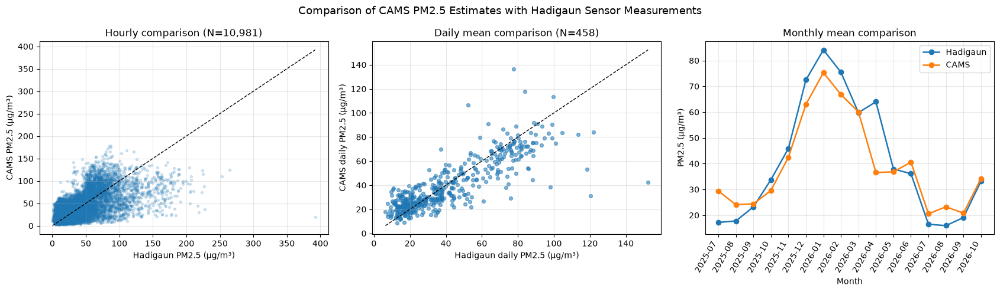

HOURLY COMPARISON
N: 10,981
Pearson r: 0.599
Spearman rho: 0.602

DAILY COMPARISON
N: 458
Pearson r: 0.828
Spearman rho: 0.830

MONTHLY COMPARISON


,Days,Hadigaun_Mean,CAMS_Mean,Mean_Bias
Month,,,,
2025-07,31,17.20,29.37,12.17
2025-08,30,17.77,24.08,6.30
2025-09,28,23.23,24.41,1.18
2025-10,28,33.75,29.58,-4.17
2025-11,29,45.88,42.45,-3.43
2025-12,31,72.47,62.95,-9.52
2026-01,31,84.11,75.29,-8.82
2026-02,28,75.45,66.80,-8.65
2026-03,31,59.76,60.08,0.31


In [258]:
# Figure 4.8.11: CAMS versus Hadigaun PM2.5 comparison

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Panel A: Hourly comparison
hourly = cams_matched.dropna(
    subset=["Hadigaun_PM25", "CAMS_PM25"]
)

axes[0].scatter(
    hourly["Hadigaun_PM25"],
    hourly["CAMS_PM25"],
    alpha=0.18,
    s=8
)

hourly_min = min(
    hourly["Hadigaun_PM25"].min(),
    hourly["CAMS_PM25"].min()
)

hourly_max = max(
    hourly["Hadigaun_PM25"].max(),
    hourly["CAMS_PM25"].max()
)

axes[0].plot(
    [hourly_min, hourly_max],
    [hourly_min, hourly_max],
    linestyle="--",
    color="black",
    linewidth=1
)

axes[0].set_title(
    f"Hourly comparison (N={len(hourly):,})"
)
axes[0].set_xlabel("Hadigaun PM2.5 (µg/m³)")
axes[0].set_ylabel("CAMS PM2.5 (µg/m³)")
axes[0].grid(True, alpha=0.3)


# Panel B: Daily mean comparison
daily = daily_cams.dropna(
    subset=["Hadigaun_PM25", "CAMS_PM25"]
)

axes[1].scatter(
    daily["Hadigaun_PM25"],
    daily["CAMS_PM25"],
    alpha=0.55,
    s=18
)

daily_min = min(
    daily["Hadigaun_PM25"].min(),
    daily["CAMS_PM25"].min()
)

daily_max = max(
    daily["Hadigaun_PM25"].max(),
    daily["CAMS_PM25"].max()
)

axes[1].plot(
    [daily_min, daily_max],
    [daily_min, daily_max],
    linestyle="--",
    color="black",
    linewidth=1
)

axes[1].set_title(
    f"Daily mean comparison (N={len(daily):,})"
)
axes[1].set_xlabel("Hadigaun daily PM2.5 (µg/m³)")
axes[1].set_ylabel("CAMS daily PM2.5 (µg/m³)")
axes[1].grid(True, alpha=0.3)


# Panel C: Monthly mean comparison
monthly = monthly_cams.copy()

monthly_labels = [
    str(month) for month in monthly.index
]

x = np.arange(len(monthly))

axes[2].plot(
    x,
    monthly["Hadigaun_Mean"],
    marker="o",
    linewidth=1.8,
    label="Hadigaun"
)

axes[2].plot(
    x,
    monthly["CAMS_Mean"],
    marker="o",
    linewidth=1.8,
    label="CAMS"
)

axes[2].set_xticks(x)
axes[2].set_xticklabels(
    monthly_labels,
    rotation=60,
    ha="right"
)

axes[2].set_title("Monthly mean comparison")
axes[2].set_xlabel("Month")
axes[2].set_ylabel("PM2.5 (µg/m³)")
axes[2].grid(True, alpha=0.3)
axes[2].legend()


fig.suptitle(
    "Comparison of CAMS PM2.5 Estimates with Hadigaun Sensor Measurements",
    fontsize=13
)

plt.tight_layout()
plt.show()


# Print supporting statistics
from scipy.stats import pearsonr, spearmanr

print("HOURLY COMPARISON")
print(f"N: {len(hourly):,}")
print(f"Pearson r: {pearsonr(hourly['Hadigaun_PM25'], hourly['CAMS_PM25']).statistic:.3f}")
print(f"Spearman rho: {spearmanr(hourly['Hadigaun_PM25'], hourly['CAMS_PM25']).statistic:.3f}")

print("\nDAILY COMPARISON")
print(f"N: {len(daily):,}")
print(f"Pearson r: {pearsonr(daily['Hadigaun_PM25'], daily['CAMS_PM25']).statistic:.3f}")
print(f"Spearman rho: {spearmanr(daily['Hadigaun_PM25'], daily['CAMS_PM25']).statistic:.3f}")

print("\nMONTHLY COMPARISON")
display(monthly[["Days", "Hadigaun_Mean", "CAMS_Mean", "Mean_Bias"]].round(2))

Few Additional Statistics

In [22]:
# 4.8 — CAMS AIR-QUALITY DATA AUDIT

print("CAMS DATA AUDIT")
print("=" * 75)

print("\nShape:", cams.shape)
print("\nData types:")
print(cams.dtypes)

print("\nFirst five rows:")
display(cams.head())

print("\nLast five rows:")
display(cams.tail())

print("\nTimestamp coverage:")
print("Start:", cams["datetime_utc"].min())
print("End:  ", cams["datetime_utc"].max())

pollutants = [
    "pm25",
    "pm10",
    "nitrogen_dioxide",
    "sulphur_dioxide",
    "carbon_monoxide",
    "aerosol_optical_depth"
]

print("\nPollutant descriptive statistics:")
display(cams[pollutants].describe().T.round(3))

print("\nMissing values:")
display(cams[pollutants].isna().sum().to_frame("Missing"))

CAMS DATA AUDIT

Shape: (37200, 7)

Data types:
datetime_utc             datetime64[us, UTC]
pm25                                 float64
pm10                                 float64
nitrogen_dioxide                     float64
sulphur_dioxide                      float64
carbon_monoxide                      float64
aerosol_optical_depth                float64
dtype: object

First five rows:


,datetime_utc,pm25,pm10,nitrogen_dioxide,sulphur_dioxide,carbon_monoxide,aerosol_optical_depth
0,2022-08-04 00:00:00+00:00,15.0,21.4,7.2,2.9,364.0,0.22
1,2022-08-04 01:00:00+00:00,13.2,18.7,6.9,2.7,353.0,0.22
2,2022-08-04 02:00:00+00:00,11.3,16.1,6.4,2.5,338.0,0.23
3,2022-08-04 03:00:00+00:00,11.7,16.7,5.5,2.2,313.0,0.23
4,2022-08-04 04:00:00+00:00,12.2,17.3,4.5,1.9,289.0,0.25



Last five rows:


,datetime_utc,pm25,pm10,nitrogen_dioxide,sulphur_dioxide,carbon_monoxide,aerosol_optical_depth
37195,2026-10-31 19:00:00+00:00,54.4,54.7,32.0,5.1,2110.0,0.26
37196,2026-10-31 20:00:00+00:00,51.7,52.0,24.6,5.2,1564.0,0.26
37197,2026-10-31 21:00:00+00:00,40.2,40.4,18.6,5.1,1130.0,0.26
37198,2026-10-31 22:00:00+00:00,38.5,38.8,15.7,4.6,908.0,0.27
37199,2026-10-31 23:00:00+00:00,36.0,36.2,14.3,4.0,798.0,0.26



Timestamp coverage:
Start: 2022-08-04 00:00:00+00:00
End:   2026-10-31 23:00:00+00:00

Pollutant descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
pm25,37200.0,36.127,24.570,0.20,18.60,29.90,46.30,178.80
pm10,37200.0,47.764,29.931,0.30,25.30,40.70,64.00,221.20
nitrogen_dioxide,37200.0,14.542,13.004,0.00,3.70,11.30,22.00,107.40
sulphur_dioxide,37200.0,7.162,5.184,0.00,3.80,5.80,8.80,38.00
carbon_monoxide,37200.0,733.589,494.528,59.00,373.00,581.00,933.00,3490.00
aerosol_optical_depth,37200.0,0.430,0.260,0.01,0.25,0.37,0.54,2.68



Missing values:


,Missing
pm25,0
pm10,0
nitrogen_dioxide,0
sulphur_dioxide,0
carbon_monoxide,0
aerosol_optical_depth,0


In [24]:
# 4.8 — EXACT CAMS–HADIGAUN TIMESTAMP MATCHING

import pandas as pd
import numpy as np
from scipy.stats import pearsonr, spearmanr

aq = master[["datetime", "pm25", "pm1"]].copy()

aq["datetime_utc"] = aq["datetime"].dt.tz_convert("UTC")
aq["Month"] = aq["datetime"].dt.month
aq["Hour"] = aq["datetime"].dt.hour

cams_vars = [
    "pm25",
    "pm10",
    "nitrogen_dioxide",
    "sulphur_dioxide",
    "carbon_monoxide",
    "aerosol_optical_depth"
]

cams_subset = cams[["datetime_utc"] + cams_vars].copy()

# Prefix CAMS columns to prevent collisions
cams_subset = cams_subset.rename(
    columns={col: f"CAMS_{col}" for col in cams_vars}
)

print("Duplicate Hadigaun timestamps:", aq["datetime_utc"].duplicated().sum())
print("Duplicate CAMS timestamps:", cams_subset["datetime_utc"].duplicated().sum())

matched_gas = aq.merge(
    cams_subset,
    on="datetime_utc",
    how="inner",
    validate="one_to_one"
)

print("\nMATCHING SUMMARY")
print("=" * 60)
print("Hadigaun records:", len(aq))
print("CAMS records:", len(cams_subset))
print("Matched records:", len(matched_gas))
print("Unmatched Hadigaun records:", len(aq) - len(matched_gas))
print("Matched period:", matched_gas["datetime"].min(),
      "to", matched_gas["datetime"].max())

print("\nMissing values:")
display(
    matched_gas[["pm25"] + [f"CAMS_{v}" for v in cams_vars]]
    .isna().sum().to_frame("Missing")
)

Duplicate Hadigaun timestamps: 0
Duplicate CAMS timestamps: 0

MATCHING SUMMARY
Hadigaun records: 10981
CAMS records: 37200
Matched records: 10981
Unmatched Hadigaun records: 0
Matched period: 2025-07-01 00:45:00+05:45 to 2026-10-19 08:45:00+05:45

Missing values:


,Missing
pm25,0
CAMS_pm25,0
CAMS_pm10,0
CAMS_nitrogen_dioxide,0
CAMS_sulphur_dioxide,0
CAMS_carbon_monoxide,0
CAMS_aerosol_optical_depth,0


In [25]:
# 4.8 — CAMS POLLUTANT ASSOCIATIONS WITH HADIGAUN PM2.5

def adjusted_correlation(df, x, y):
    temp = df[["Month", "Hour", x, y]].dropna().copy()

    temp["x_adj"] = (
        temp[x] -
        temp.groupby(["Month", "Hour"])[x].transform("mean")
    )

    temp["y_adj"] = (
        temp[y] -
        temp.groupby(["Month", "Hour"])[y].transform("mean")
    )

    return (
        len(temp),
        pearsonr(temp["x_adj"], temp["y_adj"])[0],
        spearmanr(temp["x_adj"], temp["y_adj"])[0]
    )


results = []

for variable in cams_vars:

    cam_col = f"CAMS_{variable}"

    d = matched_gas[["pm25", cam_col]].dropna()

    raw_pearson = pearsonr(d["pm25"], d[cam_col])[0]
    raw_spearman = spearmanr(d["pm25"], d[cam_col])[0]

    n_adj, adj_pearson, adj_spearman = adjusted_correlation(
        matched_gas, "pm25", cam_col
    )

    results.append({
        "CAMS_Variable": variable,
        "N_Raw": len(d),
        "Pearson_Raw": raw_pearson,
        "Spearman_Raw": raw_spearman,
        "N_Adjusted": n_adj,
        "Pearson_MonthHour_Adjusted": adj_pearson,
        "Spearman_MonthHour_Adjusted": adj_spearman
    })

gas_correlations = pd.DataFrame(results)

print("CAMS–HADIGAUN PM2.5 CORRELATIONS")
print("=" * 100)
display(gas_correlations.round(4))

CAMS–HADIGAUN PM2.5 CORRELATIONS


,CAMS_Variable,N_Raw,Pearson_Raw,Spearman_Raw,N_Adjusted,Pearson_MonthHour_Adjusted,Spearman_MonthHour_Adjusted
0,pm25,10981,0.5986,0.6023,10981,0.3635,0.3712
1,pm10,10981,0.5717,0.6381,10981,0.3242,0.3464
2,nitrogen_dioxide,10981,0.1823,0.1575,10981,0.1371,0.1450
3,sulphur_dioxide,10981,0.5578,0.6022,10981,0.2446,0.2749
4,carbon_monoxide,10981,0.3294,0.2929,10981,0.1637,0.2076
5,aerosol_optical_depth,10981,0.1277,0.0937,10981,0.2402,0.2461


In [26]:
# 4.8 — DESCRIPTIVE STATISTICS OF MATCHED CAMS VARIABLES

cam_columns = [f"CAMS_{v}" for v in cams_vars]

summary = matched_gas[cam_columns].describe().T

summary["Missing"] = matched_gas[cam_columns].isna().sum()
summary["Valid_Percent"] = (
    matched_gas[cam_columns].notna().mean() * 100
)

display(summary.round(3))

,count,mean,std,min,25%,50%,75%,max,Missing,Valid_Percent
CAMS_pm25,10981.0,39.620,28.006,1.60,18.70,32.90,51.20,178.80,0,100.0
CAMS_pm10,10981.0,46.874,32.847,1.70,21.10,38.80,64.50,198.80,0,100.0
CAMS_nitrogen_dioxide,10981.0,15.071,11.740,0.00,4.10,13.50,23.60,56.70,0,100.0
CAMS_sulphur_dioxide,10981.0,8.421,6.149,0.90,4.30,6.80,10.10,38.00,0,100.0
CAMS_carbon_monoxide,10981.0,877.000,524.630,83.00,475.00,714.00,1150.00,3490.00,0,100.0
CAMS_aerosol_optical_depth,10981.0,0.426,0.254,0.05,0.25,0.37,0.54,2.68,0,100.0


In [27]:
# 4.8 — SEASONAL CAMS–HADIGAUN ASSOCIATIONS

def assign_season(month):
    if month in [6, 7, 8, 9]:
        return "Monsoon"
    elif month in [10, 11]:
        return "Post-monsoon"
    elif month in [3, 4, 5]:
        return "Pre-monsoon"
    else:
        return "Winter"

matched_gas["Season"] = matched_gas["Month"].apply(assign_season)

seasonal_vars = [
    "CAMS_pm25",
    "CAMS_pm10",
    "CAMS_nitrogen_dioxide",
    "CAMS_sulphur_dioxide",
    "CAMS_carbon_monoxide",
    "CAMS_aerosol_optical_depth"
]

seasonal_results = []

for season in ["Monsoon", "Post-monsoon", "Pre-monsoon", "Winter"]:

    subset = matched_gas[matched_gas["Season"] == season]

    for variable in seasonal_vars:

        d = subset[["pm25", variable]].dropna()

        seasonal_results.append({
            "Season": season,
            "Variable": variable.replace("CAMS_", ""),
            "N": len(d),
            "Pearson_r": pearsonr(d["pm25"], d[variable])[0],
            "Spearman_r": spearmanr(d["pm25"], d[variable])[0]
        })

seasonal_gas_correlations = pd.DataFrame(seasonal_results)

print("SEASONAL CAMS–HADIGAUN CORRELATIONS")
print("=" * 80)

display(
    seasonal_gas_correlations
    .pivot(index="Variable", columns="Season", values="Spearman_r")
    .round(3)
)

print("\nSAMPLE SIZES")
display(
    seasonal_gas_correlations
    .pivot(index="Variable", columns="Season", values="N")
)

SEASONAL CAMS–HADIGAUN CORRELATIONS


Season,Monsoon,Post-monsoon,Pre-monsoon,Winter
Variable,,,,
aerosol_optical_depth,0.290,-0.103,0.268,0.011
carbon_monoxide,0.135,0.177,0.211,0.419
nitrogen_dioxide,-0.010,0.230,0.159,0.340
pm10,0.336,0.449,0.484,0.413
pm25,0.262,0.453,0.538,0.409
sulphur_dioxide,0.187,0.488,0.504,0.297



SAMPLE SIZES


Season,Monsoon,Post-monsoon,Pre-monsoon,Winter
Variable,,,,
aerosol_optical_depth,4888,1824,2129,2140
carbon_monoxide,4888,1824,2129,2140
nitrogen_dioxide,4888,1824,2129,2140
pm10,4888,1824,2129,2140
pm25,4888,1824,2129,2140
sulphur_dioxide,4888,1824,2129,2140


In [28]:
# 4.8 — DIAGNOSTIC: PRESSURE AND BLH LAG ANALYSES

keywords = [
    "pressure", "blh", "boundary_layer",
    "lag", "cross_corr", "lag_corr"
]

print("EXISTING DATAFRAMES WITH PRESSURE / BLH / LAG VARIABLES")
print("=" * 85)

for name, obj in list(globals().items()):

    if isinstance(obj, pd.DataFrame):

        matches = [
            col for col in obj.columns
            if any(k in str(col).lower() for k in keywords)
        ]

        if matches:
            print(f"\nDataFrame: {name} | Shape: {obj.shape}")
            print("Matching columns:", matches)

            # Display a small sample only
            display(obj[matches].head(3))

print("\nEXISTING NON-DATAFRAME VARIABLES")
print("=" * 85)

for name, obj in list(globals().items()):

    if any(k in name.lower() for k in keywords):
        if not isinstance(obj, pd.DataFrame):
            print(name, ":", type(obj).__name__)

EXISTING DATAFRAMES WITH PRESSURE / BLH / LAG VARIABLES

DataFrame: master | Shape: (10981, 26)
Matching columns: ['surface_pressure', 'pressure_msl', 'boundary_layer_height']


,surface_pressure,pressure_msl,boundary_layer_height
0,862.8,1004.3,35.0
1,862.9,1004.6,45.0
2,862.1,1003.7,25.0



DataFrame: m47 | Shape: (10981, 32)
Matching columns: ['surface_pressure', 'pressure_msl', 'boundary_layer_height']


,surface_pressure,pressure_msl,boundary_layer_height
0,862.8,1004.3,35.0
1,862.9,1004.6,45.0
2,862.1,1003.7,25.0



DataFrame: daily47 | Shape: (458, 16)
Matching columns: ['Pressure_MSL', 'Surface_Pressure']


,Pressure_MSL,Surface_Pressure
0,1003.9625,863.450000
1,1005.0250,864.291667
2,1005.6375,864.870833


... (17 outputs left out)

,surface_pressure,pressure_msl,boundary_layer_height
0,862.8,1004.3,35.0
1,862.9,1004.6,45.0
2,862.1,1003.7,25.0



DataFrame: data | Shape: (10981, 19)
Matching columns: ['surface_pressure', 'pressure_msl', 'boundary_layer_height']


,surface_pressure,pressure_msl,boundary_layer_height
0,862.8,1004.3,35.0
1,862.9,1004.6,45.0
2,862.1,1003.7,25.0



EXISTING NON-DATAFRAME VARIABLES
lag : int
pressure_variables : list
pressure_var : str


In [29]:
# 4.8 — DIAGNOSTIC: EXISTING LAG-RESULT TABLES

print("POTENTIAL LAG-RESULT TABLES")
print("=" * 85)

for name, obj in list(globals().items()):

    if not isinstance(obj, pd.DataFrame):
        continue

    cols = [str(c).lower() for c in obj.columns]

    # Identify likely lag-result tables
    has_lag = any(
        "lag" in c or "relative_hour" in c
        for c in cols
    )

    has_variable = any(
        "variable" in c or "predictor" in c or
        "weather" in c or "feature" in c
        for c in cols
    )

    if has_lag and (has_variable or len(obj.columns) <= 12):

        print(f"\n{name}: {obj.shape}")
        print("Columns:", list(obj.columns))

        display(obj.head(5))

        # Report likely lag range
        for col in obj.columns:
            if any(k in str(col).lower() for k in
                   ["lag", "relative_hour"]):
                numeric = pd.to_numeric(obj[col], errors="coerce").dropna()

                if len(numeric):
                    print(
                        f"{col}: min={numeric.min()}, "
                        f"max={numeric.max()}, "
                        f"unique={numeric.nunique()}"
                    )

POTENTIAL LAG-RESULT TABLES

previous: (10981, 2)
Columns: ['datetime', 'pressure_msl_lag24']


,datetime,pressure_msl_lag24
0,2025-07-02 00:45:00+05:45,1004.3
1,2025-07-02 01:45:00+05:45,1004.6
2,2025-07-02 02:45:00+05:45,1003.7
3,2025-07-02 03:45:00+05:45,1003.4
4,2025-07-02 04:45:00+05:45,1003.5


pressure_msl_lag24: min=996.6, max=1023.4, unique=250


In [30]:
# 4.8 — PRESSURE LAG-RESULT REVIEW

for name in ["pressure_corr_results", "pressure_adjusted_results"]:

    if name in globals():
        df = globals()[name]

        print(f"\n{name.upper()}")
        print("=" * 80)
        print("Shape:", df.shape)
        print("Columns:", list(df.columns))

        display(df.round(4))
    else:
        print(f"{name} not found.")


PRESSURE_CORR_RESULTS
Shape: (32, 8)
Columns: ['Season', 'Pressure_Change', 'Pollutant', 'N', 'Pearson_r', 'Pearson_p', 'Spearman_r', 'Spearman_p']


,Season,Pressure_Change,Pollutant,N,Pearson_r,Pearson_p,Spearman_r,Spearman_p
0,Winter,surface_pressure_change_3h,PM25,2121,0.5990,0.0000,0.6524,0.0000
1,Winter,surface_pressure_change_3h,PM1,2121,0.6106,0.0000,0.6592,0.0000
2,Winter,surface_pressure_change_24h,PM25,2121,0.0303,0.1626,0.0275,0.2059
3,Winter,surface_pressure_change_24h,PM1,2121,0.0234,0.2820,0.0251,0.2475
4,Winter,pressure_msl_change_3h,PM25,2121,0.4910,0.0000,0.5010,0.0000
5,Winter,pressure_msl_change_3h,PM1,2121,0.5114,0.0000,0.5140,0.0000
6,Winter,pressure_msl_change_24h,PM25,2121,0.0319,0.1414,0.0391,0.0715
7,Winter,pressure_msl_change_24h,PM1,2121,0.0277,0.2024,0.0391,0.0721
8,Pre-monsoon,surface_pressure_change_3h,PM25,2102,0.2439,0.0000,0.2256,0.0000
9,Pre-monsoon,surface_pressure_change_3h,PM1,2102,0.2565,0.0000,0.2368,0.0000



PRESSURE_ADJUSTED_RESULTS
Shape: (96, 7)
Columns: ['Season', 'Pressure_Change', 'Pollutant', 'Adjustment', 'N', 'Pearson_r', 'Spearman_r']


,Season,Pressure_Change,Pollutant,Adjustment,N,Pearson_r,Spearman_r
0,Winter,surface_pressure_change_3h,PM25,Raw,2121,0.5990,0.6524
1,Winter,surface_pressure_change_3h,PM25,Month-adjusted,2121,0.6044,0.6543
2,Winter,surface_pressure_change_3h,PM25,Month-hour-adjusted,2121,0.0015,0.0263
3,Winter,surface_pressure_change_3h,PM1,Raw,2121,0.6106,0.6592
4,Winter,surface_pressure_change_3h,PM1,Month-adjusted,2121,0.6160,0.6580
...,...,...,...,...,...,...,...
91,Post-monsoon,pressure_msl_change_24h,PM25,Month-adjusted,1763,-0.0191,-0.0207
92,Post-monsoon,pressure_msl_change_24h,PM25,Month-hour-adjusted,1763,-0.0323,-0.0444
93,Post-monsoon,pressure_msl_change_24h,PM1,Raw,1763,-0.0412,-0.0235
94,Post-monsoon,pressure_msl_change_24h,PM1,Month-adjusted,1763,-0.0282,-0.0277


In [31]:
# 4.8 — FIND COMPLETE HOURLY WEATHER DATA FOR BLH LAGS

print("DATAFRAMES CONTAINING BLH")
print("=" * 80)

for name, obj in list(globals().items()):

    if not isinstance(obj, pd.DataFrame):
        continue

    blh_cols = [
        c for c in obj.columns
        if "boundary_layer_height" in str(c).lower()
    ]

    if blh_cols:
        print(f"\nDataFrame: {name}")
        print("Shape:", obj.shape)
        print("BLH columns:", blh_cols)

        if "datetime" in obj.columns:
            dt = pd.to_datetime(obj["datetime"])

            print("Start:", dt.min())
            print("End:", dt.max())
            print("Unique timestamps:", dt.nunique())

            differences = dt.sort_values().diff().dropna()
            print("Most common timestamp intervals:")
            display(differences.value_counts().head(5).to_frame("Count"))

        print("Valid BLH observations:",
              obj[blh_cols].notna().sum().to_dict())

DATAFRAMES CONTAINING BLH

DataFrame: master
Shape: (10981, 26)
BLH columns: ['boundary_layer_height']
Start: 2025-07-01 00:45:00+05:45
End: 2026-10-19 08:45:00+05:45
Unique timestamps: 10981
Most common timestamp intervals:


,Count
datetime,
0 days 01:00:00,10896
0 days 02:00:00,47
0 days 04:00:00,8
0 days 03:00:00,7
0 days 05:00:00,5


Valid BLH observations: {'boundary_layer_height': 10504}

DataFrame: m47
Shape: (10981, 32)
BLH columns: ['boundary_layer_height']
Start: 2025-07-01 00:45:00+05:45
End: 2026-10-19 08:45:00+05:45
Unique timestamps: 10981
Most common timestamp intervals:


,Count
datetime,
0 days 01:00:00,10896
0 days 02:00:00,47
0 days 04:00:00,8
0 days 03:00:00,7
0 days 05:00:00,5


Valid BLH observations: {'boundary_layer_height': 10504}

DataFrame: part
Shape: (459, 32)
BLH columns: ['boundary_layer_height']
Start: 2025-10-01 18:45:00+05:45
End: 2026-10-18 23:45:00+05:45
Unique timestamps: 459
Most common timestamp intervals:


,Count
datetime,
0 days 01:00:00,381
0 days 19:00:00,72
0 days 20:00:00,2
2 days 19:00:00,1
0 days 02:00:00,1


Valid BLH observations: {'boundary_layer_height': 417}

DataFrame: corr_data
Shape: (10981, 20)
BLH columns: ['boundary_layer_height']
Start: 2025-07-01 00:45:00+05:45
End: 2026-10-19 08:45:00+05:45
Unique timestamps: 10981
Most common timestamp intervals:


,Count
datetime,
0 days 01:00:00,10896
0 days 02:00:00,47
0 days 04:00:00,8
0 days 03:00:00,7
0 days 05:00:00,5


Valid BLH observations: {'boundary_layer_height': 10504}

DataFrame: data
Shape: (10981, 19)
BLH columns: ['boundary_layer_height']
Start: 2025-07-01 00:45:00+05:45
End: 2026-10-19 08:45:00+05:45
Unique timestamps: 10981
Most common timestamp intervals:


,Count
datetime,
0 days 01:00:00,10896
0 days 02:00:00,47
0 days 04:00:00,8
0 days 03:00:00,7
0 days 05:00:00,5


Valid BLH observations: {'boundary_layer_height': 10504}


In [32]:
# 4.8 — EXISTING PRESSURE RESULTS: MONTH-HOUR ADJUSTED

pressure_final = pressure_adjusted_results[
    pressure_adjusted_results["Adjustment"] == "Month-hour-adjusted"
].copy()

print("MONTH-HOUR-ADJUSTED PRESSURE RESULTS")
print("=" * 85)

display(
    pressure_final[
        ["Season", "Pressure_Change", "Pollutant", "N",
         "Pearson_r", "Spearman_r"]
    ]
    .sort_values(["Pressure_Change", "Season", "Pollutant"])
    .round(4)
    .reset_index(drop=True)
)

MONTH-HOUR-ADJUSTED PRESSURE RESULTS


,Season,Pressure_Change,Pollutant,N,Pearson_r,Spearman_r
0,Monsoon,pressure_msl_change_24h,PM1,4704,-0.0602,-0.0489
1,Monsoon,pressure_msl_change_24h,PM25,4704,-0.0816,-0.0697
2,Post-monsoon,pressure_msl_change_24h,PM1,1763,-0.0440,-0.0539
3,Post-monsoon,pressure_msl_change_24h,PM25,1763,-0.0323,-0.0444
4,Pre-monsoon,pressure_msl_change_24h,PM1,2071,0.0855,0.0759
5,Pre-monsoon,pressure_msl_change_24h,PM25,2071,0.0789,0.0655
6,Winter,pressure_msl_change_24h,PM1,2121,0.0268,0.0498
7,Winter,pressure_msl_change_24h,PM25,2121,0.0412,0.0533
8,Monsoon,pressure_msl_change_3h,PM1,4812,-0.0178,-0.0088
9,Monsoon,pressure_msl_change_3h,PM25,4812,-0.0218,-0.0124


In [33]:
# 4.8 — LOCATE COMPLETE HOURLY WEATHER TIMELINE

print("WEATHER DATAFRAME INVENTORY")
print("=" * 85)

for name, obj in list(globals().items()):

    if not isinstance(obj, pd.DataFrame):
        continue

    datetime_cols = [
        c for c in obj.columns
        if "datetime" in str(c).lower() or
           str(c).lower() in ["time", "timestamp"]
    ]

    weather_cols = [
        c for c in obj.columns
        if any(k in str(c).lower() for k in [
            "pressure", "boundary_layer", "blh"
        ])
    ]

    if datetime_cols and weather_cols:

        dt_col = datetime_cols[0]
        dates = pd.to_datetime(obj[dt_col], errors="coerce").dropna()

        intervals = dates.sort_values().diff().value_counts()

        print(f"\nDataFrame: {name}")
        print("Shape:", obj.shape)
        print("Datetime column:", dt_col)
        print("Weather columns:", weather_cols)
        print("Valid timestamps:", len(dates))

        if len(dates):
            print("Start:", dates.min())
            print("End:", dates.max())
            print("Most common intervals:")
            display(intervals.head(5).to_frame("Count"))

WEATHER DATAFRAME INVENTORY

DataFrame: master
Shape: (10981, 26)
Datetime column: datetime
Weather columns: ['surface_pressure', 'pressure_msl', 'boundary_layer_height']
Valid timestamps: 10981
Start: 2025-07-01 00:45:00+05:45
End: 2026-10-19 08:45:00+05:45
Most common intervals:


,Count
datetime,
0 days 01:00:00,10896
0 days 02:00:00,47
0 days 04:00:00,8
0 days 03:00:00,7
0 days 05:00:00,5



DataFrame: m47
Shape: (10981, 32)
Datetime column: datetime
Weather columns: ['surface_pressure', 'pressure_msl', 'boundary_layer_height']
Valid timestamps: 10981
Start: 2025-07-01 00:45:00+05:45
End: 2026-10-19 08:45:00+05:45
Most common intervals:


,Count
datetime,
0 days 01:00:00,10896
0 days 02:00:00,47
0 days 04:00:00,8
0 days 03:00:00,7
0 days 05:00:00,5



DataFrame: part
Shape: (459, 32)
Datetime column: datetime
Weather columns: ['surface_pressure', 'pressure_msl', 'boundary_layer_height']
Valid timestamps: 459
Start: 2025-10-01 18:45:00+05:45
End: 2026-10-18 23:45:00+05:45
Most common intervals:


,Count
datetime,
0 days 01:00:00,381
0 days 19:00:00,72
0 days 20:00:00,2
2 days 19:00:00,1
0 days 02:00:00,1


... (8 outputs left out)


DataFrame: corr_data
Shape: (10981, 20)
Datetime column: datetime
Weather columns: ['surface_pressure', 'pressure_msl', 'boundary_layer_height']
Valid timestamps: 10981
Start: 2025-07-01 00:45:00+05:45
End: 2026-10-19 08:45:00+05:45
Most common intervals:


,Count
datetime,
0 days 01:00:00,10896
0 days 02:00:00,47
0 days 04:00:00,8
0 days 03:00:00,7
0 days 05:00:00,5



DataFrame: data
Shape: (10981, 19)
Datetime column: datetime
Weather columns: ['surface_pressure', 'pressure_msl', 'boundary_layer_height']
Valid timestamps: 10981
Start: 2025-07-01 00:45:00+05:45
End: 2026-10-19 08:45:00+05:45
Most common intervals:


,Count
datetime,
0 days 01:00:00,10896
0 days 02:00:00,47
0 days 04:00:00,8
0 days 03:00:00,7
0 days 05:00:00,5


In [34]:
DATASET_DIR = Path(r'D:/MSDSA/4th Sem/Thesis/Dataset')
weather_raw = pd.read_csv(DATASET_DIR / "weather_data_hadigaun.csv", parse_dates=["datetime"])

In [35]:
import pandas as pd
import numpy as np

# Ensure timestamps are consistently represented in Nepal time
weather_raw["datetime"] = pd.to_datetime(weather_raw["datetime"])

if weather_raw["datetime"].dt.tz is None:
    weather_raw["datetime"] = weather_raw["datetime"].dt.tz_localize("Asia/Kathmandu")
else:
    weather_raw["datetime"] = weather_raw["datetime"].dt.tz_convert("Asia/Kathmandu")

# Sort and check for duplicate timestamps
weather_hourly = weather_raw.set_index("datetime").sort_index()

print("Original weather shape:", weather_hourly.shape)
print("Duplicate timestamps:", weather_hourly.index.duplicated().sum())

if weather_hourly.index.has_duplicates:
    raise ValueError("Duplicate weather timestamps found. Resolve these before calculating lags.")

# Reindex to a complete hourly timeline; absent timestamps become NaN
full_index = pd.date_range(
    start=weather_hourly.index.min(),
    end=weather_hourly.index.max(),
    freq="h"
)

missing_timestamps = len(full_index.difference(weather_hourly.index))
weather_hourly = weather_hourly.reindex(full_index)
weather_hourly.index.name = "datetime"

print("Complete hourly timeline:", weather_hourly.shape)
print("Missing hourly timestamps inserted:", missing_timestamps)
print("Timeline start:", weather_hourly.index.min())
print("Timeline end:", weather_hourly.index.max())

# Check the three variables required for this analysis
variables = [
    "boundary_layer_height",
    "pressure_msl",
    "surface_pressure"
]

for col in variables:
    if col not in weather_hourly.columns:
        raise KeyError(f"Missing required weather column: {col}")
    print(f"{col}: {weather_hourly[col].notna().sum()} valid / {len(weather_hourly)}")

Original weather shape: (11736, 20)
Duplicate timestamps: 0
Complete hourly timeline: (11736, 20)
Missing hourly timestamps inserted: 0
Timeline start: 2025-06-30 05:45:00+05:45
Timeline end: 2026-11-01 04:45:00+05:45
boundary_layer_height: 11244 valid / 11736
pressure_msl: 11736 valid / 11736
surface_pressure: 11736 valid / 11736


In [36]:
lagged_weather = pd.DataFrame(index=weather_hourly.index)

for variable in variables:
    for lag in range(-24, 73):
        lagged_weather[f"{variable}_lag_{lag}"] = weather_hourly[variable].shift(lag)

# Align the lagged weather variables with the original sensor observations
sensor = master.set_index("datetime")[["pm25", "pm1"]].copy()
sensor = sensor.sort_index()

if sensor.index.tz is None:
    sensor.index = sensor.index.tz_localize("Asia/Kathmandu")
else:
    sensor.index = sensor.index.tz_convert("Asia/Kathmandu")

lag_analysis = sensor.join(lagged_weather, how="left")

print("Sensor observations:", len(sensor))
print("Aligned observations:", len(lag_analysis))
print("Lagged weather columns:", lagged_weather.shape[1])
print("PM2.5 observations:", lag_analysis["pm25"].notna().sum())
print("PM1 observations:", lag_analysis["pm1"].notna().sum())

C:\Users\ianus\AppData\Local\Temp\ipykernel_16392\127987071.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  lagged_weather[f"{variable}_lag_{lag}"] = weather_hourly[variable].shift(lag)


Sensor observations: 10981
Aligned observations: 10981
Lagged weather columns: 291
PM2.5 observations: 10981
PM1 observations: 10981


In [40]:
results = []

for variable in variables:
    for lag in range(-24, 73):

        x_col = f"{variable}_lag_{lag}"

        for pollutant in ["pm25", "pm1"]:

            pair = lag_analysis[[x_col, pollutant]].dropna().copy()
            pair.columns = ["x", "y"]

            n = len(pair)
            if n < 30:
                continue

            pair["month_hour"] = (
                pair.index.month.astype(str) + "_" +
                pair.index.hour.astype(str)
            )

            # Raw correlations
            pearson_raw = pair["x"].corr(pair["y"], method="pearson")
            spearman_raw = pair["x"].corr(pair["y"], method="spearman")

            # Month-hour adjusted Pearson
            x_resid = pair["x"] - pair.groupby("month_hour")["x"].transform("mean")
            y_resid = pair["y"] - pair.groupby("month_hour")["y"].transform("mean")

            pearson_adj = x_resid.corr(y_resid)

            # Rank first, then remove month-hour effects
            x_rank = pair["x"].rank(method="average")
            y_rank = pair["y"].rank(method="average")

            x_rank_resid = (
                x_rank - x_rank.groupby(pair["month_hour"]).transform("mean")
            )
            y_rank_resid = (
                y_rank - y_rank.groupby(pair["month_hour"]).transform("mean")
            )

            spearman_adj = x_rank_resid.corr(y_rank_resid)

            results.append({
                "Variable": variable,
                "Lag_h": lag,
                "Pollutant": pollutant,
                "N": n,
                "Pearson_raw": pearson_raw,
                "Spearman_raw": spearman_raw,
                "Pearson_adjusted": pearson_adj,
                "Spearman_adjusted": spearman_adj
            })

lag_results = pd.DataFrame(results)

print("Result rows:", len(lag_results))
display(lag_results.head(10).round(4))

Result rows: 582


,Variable,Lag_h,Pollutant,N,Pearson_raw,Spearman_raw,Pearson_adjusted,Spearman_adjusted
0,boundary_layer_height,-24,pm25,10504,-0.0382,-0.1938,-0.0562,-0.0923
1,boundary_layer_height,-24,pm1,10504,-0.0455,-0.1946,-0.0533,-0.0923
2,boundary_layer_height,-23,pm25,10504,-0.1010,-0.2469,-0.0563,-0.0980
3,boundary_layer_height,-23,pm1,10504,-0.1093,-0.2501,-0.0530,-0.0983
4,boundary_layer_height,-22,pm25,10504,-0.1319,-0.2786,-0.0517,-0.1046
5,boundary_layer_height,-22,pm1,10504,-0.1401,-0.2834,-0.0484,-0.1049
6,boundary_layer_height,-21,pm25,10504,-0.1280,-0.2889,-0.0380,-0.1053
7,boundary_layer_height,-21,pm1,10504,-0.1353,-0.2944,-0.0343,-0.1059
8,boundary_layer_height,-20,pm25,10504,-0.0973,-0.2775,-0.0236,-0.0994
9,boundary_layer_height,-20,pm1,10504,-0.1033,-0.2829,-0.0198,-0.1001


In [41]:
for variable in variables:
    for pollutant in ["pm25", "pm1"]:

        subset = lag_results[
            (lag_results["Variable"] == variable) &
            (lag_results["Pollutant"] == pollutant)
        ].copy()

        subset["Abs_adjusted"] = subset["Spearman_adjusted"].abs()

        print(f"\n{variable} — {pollutant.upper()}")

        display(
            subset.nlargest(8, "Abs_adjusted")[
                ["Lag_h", "N", "Pearson_raw", "Spearman_raw",
                 "Pearson_adjusted", "Spearman_adjusted"]
            ].round(4)
        )


boundary_layer_height — PM25


,Lag_h,N,Pearson_raw,Spearman_raw,Pearson_adjusted,Spearman_adjusted
56,4,10504,-0.0957,-0.2940,-0.0157,-0.1742
54,3,10504,-0.1278,-0.3045,-0.0368,-0.1740
52,2,10504,-0.1310,-0.2930,-0.0497,-0.1691
58,5,10504,-0.0481,-0.2656,0.0042,-0.1674
50,1,10504,-0.1015,-0.2610,-0.0605,-0.1599
60,6,10504,0.0017,-0.2285,0.0169,-0.1584
62,7,10504,0.0408,-0.1907,0.0207,-0.1441
48,0,10504,-0.0397,-0.2056,-0.0635,-0.1423



boundary_layer_height — PM1


,Lag_h,N,Pearson_raw,Spearman_raw,Pearson_adjusted,Spearman_adjusted
57,4,10504,-0.1012,-0.2999,-0.0096,-0.1788
55,3,10504,-0.1344,-0.3105,-0.0299,-0.1779
53,2,10504,-0.1383,-0.2983,-0.0423,-0.1731
59,5,10504,-0.0520,-0.2707,0.0106,-0.1714
51,1,10504,-0.1089,-0.2648,-0.0531,-0.1635
61,6,10504,-0.0006,-0.2327,0.0239,-0.1618
63,7,10504,0.0393,-0.1937,0.0276,-0.1466
49,0,10504,-0.0461,-0.2068,-0.0568,-0.1454



pressure_msl — PM25


,Lag_h,N,Pearson_raw,Spearman_raw,Pearson_adjusted,Spearman_adjusted
372,65,10935,0.4336,0.5451,0.0267,0.0841
370,64,10936,0.4340,0.5446,0.0266,0.0839
374,66,10934,0.4463,0.5557,0.0260,0.0833
368,63,10937,0.4468,0.5542,0.0257,0.0826
376,67,10933,0.4707,0.5742,0.0269,0.0825
378,68,10932,0.5012,0.5966,0.0280,0.0807
366,62,10938,0.4687,0.5710,0.0253,0.0804
380,69,10931,0.5307,0.6179,0.0300,0.0790


... (2 outputs left out)


surface_pressure — PM25


,Lag_h,N,Pearson_raw,Spearman_raw,Pearson_adjusted,Spearman_adjusted
466,15,10981,0.2303,0.3104,0.0738,0.0966
464,14,10981,0.2407,0.3279,0.0741,0.0952
468,16,10981,0.2371,0.3056,0.0718,0.0952
462,13,10981,0.2638,0.3532,0.0733,0.0928
470,17,10981,0.2569,0.3150,0.0687,0.0927
460,12,10981,0.2877,0.3773,0.0718,0.0897
472,18,10981,0.2861,0.3354,0.0645,0.0896
458,11,10981,0.3016,0.3916,0.0717,0.0878



surface_pressure — PM1


,Lag_h,N,Pearson_raw,Spearman_raw,Pearson_adjusted,Spearman_adjusted
467,15,10981,0.2293,0.3068,0.0725,0.0957
465,14,10981,0.2405,0.3256,0.0727,0.0947
469,16,10981,0.2364,0.3014,0.0705,0.0939
463,13,10981,0.2651,0.3525,0.0713,0.0925
471,17,10981,0.2574,0.3112,0.0675,0.0913
461,12,10981,0.2908,0.3783,0.0692,0.0897
473,18,10981,0.2886,0.3328,0.0632,0.0883
459,11,10981,0.3060,0.3938,0.0685,0.0880


In [42]:
selected_lags = [-24, -12, -6, 0, 6, 12, 24, 36, 48, 72]

display(
    lag_results[lag_results["Lag_h"].isin(selected_lags)][
        ["Variable", "Lag_h", "Pollutant", "N",
         "Pearson_raw", "Spearman_raw",
         "Pearson_adjusted", "Spearman_adjusted"]
    ]
    .sort_values(["Variable", "Pollutant", "Lag_h"])
    .round(4)
    .reset_index(drop=True)
)

,Variable,Lag_h,Pollutant,N,Pearson_raw,Spearman_raw,Pearson_adjusted,Spearman_adjusted
0,boundary_layer_height,-24,pm1,10504,-0.0455,-0.1946,-0.0533,-0.0923
1,boundary_layer_height,-12,pm1,10504,0.0111,-0.0974,-0.0092,-0.0317
2,boundary_layer_height,-6,pm1,10504,0.3275,0.0396,0.0139,-0.0197
3,boundary_layer_height,0,pm1,10504,-0.0461,-0.2068,-0.0568,-0.1454
4,boundary_layer_height,6,pm1,10504,-0.0006,-0.2327,0.0239,-0.1618
5,boundary_layer_height,12,pm1,10504,0.0208,-0.1079,0.0397,-0.0749
6,boundary_layer_height,24,pm1,10499,-0.0305,-0.1925,0.0223,-0.0647
7,boundary_layer_height,36,pm1,10487,0.0304,-0.1075,0.0878,-0.0637
8,boundary_layer_height,48,pm1,10475,-0.0227,-0.1952,0.0590,-0.0744
9,boundary_layer_height,72,pm1,10451,-0.0257,-0.1935,0.0511,-0.0525


In [43]:
from scipy.stats import rankdata

# Put sensor observations on the complete hourly timeline
sensor_hourly = sensor.reindex(weather_hourly.index)

partial_results = []

for variable in variables:
    for lag in range(1, 73):
        x_col = f"{variable}_lag_{lag}"

        for pollutant in ["pm25", "pm1"]:

            # Previous-hour pollutant, based on actual hourly timestamps
            previous_pm = sensor_hourly[pollutant].shift(1)

            pair = pd.DataFrame({
                "x": lag_analysis[x_col],
                "y": lag_analysis[pollutant],
                "previous_pm": previous_pm.reindex(lag_analysis.index)
            }).dropna()

            if len(pair) < 100:
                continue

            # Rank all three variables
            ranks = pair.rank(method="average")

            # Remove month-hour effects from each rank variable
            month_hour = (
                pair.index.month.astype(str) + "_" +
                pair.index.hour.astype(str)
            )

            residuals = pd.DataFrame(index=pair.index)

            for col in ranks.columns:
                residuals[col] = (
                    ranks[col] -
                    ranks[col].groupby(month_hour).transform("mean")
                )

            # Partial correlation: residualise X and Y against previous PM
            z = residuals["previous_pm"].to_numpy()
            design = np.column_stack([np.ones(len(z)), z])

            x_resid = residuals["x"].to_numpy()
            y_resid = residuals["y"].to_numpy()

            x_partial = x_resid - design @ np.linalg.lstsq(
                design, x_resid, rcond=None
            )[0]

            y_partial = y_resid - design @ np.linalg.lstsq(
                design, y_resid, rcond=None
            )[0]

            partial_r = np.corrcoef(x_partial, y_partial)[0, 1]

            partial_results.append({
                "Variable": variable,
                "Lag_h": lag,
                "Pollutant": pollutant,
                "N": len(pair),
                "Partial_Spearman": partial_r
            })

partial_lag_results = pd.DataFrame(partial_results)

print("Partial correlation rows:", len(partial_lag_results))

Partial correlation rows: 432


In [44]:
for variable in variables:
    for pollutant in ["pm25", "pm1"]:

        subset = partial_lag_results[
            (partial_lag_results["Variable"] == variable) &
            (partial_lag_results["Pollutant"] == pollutant)
        ].copy()

        subset["Abs_partial"] = subset["Partial_Spearman"].abs()

        print(f"\n{variable} — {pollutant.upper()}")

        display(
            subset.nlargest(8, "Abs_partial")[
                ["Lag_h", "N", "Partial_Spearman"]
            ].round(4)
        )


boundary_layer_height — PM25


,Lag_h,N,Partial_Spearman
0,1,10427,-0.0709
2,2,10427,-0.0610
4,3,10427,-0.0573
6,4,10427,-0.0524
44,23,10424,-0.0375
46,24,10423,-0.0369
92,47,10400,-0.0365
8,5,10427,-0.0363



boundary_layer_height — PM1


,Lag_h,N,Partial_Spearman
1,1,10427,-0.0733
3,2,10427,-0.0642
5,3,10427,-0.0594
7,4,10427,-0.0566
45,23,10424,-0.0393
9,5,10427,-0.0389
93,47,10400,-0.0385
47,24,10423,-0.0356



pressure_msl — PM25


,Lag_h,N,Partial_Spearman
268,63,10853,0.0255
270,64,10852,0.0248
260,59,10857,0.0242
262,60,10856,0.0240
256,57,10859,0.0240
266,62,10854,0.0238
258,58,10858,0.0231
272,65,10851,0.0230


... (2 outputs left out)


surface_pressure — PM25


,Lag_h,N,Partial_Spearman
312,13,10896,0.0258
314,14,10896,0.0248
306,10,10896,0.0245
304,9,10896,0.0242
316,15,10896,0.0233
310,12,10896,0.0231
308,11,10896,0.0227
302,8,10896,0.0215



surface_pressure — PM1


,Lag_h,N,Partial_Spearman
313,13,10896,0.0261
315,14,10896,0.0252
307,10,10896,0.0251
305,9,10896,0.0250
311,12,10896,0.0236
317,15,10896,0.0235
309,11,10896,0.0230
303,8,10896,0.0223


In [45]:
selected_lags = [1, 2, 3, 4, 6, 12, 24, 36, 48, 72]

display(
    partial_lag_results[
        partial_lag_results["Lag_h"].isin(selected_lags)
    ]
    .sort_values(["Variable", "Pollutant", "Lag_h"])
    .round(4)
    .reset_index(drop=True)
)

,Variable,Lag_h,Pollutant,N,Partial_Spearman
0,boundary_layer_height,1,pm1,10427,-0.0733
1,boundary_layer_height,2,pm1,10427,-0.0642
2,boundary_layer_height,3,pm1,10427,-0.0594
3,boundary_layer_height,4,pm1,10427,-0.0566
4,boundary_layer_height,6,pm1,10427,-0.0302
5,boundary_layer_height,12,pm1,10427,-0.0098
6,boundary_layer_height,24,pm1,10423,-0.0356
7,boundary_layer_height,36,pm1,10411,-0.0169
8,boundary_layer_height,48,pm1,10399,-0.0314
9,boundary_layer_height,72,pm1,10375,-0.0178


In [46]:
# Final summary of partial rank correlations

selected = [1, 2, 3, 4, 6, 12, 24, 36, 48, 72]

final_partial = partial_lag_results[
    partial_lag_results["Lag_h"].isin(selected)
].copy()

final_partial["Partial_Spearman"] = (
    final_partial["Partial_Spearman"].round(4)
)

final_partial = final_partial.sort_values(
    ["Variable", "Pollutant", "Lag_h"]
)

print("PERSISTENCE-CONTROLLED LAG CORRELATIONS")
print(final_partial.to_string(index=False))

PERSISTENCE-CONTROLLED LAG CORRELATIONS
             Variable  Lag_h Pollutant     N  Partial_Spearman
boundary_layer_height      1       pm1 10427           -0.0733
boundary_layer_height      2       pm1 10427           -0.0642
boundary_layer_height      3       pm1 10427           -0.0594
boundary_layer_height      4       pm1 10427           -0.0566
boundary_layer_height      6       pm1 10427           -0.0302
boundary_layer_height     12       pm1 10427           -0.0098
boundary_layer_height     24       pm1 10423           -0.0356
boundary_layer_height     36       pm1 10411           -0.0169
boundary_layer_height     48       pm1 10399           -0.0314
boundary_layer_height     72       pm1 10375           -0.0178
boundary_layer_height      1      pm25 10427           -0.0709
boundary_layer_height      2      pm25 10427           -0.0610
boundary_layer_height      3      pm25 10427           -0.0573
boundary_layer_height      4      pm25 10427           -0.0524
boundary_layer_

In [47]:
# Strongest partial association across the tested lags

strongest_partial = (
    partial_lag_results
    .assign(
        Abs_Correlation=lambda x: x["Partial_Spearman"].abs()
    )
    .sort_values("Abs_Correlation", ascending=False)
    .groupby(["Variable", "Pollutant"], as_index=False)
    .first()
)

strongest_partial = strongest_partial[
    ["Variable", "Pollutant", "Lag_h", "N", "Partial_Spearman"]
]

strongest_partial["Partial_Spearman"] = (
    strongest_partial["Partial_Spearman"].round(4)
)

print("STRONGEST PERSISTENCE-CONTROLLED ASSOCIATIONS")
print(strongest_partial.to_string(index=False))

STRONGEST PERSISTENCE-CONTROLLED ASSOCIATIONS
             Variable Pollutant  Lag_h     N  Partial_Spearman
boundary_layer_height       pm1      1 10427           -0.0733
boundary_layer_height      pm25      1 10427           -0.0709
         pressure_msl       pm1     63 10853            0.0270
         pressure_msl      pm25     63 10853            0.0255
     surface_pressure       pm1     13 10896            0.0261
     surface_pressure      pm25     13 10896            0.0258


In [48]:
# Compare the month-hour-adjusted bivariate association
# with the persistence-controlled association at the same lag.

for pollutant in ["pm25", "pm1"]:
    print(f"\n{pollutant.upper()} — BLH")

    partial = partial_lag_results[
        (partial_lag_results["Variable"] == "boundary_layer_height") &
        (partial_lag_results["Pollutant"] == pollutant) &
        (partial_lag_results["Lag_h"].isin([1, 2, 3, 4, 6, 12, 24, 36, 48, 72]))
    ][["Lag_h", "N", "Partial_Spearman"]].copy()

    print(partial.round(4).to_string(index=False))


PM25 — BLH
 Lag_h     N  Partial_Spearman
     1 10427           -0.0709
     2 10427           -0.0610
     3 10427           -0.0573
     4 10427           -0.0524
     6 10427           -0.0280
    12 10427           -0.0087
    24 10423           -0.0369
    36 10411           -0.0142
    48 10399           -0.0296
    72 10375           -0.0176

PM1 — BLH
 Lag_h     N  Partial_Spearman
     1 10427           -0.0733
     2 10427           -0.0642
     3 10427           -0.0594
     4 10427           -0.0566
     6 10427           -0.0302
    12 10427           -0.0098
    24 10423           -0.0356
    36 10411           -0.0169
    48 10399           -0.0314
    72 10375           -0.0178


In [49]:
import numpy as np
import pandas as pd
from scipy.stats import pearsonr, spearmanr, rankdata

# Exact hourly match
h = master[["datetime", "pm25"]].copy()
h["datetime_utc"] = h["datetime"].dt.tz_convert("UTC")
h = h.rename(columns={"pm25": "hadigaun_pm25"})

c = cams[["datetime_utc", "pm25"]].copy()
c["datetime_utc"] = pd.to_datetime(c["datetime_utc"], utc=True)
c = c.rename(columns={"pm25": "cams_pm25"})

cams_check = h.merge(c, on="datetime_utc", how="inner")
cams_check = cams_check.dropna(
    subset=["hadigaun_pm25", "cams_pm25"]
).copy()

cams_check["datetime_npt"] = cams_check["datetime_utc"].dt.tz_convert(
    "Asia/Kathmandu"
)

def agreement_stats(df):
    x = df["hadigaun_pm25"]
    y = df["cams_pm25"]

    return pd.Series({
        "N": len(df),
        "Bias_CAMS_minus_Hadigaun": (y - x).mean(),
        "MAE": (y - x).abs().mean(),
        "RMSE": np.sqrt(((y - x) ** 2).mean()),
        "Pearson_r": pearsonr(x, y)[0] if len(df) > 2 else np.nan,
        "Spearman_r": spearmanr(x, y).statistic if len(df) > 2 else np.nan
    })

# Pollution-level agreement: quartiles based on Hadigaun PM2.5
cams_check["Pollution_level"] = pd.qcut(
    cams_check["hadigaun_pm25"].rank(method="first"),
    q=4,
    labels=["Q1_low", "Q2", "Q3", "Q4_high"]
)

pollution_agreement = (
    cams_check.groupby("Pollution_level", observed=True)
    .apply(agreement_stats)
)

print("CAM S AGREEMENT BY HADIGAUN POLLUTION LEVEL")
print(pollution_agreement.round(4).to_string())

# Time-of-day agreement
cams_check["Hour"] = cams_check["datetime_npt"].dt.hour
cams_check["Time_period"] = pd.cut(
    cams_check["Hour"],
    bins=[-1, 5, 11, 17, 23],
    labels=["Night_00-05", "Morning_06-11",
            "Afternoon_12-17", "Evening_18-23"]
)

time_agreement = (
    cams_check.groupby("Time_period", observed=True)
    .apply(agreement_stats)
)

print("\nCAM S AGREEMENT BY TIME OF DAY")
print(time_agreement.round(4).to_string())

# Daily agreement and month-of-year-adjusted daily association
daily = (
    cams_check.set_index("datetime_npt")
    [["hadigaun_pm25", "cams_pm25"]]
    .resample("D").mean()
    .dropna()
)

daily["Month"] = daily.index.month

# Raw daily correlations
raw_pearson = pearsonr(
    daily["hadigaun_pm25"], daily["cams_pm25"]
)[0]
raw_spearman = spearmanr(
    daily["hadigaun_pm25"], daily["cams_pm25"]
).statistic

# Month-of-year adjusted Pearson
daily["H_resid"] = (
    daily["hadigaun_pm25"] -
    daily.groupby("Month")["hadigaun_pm25"].transform("mean")
)
daily["C_resid"] = (
    daily["cams_pm25"] -
    daily.groupby("Month")["cams_pm25"].transform("mean")
)

adjusted_pearson = pearsonr(
    daily["H_resid"], daily["C_resid"]
)[0]

# Month-of-year adjusted Spearman using rank residualisation
rh = rankdata(daily["hadigaun_pm25"])
rc = rankdata(daily["cams_pm25"])

rh_resid = rh - pd.Series(rh, index=daily.index).groupby(
    daily["Month"]
).transform("mean").to_numpy()

rc_resid = rc - pd.Series(rc, index=daily.index).groupby(
    daily["Month"]
).transform("mean").to_numpy()

adjusted_spearman = np.corrcoef(rh_resid, rc_resid)[0, 1]

print("\nDAILY CAMS AGREEMENT")
print({
    "N_days": len(daily),
    "Raw_Pearson": round(raw_pearson, 4),
    "Raw_Spearman": round(raw_spearman, 4),
    "Month_adjusted_Pearson": round(adjusted_pearson, 4),
    "Month_adjusted_Spearman": round(adjusted_spearman, 4)
})

CAM S AGREEMENT BY HADIGAUN POLLUTION LEVEL
                      N  Bias_CAMS_minus_Hadigaun      MAE     RMSE  Pearson_r  Spearman_r
Pollution_level                                                                           
Q1_low           2746.0                   10.7734  13.0334  17.7170     0.0935      0.1066
Q2               2745.0                    0.4485  11.8138  15.3254     0.1302      0.1266
Q3               2745.0                   -2.6289  15.0338  19.0451     0.2941      0.2654
Q4_high          2745.0                  -14.8971  34.4194  44.2271     0.1487      0.1718

CAM S AGREEMENT BY TIME OF DAY
                      N  Bias_CAMS_minus_Hadigaun      MAE     RMSE  Pearson_r  Spearman_r
Time_period                                                                               
Night_00-05      2757.0                   12.2170  19.6875  25.3520     0.6829      0.7119
Morning_06-11    2745.0                  -21.9819  25.2767  35.7359     0.7416      0.6745
Afternoon_12-1

In [51]:
from scipy.stats import rankdata

# Align pollutant observations to the complete hourly weather timeline
sensor_hourly = sensor[["pm25", "pm1"]].reindex(weather_hourly.index)

blh = weather_hourly["boundary_layer_height"]
groups = weather_hourly.index.month * 100 + weather_hourly.index.hour

def adjusted_spearman(x, y, group_values):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    g = np.asarray(group_values)

    valid = np.isfinite(x) & np.isfinite(y)
    if valid.sum() < 100:
        return np.nan

    x_rank = rankdata(x[valid])
    y_rank = rankdata(y[valid])

    x_resid = x_rank - pd.Series(x_rank).groupby(g[valid]).transform(
        "mean"
    ).to_numpy()

    y_resid = y_rank - pd.Series(y_rank).groupby(g[valid]).transform(
        "mean"
    ).to_numpy()

    return np.corrcoef(x_resid, y_resid)[0, 1]


# Seven-day moving-block bootstrap on the complete hourly timeline
rng = np.random.default_rng(42)
n_hours = len(weather_hourly)
block_length = 168
n_boot = 500

blh_ci_results = []
blh_robustness_results = []

for pollutant in ["pm25", "pm1"]:
    y = sensor_hourly[pollutant].to_numpy()

    for lag in [3, 4]:
        x = blh.shift(lag).to_numpy()

        observed = adjusted_spearman(x, y, groups)

        boot_values = []

        for _ in range(n_boot):
            starts = rng.integers(
                0, n_hours - block_length + 1,
                size=int(np.ceil(n_hours / block_length))
            )

            indices = np.concatenate([
                np.arange(s, s + block_length) for s in starts
            ])[:n_hours]

            boot_values.append(
                adjusted_spearman(
                    x[indices], y[indices], groups[indices]
                )
            )

        boot_values = np.asarray(boot_values)
        boot_values = boot_values[np.isfinite(boot_values)]

        blh_ci_results.append({
            "Pollutant": pollutant,
            "Lag_h": lag,
            "N": int((np.isfinite(x) & np.isfinite(y)).sum()),
            "Adjusted_Spearman": observed,
            "CI_lower": np.percentile(boot_values, 2.5),
            "CI_upper": np.percentile(boot_values, 97.5),
            "Bootstrap_N": len(boot_values)
        })

        # Robustness: exclude the 10 m BLH floor
        nonfloor = blh.shift(lag) > 10

        # Daylight: positive shortwave radiation
        daylight = weather_hourly["shortwave_radiation"] > 0

        subsets = {
            "Non_floor_BLH": nonfloor,
            "Daylight": daylight,
            "Non_floor_and_daylight": nonfloor & daylight
        }

        for subset_name, subset in subsets.items():
            mask = subset.to_numpy()

            blh_robustness_results.append({
                "Pollutant": pollutant,
                "Lag_h": lag,
                "Subset": subset_name,
                "N": int((
                    mask & np.isfinite(x) & np.isfinite(y)
                ).sum()),
                "Adjusted_Spearman": adjusted_spearman(
                    np.where(mask, x, np.nan), y, groups
                )
            })

print("BLH BLOCK-BOOTSTRAP CONFIDENCE INTERVALS")
print(pd.DataFrame(blh_ci_results).round(4).to_string(index=False))

print("\nBLH ROBUSTNESS CHECKS")
print(pd.DataFrame(blh_robustness_results).round(4).to_string(index=False))

BLH BLOCK-BOOTSTRAP CONFIDENCE INTERVALS
Pollutant  Lag_h     N  Adjusted_Spearman  CI_lower  CI_upper  Bootstrap_N
     pm25      3 10504            -0.1740   -0.2177   -0.1208          500
     pm25      4 10504            -0.1742   -0.2134   -0.1210          500
      pm1      3 10504            -0.1779   -0.2178   -0.1171          500
      pm1      4 10504            -0.1788   -0.2190   -0.1273          500

BLH ROBUSTNESS CHECKS
Pollutant  Lag_h                 Subset    N  Adjusted_Spearman
     pm25      3          Non_floor_BLH 8756            -0.1642
     pm25      3               Daylight 5631            -0.1127
     pm25      3 Non_floor_and_daylight 5099            -0.0907
     pm25      4          Non_floor_BLH 8749            -0.1549
     pm25      4               Daylight 5632            -0.1326
     pm25      4 Non_floor_and_daylight 4945            -0.1064
      pm1      3          Non_floor_BLH 8756            -0.1664
      pm1      3               Daylight 5631     

In [56]:
# Inspect existing lag-result objects before rerunning analyses

for name in [
    "temperature_lag_results",
    "rain_lag_results",
    "radiation_lag_results",
    "lag_results",
    "analysis_data",
    "master",
    "weather_hourly",
    "lag_analysis"
]:
    obj = globals().get(name)

    if obj is None:
        print(f"\n{name}: NOT FOUND")
        continue

    print(f"\n{name}: {type(obj).__name__}")

    if hasattr(obj, "shape"):
        print("Shape:", obj.shape)

    if hasattr(obj, "columns"):
        print("Columns:", list(obj.columns))


temperature_lag_results: NOT FOUND

rain_lag_results: NOT FOUND

radiation_lag_results: NOT FOUND

lag_results: DataFrame
Shape: (582, 8)
Columns: ['Variable', 'Lag_h', 'Pollutant', 'N', 'Pearson_raw', 'Spearman_raw', 'Pearson_adjusted', 'Spearman_adjusted']

analysis_data: NOT FOUND

master: DataFrame
Shape: (10981, 26)
Columns: ['datetime', 'pm25', 'pm1', 'temperature', 'relative_humidity', 'particle_count_03um', 'temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'precipitation', 'rain', 'wind_speed_10m', 'wind_direction_10m', 'wind_gusts_10m', 'surface_pressure', 'pressure_msl', 'cloud_cover', 'cloud_cover_low', 'cloud_cover_mid', 'cloud_cover_high', 'boundary_layer_height', 'shortwave_radiation', 'direct_radiation', 'diffuse_radiation', 'terrestrial_radiation', 'sunshine_duration']

weather_hourly: DataFrame
Shape: (11736, 20)
Columns: ['temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'precipitation', 'rain', 'wind_speed_10m', 'wind_direction_10m', 'wind_gusts_10m'

In [57]:
# Compact preview of existing lag tables

for name in [
    "temperature_lag_results",
    "rain_lag_results",
    "radiation_lag_results"
]:
    obj = globals().get(name)

    if obj is not None and hasattr(obj, "columns"):
        print(f"\n{'=' * 20} {name} {'=' * 20}")
        print(obj.head(8).to_string(index=False))
        print("Columns:", list(obj.columns))

In [58]:
import numpy as np
import pandas as pd

# Candidate raw variables in the eight-variable model
vif_candidates = [
    "temperature_anomaly",
    "relative_humidity_2m",
    "pressure_msl",
    "wind_gusts_10m",
    "boundary_layer_height",
    "cloud_cover",
    "precipitation",
    "radiation_deficit"
]

# Use master if all variables are present; otherwise inspect analysis_data
source = next(
    (globals()[name] for name in ["analysis_data", "master"]
     if name in globals()
     and all(c in globals()[name].columns for c in vif_candidates)),
    None
)

if source is None:
    print("Required columns not found together.")
    for name in ["analysis_data", "master", "weather_hourly"]:
        if name in globals():
            print(name, list(globals()[name].columns))
else:
    X = source[vif_candidates].apply(pd.to_numeric, errors="coerce")
    X = X.replace([np.inf, -np.inf], np.nan).dropna()

    # Remove constant columns, if any
    X = X.loc[:, X.nunique() > 1]

    # VIF = diagonal of inverse correlation matrix
    corr = X.corr().to_numpy()
    vif_values = np.diag(np.linalg.pinv(corr))

    raw_vif = pd.DataFrame({
        "Variable": X.columns,
        "Raw_VIF": vif_values
    }).sort_values("Raw_VIF", ascending=False)

    print("Raw VIF — complete-case N:", len(X))
    print(raw_vif.round(3).to_string(index=False))

Required columns not found together.
master ['datetime', 'pm25', 'pm1', 'temperature', 'relative_humidity', 'particle_count_03um', 'temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'precipitation', 'rain', 'wind_speed_10m', 'wind_direction_10m', 'wind_gusts_10m', 'surface_pressure', 'pressure_msl', 'cloud_cover', 'cloud_cover_low', 'cloud_cover_mid', 'cloud_cover_high', 'boundary_layer_height', 'shortwave_radiation', 'direct_radiation', 'diffuse_radiation', 'terrestrial_radiation', 'sunshine_duration']
weather_hourly ['temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'precipitation', 'rain', 'wind_speed_10m', 'wind_direction_10m', 'wind_gusts_10m', 'surface_pressure', 'pressure_msl', 'cloud_cover', 'cloud_cover_low', 'cloud_cover_mid', 'cloud_cover_high', 'boundary_layer_height', 'shortwave_radiation', 'direct_radiation', 'diffuse_radiation', 'terrestrial_radiation', 'sunshine_duration']


In [59]:
for name in ["weather_hourly", "master", "analysis_data"]:
    if name not in globals():
        continue

    df = globals()[name]
    print(f"\n{name.upper()} — candidate meteorological columns")

    keywords = [
        "temp", "humid", "pressure", "wind", "gust",
        "boundary", "cloud", "precip", "rain",
        "radiation", "shortwave", "solar", "dew"
    ]

    cols = [
        c for c in df.columns
        if any(k in c.lower() for k in keywords)
    ]

    for c in cols:
        print(c)


WEATHER_HOURLY — candidate meteorological columns
temperature_2m
relative_humidity_2m
dew_point_2m
precipitation
rain
wind_speed_10m
wind_direction_10m
wind_gusts_10m
surface_pressure
pressure_msl
cloud_cover
cloud_cover_low
cloud_cover_mid
cloud_cover_high
boundary_layer_height
shortwave_radiation
direct_radiation
diffuse_radiation
terrestrial_radiation

MASTER — candidate meteorological columns
temperature
relative_humidity
temperature_2m
relative_humidity_2m
dew_point_2m
precipitation
rain
wind_speed_10m
wind_direction_10m
wind_gusts_10m
surface_pressure
pressure_msl
cloud_cover
cloud_cover_low
cloud_cover_mid
cloud_cover_high
boundary_layer_height
shortwave_radiation
direct_radiation
diffuse_radiation
terrestrial_radiation


In [60]:
# Identify likely lag, coefficient and sample-size columns

for name in [
    "temperature_lag_results",
    "rain_lag_results",
    "radiation_lag_results"
]:
    df = globals().get(name)

    if df is None or not hasattr(df, "columns"):
        continue

    print(f"\n{name}")
    print("Available columns:", list(df.columns))

    lag_col = next(
        (c for c in df.columns if "lag" in c.lower()), None
    )
    n_col = next(
        (c for c in df.columns if c.lower() in ["n", "count", "sample_size"]), None
    )
    corr_cols = [
        c for c in df.columns
        if any(k in c.lower() for k in ["spearman", "pearson", "correlation", "rho"])
    ]

    keep = [c for c in [lag_col, n_col] + corr_cols if c is not None]

    if keep:
        print(df[keep].to_string(index=False))

In [61]:
# 1. What variables are already in the lag-results table?
print("VARIABLES IN lag_results:")
print(lag_results["Variable"].value_counts().to_string())

print("\nSAMPLE LAG-RESULT ROWS:")
print(lag_results.head(6).to_string(index=False))


# 2. Find any existing engineered-feature dataframes still in memory
terms = ["anomaly", "deficit", "transmission", "radiation", "temperature"]

print("\nPOSSIBLE ENGINEERED DATAFRAMES:")
for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        matched = [
            c for c in obj.columns
            if any(term in str(c).lower() for term in terms)
        ]
        if matched:
            print(f"\n{name}: shape={obj.shape}")
            print("Matching columns:", matched)


# 3. Check whether derived features exist as standalone variables
print("\nPOSSIBLE STANDALONE FEATURES:")
for name in list(globals()):
    if any(term in name.lower() for term in terms):
        obj = globals()[name]
        if not isinstance(obj, (type, pd.DataFrame)):
            print(name, type(obj).__name__)

VARIABLES IN lag_results:
Variable
boundary_layer_height    194
pressure_msl             194
surface_pressure         194

SAMPLE LAG-RESULT ROWS:
             Variable  Lag_h Pollutant     N  Pearson_raw  Spearman_raw  Pearson_adjusted  Spearman_adjusted
boundary_layer_height    -24      pm25 10504    -0.038194     -0.193848         -0.056207          -0.092269
boundary_layer_height    -24       pm1 10504    -0.045532     -0.194596         -0.053283          -0.092324
boundary_layer_height    -23      pm25 10504    -0.101016     -0.246894         -0.056325          -0.098044
boundary_layer_height    -23       pm1 10504    -0.109348     -0.250130         -0.052999          -0.098312
boundary_layer_height    -22      pm25 10504    -0.131869     -0.278576         -0.051745          -0.104562
boundary_layer_height    -22       pm1 10504    -0.140050     -0.283358         -0.048448          -0.104877

POSSIBLE ENGINEERED DATAFRAMES:

hadigaun: shape=(10981, 6)
Matching columns: ['temperatu

In [62]:
# Inspect likely intermediate analysis dataframes
for name in ["m47", "part", "corr_data", "data", "humidity_data"]:
    df = globals().get(name)
    if not isinstance(df, pd.DataFrame):
        continue

    print(f"\n{'=' * 18} {name} | {df.shape} {'=' * 18}")
    print("Columns:")
    print(list(df.columns))

    # Show only likely engineered or relevant columns
    relevant = [
        c for c in df.columns
        if any(k in c.lower() for k in [
            "temp", "anom", "precip", "rain", "radiation",
            "deficit", "transmission", "pm25", "pm1",
            "datetime", "hour", "month"
        ])
    ]
    print("\nRelevant-column preview:")
    print(df[relevant].head(3).to_string(index=False))


================== m47 | (10981, 32) ==================
Columns:
['datetime', 'pm25', 'pm1', 'temperature', 'relative_humidity', 'particle_count_03um', 'temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'precipitation', 'rain', 'wind_speed_10m', 'wind_direction_10m', 'wind_gusts_10m', 'surface_pressure', 'pressure_msl', 'cloud_cover', 'cloud_cover_low', 'cloud_cover_mid', 'cloud_cover_high', 'boundary_layer_height', 'shortwave_radiation', 'direct_radiation', 'diffuse_radiation', 'terrestrial_radiation', 'sunshine_duration', 'Date', 'Month', 'Hour', 'Season', 'Wind_Sector', 'Time_Period']

Relevant-column preview:
                 datetime      pm25      pm1  temperature  temperature_2m  precipitation  rain  shortwave_radiation  direct_radiation  diffuse_radiation  terrestrial_radiation  Month  Hour
2025-07-01 00:45:00+05:45 13.717708 9.164286    24.237649            20.6            1.2   1.2                  0.0               0.0                0.0                    0.0      7

In [63]:
import numpy as np
import pandas as pd

vif_raw_candidates = [
    "temperature_2m",
    "relative_humidity_2m",
    "pressure_msl",
    "wind_gusts_10m",
    "boundary_layer_height",
    "cloud_cover",
    "precipitation",
    "shortwave_radiation"
]

print("RAW VIF CANDIDATE AVAILABILITY")
print(master[vif_raw_candidates].count().to_string())
print("\nUnique values:")
print(master[vif_raw_candidates].nunique().to_string())

RAW VIF CANDIDATE AVAILABILITY
temperature_2m           10981
relative_humidity_2m     10981
pressure_msl             10981
wind_gusts_10m           10981
boundary_layer_height    10504
cloud_cover              10981
precipitation            10981
shortwave_radiation      10981

Unique values:
temperature_2m           259
relative_humidity_2m      76
pressure_msl             250
wind_gusts_10m           125
boundary_layer_height    438
cloud_cover              101
precipitation             96
shortwave_radiation      879


In [64]:
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# 1. Prepare full hourly weather timeline and sensor data
# ---------------------------------------------------------
w = weather_hourly.copy()
w.index = pd.to_datetime(w.index)

s = master.set_index("datetime")[["pm25", "pm1"]].copy()
s.index = pd.to_datetime(s.index)

# Month-hour reference means, calculated on the full
# available hourly weather timeline
month_hour = pd.MultiIndex.from_arrays(
    [w.index.month, w.index.hour]
)

temp_ref = w["temperature_2m"].groupby(month_hour).transform("mean")

features = pd.DataFrame(index=w.index)
features["Temperature_anomaly"] = w["temperature_2m"] - temp_ref
features["Temperature_change_1h"] = w["temperature_2m"].diff(1)
features["Temperature_change_3h"] = w["temperature_2m"].diff(3)
features["Precipitation"] = w["precipitation"]
features["Shortwave_radiation_raw"] = w["shortwave_radiation"]

# ---------------------------------------------------------
# 2. Calculate raw and month-hour-adjusted Spearman
# ---------------------------------------------------------
records = []

for variable in features.columns:
    for lag in range(-24, 73):
        x = features[variable].shift(lag).reindex(s.index)

        for pollutant in ["pm25", "pm1"]:
            temp = pd.DataFrame({
                "x": x,
                "y": s[pollutant]
            }).dropna()

            if len(temp) < 30:
                continue

            # Spearman = Pearson correlation of ranks
            xr = temp["x"].rank()
            yr = temp["y"].rank()

            raw = xr.corr(yr)

            # Remove month-hour means from ranked variables
            keys = pd.MultiIndex.from_arrays([
                temp.index.month, temp.index.hour
            ])

            xr_adj = xr - xr.groupby(keys).transform("mean")
            yr_adj = yr - yr.groupby(keys).transform("mean")

            adjusted = xr_adj.corr(yr_adj)

            records.append({
                "Variable": variable,
                "Lag_h": lag,
                "Pollutant": pollutant,
                "N": len(temp),
                "Spearman_raw": raw,
                "Spearman_adjusted": adjusted
            })

missing_lags = pd.DataFrame(records)

# ---------------------------------------------------------
# 3. Compact summary: strongest adjusted association
# ---------------------------------------------------------
summary = []

for (variable, pollutant), group in missing_lags.groupby(
    ["Variable", "Pollutant"]
):
    best = group.loc[group["Spearman_adjusted"].abs().idxmax()]

    summary.append({
        "Variable": variable,
        "Pollutant": pollutant,
        "Lag_range": f'{group["Lag_h"].min()} to {group["Lag_h"].max()}',
        "N_min": group["N"].min(),
        "N_max": group["N"].max(),
        "Strongest_lag": int(best["Lag_h"]),
        "Adjusted_rho": best["Spearman_adjusted"],
        "N_at_strongest": int(best["N"])
    })

print("LAG PROFILE SUMMARY")
print(pd.DataFrame(summary).round(4).to_string(index=False))

# Selected lags for report tables
selected = [-24, -12, -6, -3, 0, 1, 3, 6, 12, 24, 36, 48, 72]

print("\nSELECTED LAG RESULTS")
print(
    missing_lags[missing_lags["Lag_h"].isin(selected)]
    .sort_values(["Variable", "Pollutant", "Lag_h"])
    .round(4)
    .to_string(index=False)
)

# ---------------------------------------------------------
# 4. Raw-input VIF — eight available meteorological inputs
# ---------------------------------------------------------
vif_columns = [
    "temperature_2m",
    "relative_humidity_2m",
    "pressure_msl",
    "wind_gusts_10m",
    "boundary_layer_height",
    "cloud_cover",
    "precipitation",
    "shortwave_radiation"
]

X = master[vif_columns].apply(pd.to_numeric, errors="coerce")
X = X.replace([np.inf, -np.inf], np.nan).dropna()

corr = X.corr().to_numpy()
vif_values = np.diag(np.linalg.pinv(corr))

raw_vif = pd.DataFrame({
    "Variable": vif_columns,
    "Raw_VIF": vif_values
}).sort_values("Raw_VIF", ascending=False)

print("\nRAW-INPUT VIF — COMPLETE-CASE N =", len(X))
print(raw_vif.round(3).to_string(index=False))

# ---------------------------------------------------------
# 5. Variables available but not included in the eight inputs
# ---------------------------------------------------------
weather_candidates = [
    c for c in master.columns
    if c not in ["datetime", "pm25", "pm1",
                 "temperature", "relative_humidity",
                 "particle_count_03um"]
]

excluded = [c for c in weather_candidates if c not in vif_columns]

print("\nOTHER AVAILABLE WEATHER VARIABLES NOT IN THE EIGHT-INPUT SET")
print(excluded)

LAG PROFILE SUMMARY
               Variable Pollutant Lag_range  N_min  N_max  Strongest_lag  Adjusted_rho  N_at_strongest
          Precipitation       pm1 -24 to 72  10928  10981              3       -0.1676           10981
          Precipitation      pm25 -24 to 72  10928  10981              3       -0.1666           10981
Shortwave_radiation_raw       pm1 -24 to 72  10928  10981             18        0.1118           10981
Shortwave_radiation_raw      pm25 -24 to 72  10928  10981             18        0.1091           10981
    Temperature_anomaly       pm1 -24 to 72  10928  10981             -8        0.0948           10981
    Temperature_anomaly      pm25 -24 to 72  10928  10981             -8        0.1025           10981
  Temperature_change_1h       pm1 -24 to 72  10927  10981              7       -0.0497           10981
  Temperature_change_1h      pm25 -24 to 72  10927  10981              7       -0.0486           10981
  Temperature_change_3h       pm1 -24 to 72  10925  1

### Overall Observation

The analysis indicates that PM2.5, PM1 and particle count share a highly consistent particulate signal, while their temporal autocorrelation weakens substantially after removing month-hour patterns. Meteorological relationships are generally weak to moderate and vary across seasons. Preceding precipitation shows the clearest negative association with particulate concentrations, while dry-spell duration and wind gusts show positive and negative associations, respectively. Cloud cover and radiation exhibit broader, weaker lag relationships, and the rain-onset event analysis does not establish a statistically clear immediate pollution response. Temperature anomalies and short-term temperature changes provide limited additional evidence after temporal adjustment.

CAMS shows moderate hourly agreement with Hadigaun measurements and stronger daily agreement, but substantial seasonal and monthly biases limit its use as a substitute for local observations. Overall, the results identify candidate environmental predictors but do not establish causal relationships or forecasting value. These findings guide the selection of variables for the subsequent modelling stage.

## 4.9 High-Pollution Episode Analysis

This section identifies and characterises periods of elevated PM2.5 concentrations at the Hadigaun monitoring site. It examines episode frequency, duration, intensity, seasonal distribution and associated meteorological conditions. The analysis aims to identify patterns associated with sustained high-pollution conditions and assess their relevance to short-horizon air-quality forecasting.

Threshold Identification

In [260]:

pm25_series = analysis_data["pm25"].dropna().sort_index()

thresholds = {
    "Fixed_75": 75.0,
    "Fixed_100": 100.0,
    "Percentile_90": pm25_series.quantile(0.90),
    "Percentile_95": pm25_series.quantile(0.95)
}

print("PM2.5 distribution:")
display(
    pm25_series.describe(
        percentiles=[0.75, 0.90, 0.95, 0.99]
    ).to_frame("PM2.5")
)

print("\nEpisode thresholds:")
for name, value in thresholds.items():
    print(f"{name}: {value:.2f} µg/m³")

print(f"\nTotal valid hourly observations: {len(pm25_series):,}")
print(f"Observation period: {pm25_series.index.min()} to {pm25_series.index.max()}")

PM2.5 distribution:


,PM2.5
count,10981.000000
mean,41.194883
std,31.297569
min,0.309524
75%,52.410218
90%,80.464583
95%,101.400000
99%,160.726399
max,392.194198



Episode thresholds:
Fixed_75: 75.00 µg/m³
Fixed_100: 100.00 µg/m³
Percentile_90: 80.46 µg/m³
Percentile_95: 101.40 µg/m³

Total valid hourly observations: 10,981
Observation period: 2025-07-01 00:45:00+05:45 to 2026-10-19 08:45:00+05:45


In [261]:

def identify_episodes(series, threshold, min_duration=3):

    above = series >= threshold

    # A new episode begins when:
    # 1. The current observation exceeds the threshold, and
    # 2. The previous observation did not exceed it, or
    # 3. The timestamp is not exactly one hour after the previous timestamp.

    time_gap = series.index.to_series().diff()

    new_episode = above & (
        (~above.shift(1, fill_value=False)) |
        (time_gap != pd.Timedelta(hours=1))
    )

    episode_id = new_episode.cumsum()

    episode_data = pd.DataFrame({
        "PM25": series[above],
        "Episode_ID": episode_id[above]
    })

    records = []

    for eid, group in episode_data.groupby("Episode_ID"):

        duration = len(group)

        if duration < min_duration:
            continue

        peak_time = group["PM25"].idxmax()

        records.append({
            "Episode_ID": int(eid),
            "Start": group.index.min(),
            "End": group.index.max(),
            "Duration_Hours": duration,
            "Mean_PM25": group["PM25"].mean(),
            "Peak_PM25": group["PM25"].max(),
            "Peak_Time": peak_time
        })

    return pd.DataFrame(records)


episode_results = {}

for name, threshold in thresholds.items():

    episodes = identify_episodes(
        pm25_series,
        threshold,
        min_duration=3
    )

    episode_results[name] = episodes

    print(f"\n{name} — Threshold: {threshold:.2f} µg/m³")
    print(f"Qualifying episodes: {len(episodes)}")

    if not episodes.empty:
        print(f"Total episode hours: {episodes['Duration_Hours'].sum()}")
        print(f"Mean duration: {episodes['Duration_Hours'].mean():.2f} hours")
        print(f"Median duration: {episodes['Duration_Hours'].median():.2f} hours")
        print(f"Longest duration: {episodes['Duration_Hours'].max()} hours")
        print(f"Highest episode peak: {episodes['Peak_PM25'].max():.2f} µg/m³")


Fixed_75 — Threshold: 75.00 µg/m³
Qualifying episodes: 174
Total episode hours: 1217
Mean duration: 6.99 hours
Median duration: 5.00 hours
Longest duration: 52 hours
Highest episode peak: 392.19 µg/m³

Fixed_100 — Threshold: 100.00 µg/m³
Qualifying episodes: 98
Total episode hours: 470
Mean duration: 4.80 hours
Median duration: 4.00 hours
Longest duration: 44 hours
Highest episode peak: 264.19 µg/m³

Percentile_90 — Threshold: 80.46 µg/m³
Qualifying episodes: 152
Total episode hours: 981
Mean duration: 6.45 hours
Median duration: 5.00 hours
Longest duration: 46 hours
Highest episode peak: 392.19 µg/m³

Percentile_95 — Threshold: 101.40 µg/m³
Qualifying episodes: 96
Total episode hours: 451
Mean duration: 4.70 hours
Median duration: 4.00 hours
Longest duration: 44 hours
Highest episode peak: 264.19 µg/m³


In [262]:
# Threshold sensitivity summary

sensitivity_records = []

for name, episodes in episode_results.items():

    threshold = thresholds[name]

    sensitivity_records.append({
        "Threshold": name,
        "Threshold_Value": threshold,
        "Episode_Count": len(episodes),
        "Total_Episode_Hours": (
            episodes["Duration_Hours"].sum()
            if not episodes.empty else 0
        ),
        "Mean_Duration_Hours": (
            episodes["Duration_Hours"].mean()
            if not episodes.empty else np.nan
        ),
        "Median_Duration_Hours": (
            episodes["Duration_Hours"].median()
            if not episodes.empty else np.nan
        ),
        "Longest_Episode_Hours": (
            episodes["Duration_Hours"].max()
            if not episodes.empty else 0
        )
    })

episode_sensitivity = pd.DataFrame(sensitivity_records)

display(episode_sensitivity.round(2))

,Threshold,Threshold_Value,Episode_Count,Total_Episode_Hours,Mean_Duration_Hours,Median_Duration_Hours,Longest_Episode_Hours
0,Fixed_75,75.00,174,1217,6.99,5.0,52
1,Fixed_100,100.00,98,470,4.80,4.0,44
2,Percentile_90,80.46,152,981,6.45,5.0,46
3,Percentile_95,101.40,96,451,4.70,4.0,44


The 90th Percentile, 80.46 ug/m^3 is selected as high PM2.5 Threshold.

In [263]:
# 4.9.2: Select the primary episode definition

primary_threshold = thresholds["Percentile_90"]

episodes = episode_results["Percentile_90"].copy()

print(f"Primary threshold: {primary_threshold:.2f} µg/m³")
print(f"Minimum episode duration: 3 consecutive hours")
print(f"Number of qualifying episodes: {len(episodes)}")

display(episodes.head())

Primary threshold: 80.46 µg/m³
Minimum episode duration: 3 consecutive hours
Number of qualifying episodes: 152


,Episode_ID,Start,End,Duration_Hours,Mean_PM25,Peak_PM25,Peak_Time
0,1,2025-09-10 09:45:00+05:45,2025-09-10 11:45:00+05:45,3,85.221076,87.050793,2025-09-10 10:45:00+05:45
1,5,2025-10-28 07:45:00+05:45,2025-10-28 09:45:00+05:45,3,111.804431,136.499206,2025-10-28 08:45:00+05:45
2,10,2025-11-17 05:45:00+05:45,2025-11-17 07:45:00+05:45,3,91.567555,97.023214,2025-11-17 05:45:00+05:45
3,11,2025-11-18 06:45:00+05:45,2025-11-18 08:45:00+05:45,3,99.368303,125.369345,2025-11-18 07:45:00+05:45
4,15,2025-11-23 03:45:00+05:45,2025-11-23 07:45:00+05:45,5,94.942212,106.853572,2025-11-23 06:45:00+05:45


In [264]:
# Calculate cumulative concentration above the threshold for each episode

excess_values = []

for _, episode in episodes.iterrows():

    episode_values = pm25_series.loc[
        episode["Start"]:episode["End"]
    ]

    excess = (episode_values - primary_threshold).clip(lower=0).sum()

    excess_values.append(excess)

episodes["Excess_Concentration_Hours"] = excess_values

# Additional summary measures
episodes["Peak_Excess"] = (
    episodes["Peak_PM25"] - primary_threshold
)

print("Episode-level descriptive statistics:")
display(
    episodes[
        [
            "Duration_Hours",
            "Mean_PM25",
            "Peak_PM25",
            "Peak_Excess",
            "Excess_Concentration_Hours"
        ]
    ].describe().round(2)
)

Episode-level descriptive statistics:


,Duration_Hours,Mean_PM25,Peak_PM25,Peak_Excess,Excess_Concentration_Hours
count,152.00,152.00,152.00,152.00,152.00
mean,6.45,112.54,147.95,67.49,222.66
std,4.67,17.21,42.89,42.89,305.98
min,3.00,82.88,85.60,5.14,8.01
25%,4.00,99.13,116.14,35.68,79.82
50%,5.00,112.60,144.03,63.57,186.52
75%,7.00,123.66,171.57,91.11,291.77
max,46.00,164.12,392.19,311.73,3502.53


In [265]:
# Overall episode statistics

total_valid_hours = len(pm25_series)
total_episode_hours = episodes["Duration_Hours"].sum()

episode_summary = pd.DataFrame({
    "Metric": [
        "Selected threshold (µg/m³)",
        "Number of episodes",
        "Total episode hours",
        "Percentage of valid observations in episodes (%)",
        "Mean episode duration (hours)",
        "Median episode duration (hours)",
        "Longest episode (hours)",
        "Mean episode PM2.5 (µg/m³)",
        "Mean episode peak PM2.5 (µg/m³)",
        "Maximum observed episode peak (µg/m³)"
    ],
    "Value": [
        primary_threshold,
        len(episodes),
        total_episode_hours,
        total_episode_hours / total_valid_hours * 100,
        episodes["Duration_Hours"].mean(),
        episodes["Duration_Hours"].median(),
        episodes["Duration_Hours"].max(),
        episodes["Mean_PM25"].mean(),
        episodes["Peak_PM25"].mean(),
        episodes["Peak_PM25"].max()
    ]
})

display(episode_summary.round(2))

,Metric,Value
0,Selected threshold (µg/m³),80.46
1,Number of episodes,152.00
2,Total episode hours,981.00
3,Percentage of valid observations in episodes (%),8.93
4,Mean episode duration (hours),6.45
5,Median episode duration (hours),5.00
6,Longest episode (hours),46.00
7,Mean episode PM2.5 (µg/m³),112.54
8,Mean episode peak PM2.5 (µg/m³),147.95
9,Maximum observed episode peak (µg/m³),392.19


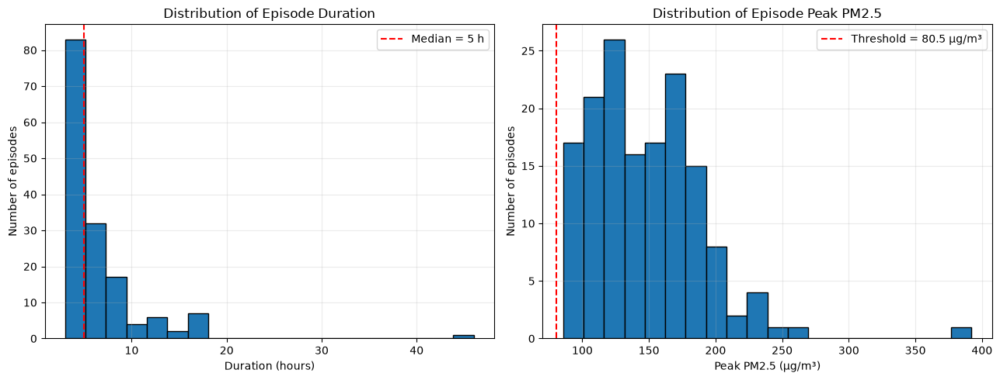

In [266]:
# Episode duration and peak concentration distributions

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(
    episodes["Duration_Hours"],
    bins=20,
    edgecolor="black"
)

axes[0].axvline(
    episodes["Duration_Hours"].median(),
    linestyle="--",
    color="red",
    label=f"Median = {episodes['Duration_Hours'].median():.0f} h"
)

axes[0].set_title("Distribution of Episode Duration")
axes[0].set_xlabel("Duration (hours)")
axes[0].set_ylabel("Number of episodes")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].hist(
    episodes["Peak_PM25"],
    bins=20,
    edgecolor="black"
)

axes[1].axvline(
    primary_threshold,
    linestyle="--",
    color="red",
    label=f"Threshold = {primary_threshold:.1f} µg/m³"
)

axes[1].set_title("Distribution of Episode Peak PM2.5")
axes[1].set_xlabel("Peak PM2.5 (µg/m³)")
axes[1].set_ylabel("Number of episodes")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

Temporal and Seasonal Distribution Episodes

In [267]:
# 4.9.3: Temporal and seasonal episode distribution

def assign_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Pre-monsoon"
    elif month in [6, 7, 8, 9]:
        return "Monsoon"
    else:
        return "Post-monsoon"


# Episode onset information
episodes["Start_Month"] = episodes["Start"].dt.to_period("M").astype(str)
episodes["Start_Season"] = episodes["Start"].dt.month.map(assign_season)
episodes["Start_Hour"] = episodes["Start"].dt.hour

# Build hourly records for qualifying episodes
episode_hour_records = []

for _, episode in episodes.iterrows():

    episode_hours = pm25_series.loc[
        episode["Start"]:episode["End"]
    ]

    for timestamp, value in episode_hours.items():

        episode_hour_records.append({
            "Episode_ID": episode["Episode_ID"],
            "Datetime": timestamp,
            "PM25": value,
            "Month": timestamp.strftime("%Y-%m"),
            "Season": assign_season(timestamp.month),
            "Hour": timestamp.hour
        })

episode_hours_data = pd.DataFrame(episode_hour_records)

print("Episode-hour records:", len(episode_hours_data))
print("Unique episodes:", episode_hours_data["Episode_ID"].nunique())

Episode-hour records: 981
Unique episodes: 152


C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\689907607.py:15: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  episodes["Start_Month"] = episodes["Start"].dt.to_period("M").astype(str)


C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\839988046.py:16: UserWarning: Converting to Period representation will drop timezone information.
  pm25_series.index.min().to_period("M"),
C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\839988046.py:17: UserWarning: Converting to Period representation will drop timezone information.
  pm25_series.index.max().to_period("M"),


,Episode_Count,Episode_Hours
Month,,
2025-07,0,0
2025-08,0,0
2025-09,1,3
2025-10,1,3
2025-11,8,30
2025-12,35,168
2026-01,45,291
2026-02,29,198
2026-03,18,128


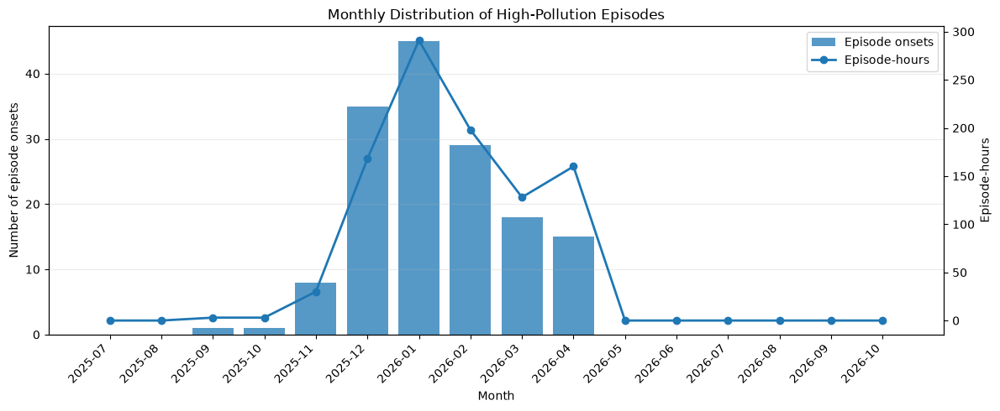

In [268]:
# Monthly episode frequency and episode-hours

monthly_episode_count = (
    episodes.groupby("Start_Month")
    .size()
    .rename("Episode_Count")
)

monthly_episode_hours = (
    episode_hours_data.groupby("Month")
    .size()
    .rename("Episode_Hours")
)

all_months = pd.period_range(
    pm25_series.index.min().to_period("M"),
    pm25_series.index.max().to_period("M"),
    freq="M"
).astype(str)

monthly_episode_summary = pd.DataFrame(index=all_months)

monthly_episode_summary.index.name = "Month"

monthly_episode_summary["Episode_Count"] = (
    monthly_episode_count.reindex(all_months, fill_value=0)
)

monthly_episode_summary["Episode_Hours"] = (
    monthly_episode_hours.reindex(all_months, fill_value=0)
)

display(monthly_episode_summary)

# Monthly episode distribution figure

fig, ax1 = plt.subplots(figsize=(12, 5))

x = np.arange(len(monthly_episode_summary))

ax1.bar(
    x,
    monthly_episode_summary["Episode_Count"],
    alpha=0.75,
    label="Episode onsets"
)

ax1.set_ylabel("Number of episode onsets")
ax1.set_xlabel("Month")
ax1.set_xticks(x)
ax1.set_xticklabels(
    monthly_episode_summary.index,
    rotation=45,
    ha="right"
)

ax2 = ax1.twinx()

ax2.plot(
    x,
    monthly_episode_summary["Episode_Hours"],
    marker="o",
    linewidth=2,
    label="Episode-hours"
)

ax2.set_ylabel("Episode-hours")

ax1.set_title("Monthly Distribution of High-Pollution Episodes")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper right"
)

ax1.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

,Episode_Count,Mean_Duration,Median_Duration,Mean_Peak_PM25,Maximum_Peak_PM25,Episode_Hours
Start_Season,,,,,,
Monsoon,1,3.00,3.0,87.05,87.05,3
Post-monsoon,9,3.67,3.0,115.78,144.68,33
Winter,109,6.12,5.0,159.76,392.19,657
Pre-monsoon,33,8.42,6.0,119.58,227.40,288


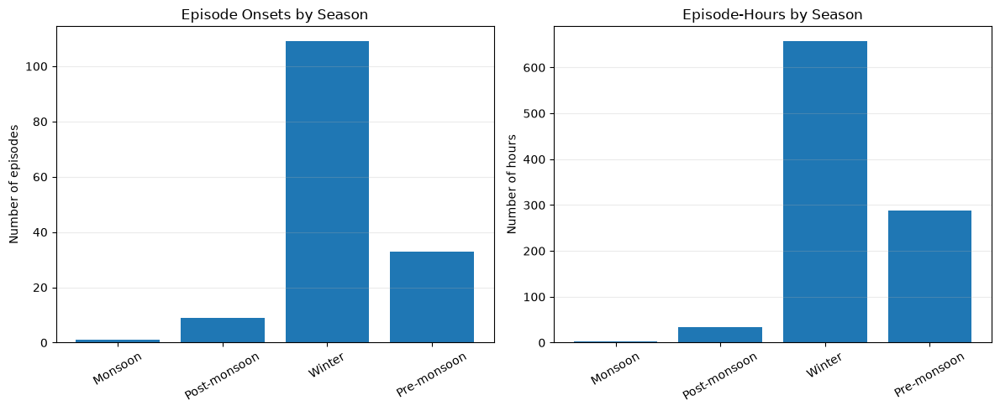

In [269]:
# Seasonal episode frequency and intensity

season_order = [
    "Monsoon",
    "Post-monsoon",
    "Winter",
    "Pre-monsoon"
]

season_episode_count = (
    episodes.groupby("Start_Season")
    .agg(
        Episode_Count=("Episode_ID", "count"),
        Mean_Duration=("Duration_Hours", "mean"),
        Median_Duration=("Duration_Hours", "median"),
        Mean_Peak_PM25=("Peak_PM25", "mean"),
        Maximum_Peak_PM25=("Peak_PM25", "max")
    )
)

season_episode_hours = (
    episode_hours_data.groupby("Season")
    .size()
    .rename("Episode_Hours")
)

season_episode_summary = (
    season_episode_count
    .join(season_episode_hours)
    .reindex(season_order)
    .fillna(0)
)

display(season_episode_summary.round(2))

# Seasonal episode distribution

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(
    season_episode_summary.index,
    season_episode_summary["Episode_Count"]
)

axes[0].set_title("Episode Onsets by Season")
axes[0].set_ylabel("Number of episodes")
axes[0].tick_params(axis="x", rotation=30)
axes[0].grid(axis="y", alpha=0.25)

axes[1].bar(
    season_episode_summary.index,
    season_episode_summary["Episode_Hours"]
)

axes[1].set_title("Episode-Hours by Season")
axes[1].set_ylabel("Number of hours")
axes[1].tick_params(axis="x", rotation=30)
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

Episode starts by hour:


,Episode_Count
Start_Hour,
0,1
1,2
2,1
3,15
4,18
5,29
6,31
7,9
8,1


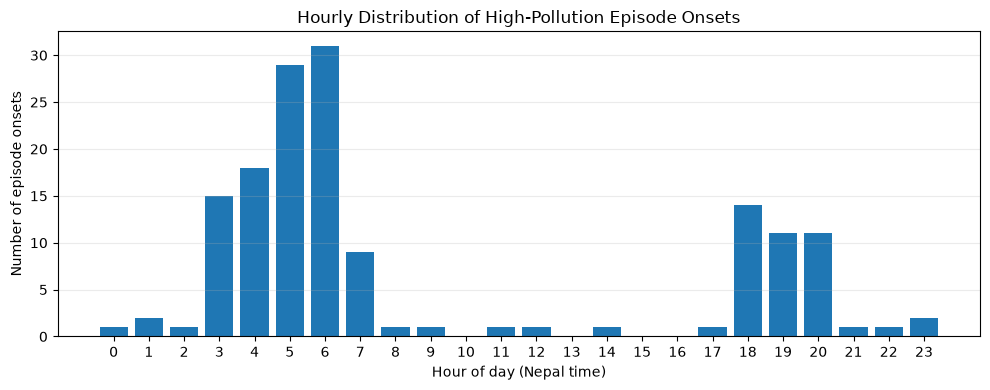

In [270]:
# Hourly distribution of episode starts

hourly_episode_starts = (
    episodes.groupby("Start_Hour")
    .size()
    .reindex(range(24), fill_value=0)
)

print("Episode starts by hour:")
display(
    hourly_episode_starts.rename("Episode_Count").to_frame()
)

fig, ax = plt.subplots(figsize=(10, 4))

ax.bar(
    hourly_episode_starts.index,
    hourly_episode_starts.values
)

ax.set_xticks(range(24))
ax.set_xlabel("Hour of day (Nepal time)")
ax.set_ylabel("Number of episode onsets")
ax.set_title("Hourly Distribution of High-Pollution Episode Onsets")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

Meterological Conditions during high pollution episodes

In [282]:
# 4.9.4: Prepare meteorological data for episode comparison

# Use master as the source of weather and AQ data
episode_met_data = master.copy()

# Ensure datetime index
if "datetime" in episode_met_data.columns:
    episode_met_data["datetime"] = pd.to_datetime(
        episode_met_data["datetime"]
    )
    episode_met_data = episode_met_data.set_index("datetime")

# Retain only timestamps with available Hadigaun PM2.5
episode_met_data = episode_met_data.loc[
    episode_met_data["pm25"].notna()
].copy()

# Calculate radiation deficit using the established definition
episode_met_data["radiation_deficit"] = (
    episode_met_data["terrestrial_radiation"]
    - episode_met_data["shortwave_radiation"]
)

# Assign episode status
episode_timestamps = pd.DatetimeIndex(
    pd.to_datetime(
        pd.concat([
            pd.Series(
                pd.date_range(
                    row["Start"],
                    row["End"],
                    freq="h"
                )
            )
            for _, row in episodes.iterrows()
        ], ignore_index=True)
    )
)

# Match episode timestamps to the dataset timezone
if episode_met_data.index.tz is not None and episode_timestamps.tz is None:
    episode_timestamps = episode_timestamps.tz_localize(
        episode_met_data.index.tz
    )
elif episode_met_data.index.tz is None and episode_timestamps.tz is not None:
    episode_timestamps = episode_timestamps.tz_localize(None)

episode_met_data["Episode_Status"] = np.where(
    episode_met_data.index.isin(episode_timestamps),
    "Episode",
    "Non-episode"
)

# Variables for comparison
met_variables = [
    "temperature_2m",
    "relative_humidity_2m",
    "pressure_msl",
    "boundary_layer_height",
    "cloud_cover",
    "precipitation",
    "radiation_deficit",
    "wind_gusts_10m"
]

print("Sensor-matched observations:", len(episode_met_data))
print(
    "Episode hours:",
    (episode_met_data["Episode_Status"] == "Episode").sum()
)
print(
    "Non-episode hours:",
    (episode_met_data["Episode_Status"] == "Non-episode").sum()
)
print("\nMissing values:")
display(episode_met_data[met_variables].isna().sum())

Sensor-matched observations: 10981
Episode hours: 981
Non-episode hours: 10000

Missing values:


temperature_2m             0
relative_humidity_2m       0
pressure_msl               0
boundary_layer_height    477
cloud_cover                0
precipitation              0
radiation_deficit          0
wind_gusts_10m             0
dtype: int64

In [283]:
# Descriptive statistics and Mann-Whitney U tests

from scipy.stats import mannwhitneyu

met_episode_comparison = []

for variable in met_variables:

    episode_values = episode_met_data.loc[
        episode_met_data["Episode_Status"] == "Episode",
        variable
    ].dropna()

    non_episode_values = episode_met_data.loc[
        episode_met_data["Episode_Status"] == "Non-episode",
        variable
    ].dropna()

    if len(episode_values) == 0 or len(non_episode_values) == 0:
        continue

    test = mannwhitneyu(
        episode_values,
        non_episode_values,
        alternative="two-sided"
    )

    met_episode_comparison.append({
        "Variable": variable,
        "Episode_N": len(episode_values),
        "Non_Episode_N": len(non_episode_values),
        "Episode_Median": episode_values.median(),
        "Episode_Q1": episode_values.quantile(0.25),
        "Episode_Q3": episode_values.quantile(0.75),
        "Non_Episode_Median": non_episode_values.median(),
        "Non_Episode_Q1": non_episode_values.quantile(0.25),
        "Non_Episode_Q3": non_episode_values.quantile(0.75),
        "Median_Difference": (
            episode_values.median() - non_episode_values.median()
        ),
        "Mann_Whitney_U": test.statistic,
        "P_Value": test.pvalue
    })

met_episode_comparison = pd.DataFrame(met_episode_comparison)

met_episode_comparison["P_Value_Display"] = (
    met_episode_comparison["P_Value"].apply(
        lambda p: f"{p:.3e}"
    )
)

display(met_episode_comparison.round(4))

,Variable,Episode_N,Non_Episode_N,Episode_Median,Episode_Q1,Episode_Q3,Non_Episode_Median,Non_Episode_Q1,Non_Episode_Q3,Median_Difference,Mann_Whitney_U,P_Value,P_Value_Display
0,temperature_2m,981,10000,12.3,8.7,16.2,20.30,16.5,22.7,-8.00,1771782.5,0.0,8.414e-240
1,relative_humidity_2m,981,10000,79.0,66.0,91.0,90.00,74.0,99.0,-11.00,3581625.5,0.0,1.679e-44
2,pressure_msl,981,10000,1017.1,1013.8,1019.3,1011.20,1007.7,1015.2,5.90,7698144.5,0.0,5.313e-191
3,boundary_layer_height,981,9523,15.0,10.0,270.0,45.00,15.0,500.0,-30.00,3607542.0,0.0,3.692e-32
4,cloud_cover,981,10000,3.0,0.0,72.0,86.00,23.0,100.0,-83.00,2593090.5,0.0,7.953e-135
5,precipitation,981,10000,0.0,0.0,0.0,0.00,0.0,0.2,0.00,3313048.0,0.0,1.076e-85
6,radiation_deficit,981,10000,16.2,0.0,228.4,30.45,0.0,361.8,-14.25,4295368.0,0.0,1.390e-11
7,wind_gusts_10m,981,10000,3.7,3.1,4.3,3.90,3.0,4.9,-0.20,4373651.5,0.0,2.031e-08


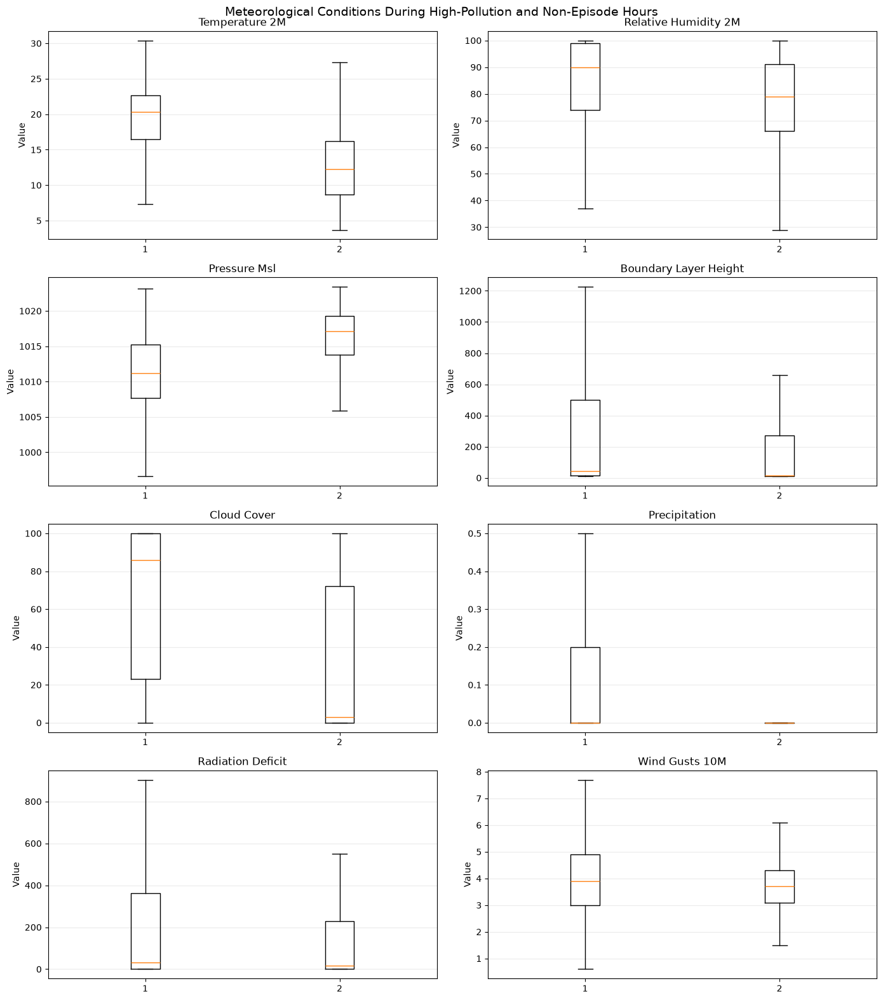

In [285]:
# Meteorological conditions during episode and non-episode hours

fig, axes = plt.subplots(4, 2, figsize=(14, 16))

for ax, variable in zip(axes.flat, met_variables):

    non_episode_values = episode_met_data.loc[
        episode_met_data["Episode_Status"] == "Non-episode",
        variable
    ].dropna()

    episode_values = episode_met_data.loc[
        episode_met_data["Episode_Status"] == "Episode",
        variable
    ].dropna()

    ax.boxplot(
        [non_episode_values, episode_values],
        label=["Non-episode", "Episode"],
        showfliers=False
    )

    ax.set_title(variable.replace("_", " ").title())
    ax.set_ylabel("Value")
    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "Meteorological Conditions During High-Pollution and Non-Episode Hours",
    fontsize=14
)

plt.tight_layout()
plt.show()

PM1 and Particle Count During High-Pollution Episodes

In [286]:
# 4.9.5: PM1 and particle count during high-pollution episodes

particulate_variables = [
    "pm25",
    "pm1",
    "particle_count_03um"
]

particulate_episode_comparison = []

for variable in particulate_variables:

    episode_values = episode_met_data.loc[
        episode_met_data["Episode_Status"] == "Episode",
        variable
    ].dropna()

    non_episode_values = episode_met_data.loc[
        episode_met_data["Episode_Status"] == "Non-episode",
        variable
    ].dropna()

    test = mannwhitneyu(
        episode_values,
        non_episode_values,
        alternative="two-sided"
    )

    particulate_episode_comparison.append({
        "Variable": variable,
        "Episode_N": len(episode_values),
        "Non_Episode_N": len(non_episode_values),
        "Episode_Mean": episode_values.mean(),
        "Episode_Median": episode_values.median(),
        "Episode_Q1": episode_values.quantile(0.25),
        "Episode_Q3": episode_values.quantile(0.75),
        "Non_Episode_Mean": non_episode_values.mean(),
        "Non_Episode_Median": non_episode_values.median(),
        "Non_Episode_Q1": non_episode_values.quantile(0.25),
        "Non_Episode_Q3": non_episode_values.quantile(0.75),
        "Median_Difference": (
            episode_values.median() - non_episode_values.median()
        ),
        "Mann_Whitney_U": test.statistic,
        "P_Value": test.pvalue
    })

particulate_episode_comparison = pd.DataFrame(
    particulate_episode_comparison
)

particulate_episode_comparison["P_Value_Display"] = (
    particulate_episode_comparison["P_Value"].apply(
        lambda p: f"{p:.3e}"
    )
)

display(particulate_episode_comparison.round(4))

,Variable,Episode_N,Non_Episode_N,Episode_Mean,Episode_Median,Episode_Q1,Episode_Q3,Non_Episode_Mean,Non_Episode_Median,Non_Episode_Q1,Non_Episode_Q3,Median_Difference,Mann_Whitney_U,P_Value,P_Value_Display
0,pm25,981,10000,114.9636,104.6345,90.7432,128.3000,33.9582,31.2988,17.8993,46.7000,73.3357,9782412.0,0.0,0.000e+00
1,pm1,981,10000,70.6019,64.8708,55.2156,80.2116,21.5405,20.0000,11.7000,29.5000,44.8708,9764519.5,0.0,0.000e+00
2,particle_count_03um,981,10000,17639.6245,16449.0000,14186.8690,19844.0000,4906.8672,3929.6580,2342.9760,6869.5729,12519.3420,9764804.0,0.0,0.000e+00


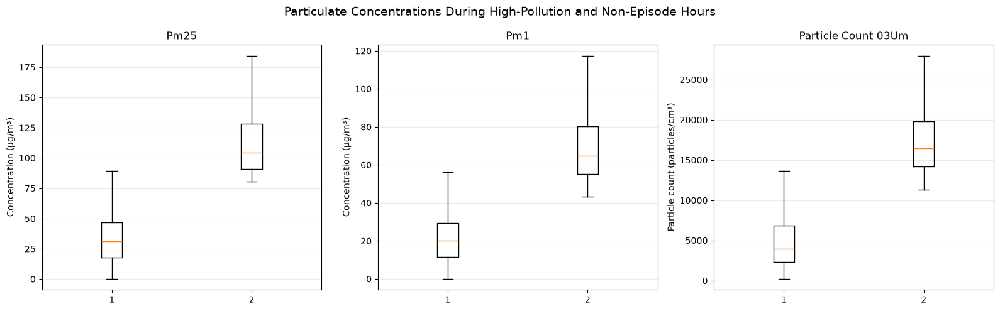

In [288]:
# PM2.5, PM1 and particle count during episode and non-episode hours

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, variable in zip(axes, particulate_variables):

    non_episode_values = episode_met_data.loc[
        episode_met_data["Episode_Status"] == "Non-episode",
        variable
    ].dropna()

    episode_values = episode_met_data.loc[
        episode_met_data["Episode_Status"] == "Episode",
        variable
    ].dropna()

    ax.boxplot(
        [non_episode_values, episode_values],
        label=["Non-episode", "Episode"],
        showfliers=False
    )

    ax.set_title(variable.replace("_", " ").title())
    ax.set_ylabel(
        "Concentration (µg/m³)"
        if variable in ["pm25", "pm1"]
        else "Particle count (particles/cm³)"
    )
    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "Particulate Concentrations During High-Pollution and Non-Episode Hours",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [289]:
# PM1 / PM2.5 ratio comparison

episode_met_data["PM1_PM25_Ratio"] = (
    episode_met_data["pm1"] / episode_met_data["pm25"]
)

ratio_episode_comparison = []

for status in ["Episode", "Non-episode"]:

    values = episode_met_data.loc[
        episode_met_data["Episode_Status"] == status,
        "PM1_PM25_Ratio"
    ].replace([np.inf, -np.inf], np.nan).dropna()

    ratio_episode_comparison.append({
        "Episode_Status": status,
        "N": len(values),
        "Mean": values.mean(),
        "Median": values.median(),
        "Q1": values.quantile(0.25),
        "Q3": values.quantile(0.75),
        "P5": values.quantile(0.05),
        "P95": values.quantile(0.95)
    })

ratio_episode_comparison = pd.DataFrame(ratio_episode_comparison)

display(ratio_episode_comparison.round(4))

,Episode_Status,N,Mean,Median,Q1,Q3,P5,P95
0,Episode,981,0.6136,0.6171,0.5924,0.6383,0.5613,0.6553
1,Non-episode,10000,0.6455,0.6418,0.6237,0.6652,0.5918,0.7083


More Runs for High Pollution Episodes

In [290]:
# Cell 1: Prepare episode IDs and month-hour matched control data

# Restrict the analysis to timestamps with observed Hadigaun PM2.5
episode_met_data = analysis_data.loc[
    analysis_data["pm25"].notna()
].copy()

# Reconstruct the timestamps belonging to each detected episode
episode_id_map = {}

for episode_id, row in episodes.iterrows():

    episode_times = pd.date_range(
        start=row["Start"],
        end=row["End"],
        freq="h"
    )

    for timestamp in episode_times:
        if timestamp in episode_met_data.index:
            episode_id_map[timestamp] = episode_id

episode_met_data["Episode_ID"] = (
    episode_met_data.index.map(episode_id_map)
)

episode_met_data["Episode_Status"] = np.where(
    episode_met_data["Episode_ID"].notna(),
    "Episode",
    "Non-episode"
)

# Month-hour matching categories
episode_met_data["Month"] = episode_met_data.index.month
episode_met_data["Hour"] = episode_met_data.index.hour

# Variables for the corrected meteorological comparison
met_variables = [
    "relative_temperature_2m",
    "relative_humidity_2m",
    "pressure_msl",
    "boundary_layer_height",
    "cloud_cover",
    "radiation_deficit",
    "wind_gusts_10m"
]

print("Sensor-matched observations:", len(episode_met_data))
print("Episode hours:", episode_met_data["Episode_ID"].notna().sum())
print("Non-episode hours:", episode_met_data["Episode_ID"].isna().sum())
print("Episodes represented:", episode_met_data["Episode_ID"].nunique())

Sensor-matched observations: 10981
Episode hours: 981
Non-episode hours: 10000
Episodes represented: 152


In [291]:
# Cell 2: Month-hour matched meteorological differences
# Bootstrap unit: complete episodes

rng = np.random.default_rng(42)
n_bootstrap = 5000

# Mean control values for each month-hour combination
control_data = episode_met_data.loc[
    episode_met_data["Episode_Status"] == "Non-episode"
].copy()

matched_results = []
episode_difference_data = {}

for variable in met_variables:

    control_means = control_data.groupby(
        ["Month", "Hour"]
    )[variable].mean()

    # Match each observation to its month-hour control mean
    matched_control = pd.MultiIndex.from_arrays(
        [
            episode_met_data["Month"],
            episode_met_data["Hour"]
        ]
    ).map(control_means)

    episode_rows = episode_met_data[
        episode_met_data["Episode_Status"] == "Episode"
    ].copy()

    episode_rows["Control_Value"] = matched_control[
        episode_met_data["Episode_Status"] == "Episode"
    ]

    episode_rows["Matched_Difference"] = (
        episode_rows[variable] - episode_rows["Control_Value"]
    )

    # Calculate one mean difference per episode
    episode_differences = (
        episode_rows.groupby("Episode_ID")["Matched_Difference"]
        .mean()
        .dropna()
    )

    episode_difference_data[variable] = episode_differences

    observed_difference = episode_differences.mean()

    # Resample whole episodes
    bootstrap_means = np.array([
        rng.choice(
            episode_differences.to_numpy(),
            size=len(episode_differences),
            replace=True
        ).mean()
        for _ in range(n_bootstrap)
    ])

    ci_lower, ci_upper = np.percentile(
        bootstrap_means,
        [2.5, 97.5]
    )

    matched_results.append({
        "Variable": variable,
        "Episodes": len(episode_differences),
        "Mean_Episode_Matched_Difference": observed_difference,
        "CI_Lower_95": ci_lower,
        "CI_Upper_95": ci_upper
    })

matched_met_comparison = pd.DataFrame(matched_results)

display(matched_met_comparison.round(4))

,Variable,Episodes,Mean_Episode_Matched_Difference,CI_Lower_95,CI_Upper_95
0,relative_temperature_2m,152,-0.0997,-0.3609,0.1730
1,relative_humidity_2m,152,1.5944,-0.2300,3.3517
2,pressure_msl,152,0.1907,-0.2289,0.6060
3,boundary_layer_height,152,-33.1018,-48.5796,-18.7058
4,cloud_cover,152,2.5787,-2.7161,7.8658
5,radiation_deficit,152,-1.1748,-5.1655,3.6189
6,wind_gusts_10m,152,-0.0169,-0.1158,0.0832


In [292]:
# Cell 3: Month-hour matched wet-hour comparison
# Bootstrap unit: complete episodes

episode_rows = episode_met_data.loc[
    episode_met_data["Episode_Status"] == "Episode"
].copy()

control_rows = episode_met_data.loc[
    episode_met_data["Episode_Status"] == "Non-episode"
].copy()

episode_rows["Wet_Hour"] = (
    episode_rows["precipitation"] > 0.1
).astype(float)

control_rows["Wet_Hour"] = (
    control_rows["precipitation"] > 0.1
).astype(float)

# Wet-hour probability for each month-hour control group
control_wet_probability = control_rows.groupby(
    ["Month", "Hour"]
)["Wet_Hour"].mean()

matched_probability = pd.MultiIndex.from_arrays(
    [
        episode_rows["Month"],
        episode_rows["Hour"]
    ]
).map(control_wet_probability)

episode_rows["Control_Wet_Probability"] = matched_probability

episode_rows["Wet_Hour_Difference"] = (
    episode_rows["Wet_Hour"]
    - episode_rows["Control_Wet_Probability"]
)

# One wet-hour difference per episode
episode_wet_differences = (
    episode_rows.groupby("Episode_ID")["Wet_Hour_Difference"]
    .mean()
    .dropna()
)

observed_wet_difference = episode_wet_differences.mean()

# Bootstrap complete episodes
rng = np.random.default_rng(42)

bootstrap_wet = np.array([
    rng.choice(
        episode_wet_differences.to_numpy(),
        size=len(episode_wet_differences),
        replace=True
    ).mean()
    for _ in range(5000)
])

wet_ci_lower, wet_ci_upper = np.percentile(
    bootstrap_wet,
    [2.5, 97.5]
)

# Actual episode and non-episode wet-hour proportions
episode_wet_share = episode_rows["Wet_Hour"].mean()
control_wet_share = control_rows["precipitation"].gt(0.1).mean()

wet_hour_comparison = pd.DataFrame([{
    "Episode_Wet_Hour_Share": episode_wet_share,
    "Non_Episode_Wet_Hour_Share": control_wet_share,
    "Matched_Difference": observed_wet_difference,
    "CI_Lower_95": wet_ci_lower,
    "CI_Upper_95": wet_ci_upper,
    "Episodes": len(episode_wet_differences)
}])

display(wet_hour_comparison.round(4))

,Episode_Wet_Hour_Share,Non_Episode_Wet_Hour_Share,Matched_Difference,CI_Lower_95,CI_Upper_95,Episodes
0,0.0408,0.2742,0.003,-0.0118,0.0212,152


In [293]:
# Cell 4: Matching coverage diagnostics

matching_diagnostics = []

for variable in met_variables:

    differences = episode_difference_data[variable]

    matching_diagnostics.append({
        "Variable": variable,
        "Episodes_With_Matched_Data": len(differences),
        "Episodes_Without_Matched_Data": (
            episodes.shape[0] - len(differences)
        )
    })

matching_diagnostics = pd.DataFrame(matching_diagnostics)

print("Episode timestamp coverage:")
print(
    episode_met_data.groupby("Episode_Status")
    .size()
)

print("\nMatched-control coverage:")
display(matching_diagnostics)

Episode timestamp coverage:
Episode_Status
Episode          981
Non-episode    10000
dtype: int64

Matched-control coverage:


,Variable,Episodes_With_Matched_Data,Episodes_Without_Matched_Data
0,relative_temperature_2m,152,0
1,relative_humidity_2m,152,0
2,pressure_msl,152,0
3,boundary_layer_height,152,0
4,cloud_cover,152,0
5,radiation_deficit,152,0
6,wind_gusts_10m,152,0


Event Aligned Meterological Conditions

In [300]:
# ============================================================
# 4.9.4 — EVENT-ALIGNED METEOROLOGICAL CONDITION PREPARATION
# ============================================================

event_composite_data = episode_met_data.copy()

# Meteorological variables used in event-aligned analysis
event_variables = {
    "Temperature anomaly": "relative_temperature_2m",
    "Boundary layer height": "boundary_layer_height",
    "Cloud cover": "cloud_cover",
    "Wind gusts": "wind_gusts_10m"
}

# Remove recurring month-hour patterns
for label, variable in event_variables.items():

    event_composite_data[label] = month_hour_residual(
        event_composite_data[variable]
    )

# Calculate one-hour pressure change
pressure_change = event_composite_data["pressure_msl"].diff()

# Retain pressure changes only when observations are consecutive
consecutive_hour = (
    event_composite_data.index.to_series().diff()
    == pd.Timedelta(hours=1)
)

event_composite_data["Pressure change"] = pressure_change.where(
    consecutive_hour
)

# Remove recurring month-hour patterns from pressure changes
event_composite_data["Pressure change"] = month_hour_residual(
    event_composite_data["Pressure change"]
)

# Variables included in the composites
composite_variables = list(event_variables.keys()) + [
    "Pressure change"
]

print("Variables prepared:", composite_variables)

print("\nAvailable observations:")
print(
    event_composite_data[composite_variables]
    .count()
)

Variables prepared: ['Temperature anomaly', 'Boundary layer height', 'Cloud cover', 'Wind gusts', 'Pressure change']

Available observations:
Temperature anomaly      10981
Boundary layer height    10504
Cloud cover              10981
Wind gusts               10981
Pressure change          10896
dtype: int64


In [301]:
# ============================================================
# 4.9.4 — EVENT-ALIGNED COMPOSITES AND BOOTSTRAP INTERVALS
# ============================================================

rng = np.random.default_rng(42)

# Relative hours around each event boundary
event_offsets = np.arange(-24, 25, 1)

# Number of bootstrap repetitions
n_bootstrap = 5000


def calculate_event_composite(
    data,
    episode_table,
    event_boundary,
    variable
):

    event_matrices = []

    # Extract the relative-time profile for every episode
    for _, episode in episode_table.iterrows():

        anchor = episode[event_boundary]

        timestamps = (
            anchor
            + pd.to_timedelta(event_offsets, unit="h")
        )

        values = data[variable].reindex(timestamps).to_numpy()

        event_matrices.append(values)

    event_matrices = np.asarray(
        event_matrices,
        dtype=float
    )

    # Mean composite profile
    mean_profile = np.nanmean(
        event_matrices,
        axis=0
    )

    # Episode-level bootstrap
    bootstrap_profiles = []

    n_events = len(event_matrices)

    for _ in range(n_bootstrap):

        sampled_indices = rng.integers(
            0,
            n_events,
            size=n_events
        )

        sampled_events = event_matrices[
            sampled_indices
        ]

        bootstrap_mean = np.nanmean(
            sampled_events,
            axis=0
        )

        bootstrap_profiles.append(
            bootstrap_mean
        )

    bootstrap_profiles = np.asarray(
        bootstrap_profiles
    )

    # Pointwise 95% bootstrap confidence intervals
    ci_lower = np.nanpercentile(
        bootstrap_profiles,
        2.5,
        axis=0
    )

    ci_upper = np.nanpercentile(
        bootstrap_profiles,
        97.5,
        axis=0
    )

    # Number of contributing episodes at each relative hour
    n_available = np.sum(
        np.isfinite(event_matrices),
        axis=0
    )

    return pd.DataFrame({
        "Relative_Hour": event_offsets,
        "Mean": mean_profile,
        "CI_Lower_95": ci_lower,
        "CI_Upper_95": ci_upper,
        "N_Episodes": n_available
    })


# Calculate composites for both event boundaries
event_composite_results = {}

for boundary_name, boundary_column in [
    ("Onset", "Start"),
    ("End", "End")
]:

    for variable in composite_variables:

        result = calculate_event_composite(
            data=event_composite_data,
            episode_table=episodes,
            event_boundary=boundary_column,
            variable=variable
        )

        event_composite_results[
            (boundary_name, variable)
        ] = result


print("Event-aligned composites calculated.")
print("Boundaries: onset and end")
print("Relative time: -24 to +24 hours")
print("Bootstrap repetitions:", n_bootstrap)

Event-aligned composites calculated.
Boundaries: onset and end
Relative time: -24 to +24 hours
Bootstrap repetitions: 5000


In [302]:
# ============================================================
# 4.9.4 — SELECTED EVENT-ALIGNED COMPOSITE RESULTS
# ============================================================

selected_offsets = [
    -24, -18, -12, -6,
    0,
    6, 12, 18, 24
]

selected_composite_results = []

for (boundary_name, variable), result in (
    event_composite_results.items()
):

    selected = result[
        result["Relative_Hour"].isin(selected_offsets)
    ].copy()

    selected["Boundary"] = boundary_name
    selected["Variable"] = variable

    selected_composite_results.append(
        selected
    )


event_composite_summary = pd.concat(
    selected_composite_results,
    ignore_index=True
)

event_composite_summary = event_composite_summary[
    [
        "Boundary",
        "Variable",
        "Relative_Hour",
        "Mean",
        "CI_Lower_95",
        "CI_Upper_95",
        "N_Episodes"
    ]
]

event_composite_summary = (
    event_composite_summary
    .sort_values(
        ["Boundary", "Variable", "Relative_Hour"]
    )
    .reset_index(drop=True)
)

print("EVENT-ALIGNED METEOROLOGICAL COMPOSITE SUMMARY")

display(
    event_composite_summary.round(3)
)

EVENT-ALIGNED METEOROLOGICAL COMPOSITE SUMMARY


,Boundary,Variable,Relative_Hour,Mean,CI_Lower_95,CI_Upper_95,N_Episodes
0,End,Boundary layer height,-24,-16.001,-52.394,19.265,151
1,End,Boundary layer height,-18,35.080,-6.045,78.392,147
2,End,Boundary layer height,-12,-21.595,-40.118,-5.605,148
3,End,Boundary layer height,-6,3.246,-14.104,22.460,151
4,End,Boundary layer height,0,-32.753,-65.970,-2.640,152
...,...,...,...,...,...,...,...
85,Onset,Wind gusts,0,-0.134,-0.242,-0.025,152
86,Onset,Wind gusts,6,-0.126,-0.274,0.028,150
87,Onset,Wind gusts,12,-0.040,-0.171,0.096,152
88,Onset,Wind gusts,18,-0.053,-0.225,0.127,149


In [304]:
with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
    "display.width", 200
):
    display(event_composite_summary.round(3))

,Boundary,Variable,Relative_Hour,Mean,CI_Lower_95,CI_Upper_95,N_Episodes
0,End,Boundary layer height,-24,-16.001,-52.394,19.265,151
1,End,Boundary layer height,-18,35.080,-6.045,78.392,147
2,End,Boundary layer height,-12,-21.595,-40.118,-5.605,148
3,End,Boundary layer height,-6,3.246,-14.104,22.460,151
4,End,Boundary layer height,0,-32.753,-65.970,-2.640,152
5,End,Boundary layer height,6,18.743,-22.480,63.827,145
6,End,Boundary layer height,12,4.077,-12.018,19.096,152
7,End,Boundary layer height,18,-4.548,-24.166,15.519,151
8,End,Boundary layer height,24,-17.688,-53.672,17.168,150
9,End,Cloud cover,-24,-3.160,-8.770,2.499,151


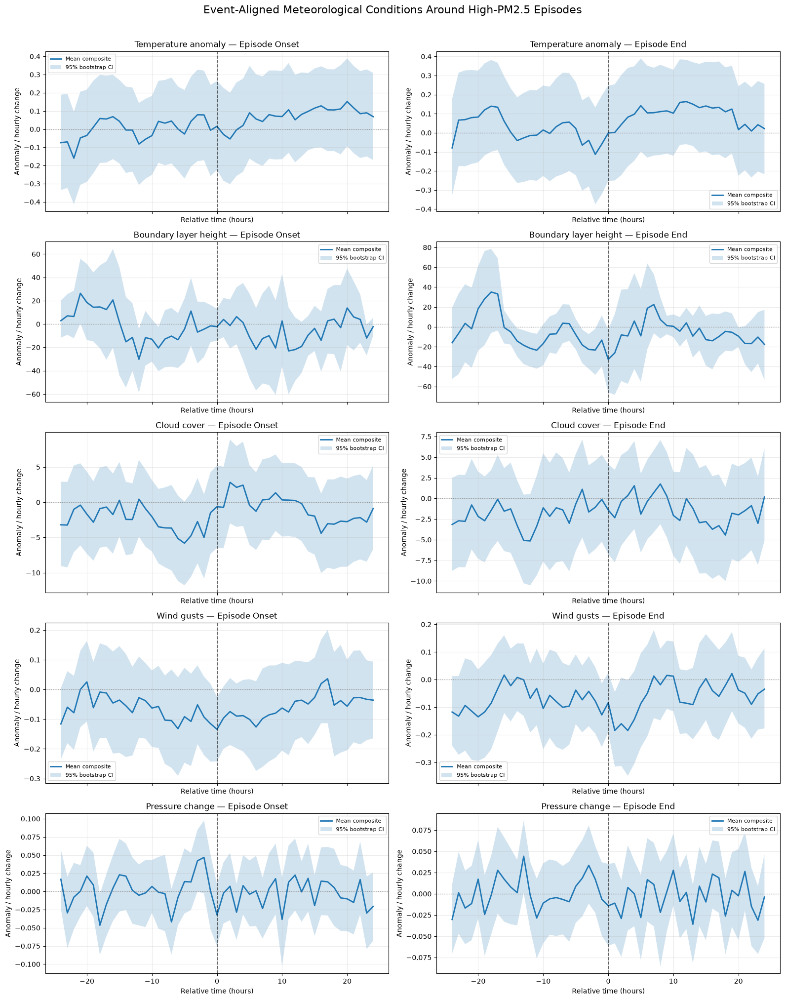

In [303]:
# ============================================================
# 4.9.4 — EVENT-ALIGNED METEOROLOGICAL COMPOSITE FIGURES
# ============================================================

fig, axes = plt.subplots(
    nrows=len(composite_variables),
    ncols=2,
    figsize=(16, 20),
    sharex=True
)

boundary_names = ["Onset", "End"]

for row, variable in enumerate(composite_variables):

    for col, boundary_name in enumerate(boundary_names):

        ax = axes[row, col]

        result = event_composite_results[
            (boundary_name, variable)
        ]

        x = result["Relative_Hour"]
        mean = result["Mean"]
        lower = result["CI_Lower_95"]
        upper = result["CI_Upper_95"]

        # Composite mean
        ax.plot(
            x,
            mean,
            linewidth=2,
            label="Mean composite"
        )

        # Bootstrap confidence interval
        ax.fill_between(
            x,
            lower,
            upper,
            alpha=0.20,
            label="95% bootstrap CI"
        )

        # Event boundary
        ax.axvline(
            0,
            linestyle="--",
            linewidth=1.2,
            color="black",
            alpha=0.7
        )

        # Reference line for zero anomaly/change
        ax.axhline(
            0,
            linestyle=":",
            linewidth=1,
            color="grey",
            alpha=0.8
        )

        ax.set_title(
            f"{variable} — Episode {boundary_name}"
        )

        ax.set_ylabel(
            "Anomaly / hourly change"
        )

        ax.set_xlabel(
            "Relative time (hours)"
        )

        ax.grid(
            True,
            alpha=0.25
        )

        ax.legend(
            loc="best",
            fontsize=8
        )

plt.suptitle(
    "Event-Aligned Meteorological Conditions "
    "Around High-PM2.5 Episodes",
    fontsize=16,
    y=1.01
)

plt.tight_layout()

plt.show()

Threshold and Missing Hour Sensitivity

In [305]:
# ============================================================
# 4.9 — EPISODE-DEFINITION SENSITIVITY ANALYSIS
# ============================================================

pm25_series = (
    episode_met_data["pm25"]
    .dropna()
    .sort_index()
)

# ------------------------------------------------------------
# A. Fixed-threshold baseline
# ------------------------------------------------------------

fixed_threshold = episodes["Mean_PM25"].attrs.get(
    "threshold",
    pm25_series.quantile(0.90)
)

# Use the original selected P90 threshold explicitly
fixed_threshold = 80.4646

# ------------------------------------------------------------
# B. Assign seasons and calculate seasonal P90 thresholds
# ------------------------------------------------------------

season_labels = pm25_series.index.month.map(assign_season)

seasonal_thresholds = (
    pm25_series
    .groupby(season_labels)
    .quantile(0.90)
)

threshold_by_hour = pd.Series(
    season_labels.map(seasonal_thresholds),
    index=pm25_series.index,
    dtype=float
)

print("Fixed P90 threshold:", round(fixed_threshold, 3))

print("\nSeason-specific P90 thresholds:")
display(seasonal_thresholds.round(3).to_frame("P90_PM25"))


# ------------------------------------------------------------
# C. Generic episode detector supporting variable thresholds
#    and optional one-hour gap bridging
# ------------------------------------------------------------

def detect_episode_runs(
    series,
    threshold_series,
    max_gap_hours=1,
    min_observations=3
):

    above = (
        series.notna()
        & (series >= threshold_series)
    )

    exceedance_times = series.index[above]

    if len(exceedance_times) == 0:
        return pd.DataFrame()

    time_differences = exceedance_times.to_series().diff()

    new_group = (
        time_differences.isna()
        | (time_differences > pd.Timedelta(hours=max_gap_hours))
    )

    group_ids = new_group.cumsum().to_numpy()

    records = []

    exceedance_data = pd.DataFrame({
        "Timestamp": exceedance_times,
        "PM25": series.loc[exceedance_times].to_numpy(),
        "Group_ID": group_ids
    })

    for group_id, group in exceedance_data.groupby("Group_ID"):

        observed_hours = len(group)

        if observed_hours < min_observations:
            continue

        start_time = group["Timestamp"].iloc[0]
        end_time = group["Timestamp"].iloc[-1]

        elapsed_hours = (
            (end_time - start_time).total_seconds() / 3600
        ) + 1

        peak_row = group.loc[group["PM25"].idxmax()]

        records.append({
            "Start": start_time,
            "End": end_time,
            "Observed_Hours": observed_hours,
            "Elapsed_Hours": elapsed_hours,
            "Mean_PM25": group["PM25"].mean(),
            "Peak_PM25": group["PM25"].max(),
            "Peak_Time": peak_row["Timestamp"]
        })

    return pd.DataFrame(records)


# ------------------------------------------------------------
# D. Compare fixed P90 and seasonal P90
# ------------------------------------------------------------

fixed_threshold_series = pd.Series(
    fixed_threshold,
    index=pm25_series.index
)

fixed_p90_episodes = detect_episode_runs(
    pm25_series,
    fixed_threshold_series,
    max_gap_hours=1
)

seasonal_p90_episodes = detect_episode_runs(
    pm25_series,
    threshold_by_hour,
    max_gap_hours=1
)


# ------------------------------------------------------------
# E. Test allowing one missing hourly observation
# ------------------------------------------------------------

fixed_p90_gap_episodes = detect_episode_runs(
    pm25_series,
    fixed_threshold_series,
    max_gap_hours=2
)


# ------------------------------------------------------------
# F. Summarise episode-definition sensitivity
# ------------------------------------------------------------

sensitivity_records = []

for label, episode_table in [
    ("Fixed P90; no gap bridging", fixed_p90_episodes),
    ("Season-specific P90; no gap bridging", seasonal_p90_episodes),
    ("Fixed P90; one-hour gap allowed", fixed_p90_gap_episodes)
]:

    sensitivity_records.append({
        "Definition": label,
        "Episode_Count": len(episode_table),
        "Observed_Episode_Hours": (
            episode_table["Observed_Hours"].sum()
            if len(episode_table) else 0
        ),
        "Mean_Observed_Duration": (
            episode_table["Observed_Hours"].mean()
            if len(episode_table) else np.nan
        ),
        "Longest_Elapsed_Duration": (
            episode_table["Elapsed_Hours"].max()
            if len(episode_table) else np.nan
        )
    })

episode_sensitivity_summary = pd.DataFrame(
    sensitivity_records
)

print("\nEPISODE-DEFINITION SENSITIVITY")
display(episode_sensitivity_summary.round(2))


# ------------------------------------------------------------
# G. Check whether original episode boundaries are adjacent
#    to missing or absent hourly observations
# ------------------------------------------------------------

available_timestamps = set(pm25_series.index)

boundary_records = []

for _, episode in episodes.iterrows():

    previous_time = episode["Start"] - pd.Timedelta(hours=1)
    next_time = episode["End"] + pd.Timedelta(hours=1)

    previous_missing = previous_time not in available_timestamps
    next_missing = next_time not in available_timestamps

    boundary_records.append({
        "Start": episode["Start"],
        "End": episode["End"],
        "Previous_Hour_Missing": previous_missing,
        "Following_Hour_Missing": next_missing
    })

episode_gap_boundaries = pd.DataFrame(boundary_records)

print("\nEPISODE BOUNDARY GAP DIAGNOSTICS")

print(
    "Episodes preceded by a missing/absent hour:",
    episode_gap_boundaries["Previous_Hour_Missing"].sum()
)

print(
    "Episodes followed by a missing/absent hour:",
    episode_gap_boundaries["Following_Hour_Missing"].sum()
)

Fixed P90 threshold: 80.465

Season-specific P90 thresholds:


,P90_PM25
datetime,
Monsoon,35.800
Post-monsoon,59.366
Pre-monsoon,88.500
Winter,125.262



EPISODE-DEFINITION SENSITIVITY


,Definition,Episode_Count,Observed_Episode_Hours,Mean_Observed_Duration,Longest_Elapsed_Duration
0,Fixed P90; no gap bridging,152,980,6.45,46.0
1,Season-specific P90; no gap bridging,135,826,6.12,44.0
2,Fixed P90; one-hour gap allowed,147,1006,6.84,52.0



EPISODE BOUNDARY GAP DIAGNOSTICS
Episodes preceded by a missing/absent hour: 3
Episodes followed by a missing/absent hour: 7


In [307]:
# ============================================================
# 4.9 — EPISODE BUILD-UP, PEAK AND DECLINE ANALYSIS
# ============================================================

episode_dynamics = []

for episode_id, episode in episodes.iterrows():

    start_time = episode["Start"]
    end_time = episode["End"]
    peak_time = episode["Peak_Time"]

    # Extract the complete hourly episode profile
    episode_profile = episode_met_data.loc[
        start_time:end_time
    ].copy()

    episode_profile = episode_profile[
        episode_profile["pm25"].notna()
    ]

    if episode_profile.empty:
        continue

    start_pm25 = episode_profile["pm25"].iloc[0]
    end_pm25 = episode_profile["pm25"].iloc[-1]
    peak_pm25 = episode["Peak_PM25"]

    # Time from onset to peak
    time_to_peak = (
        peak_time - start_time
    ).total_seconds() / 3600

    # Time from peak to final above-threshold observation
    time_peak_to_end = (
        end_time - peak_time
    ).total_seconds() / 3600

    # Build-up rate
    buildup_rate = (
        (peak_pm25 - start_pm25) / time_to_peak
        if time_to_peak > 0
        else np.nan
    )

    # Decline rate (negative values indicate a decline)
    decline_rate = (
        (end_pm25 - peak_pm25) / time_peak_to_end
        if time_peak_to_end > 0
        else np.nan
    )

    elapsed_duration = (
        (end_time - start_time).total_seconds() / 3600
    ) + 1

    onset_hour = start_time.hour

    if 4 <= onset_hour <= 9:
        onset_type = "Morning"
    elif 16 <= onset_hour <= 21:
        onset_type = "Evening"
    else:
        onset_type = "Other"

    if elapsed_duration >= 24:
        duration_type = "Multi-day"
    elif len(episode_profile) <= 6:
        duration_type = "Short"
    else:
        duration_type = "Intermediate"

    episode_dynamics.append({

        "Episode_ID": episode_id + 1,
        "Start": start_time,
        "End": end_time,
        "Duration_Hours": len(episode_profile),
        "Elapsed_Duration_Hours": elapsed_duration,

        "Start_PM25": start_pm25,
        "Mean_PM25": episode["Mean_PM25"],
        "Peak_PM25": peak_pm25,
        "End_PM25": end_pm25,
        "Peak_Time": peak_time,

        "Time_to_Peak_Hours": time_to_peak,
        "Peak_to_End_Hours": time_peak_to_end,

        "Build_Up_Rate": buildup_rate,
        "Decline_Rate": decline_rate,

        "Onset_Hour": onset_hour,
        "Onset_Type": onset_type,
        "Duration_Type": duration_type

    })


episode_dynamics = pd.DataFrame(episode_dynamics)

print("Episodes analysed:", len(episode_dynamics))

print("\nEPISODE DYNAMICS SUMMARY")

display(
    episode_dynamics[
        [
            "Duration_Hours",
            "Elapsed_Duration_Hours",
            "Time_to_Peak_Hours",
            "Peak_to_End_Hours",
            "Build_Up_Rate",
            "Decline_Rate"
        ]
    ].describe().round(3)
)

print("\nEPISODE DURATION CLASSIFICATION")

display(
    episode_dynamics["Duration_Type"]
    .value_counts()
    .rename_axis("Duration_Type")
    .to_frame("Episode_Count")
)

print("\nEPISODE ONSET CLASSIFICATION")

display(
    episode_dynamics["Onset_Type"]
    .value_counts()
    .rename_axis("Onset_Type")
    .to_frame("Episode_Count")
)

Episodes analysed: 152

EPISODE DYNAMICS SUMMARY


,Duration_Hours,Elapsed_Duration_Hours,Time_to_Peak_Hours,Peak_to_End_Hours,Build_Up_Rate,Decline_Rate
count,152.000,152.000,152.000,152.000,143.000,141.000
mean,6.454,6.454,3.020,2.434,23.230,-28.522
std,4.668,4.668,2.827,3.323,17.343,27.229
min,3.000,3.000,0.000,0.000,0.300,-214.959
25%,4.000,4.000,1.000,1.000,10.288,-36.852
50%,5.000,5.000,2.000,2.000,20.960,-22.100
75%,7.000,7.000,4.000,3.000,32.296,-11.100
max,46.000,46.000,14.000,38.000,101.524,-0.677



EPISODE DURATION CLASSIFICATION


,Episode_Count
Duration_Type,
Short,102
Intermediate,49
Multi-day,1



EPISODE ONSET CLASSIFICATION


,Episode_Count
Onset_Type,
Morning,89
Evening,38
Other,25


In [308]:
# ============================================================
# 4.9 — EPISODE TYPOLOGY
# ============================================================

print("EPISODE ONSET TYPE COMPARISON")

onset_type_summary = (
    episode_dynamics
    .groupby("Onset_Type")
    .agg(
        Episode_Count=("Episode_ID", "count"),
        Mean_Duration=("Duration_Hours", "mean"),
        Median_Duration=("Duration_Hours", "median"),
        Mean_Peak_PM25=("Peak_PM25", "mean"),
        Maximum_Peak_PM25=("Peak_PM25", "max"),
        Mean_Time_to_Peak=("Time_to_Peak_Hours", "mean")
    )
    .reset_index()
)

display(onset_type_summary.round(2))


print("\nEPISODE DURATION TYPE COMPARISON")

duration_type_summary = (
    episode_dynamics
    .groupby("Duration_Type")
    .agg(
        Episode_Count=("Episode_ID", "count"),
        Mean_Duration=("Duration_Hours", "mean"),
        Median_Duration=("Duration_Hours", "median"),
        Mean_Peak_PM25=("Peak_PM25", "mean"),
        Maximum_Peak_PM25=("Peak_PM25", "max"),
        Mean_Time_to_Peak=("Time_to_Peak_Hours", "mean"),
        Mean_Build_Up_Rate=("Build_Up_Rate", "mean"),
        Mean_Decline_Rate=("Decline_Rate", "mean")
    )
    .reset_index()
)

display(duration_type_summary.round(2))

EPISODE ONSET TYPE COMPARISON


,Onset_Type,Episode_Count,Mean_Duration,Median_Duration,Mean_Peak_PM25,Maximum_Peak_PM25,Mean_Time_to_Peak
0,Evening,38,7.05,4.5,129.14,253.25,3.68
1,Morning,89,5.06,5.0,154.13,392.19,2.19
2,Other,25,10.52,9.0,154.53,264.19,4.96



EPISODE DURATION TYPE COMPARISON


,Duration_Type,Episode_Count,Mean_Duration,Median_Duration,Mean_Peak_PM25,Maximum_Peak_PM25,Mean_Time_to_Peak,Mean_Build_Up_Rate,Mean_Decline_Rate
0,Intermediate,49,10.02,8.0,168.66,392.19,5.57,18.07,-29.08
1,Multi-day,1,46.00,46.0,227.40,227.40,7.00,20.64,-1.86
2,Short,102,4.35,4.0,137.22,226.76,1.75,25.98,-28.51


In [309]:
# ============================================================
# 4.9 — EXTREME EPISODE CHARACTERISTICS
# ============================================================

weather_variables = [
    "temperature_2m",
    "relative_humidity_2m",
    "pressure_msl",
    "boundary_layer_height",
    "cloud_cover",
    "precipitation",
    "wind_gusts_10m",
    "shortwave_radiation"
]

available_weather_variables = [
    variable
    for variable in weather_variables
    if variable in episode_met_data.columns
]


def get_episode_weather(start_time, end_time):

    profile = episode_met_data.loc[
        start_time:end_time,
        available_weather_variables
    ]

    return profile.mean()


# Five episodes with the highest peak PM2.5
top_five_peak = (
    episode_dynamics
    .nlargest(5, "Peak_PM25")
    .copy()
)

top_five_records = []

for _, episode in top_five_peak.iterrows():

    weather_mean = get_episode_weather(
        episode["Start"],
        episode["End"]
    )

    record = {
        "Episode_ID": episode["Episode_ID"],
        "Start": episode["Start"],
        "End": episode["End"],
        "Duration_Hours": episode["Duration_Hours"],
        "Mean_PM25": episode["Mean_PM25"],
        "Peak_PM25": episode["Peak_PM25"],
        "Peak_Time": episode["Peak_Time"]
    }

    for variable in available_weather_variables:
        record[f"Mean_{variable}"] = weather_mean[variable]

    top_five_records.append(record)


top_five_extreme_episodes = pd.DataFrame(
    top_five_records
)

print("FIVE HIGHEST-PEAK EPISODES")

display(
    top_five_extreme_episodes.round(2)
)


# Identify the longest episode
longest_episode = episode_dynamics.loc[
    episode_dynamics["Elapsed_Duration_Hours"].idxmax()
]

longest_episode_weather = get_episode_weather(
    longest_episode["Start"],
    longest_episode["End"]
)

print("\nLONGEST EPISODE")

display(
    longest_episode.to_frame("Value")
)

print("\nMEAN METEOROLOGICAL CONDITIONS DURING LONGEST EPISODE")

display(
    longest_episode_weather.to_frame("Episode_Mean").round(2)
)

FIVE HIGHEST-PEAK EPISODES


C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\1295522753.py:72: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  top_five_extreme_episodes.round(2)


,Episode_ID,Start,End,Duration_Hours,Mean_PM25,Peak_PM25,Peak_Time,Mean_temperature_2m,Mean_relative_humidity_2m,Mean_pressure_msl,Mean_boundary_layer_height,Mean_cloud_cover,Mean_precipitation,Mean_wind_gusts_10m,Mean_shortwave_radiation
0,60,2026-01-12 04:45:00+05:45,2026-01-12 14:45:00+05:45,11,145.15,392.19,2026-01-12 13:45:00+05:45,11.63,59.27,1021.40,449.09,1.45,0.0,4.21,313.91
1,62,2026-01-13 03:45:00+05:45,2026-01-13 12:45:00+05:45,10,143.57,264.19,2026-01-13 08:45:00+05:45,12.89,47.30,1019.17,295.50,0.00,0.0,3.56,237.50
2,65,2026-01-14 20:45:00+05:45,2026-01-15 11:45:00+05:45,16,131.09,253.25,2026-01-15 08:45:00+05:45,8.91,79.19,1016.69,179.69,0.00,0.0,2.83,106.62
3,149,2026-04-22 12:45:00+05:45,2026-04-24 09:45:00+05:45,46,156.61,227.40,2026-04-22 19:45:00+05:45,22.21,62.07,1009.46,656.63,11.41,0.0,4.55,254.11
4,92,2026-02-02 05:45:00+05:45,2026-02-02 09:45:00+05:45,5,150.17,226.76,2026-02-02 08:45:00+05:45,10.48,79.40,1020.12,84.00,0.40,0.0,3.10,131.40



LONGEST EPISODE


,Value
Episode_ID,149
Start,2026-04-22 12:45:00+05:45
End,2026-04-24 09:45:00+05:45
Duration_Hours,46
Elapsed_Duration_Hours,46.0
Start_PM25,82.9
Mean_PM25,156.606522
Peak_PM25,227.4
End_PM25,156.8
Peak_Time,2026-04-22 19:45:00+05:45



MEAN METEOROLOGICAL CONDITIONS DURING LONGEST EPISODE


,Episode_Mean
temperature_2m,22.21
relative_humidity_2m,62.07
pressure_msl,1009.46
boundary_layer_height,656.63
cloud_cover,11.41
precipitation,0.00
wind_gusts_10m,4.55
shortwave_radiation,254.11


MAXIMUM PM2.5 EPISODE
Start: 2026-01-12 04:45:00+05:45
End: 2026-01-12 14:45:00+05:45
Duration: 11 hours
Mean PM2.5: 145.15
Peak PM2.5: 392.19
Peak time: 2026-01-12 13:45:00+05:45


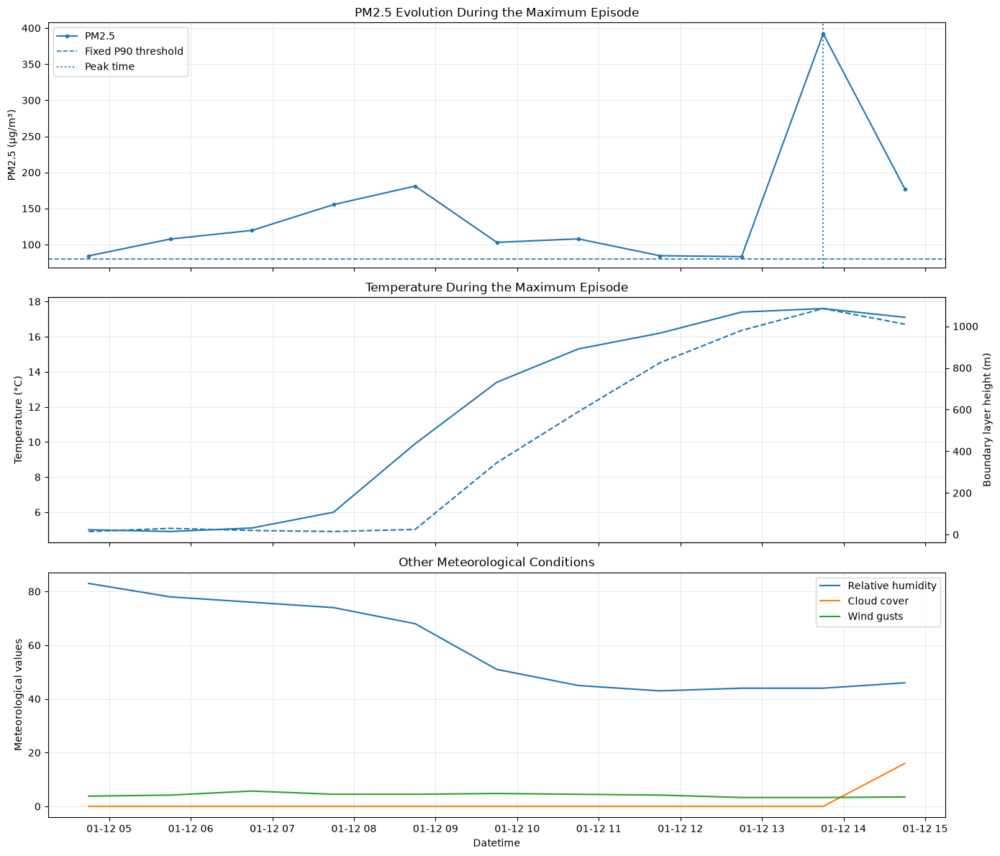

In [310]:
# ============================================================
# 4.9 — DETAILED ANALYSIS OF THE MAXIMUM PM2.5 EPISODE
# ============================================================

maximum_episode = episode_dynamics.loc[
    episode_dynamics["Peak_PM25"].idxmax()
]

maximum_start = maximum_episode["Start"]
maximum_end = maximum_episode["End"]

maximum_episode_profile = episode_met_data.loc[
    maximum_start:maximum_end
].copy()

print("MAXIMUM PM2.5 EPISODE")

print("Start:", maximum_start)
print("End:", maximum_end)
print("Duration:", maximum_episode["Duration_Hours"], "hours")
print("Mean PM2.5:", round(maximum_episode["Mean_PM25"], 2))
print("Peak PM2.5:", round(maximum_episode["Peak_PM25"], 2))
print("Peak time:", maximum_episode["Peak_Time"])


# ------------------------------------------------------------
# PM2.5 time series
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(14, 12),
    sharex=True
)

axes[0].plot(
    maximum_episode_profile.index,
    maximum_episode_profile["pm25"],
    marker="o",
    markersize=3,
    linewidth=1.5,
    label="PM2.5"
)

axes[0].axhline(
    fixed_threshold,
    linestyle="--",
    linewidth=1.2,
    label="Fixed P90 threshold"
)

axes[0].axvline(
    maximum_episode["Peak_Time"],
    linestyle=":",
    linewidth=1.5,
    label="Peak time"
)

axes[0].set_ylabel("PM2.5 (µg/m³)")
axes[0].set_title("PM2.5 Evolution During the Maximum Episode")
axes[0].legend()
axes[0].grid(alpha=0.25)


# ------------------------------------------------------------
# Temperature and boundary layer height
# ------------------------------------------------------------

axes[1].plot(
    maximum_episode_profile.index,
    maximum_episode_profile["temperature_2m"],
    label="Temperature (°C)"
)

axes[1].set_ylabel("Temperature (°C)")
axes[1].set_title("Temperature During the Maximum Episode")
axes[1].grid(alpha=0.25)


# ------------------------------------------------------------
# Boundary layer height on a separate axis
# ------------------------------------------------------------

ax2 = axes[1].twinx()

ax2.plot(
    maximum_episode_profile.index,
    maximum_episode_profile["boundary_layer_height"],
    linestyle="--",
    label="Boundary layer height"
)

ax2.set_ylabel("Boundary layer height (m)")


# ------------------------------------------------------------
# Other meteorological conditions
# ------------------------------------------------------------

for variable, label in [
    ("relative_humidity_2m", "Relative humidity"),
    ("cloud_cover", "Cloud cover"),
    ("wind_gusts_10m", "Wind gusts")
]:

    if variable in maximum_episode_profile.columns:

        axes[2].plot(
            maximum_episode_profile.index,
            maximum_episode_profile[variable],
            label=label
        )

axes[2].set_ylabel("Meteorological values")
axes[2].set_title("Other Meteorological Conditions")
axes[2].legend()
axes[2].grid(alpha=0.25)

axes[2].set_xlabel("Datetime")

plt.tight_layout()
plt.show()

In [312]:
# ============================================================
# 4.9 — CONSISTENT SEASONAL EPISODE DISTRIBUTION
# ============================================================

seasonal_episode_data = episodes.copy()

# Assign season using episode onset month
seasonal_episode_data["Season"] = (
    seasonal_episode_data["Start"].dt.month.map(assign_season)
)

# Aggregate all episode characteristics by onset season
seasonal_episode_summary = (
    seasonal_episode_data
    .groupby("Season")
    .agg(
        Episode_Count=("Start", "count"),
        Episode_Hours=("Duration_Hours", "sum"),
        Mean_Duration=("Duration_Hours", "mean"),
        Median_Duration=("Duration_Hours", "median"),
        Mean_PM25=("Mean_PM25", "mean"),
        Mean_Peak_PM25=("Peak_PM25", "mean"),
        Maximum_Peak_PM25=("Peak_PM25", "max")
    )
    .reindex([
        "Monsoon",
        "Post-monsoon",
        "Winter",
        "Pre-monsoon"
    ])
    .reset_index()
)

print("SEASONAL EPISODE DISTRIBUTION — ASSIGNED BY ONSET SEASON")

display(seasonal_episode_summary.round(2))

print("\nTOTAL EPISODE COUNT:")
print(seasonal_episode_summary["Episode_Count"].sum())

print("\nTOTAL EPISODE-HOURS:")
print(seasonal_episode_summary["Episode_Hours"].sum())

SEASONAL EPISODE DISTRIBUTION — ASSIGNED BY ONSET SEASON


,Season,Episode_Count,Episode_Hours,Mean_Duration,Median_Duration,Mean_PM25,Mean_Peak_PM25,Maximum_Peak_PM25
0,Monsoon,1,3,3.00,3.0,85.22,87.05,87.05
1,Post-monsoon,9,33,3.67,3.0,100.94,115.78,144.68
2,Winter,109,667,6.12,5.0,117.53,159.76,392.19
3,Pre-monsoon,33,278,8.42,6.0,100.04,119.58,227.40



TOTAL EPISODE COUNT:
152

TOTAL EPISODE-HOURS:
981


Figures

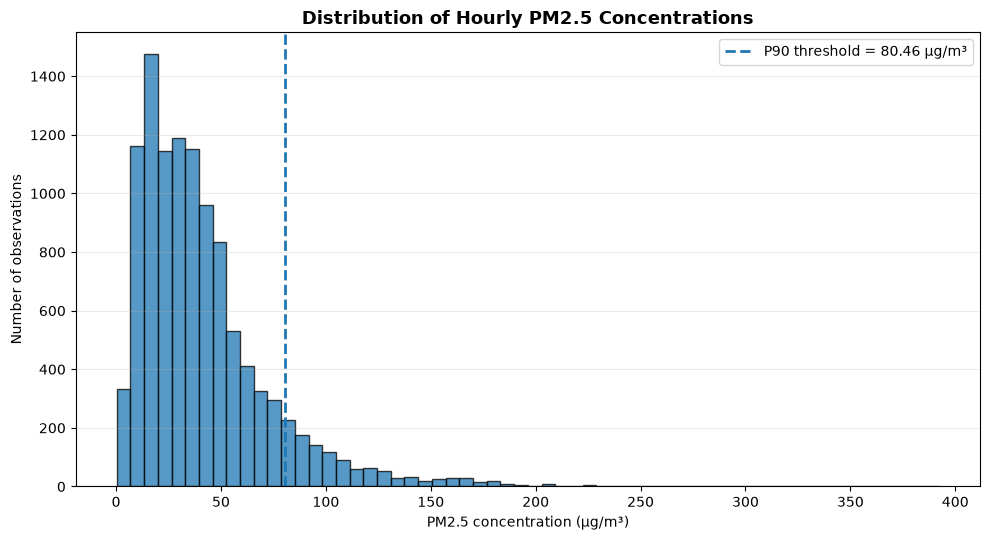

In [313]:
# ============================================================
# FIGURE 4.9.1 — PM2.5 DISTRIBUTION AND EPISODE THRESHOLD
# ============================================================

threshold = 80.46458289736793

pm25_values = episode_met_data["pm25"].dropna()

fig, ax = plt.subplots(figsize=(10, 5.5))

ax.hist(
    pm25_values,
    bins=60,
    edgecolor="black",
    alpha=0.75
)

ax.axvline(
    threshold,
    linestyle="--",
    linewidth=2,
    label=f"P90 threshold = {threshold:.2f} µg/m³"
)

ax.set_title(
    "Distribution of Hourly PM2.5 Concentrations",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("PM2.5 concentration (µg/m³)")
ax.set_ylabel("Number of observations")

ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

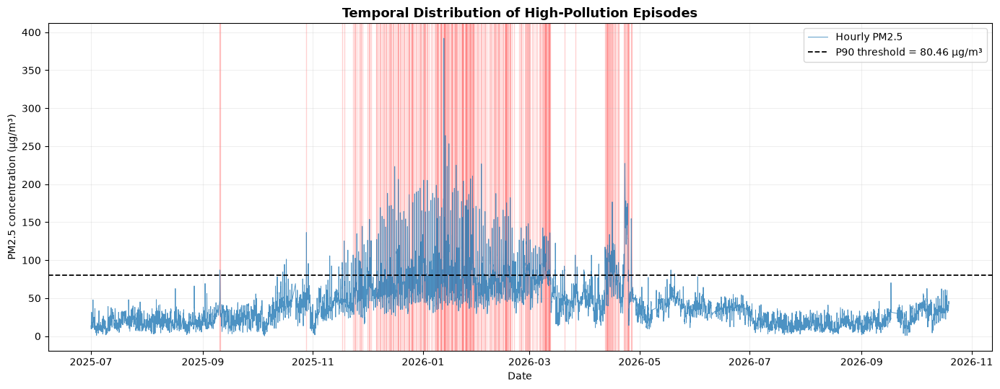

In [314]:
# ============================================================
# FIGURE 4.9.2 — TEMPORAL DISTRIBUTION OF EPISODES
# ============================================================

threshold = 80.46458289736793

fig, ax = plt.subplots(figsize=(14, 5.5))

ax.plot(
    episode_met_data.index,
    episode_met_data["pm25"],
    linewidth=0.65,
    alpha=0.8,
    label="Hourly PM2.5"
)

# Highlight identified episodes
for _, episode in episodes.iterrows():

    ax.axvspan(
        episode["Start"],
        episode["End"],
        color="red",
        alpha=0.18
    )

ax.axhline(
    threshold,
    color="black",
    linestyle="--",
    linewidth=1.3,
    label=f"P90 threshold = {threshold:.2f} µg/m³"
)

ax.set_title(
    "Temporal Distribution of High-Pollution Episodes",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Date")
ax.set_ylabel("PM2.5 concentration (µg/m³)")

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

C:\Users\ianus\AppData\Local\Temp\ipykernel_9048\2343028089.py:24: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  .assign(Month_Period=plot_episodes["Start"].dt.to_period("M"))


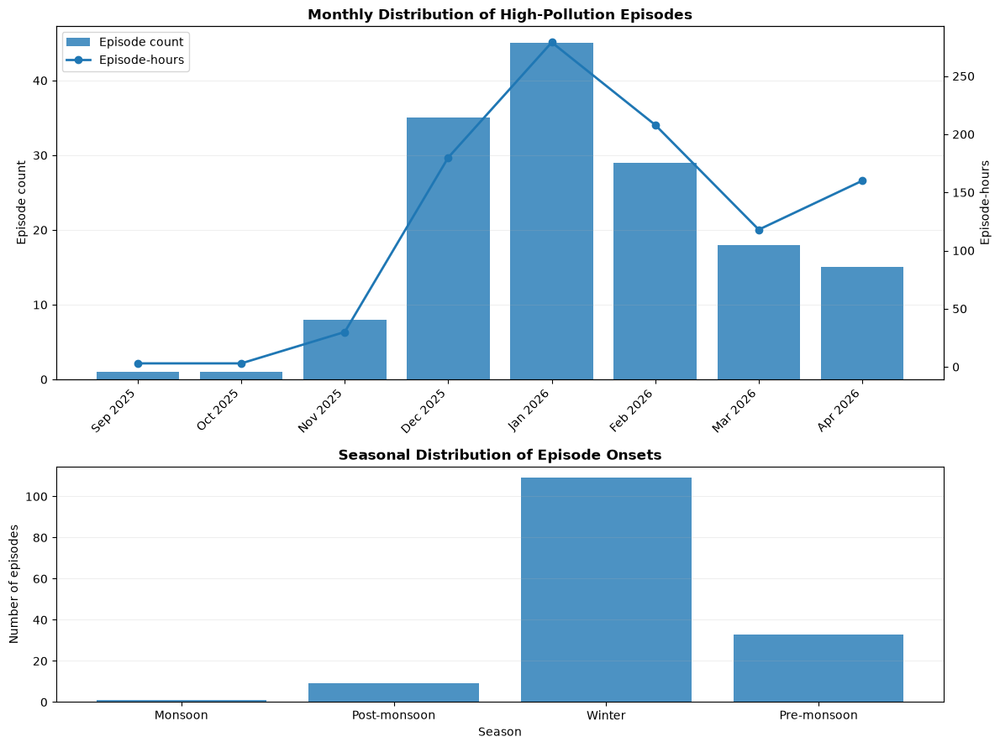

In [315]:
# ============================================================
# FIGURE 4.9.3 — MONTHLY AND SEASONAL EPISODE DISTRIBUTION
# ============================================================

plot_episodes = episodes.copy()

# Monthly classification by episode onset
plot_episodes["Month"] = (
    plot_episodes["Start"].dt.strftime("%b %Y")
)

monthly_summary = (
    plot_episodes
    .groupby("Month", sort=False)
    .agg(
        Episode_Count=("Start", "count"),
        Episode_Hours=("Duration_Hours", "sum")
    )
)

# Ensure chronological month ordering
monthly_summary = monthly_summary.reindex(
    plot_episodes
    .assign(Month_Period=plot_episodes["Start"].dt.to_period("M"))
    .sort_values("Start")["Month"]
    .drop_duplicates()
    .tolist()
)

# Seasonal classification by episode onset
plot_episodes["Season"] = (
    plot_episodes["Start"].dt.month.map(assign_season)
)

season_order = [
    "Monsoon",
    "Post-monsoon",
    "Winter",
    "Pre-monsoon"
]

seasonal_summary = (
    plot_episodes
    .groupby("Season")
    .agg(
        Episode_Count=("Start", "count"),
        Episode_Hours=("Duration_Hours", "sum")
    )
    .reindex(season_order)
)

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 9),
    gridspec_kw={"height_ratios": [1.5, 1]}
)

# Monthly episode distribution
x = np.arange(len(monthly_summary))

axes[0].bar(
    x,
    monthly_summary["Episode_Count"],
    alpha=0.8,
    label="Episode count"
)

axes[0].set_ylabel("Episode count")
axes[0].set_xticks(x)
axes[0].set_xticklabels(
    monthly_summary.index,
    rotation=45,
    ha="right"
)

ax_hours = axes[0].twinx()

ax_hours.plot(
    x,
    monthly_summary["Episode_Hours"],
    marker="o",
    linewidth=2,
    label="Episode-hours"
)

ax_hours.set_ylabel("Episode-hours")

axes[0].set_title(
    "Monthly Distribution of High-Pollution Episodes",
    fontweight="bold"
)

lines1, labels1 = axes[0].get_legend_handles_labels()
lines2, labels2 = ax_hours.get_legend_handles_labels()

axes[0].legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper left"
)

axes[0].grid(axis="y", alpha=0.2)

# Seasonal episode distribution
axes[1].bar(
    seasonal_summary.index,
    seasonal_summary["Episode_Count"],
    alpha=0.8
)

axes[1].set_title(
    "Seasonal Distribution of Episode Onsets",
    fontweight="bold"
)

axes[1].set_xlabel("Season")
axes[1].set_ylabel("Number of episodes")
axes[1].grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

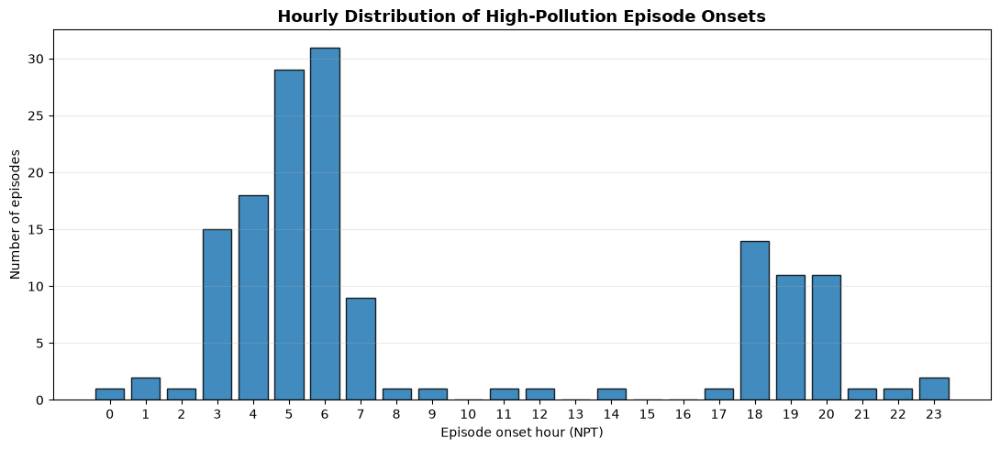

In [316]:
# ============================================================
# FIGURE 4.9.4 — HOURLY DISTRIBUTION OF EPISODE ONSETS
# ============================================================

onset_hours = episodes["Start"].dt.hour

hourly_onsets = (
    onset_hours
    .value_counts()
    .reindex(range(24), fill_value=0)
)

fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(
    hourly_onsets.index,
    hourly_onsets.values,
    alpha=0.85,
    edgecolor="black"
)

ax.set_xticks(range(24))
ax.set_xlabel("Episode onset hour (NPT)")
ax.set_ylabel("Number of episodes")

ax.set_title(
    "Hourly Distribution of High-Pollution Episode Onsets",
    fontsize=13,
    fontweight="bold"
)

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

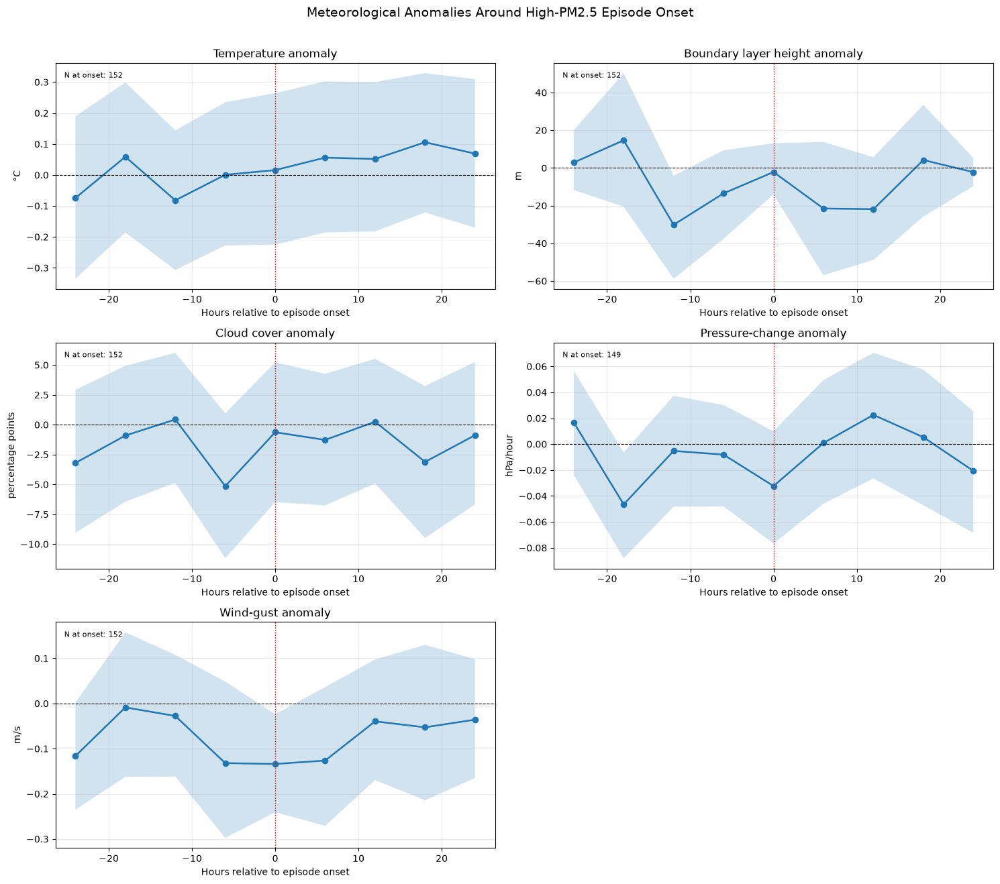

In [317]:
# Figure 4.9.5: Meteorological conditions around episode onset

event_offsets = np.arange(-24, 25, 6)
n_boot = 5000
rng = np.random.default_rng(42)

# Prepare month-hour-adjusted meteorological variables
composite_data = episode_met_data.copy()

composite_data["Temperature_anomaly"] = month_hour_residual(
    composite_data["relative_temperature_2m"]
)

composite_data["BLH_anomaly"] = month_hour_residual(
    composite_data["boundary_layer_height"]
)

composite_data["Cloud_anomaly"] = month_hour_residual(
    composite_data["cloud_cover"]
)

composite_data["Wind_gust_anomaly"] = month_hour_residual(
    composite_data["wind_gusts_10m"]
)

# Calculate pressure change only across consecutive hourly observations
consecutive_hour = (
    composite_data.index.to_series().diff() == pd.Timedelta(hours=1)
)

pressure_change = composite_data["pressure_msl"].diff().where(
    consecutive_hour
)

composite_data["Pressure_change_anomaly"] = month_hour_residual(
    pressure_change
)

composite_variables = {
    "Temperature anomaly": ("Temperature_anomaly", "°C"),
    "Boundary layer height anomaly": ("BLH_anomaly", "m"),
    "Cloud cover anomaly": ("Cloud_anomaly", "percentage points"),
    "Pressure-change anomaly": ("Pressure_change_anomaly", "hPa/hour"),
    "Wind-gust anomaly": ("Wind_gust_anomaly", "m/s")
}

# Extract event-aligned observations for every episode
onset_composites = {}

for variable_name, (column, unit) in composite_variables.items():

    episode_matrix = []

    for _, episode in episodes.iterrows():

        event_times = [
            episode["Start"] + pd.Timedelta(hours=int(offset))
            for offset in event_offsets
        ]

        values = composite_data[column].reindex(event_times).to_numpy()
        episode_matrix.append(values)

    onset_composites[variable_name] = np.asarray(episode_matrix)


# Plot event-aligned composites with episode-level bootstrap confidence intervals
fig, axes = plt.subplots(3, 2, figsize=(15, 13))
axes = axes.flatten()

for ax, (variable_name, (column, unit)) in zip(
    axes, composite_variables.items()
):

    matrix = onset_composites[variable_name]

    mean_values = np.nanmean(matrix, axis=0)

    bootstrap_means = []

    for _ in range(n_boot):

        sampled_indices = rng.integers(
            0, matrix.shape[0], size=matrix.shape[0]
        )

        sampled_matrix = matrix[sampled_indices, :]
        bootstrap_means.append(np.nanmean(sampled_matrix, axis=0))

    bootstrap_means = np.asarray(bootstrap_means)

    lower = np.nanpercentile(bootstrap_means, 2.5, axis=0)
    upper = np.nanpercentile(bootstrap_means, 97.5, axis=0)

    n_available = np.sum(np.isfinite(matrix), axis=0)

    ax.plot(
        event_offsets,
        mean_values,
        marker="o",
        linewidth=1.8,
        label="Mean anomaly"
    )

    ax.fill_between(
        event_offsets,
        lower,
        upper,
        alpha=0.2,
        label="95% bootstrap CI"
    )

    ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
    ax.axvline(0, color="red", linewidth=1, linestyle=":")

    ax.set_title(variable_name)
    ax.set_xlabel("Hours relative to episode onset")
    ax.set_ylabel(unit)
    ax.grid(alpha=0.25)

    # Display available episode counts for transparency
    ax.text(
        0.02, 0.96,
        f"N at onset: {n_available[np.where(event_offsets == 0)[0][0]]}",
        transform=ax.transAxes,
        va="top",
        fontsize=8
    )

axes[-1].axis("off")

fig.suptitle(
    "Meteorological Anomalies Around High-PM2.5 Episode Onset",
    fontsize=14,
    y=1.01
)

plt.tight_layout()
plt.show()

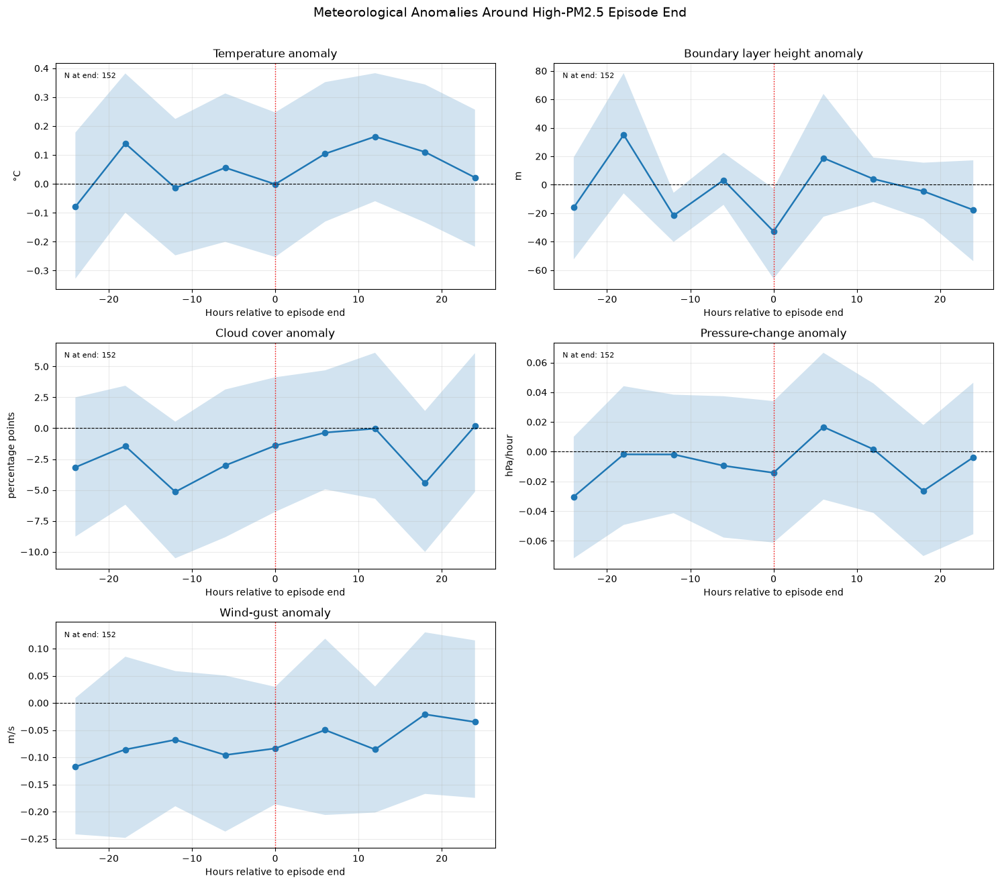

In [318]:
# Figure 4.9.6: Meteorological conditions around episode end

end_composites = {}

for variable_name, (column, unit) in composite_variables.items():

    episode_matrix = []

    for _, episode in episodes.iterrows():

        event_times = [
            episode["End"] + pd.Timedelta(hours=int(offset))
            for offset in event_offsets
        ]

        values = composite_data[column].reindex(event_times).to_numpy()
        episode_matrix.append(values)

    end_composites[variable_name] = np.asarray(episode_matrix)


fig, axes = plt.subplots(3, 2, figsize=(15, 13))
axes = axes.flatten()

for ax, (variable_name, (column, unit)) in zip(
    axes, composite_variables.items()
):

    matrix = end_composites[variable_name]

    mean_values = np.nanmean(matrix, axis=0)

    bootstrap_means = []

    for _ in range(n_boot):

        sampled_indices = rng.integers(
            0, matrix.shape[0], size=matrix.shape[0]
        )

        sampled_matrix = matrix[sampled_indices, :]
        bootstrap_means.append(np.nanmean(sampled_matrix, axis=0))

    bootstrap_means = np.asarray(bootstrap_means)

    lower = np.nanpercentile(bootstrap_means, 2.5, axis=0)
    upper = np.nanpercentile(bootstrap_means, 97.5, axis=0)

    n_available = np.sum(np.isfinite(matrix), axis=0)

    ax.plot(
        event_offsets,
        mean_values,
        marker="o",
        linewidth=1.8,
        label="Mean anomaly"
    )

    ax.fill_between(
        event_offsets,
        lower,
        upper,
        alpha=0.2,
        label="95% bootstrap CI"
    )

    ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
    ax.axvline(0, color="red", linewidth=1, linestyle=":")

    ax.set_title(variable_name)
    ax.set_xlabel("Hours relative to episode end")
    ax.set_ylabel(unit)
    ax.grid(alpha=0.25)

    ax.text(
        0.02, 0.96,
        f"N at end: {n_available[np.where(event_offsets == 0)[0][0]]}",
        transform=ax.transAxes,
        va="top",
        fontsize=8
    )

axes[-1].axis("off")

fig.suptitle(
    "Meteorological Anomalies Around High-PM2.5 Episode End",
    fontsize=14,
    y=1.01
)

plt.tight_layout()
plt.show()

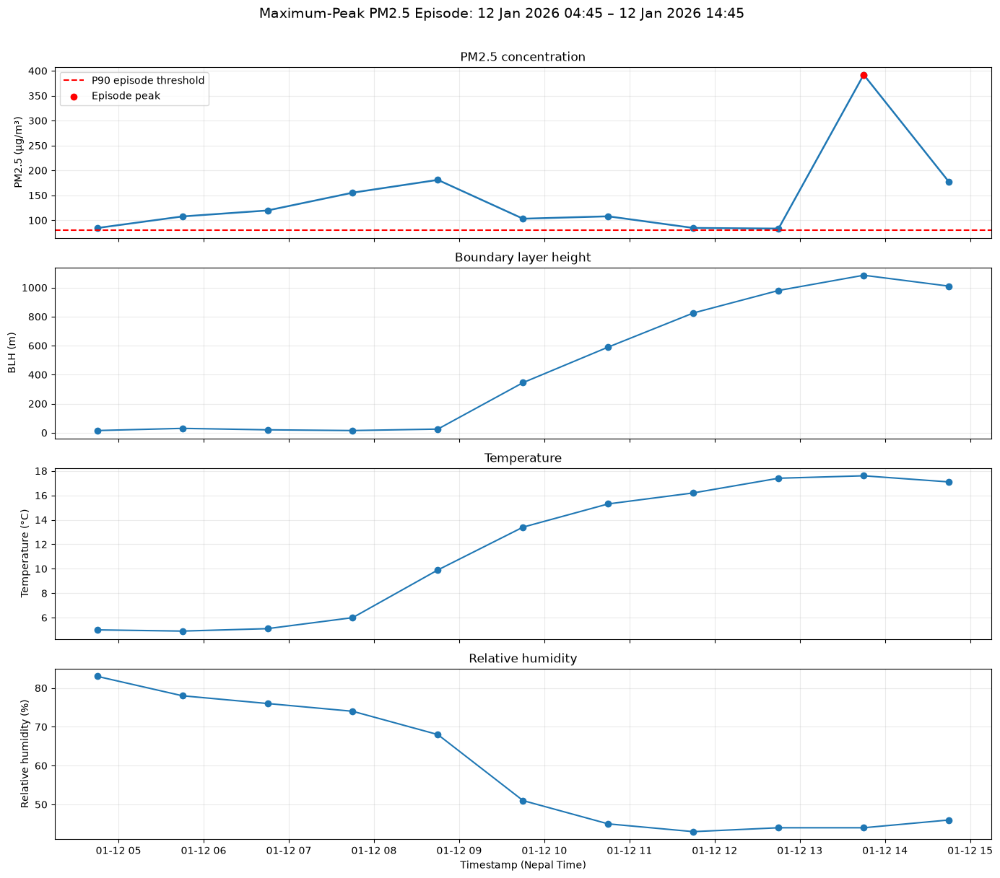

Maximum-peak episode details
----------------------------
Start: 2026-01-12 04:45:00+05:45
End: 2026-01-12 14:45:00+05:45
Duration: 11 hours
Mean PM2.5: 145.15 µg/m³
Peak PM2.5: 392.19 µg/m³
Peak time: 2026-01-12 13:45:00+05:45


In [319]:
# Figure 4.9.7: Maximum-peak episode trajectory

max_peak_episode = episodes.loc[episodes["Peak_PM25"].idxmax()]

start_time = max_peak_episode["Start"]
end_time = max_peak_episode["End"]

max_episode_data = episode_met_data.loc[
    (episode_met_data.index >= start_time) &
    (episode_met_data.index <= end_time)
].copy()

fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)

# PM2.5
axes[0].plot(
    max_episode_data.index,
    max_episode_data["pm25"],
    marker="o",
    linewidth=1.8
)

axes[0].axhline(
    80.46458289736793,
    color="red",
    linestyle="--",
    label="P90 episode threshold"
)

axes[0].scatter(
    max_peak_episode["Peak_Time"],
    max_peak_episode["Peak_PM25"],
    color="red",
    zorder=5,
    label="Episode peak"
)

axes[0].set_ylabel("PM2.5 (µg/m³)")
axes[0].set_title("PM2.5 concentration")
axes[0].legend()
axes[0].grid(alpha=0.25)

# Boundary layer height
axes[1].plot(
    max_episode_data.index,
    max_episode_data["boundary_layer_height"],
    marker="o",
    linewidth=1.5
)

axes[1].set_ylabel("BLH (m)")
axes[1].set_title("Boundary layer height")
axes[1].grid(alpha=0.25)

# Temperature
axes[2].plot(
    max_episode_data.index,
    max_episode_data["temperature_2m"],
    marker="o",
    linewidth=1.5
)

axes[2].set_ylabel("Temperature (°C)")
axes[2].set_title("Temperature")
axes[2].grid(alpha=0.25)

# Relative humidity
axes[3].plot(
    max_episode_data.index,
    max_episode_data["relative_humidity_2m"],
    marker="o",
    linewidth=1.5
)

axes[3].set_ylabel("Relative humidity (%)")
axes[3].set_title("Relative humidity")
axes[3].set_xlabel("Timestamp (Nepal Time)")
axes[3].grid(alpha=0.25)

fig.suptitle(
    f"Maximum-Peak PM2.5 Episode: "
    f"{start_time:%d %b %Y %H:%M} – {end_time:%d %b %Y %H:%M}",
    fontsize=14,
    y=1.01
)

plt.tight_layout()
plt.show()

print("Maximum-peak episode details")
print("----------------------------")
print(f"Start: {start_time}")
print(f"End: {end_time}")
print(f"Duration: {max_peak_episode['Duration_Hours']} hours")
print(f"Mean PM2.5: {max_peak_episode['Mean_PM25']:.2f} µg/m³")
print(f"Peak PM2.5: {max_peak_episode['Peak_PM25']:.2f} µg/m³")
print(f"Peak time: {max_peak_episode['Peak_Time']}")

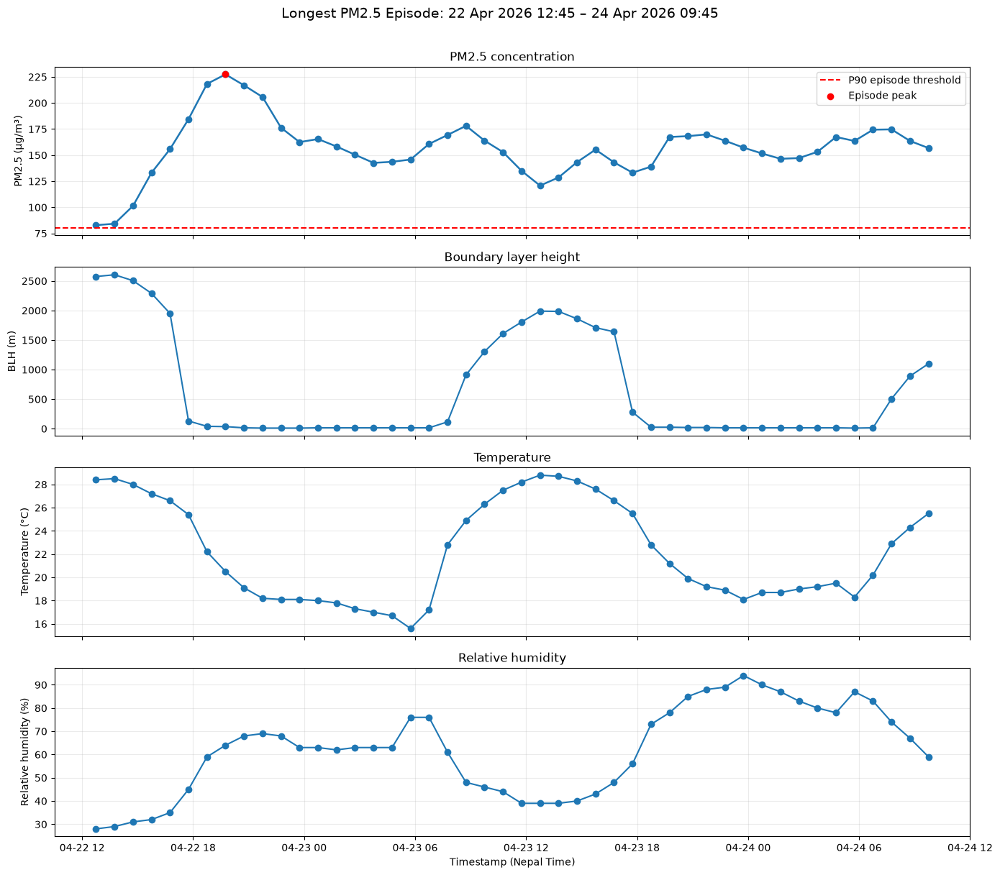

Longest episode details
-----------------------
Start: 2026-04-22 12:45:00+05:45
End: 2026-04-24 09:45:00+05:45
Duration: 46 hours
Mean PM2.5: 156.61 µg/m³
Peak PM2.5: 227.40 µg/m³
Peak time: 2026-04-22 19:45:00+05:45


In [320]:
# Figure 4.9.8: Longest episode trajectory

longest_episode = episodes.loc[
    episodes["Duration_Hours"].idxmax()
]

start_time = longest_episode["Start"]
end_time = longest_episode["End"]

longest_episode_data = episode_met_data.loc[
    (episode_met_data.index >= start_time) &
    (episode_met_data.index <= end_time)
].copy()

fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)

# PM2.5
axes[0].plot(
    longest_episode_data.index,
    longest_episode_data["pm25"],
    marker="o",
    linewidth=1.8
)

axes[0].axhline(
    80.46458289736793,
    color="red",
    linestyle="--",
    label="P90 episode threshold"
)

axes[0].scatter(
    longest_episode["Peak_Time"],
    longest_episode["Peak_PM25"],
    color="red",
    zorder=5,
    label="Episode peak"
)

axes[0].set_ylabel("PM2.5 (µg/m³)")
axes[0].set_title("PM2.5 concentration")
axes[0].legend()
axes[0].grid(alpha=0.25)

# Boundary layer height
axes[1].plot(
    longest_episode_data.index,
    longest_episode_data["boundary_layer_height"],
    marker="o",
    linewidth=1.5
)

axes[1].set_ylabel("BLH (m)")
axes[1].set_title("Boundary layer height")
axes[1].grid(alpha=0.25)

# Temperature
axes[2].plot(
    longest_episode_data.index,
    longest_episode_data["temperature_2m"],
    marker="o",
    linewidth=1.5
)

axes[2].set_ylabel("Temperature (°C)")
axes[2].set_title("Temperature")
axes[2].grid(alpha=0.25)

# Relative humidity
axes[3].plot(
    longest_episode_data.index,
    longest_episode_data["relative_humidity_2m"],
    marker="o",
    linewidth=1.5
)

axes[3].set_ylabel("Relative humidity (%)")
axes[3].set_title("Relative humidity")
axes[3].set_xlabel("Timestamp (Nepal Time)")
axes[3].grid(alpha=0.25)

fig.suptitle(
    f"Longest PM2.5 Episode: "
    f"{start_time:%d %b %Y %H:%M} – {end_time:%d %b %Y %H:%M}",
    fontsize=14,
    y=1.01
)

plt.tight_layout()
plt.show()

print("Longest episode details")
print("-----------------------")
print(f"Start: {start_time}")
print(f"End: {end_time}")
print(f"Duration: {longest_episode['Duration_Hours']} hours")
print(f"Mean PM2.5: {longest_episode['Mean_PM25']:.2f} µg/m³")
print(f"Peak PM2.5: {longest_episode['Peak_PM25']:.2f} µg/m³")
print(f"Peak time: {longest_episode['Peak_Time']}")

In [68]:
import pandas as pd
import numpy as np

d = master[["datetime", "pm25"]].copy().sort_values("datetime").reset_index(drop=True)

# Assign seasons using the study's calendar definitions
month = d["datetime"].dt.month
d["Season"] = np.select(
    [month.isin([6, 7, 8, 9]),
     month.isin([10, 11]),
     month.isin([12, 1, 2]),
     month.isin([3, 4, 5])],
    ["Monsoon", "Post-monsoon", "Winter", "Pre-monsoon"],
    default="Unknown"
)

fixed_threshold = d["pm25"].quantile(0.90)
print(f"Full-record P90: {fixed_threshold:.6f} µg/m³")

def identify_episodes(data, thresholds, minimum=3):
    data = data.reset_index(drop=True)
    above = data["pm25"].ge(thresholds).fillna(False)
    episodes = []
    run = []

    def save_run(indices):
        if len(indices) < minimum:
            return

        e = data.loc[indices].reset_index(drop=True)
        peak_idx = e["pm25"].idxmax()
        peak = e.loc[peak_idx]
        duration = len(e)
        peak_time = peak_idx

        build = np.nan
        decline = np.nan

        if peak_time > 0:
            build = (peak["pm25"] - e.loc[0, "pm25"]) / peak_time

        after_peak = duration - 1 - peak_time
        if after_peak > 0:
            decline = (e.loc[duration-1, "pm25"] - peak["pm25"]) / after_peak

        hour = e.loc[0, "datetime"].hour
        onset = ("Morning" if 4 <= hour <= 9 else
                 "Evening" if 16 <= hour <= 21 else "Other")

        duration_type = ("Short" if duration <= 6 else
                         "Intermediate" if duration < 24 else "Long")

        episodes.append({
            "Episode_ID": len(episodes) + 1,
            "Start": e.loc[0, "datetime"],
            "End": e.loc[duration-1, "datetime"],
            "Season": e.loc[0, "Season"],
            "Duration_Hours": duration,
            "Mean_PM25": e["pm25"].mean(),
            "Peak_PM25": peak["pm25"],
            "Peak_Time_Hours": peak_time,
            "Mean_BLH": e["boundary_layer_height"].mean()
                if "boundary_layer_height" in data.columns else np.nan,
            "Onset_Type": onset,
            "Duration_Type": duration_type,
            "Build_Up_Rate": build,
            "Decline_Rate": decline
        })

    for i in range(len(data)):
        if above.iloc[i]:
            if run and data.loc[i, "datetime"] - data.loc[run[-1], "datetime"] != pd.Timedelta(hours=1):
                save_run(run)
                run = []
            run.append(i)
        else:
            save_run(run)
            run = []

    save_run(run)
    return pd.DataFrame(episodes)

# Include BLH for the episode-level summary
d = master[["datetime", "pm25", "boundary_layer_height"]].copy()
d = d.sort_values("datetime").reset_index(drop=True)

month = d["datetime"].dt.month
d["Season"] = np.select(
    [month.isin([6, 7, 8, 9]), month.isin([10, 11]),
     month.isin([12, 1, 2]), month.isin([3, 4, 5])],
    ["Monsoon", "Post-monsoon", "Winter", "Pre-monsoon"],
    default="Unknown"
)

episodes = identify_episodes(d, fixed_threshold)

print("Reconstructed episodes:", len(episodes))
print("Episode-hours:", episodes["Duration_Hours"].sum())
print("Mean duration:", round(episodes["Duration_Hours"].mean(), 2))
print("Longest duration:", episodes["Duration_Hours"].max())

display(episodes.head())

Full-record P90: 80.464583 µg/m³
Reconstructed episodes: 152
Episode-hours: 981
Mean duration: 6.45
Longest duration: 46


,Episode_ID,Start,End,Season,Duration_Hours,Mean_PM25,Peak_PM25,Peak_Time_Hours,Mean_BLH,Onset_Type,Duration_Type,Build_Up_Rate,Decline_Rate
0,1,2025-09-10 09:45:00+05:45,2025-09-10 11:45:00+05:45,Monsoon,3,85.221076,87.050793,1,873.333333,Morning,Short,4.644246,-0.844904
1,2,2025-10-28 07:45:00+05:45,2025-10-28 09:45:00+05:45,Post-monsoon,3,111.804431,136.499206,1,38.333333,Morning,Short,45.872222,-28.212103
2,3,2025-11-17 05:45:00+05:45,2025-11-17 07:45:00+05:45,Post-monsoon,3,91.567555,97.023214,0,16.666667,Morning,Short,NaN,-3.732819
3,4,2025-11-18 06:45:00+05:45,2025-11-18 08:45:00+05:45,Post-monsoon,3,99.368303,125.369345,1,36.666667,Morning,Short,39.265476,-38.737649
4,5,2025-11-23 03:45:00+05:45,2025-11-23 07:45:00+05:45,Post-monsoon,5,94.942212,106.853572,3,10.000000,Other,Short,8.075397,-6.915476


In [69]:
season_order = ["Monsoon", "Post-monsoon", "Winter", "Pre-monsoon"]

season_thresholds = (
    d.groupby("Season")["pm25"]
    .quantile(0.90)
    .reindex(season_order)
)

seasonal_episodes = []

for season in season_order:
    subset = d[d["Season"] == season].copy()
    threshold = season_thresholds.loc[season]

    result = identify_episodes(subset, threshold)
    if not result.empty:
        result["Threshold"] = threshold
        seasonal_episodes.append(result)

seasonal_episodes = pd.concat(seasonal_episodes, ignore_index=True)

seasonal_sensitivity = (
    seasonal_episodes.groupby("Season")
    .agg(
        Threshold=("Threshold", "first"),
        Episodes=("Episode_ID", "count"),
        Episode_Hours=("Duration_Hours", "sum")
    )
    .reindex(season_order)
)

print("SEASON-SPECIFIC P90 THRESHOLDS AND EPISODES")
display(seasonal_sensitivity.round(2))

print("\nTOTAL")
print("Episodes:", len(seasonal_episodes))
print("Episode-hours:", seasonal_episodes["Duration_Hours"].sum())

SEASON-SPECIFIC P90 THRESHOLDS AND EPISODES


,Threshold,Episodes,Episode_Hours
Season,,,
Monsoon,35.80,49,385
Post-monsoon,59.37,29,142
Winter,125.26,31,109
Pre-monsoon,88.50,26,190



TOTAL
Episodes: 135
Episode-hours: 826


In [70]:
# Table 4.9.5: onset categories
onset_summary = (
    episodes.groupby("Onset_Type")
    .agg(
        Episodes=("Episode_ID", "count"),
        Mean_Duration=("Duration_Hours", "mean"),
        Median_Duration=("Duration_Hours", "median"),
        Mean_Peak=("Peak_PM25", "mean"),
        Median_Peak=("Peak_PM25", "median"),
        Mean_Time_to_Peak=("Peak_Time_Hours", "mean"),
        Median_Time_to_Peak=("Peak_Time_Hours", "median")
    )
    .reindex(["Morning", "Evening", "Other"])
)

print("TABLE 4.9.5 — ONSET CATEGORY")
display(onset_summary.round(2))


# Table 4.9.6: duration categories
duration_summary = (
    episodes.groupby("Duration_Type")
    .agg(
        Episodes=("Episode_ID", "count"),
        Mean_Duration=("Duration_Hours", "mean"),
        Median_Duration=("Duration_Hours", "median"),
        Mean_Peak=("Peak_PM25", "mean"),
        Median_Peak=("Peak_PM25", "median"),
        Mean_Build_Up=("Build_Up_Rate", "mean"),
        Median_Build_Up=("Build_Up_Rate", "median"),
        Build_Up_N=("Build_Up_Rate", "count"),
        Mean_Decline=("Decline_Rate", "mean"),
        Median_Decline=("Decline_Rate", "median"),
        Decline_N=("Decline_Rate", "count")
    )
    .reindex(["Short", "Intermediate", "Long"])
)

print("\nTABLE 4.9.6 — DURATION CATEGORY")
display(duration_summary.round(2))

TABLE 4.9.5 — ONSET CATEGORY


,Episodes,Mean_Duration,Median_Duration,Mean_Peak,Median_Peak,Mean_Time_to_Peak,Median_Time_to_Peak
Onset_Type,,,,,,,
Morning,89,5.06,5.0,154.13,154.35,2.19,2.0
Evening,38,7.05,4.5,129.14,117.88,3.68,2.0
Other,25,10.52,9.0,154.53,144.60,4.96,5.0



TABLE 4.9.6 — DURATION CATEGORY


,Episodes,Mean_Duration,Median_Duration,Mean_Peak,Median_Peak,Mean_Build_Up,Median_Build_Up,Build_Up_N,Mean_Decline,Median_Decline,Decline_N
Duration_Type,,,,,,,,,,,
Short,102,4.35,4.0,137.22,127.62,25.98,22.60,93,-28.51,-23.77,91
Intermediate,49,10.02,8.0,168.66,164.34,18.07,16.94,49,-29.08,-19.67,49
Long,1,46.00,46.0,227.40,227.40,20.64,20.64,1,-1.86,-1.86,1


In [71]:
episodes["Elapsed_Hours"] = (
    (episodes["End"] - episodes["Start"]).dt.total_seconds() / 3600
)

print("Episodes where observation count differs from elapsed hours:")
display(
    episodes.loc[
        episodes["Duration_Hours"] != episodes["Elapsed_Hours"],
        ["Episode_ID", "Duration_Hours", "Elapsed_Hours", "Duration_Type"]
    ].head(20)
)

print("\nEpisodes near typology boundaries:")
display(
    episodes.loc[
        episodes["Duration_Hours"].isin([6, 7, 23, 24, 25]),
        ["Episode_ID", "Duration_Hours", "Elapsed_Hours", "Duration_Type"]
    ]
)

Episodes where observation count differs from elapsed hours:


,Episode_ID,Duration_Hours,Elapsed_Hours,Duration_Type
0,1,3,2.0,Short
1,2,3,2.0,Short
2,3,3,2.0,Short
3,4,3,2.0,Short
4,5,5,4.0,Short
5,6,3,2.0,Short
6,7,3,2.0,Short
7,8,3,2.0,Short
8,9,6,5.0,Short
9,10,4,3.0,Short



Episodes near typology boundaries:


,Episode_ID,Duration_Hours,Elapsed_Hours,Duration_Type
8,9,6,5.0,Short
11,12,6,5.0,Short
18,19,6,5.0,Short
20,21,6,5.0,Short
22,23,6,5.0,Short
26,27,7,6.0,Intermediate
27,28,6,5.0,Short
29,30,7,6.0,Intermediate
33,34,7,6.0,Intermediate
39,40,6,5.0,Short


In [72]:
# Use elapsed timestamp duration, not observation count
episodes["Elapsed_Hours"] = (
    episodes["End"] - episodes["Start"]
).dt.total_seconds() / 3600

episodes["Duration_Type"] = np.select(
    [
        episodes["Elapsed_Hours"] <= 6,
        (episodes["Elapsed_Hours"] > 6) &
        (episodes["Elapsed_Hours"] < 24),
        episodes["Elapsed_Hours"] >= 24
    ],
    ["Short", "Intermediate", "Long"],
    default="Unknown"
)

print("REVISED DURATION CATEGORY COUNTS")
print(episodes["Duration_Type"].value_counts().reindex(
    ["Short", "Intermediate", "Long"], fill_value=0
))

print("\nREVISED DURATION SUMMARY")
display(
    episodes.groupby("Duration_Type")
    .agg(
        Episodes=("Episode_ID", "count"),
        Mean_Duration=("Elapsed_Hours", "mean"),
        Median_Duration=("Elapsed_Hours", "median"),
        Mean_Peak=("Peak_PM25", "mean"),
        Median_Peak=("Peak_PM25", "median"),
        Mean_Build_Up=("Build_Up_Rate", "mean"),
        Median_Build_Up=("Build_Up_Rate", "median"),
        Mean_Decline=("Decline_Rate", "mean"),
        Median_Decline=("Decline_Rate", "median")
    )
    .reindex(["Short", "Intermediate", "Long"])
    .round(2)
)

REVISED DURATION CATEGORY COUNTS
Duration_Type
Short           115
Intermediate     36
Long              1
Name: count, dtype: int64

REVISED DURATION SUMMARY


,Episodes,Mean_Duration,Median_Duration,Mean_Peak,Median_Peak,Mean_Build_Up,Median_Build_Up,Mean_Decline,Median_Decline
Duration_Type,,,,,,,,,
Short,115,3.65,4.0,140.40,134.84,25.56,22.77,-28.97,-24.98
Intermediate,36,10.11,9.0,169.88,160.81,16.43,13.23,-27.98,-17.26
Long,1,45.00,45.0,227.40,227.40,20.64,20.64,-1.86,-1.86


In [73]:
onset_summary = (
    episodes.groupby("Onset_Type")
    .agg(
        Episodes=("Episode_ID", "count"),
        Mean_Duration=("Elapsed_Hours", "mean"),
        Median_Duration=("Elapsed_Hours", "median"),
        Mean_Peak=("Peak_PM25", "mean"),
        Median_Peak=("Peak_PM25", "median"),
        Mean_Time_to_Peak=("Peak_Time_Hours", "mean"),
        Median_Time_to_Peak=("Peak_Time_Hours", "median")
    )
    .reindex(["Morning", "Evening", "Other"])
)

display(onset_summary.round(2))

,Episodes,Mean_Duration,Median_Duration,Mean_Peak,Median_Peak,Mean_Time_to_Peak,Median_Time_to_Peak
Onset_Type,,,,,,,
Morning,89,4.06,4.0,154.13,154.35,2.19,2.0
Evening,38,6.05,3.5,129.14,117.88,3.68,2.0
Other,25,9.52,8.0,154.53,144.60,4.96,5.0


### Observation
High-PM2.5 episodes were concentrated in winter, with 109 of 152 episodes and 667 of 981 episode-hours occurring during this season. Episodes typically lasted 5 hours (median), although one episode persisted for 46 hours. Month-hour-matched comparisons identified lower boundary layer height during episodes, while most other meteorological differences were inconclusive. Event-aligned patterns suggested some short-lived changes in boundary layer height, pressure tendency and wind gusts, but these remain exploratory findings. The PM1/PM2.5 ratio was modestly lower during episodes after temporal matching. Overall, the results indicate strong seasonal and temporal concentration of pollution episodes, with limited evidence for independent meteorological associations.

Some missed figures and table data

In [2]:

datasets = {
    "Hadigaun": hadigaun,
    "Master": master,
    "Lalitpur": lalitpur,
    "Pokhara": pokhara,
    "Embassy": embassy,
    "Durbar": durbar,
    "CAMS": cams
}

for name, df in datasets.items():
    time_col = "datetime_utc" if name == "CAMS" else "datetime"

    print(f"\n{'='*65}")
    print(f"{name}: {df.shape}")
    print("Columns:", df.columns.tolist())
    print("Timestamp dtype:", df[time_col].dtype)
    print("First timestamp:", df[time_col].min())
    print("Last timestamp:", df[time_col].max())

print("\nMASTER DATA TYPES")
print(master.dtypes.to_string())



Hadigaun: (10981, 6)
Columns: ['datetime', 'pm25', 'pm1', 'temperature', 'relative_humidity', 'particle_count_03um']
Timestamp dtype: datetime64[us, UTC+05:45]
First timestamp: 2025-07-01 00:45:00+05:45
Last timestamp: 2026-10-19 08:45:00+05:45

Master: (10981, 26)
Columns: ['datetime', 'pm25', 'pm1', 'temperature', 'relative_humidity', 'particle_count_03um', 'temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'precipitation', 'rain', 'wind_speed_10m', 'wind_direction_10m', 'wind_gusts_10m', 'surface_pressure', 'pressure_msl', 'cloud_cover', 'cloud_cover_low', 'cloud_cover_mid', 'cloud_cover_high', 'boundary_layer_height', 'shortwave_radiation', 'direct_radiation', 'diffuse_radiation', 'terrestrial_radiation', 'sunshine_duration']
Timestamp dtype: datetime64[us, UTC+05:45]
First timestamp: 2025-07-01 00:45:00+05:45
Last timestamp: 2026-10-19 08:45:00+05:45

Lalitpur: (6000, 6)
Columns: ['datetime', 'pm25', 'pm1', 'temperature', 'relative_humidity', 'particle_count_03um']
Timesta

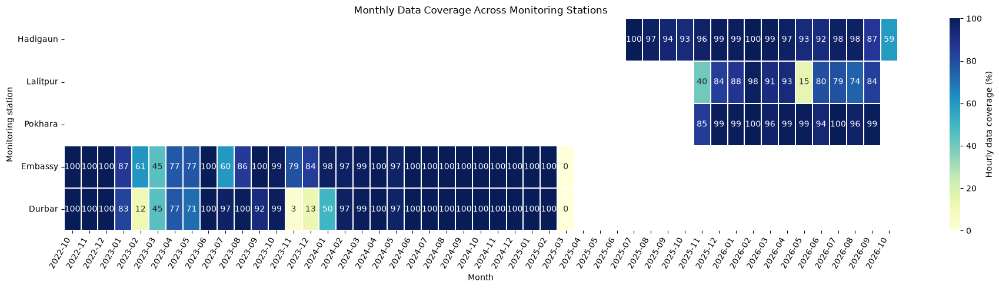

MONTHLY COVERAGE MATRIX (%)


,Hadigaun,Lalitpur,Pokhara,Embassy,Durbar
2022-10,NaN,NaN,NaN,99.9,99.9
2022-11,NaN,NaN,NaN,100.0,100.0
2022-12,NaN,NaN,NaN,100.0,100.0
2023-01,NaN,NaN,NaN,86.6,83.2
2023-02,NaN,NaN,NaN,60.9,11.6
2023-03,NaN,NaN,NaN,45.0,45.0
2023-04,NaN,NaN,NaN,76.7,76.7
2023-05,NaN,NaN,NaN,77.3,71.0
2023-06,NaN,NaN,NaN,99.9,99.7
2023-07,NaN,NaN,NaN,59.8,97.0



CHECK: OBSERVED MONTHLY COUNTS


,Hadigaun,Lalitpur,Pokhara,Embassy,Durbar
2022-10,NaN,NaN,NaN,743.0,743.0
2022-11,NaN,NaN,NaN,720.0,720.0
2022-12,NaN,NaN,NaN,744.0,744.0
2023-01,NaN,NaN,NaN,644.0,619.0
2023-02,NaN,NaN,NaN,409.0,78.0
2023-03,NaN,NaN,NaN,335.0,335.0
2023-04,NaN,NaN,NaN,552.0,552.0
2023-05,NaN,NaN,NaN,575.0,528.0
2023-06,NaN,NaN,NaN,719.0,718.0
2023-07,NaN,NaN,NaN,445.0,722.0


In [4]:

# FIGURE 2.2 — Monthly hourly data coverage

station_data = {
    "Hadigaun": hadigaun,
    "Lalitpur": lalitpur,
    "Pokhara": pokhara,
    "Embassy": embassy,
    "Durbar": durbar
}

monthly_counts = {}
station_periods = {}

for name, df in station_data.items():
    dt = pd.to_datetime(df["datetime"]).dropna().drop_duplicates().sort_values()

    # Count distinct observed clock-hours per calendar month
    hourly = dt.dt.floor("h")
    month_labels = hourly.dt.strftime("%Y-%m")

    counts = month_labels.value_counts().sort_index()
    monthly_counts[name] = counts

    station_periods[name] = (
        dt.min().strftime("%Y-%m"),
        dt.max().strftime("%Y-%m")
    )

# Create a common monthly index
first_month = min(v[0] for v in station_periods.values())
last_month = max(v[1] for v in station_periods.values())

all_months = pd.date_range(
    start=first_month + "-01",
    end=last_month + "-01",
    freq="MS"
).strftime("%Y-%m")

coverage = pd.DataFrame(monthly_counts).reindex(all_months)

# Convert observed clock-hours into percentage of calendar hours
for month in coverage.index:
    total_hours = pd.Period(month, freq="M").days_in_month * 24
    coverage.loc[month] = coverage.loc[month] / total_hours * 100

# Blank months outside each station's recorded period
for name, (first, last) in station_periods.items():
    outside = [
        month for month in coverage.index
        if month < first or month > last
    ]
    coverage.loc[outside, name] = np.nan

# Plot
plt.figure(figsize=(19, 5))

sns.heatmap(
    coverage.T,
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    annot=True,
    fmt=".0f",
    linewidths=0.3,
    mask=coverage.T.isna(),
    cbar_kws={"label": "Hourly data coverage (%)"}
)

plt.title("Monthly Data Coverage Across Monitoring Stations")
plt.xlabel("Month")
plt.ylabel("Monitoring station")
plt.xticks(rotation=60, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("MONTHLY COVERAGE MATRIX (%)")
display(coverage.round(1))

print("\nCHECK: OBSERVED MONTHLY COUNTS")
display(pd.DataFrame(monthly_counts).reindex(all_months))


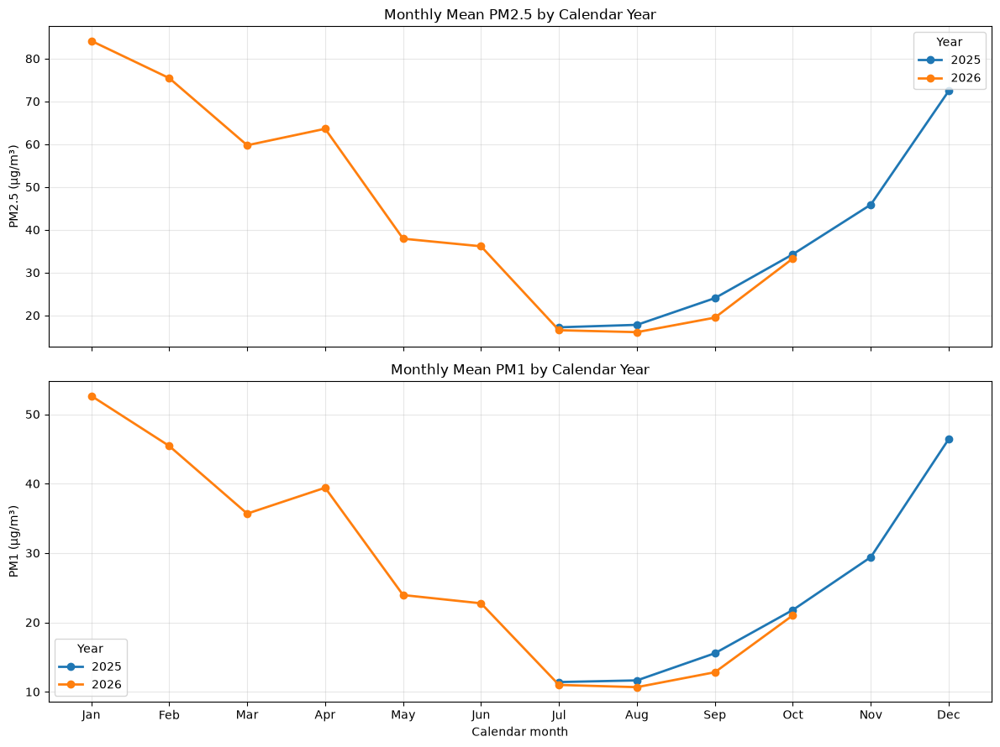

MONTHLY POLLUTANT SUMMARY


PM25_mean  PM25_n  PM1_mean  PM1_n
Year Month                                    
2025 7          17.20     742     11.40    742
     8          17.78     724     11.64    724
     9          24.02     680     15.55    680
     10         34.27     691     21.78    691
     11         45.87     692     29.40    692
     12         72.44     736     46.42    736
2026 1          84.15     734     52.65    734
     2          75.44     670     45.42    670
     3          59.75     738     35.67    738
     4          63.60     701     39.41    701
     5          37.91     690     23.94    690
     6          36.14     664     22.75    664
     7          16.52     726     10.98    726
     8          16.07     726     10.66    726
     9          19.46     626     12.81    626
     10         33.28     441     21.02    441

In [6]:

# FIGURE 6.2 — Calendar-year comparison of monthly PM2.5 and PM1 means

df = hadigaun.copy()
df["datetime"] = pd.to_datetime(df["datetime"])

df["Year"] = df["datetime"].dt.year
df["Month"] = df["datetime"].dt.month

monthly_pollutants = (
    df.groupby(["Year", "Month"])[["pm25", "pm1"]]
    .agg(["mean", "count"])
)

# Extract monthly means
pm25_monthly = df.groupby(["Year", "Month"])["pm25"].mean().unstack("Year")
pm1_monthly = df.groupby(["Year", "Month"])["pm1"].mean().unstack("Year")

month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# Plot two pollutant panels
fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

for year in pm25_monthly.columns:
    axes[0].plot(
        pm25_monthly.index,
        pm25_monthly[year],
        marker="o",
        linewidth=2,
        label=str(year)
    )

for year in pm1_monthly.columns:
    axes[1].plot(
        pm1_monthly.index,
        pm1_monthly[year],
        marker="o",
        linewidth=2,
        label=str(year)
    )

axes[0].set_title("Monthly Mean PM2.5 by Calendar Year")
axes[0].set_ylabel("PM2.5 (µg/m³)")
axes[0].legend(title="Year")
axes[0].grid(True, alpha=0.3)

axes[1].set_title("Monthly Mean PM1 by Calendar Year")
axes[1].set_ylabel("PM1 (µg/m³)")
axes[1].set_xlabel("Calendar month")
axes[1].legend(title="Year")
axes[1].grid(True, alpha=0.3)

axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(month_labels)

plt.tight_layout()
plt.show()

# Monthly means and observation counts for verification
monthly_summary = (
    df.groupby(["Year", "Month"])
    .agg(
        PM25_mean=("pm25", "mean"),
        PM25_n=("pm25", "count"),
        PM1_mean=("pm1", "mean"),
        PM1_n=("pm1", "count")
    )
    .round(2)
)

print("MONTHLY POLLUTANT SUMMARY")
display(monthly_summary)


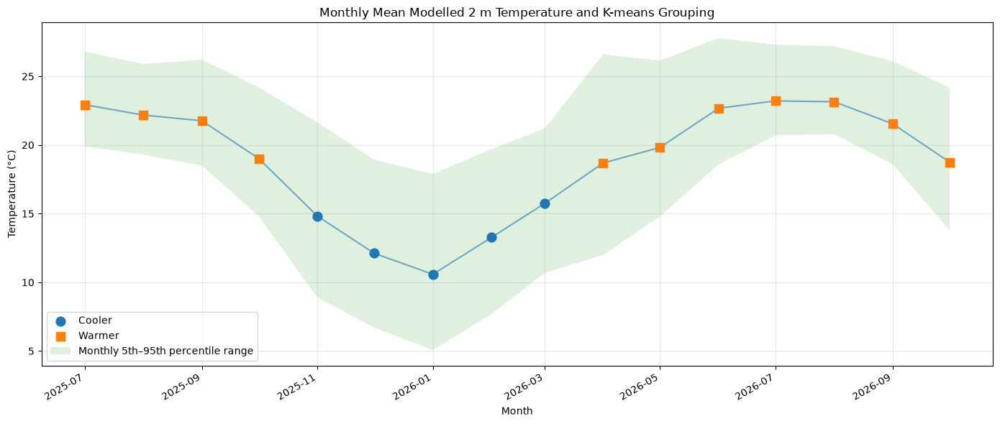

MONTHLY TEMPERATURE AND CLUSTER ASSIGNMENTS


,Mean,P5,P95,N,Temperature_Group
datetime,,,,,
2025-07-01 00:00:00+05:45,22.94,19.90,26.80,742,Warmer
2025-08-01 00:00:00+05:45,22.18,19.30,25.90,724,Warmer
2025-09-01 00:00:00+05:45,21.76,18.50,26.20,680,Warmer
2025-10-01 00:00:00+05:45,19.01,14.80,24.20,691,Warmer
2025-11-01 00:00:00+05:45,14.82,8.90,21.64,692,Cooler
2025-12-01 00:00:00+05:45,12.11,6.70,18.92,736,Cooler
2026-01-01 00:00:00+05:45,10.58,5.06,17.90,734,Cooler
2026-02-01 00:00:00+05:45,13.28,7.70,19.70,670,Cooler
2026-03-01 00:00:00+05:45,15.74,10.68,21.20,738,Cooler



CLUSTER SUMMARY


,Months,Mean_temperature,Minimum,Maximum
Temperature_Group,,,,
Cooler,5,13.31,10.58,15.74
Warmer,11,21.25,18.69,23.21


In [7]:

# FIGURE 6.4 — Monthly modelled temperature and K-means groups

from sklearn.cluster import KMeans

df = master[["datetime", "temperature_2m"]].copy()
df["datetime"] = pd.to_datetime(df["datetime"])

# Monthly temperature statistics
monthly_temperature = (
    df.set_index("datetime")["temperature_2m"]
    .resample("MS")
    .agg(
        Mean="mean",
        P5=lambda x: x.quantile(0.05),
        P95=lambda x: x.quantile(0.95),
        N="count"
    )
    .dropna(subset=["Mean"])
)

# K-means on monthly mean temperatures
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

raw_labels = kmeans.fit_predict(
    monthly_temperature[["Mean"]]
)

# Order clusters by their temperature centres
centres = kmeans.cluster_centers_.flatten()
cooler_label = np.argmin(centres)
warmer_label = np.argmax(centres)

monthly_temperature["Temperature_Group"] = [
    "Cooler" if label == cooler_label else "Warmer"
    for label in raw_labels
]

# Plot
fig, ax = plt.subplots(figsize=(14, 6))

group_styles = {
    "Cooler": "o",
    "Warmer": "s"
}

for group in ["Cooler", "Warmer"]:
    subset = monthly_temperature[
        monthly_temperature["Temperature_Group"] == group
    ]

    ax.scatter(
        subset.index,
        subset["Mean"],
        marker=group_styles[group],
        s=85,
        label=group,
        zorder=3
    )

ax.plot(
    monthly_temperature.index,
    monthly_temperature["Mean"],
    linewidth=1.5,
    alpha=0.6,
    zorder=2
)

ax.fill_between(
    monthly_temperature.index,
    monthly_temperature["P5"],
    monthly_temperature["P95"],
    alpha=0.15,
    label="Monthly 5th–95th percentile range"
)

ax.set_title(
    "Monthly Mean Modelled 2 m Temperature and K-means Grouping"
)
ax.set_xlabel("Month")
ax.set_ylabel("Temperature (°C)")
ax.grid(True, alpha=0.3)
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

# Cluster summary
cluster_summary = (
    monthly_temperature.groupby("Temperature_Group")
    .agg(
        Months=("Mean", "count"),
        Mean_temperature=("Mean", "mean"),
        Minimum=("Mean", "min"),
        Maximum=("Mean", "max")
    )
    .round(2)
)

print("MONTHLY TEMPERATURE AND CLUSTER ASSIGNMENTS")
display(monthly_temperature.round(2))

print("\nCLUSTER SUMMARY")
display(cluster_summary)


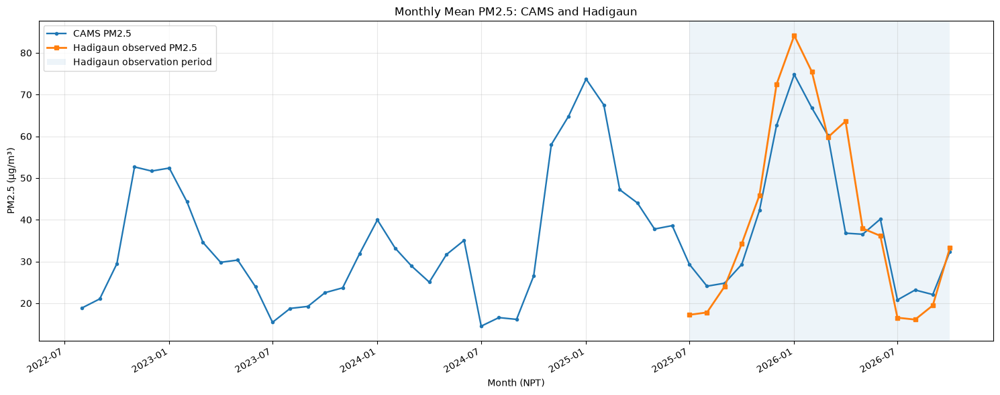

MONTHLY CAMS AND HADIGAUN PM2.5 SUMMARY (NPT)


,CAMS_mean,CAMS_n,Hadigaun_mean,Hadigaun_n
2022-07-31 18:15:00+00:00,18.86,667,NaN,NaN
2022-08-31 18:15:00+00:00,21.02,720,NaN,NaN
2022-09-30 18:15:00+00:00,29.44,744,NaN,NaN
2022-10-31 18:15:00+00:00,52.65,720,NaN,NaN
2022-11-30 18:15:00+00:00,51.66,744,NaN,NaN
2022-12-31 18:15:00+00:00,52.38,744,NaN,NaN
2023-01-31 18:15:00+00:00,44.28,672,NaN,NaN
2023-02-28 18:15:00+00:00,34.56,744,NaN,NaN
2023-03-31 18:15:00+00:00,29.79,720,NaN,NaN
2023-04-30 18:15:00+00:00,30.33,744,NaN,NaN


In [8]:

# FIGURE 6.6 — Monthly CAMS and Hadigaun PM2.5 comparison

# Prepare CAMS timestamps in NPT
cams_plot = cams[["datetime_utc", "pm25"]].copy()

cams_plot["datetime_utc"] = pd.to_datetime(
    cams_plot["datetime_utc"], utc=True
)

cams_plot["datetime_npt"] = (
    cams_plot["datetime_utc"].dt.tz_convert("Asia/Kathmandu")
)

# Restrict CAMS to the end of October 2026
cams_plot = cams_plot[
    cams_plot["datetime_npt"] < pd.Timestamp(
        "2026-11-01", tz="Asia/Kathmandu"
    )
]

# Monthly CAMS means in NPT
cams_monthly = (
    cams_plot.set_index("datetime_npt")["pm25"]
    .resample("MS")
    .agg(["mean", "count"])
)

# Monthly Hadigaun means in NPT
hadigaun_plot = hadigaun.copy()
hadigaun_plot["datetime"] = pd.to_datetime(
    hadigaun_plot["datetime"]
)

hadigaun_monthly = (
    hadigaun_plot.set_index("datetime")["pm25"]
    .resample("MS")
    .agg(["mean", "count"])
)

# Plot
fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(
    cams_monthly.index,
    cams_monthly["mean"],
    marker="o",
    markersize=3,
    linewidth=1.7,
    label="CAMS PM2.5"
)

ax.plot(
    hadigaun_monthly.index,
    hadigaun_monthly["mean"],
    marker="s",
    markersize=5,
    linewidth=2,
    label="Hadigaun observed PM2.5"
)

# Highlight the Hadigaun observation period
ax.axvspan(
    hadigaun_monthly.index.min(),
    hadigaun_monthly.index.max(),
    alpha=0.08,
    label="Hadigaun observation period"
)

ax.set_title("Monthly Mean PM2.5: CAMS and Hadigaun")
ax.set_xlabel("Month (NPT)")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.grid(True, alpha=0.3)
ax.legend()

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

# Monthly comparison table
comparison = pd.concat(
    [
        cams_monthly["mean"].rename("CAMS_mean"),
        cams_monthly["count"].rename("CAMS_n"),
        hadigaun_monthly["mean"].rename("Hadigaun_mean"),
        hadigaun_monthly["count"].rename("Hadigaun_n")
    ],
    axis=1
)

print("MONTHLY CAMS AND HADIGAUN PM2.5 SUMMARY (NPT)")
display(comparison.round(2))


In [9]:

# Correct monthly index display to NPT calendar months

cams_monthly.index = (
    cams_monthly.index
    .tz_convert("Asia/Kathmandu")
    .tz_localize(None)
)

hadigaun_monthly.index = (
    hadigaun_monthly.index
    .tz_convert("Asia/Kathmandu")
    .tz_localize(None)
)

# Rebuild comparison table with explicit month labels
comparison = pd.concat(
    [
        cams_monthly["mean"].rename("CAMS_mean"),
        cams_monthly["count"].rename("CAMS_n"),
        hadigaun_monthly["mean"].rename("Hadigaun_mean"),
        hadigaun_monthly["count"].rename("Hadigaun_n")
    ],
    axis=1
)

comparison.index = comparison.index.strftime("%Y-%m")
comparison.index.name = "Month (NPT)"

print("MONTHLY CAMS AND HADIGAUN PM2.5 SUMMARY (NPT)")
display(comparison.round(2))


MONTHLY CAMS AND HADIGAUN PM2.5 SUMMARY (NPT)


,CAMS_mean,CAMS_n,Hadigaun_mean,Hadigaun_n
Month (NPT),,,,
2022-08,18.86,667,NaN,NaN
2022-09,21.02,720,NaN,NaN
2022-10,29.44,744,NaN,NaN
2022-11,52.65,720,NaN,NaN
2022-12,51.66,744,NaN,NaN
2023-01,52.38,744,NaN,NaN
2023-02,44.28,672,NaN,NaN
2023-03,34.56,744,NaN,NaN
2023-04,29.79,720,NaN,NaN


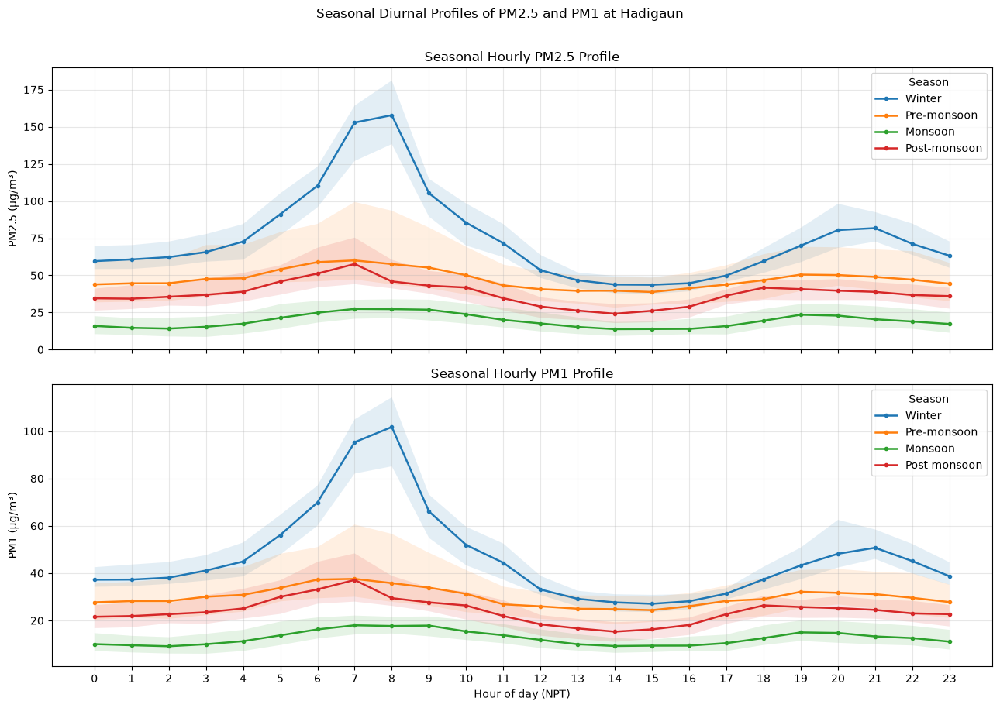

OBSERVATIONS BY SEASON


,PM25_n,PM1_n
Season,,
Winter,2140,2140
Pre-monsoon,2129,2129
Monsoon,4888,4888
Post-monsoon,1824,1824



HOURLY SAMPLE COUNTS BY SEASON


PM25_n  PM1_n
Season       Hour               
Winter       0         89     89
             1         90     90
             2         90     90
             3         90     90
             4         90     90
...                   ...    ...
Post-monsoon 19        77     77
             20        77     77
             21        77     77
             22        76     76
             23        77     77

[96 rows x 2 columns]

In [10]:

# FIGURE 7.2 — Seasonal hourly PM2.5 and PM1 profiles

df = hadigaun.copy()
df["datetime"] = pd.to_datetime(df["datetime"])

df["Month"] = df["datetime"].dt.month
df["Hour"] = df["datetime"].dt.hour

season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Pre-monsoon", 4: "Pre-monsoon", 5: "Pre-monsoon",
    6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
    10: "Post-monsoon", 11: "Post-monsoon"
}

df["Season"] = df["Month"].map(season_map)

seasons = ["Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"]

fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

for ax, pollutant, title in zip(
    axes,
    ["pm25", "pm1"],
    ["PM2.5", "PM1"]
):
    for season in seasons:
        subset = df[df["Season"] == season]

        summary = (
            subset.groupby("Hour")[pollutant]
            .agg(
                Median="median",
                Q25=lambda x: x.quantile(0.25),
                Q75=lambda x: x.quantile(0.75),
                N="count"
            )
            .reindex(range(24))
        )

        ax.plot(
            summary.index,
            summary["Median"],
            marker="o",
            markersize=3,
            linewidth=1.8,
            label=season
        )

        ax.fill_between(
            summary.index,
            summary["Q25"],
            summary["Q75"],
            alpha=0.12
        )

    ax.set_title(f"Seasonal Hourly {title} Profile")
    ax.set_ylabel(f"{title} (µg/m³)")
    ax.grid(True, alpha=0.3)
    ax.legend(title="Season")

axes[1].set_xlabel("Hour of day (NPT)")
axes[1].set_xticks(range(24))

plt.suptitle(
    "Seasonal Diurnal Profiles of PM2.5 and PM1 at Hadigaun",
    y=1.01
)
plt.tight_layout()
plt.show()

# Summary: sample counts by season
season_counts = (
    df.groupby("Season")
    .agg(
        PM25_n=("pm25", "count"),
        PM1_n=("pm1", "count")
    )
    .reindex(seasons)
)

print("OBSERVATIONS BY SEASON")
display(season_counts)

# Hourly sample counts by season
hourly_counts = (
    df.groupby(["Season", "Hour"])
    .agg(
        PM25_n=("pm25", "count"),
        PM1_n=("pm1", "count")
    )
    .reindex(
        pd.MultiIndex.from_product(
            [seasons, range(24)],
            names=["Season", "Hour"]
        )
    )
)

print("\nHOURLY SAMPLE COUNTS BY SEASON")
display(hourly_counts)


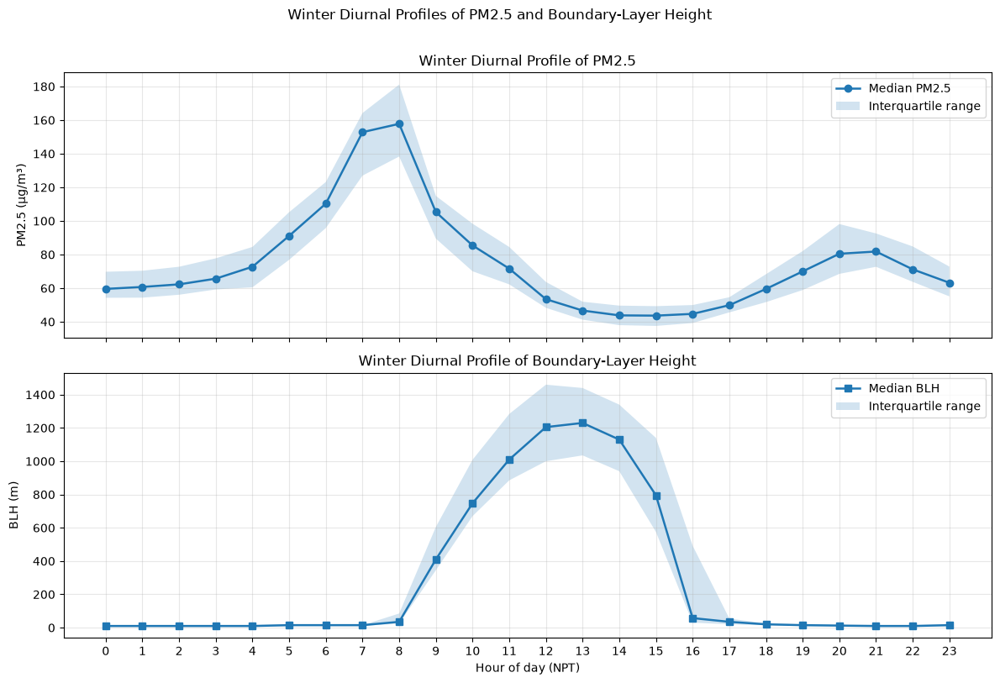

WINTER PAIRED OBSERVATIONS
Total paired observations: 2140
PM2.5 valid before pairing: 2140
BLH valid before pairing: 2140

HOURLY WINTER SUMMARY


,PM25_median,PM25_Q25,PM25_Q75,BLH_median,BLH_Q25,BLH_Q75,N
Hour,,,,,,,
0,59.57,54.27,69.77,10.0,10.0,15.00,89
1,60.72,54.35,70.37,10.0,10.0,15.00,90
2,62.27,56.09,72.75,10.0,10.0,15.00,90
3,65.66,59.24,77.76,10.0,10.0,15.00,90
4,72.73,60.50,84.54,10.0,10.0,15.00,90
5,91.11,76.88,105.21,15.0,15.0,20.00,90
6,110.30,95.77,123.17,15.0,10.0,15.00,90
7,152.82,126.96,164.20,15.0,10.0,15.00,90
8,157.77,138.32,181.12,35.0,25.0,85.00,89



WINTER BLH AVAILABILITY
Total winter timestamps: 2140
Valid paired timestamps: 2140
Paired-data availability (%): 100.0


In [11]:

# FIGURE 7.5 — Winter median hourly PM2.5 and boundary-layer height

df = master[
    ["datetime", "pm25", "boundary_layer_height"]
].copy()

df["datetime"] = pd.to_datetime(df["datetime"])
df["Month"] = df["datetime"].dt.month
df["Hour"] = df["datetime"].dt.hour

# Winter: December, January and February
winter = df[df["Month"].isin([12, 1, 2])].copy()

# Retain paired valid observations
winter = winter.dropna(
    subset=["pm25", "boundary_layer_height"]
)

# Hourly median and interquartile range
winter_hourly = (
    winter.groupby("Hour")
    .agg(
        PM25_median=("pm25", "median"),
        PM25_Q25=("pm25", lambda x: x.quantile(0.25)),
        PM25_Q75=("pm25", lambda x: x.quantile(0.75)),
        BLH_median=("boundary_layer_height", "median"),
        BLH_Q25=("boundary_layer_height", lambda x: x.quantile(0.25)),
        BLH_Q75=("boundary_layer_height", lambda x: x.quantile(0.75)),
        N=("pm25", "count")
    )
    .reindex(range(24))
)

# Two separate panels
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# PM2.5 profile
axes[0].plot(
    winter_hourly.index,
    winter_hourly["PM25_median"],
    marker="o",
    linewidth=1.8,
    label="Median PM2.5"
)

axes[0].fill_between(
    winter_hourly.index,
    winter_hourly["PM25_Q25"],
    winter_hourly["PM25_Q75"],
    alpha=0.2,
    label="Interquartile range"
)

axes[0].set_title("Winter Diurnal Profile of PM2.5")
axes[0].set_ylabel("PM2.5 (µg/m³)")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Boundary-layer-height profile
axes[1].plot(
    winter_hourly.index,
    winter_hourly["BLH_median"],
    marker="s",
    linewidth=1.8,
    label="Median BLH"
)

axes[1].fill_between(
    winter_hourly.index,
    winter_hourly["BLH_Q25"],
    winter_hourly["BLH_Q75"],
    alpha=0.2,
    label="Interquartile range"
)

axes[1].set_title("Winter Diurnal Profile of Boundary-Layer Height")
axes[1].set_ylabel("BLH (m)")
axes[1].set_xlabel("Hour of day (NPT)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

axes[1].set_xticks(range(24))

plt.suptitle(
    "Winter Diurnal Profiles of PM2.5 and Boundary-Layer Height",
    y=1.01
)

plt.tight_layout()
plt.show()

# Verification statistics
print("WINTER PAIRED OBSERVATIONS")
print("Total paired observations:", len(winter))
print("PM2.5 valid before pairing:",
      df[df["Month"].isin([12, 1, 2])]["pm25"].count())
print("BLH valid before pairing:",
      df[df["Month"].isin([12, 1, 2])]["boundary_layer_height"].count())

print("\nHOURLY WINTER SUMMARY")
display(winter_hourly.round(2))

print("\nWINTER BLH AVAILABILITY")
winter_all = df[df["Month"].isin([12, 1, 2])]
print("Total winter timestamps:", len(winter_all))
print("Valid paired timestamps:", len(winter))
print("Paired-data availability (%):",
      round(len(winter) / len(winter_all) * 100, 2))


In [16]:

# FIGURE 9.3 — Prepare hourly data

from scipy.stats import spearmanr

predictors = [
    "temperature_2m",
    "precipitation",
    "wind_gusts_10m",
    "boundary_layer_height",
    "shortwave_radiation"
]

pollutants = ["pm25", "pm1"]

required = ["datetime"] + pollutants + predictors
missing = [c for c in required if c not in master.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

lag_df = master[required].copy()
lag_df["datetime"] = pd.to_datetime(lag_df["datetime"])

lag_df = (
    lag_df.sort_values("datetime")
    .drop_duplicates("datetime")
    .set_index("datetime")
)

# Preserve missing hourly observations
hourly_index = pd.date_range(
    start=lag_df.index.min(),
    end=lag_df.index.max(),
    freq="h"
)

lag_df = lag_df.reindex(hourly_index)
lag_df.index.name = "datetime"

print("HOURLY DATASET")
print("Shape:", lag_df.shape)
print("Start:", lag_df.index.min())
print("End:", lag_df.index.max())
print("\nValid observations:")
display(lag_df.notna().sum().to_frame("Valid_N"))


HOURLY DATASET
Shape: (11409, 7)
Start: 2025-07-01 00:45:00+05:45
End: 2026-10-19 08:45:00+05:45

Valid observations:


,Valid_N
pm25,10981
pm1,10981
temperature_2m,10981
precipitation,10981
wind_gusts_10m,10981
boundary_layer_height,10504
shortwave_radiation,10981


In [17]:

# Month-and-hour residual adjustment

adjusted_df = pd.DataFrame(index=lag_df.index)

for col in pollutants + predictors:
    group_mean = lag_df.groupby(
        [lag_df.index.month, lag_df.index.hour]
    )[col].transform("mean")

    adjusted_df[col + "_adj"] = lag_df[col] - group_mean

print("ADJUSTED DATA AVAILABILITY")
display(adjusted_df.notna().sum().to_frame("Valid_N"))

print("\nADJUSTED VARIABLE MEANS")
display(adjusted_df.mean().to_frame("Mean").round(5))


ADJUSTED DATA AVAILABILITY


,Valid_N
pm25_adj,10981
pm1_adj,10981
temperature_2m_adj,10981
precipitation_adj,10981
wind_gusts_10m_adj,10981
boundary_layer_height_adj,10504
shortwave_radiation_adj,10981



ADJUSTED VARIABLE MEANS


,Mean
pm25_adj,0.0
pm1_adj,0.0
temperature_2m_adj,0.0
precipitation_adj,0.0
wind_gusts_10m_adj,0.0
boundary_layer_height_adj,0.0
shortwave_radiation_adj,-0.0


In [18]:

# Calculate month-and-hour-adjusted Spearman lag correlations

lag_rows = []

for predictor in predictors:
    for pollutant in pollutants:

        x = adjusted_df[predictor + "_adj"]
        y = adjusted_df[pollutant + "_adj"]

        for lag in range(-24, 73):

            # Positive lag: predictor precedes pollutant
            paired = pd.concat(
                [x.shift(lag).rename("predictor"),
                 y.rename("pollutant")],
                axis=1
            ).dropna()

            n = len(paired)

            if n >= 100:
                rho = spearmanr(
                    paired["predictor"],
                    paired["pollutant"]
                ).statistic
            else:
                rho = np.nan

            lag_rows.append({
                "Predictor": predictor,
                "Pollutant": pollutant,
                "Lag_Hours": lag,
                "Spearman": rho,
                "N": n
            })

lag_results_93 = pd.DataFrame(lag_rows)

print("LAG ANALYSIS SUMMARY")
display(
    lag_results_93.groupby(["Predictor", "Pollutant"])
    .agg(
        Lags=("Lag_Hours", "count"),
        Minimum_N=("N", "min"),
        Maximum_N=("N", "max")
    )
    .reset_index()
)

print("\nREFERENCE LAGS: 0, 24, 36 AND 72 HOURS")
display(
    lag_results_93[
        lag_results_93["Lag_Hours"].isin([0, 24, 36, 72])
    ].pivot_table(
        index=["Predictor", "Lag_Hours"],
        columns="Pollutant",
        values="Spearman"
    ).round(4)
)


LAG ANALYSIS SUMMARY


,Predictor,Pollutant,Lags,Minimum_N,Maximum_N
0,boundary_layer_height,pm1,97,10042,10504
1,boundary_layer_height,pm25,97,10042,10504
2,precipitation,pm1,97,10504,10981
3,precipitation,pm25,97,10504,10981
4,shortwave_radiation,pm1,97,10504,10981
5,shortwave_radiation,pm25,97,10504,10981
6,temperature_2m,pm1,97,10504,10981
7,temperature_2m,pm25,97,10504,10981
8,wind_gusts_10m,pm1,97,10504,10981
9,wind_gusts_10m,pm25,97,10504,10981



REFERENCE LAGS: 0, 24, 36 AND 72 HOURS


Pollutant                           pm1    pm25
Predictor             Lag_Hours                
boundary_layer_height 0         -0.0776 -0.0756
                      24        -0.0137 -0.0153
                      36        -0.0149 -0.0154
                      72         0.0096  0.0078
precipitation         0         -0.0752 -0.0763
                      24        -0.0769 -0.0788
                      36        -0.0674 -0.0702
                      72        -0.0520 -0.0528
shortwave_radiation   0         -0.0184 -0.0170
                      24         0.0294  0.0258
                      36         0.0430  0.0409
                      72         0.0230  0.0217
temperature_2m        0          0.0151  0.0267
                      24        -0.0050  0.0033
                      36        -0.0133 -0.0042
                      72        -0.0712 -0.0657
wind_gusts_10m        0         -0.0935 -0.1040
                      24        -0.0756 -0.0844
                      36        -0.0700 -0.0770
                      72        -0.0506 -0.0510

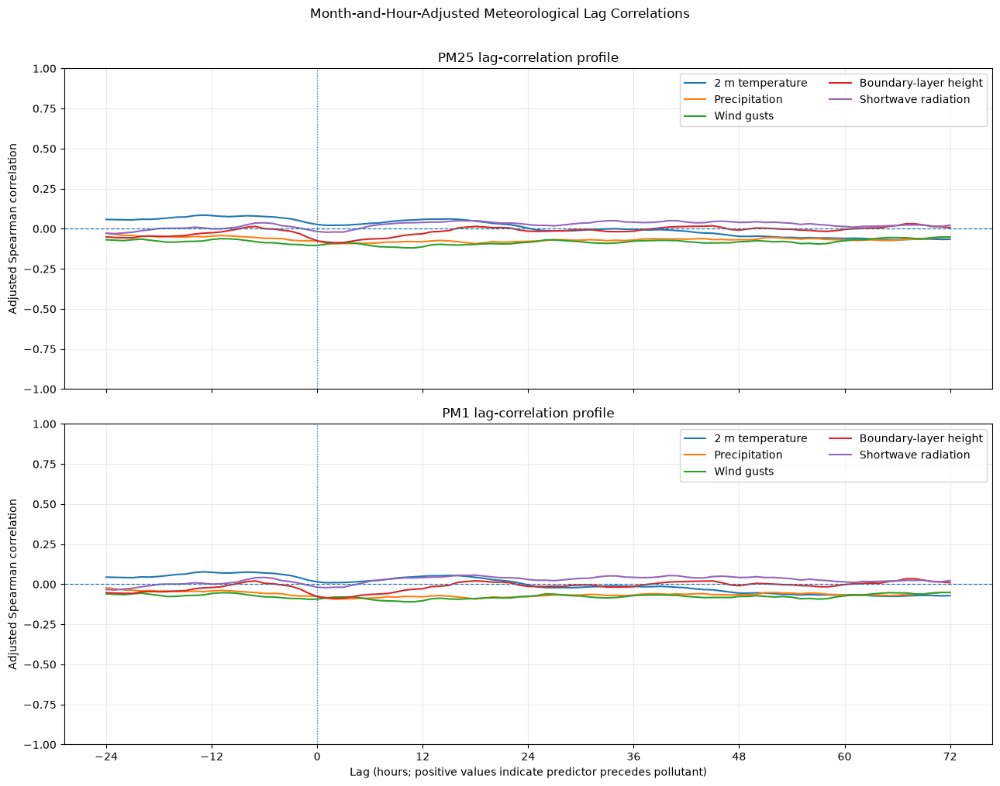

In [19]:

# FIGURE 9.3 — Lag-correlation profiles

fig, axes = plt.subplots(2, 1, figsize=(13, 10), sharex=True)

labels = {
    "temperature_2m": "2 m temperature",
    "precipitation": "Precipitation",
    "wind_gusts_10m": "Wind gusts",
    "boundary_layer_height": "Boundary-layer height",
    "shortwave_radiation": "Shortwave radiation"
}

for ax, pollutant in zip(axes, pollutants):

    subset = lag_results_93[
        lag_results_93["Pollutant"] == pollutant
    ]

    for predictor in predictors:
        data = subset[
            subset["Predictor"] == predictor
        ].sort_values("Lag_Hours")

        ax.plot(
            data["Lag_Hours"],
            data["Spearman"],
            linewidth=1.5,
            label=labels[predictor]
        )

    ax.axhline(0, linestyle="--", linewidth=0.9)
    ax.axvline(0, linestyle=":", linewidth=0.9)

    ax.set_title(f"{pollutant.upper()} lag-correlation profile")
    ax.set_ylabel("Adjusted Spearman correlation")
    ax.set_ylim(-1, 1)
    ax.grid(True, alpha=0.25)
    ax.legend(loc="best", ncol=2)

axes[-1].set_xlabel(
    "Lag (hours; positive values indicate predictor precedes pollutant)"
)
axes[-1].set_xticks(range(-24, 73, 12))

fig.suptitle(
    "Month-and-Hour-Adjusted Meteorological Lag Correlations",
    y=1.01
)

plt.tight_layout()
plt.show()


In [21]:

# FIGURE 9.5 — Seasonal correlation analysis

season_df = master.copy()
season_df["datetime"] = pd.to_datetime(season_df["datetime"])
season_df["Month"] = season_df["datetime"].dt.month

season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Pre-monsoon", 4: "Pre-monsoon", 5: "Pre-monsoon",
    6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
    10: "Post-monsoon", 11: "Post-monsoon"
}

season_df["Season"] = season_df["Month"].map(season_map)

meteorological_vars = [
    "temperature_2m",
    "relative_humidity_2m",
    "dew_point_2m",
    "precipitation",
    "rain",
    "wind_speed_10m",
    "wind_gusts_10m",
    "surface_pressure",
    "cloud_cover",
    "boundary_layer_height",
    "shortwave_radiation"
]

print("SEASONAL OBSERVATION COUNTS")
display(
    season_df.groupby("Season")
    .agg(
        PM25_N=("pm25", "count"),
        PM1_N=("pm1", "count")
    ).reindex(
        ["Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"]
    )
)

print("\nMETEOROLOGICAL VALID COUNTS")
display(season_df[meteorological_vars].notna().sum().to_frame("Valid_N"))


SEASONAL OBSERVATION COUNTS


,PM25_N,PM1_N
Season,,
Winter,2140,2140
Pre-monsoon,2129,2129
Monsoon,4888,4888
Post-monsoon,1824,1824



METEOROLOGICAL VALID COUNTS


,Valid_N
temperature_2m,10981
relative_humidity_2m,10981
dew_point_2m,10981
precipitation,10981
rain,10981
wind_speed_10m,10981
wind_gusts_10m,10981
surface_pressure,10981
cloud_cover,10981
boundary_layer_height,10504


In [22]:

# Calculate seasonal correlations with pairwise complete observations

season_order = [
    "Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"
]

correlation_rows = []

for season in season_order:
    subset = season_df[season_df["Season"] == season]

    for variable in meteorological_vars:
        for pollutant in ["pm25", "pm1"]:

            paired = subset[[variable, pollutant]].dropna()

            if len(paired) >= 30:
                rho = spearmanr(
                    paired[variable], paired[pollutant]
                ).statistic
            else:
                rho = np.nan

            correlation_rows.append({
                "Season": season,
                "Variable": variable,
                "Pollutant": pollutant,
                "Spearman": rho,
                "N": len(paired)
            })

seasonal_corr_95 = pd.DataFrame(correlation_rows)

print("SEASONAL CORRELATION RESULTS")
display(
    seasonal_corr_95.pivot_table(
        index=["Variable", "Season"],
        columns="Pollutant",
        values="Spearman"
    ).round(3)
)


SEASONAL CORRELATION RESULTS


Pollutant                             pm1   pm25
Variable              Season                    
boundary_layer_height Monsoon       0.022  0.005
                      Post-monsoon -0.241 -0.240
                      Pre-monsoon  -0.183 -0.178
                      Winter       -0.305 -0.282
cloud_cover           Monsoon      -0.303 -0.293
                      Post-monsoon -0.268 -0.273
                      Pre-monsoon  -0.229 -0.210
                      Winter       -0.093 -0.069
dew_point_2m          Monsoon      -0.257 -0.262
                      Post-monsoon -0.507 -0.500
                      Pre-monsoon  -0.075 -0.052
                      Winter       -0.158 -0.129
precipitation         Monsoon      -0.268 -0.274
                      Post-monsoon -0.343 -0.350
                      Pre-monsoon  -0.216 -0.198
                      Winter       -0.063 -0.045
rain                  Monsoon      -0.272 -0.279
                      Post-monsoon -0.310 -0.316
                      Pre-monsoon  -0.206 -0.191
                      Winter       -0.046 -0.034
relative_humidity_2m  Monsoon      -0.145 -0.126
                      Post-monsoon -0.014 -0.015
                      Pre-monsoon  -0.015 -0.003
                      Winter        0.258  0.251
shortwave_radiation   Monsoon       0.089  0.070
                      Post-monsoon -0.117 -0.121
                      Pre-monsoon  -0.094 -0.090
                      Winter       -0.216 -0.196
surface_pressure      Monsoon       0.210  0.203
                      Post-monsoon  0.133  0.131
                      Pre-monsoon   0.134  0.141
                      Winter       -0.069 -0.070
temperature_2m        Monsoon       0.000 -0.015
                      Post-monsoon -0.449 -0.443
                      Pre-monsoon  -0.070 -0.062
                      Winter       -0.375 -0.348
wind_gusts_10m        Monsoon      -0.115 -0.137
                      Post-monsoon -0.150 -0.159
                      Pre-monsoon  -0.256 -0.256
                      Winter       -0.054 -0.035
wind_speed_10m        Monsoon      -0.052 -0.061
                      Post-monsoon -0.128 -0.129
                      Pre-monsoon  -0.142 -0.145
                      Winter       -0.105 -0.093

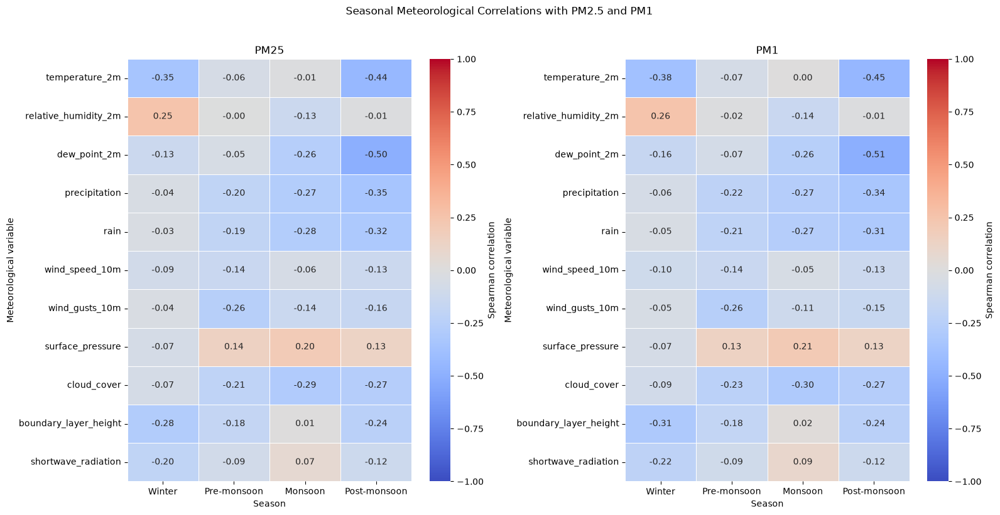

In [23]:

# FIGURE 9.5A — Seasonal meteorological correlation heatmaps

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

for ax, pollutant in zip(axes, ["pm25", "pm1"]):

    heatmap_data = seasonal_corr_95[
        seasonal_corr_95["Pollutant"] == pollutant
    ].pivot(
        index="Variable",
        columns="Season",
        values="Spearman"
    ).reindex(
        index=meteorological_vars,
        columns=season_order
    )

    sns.heatmap(
        heatmap_data,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1,
        linewidths=0.5,
        ax=ax,
        cbar_kws={"label": "Spearman correlation"}
    )

    ax.set_title(pollutant.upper())
    ax.set_xlabel("Season")
    ax.set_ylabel("Meteorological variable")

plt.suptitle(
    "Seasonal Meteorological Correlations with PM2.5 and PM1",
    y=1.02
)
plt.tight_layout()
plt.show()


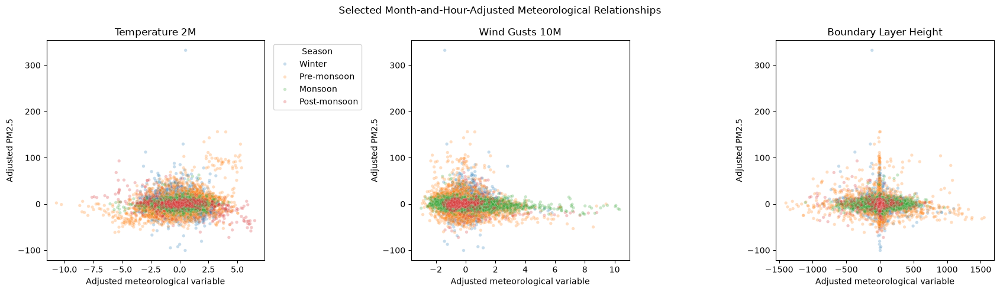

In [24]:

# FIGURE 9.5B — Selected adjusted scatter plots

scatter_vars = [
    "temperature_2m",
    "wind_gusts_10m",
    "boundary_layer_height"
]

scatter_df = season_df[
    ["datetime", "Season", "pm25"] + scatter_vars
].copy()

for col in ["pm25"] + scatter_vars:
    group_mean = scatter_df.groupby(
        [scatter_df["datetime"].dt.month,
         scatter_df["datetime"].dt.hour]
    )[col].transform("mean")

    scatter_df[col + "_adj"] = scatter_df[col] - group_mean

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, variable in zip(axes, scatter_vars):
    xcol = variable + "_adj"
    ycol = "pm25_adj"

    sns.scatterplot(
        data=scatter_df,
        x=xcol,
        y=ycol,
        hue="Season",
        hue_order=season_order,
        alpha=0.25,
        s=15,
        ax=ax,
        legend=(variable == scatter_vars[0])
    )

    ax.set_title(variable.replace("_", " ").title())
    ax.set_xlabel("Adjusted meteorological variable")
    ax.set_ylabel("Adjusted PM2.5")

axes[0].legend(title="Season", bbox_to_anchor=(1.02, 1))
plt.suptitle("Selected Month-and-Hour-Adjusted Meteorological Relationships")
plt.tight_layout()
plt.show()


In [25]:

# Verify sample sizes for all plotted correlations

print("SEASONAL CORRELATION SAMPLE SIZES")

display(
    seasonal_corr_95.pivot_table(
        index="Variable",
        columns=["Pollutant", "Season"],
        values="N"
    )
)

print("\nSCATTER PLOT SAMPLE SIZES")

display(
    scatter_df[
        ["pm25_adj"] + [v + "_adj" for v in scatter_vars]
    ].notna().sum().to_frame("Valid_N")
)


SEASONAL CORRELATION SAMPLE SIZES


Pollutant                 pm1                                     pm25  \
Season                Monsoon Post-monsoon Pre-monsoon  Winter Monsoon   
Variable                                                                 
boundary_layer_height  4589.0       1646.0      2129.0  2140.0  4589.0   
cloud_cover            4888.0       1824.0      2129.0  2140.0  4888.0   
dew_point_2m           4888.0       1824.0      2129.0  2140.0  4888.0   
precipitation          4888.0       1824.0      2129.0  2140.0  4888.0   
rain                   4888.0       1824.0      2129.0  2140.0  4888.0   
relative_humidity_2m   4888.0       1824.0      2129.0  2140.0  4888.0   
shortwave_radiation    4888.0       1824.0      2129.0  2140.0  4888.0   
surface_pressure       4888.0       1824.0      2129.0  2140.0  4888.0   
temperature_2m         4888.0       1824.0      2129.0  2140.0  4888.0   
wind_gusts_10m         4888.0       1824.0      2129.0  2140.0  4888.0   
wind_speed_10m         4888.0       1824.0      2129.0  2140.0  4888.0   

Pollutant                                               
Season                Post-monsoon Pre-monsoon  Winter  
Variable                                                
boundary_layer_height       1646.0      2129.0  2140.0  
cloud_cover                 1824.0      2129.0  2140.0  
dew_point_2m                1824.0      2129.0  2140.0  
precipitation               1824.0      2129.0  2140.0  
rain                        1824.0      2129.0  2140.0  
relative_humidity_2m        1824.0      2129.0  2140.0  
shortwave_radiation         1824.0      2129.0  2140.0  
surface_pressure            1824.0      2129.0  2140.0  
temperature_2m              1824.0      2129.0  2140.0  
wind_gusts_10m              1824.0      2129.0  2140.0  
wind_speed_10m              1824.0      2129.0  2140.0


SCATTER PLOT SAMPLE SIZES


,Valid_N
pm25_adj,10981
temperature_2m_adj,10981
wind_gusts_10m_adj,10981
boundary_layer_height_adj,10504


MATCHED OBSERVATIONS: 10981
DATE RANGE: 2025-07-01 00:45:00+05:45 to 2026-10-19 08:45:00+05:45
MISSING BIAS VALUES: 0

SEASONAL CAMS BIAS


,N,Mean,Median,SD
Season,,,,
Winter,2140,-9.022,-6.950,39.693
Pre-monsoon,2129,-9.162,-7.900,30.690
Monsoon,4888,5.410,3.675,15.800
Post-monsoon,1824,-2.699,-1.944,20.524



DIURNAL CAMS BIAS


,N,Mean,Median,SD
Hour,,,,
0,462,21.303,20.415,21.570
1,465,19.253,17.500,20.441
2,462,16.773,15.506,19.481
3,457,11.573,11.700,19.603
4,454,6.347,8.171,20.276
5,457,-2.258,-1.200,22.622
6,459,-8.201,-5.876,23.953
7,458,-21.510,-13.400,29.916
8,461,-29.373,-19.100,32.315



OVERALL BIAS SUMMARY
count    10981.000
mean        -1.575
std         26.729
min       -372.494
25%        -13.000
50%         -0.312
75%         13.214
max        110.400
Name: bias, dtype: float64


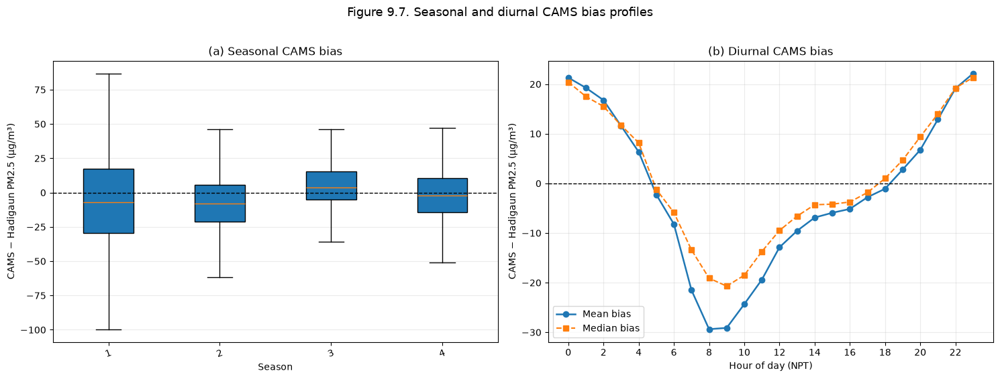

In [28]:
# Figure 9.7 — Seasonal and diurnal CAMS bias profiles

# 1. Prepare CAMS timestamps in NPT
cams_npt = cams[["datetime_utc", "pm25"]].copy()
cams_npt["datetime"] = cams_npt["datetime_utc"].dt.tz_convert("Asia/Kathmandu")
cams_npt = cams_npt.rename(columns={"pm25": "cams_pm25"})

sensor = master[["datetime", "pm25"]].copy()
sensor = sensor.rename(columns={"pm25": "hadigaun_pm25"})

# 2. Exact timestamp matching
assert not cams_npt["datetime"].duplicated().any(), "Duplicate CAMS timestamps"
assert not sensor["datetime"].duplicated().any(), "Duplicate Hadigaun timestamps"

cams_bias = sensor.merge(
    cams_npt[["datetime", "cams_pm25"]],
    on="datetime",
    how="inner",
    validate="one_to_one"
)

cams_bias = cams_bias.dropna(
    subset=["hadigaun_pm25", "cams_pm25"]
).copy()

cams_bias["bias"] = (
    cams_bias["cams_pm25"] - cams_bias["hadigaun_pm25"]
)

# 3. Assign NPT seasons
month = cams_bias["datetime"].dt.month

cams_bias["Season"] = np.select(
    [
        month.isin([12, 1, 2]),
        month.isin([3, 4, 5]),
        month.isin([6, 7, 8, 9]),
        month.isin([10, 11])
    ],
    ["Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"],
    default=None
)

cams_bias["Hour"] = cams_bias["datetime"].dt.hour

season_order = ["Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"]

# 4. Calculate seasonal and diurnal summaries
seasonal_bias = (
    cams_bias.groupby("Season", observed=True)["bias"]
    .agg(N="count", Mean="mean", Median="median", SD="std")
    .reindex(season_order)
)

diurnal_bias = (
    cams_bias.groupby("Hour")["bias"]
    .agg(N="count", Mean="mean", Median="median", SD="std")
    .reindex(range(24))
)

# 5. Print verification statistics
print("MATCHED OBSERVATIONS:", len(cams_bias))
print("DATE RANGE:", cams_bias["datetime"].min(), "to", cams_bias["datetime"].max())
print("MISSING BIAS VALUES:", cams_bias["bias"].isna().sum())

print("\nSEASONAL CAMS BIAS")
display(seasonal_bias.round(3))

print("\nDIURNAL CAMS BIAS")
display(diurnal_bias.round(3))

print("\nOVERALL BIAS SUMMARY")
print(cams_bias["bias"].describe().round(3))

# 6. Plot Figure 9.7
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

season_data = [
    cams_bias.loc[cams_bias["Season"] == season, "bias"]
    for season in season_order
]

axes[0].boxplot(
    season_data,
    label=season_order,
    showfliers=False,
    patch_artist=True
)

axes[0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[0].set_title("(a) Seasonal CAMS bias")
axes[0].set_xlabel("Season")
axes[0].set_ylabel("CAMS − Hadigaun PM2.5 (µg/m³)")
axes[0].tick_params(axis="x", rotation=20)
axes[0].grid(axis="y", alpha=0.25)

axes[1].plot(
    diurnal_bias.index,
    diurnal_bias["Mean"],
    marker="o",
    linewidth=1.8,
    label="Mean bias"
)

axes[1].plot(
    diurnal_bias.index,
    diurnal_bias["Median"],
    marker="s",
    linewidth=1.5,
    linestyle="--",
    label="Median bias"
)

axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_title("(b) Diurnal CAMS bias")
axes[1].set_xlabel("Hour of day (NPT)")
axes[1].set_ylabel("CAMS − Hadigaun PM2.5 (µg/m³)")
axes[1].set_xticks(range(0, 24, 2))
axes[1].grid(alpha=0.25)
axes[1].legend()

fig.suptitle(
    "Figure 9.7. Seasonal and diurnal CAMS bias profiles",
    fontsize=13,
    y=1.02
)

plt.tight_layout()
plt.show()

In [29]:
# Table 8.2 — Monthly Hadigaun sensor-temperature baselines

month_order = range(1, 13)

temperature_baselines = (
    hadigaun.assign(
        Month=hadigaun["datetime"].dt.month
    )
    .groupby("Month")["temperature"]
    .agg(
        Mean_Temperature="mean",
        SD="std",
        N="count"
    )
    .reindex(month_order)
)

month_names = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

temperature_baselines.index = month_names
temperature_baselines.index.name = "Calendar_Month"

print("TABLE 8.2 — MONTHLY SENSOR-TEMPERATURE BASELINES")
display(temperature_baselines.round(3))

# Verify all twelve monthly baselines are available
assert temperature_baselines["Mean_Temperature"].notna().all(), (
    "At least one calendar month has no valid temperature observations."
)

print("\nTotal observations:", int(temperature_baselines["N"].sum()))
print("Number of monthly baselines:", temperature_baselines["Mean_Temperature"].count())

TABLE 8.2 — MONTHLY SENSOR-TEMPERATURE BASELINES


,Mean_Temperature,SD,N
Calendar_Month,,,
January,14.938,4.556,734
February,18.287,4.655,670
March,21.328,4.167,738
April,23.287,4.839,701
May,24.989,4.467,690
June,27.384,3.834,664
July,26.890,3.335,1468
August,26.436,3.128,1450
September,25.561,3.347,1306



Total observations: 10981
Number of monthly baselines: 12
